## DADOS PAINEL - TESE FERNANDO

##### **Problema**

Como os retornos econômicos esperados e o ambiente institucional condicionam a taxa de conversão da vegetação nativa em Mato Grosso, e em que medida essa relação varia conforme a capacidade produtiva local da terra, as atividades agropecuárias e os biomas?

##### **Hipótese**

H1: A conversão de vegetação nativa para usos agropecuários aumenta quando se eleva o retorno econômico esperado desses usos.

##### **Função**

\begin{equation}
\text{Conversão da vegetação nativa} = f(\text{preços agropecuários}, \text{produtividade da terra}, \text{ambiente institucional})
\end{equation}

##### **Resumo**

O artigo busca explicar, compreender e mensurar se:

1. Aumentos nos preços dos produtos agropecuários se traduzem em maior conversão onde a capacidade produtiva da terra para esses usos é mais elevada; 
2. As condições institucionais modificam a intensidade dessa resposta; 
3. Essas relações entre expectativas e respostas aos ambientes econômico e institucional variam conforme atividades agropecuárias e biomas. 

### 0. Setar ambiente

#### 0.1 Bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### 0.2 Importar dados

In [2]:
caminho = 'paineis/painel_tese_chap1_pt.csv'
df = pd.read_csv(caminho)

### 1. DATAFRAMES PT

In [3]:
# DICIONÁRIO DAS COLUNAS DE df e df2 (na ordem do CSV)
# aed_chap1_pt_DICIO.ipynb

#### 1.1 df1 (Completo)

In [4]:
# Versão completa do dataframe

In [5]:
df1 = df.copy()

In [6]:
# Transforma 'codigo_ibge' em string (ou 'category') garantindo 7 dígitos
df1['codigo_ibge'] = df1['codigo_ibge'].astype(str).str.zfill(7)

# Transforma em categoria
df1['codigo_ibge'] = df1['codigo_ibge'].astype(str).str.zfill(7).astype('category')

In [7]:
# Transforma 'ano' em formato datetime (padrão: YYYY-01-01)
df1['ano'] = pd.to_datetime(df1['ano'], format='%Y')

# Deixar apenas o ano
df1['ano'] = pd.to_datetime(df1['ano'], format='%Y').dt.to_period('Y')

##### Visão geral

In [8]:
df1.shape

(3384, 296)

In [9]:
df1.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 3384 entries, 0 to 3383
Data columns (total 296 columns):
 #    Column                                                                                    Non-Null Count  Dtype        
---   ------                                                                                    --------------  -----        
 0    codigo_ibge                                                                               3384 non-null   category     
 1    ano                                                                                       3384 non-null   period[Y-DEC]
 2    conversao_ha__agricultura                                                                 2772 non-null   float64      
 3    conversao_ha__pastagem                                                                    2772 non-null   float64      
 4    taxa_conversao__agricultura                                                               2772 non-null   float64      
 5    taxa_conversao_

In [10]:
# Describe dados quantitativos, incluindo contagem de valores ausentes.
df1.describe()

,conversao_ha__agricultura,conversao_ha__pastagem,taxa_conversao__agricultura,taxa_conversao__pastagem,y_colecao,y_area_total_ha,y_area_valida_par_ha,y_area_nao_valida_par_ha,y_nativa_inicial_ha,y_fracao_area_valida_par,...,exposicao_real_x_pantanal__milho__pam_1991_2000_min7,exposicao_real_x_pantanal__soja__pam_1991_2000_min7,exposicao_real_x_pantanal__milho__gaez_sxHr0_mze,exposicao_real_x_pantanal__soja__gaez_sxHr0_soy,exposicao_real_x_pantanal__milho__gaez_sxLr0_mze,exposicao_real_x_pantanal__soja__gaez_sxLr0_soy,exposicao_real_x_pantanal__milho__gaez_yxHr0_mze,exposicao_real_x_pantanal__soja__gaez_yxHr0_soy,exposicao_real_x_pantanal__milho__gaez_yxLr0_mze,exposicao_real_x_pantanal__soja__gaez_yxLr0_soy
count,2772.000000,2772.000000,2772.000000,2772.000000,3.384000e+03,3.384000e+03,3.384000e+03,3384.000000,3.384000e+03,3384.000000,...,2808.000000,1128.000000,3384.000000,3384.000000,3384.000000,3384.000000,3384.000000,3384.000000,3384.000000,3384.000000
mean,297.697312,3257.588132,0.001122,0.011915,1.010000e+01,6.405727e+05,6.405388e+05,33.856158,4.168223e+05,0.999983,...,-0.172460,-0.049202,0.540661,0.239976,0.128428,0.177897,0.557612,0.220289,0.153728,0.189487
std,1015.382300,4832.176411,0.003751,0.014295,1.776619e-15,5.966349e+05,5.965491e+05,280.248085,4.956423e+05,0.000127,...,1.093186,0.556939,3.225393,1.319701,0.682116,0.942023,3.118690,1.122624,0.845597,1.007488
min,0.000000,0.953154,0.000000,0.000029,1.010000e+01,3.443212e+04,3.443212e+04,0.000000,6.485420e+03,0.998713,...,-10.663550,-3.839196,-0.011560,-0.048610,-0.005323,-0.000000,-0.000000,-0.086781,-0.182322,-0.185683
25%,3.114156,579.761195,0.000018,0.004291,1.010000e+01,2.291295e+05,2.291295e+05,0.000000,1.008952e+05,1.000000,...,0.000000,0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,0.000000,-0.000000,-0.000000
50%,26.987478,1644.679448,0.000143,0.007994,1.010000e+01,4.525278e+05,4.525278e+05,0.000000,2.508805e+05,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000
75%,173.347514,3769.385707,0.000761,0.014125,1.010000e+01,8.439029e+05,8.439029e+05,0.000000,4.384596e+05,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,18222.268087,56983.225434,0.079950,0.265411,1.010000e+01,2.796089e+06,2.796089e+06,3152.443287,2.737509e+06,1.000000,...,1.150761,1.352889,29.188575,12.656422,5.993453,8.806177,25.847390,8.250750,8.365882,8.575441


In [11]:
# Describe dados qualitativos, incluindo contagem de valores ausentes.
df1.describe(include=['object', 'category', 'bool', 'datetime', 'timedelta'])

C:\Users\ferna\AppData\Local\Temp\ipykernel_24608\2991025832.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df1.describe(include=['object', 'category', 'bool', 'datetime', 'timedelta'])


,codigo_ibge,y_malha,y_mascara_id,y_cobertura_completa,y_flag_denominador_zero,y_flag_denominador_ausente,flag_ano_nominal_incompleto__carne_bovina,flag_ano_nominal_incompleto__milho,flag_ano_nominal_incompleto__soja,flag_ano_real_incompleto__carne_bovina,...,flag_contagem_desmatamento_parcial__ibama_espacial,flag_soma_desmatamento_parcial__ibama_espacial,flag_soma_nominal_desmatamento_parcial__ibama_espacial,flag_sem_registro_identificado__ibama_espacial,flag_contagem_flora_parcial_lag1__ibama_espacial,flag_contagem_desmatamento_parcial_lag1__ibama_espacial,flag_soma_flora_parcial_lag1__ibama_espacial,flag_soma_desmatamento_parcial_lag1__ibama_espacial,flag_ano_incompleto,flag_ordem_invalida
count,3384,3384,3384,3384,3384,3384,3384,3384,3384,3384,...,1828,1828,1828,3384,1755,1755,1755,1755,3384,3384
unique,141,1,3384,2,1,1,1,1,1,1,...,2,2,2,2,2,2,2,2,1,1
top,5100102,IBGE_MT_2023_141,0a4085a11f99daf93ca8e40b98365646a9c789aedaba87...,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
freq,24,3384,1,2772,3384,3384,3384,3384,3384,3384,...,1159,1154,1154,1828,1449,1085,1428,1080,3384,3384


##### Agregar municípios

**df1a: perfil municipal descritivo — 2001–2024**

Uma linha por município. As médias usam os anos observados; as tabelas de cobertura mostram quantos e quais limites temporais sustentam cada resumo. A soma observada de conversões pode ser parcial; o total de 2001–2024 exige 24 anos válidos. A razão de somas é uma taxa anual média ponderada pela vegetação disponível, não um percentual acumulado de perda.

Estoques são preservados em datas exatas. Ausências continuam ausentes. Autos e multas representam registros observados, possivelmente parciais; multas estão em R$ de dezembro de 2024. Cada município recebe o mesmo peso nas descritivas entre municípios. Os resultados contextualizam o território e não estimam causalidade.


In [12]:
df1a = df1.copy()


In [13]:
df1a["ano"] = df1a["ano"].dt.year


In [14]:
# Nomes curtos apenas nesta cópia; unidades mantidas nos nomes e comentários.
df1a = df1a.rename(columns={
    'conversao_ha__agricultura': 'conv_agricultura_ha',
    'conversao_ha__pastagem': 'conv_pastagem_ha',
    'taxa_conversao__agricultura': 'taxa_agricultura',
    'taxa_conversao__pastagem': 'taxa_pastagem',
    'rendimento_medio_kg_ha__Soja (em grão)': 'prod_soja_kg_ha',
    'rendimento_medio_kg_ha__Milho (em grão)': 'prod_milho_kg_ha',
    'capacidade_valor__soja__pam_1991_2000_min7': 'cap_soja_kg_ha',
    'capacidade_valor__milho__pam_1991_2000_min7': 'cap_milho_kg_ha',
    'n_autos_desmatamento__ibama_informada': 'autos_desmat',
    'multas_desmatamento_reais_observadas__ibama_informada': 'multas_desmat_reais',
    'y_nativa_inicial_ha': 'nativa_inicio_ha',
    'agricultura_ha_lag1': 'agricultura_anterior_ha',
    'pastagem_ha_lag1': 'pastagem_anterior_ha',
    'biome_amazonia_share_i': 'amazonia_share',
    'biome_cerrado_share_i': 'cerrado_share',
    'biome_pantanal_share_i': 'pantanal_share',
    'precip_mm_anual': 'chuva_mm',
    'precip_zscore_1981_2000': 'chuva_z',
    'elevation_mean_m': 'elevacao_m',
    'y_cobertura_completa': 'cobertura_y',
    'flag_sem_registro_identificado__ibama_informada': 'sem_auto_identificado',
    'flag_contagem_desmatamento_parcial__ibama_informada': 'contagem_parcial',
    'flag_soma_desmatamento_parcial__ibama_informada': 'multa_parcial',
    'capacidade_valor__soja__gaez_sxHr0_soy': 'gaez_sx_soja_H',
    'capacidade_valor__milho__gaez_sxHr0_mze': 'gaez_sx_milho_H',
    'capacidade_valor__soja__gaez_sxLr0_soy': 'gaez_sx_soja_L',
    'capacidade_valor__milho__gaez_sxLr0_mze': 'gaez_sx_milho_L',
    'capacidade_valor__soja__gaez_yxHr0_soy': 'gaez_yx_soja_H',
    'capacidade_valor__milho__gaez_yxHr0_mze': 'gaez_yx_milho_H',
    'capacidade_valor__soja__gaez_yxLr0_soy': 'gaez_yx_soja_L',
    'capacidade_valor__milho__gaez_yxLr0_mze': 'gaez_yx_milho_L',
})


**1. Preparar cobertura, características fixas e fluxos**


In [15]:
# Cada destino usa o seu próprio conjunto de anos válidos.
df1a["ano_agricultura"] = df1a["ano"].where(df1a["conv_agricultura_ha"].notna())
df1a["ano_pastagem"] = df1a["ano"].where(df1a["conv_pastagem_ha"].notna())
df1a["nativa_exposta_agricultura"] = df1a["nativa_inicio_ha"].where(df1a["conv_agricultura_ha"].notna())
df1a["nativa_exposta_pastagem"] = df1a["nativa_inicio_ha"].where(df1a["conv_pastagem_ha"].notna())


In [16]:
fixas_1a = ['cap_soja_kg_ha', 'cap_milho_kg_ha', 'amazonia_share', 'cerrado_share', 'pantanal_share', 'elevacao_m', 'gaez_sx_soja_H', 'gaez_sx_milho_H', 'gaez_sx_soja_L', 'gaez_sx_milho_L', 'gaez_yx_soja_H', 'gaez_yx_milho_H', 'gaez_yx_soja_L', 'gaez_yx_milho_L']
grupo_1a = df1a.groupby("codigo_ibge", observed=True)


In [17]:
# Conferência: características fixas têm no máximo um valor válido por município.
constancia_1a = grupo_1a[fixas_1a].nunique()
constancia_1a.max()


cap_soja_kg_ha     1
cap_milho_kg_ha    1
amazonia_share     1
cerrado_share      1
pantanal_share     1
elevacao_m         1
gaez_sx_soja_H     1
gaez_sx_milho_H    1
gaez_sx_soja_L     1
gaez_sx_milho_L    1
gaez_yx_soja_H     1
gaez_yx_milho_H    1
gaez_yx_soja_L     1
gaez_yx_milho_L    1
dtype: int64

In [18]:
fixas_1a = grupo_1a[fixas_1a].first()


In [19]:
qualidade_1a = grupo_1a.agg(
    anos_grade=("ano", "size"),
    anos_y_agricultura=("ano_agricultura", "count"),
    primeiro_ano_y_agricultura=("ano_agricultura", "min"),
    ultimo_ano_y_agricultura=("ano_agricultura", "max"),
    anos_y_pastagem=("ano_pastagem", "count"),
    primeiro_ano_y_pastagem=("ano_pastagem", "min"),
    ultimo_ano_y_pastagem=("ano_pastagem", "max"),
    anos_sem_auto_identificado=("sem_auto_identificado", "sum"),
    anos_flag_contagem_conhecida=("contagem_parcial", "count"),
    anos_contagem_parcial=("contagem_parcial", "sum"),
    anos_flag_multa_conhecida=("multa_parcial", "count"),
    anos_multa_parcial=("multa_parcial", "sum")
)


In [20]:
qualidade_1a["y_24_anos"] = qualidade_1a["anos_y_agricultura"].eq(24) & qualidade_1a["anos_y_pastagem"].eq(24)
qualidade_1a["anos_flag_contagem_desconhecida"] = 24 - qualidade_1a["anos_flag_contagem_conhecida"]
qualidade_1a["anos_flag_multa_desconhecida"] = 24 - qualidade_1a["anos_flag_multa_conhecida"]


In [21]:
# min_count=1: grupos inteiramente ausentes não viram zero.
fluxos_1a = grupo_1a[["conv_agricultura_ha", "conv_pastagem_ha", "autos_desmat", "multas_desmat_reais"]].sum(min_count=1)
fluxos_1a = fluxos_1a.add_suffix("_soma_observada")
exposicao_1a = grupo_1a[["nativa_exposta_agricultura", "nativa_exposta_pastagem"]].sum(min_count=1)


In [22]:
fluxos_1a["taxa_agricultura_ponderada_pct"] = 100 * fluxos_1a["conv_agricultura_ha_soma_observada"] / exposicao_1a["nativa_exposta_agricultura"]
fluxos_1a["taxa_pastagem_ponderada_pct"] = 100 * fluxos_1a["conv_pastagem_ha_soma_observada"] / exposicao_1a["nativa_exposta_pastagem"]
fluxos_1a["conv_agricultura_total_2001_2024_ha"] = fluxos_1a["conv_agricultura_ha_soma_observada"].where(qualidade_1a["anos_y_agricultura"].eq(24))
fluxos_1a["conv_pastagem_total_2001_2024_ha"] = fluxos_1a["conv_pastagem_ha_soma_observada"].where(qualidade_1a["anos_y_pastagem"].eq(24))


In [23]:
taxas_1a = grupo_1a[["taxa_agricultura", "taxa_pastagem"]].mean()
taxas_1a = taxas_1a * 100
taxas_1a = taxas_1a.add_suffix("_media_pct")


**2. Resumir os anos observados e preservar as datas dos estoques**


In [24]:
medidas_1a = ["conv_agricultura_ha", "conv_pastagem_ha", "prod_soja_kg_ha", "prod_milho_kg_ha", "efetivo_bovino", "lotacao_cabecas_ha", "autos_desmat", "multas_desmat_reais", "chuva_mm", "chuva_z"]
estatisticas_1a = grupo_1a[medidas_1a].agg(["count", "mean", "median", "std"])
estatisticas_1a.columns = estatisticas_1a.columns.map("_".join)


In [25]:
chuva_extremos_1a = grupo_1a[["chuva_mm", "chuva_z"]].agg(["min", "max"])
chuva_extremos_1a.columns = chuva_extremos_1a.columns.map("_".join)


In [26]:
# Cobertura individual, sem eliminar conjuntamente linhas por ausência em outras medidas.
anos_1a = df1a[medidas_1a].notna()
anos_1a = anos_1a.mul(df1a["ano"], axis=0)
anos_1a = anos_1a.replace(0, np.nan)
anos_1a["codigo_ibge"] = df1a["codigo_ibge"]


In [27]:
grupo_anos_1a = anos_1a.groupby("codigo_ibge", observed=True)
cobertura_1a = grupo_anos_1a.agg(["count", "min", "max"])
cobertura_1a = cobertura_1a.stack(level=0)
cobertura_1a = cobertura_1a.rename(columns={"count": "anos_validos", "min": "primeiro_ano", "max": "ultimo_ano"})
cobertura_1a["anos_ausentes"] = 24 - cobertura_1a["anos_validos"]
cobertura_1a["lacunas_internas"] = cobertura_1a["ultimo_ano"] - cobertura_1a["primeiro_ano"] + 1 - cobertura_1a["anos_validos"]


In [28]:
# Área nativa do par de mapas: exigir cobertura completa para comparar estoques.
df1a["nativa_inicio_ha"] = df1a["nativa_inicio_ha"].where(df1a["cobertura_y"].eq(True))
# Estes campos representam t−1: linhas 2001 e 2024 contêm estoques de 2000 e 2023.
estoques_1a = ["nativa_inicio_ha", "agricultura_anterior_ha", "pastagem_anterior_ha"]
inicio_1a = df1a.loc[df1a["ano"].eq(2001), ["codigo_ibge"] + estoques_1a]
inicio_1a = inicio_1a.set_index("codigo_ibge")
fim_1a = df1a.loc[df1a["ano"].eq(2024), ["codigo_ibge"] + estoques_1a]
fim_1a = fim_1a.set_index("codigo_ibge")


In [29]:
mudanca_1a = fim_1a - inicio_1a
mudanca_1a = mudanca_1a.add_suffix("_mudanca_2000_2023")
inicio_1a = inicio_1a.add_suffix("_2000")
fim_1a = fim_1a.add_suffix("_2023")


In [30]:
# Datas exatas do rebanho; não usar first/last, que podem pular ausências.
rebanho_1a = df1a.loc[df1a["ano"].isin([2001, 2024]), ["codigo_ibge", "ano", "efetivo_bovino"]]
rebanho_1a = rebanho_1a.pivot(index="codigo_ibge", columns="ano", values="efetivo_bovino")
rebanho_1a = rebanho_1a.rename(columns={2001: "bovinos_2001", 2024: "bovinos_2024"})
rebanho_1a["bovinos_mudanca_2001_2024"] = rebanho_1a["bovinos_2024"] - rebanho_1a["bovinos_2001"]


Em `df1a`, os estoques contemporâneos permitem também comparar **2001 e 2024**, sempre dentro da mesma fonte de estoques. GAEZ: `sx` é índice 0–10.000; `yx` é kg de matéria seca/ha; H/L são cenários de alto/baixo insumo. As pendências de comparabilidade histórica e de temporalidade dessas fontes permanecem.


In [31]:
estoques_atuais_1a = ["nativa_ha", "agricultura_ha", "pastagem_ha"]
inicio_atual_1a = df1a.loc[df1a["ano"].eq(2001), ["codigo_ibge"] + estoques_atuais_1a]
inicio_atual_1a = inicio_atual_1a.set_index("codigo_ibge")
fim_atual_1a = df1a.loc[df1a["ano"].eq(2024), ["codigo_ibge"] + estoques_atuais_1a]
fim_atual_1a = fim_atual_1a.set_index("codigo_ibge")


In [32]:
mudanca_atual_1a = fim_atual_1a - inicio_atual_1a
mudanca_atual_1a = mudanca_atual_1a.add_suffix("_mudanca_2001_2024")
inicio_atual_1a = inicio_atual_1a.add_suffix("_2001")
fim_atual_1a = fim_atual_1a.add_suffix("_2024")


In [33]:
df1a = pd.concat([qualidade_1a, fluxos_1a, taxas_1a, estatisticas_1a, chuva_extremos_1a, fixas_1a, inicio_1a, fim_1a, mudanca_1a, rebanho_1a, inicio_atual_1a, fim_atual_1a, mudanca_atual_1a], axis=1)
df1a = df1a.reset_index()


In [34]:
df1a.shape


(141, 105)

In [35]:
df1a.head()


,codigo_ibge,anos_grade,anos_y_agricultura,primeiro_ano_y_agricultura,ultimo_ano_y_agricultura,anos_y_pastagem,primeiro_ano_y_pastagem,ultimo_ano_y_pastagem,anos_sem_auto_identificado,anos_flag_contagem_conhecida,...,bovinos_mudanca_2001_2024,nativa_ha_2001,agricultura_ha_2001,pastagem_ha_2001,nativa_ha_2024,agricultura_ha_2024,pastagem_ha_2024,nativa_ha_mudanca_2001_2024,agricultura_ha_mudanca_2001_2024,pastagem_ha_mudanca_2001_2024
0,5100102,24,24,2001.0,2024.0,24,2001.0,2024.0,14,10,...,22717.0,58880.226410,86.115860,23903.061806,51393.515662,319.273265,30110.148195,-7486.710749,233.157405,6207.086389
1,5100201,24,24,2001.0,2024.0,24,2001.0,2024.0,5,19,...,-36920.0,354366.080543,41049.694763,345644.440653,310491.440556,177369.670210,203773.662917,-43874.639986,136319.975447,-141870.777737
2,5100250,24,14,2009.0,2024.0,14,2009.0,2024.0,0,24,...,151779.0,515887.901520,2132.966484,368751.582648,425626.849714,62080.326512,395926.464859,-90261.051807,59947.360028,27174.882211
3,5100300,24,24,2001.0,2024.0,24,2001.0,2024.0,4,20,...,29585.0,293461.790884,17800.152268,217004.528510,273168.085101,46054.423490,183250.409070,-20293.705782,28254.271222,-33754.119441
4,5100359,24,24,2001.0,2024.0,24,2001.0,2024.0,7,17,...,-12713.0,150328.569491,637.185678,73061.093937,86126.275605,42946.190971,92638.944053,-64202.293886,42309.005294,19577.850116


**3. Cobertura e estatísticas entre municípios**

`mean`, `median` e `std` nos nomes são resumos dos anos observados de cada município; `count` é o número desses anos. A tabela abaixo descreve a distribuição desses resumos entre municípios, com N e ausências por medida. Não há exclusão conjunta de casos, imputação, testes ou intervalos de confiança. Os totais completos têm suporte menor que as somas parciais.


In [36]:
descrever_1a = ['taxa_agricultura_media_pct', 'taxa_pastagem_media_pct', 'taxa_agricultura_ponderada_pct', 'taxa_pastagem_ponderada_pct', 'conv_agricultura_total_2001_2024_ha', 'conv_pastagem_total_2001_2024_ha', 'prod_soja_kg_ha_mean', 'prod_milho_kg_ha_mean', 'efetivo_bovino_mean', 'lotacao_cabecas_ha_mean', 'autos_desmat_mean', 'multas_desmat_reais_mean', 'chuva_mm_mean', 'chuva_mm_std', 'chuva_z_min', 'chuva_z_max', 'cap_soja_kg_ha', 'cap_milho_kg_ha', 'amazonia_share', 'cerrado_share', 'pantanal_share', 'elevacao_m']


In [37]:
descritiva_1a = df1a[descrever_1a].describe(percentiles=[0.25, 0.5, 0.75])
descritiva_1a = descritiva_1a.T
descritiva_1a["ausentes"] = len(df1a) - descritiva_1a["count"]
descritiva_1a["IQR"] = descritiva_1a["75%"] - descritiva_1a["25%"]
descritiva_1a.round(3)


,count,mean,std,min,25%,50%,75%,max,ausentes,IQR
taxa_agricultura_media_pct,137.0,0.112,0.192,0.000,0.008,0.034,0.126,1.238000e+00,4.0,0.118
taxa_pastagem_media_pct,137.0,1.190,0.785,0.095,0.625,1.069,1.468,4.389000e+00,4.0,0.843
taxa_agricultura_ponderada_pct,137.0,0.120,0.219,0.000,0.008,0.034,0.133,1.528000e+00,4.0,0.124
taxa_pastagem_ponderada_pct,137.0,1.225,0.828,0.097,0.632,1.069,1.509,4.459000e+00,4.0,0.876
conv_agricultura_total_2001_2024_ha,95.0,6018.255,10634.153,0.776,290.240,1297.081,4542.552,4.838944e+04,46.0,4252.312
conv_pastagem_total_2001_2024_ha,95.0,62324.647,75188.467,1519.421,14029.368,44311.446,80288.131,5.889647e+05,46.0,66258.763
prod_soja_kg_ha_mean,136.0,3139.312,175.935,2648.867,3055.844,3130.208,3200.031,3.767500e+03,5.0,144.188
prod_milho_kg_ha_mean,141.0,4206.873,784.453,1863.368,3768.500,4268.050,4717.000,6.115250e+03,0.0,948.500
efetivo_bovino_mean,141.0,202589.903,185675.451,14341.350,73124.500,141447.208,290373.500,1.006741e+06,0.0,217249.000
lotacao_cabecas_ha_mean,141.0,1.471,0.502,0.355,1.141,1.435,1.771,3.814000e+00,0.0,0.629


In [38]:
# Distribuição da cobertura de cada medida: municípios × número de anos válidos.
tabela_cobertura_1a = cobertura_1a.reset_index()
tabela_cobertura_1a = pd.crosstab(tabela_cobertura_1a["level_1"], tabela_cobertura_1a["anos_validos"])
tabela_cobertura_1a


anos_validos,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
level_1,,,,,,,,,,,,,,,,,,,,,
autos_desmat,2,4,9,6,8,6,9,8,3,5,...,2,5,4,5,9,8,11,7,3,4
chuva_mm,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,141
chuva_z,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,141
conv_agricultura_ha,4,3,1,7,2,0,0,1,1,2,...,1,2,1,3,0,2,4,3,0,95
conv_pastagem_ha,4,3,1,7,2,0,0,1,1,2,...,1,2,1,3,0,2,4,3,0,95
efetivo_bovino,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,2,0,0,0,139
lotacao_cabecas_ha,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,2,0,0,0,139
multas_desmat_reais,2,4,9,6,8,6,10,7,3,6,...,2,5,4,5,10,7,11,7,3,4
prod_milho_kg_ha,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,1,4,3,6,4,121


In [39]:
# Parcialidade conhecida e desconhecida deve acompanhar a leitura do IBAMA.
df1a[["codigo_ibge", "autos_desmat_count", "multas_desmat_reais_count", "anos_contagem_parcial", "anos_flag_contagem_desconhecida", "anos_multa_parcial", "anos_flag_multa_desconhecida"]].head(10)


,codigo_ibge,autos_desmat_count,multas_desmat_reais_count,anos_contagem_parcial,anos_flag_contagem_desconhecida,anos_multa_parcial,anos_flag_multa_desconhecida
0,5100102,7,7,7,14,7,14
1,5100201,12,12,11,5,11,5
2,5100250,22,22,19,0,19,0
3,5100300,14,14,16,4,16,4
4,5100359,13,13,11,7,11,7
5,5100409,8,8,13,8,13,8
6,5100508,4,4,4,17,4,17
7,5100607,9,9,8,9,8,9
8,5100805,20,20,19,0,19,0
9,5101001,13,13,17,3,17,3


In [40]:
# Comparação de Y com janela comum: conserva apenas os 24 anos completos nesta tabela.
completos_1a = df1a.loc[df1a["y_24_anos"]].copy()
completos_1a[["taxa_agricultura_ponderada_pct", "taxa_pastagem_ponderada_pct"]].describe().T


,count,mean,std,min,25%,50%,75%,max
taxa_agricultura_ponderada_pct,95.0,0.118497,0.220837,0.000450,0.008456,0.030111,0.134457,1.528089
taxa_pastagem_ponderada_pct,95.0,1.197875,0.808300,0.096504,0.623780,1.079040,1.495796,4.458761


As figuras de Y com janela comum usam os municípios com 24 anos válidos. Essa seleção melhora a comparabilidade temporal, mas não representa automaticamente os 141 municípios. Valores extremos são mantidos; os pontos dos boxplots não são descartes.


**4. Figuras: distribuição das taxas, produtividade e contexto de preços**


In [41]:
grafico_1a = df1a[["taxa_agricultura_ponderada_pct", "y_24_anos"]].copy()
grafico_1a["Cobertura"] = np.where(grafico_1a["y_24_anos"], "24 anos", "Menos de 24 anos")
grafico_1a = grafico_1a.dropna(subset=["taxa_agricultura_ponderada_pct"])


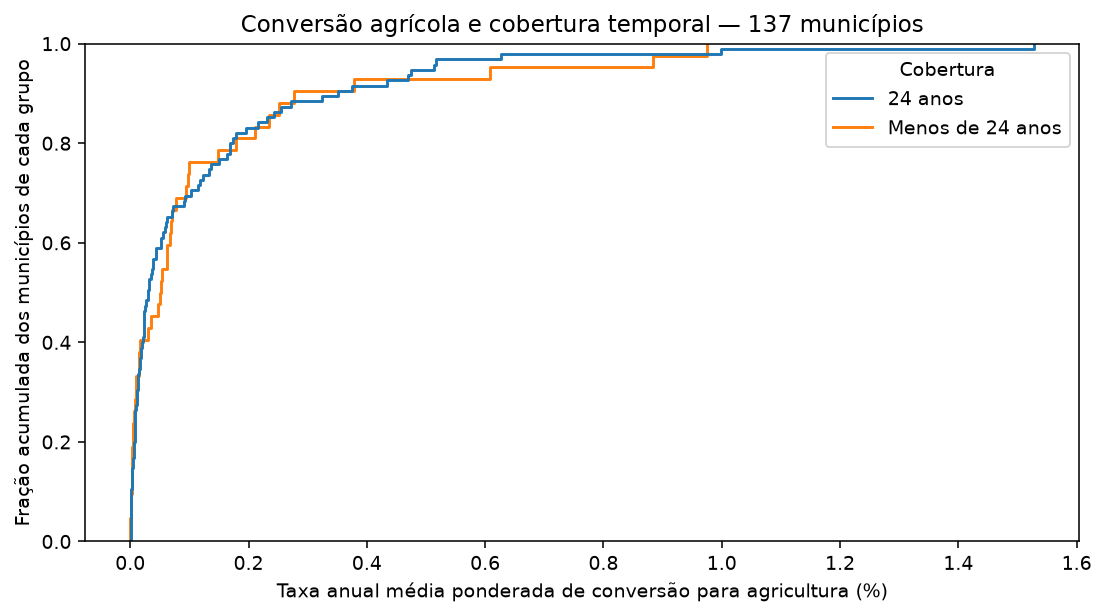

In [42]:
plt.figure(figsize=(8, 4.5), dpi=140)
sns.ecdfplot(data=grafico_1a, x="taxa_agricultura_ponderada_pct", hue="Cobertura")
plt.xlabel("Taxa anual média ponderada de conversão para agricultura (%)")
plt.ylabel("Fração acumulada dos municípios de cada grupo")
plt.title(f"Conversão agrícola e cobertura temporal — {len(grafico_1a)} municípios")
plt.tight_layout()
plt.show()


A curva com cobertura incompleta descreve os anos disponíveis, que variam entre municípios; não é uma comparação de períodos idênticos. Os quatro municípios sem Y não aparecem na curva.


In [43]:
produtividade_1a = df1a[["prod_soja_kg_ha_mean", "prod_milho_kg_ha_mean"]].copy()
produtividade_1a["prod_soja_kg_ha_mean"] = produtividade_1a["prod_soja_kg_ha_mean"].where(df1a["prod_soja_kg_ha_count"].eq(24))
produtividade_1a["prod_milho_kg_ha_mean"] = produtividade_1a["prod_milho_kg_ha_mean"].where(df1a["prod_milho_kg_ha_count"].eq(24))
produtividade_1a = produtividade_1a.rename(columns={"prod_soja_kg_ha_mean": "Soja", "prod_milho_kg_ha_mean": "Milho"})


In [44]:
produtividade_1a.count()


Soja      66
Milho    121
dtype: int64

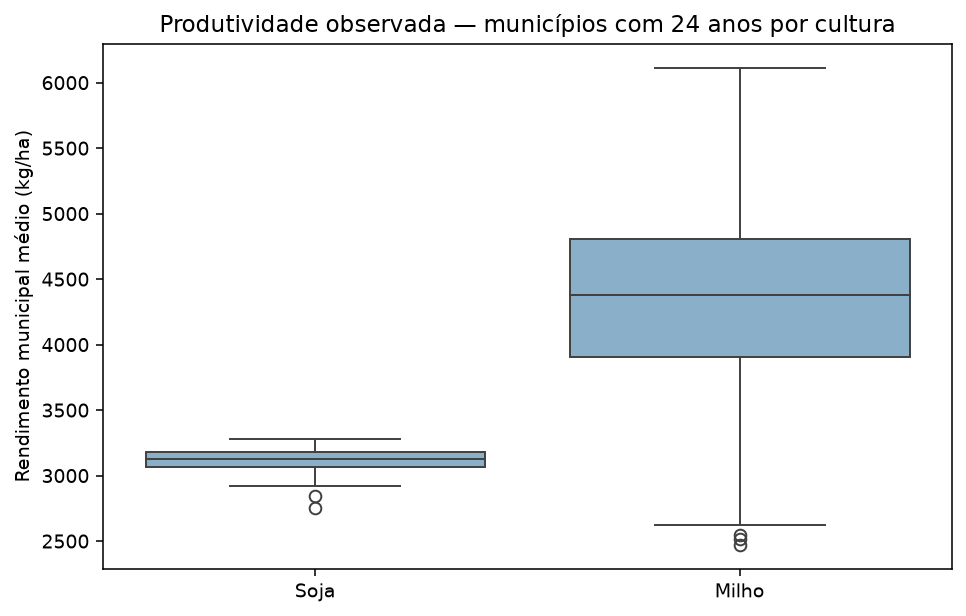

In [45]:
plt.figure(figsize=(7, 4.5), dpi=140)
sns.boxplot(data=produtividade_1a, color="#80b1d3")
plt.ylabel("Rendimento municipal médio (kg/ha)")
plt.title("Produtividade observada — municípios com 24 anos por cultura")
plt.tight_layout()
plt.show()


Os números de municípios por cultura estão na tabela anterior. As amostras podem diferir; a média de produtividade observada não é capacidade predeterminada nem efeito da conversão.


In [46]:
# Preços comuns: uma observação por ano; não entram como médias espaciais em df1a.
colunas_precos_1a = ["preco_real_usd2024_media_anual__soja", "preco_real_usd2024_media_anual__milho", "preco_real_usd2024_media_anual__carne_bovina"]
precos_1a = df1[["ano"] + colunas_precos_1a].drop_duplicates()
precos_1a = precos_1a.sort_values("ano")
precos_1a["ano"] = precos_1a["ano"].dt.year
precos_1a = precos_1a.set_index("ano")
precos_1a.columns = ["Soja (US$ 2024/t)", "Milho (US$ 2024/t)", "Carne (US$ 2024/kg)"]


In [47]:
precos_1a.round(2)


,Soja (US$ 2024/t),Milho (US$ 2024/t),Carne (US$ 2024/kg)
ano,,,
2001,346.97,158.85,3.73
2002,370.67,173.03,3.68
2003,450.06,179.71,3.63
2004,509.72,185.82,4.44
2005,441.48,158.50,4.39
2006,418.05,189.56,4.12
2007,578.86,247.65,4.08
2008,759.38,324.58,4.71
2009,619.20,242.06,3.99


In [48]:
indices_precos_1a = precos_1a.div(precos_1a.loc[2001])
indices_precos_1a = indices_precos_1a * 100
indices_precos_1a.columns = ["Soja", "Milho", "Carne bovina"]


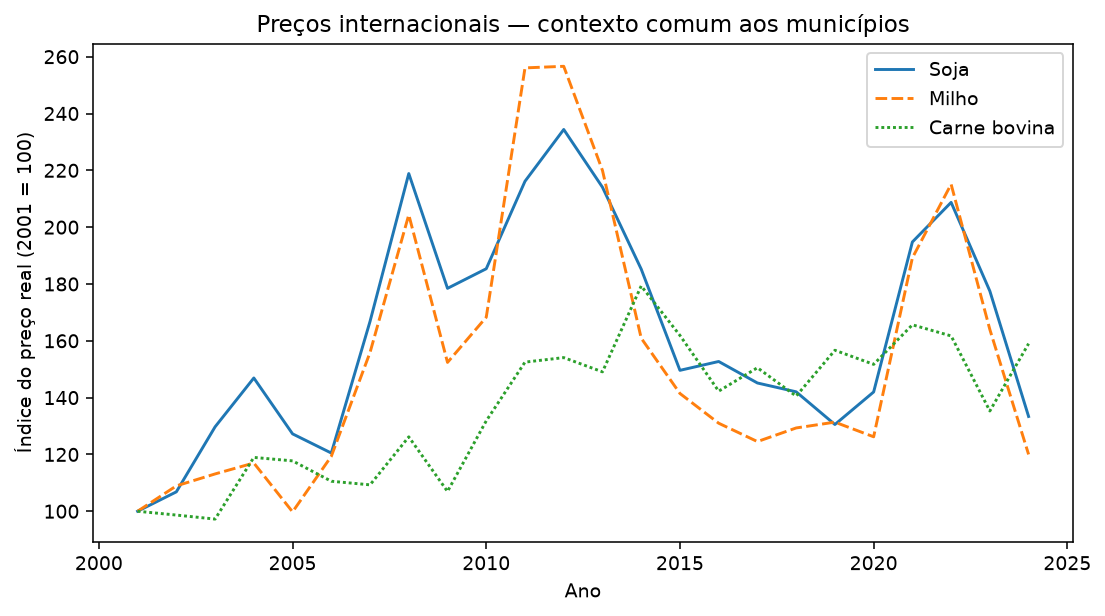

In [49]:
plt.figure(figsize=(8, 4.5), dpi=140)
sns.lineplot(data=indices_precos_1a)
plt.xlabel("Ano")
plt.ylabel("Índice do preço real (2001 = 100)")
plt.title("Preços internacionais — contexto comum aos municípios")
plt.tight_layout()
plt.show()


In [50]:
# Cenários biofísicos separados: sx em índice 0–10.000; yx em kg de matéria seca/ha.
descritiva_gaez_1a = df1a.filter(regex="^gaez_")
descritiva_gaez_1a = descritiva_gaez_1a.describe()
descritiva_gaez_1a.T


,count,mean,std,min,25%,50%,75%,max
gaez_sx_soja_H,141.0,4984.728548,689.401652,2957.916148,4643.772889,5035.043181,5312.297693,6490.347647
gaez_sx_milho_H,141.0,2992.379072,538.782035,1807.545099,2725.614888,3036.648127,3232.097767,5615.814507
gaez_sx_soja_L,141.0,2134.382390,379.454710,1200.559205,1815.676130,2091.100590,2411.345280,3296.448079
gaez_sx_milho_L,141.0,2219.049275,445.370311,1284.132818,1907.368867,2178.400222,2520.525961,4194.654552
gaez_yx_soja_H,141.0,2921.531214,380.929988,1753.346682,2595.856713,2832.162697,3270.367615,3733.417170
gaez_yx_milho_H,141.0,3303.268993,781.291513,1969.714991,2863.587789,3144.184983,3467.729252,7008.442922
gaez_yx_soja_L,141.0,302.574885,70.139817,111.580027,268.413006,302.181454,343.315793,512.229209
gaez_yx_milho_L,141.0,890.826527,211.449067,389.494389,768.662488,869.009790,1008.395804,1580.565073


In [51]:
# Variação líquida de estoques na fonte de classes; não é conversão bruta.
df1a[["nativa_ha_2001", "nativa_ha_2024", "nativa_ha_mudanca_2001_2024", "agricultura_ha_2024", "pastagem_ha_2024"]].describe().T


,count,mean,std,min,25%,50%,75%,max
nativa_ha_2001,141.0,458675.893825,530010.119299,7973.320564,113662.880497,291033.247881,508109.322547,2.721688e+06
nativa_ha_2024,141.0,389638.750078,473010.163938,6517.857145,94291.555521,227163.947394,410087.254348,2.207162e+06
nativa_ha_mudanca_2001_2024,141.0,-69037.143747,80265.942141,-530418.207444,-87333.009862,-45451.806531,-12204.297348,5.272550e+04
agricultura_ha_2024,141.0,88067.816651,118744.580117,58.863846,6134.344871,41316.213228,121915.261531,6.089837e+05
pastagem_ha_2024,141.0,143297.291181,130429.295930,4074.424030,50488.466135,105385.807900,206548.609815,6.794286e+05


#### 1.2 df2 (Sintético)

In [52]:
# Versão sintética do dataframe

In [53]:
### df2 — seleção para análise preliminar

# Base: `../HIPOTESES TESE - CHAP1.txt`. Período confirmado: **2001–2024**.
# São **30 colunas: 2 identificadoras, 24 medidas e 4 indicadores de qualidade**.
# A seleção serve à descrição inicial; não define uma especificação econométrica.

# - **Y:** conversão em hectares e taxa em proporção, com agricultura e pastagem separadas.
# - **X1:** preços médios anuais reais, na unidade de cada produto. São referências internacionais comuns aos municípios. Nesta leitura, usam-se valores do próprio ano, sem interpretá-los como expectativa de retorno.
# - **X2:** rendimentos observados da PAM e médias históricas de 1991–2000 (mínimo de 7 anos válidos). A capacidade histórica tem cobertura seletiva, sobretudo para soja. Os cenários GAEZ ficam em `df` para uma comparação posterior.
# - **X3:** contagem e multas reais de Desmatamento/Desmatamento e Queimada, pelo município informado no auto. As flags acompanham essas medidas porque há contagens/somas parciais. Valor autuado não é pagamento, e autuações não medem diretamente efetividade da fiscalização.
# - **X4–X6:** rebanho, lotação aparente, vegetação nativa inicial na máscara de Y, usos instalados em t−1 e frações dos três biomas.
# - **X8–X9:** chuva anual, anomalia padronizada com referência 1981–2000 e elevação média.

# Custos (X7) e embargos ainda não têm medidas prontas no painel. Logs, diferenças de logs,
# interações, demais defasagens e alternativas territoriais permanecem em `df`.
# `df2` conserva nomes, valores, linhas e ausências; não aplica imputação nem exclusão de casos incompletos.


In [54]:
# Seleção simplificada do roteiro H1: 141 municípios de MT, 2001–2024.
# Cada produto/destino permanece separado. Proporções não estão em %.
# As flags de qualidade acompanham Y e IBAMA; não são controles do modelo.

colunas_df2 = [
    # Identificação
    'codigo_ibge',  # Código municipal IBGE.
    'ano',  # Ano civil.

    # Y — conversão de vegetação nativa entre t−1 e t (municipal, anual)
    'conversao_ha__agricultura',  # ha convertidos para agricultura.
    'conversao_ha__pastagem',  # ha convertidos para pastagem.
    'taxa_conversao__agricultura',  # Proporção da vegetação nativa inicial.
    'taxa_conversao__pastagem',  # Proporção da vegetação nativa inicial.

    # X1 — preços internacionais reais, médias anuais do ano t
    'preco_real_usd2024_media_anual__soja',  # US$ de 2024/t.
    'preco_real_usd2024_media_anual__milho',  # US$ de 2024/t.
    'preco_real_usd2024_media_anual__carne_bovina',  # US$ de 2024/kg.

    # X2 — produtividade PAM observada e histórica (municipal; kg/ha)
    'rendimento_medio_kg_ha__Soja (em grão)',  # Rendimento observado no ano.
    'rendimento_medio_kg_ha__Milho (em grão)',  # Rendimento observado no ano.
    'capacidade_valor__soja__pam_1991_2000_min7',  # Média histórica fixa.
    'capacidade_valor__milho__pam_1991_2000_min7',  # Média histórica fixa.

    # X3 — IBAMA, tema desmatamento, município informado, ano da lavratura
    'n_autos_desmatamento__ibama_informada',  # Quantidade de autos.
    'multas_desmatamento_reais_observadas__ibama_informada',  # R$ de dez./2024 autuados.

    # X4 — pecuária (municipal, anual)
    'efetivo_bovino',  # Cabeças de bovinos (PPM).
    'lotacao_cabecas_ha',  # Cabeças/ha de pastagem; lotação aparente.

    # X5 — vegetação inicial e usos instalados (municipal; ha em t−1)
    'y_nativa_inicial_ha',  # Estoque nativo na mesma máscara das transições de Y.
    'agricultura_ha_lag1',  # Estoque de área agrícola no ano anterior.
    'pastagem_ha_lag1',  # Estoque de área de pastagem no ano anterior.

    # X6 — composição de biomas (municipal, fixa; proporções 0–1)
    'biome_amazonia_share_i',
    'biome_cerrado_share_i',
    'biome_pantanal_share_i',

    # X8 — chuva CHIRPS (municipal, anual)
    'precip_mm_anual',  # Precipitação acumulada no ano civil; mm.
    'precip_zscore_1981_2000',  # Anomalia em desvios-padrão; adimensional.

    # X9 — relevo (municipal, fixo)
    'elevation_mean_m',  # Elevação média da superfície (DSM); m.

    # Qualidade — True indica a condição descrita; ausência não equivale a False.
    'y_cobertura_completa',  # Par de mapas com cobertura integral para Y.
    'flag_sem_registro_identificado__ibama_informada',  # Sem auto identificado.
    'flag_contagem_desmatamento_parcial__ibama_informada',  # Contagem parcial.
    'flag_soma_desmatamento_parcial__ibama_informada',  # Soma de multas reais parcial.
]

df2 = df.loc[:, colunas_df2].copy()

In [55]:
# Transforma 'codigo_ibge' em string (ou 'category') garantindo 7 dígitos
df2['codigo_ibge'] = df2['codigo_ibge'].astype(str).str.zfill(7)

# Transforma em categoria
df2['codigo_ibge'] = df2['codigo_ibge'].astype(str).str.zfill(7).astype('category')

In [56]:
# Transforma 'ano' em formato datetime (padrão: YYYY-01-01)
df2['ano'] = pd.to_datetime(df2['ano'], format='%Y')

# Deixar apenas o ano
df2['ano'] = pd.to_datetime(df2['ano'], format='%Y').dt.to_period('Y')

##### Visão geral

In [57]:
df2.shape

(3384, 30)

In [58]:
df2.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 3384 entries, 0 to 3383
Data columns (total 30 columns):
 #   Column                                                 Non-Null Count  Dtype        
---  ------                                                 --------------  -----        
 0   codigo_ibge                                            3384 non-null   category     
 1   ano                                                    3384 non-null   period[Y-DEC]
 2   conversao_ha__agricultura                              2772 non-null   float64      
 3   conversao_ha__pastagem                                 2772 non-null   float64      
 4   taxa_conversao__agricultura                            2772 non-null   float64      
 5   taxa_conversao__pastagem                               2772 non-null   float64      
 6   preco_real_usd2024_media_anual__soja                   3384 non-null   float64      
 7   preco_real_usd2024_media_anual__milho                  3384 non-null   float64      
 8  

In [59]:
# Describe dados quantitativos, incluindo contagem de valores ausentes.
df2.describe()

,conversao_ha__agricultura,conversao_ha__pastagem,taxa_conversao__agricultura,taxa_conversao__pastagem,preco_real_usd2024_media_anual__soja,preco_real_usd2024_media_anual__milho,preco_real_usd2024_media_anual__carne_bovina,rendimento_medio_kg_ha__Soja (em grão),rendimento_medio_kg_ha__Milho (em grão),capacidade_valor__soja__pam_1991_2000_min7,...,lotacao_cabecas_ha,y_nativa_inicial_ha,agricultura_ha_lag1,pastagem_ha_lag1,biome_amazonia_share_i,biome_cerrado_share_i,biome_pantanal_share_i,precip_mm_anual,precip_zscore_1981_2000,elevation_mean_m
count,2772.000000,2772.000000,2772.000000,2772.000000,3384.000000,3384.000000,3384.000000,2615.000000,3318.000000,1128.000000,...,3376.000000,3.384000e+03,3384.000000,3384.000000,3384.000000,3384.000000,3384.000000,3384.000000,3384.000000,3384.000000
mean,297.697312,3257.588132,0.001122,0.011915,564.811723,245.199191,5.093596,3116.528107,4219.090717,2492.238129,...,1.470776,4.168223e+05,64451.787068,143597.824620,0.529147,0.442483,0.028354,1728.719389,-0.141756,354.818208
std,1015.382300,4832.176411,0.003751,0.014295,129.059773,72.432632,0.883185,379.187713,1509.842385,173.464064,...,0.693924,4.956423e+05,104419.380122,120347.816570,0.449139,0.442866,0.137976,367.019152,1.322443,123.210289
min,0.000000,0.953154,0.000000,0.000029,346.971098,158.498215,3.626947,900.000000,600.000000,2117.100000,...,0.069283,6.485420e+03,0.000000,3958.176720,0.000000,0.000000,0.000000,665.267759,-5.712556,120.106876
25%,3.114156,579.761195,0.000018,0.004291,460.261568,190.353931,4.324344,2992.000000,3000.000000,2347.600000,...,1.066957,1.008952e+05,1600.214075,54470.659872,0.000000,0.000000,0.000000,1465.602065,-0.931399,275.598470
50%,26.987478,1644.679448,0.000143,0.007994,524.462840,216.679294,5.274027,3120.000000,4136.500000,2489.000000,...,1.397384,2.508805e+05,16151.843687,111152.027868,0.711130,0.252627,0.000000,1702.990964,-0.179526,338.721026
75%,173.347514,3769.385707,0.000761,0.014125,651.309836,275.632105,5.770997,3300.000000,5490.250000,2620.300000,...,1.741431,4.384596e+05,74939.625521,202325.293603,1.000000,1.000000,0.000000,1982.263489,0.631314,411.357121
max,18222.268087,56983.225434,0.079950,0.265411,813.211356,407.619924,6.687605,4600.000000,8355.000000,2913.500000,...,8.491291,2.737509e+06,608255.137072,683014.513040,1.000000,1.000000,0.997371,3038.987243,6.308761,810.711629


In [60]:
# Describe dados qualitativos, incluindo contagem de valores ausentes.
df2.describe(include=['object', 'category', 'bool', 'datetime', 'timedelta'])

,codigo_ibge,y_cobertura_completa,flag_sem_registro_identificado__ibama_informada,flag_contagem_desmatamento_parcial__ibama_informada,flag_soma_desmatamento_parcial__ibama_informada
count,3384,3384,3384,2284,2284
unique,141,2,2,2,2
top,5100102,True,False,True,True
freq,24,2772,2284,1606,1611


##### Agregar municípios

**df2a: perfil municipal descritivo — 2001–2024**

Uma linha por município. As médias usam os anos observados; as tabelas de cobertura mostram quantos e quais limites temporais sustentam cada resumo. A soma observada de conversões pode ser parcial; o total de 2001–2024 exige 24 anos válidos. A razão de somas é uma taxa anual média ponderada pela vegetação disponível, não um percentual acumulado de perda.

Estoques são preservados em datas exatas. Ausências continuam ausentes. Autos e multas representam registros observados, possivelmente parciais; multas estão em R$ de dezembro de 2024. Cada município recebe o mesmo peso nas descritivas entre municípios. Os resultados contextualizam o território e não estimam causalidade.


In [61]:
df2a = df2.copy()


In [62]:
df2a["ano"] = df2a["ano"].dt.year


In [63]:
# Nomes curtos apenas nesta cópia; unidades mantidas nos nomes e comentários.
df2a = df2a.rename(columns={
    'conversao_ha__agricultura': 'conv_agricultura_ha',
    'conversao_ha__pastagem': 'conv_pastagem_ha',
    'taxa_conversao__agricultura': 'taxa_agricultura',
    'taxa_conversao__pastagem': 'taxa_pastagem',
    'rendimento_medio_kg_ha__Soja (em grão)': 'prod_soja_kg_ha',
    'rendimento_medio_kg_ha__Milho (em grão)': 'prod_milho_kg_ha',
    'capacidade_valor__soja__pam_1991_2000_min7': 'cap_soja_kg_ha',
    'capacidade_valor__milho__pam_1991_2000_min7': 'cap_milho_kg_ha',
    'n_autos_desmatamento__ibama_informada': 'autos_desmat',
    'multas_desmatamento_reais_observadas__ibama_informada': 'multas_desmat_reais',
    'y_nativa_inicial_ha': 'nativa_inicio_ha',
    'agricultura_ha_lag1': 'agricultura_anterior_ha',
    'pastagem_ha_lag1': 'pastagem_anterior_ha',
    'biome_amazonia_share_i': 'amazonia_share',
    'biome_cerrado_share_i': 'cerrado_share',
    'biome_pantanal_share_i': 'pantanal_share',
    'precip_mm_anual': 'chuva_mm',
    'precip_zscore_1981_2000': 'chuva_z',
    'elevation_mean_m': 'elevacao_m',
    'y_cobertura_completa': 'cobertura_y',
    'flag_sem_registro_identificado__ibama_informada': 'sem_auto_identificado',
    'flag_contagem_desmatamento_parcial__ibama_informada': 'contagem_parcial',
    'flag_soma_desmatamento_parcial__ibama_informada': 'multa_parcial',
})


**1. Preparar cobertura, características fixas e fluxos**


In [64]:
# Cada destino usa o seu próprio conjunto de anos válidos.
df2a["ano_agricultura"] = df2a["ano"].where(df2a["conv_agricultura_ha"].notna())
df2a["ano_pastagem"] = df2a["ano"].where(df2a["conv_pastagem_ha"].notna())
df2a["nativa_exposta_agricultura"] = df2a["nativa_inicio_ha"].where(df2a["conv_agricultura_ha"].notna())
df2a["nativa_exposta_pastagem"] = df2a["nativa_inicio_ha"].where(df2a["conv_pastagem_ha"].notna())


In [65]:
fixas_2a = ['cap_soja_kg_ha', 'cap_milho_kg_ha', 'amazonia_share', 'cerrado_share', 'pantanal_share', 'elevacao_m']
grupo_2a = df2a.groupby("codigo_ibge", observed=True)


In [66]:
# Conferência: características fixas têm no máximo um valor válido por município.
constancia_2a = grupo_2a[fixas_2a].nunique()
constancia_2a.max()


cap_soja_kg_ha     1
cap_milho_kg_ha    1
amazonia_share     1
cerrado_share      1
pantanal_share     1
elevacao_m         1
dtype: int64

In [67]:
fixas_2a = grupo_2a[fixas_2a].first()


In [68]:
qualidade_2a = grupo_2a.agg(
    anos_grade=("ano", "size"),
    anos_y_agricultura=("ano_agricultura", "count"),
    primeiro_ano_y_agricultura=("ano_agricultura", "min"),
    ultimo_ano_y_agricultura=("ano_agricultura", "max"),
    anos_y_pastagem=("ano_pastagem", "count"),
    primeiro_ano_y_pastagem=("ano_pastagem", "min"),
    ultimo_ano_y_pastagem=("ano_pastagem", "max"),
    anos_sem_auto_identificado=("sem_auto_identificado", "sum"),
    anos_flag_contagem_conhecida=("contagem_parcial", "count"),
    anos_contagem_parcial=("contagem_parcial", "sum"),
    anos_flag_multa_conhecida=("multa_parcial", "count"),
    anos_multa_parcial=("multa_parcial", "sum")
)


In [69]:
qualidade_2a["y_24_anos"] = qualidade_2a["anos_y_agricultura"].eq(24) & qualidade_2a["anos_y_pastagem"].eq(24)
qualidade_2a["anos_flag_contagem_desconhecida"] = 24 - qualidade_2a["anos_flag_contagem_conhecida"]
qualidade_2a["anos_flag_multa_desconhecida"] = 24 - qualidade_2a["anos_flag_multa_conhecida"]


In [70]:
# min_count=1: grupos inteiramente ausentes não viram zero.
fluxos_2a = grupo_2a[["conv_agricultura_ha", "conv_pastagem_ha", "autos_desmat", "multas_desmat_reais"]].sum(min_count=1)
fluxos_2a = fluxos_2a.add_suffix("_soma_observada")
exposicao_2a = grupo_2a[["nativa_exposta_agricultura", "nativa_exposta_pastagem"]].sum(min_count=1)


In [71]:
fluxos_2a["taxa_agricultura_ponderada_pct"] = 100 * fluxos_2a["conv_agricultura_ha_soma_observada"] / exposicao_2a["nativa_exposta_agricultura"]
fluxos_2a["taxa_pastagem_ponderada_pct"] = 100 * fluxos_2a["conv_pastagem_ha_soma_observada"] / exposicao_2a["nativa_exposta_pastagem"]
fluxos_2a["conv_agricultura_total_2001_2024_ha"] = fluxos_2a["conv_agricultura_ha_soma_observada"].where(qualidade_2a["anos_y_agricultura"].eq(24))
fluxos_2a["conv_pastagem_total_2001_2024_ha"] = fluxos_2a["conv_pastagem_ha_soma_observada"].where(qualidade_2a["anos_y_pastagem"].eq(24))


In [72]:
taxas_2a = grupo_2a[["taxa_agricultura", "taxa_pastagem"]].mean()
taxas_2a = taxas_2a * 100
taxas_2a = taxas_2a.add_suffix("_media_pct")


**2. Resumir os anos observados e preservar as datas dos estoques**


In [73]:
medidas_2a = ["conv_agricultura_ha", "conv_pastagem_ha", "prod_soja_kg_ha", "prod_milho_kg_ha", "efetivo_bovino", "lotacao_cabecas_ha", "autos_desmat", "multas_desmat_reais", "chuva_mm", "chuva_z"]
estatisticas_2a = grupo_2a[medidas_2a].agg(["count", "mean", "median", "std"])
estatisticas_2a.columns = estatisticas_2a.columns.map("_".join)


In [74]:
chuva_extremos_2a = grupo_2a[["chuva_mm", "chuva_z"]].agg(["min", "max"])
chuva_extremos_2a.columns = chuva_extremos_2a.columns.map("_".join)


In [75]:
# Cobertura individual, sem eliminar conjuntamente linhas por ausência em outras medidas.
anos_2a = df2a[medidas_2a].notna()
anos_2a = anos_2a.mul(df2a["ano"], axis=0)
anos_2a = anos_2a.replace(0, np.nan)
anos_2a["codigo_ibge"] = df2a["codigo_ibge"]


In [76]:
grupo_anos_2a = anos_2a.groupby("codigo_ibge", observed=True)
cobertura_2a = grupo_anos_2a.agg(["count", "min", "max"])
cobertura_2a = cobertura_2a.stack(level=0)
cobertura_2a = cobertura_2a.rename(columns={"count": "anos_validos", "min": "primeiro_ano", "max": "ultimo_ano"})
cobertura_2a["anos_ausentes"] = 24 - cobertura_2a["anos_validos"]
cobertura_2a["lacunas_internas"] = cobertura_2a["ultimo_ano"] - cobertura_2a["primeiro_ano"] + 1 - cobertura_2a["anos_validos"]


In [77]:
# Área nativa do par de mapas: exigir cobertura completa para comparar estoques.
df2a["nativa_inicio_ha"] = df2a["nativa_inicio_ha"].where(df2a["cobertura_y"].eq(True))
# Estes campos representam t−1: linhas 2001 e 2024 contêm estoques de 2000 e 2023.
estoques_2a = ["nativa_inicio_ha", "agricultura_anterior_ha", "pastagem_anterior_ha"]
inicio_2a = df2a.loc[df2a["ano"].eq(2001), ["codigo_ibge"] + estoques_2a]
inicio_2a = inicio_2a.set_index("codigo_ibge")
fim_2a = df2a.loc[df2a["ano"].eq(2024), ["codigo_ibge"] + estoques_2a]
fim_2a = fim_2a.set_index("codigo_ibge")


In [78]:
mudanca_2a = fim_2a - inicio_2a
mudanca_2a = mudanca_2a.add_suffix("_mudanca_2000_2023")
inicio_2a = inicio_2a.add_suffix("_2000")
fim_2a = fim_2a.add_suffix("_2023")


In [79]:
# Datas exatas do rebanho; não usar first/last, que podem pular ausências.
rebanho_2a = df2a.loc[df2a["ano"].isin([2001, 2024]), ["codigo_ibge", "ano", "efetivo_bovino"]]
rebanho_2a = rebanho_2a.pivot(index="codigo_ibge", columns="ano", values="efetivo_bovino")
rebanho_2a = rebanho_2a.rename(columns={2001: "bovinos_2001", 2024: "bovinos_2024"})
rebanho_2a["bovinos_mudanca_2001_2024"] = rebanho_2a["bovinos_2024"] - rebanho_2a["bovinos_2001"]


In [80]:
df2a = pd.concat([qualidade_2a, fluxos_2a, taxas_2a, estatisticas_2a, chuva_extremos_2a, fixas_2a, inicio_2a, fim_2a, mudanca_2a, rebanho_2a], axis=1)
df2a = df2a.reset_index()


In [81]:
df2a.shape


(141, 88)

In [82]:
df2a.head()


,codigo_ibge,anos_grade,anos_y_agricultura,primeiro_ano_y_agricultura,ultimo_ano_y_agricultura,anos_y_pastagem,primeiro_ano_y_pastagem,ultimo_ano_y_pastagem,anos_sem_auto_identificado,anos_flag_contagem_conhecida,...,pastagem_anterior_ha_2000,nativa_inicio_ha_2023,agricultura_anterior_ha_2023,pastagem_anterior_ha_2023,nativa_inicio_ha_mudanca_2000_2023,agricultura_anterior_ha_mudanca_2000_2023,pastagem_anterior_ha_mudanca_2000_2023,bovinos_2001,bovinos_2024,bovinos_mudanca_2001_2024
0,5100102,24,24,2001.0,2024.0,24,2001.0,2024.0,14,10,...,23112.083108,52971.812603,319.877942,28746.088476,-6514.483129,172.873232,5634.005367,32000.0,54717.0,22717.0
1,5100201,24,24,2001.0,2024.0,24,2001.0,2024.0,5,19,...,342885.596462,314235.941750,176821.243918,212313.878634,-42456.055608,135364.217487,-130571.717828,351920.0,315000.0,-36920.0
2,5100250,24,14,2009.0,2024.0,14,2009.0,2024.0,0,24,...,356868.579215,426698.981299,61802.487459,395006.653077,NaN,59958.489896,38138.073862,539676.0,691455.0,151779.0
3,5100300,24,24,2001.0,2024.0,24,2001.0,2024.0,4,20,...,215243.169510,273920.948080,45873.778571,189214.447470,-23159.071512,30773.548306,-26028.722039,140838.0,170423.0,29585.0
4,5100359,24,24,2001.0,2024.0,24,2001.0,2024.0,7,17,...,70111.057978,86962.726237,40428.046200,94755.237706,-66239.846953,39765.981322,24644.179728,59444.0,46731.0,-12713.0


**3. Cobertura e estatísticas entre municípios**

`mean`, `median` e `std` nos nomes são resumos dos anos observados de cada município; `count` é o número desses anos. A tabela abaixo descreve a distribuição desses resumos entre municípios, com N e ausências por medida. Não há exclusão conjunta de casos, imputação, testes ou intervalos de confiança. Os totais completos têm suporte menor que as somas parciais.


In [83]:
descrever_2a = ['taxa_agricultura_media_pct', 'taxa_pastagem_media_pct', 'taxa_agricultura_ponderada_pct', 'taxa_pastagem_ponderada_pct', 'conv_agricultura_total_2001_2024_ha', 'conv_pastagem_total_2001_2024_ha', 'prod_soja_kg_ha_mean', 'prod_milho_kg_ha_mean', 'efetivo_bovino_mean', 'lotacao_cabecas_ha_mean', 'autos_desmat_mean', 'multas_desmat_reais_mean', 'chuva_mm_mean', 'chuva_mm_std', 'chuva_z_min', 'chuva_z_max', 'cap_soja_kg_ha', 'cap_milho_kg_ha', 'amazonia_share', 'cerrado_share', 'pantanal_share', 'elevacao_m']


In [84]:
descritiva_2a = df2a[descrever_2a].describe(percentiles=[0.25, 0.5, 0.75])
descritiva_2a = descritiva_2a.T
descritiva_2a["ausentes"] = len(df2a) - descritiva_2a["count"]
descritiva_2a["IQR"] = descritiva_2a["75%"] - descritiva_2a["25%"]
descritiva_2a.round(3)


,count,mean,std,min,25%,50%,75%,max,ausentes,IQR
taxa_agricultura_media_pct,137.0,0.112,0.192,0.000,0.008,0.034,0.126,1.238000e+00,4.0,0.118
taxa_pastagem_media_pct,137.0,1.190,0.785,0.095,0.625,1.069,1.468,4.389000e+00,4.0,0.843
taxa_agricultura_ponderada_pct,137.0,0.120,0.219,0.000,0.008,0.034,0.133,1.528000e+00,4.0,0.124
taxa_pastagem_ponderada_pct,137.0,1.225,0.828,0.097,0.632,1.069,1.509,4.459000e+00,4.0,0.876
conv_agricultura_total_2001_2024_ha,95.0,6018.255,10634.153,0.776,290.240,1297.081,4542.552,4.838944e+04,46.0,4252.312
conv_pastagem_total_2001_2024_ha,95.0,62324.647,75188.467,1519.421,14029.368,44311.446,80288.131,5.889647e+05,46.0,66258.763
prod_soja_kg_ha_mean,136.0,3139.312,175.935,2648.867,3055.844,3130.208,3200.031,3.767500e+03,5.0,144.188
prod_milho_kg_ha_mean,141.0,4206.873,784.453,1863.368,3768.500,4268.050,4717.000,6.115250e+03,0.0,948.500
efetivo_bovino_mean,141.0,202589.903,185675.451,14341.350,73124.500,141447.208,290373.500,1.006741e+06,0.0,217249.000
lotacao_cabecas_ha_mean,141.0,1.471,0.502,0.355,1.141,1.435,1.771,3.814000e+00,0.0,0.629


In [85]:
# Distribuição da cobertura de cada medida: municípios × número de anos válidos.
tabela_cobertura_2a = cobertura_2a.reset_index()
tabela_cobertura_2a = pd.crosstab(tabela_cobertura_2a["level_1"], tabela_cobertura_2a["anos_validos"])
tabela_cobertura_2a


anos_validos,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
level_1,,,,,,,,,,,,,,,,,,,,,
autos_desmat,2,4,9,6,8,6,9,8,3,5,...,2,5,4,5,9,8,11,7,3,4
chuva_mm,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,141
chuva_z,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,141
conv_agricultura_ha,4,3,1,7,2,0,0,1,1,2,...,1,2,1,3,0,2,4,3,0,95
conv_pastagem_ha,4,3,1,7,2,0,0,1,1,2,...,1,2,1,3,0,2,4,3,0,95
efetivo_bovino,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,2,0,0,0,139
lotacao_cabecas_ha,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,2,0,0,0,139
multas_desmat_reais,2,4,9,6,8,6,10,7,3,6,...,2,5,4,5,10,7,11,7,3,4
prod_milho_kg_ha,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,1,4,3,6,4,121


In [86]:
# Parcialidade conhecida e desconhecida deve acompanhar a leitura do IBAMA.
df2a[["codigo_ibge", "autos_desmat_count", "multas_desmat_reais_count", "anos_contagem_parcial", "anos_flag_contagem_desconhecida", "anos_multa_parcial", "anos_flag_multa_desconhecida"]].head(10)


,codigo_ibge,autos_desmat_count,multas_desmat_reais_count,anos_contagem_parcial,anos_flag_contagem_desconhecida,anos_multa_parcial,anos_flag_multa_desconhecida
0,5100102,7,7,7,14,7,14
1,5100201,12,12,11,5,11,5
2,5100250,22,22,19,0,19,0
3,5100300,14,14,16,4,16,4
4,5100359,13,13,11,7,11,7
5,5100409,8,8,13,8,13,8
6,5100508,4,4,4,17,4,17
7,5100607,9,9,8,9,8,9
8,5100805,20,20,19,0,19,0
9,5101001,13,13,17,3,17,3


In [87]:
# Comparação de Y com janela comum: conserva apenas os 24 anos completos nesta tabela.
completos_2a = df2a.loc[df2a["y_24_anos"]].copy()
completos_2a[["taxa_agricultura_ponderada_pct", "taxa_pastagem_ponderada_pct"]].describe().T


,count,mean,std,min,25%,50%,75%,max
taxa_agricultura_ponderada_pct,95.0,0.118497,0.220837,0.000450,0.008456,0.030111,0.134457,1.528089
taxa_pastagem_ponderada_pct,95.0,1.197875,0.808300,0.096504,0.623780,1.079040,1.495796,4.458761


As figuras de Y com janela comum usam os municípios com 24 anos válidos. Essa seleção melhora a comparabilidade temporal, mas não representa automaticamente os 141 municípios. Valores extremos são mantidos; os pontos dos boxplots não são descartes.


**4. Figuras: cobertura e perfis de conversão**


In [88]:
frequencia_2a = df2a["anos_y_agricultura"].value_counts()
frequencia_2a = frequencia_2a.reindex(range(25), fill_value=0)
frequencia_2a


anos_y_agricultura
0      4
1      3
2      1
3      7
4      2
5      0
6      0
7      1
8      1
9      2
10     0
11     1
12     2
13     2
14     4
15     1
16     2
17     1
18     3
19     0
20     2
21     4
22     3
23     0
24    95
Name: count, dtype: int64

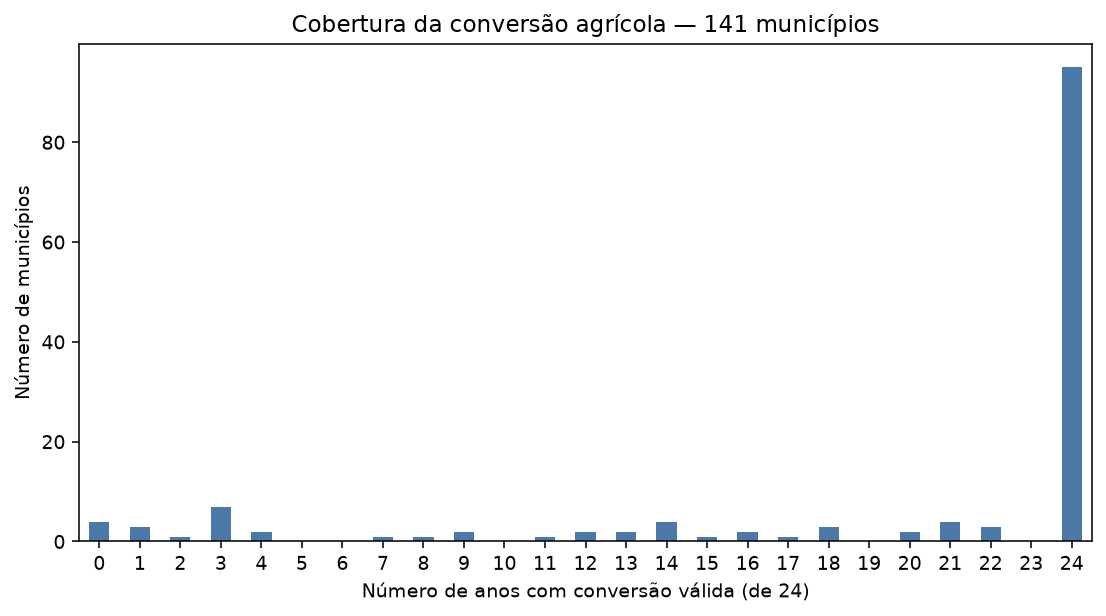

In [89]:
plt.figure(figsize=(8, 4.5), dpi=140)
frequencia_2a.plot.bar(color="#4c78a8")
plt.xlabel("Número de anos com conversão válida (de 24)")
plt.ylabel("Número de municípios")
plt.title(f"Cobertura da conversão agrícola — {len(df2a)} municípios")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [90]:
taxas_grafico_2a = completos_2a[["taxa_agricultura_ponderada_pct", "taxa_pastagem_ponderada_pct"]].copy()
taxas_grafico_2a.columns = ["Agricultura", "Pastagem"]


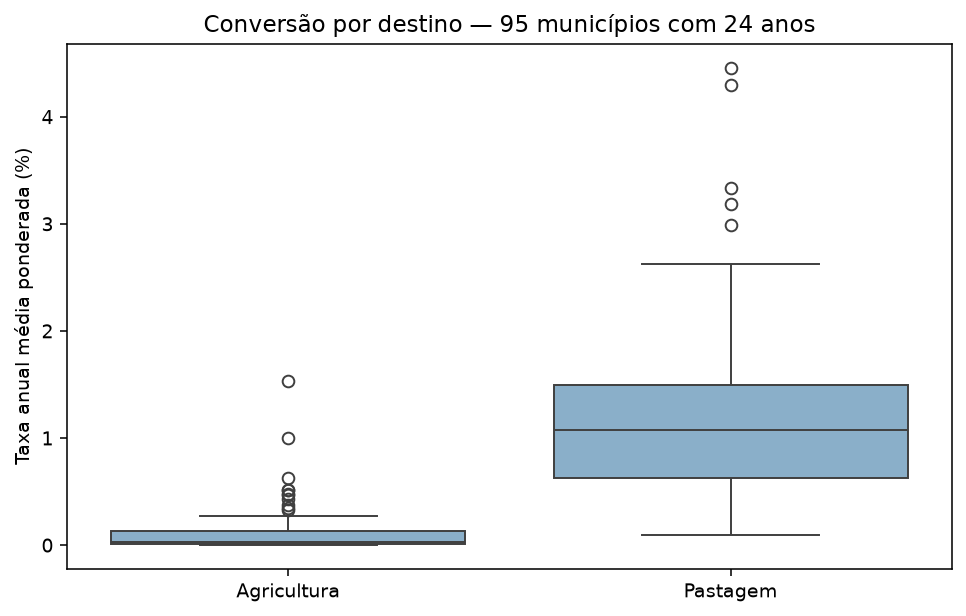

In [91]:
plt.figure(figsize=(7, 4.5), dpi=140)
sns.boxplot(data=taxas_grafico_2a, color="#80b1d3")
plt.ylabel("Taxa anual média ponderada (%)")
plt.title(f"Conversão por destino — {len(completos_2a)} municípios com 24 anos")
plt.tight_layout()
plt.show()


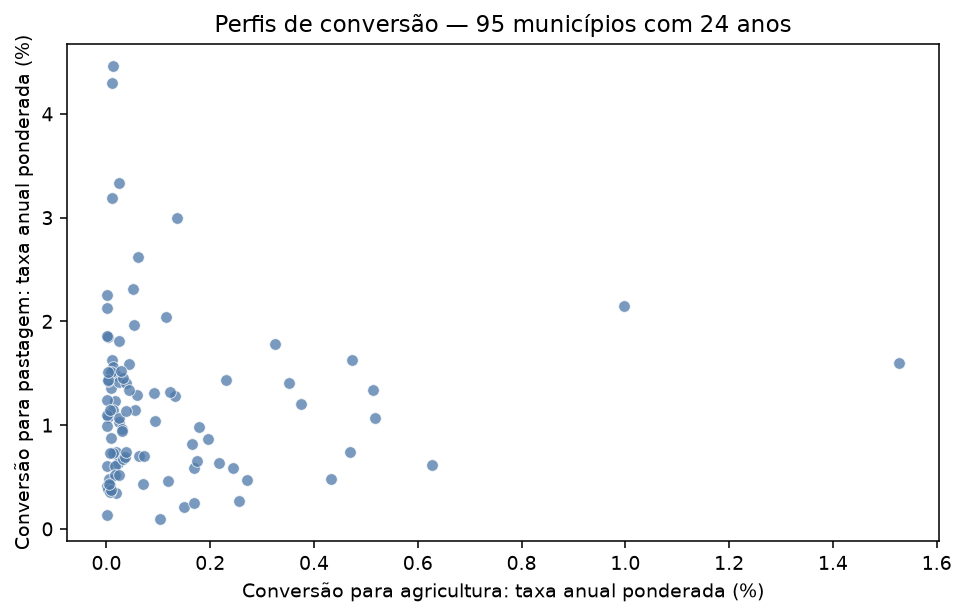

In [92]:
plt.figure(figsize=(7, 4.5), dpi=140)
sns.scatterplot(data=completos_2a, x="taxa_agricultura_ponderada_pct", y="taxa_pastagem_ponderada_pct", color="#4c78a8", alpha=0.75)
plt.xlabel("Conversão para agricultura: taxa anual ponderada (%)")
plt.ylabel("Conversão para pastagem: taxa anual ponderada (%)")
plt.title(f"Perfis de conversão — {len(completos_2a)} municípios com 24 anos")
plt.tight_layout()
plt.show()


Cada ponto representa um município. A dispersão descreve a composição das taxas médias por destino; não identifica substituição causal entre agricultura e pastagem. Os dois destinos são conversões diretas de vegetação nativa.


In [93]:
# Estoques defasados: datas efetivas 2000 e 2023, sem deslocamento implícito para 2024.
df2a[["nativa_inicio_ha_2000", "nativa_inicio_ha_2023", "nativa_inicio_ha_mudanca_2000_2023", "bovinos_2001", "bovinos_2024"]].describe().T


,count,mean,std,min,25%,50%,75%,max
nativa_inicio_ha_2000,117.0,422159.092121,507987.074403,8634.778290,113944.317489,282228.411602,438062.293564,2.737509e+06
nativa_inicio_ha_2023,136.0,371293.961759,451196.555317,6485.419932,89921.140733,226381.214575,395572.689422,2.210134e+06
nativa_inicio_ha_mudanca_2000_2023,116.0,-66647.708733,79166.829129,-532745.698994,-88333.151731,-42369.218221,-11157.228150,2.922997e+03
bovinos_2001,139.0,143320.971223,135721.767754,4115.000000,52731.500000,105000.000000,192539.500000,7.407760e+05
bovinos_2024,141.0,233002.609929,219645.140656,15000.000000,93747.000000,149344.000000,323335.000000,1.365224e+06


### 2. DATAFRAMES Y--X

Recortes do **df1 completo (PT)** conforme as colunas relacionadas no catálogo `paineis/variaveis_por_candidato_pt-gm_chap1.md`. Cada DataFrame mantém as chaves `codigo_ibge` e `ano`, as linhas município–ano, os tipos e as ausências de `df1`. Incluem-se vínculos principais, secundários e diagnósticos. Os nomes originais ficam nos títulos; os identificadores Python usam underscores no lugar dos hífens.

A seleção organiza as medidas disponíveis; não altera fórmulas, agrega observações ou define a especificação do modelo.

In [94]:
chaves_yx = ["codigo_ibge", "ano"]
assert not df1.duplicated(chaves_yx).any(), "Chave município–ano duplicada em df1."

#### 2.1 Y_conv (Conversão de vegetação nativa)

##### --- (a) Y_conv ---

Identificador Python: `Y_conv`. 15 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [95]:
# Y_conv = conversão bruta de vegetação nativa para agricultura e pastagem, ha, municipal, anual*

###### Criar

In [96]:
# Recorte fiel, preservando a base

In [ ]:
Y_conv = df1.loc[:, chaves_yx + [
    'conversao_ha__agricultura',
    'conversao_ha__pastagem',
    'taxa_conversao__agricultura',
    'taxa_conversao__pastagem',
    'y_colecao',
    'y_malha',
    'y_mascara_id',
    'y_area_total_ha',
    'y_area_valida_par_ha',
    'y_area_nao_valida_par_ha',
    'y_nativa_inicial_ha',
    'y_cobertura_completa',
    'y_fracao_area_valida_par',
    'y_flag_denominador_zero',
    'y_flag_denominador_ausente',
]].copy()

Y_conv.head()
Y_conv.head()

SyntaxError: invalid syntax (517625815.py, line 12)

In [ ]:
Y_conv.columns.tolist()

In [ ]:
## Colunas 2_INTI\chapters\chap1\stats\EDA\aed_chap1_pt_DICIO.ipynb

#1 - codigo_ibge: Código identificador do município | código IBGE de 7 dígitos | municipal (141 municípios de MT).

#2 - ano: Ano de referência da observação (2001–2024) | ano civil | temporal, comum à grade municipal.

#3 - conversao_ha__agricultura: Vegetação nativa em t−1 convertida em agricultura em t (MapBiomas) | ha | municipal (MT), anual.

#4 - conversao_ha__pastagem: Vegetação nativa em t−1 convertida em pastagem em t (MapBiomas) | ha | municipal (MT), anual.

#5 - taxa_conversao__agricultura: Conversão para agricultura / vegetação nativa inicial na mesma máscara | proporção (0–1) | municipal (MT), anual.

#6 - taxa_conversao__pastagem: Conversão para pastagem / vegetação nativa inicial na mesma máscara | proporção (0–1) | municipal (MT), anual.

#7 - y_colecao: Versão da coleção MapBiomas usada em Y (10.1) | categoria | referência comum ao painel municipal de MT.

#8 - y_malha: Referência territorial usada em Y (IBGE MT 2023, 141 municípios) | identificador textual | referência comum ao painel municipal de MT.

#9 - y_mascara_id: Identificador da máscara espacial usada nas transições de Y | hash textual | municipal (MT), anual.

#10 - y_area_total_ha: Área total da máscara municipal usada em Y | ha | municipal (MT), anual.

#11 - y_area_valida_par_ha: Área com classificação válida nos dois mapas (t−1 e t) | ha | municipal (MT), anual.

#12 - y_area_nao_valida_par_ha: Área sem classificação válida em pelo menos um dos dois mapas | ha | municipal (MT), anual.

#13 - y_nativa_inicial_ha: Vegetação nativa em t−1 na máscara das transições; denominador de Y | ha | municipal (MT), anual.

#14 - y_cobertura_completa: Indica cobertura completa do par de mapas usado em Y | booleano (True/False) | municipal (MT), anual.

#15 - y_fracao_area_valida_par: Área válida nos dois mapas / área total da máscara de Y | proporção (0–1) | municipal (MT), anual.

#16 - y_flag_denominador_zero: Indica vegetação nativa inicial de Y igual a zero | booleano (True/False) | municipal (MT), anual.

#17 - y_flag_denominador_ausente: Indica ausência do denominador de Y | booleano (True/False) | municipal (MT), anual.


###### Estrutura

In [ ]:
# Dimensões, tipos, chaves e domínios

In [ ]:
Y_conv.shape

In [ ]:
Y_conv.info(verbose=True, show_counts=True)

###### Qualidade dos dados

In [ ]:
# Ausências, zeros, flags e suporte territorial/temporal

In [ ]:
# Contar valores ausentes (NaN / None) por coluna
Y_conv.isna().sum()

In [ ]:
# Contar zeros numéricos (0 ou 0.0) por coluna
(Y_conv == 0).sum()

In [ ]:
(3384)-(612)

#  2   conversao_ha__agricultura    2772 non-null   float64      
#  3   conversao_ha__pastagem       2772 non-null   float64      
#  4   taxa_conversao__agricultura  2772 non-null   float64      
#  5   taxa_conversao__pastagem     2772 non-null   float64 

# Valores 0 são válidos, mas não são ausentes. A contagem de valores ausentes é de 612, o que significa que há 612 registros com valores nulos (NaN) nessas colunas.

In [ ]:
# Valores duplicados

In [ ]:
Y_conv.duplicated().sum()

###### Descritiva

In [ ]:
# Descritiva inicial. Resumos apropriados ao papel e à unidade da coluna.

In [ ]:
# Estatísticas descritivas dos dados quantitativos (considera os valores 0 nos cálculos e ignora os NaN).
Y_conv.describe().T

In [ ]:
# Excluir valores ausentes e zeros para análise descritiva
Y_conv_limpo = Y_conv[Y_conv.notna() & (Y_conv != 0)]
Y_conv_limpo.describe().T

In [ ]:
# Estatísticas descritivas de variáveis não numéricas (qualitativas e temporais), ignorando NaN.
Y_conv.describe(exclude=['number']).T

###### Análise Univariada

In [ ]:
# Aprofundamento posterior das distribuições e trajetórias

**1. Quais observações sustentam as distribuições?**

Esta leitura parte de `Y_conv`, preservando os zeros válidos e as ausências. A tabela anterior de `Y_conv_limpo` descreve valores positivos por coluna; não é a base destas análises. As quatro medidas substantivas são os dois fluxos em hectares e as duas taxas derivadas. Denominador e áreas apoiam sua interpretação; flags e metadados documentam qualidade e proveniência.

O painel completo e os perfis de cobertura já foram apresentados em `df1a`/`df2a`. Aqui se recupera apenas o suporte necessário às comparações. Percentuais das taxas são calculados em cópias de apresentação, sem alterar as proporções originais.


In [ ]:
from IPython.display import display, Markdown

def yconv_mostrar(tabela, casas=3):
    # Formatação local: não muda opções de exibição das outras seções.
    with pd.option_context('display.max_columns', None, 'display.max_rows', None,
                           'display.float_format', lambda valor: f'{valor:,.{casas}f}'):
        display(tabela)

yconv_aed = Y_conv.copy()
yconv_destinos = ['agricultura', 'pastagem']
yconv_rotulos = {'agricultura': 'Agricultura', 'pastagem': 'Pastagem'}
yconv_cores = {'agricultura': '#4c78a8', 'pastagem': '#e09136'}
yconv_fluxos = [f'conversao_ha__{d}' for d in yconv_destinos]
yconv_taxas = [f'taxa_conversao__{d}' for d in yconv_destinos]
yconv_medidas = yconv_fluxos + yconv_taxas
yconv_aed['ano'] = yconv_aed['ano'].dt.year

assert not yconv_aed.duplicated(['codigo_ibge', 'ano']).any()
assert not yconv_aed[['codigo_ibge', 'ano']].isna().any().any()
assert yconv_aed[yconv_medidas].isna().eq(yconv_aed[yconv_medidas[0]].isna(), axis=0).all().all()
assert yconv_aed[yconv_medidas[0]].isna().equals(~yconv_aed['y_cobertura_completa'])
yconv_validos = yconv_aed.dropna(subset=yconv_medidas).copy()
assert np.isfinite(yconv_validos[yconv_medidas].to_numpy()).all()
assert yconv_validos[yconv_fluxos].ge(0).all().all()
assert yconv_validos[yconv_taxas].ge(0).all().all() and yconv_validos[yconv_taxas].le(1).all().all()
assert yconv_validos['y_nativa_inicial_ha'].gt(0).all()
for destino in yconv_destinos:
    assert np.allclose(yconv_validos[f'taxa_conversao__{destino}'], yconv_validos[f'conversao_ha__{destino}'] / yconv_validos['y_nativa_inicial_ha'])
assert yconv_validos[yconv_fluxos].sum(axis=1).le(yconv_validos['y_nativa_inicial_ha'] + 1e-4).all()
assert np.allclose(yconv_aed['y_area_valida_par_ha'] + yconv_aed['y_area_nao_valida_par_ha'], yconv_aed['y_area_total_ha'], rtol=1e-8, atol=1e-4)

yconv_anos_grade = yconv_aed['ano'].nunique()
yconv_cobertura_mun = yconv_aed.groupby('codigo_ibge', observed=True)[yconv_medidas[0]].count()
assert yconv_aed.groupby('codigo_ibge', observed=True)['ano'].nunique().eq(yconv_anos_grade).all()
yconv_municipios_completos = yconv_cobertura_mun.index[yconv_cobertura_mun.eq(yconv_anos_grade)]
yconv_completos = yconv_validos.loc[yconv_validos['codigo_ibge'].isin(yconv_municipios_completos)].copy()
yconv_suporte = pd.DataFrame({
    'Observações': [len(yconv_aed), len(yconv_validos), len(yconv_aed) - len(yconv_validos), len(yconv_completos)],
    'Municípios': [yconv_aed['codigo_ibge'].nunique(), yconv_validos['codigo_ibge'].nunique(), yconv_aed.loc[yconv_aed[yconv_medidas[0]].isna(), 'codigo_ibge'].nunique(), len(yconv_municipios_completos)],
    'Anos representados': [yconv_aed['ano'].nunique(), yconv_validos['ano'].nunique(), yconv_aed.loc[yconv_aed[yconv_medidas[0]].isna(), 'ano'].nunique(), yconv_completos['ano'].nunique()]
}, index=['Grade', 'Y observado', 'Y ausente', 'Janela completa por município'])
display(yconv_suporte)
display(Markdown(f"As quatro medidas têm **{len(yconv_validos):,} pares válidos** e **{len(yconv_aed) - len(yconv_validos):,} ausentes** ({100 * (1 - len(yconv_validos) / len(yconv_aed)):.2f}% da grade). Há **{len(yconv_municipios_completos)} municípios completos**, **{yconv_cobertura_mun.between(1, yconv_anos_grade - 1).sum()} parciais** e **{yconv_cobertura_mun.eq(0).sum()} sem Y observado**. A janela completa é usada apenas nas comparações que exigem os mesmos municípios ao longo do tempo."))


In [ ]:
# False é um estado observado da flag; não é ausência nem zero de conversão.
yconv_flags = ['y_cobertura_completa', 'y_flag_denominador_zero', 'y_flag_denominador_ausente']
yconv_estados_flags = pd.DataFrame({
    'True': [int(yconv_aed[c].eq(True).sum()) for c in yconv_flags],
    'False': [int(yconv_aed[c].eq(False).sum()) for c in yconv_flags],
    'Ausente': [int(yconv_aed[c].isna().sum()) for c in yconv_flags]
}, index=yconv_flags)
display(yconv_estados_flags)
display(pd.DataFrame({
    'Valores distintos': [yconv_aed[c].nunique() for c in ['y_colecao', 'y_malha', 'y_mascara_id']],
    'Interpretação': [str(yconv_aed['y_colecao'].unique().tolist()), ', '.join(yconv_aed['y_malha'].unique()), 'Identificador do município e par de mapas; não é uma medida de conversão.']
}, index=['y_colecao', 'y_malha', 'y_mascara_id']))


As ausências de Y coincidem com cobertura incompleta, embora o denominador esteja preenchido. As duas flags de denominador são falsas no painel atual. Os hashes distintos identificam os pares espaciais/temporais; não significam malhas territoriais diferentes. Coleção, malha e flags não entram como medidas quantitativas nas distribuições abaixo.


**2. Onde se concentram os valores e quão longas são as caudas?**

Além da descritiva anterior, observam-se zeros, quantis superiores, IQR e assimetria. Cada linha é uma medida; a unidade está no rótulo. Os N referem-se a pares município–ano, não a observações independentes para inferência.


In [ ]:
yconv_distribuicao = []
for destino in yconv_destinos:
    for prefixo, escala, unidade in [('conversao_ha', 1, 'ha'), ('taxa_conversao', 100, '%')]:
        serie = yconv_aed[f'{prefixo}__{destino}'].dropna() * escala
        yconv_distribuicao.append({
            'Medida': f'{yconv_rotulos[destino]} ({unidade})', 'N': len(serie),
            'Zeros': int(serie.eq(0).sum()), 'Zeros / válidos (%)': 100 * serie.eq(0).mean(),
            'Média': serie.mean(), 'Mediana': serie.median(),
            'IQR': serie.quantile(.75) - serie.quantile(.25),
            'P95': serie.quantile(.95), 'P99': serie.quantile(.99),
            'Máximo': serie.max(), 'Assimetria': serie.skew()
        })
yconv_distribuicao = pd.DataFrame(yconv_distribuicao).set_index('Medida')
yconv_mostrar(yconv_distribuicao[['N', 'Zeros', 'Zeros / válidos (%)']])
yconv_mostrar(yconv_distribuicao.drop(columns=['N', 'Zeros', 'Zeros / válidos (%)']))


In [ ]:
# Histogramas em escala original; ECDF com eixo symlog para mostrar zero e cauda.
for prefixo, escala, unidade, limiar in [('conversao_ha', 1, 'ha', 1), ('taxa_conversao', 100, '%', .001)]:
    fig, eixos = plt.subplots(2, 2, figsize=(11, 7), dpi=140)
    for linha, destino in enumerate(yconv_destinos):
        valores = yconv_aed[f'{prefixo}__{destino}'].dropna() * escala
        cor = yconv_cores[destino]
        bins = min(60, max(10, len(np.histogram_bin_edges(valores, bins='fd')) - 1))
        sns.histplot(x=valores, bins=bins, color=cor, ax=eixos[linha, 0])
        eixos[linha, 0].set(xlabel=f'{yconv_rotulos[destino]} ({unidade})', ylabel='Pares município–ano', title=f'Distribuição completa · N={len(valores)}')
        sns.ecdfplot(x=valores, color=cor, ax=eixos[linha, 1])
        eixos[linha, 1].set_xscale('symlog', linthresh=limiar)
        eixos[linha, 1].set_xlim(0, valores.max() * 1.05)
        eixos[linha, 1].set_ylim(0, 1)
        eixos[linha, 1].set(xlabel=f'{yconv_rotulos[destino]} ({unidade}; eixo symlog)', ylabel='Fração acumulada', title=f'ECDF · limiar linear {limiar:g} {unidade}')
        eixos[linha, 1].grid(alpha=.2)
    fig.suptitle(f'Conversão direta por destino — {unidade}; zeros válidos e extremos preservados', fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, .95))
    plt.show()


As duas distribuições têm cauda à direita. A média da taxa agrícola (aproximadamente 0,112%) supera bastante sua mediana (0,014%); para pastagem, são 1,192% e 0,799%. Os 265 zeros agrícolas representam cerca de 9,56% dos valores válidos; não há zeros de pastagem no suporte observado. A ausência de conversão agrícola não implica ausência de conversão para outro destino ou decisão ativa de conservação.

Os histogramas mantêm a escala original e toda a amplitude. A ECDF facilita examinar valores pequenos e extremos no mesmo painel: o eixo symlog tem trecho linear perto de zero e trecho logarítmico fora dele. Isso modifica apenas a apresentação. Média, mediana e quantis devem ser lidos conjuntamente; os extremos foram mantidos e não são classificados como erros apenas por serem altos.


**3. Os maiores fluxos e as maiores taxas aparecem nos mesmos pares?**

A tabela localiza os cinco maiores valores de cada medida, com código municipal, ano, hectares, taxa e vegetação nativa inicial. Serve à investigação dos extremos; não é ranking de efeito econômico.


In [ ]:
yconv_extremos = []
for destino in yconv_destinos:
    for coluna, criterio in [(f'conversao_ha__{destino}', 'Maior fluxo (ha)'), (f'taxa_conversao__{destino}', 'Maior taxa')]:
        maiores = yconv_validos.nlargest(5, coluna)
        for _, linha in maiores.iterrows():
            yconv_extremos.append({'Destino': yconv_rotulos[destino], 'Critério': criterio,
                'Código IBGE': str(linha['codigo_ibge']), 'Ano': int(linha['ano']),
                'Conversão (ha)': linha[f'conversao_ha__{destino}'],
                'Taxa (%)': 100 * linha[f'taxa_conversao__{destino}'],
                'Nativa inicial (ha)': linha['y_nativa_inicial_ha']})
yconv_extremos = pd.DataFrame(yconv_extremos)
yconv_mostrar(yconv_extremos, casas=4)


Os máximos de hectares e de taxa pertencem a pares diferentes em ambos os destinos. Por exemplo, a maior taxa de pastagem é aproximadamente 26,54% (5106232, 2022), enquanto o maior fluxo é aproximadamente 56.983 ha (5103254, 2004). Volume convertido e fração da vegetação disponível respondem a perguntas diferentes. Esses pares merecem conferência de fonte e trajetória antes de qualquer tratamento de extremos.


**4. Como a conversão evolui quando os municípios comparados são os mesmos?**

Usam-se os municípios com Y observado em todos os anos da grade, como nas figuras de janela comum de `df1a`/`df2a`. As taxas são médias e medianas municipais de cada ano, com peso igual por município. As somas de hectares são observadas nessa seleção e não representam o total de Mato Grosso.


In [ ]:
yconv_anual = yconv_completos.groupby('ano').agg(
    municipios=('codigo_ibge', 'nunique'),
    agricultura_ha=('conversao_ha__agricultura', 'sum'),
    pastagem_ha=('conversao_ha__pastagem', 'sum'),
    agricultura_media=('taxa_conversao__agricultura', 'mean'),
    agricultura_mediana=('taxa_conversao__agricultura', 'median'),
    pastagem_media=('taxa_conversao__pastagem', 'mean'),
    pastagem_mediana=('taxa_conversao__pastagem', 'median')
)
yconv_anual_pct = yconv_anual.copy()
yconv_anual_pct[yconv_anual_pct.filter(regex='media|mediana').columns] *= 100
yconv_mostrar(yconv_anual_pct.rename(columns={'municipios': 'Municípios', 'agricultura_ha': 'Agricultura (ha)', 'pastagem_ha': 'Pastagem (ha)', 'agricultura_media': 'Agricultura: média (%)', 'agricultura_mediana': 'Agricultura: mediana (%)', 'pastagem_media': 'Pastagem: média (%)', 'pastagem_mediana': 'Pastagem: mediana (%)'}))


In [ ]:
fig, eixos = plt.subplots(3, 1, figsize=(10, 9), dpi=140, sharex=True)
for eixo, destino in zip(eixos[:2], yconv_destinos):
    eixo.plot(yconv_anual_pct.index, yconv_anual_pct[f'{destino}_media'], color=yconv_cores[destino], label='Média municipal', marker='o', markersize=3)
    eixo.plot(yconv_anual_pct.index, yconv_anual_pct[f'{destino}_mediana'], color=yconv_cores[destino], label='Mediana municipal', linestyle='--')
    eixo.set(ylabel='Taxa anual (%)', title=yconv_rotulos[destino])
    eixo.legend(frameon=False)
    eixo.grid(alpha=.2)
yconv_cobertura_anual = yconv_validos.groupby('ano')['codigo_ibge'].nunique()
eixos[2].plot(yconv_cobertura_anual.index, yconv_cobertura_anual, color='#777777', label='Todos os municípios com Y', marker='o', markersize=3)
eixos[2].axhline(len(yconv_municipios_completos), color='#333333', linestyle='--', label='Seleção fixa das curvas acima')
eixos[2].set(xlabel='Ano final do par t−1 → t', ylabel='Municípios observados', ylim=(0, yconv_aed['codigo_ibge'].nunique() + 5))
eixos[2].legend(frameon=False)
eixos[2].grid(alpha=.2)
fig.suptitle(f'Taxas anuais na seleção fixa de {len(yconv_municipios_completos)} municípios', fontsize=12)
fig.tight_layout(rect=(0, 0, 1, .96))
plt.show()


Na seleção fixa, as médias de ambos os destinos atingem seu máximo em 2003. Em 2024, são menores que em 2001, mas as trajetórias não são monotônicas. Essa comparação evita que a entrada de municípios na amostra observada determine a mudança das curvas; continua, contudo, condicionada à seleção dos municípios completos.

As médias das taxas não equivalem à razão entre a soma dos fluxos e a soma da vegetação inicial. Tampouco são percentuais acumulados de perda. As curvas descrevem conversão observada e não identificam o papel de preços, capacidade produtiva ou instituições.


###### Análise Multivariada

In [ ]:
# Relações previstas em H1 e cobertura conjunta das medidas

**1. Como os dois destinos se relacionam em hectares e em taxas?**

Esta etapa examina relações internas de `Y_conv`. As dispersões são bivariadas; a estratificação posterior acrescenta tamanho territorial e tempo. Não há estimação dos determinantes de H1. Usam-se pares observados nos dois destinos, sem excluir zeros nem exigir completude em colunas externas ao bloco.


In [ ]:
yconv_pares = yconv_validos.copy()
yconv_suporte_relacoes = pd.DataFrame({
    'Pares município–ano': [len(yconv_pares), len(yconv_completos)],
    'Municípios': [yconv_pares['codigo_ibge'].nunique(), yconv_completos['codigo_ibge'].nunique()],
    'Primeiro ano': [yconv_pares['ano'].min(), yconv_completos['ano'].min()],
    'Último ano': [yconv_pares['ano'].max(), yconv_completos['ano'].max()]
}, index=['Dispersões gerais e denominador', 'Estratificação e comparação entre níveis'])
display(yconv_suporte_relacoes)

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.5), dpi=140)
for eixo, prefixo, escala, unidade, limiar in zip(eixos, ['conversao_ha', 'taxa_conversao'], [1, 100], ['ha', '%'], [1, .001]):
    eixo.scatter(yconv_pares[f'{prefixo}__agricultura'] * escala, yconv_pares[f'{prefixo}__pastagem'] * escala, s=12, alpha=.3, color='#4c78a8', linewidths=0)
    eixo.set_xscale('symlog', linthresh=limiar)
    eixo.set_yscale('symlog', linthresh=limiar)
    eixo.set(xlabel=f'Agricultura ({unidade})', ylabel=f'Pastagem ({unidade})', title=f'{unidade} · eixos symlog, limiar {limiar:g}')
    eixo.grid(alpha=.2)
fig.suptitle(f'Relação entre destinos — {len(yconv_pares)} pares; zeros e extremos preservados', fontsize=12)
fig.tight_layout(rect=(0, 0, 1, .94))
plt.show()


O contraste entre os painéis distingue escala física e intensidade relativa. Em hectares, municípios com mais vegetação disponível podem apresentar fluxos maiores em ambos os destinos. Nas taxas, os dois numeradores compartilham o mesmo denominador. Assim, uma associação entre destinos não demonstra substituição, competição ou mecanismo econômico independente. O eixo symlog conserva os zeros; distâncias visuais não representam incrementos lineares em toda a escala.


**2. A relação muda quando distinguimos tamanho territorial e ano?**

Nos municípios completos, confere-se a constância numérica da área total no tempo (tolerância absoluta de 0,000001 ha). A área do primeiro ano da grade define quatro grupos fixos por quartis, somente para descrição. Q1 inclui o mínimo; os demais intervalos são abertos à esquerda e fechados à direita. Cada ponto é um par município–ano; a cor representa o ano. Os mesmos limites dos eixos permitem comparar os grupos. Área municipal e vegetação nativa disponível são conceitos distintos.


In [ ]:
yconv_area_constante = yconv_completos.groupby('codigo_ibge', observed=True)['y_area_total_ha'].agg(['min', 'max'])
assert yconv_area_constante['max'].sub(yconv_area_constante['min']).le(1e-6).all()
yconv_area_mun = yconv_completos.loc[yconv_completos['ano'].eq(yconv_completos['ano'].min())].set_index('codigo_ibge')['y_area_total_ha']
yconv_grupo_area_mun, yconv_limites_area = pd.qcut(yconv_area_mun, 4, labels=['Q1', 'Q2', 'Q3', 'Q4'], retbins=True)
yconv_contexto = yconv_completos.copy()
yconv_contexto['Quartil de área municipal'] = yconv_contexto['codigo_ibge'].map(yconv_grupo_area_mun).astype('category')
yconv_grupos_area = yconv_contexto.groupby('Quartil de área municipal', observed=True).agg(
    municipios=('codigo_ibge', 'nunique'), pares=('ano', 'size'),
    agricultura_mediana=('taxa_conversao__agricultura', 'median'),
    pastagem_mediana=('taxa_conversao__pastagem', 'median')
)
yconv_grupos_area['Área: limite inferior (ha)'] = yconv_limites_area[:-1]
yconv_grupos_area['Área: limite superior (ha)'] = yconv_limites_area[1:]
yconv_grupos_area[['agricultura_mediana', 'pastagem_mediana']] *= 100
yconv_mostrar(yconv_grupos_area.rename(columns={'municipios': 'Municípios', 'pares': 'Pares', 'agricultura_mediana': 'Mediana agricultura (%)', 'pastagem_mediana': 'Mediana pastagem (%)'}))


In [ ]:
fig, eixos = plt.subplots(2, 2, figsize=(11, 8), dpi=140, sharex=True, sharey=True, layout='constrained')
norma_anos = plt.Normalize(yconv_contexto['ano'].min(), yconv_contexto['ano'].max())
for eixo, quartil in zip(eixos.flat, ['Q1', 'Q2', 'Q3', 'Q4']):
    trecho = yconv_contexto.loc[yconv_contexto['Quartil de área municipal'].eq(quartil)]
    pontos = eixo.scatter(100 * trecho['taxa_conversao__agricultura'], 100 * trecho['taxa_conversao__pastagem'], c=trecho['ano'], cmap='viridis', norm=norma_anos, s=14, alpha=.5, linewidths=0)
    eixo.set_xscale('symlog', linthresh=.001)
    eixo.set_yscale('symlog', linthresh=.001)
    eixo.set(title=f'{quartil} · {trecho.codigo_ibge.nunique()} municípios · {len(trecho)} pares', xlabel='Agricultura (%)', ylabel='Pastagem (%)')
    eixo.grid(alpha=.2)
barra = fig.colorbar(pontos, ax=eixos.ravel().tolist(), shrink=.8)
barra.set_label('Ano final do par')
fig.suptitle('Destinos por quartil fixo de área municipal e ano · eixos symlog (limiar 0,001%)', fontsize=12)
plt.show()


As nuvens não ficam ordenadas em uma relação única entre os destinos. A estratificação permite observar heterogeneidade territorial e temporal sem atribuir a ela um efeito identificado. Os grupos têm limites explícitos e se referem à área total dos municípios selecionados; não são classes de capacidade produtiva, bioma ou vegetação remanescente. Não se pode inferir, por estas facetas, o condicionamento institucional previsto em H1.


**3. A normalização pela vegetação disponível muda a leitura dos fluxos?**

Os quartis abaixo são da vegetação nativa inicial nos pares observados. Um mesmo município pode ocupar grupos diferentes ao longo do tempo. Trata-se de diagnóstico da relação entre numerador e denominador, não de um efeito da vegetação inicial sobre a decisão de converter.


In [ ]:
yconv_pares['Quartil de nativa inicial'], yconv_limites_nativa = pd.qcut(yconv_pares['y_nativa_inicial_ha'], 4, labels=['Q1', 'Q2', 'Q3', 'Q4'], retbins=True)
yconv_grupos_nativa = yconv_pares.groupby('Quartil de nativa inicial', observed=True).agg(
    pares=('ano', 'size'), municipios=('codigo_ibge', 'nunique'), anos=('ano', 'nunique'),
    nativa_mediana=('y_nativa_inicial_ha', 'median'),
    agricultura_ha=('conversao_ha__agricultura', 'mean'), pastagem_ha=('conversao_ha__pastagem', 'mean'),
    agricultura_taxa=('taxa_conversao__agricultura', 'mean'), pastagem_taxa=('taxa_conversao__pastagem', 'mean')
)
yconv_grupos_nativa[['agricultura_taxa', 'pastagem_taxa']] *= 100
yconv_grupos_nativa['Limite inferior (ha)'] = yconv_limites_nativa[:-1]
yconv_grupos_nativa['Limite superior (ha)'] = yconv_limites_nativa[1:]
yconv_mostrar(yconv_grupos_nativa[['pares', 'municipios', 'anos', 'Limite inferior (ha)', 'Limite superior (ha)', 'nativa_mediana']].rename(columns={'pares': 'Pares', 'municipios': 'Municípios', 'anos': 'Anos', 'nativa_mediana': 'Nativa: mediana (ha)'}))
yconv_mostrar(yconv_grupos_nativa[['agricultura_ha', 'pastagem_ha', 'agricultura_taxa', 'pastagem_taxa']].rename(columns={'agricultura_ha': 'Agricultura: média (ha)', 'pastagem_ha': 'Pastagem: média (ha)', 'agricultura_taxa': 'Agricultura: média (%)', 'pastagem_taxa': 'Pastagem: média (%)'}))

yconv_associacao_denominador = pd.DataFrame({
    'N por par': [len(yconv_pares)] * len(yconv_medidas),
    'Spearman com nativa inicial': [yconv_pares[[c, 'y_nativa_inicial_ha']].corr(method='spearman').iloc[0, 1] for c in yconv_medidas]
}, index=['Agricultura (ha)', 'Pastagem (ha)', 'Agricultura (taxa)', 'Pastagem (taxa)'])
yconv_mostrar(yconv_associacao_denominador)


O fluxo de pastagem acompanha mais fortemente o tamanho do estoque nativo inicial (Spearman aproximadamente 0,729) do que sua taxa, cuja associação com o denominador é negativa (aproximadamente −0,199). Para agricultura, a associação em hectares é positiva (0,369), enquanto a associação da taxa com o denominador é próxima de zero (0,020).

Esses contrastes mostram por que hectares e taxas não são intercambiáveis. Como o estoque inicial compõe a própria fórmula da taxa, esta tabela diagnostica a normalização; não oferece evidência independente sobre um determinante de H1. A distribuição dos municípios e dos anos também pode variar entre quartis.


**4. A associação depende de misturar diferenças entre municípios e mudanças no tempo?**

Compara-se a associação empilhada, a associação entre médias municipais e a associação entre desvios de cada medida à sua média municipal. Os três últimos contextos usam os mesmos municípios completos. Pearson resume associação linear; Spearman, associação de postos. Não se calculam p-valores ou intervalos que pressuponham independência dos pares do painel.


In [ ]:
yconv_medias_mun = yconv_completos.groupby('codigo_ibge', observed=True)[yconv_medidas].mean()
yconv_desvios_mun = yconv_completos[yconv_medidas] - yconv_completos.groupby('codigo_ibge', observed=True)[yconv_medidas].transform('mean')
yconv_bases_associacao = [
    ('Todos os pares observados', yconv_validos[yconv_medidas], yconv_validos.codigo_ibge.nunique(), yconv_validos.ano.nunique()),
    ('Pares dos municípios completos', yconv_completos[yconv_medidas], len(yconv_medias_mun), yconv_anos_grade),
    ('Médias municipais na janela completa', yconv_medias_mun, len(yconv_medias_mun), yconv_anos_grade),
    ('Desvios à média municipal na janela completa', yconv_desvios_mun, len(yconv_medias_mun), yconv_anos_grade)
]
yconv_associacoes = []
for contexto, base, municipios, anos in yconv_bases_associacao:
    for prefixo, representacao in [('conversao_ha', 'Hectares'), ('taxa_conversao', 'Taxas')]:
        par = base[[f'{prefixo}__agricultura', f'{prefixo}__pastagem']].dropna()
        yconv_associacoes.append({'Contexto': contexto, 'Representação': representacao,
            'N por par': len(par), 'Municípios': municipios, 'Anos da janela': anos,
            'Pearson': par.iloc[:, 0].corr(par.iloc[:, 1], method='pearson'),
            'Spearman': par.corr(method='spearman').iloc[0, 1]})
yconv_associacoes = pd.DataFrame(yconv_associacoes)
yconv_mostrar(yconv_associacoes)


Nas taxas dos municípios completos, Spearman é aproximadamente 0,040 nos pares empilhados, −0,062 entre médias municipais e 0,275 entre desvios às médias municipais. Portanto, uma única correlação empilhada não resume todas as escalas de variação observadas.

Retirar a média municipal é uma transformação descritiva explicitada nesta tabela: não equivale a estimar o modelo de H1 nem elimina tendências e choques comuns de ano. O denominador compartilhado também permanece. As relações apresentadas descrevem os destinos e ajudam a avaliar representação e suporte; a resposta a preços, capacidade produtiva e instituições depende da análise posterior com X e de uma estratégia empírica própria.


###### Síntese

In [ ]:
# Justificativa, alternativas, limitações e decisões pendentes

**Candidatas à modelagem.** Conforme o desenho prévio e o catálogo, recomenda-se levar as seguintes medidas à comparação de especificações preliminares, mantendo agricultura e pastagem separadas:

| Colunas | Papel no catálogo | Encaminhamento |
|---|---|---|
| `conversao_ha__agricultura` e `conversao_ha__pastagem` | G1; medidas diretas e principais de `Y_conv` | Melhores candidatas deste grupo para representar a magnitude física da conversão, em hectares, como variáveis dependentes por destino. |
| `taxa_conversao__agricultura` e `taxa_conversao__pastagem` | G1; principais em `Y_tx-conv` e derivadas secundárias em `Y_conv` | Prioritárias como resultados candidatos para a pergunta de H1, que enfatiza a parcela da vegetação disponível convertida. Os hectares oferecem uma representação alternativa; não são quatro resultados independentes. |
| `y_nativa_inicial_ha` | Denominador compatível; vínculo também com X5 | Preservar como insumo de construção e interpretação das taxas. Sua presença no denominador não justifica inclusão automática como controle exógeno. |
| Flags, áreas de cobertura, coleção, malha e máscara | G4; qualidade e proveniência | Acompanhar a elegibilidade e a rastreabilidade das observações; não incluir automaticamente como regressoras. |

`codigo_ibge` e `ano` identificam o painel. A recomendação acima organiza candidatas e funções; a escolha da representação, da amostra e da especificação permanece em aberto.

**Intuição e indícios.** No suporte observado, a conversão para pastagem apresenta taxas médias e medianas superiores às agrícolas. Ambos os destinos têm distribuições assimétricas à direita, e os 265 zeros agrícolas são observações válidas. Os maiores fluxos não coincidem com as maiores taxas, reforçando que escala territorial e intensidade relativa precisam ser distinguidas. Nos 95 municípios completos, as médias anuais atingem seu máximo em 2003 e são menores em 2024 que em 2001, sem trajetória monotônica.

As associações entre destinos mudam conforme se examinam pares empilhados, médias municipais ou desvios às médias municipais. Isso recomenda considerar a dimensão territorial e temporal na etapa econométrica. As relações com a vegetação inicial também refletem escala e a própria construção das taxas; não demonstram substituição entre destinos nem um mecanismo econômico identificado.

**Suporte e alcance.** Há 2.772 pares válidos e 612 ausentes (18,09% da grade), associados à cobertura incompleta. Os 95 municípios completos constituem uma seleção, não uma amostra final já definida. Esses resultados orientam representação, tratamento dos zeros e avaliação da cobertura; sem relacionar Y aos preços, à capacidade produtiva e às instituições sob uma estratégia empírica, não testam nem confirmam H1.


###### Colunas Selecionadas

In [ ]:
Y_conv.head(2)

In [ ]:
a_Y_conv = Y_conv[[
    'codigo_ibge', 'ano', 'conversao_ha__agricultura', 
    'conversao_ha__pastagem', 'taxa_conversao__agricultura', 
    'taxa_conversao__pastagem', 'y_nativa_inicial_ha'
]].copy()

In [ ]:
a_Y_conv

=======

##### --- (b) Y_tx-conv ---

Identificador Python: `Y_tx_conv`. 20 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [ ]:
# Y_tx-conv = taxa de conversão para agricultura e pastagem, proporção 0–1, municipal, anual*


###### Criar


In [ ]:
# Recorte fiel, preservando a base


In [ ]:
Y_tx_conv = df1.loc[:, chaves_yx + [
    'conversao_ha__agricultura',
    'conversao_ha__pastagem',
    'taxa_conversao__agricultura',
    'taxa_conversao__pastagem',
    'y_colecao',
    'y_malha',
    'y_mascara_id',
    'y_area_total_ha',
    'y_area_valida_par_ha',
    'y_area_nao_valida_par_ha',
    'y_nativa_inicial_ha',
    'y_cobertura_completa',
    'y_fracao_area_valida_par',
    'y_flag_denominador_zero',
    'y_flag_denominador_ausente',
    'nativa_ha_lag1',
    'native_veg_ha_lag1',
    'native_veg_share_lag1',
    'flag_denominador_nulo',
    'flag_denominador_ausente',
]].copy()
Y_tx_conv.head()

In [ ]:
Y_tx_conv.columns.tolist()


In [ ]:
## Colunas 2_INTI\chapters\chap1\stats\EDA\aed_chap1_pt_DICIO.ipynb

# Numeração original do dicionário df: 1–17, 158 e 176–179.
# Os números indicam a posição na origem, não a posição neste recorte.

#1 - codigo_ibge: Código identificador do município | código IBGE de 7 dígitos | municipal (141 municípios de MT).

#2 - ano: Ano de referência da observação (2001–2024) | ano civil | temporal, comum à grade municipal.

#3 - conversao_ha__agricultura: Vegetação nativa em t−1 convertida em agricultura em t (MapBiomas) | ha | municipal (MT), anual.

#4 - conversao_ha__pastagem: Vegetação nativa em t−1 convertida em pastagem em t (MapBiomas) | ha | municipal (MT), anual.

#5 - taxa_conversao__agricultura: Conversão para agricultura / vegetação nativa inicial na mesma máscara | proporção (0–1) | municipal (MT), anual.

#6 - taxa_conversao__pastagem: Conversão para pastagem / vegetação nativa inicial na mesma máscara | proporção (0–1) | municipal (MT), anual.

#7 - y_colecao: Versão da coleção MapBiomas usada em Y (10.1) | categoria | referência comum ao painel municipal de MT.

#8 - y_malha: Referência territorial usada em Y (IBGE MT 2023, 141 municípios) | identificador textual | referência comum ao painel municipal de MT.

#9 - y_mascara_id: Identificador da máscara espacial usada nas transições de Y | hash textual | municipal (MT), anual.

#10 - y_area_total_ha: Área total da máscara municipal usada em Y | ha | municipal (MT), anual.

#11 - y_area_valida_par_ha: Área com classificação válida nos dois mapas (t−1 e t) | ha | municipal (MT), anual.

#12 - y_area_nao_valida_par_ha: Área sem classificação válida em pelo menos um dos dois mapas | ha | municipal (MT), anual.

#13 - y_nativa_inicial_ha: Vegetação nativa em t−1 na máscara das transições; denominador de Y | ha | municipal (MT), anual.

#14 - y_cobertura_completa: Indica cobertura completa do par de mapas usado em Y | booleano (True/False) | municipal (MT), anual.

#15 - y_fracao_area_valida_par: Área válida nos dois mapas / área total da máscara de Y | proporção (0–1) | municipal (MT), anual.

#16 - y_flag_denominador_zero: Indica vegetação nativa inicial de Y igual a zero | booleano (True/False) | municipal (MT), anual.

#17 - y_flag_denominador_ausente: Indica ausência do denominador de Y | booleano (True/False) | municipal (MT), anual.

#18 - nativa_ha_lag1: Estoque de área de vegetação nativa no MapBiomas em t−1 | ha | municipal (MT), anual.

#19 - native_veg_ha_lag1: Estoque nativo em t−1 preservado da fonte; candidato distinto do denominador de Y | ha | municipal (MT), anual.

#20 - native_veg_share_lag1: Estoque nativo / área total mapeada em t−1, preservado da fonte | proporção (0–1) | municipal (MT), anual.

#21 - flag_denominador_nulo: Indica estoque candidato native_veg_ha_lag1 igual a zero | booleano (True/False) | municipal (MT), anual.

#22 - flag_denominador_ausente: Indica estoque candidato native_veg_ha_lag1 ausente | booleano (True/False) | municipal (MT), anual.


###### Estrutura


In [ ]:
# Dimensões, tipos, chaves e domínios


In [ ]:
Y_tx_conv.shape


In [ ]:
Y_tx_conv.info(verbose=True, show_counts=True)


###### Qualidade dos dados


In [ ]:
# Ausências, zeros, flags e suporte territorial/temporal
from IPython.display import display, Markdown

def ytx_mostrar(tabela, casas=3):
    # Formatação local: não muda opções de exibição das outras seções.
    with pd.option_context('display.max_columns', None, 'display.max_rows', None,
                           'display.float_format', lambda valor: f'{valor:,.{casas}f}'):
        display(tabela)

ytx_chaves = ['codigo_ibge', 'ano']
ytx_fluxos = ['conversao_ha__agricultura', 'conversao_ha__pastagem']
ytx_taxas = ['taxa_conversao__agricultura', 'taxa_conversao__pastagem']
ytx_medidas = ytx_fluxos + ytx_taxas
ytx_areas_estoques = [
    'y_area_total_ha', 'y_area_valida_par_ha', 'y_area_nao_valida_par_ha',
    'y_nativa_inicial_ha', 'nativa_ha_lag1', 'native_veg_ha_lag1',
]
ytx_proporcoes_diagnosticas = ['y_fracao_area_valida_par', 'native_veg_share_lag1']
ytx_quantitativas = ytx_medidas + ytx_areas_estoques + ytx_proporcoes_diagnosticas
ytx_flags = [
    'y_cobertura_completa', 'y_flag_denominador_zero', 'y_flag_denominador_ausente',
    'flag_denominador_nulo', 'flag_denominador_ausente',
]
# Chaves, flags e y_colecao não compõem a lista de medidas quantitativas.


In [ ]:
# Contar ausências em todas as colunas, sem eliminar observações.
ytx_ausentes = Y_tx_conv.isna().sum().to_frame('Ausentes')
ytx_ausentes['Ausentes (%)'] = 100 * Y_tx_conv.isna().mean()
ytx_mostrar(ytx_ausentes)


In [ ]:
# Contar zeros apenas em medidas quantitativas; False das flags não é zero de conversão.
ytx_zeros = Y_tx_conv[ytx_quantitativas].eq(0).sum().to_frame('Zeros')
ytx_zeros['Valores válidos'] = Y_tx_conv[ytx_quantitativas].notna().sum()
ytx_zeros['Zeros / válidos (%)'] = 100 * ytx_zeros['Zeros'] / ytx_zeros['Valores válidos'].replace(0, np.nan)
ytx_mostrar(ytx_zeros)


In [ ]:
# True, False e ausência são estados distintos das flags.
ytx_estados_flags = pd.DataFrame({
    'True': [int(Y_tx_conv[ytx_coluna].eq(True).sum()) for ytx_coluna in ytx_flags],
    'False': [int(Y_tx_conv[ytx_coluna].eq(False).sum()) for ytx_coluna in ytx_flags],
    'Ausente': [int(Y_tx_conv[ytx_coluna].isna().sum()) for ytx_coluna in ytx_flags],
}, index=ytx_flags)
display(ytx_estados_flags)


Zeros quantitativos válidos não são ausências. As flags `y_flag_denominador_zero` e `y_flag_denominador_ausente` se referem ao denominador compatível de Y, `y_nativa_inicial_ha`; `flag_denominador_nulo` e `flag_denominador_ausente` acompanham o estoque candidato `native_veg_ha_lag1`. As duas famílias não são intercambiáveis e não substituem a verificação de `y_cobertura_completa`.


In [ ]:
# Valores duplicados e completude da chave município–ano


In [ ]:
ytx_duplicacao_chaves = pd.Series({
    'Linhas inteiras duplicadas': int(Y_tx_conv.duplicated().sum()),
    'Chaves município–ano duplicadas': int(Y_tx_conv.duplicated(ytx_chaves).sum()),
    'Linhas com chave incompleta': int(Y_tx_conv[ytx_chaves].isna().any(axis=1).sum()),
}, name='Contagem').to_frame()
display(ytx_duplicacao_chaves)


###### Descritiva


In [ ]:
# Descritiva inicial. Resumos apropriados ao papel e à unidade da coluna.


In [ ]:
# Resumo quantitativo principal: conserva zeros válidos e ignora NaN no cálculo de cada coluna.
# As taxas e frações permanecem em proporção; áreas e estoques estão em hectares.
ytx_descritiva_quantitativa = Y_tx_conv[ytx_quantitativas].describe().T
ytx_descritiva_quantitativa['Ausentes'] = Y_tx_conv[ytx_quantitativas].isna().sum()
ytx_mostrar(ytx_descritiva_quantitativa, casas=6)


In [ ]:
# Resumo complementar das duas taxas condicionado a valores positivos por coluna.
# Não altera Y_tx_conv, nem recodifica flags ou estoques.
ytx_positivos = Y_tx_conv[ytx_taxas].where(Y_tx_conv[ytx_taxas].gt(0))
ytx_mostrar(ytx_positivos.describe().T, casas=9)


O resumo principal descreve pares município–ano observados em cada coluna, incluindo zeros válidos. O resumo de `ytx_positivos` é complementar e condicional a valores positivos de cada taxa; não define uma amostra conjunta nem a amostra final dos modelos. As ausências originais permanecem ausências. Estoques candidatos, denominador de Y e diagnósticos de cobertura conservam seus papéis distintos.


In [ ]:
# Estatísticas descritivas de colunas não numéricas, incluindo chaves e flags.
ytx_descritiva_nao_numerica = Y_tx_conv.describe(exclude=['number']).T
display(ytx_descritiva_nao_numerica)


In [ ]:
# y_colecao é um identificador de versão, mesmo quando importado como número.
ytx_colecao_frequencia = Y_tx_conv['y_colecao'].value_counts(dropna=False).rename_axis('Coleção').to_frame('Observações')
display(ytx_colecao_frequencia)
display(Markdown('`y_colecao` documenta a versão da coleção MapBiomas; não é uma medida quantitativa contínua. `y_malha` e `y_mascara_id` documentam a referência territorial e a máscara das transições.'))


###### Análise Univariada


In [ ]:
# Aprofundamento das distribuições, denominadores e trajetórias


**1. Quais observações sustentam as distribuições?**

A base desta etapa é uma cópia fiel de `Y_tx_conv`, com zeros válidos e ausências preservados. As duas taxas são os resultados principais deste candidato; os fluxos são seus numeradores. Os três estoques em hectares e a participação nativa defasada são insumos distintos, a comparar antes de qualquer escolha para modelagem. As medidas compartilhadas com `Y_conv` são conferidas, sem repetir as distribuições dos fluxos já apresentadas.

As taxas e a participação nativa são apresentadas em % somente em cópias. Cada observação continua sendo um par município–ano; a repetição no painel não equivale a observações independentes para inferência.


In [ ]:
ytx_aed = Y_tx_conv.copy()
ytx_destinos = ['agricultura', 'pastagem']
ytx_rotulos = {'agricultura': 'Agricultura', 'pastagem': 'Pastagem'}
ytx_cores = {'agricultura': '#4c78a8', 'pastagem': '#e09136'}
ytx_estoques = ['y_nativa_inicial_ha', 'nativa_ha_lag1', 'native_veg_ha_lag1']
ytx_share = 'native_veg_share_lag1'

# Conferência das colunas comuns antes de converter o ano na cópia de análise.
pd.testing.assert_frame_equal(Y_tx_conv.loc[:, Y_conv.columns], Y_conv)
ytx_aed['ano'] = ytx_aed['ano'].dt.year
assert not ytx_aed.duplicated(ytx_chaves).any()
assert not ytx_aed[ytx_chaves].isna().any().any()
assert np.isfinite(ytx_aed[ytx_quantitativas].dropna().to_numpy()).all()
assert not np.isinf(ytx_aed[ytx_quantitativas].to_numpy()).any()
assert ytx_aed[ytx_medidas].isna().eq(ytx_aed[ytx_medidas[0]].isna(), axis=0).all().all()
assert ytx_aed[ytx_medidas[0]].notna().equals(ytx_aed['y_cobertura_completa'])
assert ytx_aed[ytx_areas_estoques].ge(0).all().all()
assert ytx_aed[ytx_proporcoes_diagnosticas].ge(0).all().all()
assert ytx_aed[ytx_proporcoes_diagnosticas].le(1).all().all()
assert ytx_aed['y_flag_denominador_zero'].equals(ytx_aed['y_nativa_inicial_ha'].eq(0))
assert ytx_aed['y_flag_denominador_ausente'].equals(ytx_aed['y_nativa_inicial_ha'].isna())
assert ytx_aed['flag_denominador_nulo'].equals(ytx_aed['native_veg_ha_lag1'].eq(0))
assert ytx_aed['flag_denominador_ausente'].equals(ytx_aed['native_veg_ha_lag1'].isna())
assert np.allclose(ytx_aed['y_area_valida_par_ha'] + ytx_aed['y_area_nao_valida_par_ha'],
                   ytx_aed['y_area_total_ha'], rtol=1e-8, atol=1e-4)

ytx_validos = ytx_aed.dropna(subset=ytx_medidas).copy()
assert ytx_validos[ytx_fluxos].ge(0).all().all()
assert ytx_validos[ytx_taxas].ge(0).all().all() and ytx_validos[ytx_taxas].le(1).all().all()
assert ytx_validos['y_nativa_inicial_ha'].gt(0).all()
assert ytx_validos[ytx_fluxos].sum(axis=1).le(ytx_validos['y_nativa_inicial_ha'] + 1e-4).all()
for ytx_destino in ytx_destinos:
    # Correspondência da fórmula, sem reconstruir/substituir as taxas originais.
    assert np.allclose(ytx_validos[f'taxa_conversao__{ytx_destino}'],
                       ytx_validos[f'conversao_ha__{ytx_destino}'] / ytx_validos['y_nativa_inicial_ha'],
                       rtol=1e-10, atol=1e-12)

ytx_n_anos = ytx_aed['ano'].nunique()
ytx_cobertura_mun = ytx_aed.groupby('codigo_ibge', observed=True)[ytx_taxas[0]].count()
assert ytx_aed.groupby('codigo_ibge', observed=True)['ano'].nunique().eq(ytx_n_anos).all()
ytx_municipios_completos = ytx_cobertura_mun.index[ytx_cobertura_mun.eq(ytx_n_anos)]
ytx_completos = ytx_validos.loc[ytx_validos['codigo_ibge'].isin(ytx_municipios_completos)].copy()
ytx_suporte = pd.DataFrame({
    'Pares município–ano': [len(ytx_aed), len(ytx_validos), len(ytx_aed) - len(ytx_validos), len(ytx_completos)],
    'Municípios': [ytx_aed['codigo_ibge'].nunique(), ytx_validos['codigo_ibge'].nunique(),
                   ytx_aed.loc[ytx_aed[ytx_taxas[0]].isna(), 'codigo_ibge'].nunique(), len(ytx_municipios_completos)],
    'Anos': [ytx_n_anos, ytx_validos['ano'].nunique(),
             ytx_aed.loc[ytx_aed[ytx_taxas[0]].isna(), 'ano'].nunique(), ytx_completos['ano'].nunique()],
}, index=['Grade 2001–2024', 'Taxas observadas', 'Taxas ausentes', 'Municípios com 24 anos de Y'])
display(ytx_suporte)
display(Markdown(f"São **{len(ytx_validos):,} pares válidos** e **{len(ytx_aed)-len(ytx_validos):,} ausentes** "
                 f"({100*(1-len(ytx_validos)/len(ytx_aed)):.2f}% da grade). Há **{len(ytx_municipios_completos)} municípios completos**, "
                 f"**{ytx_cobertura_mun.between(1,ytx_n_anos-1).sum()} parciais** e **{ytx_cobertura_mun.eq(0).sum()} sem Y**. "
                 "Os estoques disponíveis nas linhas sem taxa não recuperam as transições ausentes."))


**2. Onde se concentram as taxas e quão longas são as caudas?**

Complementam-se os resumos anteriores com zeros, quantis superiores, IQR e assimetria. Os histogramas usam 40 classes de igual largura, comuns aos dois destinos, sobre toda a amplitude conjunta. As ECDF usam os mesmos limites e eixo symlog, com trecho linear até 0,001 ponto percentual, para conservar zero e tornar a cauda legível. Essa escala afeta a figura, não as medidas.


In [ ]:
ytx_distribuicao = []
for ytx_destino in ytx_destinos:
    ytx_serie = ytx_aed[f'taxa_conversao__{ytx_destino}'].dropna() * 100
    ytx_distribuicao.append({
        'Destino': ytx_rotulos[ytx_destino], 'N': len(ytx_serie),
        'Zeros': int(ytx_serie.eq(0).sum()), 'Zeros / válidos (%)': 100 * ytx_serie.eq(0).mean(),
        'Média (%)': ytx_serie.mean(), 'Mediana (%)': ytx_serie.median(),
        'IQR (p.p.)': ytx_serie.quantile(.75) - ytx_serie.quantile(.25),
        'P95 (%)': ytx_serie.quantile(.95), 'P99 (%)': ytx_serie.quantile(.99),
        'Máximo (%)': ytx_serie.max(), 'Assimetria': ytx_serie.skew(),
    })
ytx_distribuicao = pd.DataFrame(ytx_distribuicao).set_index('Destino')
ytx_mostrar(ytx_distribuicao, casas=4)

ytx_max_taxa_pct = 100 * ytx_validos[ytx_taxas].max().max()
ytx_classes_taxas = np.linspace(0, ytx_max_taxa_pct, 41)
fig, ytx_eixos = plt.subplots(2, 2, figsize=(11, 7), dpi=140, layout='constrained')
for ytx_linha, ytx_destino in enumerate(ytx_destinos):
    ytx_serie = ytx_validos[f'taxa_conversao__{ytx_destino}'] * 100
    ytx_eixos[ytx_linha, 0].hist(ytx_serie, bins=ytx_classes_taxas, color=ytx_cores[ytx_destino], edgecolor='white')
    ytx_eixos[ytx_linha, 0].set(xlim=(0, ytx_max_taxa_pct * 1.03), ylabel='Pares município–ano',
                              xlabel='Conversão / nativa inicial (%)', title=f'{ytx_rotulos[ytx_destino]} — histograma (N={len(ytx_serie):,})')
    sns.ecdfplot(x=ytx_serie, ax=ytx_eixos[ytx_linha, 1], color=ytx_cores[ytx_destino])
    ytx_eixos[ytx_linha, 1].set_xscale('symlog', linthresh=.001)
    ytx_eixos[ytx_linha, 1].set(xlim=(0, ytx_max_taxa_pct * 1.03), ylim=(0, 1),
                              xlabel='Conversão / nativa inicial (%; symlog)', ylabel='Fração acumulada',
                              title=f'{ytx_rotulos[ytx_destino]} — distribuição empírica')
fig.suptitle('Taxas observadas, 2001–2024 — zeros preservados')
plt.show()


Reproduz-se o diagnóstico de `Y_conv`: caudas à direita, com média/mediana de aproximadamente **0,112%/0,014% na agricultura** e **1,192%/0,799% na pastagem**. Os **265 zeros agrícolas (9,56% dos válidos)** permanecem na distribuição; não há zeros de pastagem no suporte observado. O histograma evidencia a concentração perto de zero e a ECDF permite distinguir valores pequenos. A assimetria recomenda examinar extremos e adequação da especificação posterior; não autoriza excluir zeros ou escolher automaticamente uma transformação.


**3. O que os estoques defasados e a participação nativa acrescentam?**

Os estoques em hectares descrevem quantidade disponível; `native_veg_share_lag1` descreve composição territorial na fonte (estoque nativo / área total mapeada em t−1). Não é taxa de conversão nem denominador em hectares. O resumo distingue a grade inteira do suporte com Y observado; seus N diferentes não devem ser confundidos com recuperação da cobertura de Y.


In [ ]:
ytx_resumo_estoques = []
for ytx_nome_suporte, ytx_base in [('Grade', ytx_aed), ('Y observado', ytx_validos)]:
    for ytx_coluna in ytx_estoques + [ytx_share]:
        ytx_escala = 100 if ytx_coluna == ytx_share else 1
        ytx_serie = ytx_base[ytx_coluna].dropna() * ytx_escala
        ytx_resumo_estoques.append({
            'Suporte': ytx_nome_suporte, 'Coluna': ytx_coluna,
            'Unidade': '%' if ytx_coluna == ytx_share else 'ha',
            'N': len(ytx_serie), 'Ausentes no suporte': int(ytx_base[ytx_coluna].isna().sum()),
            'Mínimo': ytx_serie.min(), 'Média': ytx_serie.mean(), 'Mediana': ytx_serie.median(),
            'P25': ytx_serie.quantile(.25), 'P75': ytx_serie.quantile(.75),
            'P95': ytx_serie.quantile(.95), 'Máximo': ytx_serie.max(),
        })
ytx_resumo_estoques = pd.DataFrame(ytx_resumo_estoques).set_index(['Suporte', 'Coluna', 'Unidade'])
ytx_mostrar(ytx_resumo_estoques, casas=3)

# Participação limitada a [0,100]: classes fixas de 5 pontos percentuais.
fig, ytx_eixos = plt.subplots(1, 2, figsize=(11, 3.8), dpi=140, layout='constrained')
ytx_serie = ytx_aed[ytx_share].dropna() * 100
ytx_eixos[0].hist(ytx_serie, bins=np.arange(0, 105, 5), color='#5b8f6b', edgecolor='white')
ytx_eixos[0].set(xlim=(0, 100), xlabel='Participação nativa em t−1 (%)', ylabel='Pares município–ano',
                 title=f'Grade inteira — N={len(ytx_serie):,}')
sns.ecdfplot(x=ytx_serie, ax=ytx_eixos[1], color='#5b8f6b')
ytx_eixos[1].set(xlim=(0, 100), ylim=(0, 1), xlabel='Participação nativa em t−1 (%)',
                 ylabel='Fração acumulada', title='Distribuição empírica')
fig.suptitle('native_veg_share_lag1 — estoque relativo, sem transformação da fonte')
plt.show()


Os três estoques e a participação estão preenchidos e são positivos nos **3.384 pares**. Na grade, a participação média é **54,48%**, a mediana **55,40%**, e os quartis **41,33%/68,12%**; a amplitude vai de **7,27% a 97,90%**, sem valores fora de [0,1] na coluna original. Esses resultados mostram heterogeneidade da vegetação remanescente, mas incluem municípios e anos sem taxa observada. Os dois estoques candidatos têm resumos praticamente coincidentes; sua equivalência numérica e a diferença para o denominador de Y são examinadas na etapa multivariada.


**4. Quais pares concentram as maiores taxas?**

A tabela reaproveita a investigação dos extremos de `Y_conv`, acrescentando estoque candidato e participação nativa. Mostra cinco pares por destino; percentuais são de apresentação. Os códigos localizam as observações, sem lhes atribuir uma interpretação econômica ou classificar valores altos como erros.


In [ ]:
ytx_extremos = []
for ytx_destino in ytx_destinos:
    for _, ytx_linha in ytx_validos.nlargest(5, f'taxa_conversao__{ytx_destino}').iterrows():
        ytx_extremos.append({
            'Destino': ytx_rotulos[ytx_destino], 'Código IBGE': str(ytx_linha['codigo_ibge']),
            'Ano de Y': ytx_linha['ano'], 'Taxa (%)': 100 * ytx_linha[f'taxa_conversao__{ytx_destino}'],
            'Conversão (ha)': ytx_linha[f'conversao_ha__{ytx_destino}'],
            'Nativa inicial de Y (ha)': ytx_linha['y_nativa_inicial_ha'],
            'Estoque candidato (ha)': ytx_linha['native_veg_ha_lag1'],
            'Participação nativa t−1 (%)': 100 * ytx_linha[ytx_share],
        })
ytx_mostrar(pd.DataFrame(ytx_extremos).set_index(['Destino', 'Código IBGE', 'Ano de Y']), casas=3)


A maior taxa agrícola é **8,00%** e a de pastagem **26,54%**. Como já mostrado em `Y_conv`, os pares de maior taxa diferem dos de maior fluxo em hectares: a escala do denominador importa. Acrescentar os estoques ajuda a localizar a disponibilidade nativa, mas não explica por si só a conversão. Os extremos são mantidos e a conferência de fonte, máscara e trajetória deve preceder eventual tratamento na modelagem.


**5. Como evoluem taxas e participação nativa em suportes comparáveis?**

As taxas são médias e medianas anuais dos mesmos municípios com 24 anos de Y, com peso igual por município. Para a participação, mostram-se essa seleção e os 141 municípios da grade, separadamente. A tabela informa também quantos municípios têm Y em cada ano na grade. A linha de Y em t usa estoque defasado de t−1: **2001–2024 corresponde a estoques de 2000–2023**. A média das taxas não é razão de somas nem conversão acumulada.


In [ ]:
ytx_anual = ytx_completos.groupby('ano').agg(
    N_janela=('codigo_ibge', 'nunique'),
    agricultura_media=('taxa_conversao__agricultura', 'mean'),
    agricultura_mediana=('taxa_conversao__agricultura', 'median'),
    pastagem_media=('taxa_conversao__pastagem', 'mean'),
    pastagem_mediana=('taxa_conversao__pastagem', 'median'),
    nativa_share_95=('native_veg_share_lag1', 'mean'),
)
ytx_anual['N_Y_grade'] = ytx_validos.groupby('ano')['codigo_ibge'].nunique()
ytx_anual['N_share_grade'] = ytx_aed.groupby('ano')[ytx_share].count()
ytx_anual['nativa_share_141'] = ytx_aed.groupby('ano')[ytx_share].mean()
ytx_anual_pct = ytx_anual.copy()
ytx_cols_pct = ['agricultura_media', 'agricultura_mediana', 'pastagem_media',
                'pastagem_mediana', 'nativa_share_95', 'nativa_share_141']
ytx_anual_pct[ytx_cols_pct] *= 100
ytx_mostrar(ytx_anual_pct, casas=3)

fig, ytx_eixos = plt.subplots(3, 1, figsize=(10, 8.5), dpi=140, sharex=True, layout='constrained')
for ytx_eixo, ytx_destino in zip(ytx_eixos[:2], ytx_destinos):
    ytx_eixo.plot(ytx_anual_pct.index, ytx_anual_pct[f'{ytx_destino}_media'],
                  color=ytx_cores[ytx_destino], marker='o', markersize=3, label='Média municipal')
    ytx_eixo.plot(ytx_anual_pct.index, ytx_anual_pct[f'{ytx_destino}_mediana'],
                  color=ytx_cores[ytx_destino], linestyle='--', label='Mediana municipal')
    ytx_eixo.set(title=f'{ytx_rotulos[ytx_destino]} — {len(ytx_municipios_completos)} municípios completos',
                 ylabel='Taxa anual (%)', ylim=(0, None))
    ytx_eixo.legend(loc='upper right')
ytx_eixos[2].plot(ytx_anual_pct.index, ytx_anual_pct['nativa_share_141'],
                  color='#5b8f6b', label='Média nos 141 municípios')
ytx_eixos[2].plot(ytx_anual_pct.index, ytx_anual_pct['nativa_share_95'],
                  color='#7c5ba7', linestyle='--', label='Média nos 95 completos para Y')
ytx_eixos[2].set(title='Participação nativa defasada — dois suportes fixos',
                 ylabel='Participação em t−1 (%)', ylim=(0, 100), xlabel='Ano de Y (t); estoque observado em t−1')
ytx_eixos[2].legend(loc='lower left')
ytx_eixos[2].set_xticks([2001, 2005, 2010, 2015, 2020, 2024])
fig.suptitle('Trajetórias descritivas com peso igual por município')
plt.show()


Na seleção completa, as taxas médias atingem o máximo em 2003 e são menores em 2024 do que em 2001, com oscilações ao longo da série. A participação média nos 141 municípios passa de **61,70% para 50,46%**; nos 95 completos para Y, de **58,97% para 48,78%**, entre estoques de 2000 e 2023. A diferença entre suportes mantém visível a seleção de cobertura.

A redução da participação descreve composição do estoque; não equivale à soma das conversões brutas para os dois destinos. Regeneração, outros destinos e mudanças de classificação também podem diferenciar estoque e fluxo. As trajetórias não isolam os mecanismos de preços, capacidade produtiva e instituições previstos em H1.


###### Análise Multivariada


In [ ]:
# Relações entre taxas, estoques, participação nativa e qualidade no mesmo suporte


**1. Os estoques candidatos são intercambiáveis com o denominador de Y?**

Comparam-se valores nas mesmas chaves. Define-se Δ = primeira coluna − segunda; o relativo usa a segunda como referência. A tolerância absoluta de **0,0001 ha, com rtol=0**, serve somente para distinguir diferenças numéricas nesta comparação; não define cobertura completa nem certifica identidade de máscara. A concordância entre os dois estoques candidatos é examinada na grade; a comparação com o denominador de Y distingue grade e suporte com taxa.


In [ ]:
ytx_comparacoes_estoques = []
ytx_planos_comparacao = [
    ('Grade', ytx_aed, 'nativa_ha_lag1', 'native_veg_ha_lag1'),
    ('Grade', ytx_aed, 'y_nativa_inicial_ha', 'native_veg_ha_lag1'),
    ('Y observado', ytx_validos, 'y_nativa_inicial_ha', 'native_veg_ha_lag1'),
]
for ytx_suporte_nome, ytx_base, ytx_primeiro, ytx_segundo in ytx_planos_comparacao:
    ytx_par = ytx_base[[ytx_primeiro, ytx_segundo]].dropna()
    ytx_delta = ytx_par[ytx_primeiro] - ytx_par[ytx_segundo]
    ytx_relativo = 100 * ytx_delta.abs() / ytx_par[ytx_segundo].replace(0, np.nan)
    ytx_comparacoes_estoques.append({
        'Suporte': ytx_suporte_nome, 'Primeira − segunda': f'{ytx_primeiro} − {ytx_segundo}',
        'N comum': len(ytx_par), 'Exatamente iguais': int(ytx_delta.eq(0).sum()),
        'Dentro de 0,0001 ha': int(np.isclose(ytx_par[ytx_primeiro], ytx_par[ytx_segundo], atol=1e-4, rtol=0).sum()),
        'Mediana |Δ| (ha)': ytx_delta.abs().median(), 'P95 |Δ| (ha)': ytx_delta.abs().quantile(.95),
        'Máx |Δ| (ha)': f'{ytx_delta.abs().max():.8g}',
        'Mediana |Δ relativo| (%)': ytx_relativo.median(), 'Máx |Δ relativo| (%)': ytx_relativo.max(),
        'Spearman': ytx_par.corr(method='spearman').iloc[0, 1],
    })
ytx_comparacoes_estoques = pd.DataFrame(ytx_comparacoes_estoques).set_index(['Suporte', 'Primeira − segunda'])
ytx_mostrar(ytx_comparacoes_estoques, casas=8)

ytx_acordo = ytx_aed.copy()
ytx_acordo['delta_ha'] = ytx_acordo['y_nativa_inicial_ha'] - ytx_acordo['native_veg_ha_lag1']
ytx_acordo['abs_delta_rel_pct'] = 100 * ytx_acordo['delta_ha'].abs() / ytx_acordo['native_veg_ha_lag1']
ytx_maiores_diferencas = ytx_acordo.loc[ytx_acordo['delta_ha'].abs().nlargest(5).index,
    ['codigo_ibge', 'ano', 'y_cobertura_completa', 'y_nativa_inicial_ha', 'native_veg_ha_lag1', 'delta_ha', 'abs_delta_rel_pct']]
ytx_mostrar(ytx_maiores_diferencas.set_index(['codigo_ibge', 'ano']), casas=6)

fig, ytx_eixos = plt.subplots(1, 2, figsize=(11, 4.2), dpi=140, layout='constrained')
for ytx_estado, ytx_cor, ytx_rotulo in [(True, '#4c78a8', 'Cobertura completa'), (False, '#b85b5b', 'Cobertura incompleta')]:
    ytx_trecho = ytx_acordo.loc[ytx_acordo['y_cobertura_completa'].eq(ytx_estado)]
    ytx_eixos[0].scatter(ytx_trecho['native_veg_ha_lag1'], ytx_trecho['y_nativa_inicial_ha'],
                         s=9, alpha=.3, color=ytx_cor, label=f'{ytx_rotulo} (N={len(ytx_trecho):,})')
    ytx_eixos[1].scatter(ytx_trecho['native_veg_ha_lag1'], ytx_trecho['abs_delta_rel_pct'],
                         s=9, alpha=.3, color=ytx_cor)
ytx_limites = [ytx_acordo[ytx_estoques].min().min() * .9, ytx_acordo[ytx_estoques].max().max() * 1.1]
ytx_eixos[0].plot(ytx_limites, ytx_limites, color='black', linestyle='--', linewidth=1, label='Igualdade 1:1')
ytx_eixos[0].set(xscale='log', yscale='log', xlim=ytx_limites, ylim=ytx_limites,
                 xlabel='Estoque candidato (ha; log)', ylabel='Nativa inicial de Y (ha; log)', title='Níveis quase coincidentes')
ytx_eixos[0].legend(fontsize=8)
ytx_eixos[1].set(xscale='log', xlabel='Estoque candidato (ha; log)', ylabel='Diferença absoluta relativa (%)',
                 ylim=(0, None), title='Diferenças visíveis na escala relativa')
fig.suptitle('Denominador compatível de Y versus estoque preservado da fonte — grade inteira')
plt.show()


`nativa_ha_lag1` e `native_veg_ha_lag1` são numericamente equivalentes: **3.305 igualdades exatas**, todos os 3.384 pares dentro da tolerância e diferença máxima de **4,66 × 10⁻¹⁰ ha**. Carregar ambos como regressores repetiria praticamente a mesma informação.

Já `y_nativa_inicial_ha` difere do estoque candidato em todos os pares: na grade, a mediana de |Δ| é **2,60 ha**, o máximo **162,65 ha** e o maior desvio relativo **0,04783%**. A proximidade dos níveis e a correlação de ordenação quase unitária não demonstram identidade espacial. A fórmula fluxo / `y_nativa_inicial_ha` reproduz as taxas observadas na tolerância conferida; o estoque candidato não deve substituir esse denominador sem harmonização. A disponibilidade adicional do estoque não recupera o numerador ausente.


**2. Como qualidade de cobertura e disponibilidade das taxas se cruzam?**

A contingência distingue cobertura do par de mapas e disponibilidade conjunta das duas taxas. Os percentuais são por linha. As flags de denominador já foram descritas separadamente; todas são falsas na grade atual, o que não implica disponibilidade de Y.


In [ ]:
ytx_disponibilidade = ytx_aed[ytx_taxas].notna().all(axis=1).map({True: 'Taxas observadas', False: 'Taxas ausentes'})
ytx_cobertura_rotulo = ytx_aed['y_cobertura_completa'].map({True: 'Cobertura completa', False: 'Cobertura incompleta'})
ytx_contingencia = pd.crosstab(ytx_cobertura_rotulo, ytx_disponibilidade).reindex(
    index=['Cobertura completa', 'Cobertura incompleta'], columns=['Taxas observadas', 'Taxas ausentes'], fill_value=0)
display(ytx_contingencia)
ytx_mostrar(100 * ytx_contingencia.div(ytx_contingencia.sum(axis=1), axis=0), casas=1)

ytx_qualidade_suporte = ytx_aed.assign(Disponibilidade=ytx_disponibilidade).groupby('Disponibilidade').agg(
    pares=('ano', 'size'), municipios=('codigo_ibge', 'nunique'),
    estoque_candidato_observado=('native_veg_ha_lag1', 'count'),
    participacao_nativa_media=('native_veg_share_lag1', 'mean'),
)
ytx_qualidade_suporte['participacao_nativa_media'] *= 100
ytx_qualidade_suporte = ytx_qualidade_suporte.rename(columns={'participacao_nativa_media': 'Participação nativa média (%)'})
ytx_mostrar(ytx_qualidade_suporte)


As **612 ausências** coincidem com cobertura incompleta do par de mapas, embora os estoques sejam positivos e observados. O estoque legado e a participação nativa podem ser descritos nessas linhas, mas não permitem imputar taxa zero nem recuperar conversões. A participação média difere entre pares com e sem taxa (aproximadamente **53,76% e 57,75%**), sinalizando composição distinta do suporte; isso não é um teste de seleção aleatória. Flags e metadados são diagnósticos de qualidade, não controles institucionais de H1.


**3. A relação entre destinos muda com a participação nativa e o período?**

Esta exploração conjunta usa os mesmos municípios completos, com as duas taxas nos eixos, a participação nativa defasada na cor e três intervalos de oito anos nas facetas. Os intervalos 2001–2008, 2009–2016 e 2017–2024 organizam a visualização; não representam regimes econômicos predefinidos. Eixos e escala de cor são comuns. As relações entre resultados e disponibilidade de vegetação são internas à construção das medidas; não estimam os determinantes de H1.


In [ ]:
ytx_contexto = ytx_completos.dropna(subset=ytx_taxas + [ytx_share]).copy()
ytx_contexto['Período'] = pd.cut(ytx_contexto['ano'], bins=[2000, 2008, 2016, 2024],
                                labels=['2001–2008', '2009–2016', '2017–2024'], right=True)
ytx_suporte_facetas = ytx_contexto.groupby('Período', observed=True).agg(
    pares=('ano', 'size'), municipios=('codigo_ibge', 'nunique'),
    primeiro_ano=('ano', 'min'), ultimo_ano=('ano', 'max'),
    share_min=('native_veg_share_lag1', 'min'), share_max=('native_veg_share_lag1', 'max'),
)
ytx_suporte_facetas[['share_min', 'share_max']] *= 100
ytx_mostrar(ytx_suporte_facetas.rename(columns={'share_min': 'Participação mínima (%)', 'share_max': 'Participação máxima (%)'}))

fig, ytx_eixos = plt.subplots(1, 3, figsize=(12, 4), dpi=140, sharex=True, sharey=True, layout='constrained')
ytx_norma = plt.Normalize(0, 100)
for ytx_eixo, ytx_periodo in zip(ytx_eixos, ['2001–2008', '2009–2016', '2017–2024']):
    ytx_trecho = ytx_contexto.loc[ytx_contexto['Período'].eq(ytx_periodo)]
    ytx_pontos = ytx_eixo.scatter(ytx_trecho[ytx_taxas[0]] * 100, ytx_trecho[ytx_taxas[1]] * 100,
                                 c=ytx_trecho[ytx_share] * 100, cmap='viridis', norm=ytx_norma,
                                 s=13, alpha=.5, linewidths=0)
    ytx_eixo.set_xscale('symlog', linthresh=.001)
    ytx_eixo.set_yscale('symlog', linthresh=.001)
    ytx_eixo.set(xlim=(0, ytx_contexto[ytx_taxas[0]].max() * 105),
                 ylim=(0, ytx_contexto[ytx_taxas[1]].max() * 105),
                 xlabel='Taxa para agricultura (%; symlog)', title=f'{ytx_periodo} — N={len(ytx_trecho):,}')
ytx_eixos[0].set_ylabel('Taxa para pastagem (%; symlog)')
fig.colorbar(ytx_pontos, ax=ytx_eixos, label='Participação nativa em t−1 (%)', shrink=.85)
fig.suptitle('Taxas, participação nativa e tempo — 95 municípios completos')
plt.show()


As facetas permitem inspecionar a dispersão dos destinos junto com composição nativa e tempo, sem impor reta ou agrupamento econômico. Cada painel contém **760 pares dos mesmos 95 municípios**. Os dois resultados compartilham o denominador de Y; a participação também deriva de estoque nativo, mas com área total mapeada na fonte. Essa ligação de construção, as tendências comuns e a seleção dos municípios impedem atribuir significado causal às nuvens ou às cores.


**4. As associações de ordenação dependem do suporte e da dimensão do painel?**

Spearman resume associação monotônica, apropriada aqui como complemento diante da assimetria e dos empates em zero. Primeiro mostram-se os três coeficientes internos e o N por par; depois separam-se pares empilhados, médias por município e desvios em relação à média municipal, nos mesmos municípios completos. Correlação dos desvios é apenas diagnóstico descritivo; não corresponde à estimação do modelo com efeitos fixos de H1. Constantes teriam correlação indefinida.


In [ ]:
ytx_cols_relacoes = ytx_taxas + [ytx_share]
ytx_rotulos_relacoes = {
    ytx_taxas[0]: 'Taxa agricultura', ytx_taxas[1]: 'Taxa pastagem', ytx_share: 'Participação nativa t−1',
}
ytx_relacoes = ytx_aed[ytx_cols_relacoes]
ytx_corr = ytx_relacoes.corr(method='spearman').rename(index=ytx_rotulos_relacoes, columns=ytx_rotulos_relacoes)
ytx_n_por_par = ytx_relacoes.notna().astype(int).T.dot(ytx_relacoes.notna().astype(int))
ytx_n_por_par = ytx_n_por_par.rename(index=ytx_rotulos_relacoes, columns=ytx_rotulos_relacoes)
ytx_mostrar(ytx_corr, casas=4)
display(ytx_n_por_par)

# Cada comparação usa somente as três medidas necessárias, conservando zeros.
ytx_painel_comum = ytx_completos.dropna(subset=ytx_cols_relacoes).copy()
ytx_entre = ytx_painel_comum.groupby('codigo_ibge', observed=True)[ytx_cols_relacoes].mean()
ytx_dentro = ytx_painel_comum[ytx_cols_relacoes] - ytx_painel_comum.groupby('codigo_ibge', observed=True)[ytx_cols_relacoes].transform('mean')
ytx_planos_relacoes = [
    ('Empilhada: todos os pares comuns', ytx_validos[ytx_cols_relacoes].dropna(), ytx_validos['codigo_ibge'].nunique()),
    ('Empilhada: municípios completos', ytx_painel_comum[ytx_cols_relacoes], ytx_painel_comum['codigo_ibge'].nunique()),
    ('Entre: médias dos municípios completos', ytx_entre, len(ytx_entre)),
    ('Dentro: desvios da média municipal', ytx_dentro, ytx_painel_comum['codigo_ibge'].nunique()),
]
ytx_contraste_painel = []
for ytx_nome, ytx_base, ytx_n_mun in ytx_planos_relacoes:
    ytx_matriz = ytx_base.corr(method='spearman')
    ytx_contraste_painel.append({
        'Dimensão': ytx_nome, 'N unidades no cálculo': len(ytx_base), 'Municípios': ytx_n_mun,
        'Agricultura × pastagem': ytx_matriz.loc[ytx_taxas[0], ytx_taxas[1]],
        'Agricultura × participação': ytx_matriz.loc[ytx_taxas[0], ytx_share],
        'Pastagem × participação': ytx_matriz.loc[ytx_taxas[1], ytx_share],
    })
ytx_contraste_painel = pd.DataFrame(ytx_contraste_painel).set_index('Dimensão')
ytx_mostrar(ytx_contraste_painel, casas=4)


Nos **2.772 pares comuns**, Spearman é aproximadamente **0,061 entre taxas**, **−0,095 entre taxa agrícola e participação nativa** e **−0,107 entre taxa de pastagem e participação**: associações empilhadas fracas, que não excluem heterogeneidade ou relações não lineares. Nos 95 municípios completos, as associações das taxas com a participação são negativas entre médias municipais (**−0,188 e −0,287**) e positivas entre desvios às médias (**0,217 e 0,422**). A mudança de sinal mostra por que as dimensões territorial e temporal precisam ser distinguidas; não implica efeito causal da participação.

Essas relações não selecionam, isoladamente, controles para H1. A participação defasada pode representar disponibilidade relativa de vegetação e dialoga com X5, mas estoque em t−1 não garante exogeneidade. Preços, capacidade produtiva e instituições exigem seus próprios recortes, cobertura conjunta e desenho econométrico; não foram incorporados artificialmente a esta etapa.


###### Síntese


In [ ]:
# Justificativa, alternativas, limitações e decisões pendentes


**Candidatas à modelagem.** Conforme o desenho prévio, o catálogo e a introdução, as melhores candidatas deste bloco são as duas taxas, como resultados separados de intensidade de conversão. Recomenda-se o seguinte encaminhamento para a comparação de especificações preliminares:

| Colunas | Papel no catálogo | Encaminhamento |
|---|---|---|
| `taxa_conversao__agricultura` e `taxa_conversao__pastagem` | G1; medidas diretas e principais de Y_tx-conv | Priorizar como variáveis dependentes separadas, preservando zeros válidos. |
| `conversao_ha__agricultura` e `conversao_ha__pastagem` | G1; insumos secundários aqui, principais em Y_conv | Manter os numeradores; considerar hectares como representação alternativa de magnitude física, sem tratar hectares e taxas como resultados independentes. |
| `y_nativa_inicial_ha` | G1; insumo principal, também associado a X5 | Preservar o denominador compatível com as transições. Sua função na taxa não justifica inclusão automática como controle exógeno. |
| `nativa_ha_lag1` e `native_veg_ha_lag1` | G1; insumos secundários, também associados a X5 | Preservar ambos na base; na seleção futura, considerar no máximo um representante dessa informação redundante, condicionado à adequação territorial e de mensuração. Não substituir automaticamente o denominador de Y. |
| `native_veg_share_lag1` | G1; insumo secundário, também associado a X5 | Candidata a disponibilidade relativa de vegetação, mediante validação territorial histórica, da máscara, temporalidade e papel na especificação. Não é taxa de conversão nem denominador em ha; defasagem não assegura exogeneidade. |
| Flags, áreas de cobertura, coleção, malha e máscara | G4; qualidade e proveniência | Conservar para elegibilidade e rastreabilidade; não selecionar automaticamente como regressores substantivos ou medidas institucionais. |

`codigo_ibge` e `ano` identificam o painel. A escolha da amostra e da especificação permanece em aberto.

**Intuição e indícios.** A pastagem apresenta taxas médias e medianas superiores às agrícolas; ambos os destinos têm caudas à direita, com 265 zeros agrícolas válidos. A participação nativa média diminui nos dois suportes fixos, descrevendo estoque remanescente, sem equivaler a conversão bruta acumulada. Os dois estoques candidatos repetem praticamente a mesma informação e diferem, ainda que pouco em termos relativos, do denominador compatível de Y. As associações empilhadas entre taxas e participação são fracas; nos municípios completos, o sinal muda entre médias municipais e desvios às médias, recomendando distinguir variação territorial e temporal.

**Suporte e alcance.** As taxas têm 2.772 pares válidos em 137 municípios e 612 ausentes (18,09% da grade). Os estoques e a participação têm 3.384 valores; essa disponibilidade não recupera as transições ausentes. Os 95 municípios completos são uma seleção descritiva, não a amostra final. Esses indícios orientam escolhas e validações; sem cobertura conjunta com preços, capacidade produtiva e instituições e uma estratégia empírica, não testam nem confirmam H1.


###### Colunas Selecionadas

In [ ]:
Y_tx_conv.head(2)

In [ ]:
# Candidatas e insumos da Síntese; manter todas as linhas, zeros e ausências.
# nativa_ha_lag1 e native_veg_ha_lag1 são alternativas redundantes: no máximo uma no modelo.
# Nenhuma substitui automaticamente o denominador compatível y_nativa_inicial_ha.
# Flags e demais diagnósticos permanecem no dataframe original.
b_Y_tx_conv = Y_tx_conv[[
    'codigo_ibge',
    'ano',
    'taxa_conversao__agricultura',
    'taxa_conversao__pastagem',
    'conversao_ha__agricultura',
    'conversao_ha__pastagem',
    'y_nativa_inicial_ha',
    'nativa_ha_lag1',
    'native_veg_ha_lag1',
    'native_veg_share_lag1',
]].copy()

In [ ]:
b_Y_tx_conv

---

#### 2.2 X1 (Preços agropecuários)

##### --- (c) x1_psoja-pmilho ---

Identificador Python: `x1_psoja_pmilho`. 58 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [ ]:
# x1_psoja-pmilho = preços de soja e milho, USD/t, mundial, mensal*
# Neste recorte do painel, os preços mensais de origem aparecem como médias anuais, suas defasagens, transformações e interações candidatas.


###### Criar


In [ ]:
# Recorte fiel, preservando a base


In [ ]:
x1_psoja_pmilho = df1.loc[:, chaves_yx + [
    'preco_nominal_media_anual__milho',
    'preco_nominal_media_anual__soja',
    'preco_real_usd2024_media_anual__milho',
    'preco_real_usd2024_media_anual__soja',
    'flag_ano_nominal_incompleto__milho',
    'flag_ano_nominal_incompleto__soja',
    'flag_ano_real_incompleto__milho',
    'flag_ano_real_incompleto__soja',
    'ln_preco_nominal_media_anual__milho',
    'ln_preco_nominal_media_anual__soja',
    'ln_preco_real_usd2024_media_anual__milho',
    'ln_preco_real_usd2024_media_anual__soja',
    'preco_nominal_media_anual_lag1__milho',
    'preco_nominal_media_anual_lag1__soja',
    'preco_real_usd2024_media_anual_lag1__milho',
    'preco_real_usd2024_media_anual_lag1__soja',
    'ln_preco_nominal_media_anual_lag1__milho',
    'ln_preco_nominal_media_anual_lag1__soja',
    'ln_preco_real_usd2024_media_anual_lag1__milho',
    'ln_preco_real_usd2024_media_anual_lag1__soja',
    'dln_preco_nominal_media_anual__milho',
    'dln_preco_nominal_media_anual__soja',
    'dln_preco_real_usd2024_media_anual__milho',
    'dln_preco_real_usd2024_media_anual__soja',
    'dln_preco_nominal_media_anual_lag1__milho',
    'dln_preco_nominal_media_anual_lag1__soja',
    'dln_preco_real_usd2024_media_anual_lag1__milho',
    'dln_preco_real_usd2024_media_anual_lag1__soja',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__pam_1991_2000_min7',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__pam_1991_2000_min7',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxHr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxHr0_soy',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxLr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxLr0_soy',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxHr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxHr0_soy',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxLr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxLr0_soy',
    'exposicao_real_x_cerrado__milho__pam_1991_2000_min7',
    'exposicao_real_x_cerrado__soja__pam_1991_2000_min7',
    'exposicao_real_x_cerrado__milho__gaez_sxHr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_sxHr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_sxLr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_sxLr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_yxHr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_yxHr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_yxLr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_yxLr0_soy',
    'exposicao_real_x_pantanal__milho__pam_1991_2000_min7',
    'exposicao_real_x_pantanal__soja__pam_1991_2000_min7',
    'exposicao_real_x_pantanal__milho__gaez_sxHr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_sxHr0_soy',
    'exposicao_real_x_pantanal__milho__gaez_sxLr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_sxLr0_soy',
    'exposicao_real_x_pantanal__milho__gaez_yxHr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_yxHr0_soy',
    'exposicao_real_x_pantanal__milho__gaez_yxLr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_yxLr0_soy',
]].copy()
x1_psoja_pmilho.head()

In [ ]:
x1_psoja_pmilho.columns.tolist()


In [ ]:
## Colunas 2_INTI\chapters\chap1\stats\EDA\aed_chap1_pt_DICIO.ipynb

# Fonte: bloco "## df" do DICIO; as 60 definições abaixo foram preservadas literalmente.
# Numeração original do dicionário df preservada.
# Os números indicam a posição na origem, não a posição neste recorte.
# Recorte: 2 chaves, 24 medidas anuais de preços, 4 flags, 10 interações e 20 exposições por bioma.

# Notas de leitura e construção:
# - t é o ano de referência da linha; lag1 usa t−1. Os preços são comuns aos municípios em cada ano.
# - Preço real: deflação de cada preço mensal pelo CPI-U dos EUA, com referência na média dos
#   índices mensais de 2024; em seguida, média dos 12 preços mensais deflacionados.
# - ln é o log natural da média anual; nas interações, usa-se ln do preço médio anual real de t−1.
# - dln compara ln(P_t) e ln(P_t−1); dln_lag1 compara ln(P_t−1) e ln(P_t−2).
#   A diferença de logs é adimensional; a variação percentual exata é 100 × (exp(dln) − 1).
# - Flag de ano incompleto: True quando não há simultaneamente 12 meses registrados e
#   12 preços válidos na base nominal ou real correspondente; False quando esse requisito é atendido.
# - z = (capacidade − média) / desvio-padrão amostral (ddof=1), calculado entre municípios
#   com informação válida, separadamente por produto e cenário. A capacidade é fixa no painel;
#   a interação varia anualmente com o preço. As frações de bioma são fixas por município.

#1 - codigo_ibge: Código identificador do município | código IBGE de 7 dígitos | municipal (141 municípios de MT).

#2 - ano: Ano de referência da observação (2001–2024) | ano civil | temporal, comum à grade municipal.

#19 - preco_nominal_media_anual__milho: Preço nominal de milho: média dos 12 meses de t | US$ correntes/t | internacional; série anual comum a todos os municípios.

#20 - preco_nominal_media_anual__soja: Preço nominal de soja: média dos 12 meses de t | US$ correntes/t | internacional; série anual comum a todos os municípios.

#22 - preco_real_usd2024_media_anual__milho: Preço real (CPI-U, base média de 2024) de milho: média dos 12 meses de t | US$ de 2024/t | internacional; série anual comum a todos os municípios.

#23 - preco_real_usd2024_media_anual__soja: Preço real (CPI-U, base média de 2024) de soja: média dos 12 meses de t | US$ de 2024/t | internacional; série anual comum a todos os municípios.

#25 - flag_ano_nominal_incompleto__milho: Indica menos de 12 meses registrados/válidos de preço nominal de milho | booleano (True/False) | internacional; série anual comum a todos os municípios.

#26 - flag_ano_nominal_incompleto__soja: Indica menos de 12 meses registrados/válidos de preço nominal de soja | booleano (True/False) | internacional; série anual comum a todos os municípios.

#28 - flag_ano_real_incompleto__milho: Indica menos de 12 meses registrados/válidos de preço real (CPI-U, base média de 2024) de milho | booleano (True/False) | internacional; série anual comum a todos os municípios.

#29 - flag_ano_real_incompleto__soja: Indica menos de 12 meses registrados/válidos de preço real (CPI-U, base média de 2024) de soja | booleano (True/False) | internacional; série anual comum a todos os municípios.

#31 - ln_preco_nominal_media_anual__milho: Log natural do preço médio anual nominal de milho em t | log do valor na unidade US$ correntes/t | internacional; série anual comum a todos os municípios.

#32 - ln_preco_nominal_media_anual__soja: Log natural do preço médio anual nominal de soja em t | log do valor na unidade US$ correntes/t | internacional; série anual comum a todos os municípios.

#34 - ln_preco_real_usd2024_media_anual__milho: Log natural do preço médio anual real (CPI-U, base média de 2024) de milho em t | log do valor na unidade US$ de 2024/t | internacional; série anual comum a todos os municípios.

#35 - ln_preco_real_usd2024_media_anual__soja: Log natural do preço médio anual real (CPI-U, base média de 2024) de soja em t | log do valor na unidade US$ de 2024/t | internacional; série anual comum a todos os municípios.

#37 - preco_nominal_media_anual_lag1__milho: Preço nominal de milho: média dos 12 meses de t−1 | US$ correntes/t | internacional; série anual comum a todos os municípios.

#38 - preco_nominal_media_anual_lag1__soja: Preço nominal de soja: média dos 12 meses de t−1 | US$ correntes/t | internacional; série anual comum a todos os municípios.

#40 - preco_real_usd2024_media_anual_lag1__milho: Preço real (CPI-U, base média de 2024) de milho: média dos 12 meses de t−1 | US$ de 2024/t | internacional; série anual comum a todos os municípios.

#41 - preco_real_usd2024_media_anual_lag1__soja: Preço real (CPI-U, base média de 2024) de soja: média dos 12 meses de t−1 | US$ de 2024/t | internacional; série anual comum a todos os municípios.

#43 - ln_preco_nominal_media_anual_lag1__milho: Log natural do preço médio anual nominal de milho em t−1 | log do valor na unidade US$ correntes/t | internacional; série anual comum a todos os municípios.

#44 - ln_preco_nominal_media_anual_lag1__soja: Log natural do preço médio anual nominal de soja em t−1 | log do valor na unidade US$ correntes/t | internacional; série anual comum a todos os municípios.

#46 - ln_preco_real_usd2024_media_anual_lag1__milho: Log natural do preço médio anual real (CPI-U, base média de 2024) de milho em t−1 | log do valor na unidade US$ de 2024/t | internacional; série anual comum a todos os municípios.

#47 - ln_preco_real_usd2024_media_anual_lag1__soja: Log natural do preço médio anual real (CPI-U, base média de 2024) de soja em t−1 | log do valor na unidade US$ de 2024/t | internacional; série anual comum a todos os municípios.

#49 - dln_preco_nominal_media_anual__milho: Variação do log do preço médio anual nominal de milho entre t e t−1 | diferença logarítmica (adimensional) | internacional; série anual comum a todos os municípios.

#50 - dln_preco_nominal_media_anual__soja: Variação do log do preço médio anual nominal de soja entre t e t−1 | diferença logarítmica (adimensional) | internacional; série anual comum a todos os municípios.

#52 - dln_preco_real_usd2024_media_anual__milho: Variação do log do preço médio anual real (CPI-U, base média de 2024) de milho entre t e t−1 | diferença logarítmica (adimensional) | internacional; série anual comum a todos os municípios.

#53 - dln_preco_real_usd2024_media_anual__soja: Variação do log do preço médio anual real (CPI-U, base média de 2024) de soja entre t e t−1 | diferença logarítmica (adimensional) | internacional; série anual comum a todos os municípios.

#55 - dln_preco_nominal_media_anual_lag1__milho: Variação do log do preço médio anual nominal de milho entre t−1 e t−2 | diferença logarítmica (adimensional) | internacional; série anual comum a todos os municípios.

#56 - dln_preco_nominal_media_anual_lag1__soja: Variação do log do preço médio anual nominal de soja entre t−1 e t−2 | diferença logarítmica (adimensional) | internacional; série anual comum a todos os municípios.

#58 - dln_preco_real_usd2024_media_anual_lag1__milho: Variação do log do preço médio anual real (CPI-U, base média de 2024) de milho entre t−1 e t−2 | diferença logarítmica (adimensional) | internacional; série anual comum a todos os municípios.

#59 - dln_preco_real_usd2024_media_anual_lag1__soja: Variação do log do preço médio anual real (CPI-U, base média de 2024) de soja entre t−1 e t−2 | diferença logarítmica (adimensional) | internacional; série anual comum a todos os municípios.

#118 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__pam_1991_2000_min7: Log do preço real de milho em t−1 × z de rendimento de milho PAM médio de 1991–2000 (mínimo 7 anos válidos) | índice de interação (adimensional) | municipal (MT), anual.

#119 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__pam_1991_2000_min7: Log do preço real de soja em t−1 × z de rendimento de soja PAM médio de 1991–2000 (mínimo 7 anos válidos) | índice de interação (adimensional) | municipal (MT), anual.

#120 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxHr0_mze: Log do preço real de milho em t−1 × z de aptidão de milho GAEZ, insumo alto, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#121 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxHr0_soy: Log do preço real de soja em t−1 × z de aptidão de soja GAEZ, insumo alto, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#122 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxLr0_mze: Log do preço real de milho em t−1 × z de aptidão de milho GAEZ, insumo baixo, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#123 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxLr0_soy: Log do preço real de soja em t−1 × z de aptidão de soja GAEZ, insumo baixo, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#124 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxHr0_mze: Log do preço real de milho em t−1 × z de rendimento potencial de milho GAEZ, insumo alto, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#125 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxHr0_soy: Log do preço real de soja em t−1 × z de rendimento potencial de soja GAEZ, insumo alto, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#126 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxLr0_mze: Log do preço real de milho em t−1 × z de rendimento potencial de milho GAEZ, insumo baixo, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#127 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxLr0_soy: Log do preço real de soja em t−1 × z de rendimento potencial de soja GAEZ, insumo baixo, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#277 - exposicao_real_x_cerrado__milho__pam_1991_2000_min7: Log do preço real de milho em t−1 × z de rendimento de milho PAM médio de 1991–2000 (mínimo 7 anos válidos) × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#278 - exposicao_real_x_cerrado__soja__pam_1991_2000_min7: Log do preço real de soja em t−1 × z de rendimento de soja PAM médio de 1991–2000 (mínimo 7 anos válidos) × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#279 - exposicao_real_x_cerrado__milho__gaez_sxHr0_mze: Log do preço real de milho em t−1 × z de aptidão de milho GAEZ, insumo alto, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#280 - exposicao_real_x_cerrado__soja__gaez_sxHr0_soy: Log do preço real de soja em t−1 × z de aptidão de soja GAEZ, insumo alto, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#281 - exposicao_real_x_cerrado__milho__gaez_sxLr0_mze: Log do preço real de milho em t−1 × z de aptidão de milho GAEZ, insumo baixo, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#282 - exposicao_real_x_cerrado__soja__gaez_sxLr0_soy: Log do preço real de soja em t−1 × z de aptidão de soja GAEZ, insumo baixo, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#283 - exposicao_real_x_cerrado__milho__gaez_yxHr0_mze: Log do preço real de milho em t−1 × z de rendimento potencial de milho GAEZ, insumo alto, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#284 - exposicao_real_x_cerrado__soja__gaez_yxHr0_soy: Log do preço real de soja em t−1 × z de rendimento potencial de soja GAEZ, insumo alto, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#285 - exposicao_real_x_cerrado__milho__gaez_yxLr0_mze: Log do preço real de milho em t−1 × z de rendimento potencial de milho GAEZ, insumo baixo, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#286 - exposicao_real_x_cerrado__soja__gaez_yxLr0_soy: Log do preço real de soja em t−1 × z de rendimento potencial de soja GAEZ, insumo baixo, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#287 - exposicao_real_x_pantanal__milho__pam_1991_2000_min7: Log do preço real de milho em t−1 × z de rendimento de milho PAM médio de 1991–2000 (mínimo 7 anos válidos) × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#288 - exposicao_real_x_pantanal__soja__pam_1991_2000_min7: Log do preço real de soja em t−1 × z de rendimento de soja PAM médio de 1991–2000 (mínimo 7 anos válidos) × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#289 - exposicao_real_x_pantanal__milho__gaez_sxHr0_mze: Log do preço real de milho em t−1 × z de aptidão de milho GAEZ, insumo alto, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#290 - exposicao_real_x_pantanal__soja__gaez_sxHr0_soy: Log do preço real de soja em t−1 × z de aptidão de soja GAEZ, insumo alto, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#291 - exposicao_real_x_pantanal__milho__gaez_sxLr0_mze: Log do preço real de milho em t−1 × z de aptidão de milho GAEZ, insumo baixo, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#292 - exposicao_real_x_pantanal__soja__gaez_sxLr0_soy: Log do preço real de soja em t−1 × z de aptidão de soja GAEZ, insumo baixo, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#293 - exposicao_real_x_pantanal__milho__gaez_yxHr0_mze: Log do preço real de milho em t−1 × z de rendimento potencial de milho GAEZ, insumo alto, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#294 - exposicao_real_x_pantanal__soja__gaez_yxHr0_soy: Log do preço real de soja em t−1 × z de rendimento potencial de soja GAEZ, insumo alto, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#295 - exposicao_real_x_pantanal__milho__gaez_yxLr0_mze: Log do preço real de milho em t−1 × z de rendimento potencial de milho GAEZ, insumo baixo, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#296 - exposicao_real_x_pantanal__soja__gaez_yxLr0_soy: Log do preço real de soja em t−1 × z de rendimento potencial de soja GAEZ, insumo baixo, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.


###### Estrutura


In [ ]:
# Dimensões, tipos, chaves e domínios


In [ ]:
x1_psoja_pmilho.shape


In [ ]:
x1_psoja_pmilho.info(verbose=True, show_counts=True)


###### Qualidade dos dados


In [ ]:
# Ausências, zeros, flags e distinção entre séries anuais e medidas municipais.
from IPython.display import display, Markdown

def x1_mostrar(tabela, casas=4):
    # Formatação local: não muda opções de exibição das outras seções.
    with pd.option_context('display.max_columns', None, 'display.max_rows', None,
                           'display.float_format', lambda valor: f'{valor:,.{casas}f}'):
        display(tabela)

x1_chaves = ['codigo_ibge', 'ano']
x1_flags = ['flag_ano_nominal_incompleto__milho',
 'flag_ano_nominal_incompleto__soja',
 'flag_ano_real_incompleto__milho',
 'flag_ano_real_incompleto__soja']
x1_familias_anuais = {'Preços no ano t': ['preco_nominal_media_anual__milho',
                     'preco_nominal_media_anual__soja',
                     'preco_real_usd2024_media_anual__milho',
                     'preco_real_usd2024_media_anual__soja'],
 'Logs dos preços no ano t': ['ln_preco_nominal_media_anual__milho',
                              'ln_preco_nominal_media_anual__soja',
                              'ln_preco_real_usd2024_media_anual__milho',
                              'ln_preco_real_usd2024_media_anual__soja'],
 'Preços defasados: t−1': ['preco_nominal_media_anual_lag1__milho',
                           'preco_nominal_media_anual_lag1__soja',
                           'preco_real_usd2024_media_anual_lag1__milho',
                           'preco_real_usd2024_media_anual_lag1__soja'],
 'Logs dos preços defasados: t−1': ['ln_preco_nominal_media_anual_lag1__milho',
                                    'ln_preco_nominal_media_anual_lag1__soja',
                                    'ln_preco_real_usd2024_media_anual_lag1__milho',
                                    'ln_preco_real_usd2024_media_anual_lag1__soja'],
 'Variações de logs: t contra t−1': ['dln_preco_nominal_media_anual__milho',
                                     'dln_preco_nominal_media_anual__soja',
                                     'dln_preco_real_usd2024_media_anual__milho',
                                     'dln_preco_real_usd2024_media_anual__soja'],
 'Variações de logs defasadas: t−1 contra t−2': ['dln_preco_nominal_media_anual_lag1__milho',
                                                 'dln_preco_nominal_media_anual_lag1__soja',
                                                 'dln_preco_real_usd2024_media_anual_lag1__milho',
                                                 'dln_preco_real_usd2024_media_anual_lag1__soja']}
x1_familias_painel = {'Interações: preço real defasado × capacidade z': ['interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__pam_1991_2000_min7',
                                                    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__pam_1991_2000_min7',
                                                    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxHr0_mze',
                                                    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxHr0_soy',
                                                    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxLr0_mze',
                                                    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxLr0_soy',
                                                    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxHr0_mze',
                                                    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxHr0_soy',
                                                    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxLr0_mze',
                                                    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxLr0_soy'],
 'Exposições: interação × fração de Cerrado': ['exposicao_real_x_cerrado__milho__pam_1991_2000_min7',
                                               'exposicao_real_x_cerrado__soja__pam_1991_2000_min7',
                                               'exposicao_real_x_cerrado__milho__gaez_sxHr0_mze',
                                               'exposicao_real_x_cerrado__soja__gaez_sxHr0_soy',
                                               'exposicao_real_x_cerrado__milho__gaez_sxLr0_mze',
                                               'exposicao_real_x_cerrado__soja__gaez_sxLr0_soy',
                                               'exposicao_real_x_cerrado__milho__gaez_yxHr0_mze',
                                               'exposicao_real_x_cerrado__soja__gaez_yxHr0_soy',
                                               'exposicao_real_x_cerrado__milho__gaez_yxLr0_mze',
                                               'exposicao_real_x_cerrado__soja__gaez_yxLr0_soy'],
 'Exposições: interação × fração de Pantanal': ['exposicao_real_x_pantanal__milho__pam_1991_2000_min7',
                                                'exposicao_real_x_pantanal__soja__pam_1991_2000_min7',
                                                'exposicao_real_x_pantanal__milho__gaez_sxHr0_mze',
                                                'exposicao_real_x_pantanal__soja__gaez_sxHr0_soy',
                                                'exposicao_real_x_pantanal__milho__gaez_sxLr0_mze',
                                                'exposicao_real_x_pantanal__soja__gaez_sxLr0_soy',
                                                'exposicao_real_x_pantanal__milho__gaez_yxHr0_mze',
                                                'exposicao_real_x_pantanal__soja__gaez_yxHr0_soy',
                                                'exposicao_real_x_pantanal__milho__gaez_yxLr0_mze',
                                                'exposicao_real_x_pantanal__soja__gaez_yxLr0_soy']}
x1_familias = {**x1_familias_anuais, **x1_familias_painel}
x1_colunas_anuais = [x1_coluna for x1_grupo in x1_familias_anuais.values() for x1_coluna in x1_grupo]
x1_colunas_painel = [x1_coluna for x1_grupo in x1_familias_painel.values() for x1_coluna in x1_grupo]
x1_quantitativas = x1_colunas_anuais + x1_colunas_painel
x1_rotulos_colunas = {'preco_nominal_media_anual__milho': 'Milho — nominal',
 'preco_nominal_media_anual__soja': 'Soja — nominal',
 'preco_real_usd2024_media_anual__milho': 'Milho — real',
 'preco_real_usd2024_media_anual__soja': 'Soja — real',
 'ln_preco_nominal_media_anual__milho': 'Milho — nominal',
 'ln_preco_nominal_media_anual__soja': 'Soja — nominal',
 'ln_preco_real_usd2024_media_anual__milho': 'Milho — real',
 'ln_preco_real_usd2024_media_anual__soja': 'Soja — real',
 'preco_nominal_media_anual_lag1__milho': 'Milho — nominal',
 'preco_nominal_media_anual_lag1__soja': 'Soja — nominal',
 'preco_real_usd2024_media_anual_lag1__milho': 'Milho — real',
 'preco_real_usd2024_media_anual_lag1__soja': 'Soja — real',
 'ln_preco_nominal_media_anual_lag1__milho': 'Milho — nominal',
 'ln_preco_nominal_media_anual_lag1__soja': 'Soja — nominal',
 'ln_preco_real_usd2024_media_anual_lag1__milho': 'Milho — real',
 'ln_preco_real_usd2024_media_anual_lag1__soja': 'Soja — real',
 'dln_preco_nominal_media_anual__milho': 'Milho — nominal',
 'dln_preco_nominal_media_anual__soja': 'Soja — nominal',
 'dln_preco_real_usd2024_media_anual__milho': 'Milho — real',
 'dln_preco_real_usd2024_media_anual__soja': 'Soja — real',
 'dln_preco_nominal_media_anual_lag1__milho': 'Milho — nominal',
 'dln_preco_nominal_media_anual_lag1__soja': 'Soja — nominal',
 'dln_preco_real_usd2024_media_anual_lag1__milho': 'Milho — real',
 'dln_preco_real_usd2024_media_anual_lag1__soja': 'Soja — real',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__pam_1991_2000_min7': 'Milho '
                                                                                             '— '
                                                                                             'PAM '
                                                                                             '1991–2000, '
                                                                                             'mín. '
                                                                                             '7',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__pam_1991_2000_min7': 'Soja '
                                                                                            '— '
                                                                                            'PAM '
                                                                                            '1991–2000, '
                                                                                            'mín. '
                                                                                            '7',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxHr0_mze': 'Milho '
                                                                                         '— '
                                                                                         'GAEZ '
                                                                                         'sx '
                                                                                         'H',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxHr0_soy': 'Soja '
                                                                                        '— '
                                                                                        'GAEZ '
                                                                                        'sx H',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxLr0_mze': 'Milho '
                                                                                         '— '
                                                                                         'GAEZ '
                                                                                         'sx '
                                                                                         'L',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxLr0_soy': 'Soja '
                                                                                        '— '
                                                                                        'GAEZ '
                                                                                        'sx L',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxHr0_mze': 'Milho '
                                                                                         '— '
                                                                                         'GAEZ '
                                                                                         'yx '
                                                                                         'H',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxHr0_soy': 'Soja '
                                                                                        '— '
                                                                                        'GAEZ '
                                                                                        'yx H',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxLr0_mze': 'Milho '
                                                                                         '— '
                                                                                         'GAEZ '
                                                                                         'yx '
                                                                                         'L',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxLr0_soy': 'Soja '
                                                                                        '— '
                                                                                        'GAEZ '
                                                                                        'yx L',
 'exposicao_real_x_cerrado__milho__pam_1991_2000_min7': 'Milho — PAM 1991–2000, mín. 7',
 'exposicao_real_x_cerrado__soja__pam_1991_2000_min7': 'Soja — PAM 1991–2000, mín. 7',
 'exposicao_real_x_cerrado__milho__gaez_sxHr0_mze': 'Milho — GAEZ sx H',
 'exposicao_real_x_cerrado__soja__gaez_sxHr0_soy': 'Soja — GAEZ sx H',
 'exposicao_real_x_cerrado__milho__gaez_sxLr0_mze': 'Milho — GAEZ sx L',
 'exposicao_real_x_cerrado__soja__gaez_sxLr0_soy': 'Soja — GAEZ sx L',
 'exposicao_real_x_cerrado__milho__gaez_yxHr0_mze': 'Milho — GAEZ yx H',
 'exposicao_real_x_cerrado__soja__gaez_yxHr0_soy': 'Soja — GAEZ yx H',
 'exposicao_real_x_cerrado__milho__gaez_yxLr0_mze': 'Milho — GAEZ yx L',
 'exposicao_real_x_cerrado__soja__gaez_yxLr0_soy': 'Soja — GAEZ yx L',
 'exposicao_real_x_pantanal__milho__pam_1991_2000_min7': 'Milho — PAM 1991–2000, mín. 7',
 'exposicao_real_x_pantanal__soja__pam_1991_2000_min7': 'Soja — PAM 1991–2000, mín. 7',
 'exposicao_real_x_pantanal__milho__gaez_sxHr0_mze': 'Milho — GAEZ sx H',
 'exposicao_real_x_pantanal__soja__gaez_sxHr0_soy': 'Soja — GAEZ sx H',
 'exposicao_real_x_pantanal__milho__gaez_sxLr0_mze': 'Milho — GAEZ sx L',
 'exposicao_real_x_pantanal__soja__gaez_sxLr0_soy': 'Soja — GAEZ sx L',
 'exposicao_real_x_pantanal__milho__gaez_yxHr0_mze': 'Milho — GAEZ yx H',
 'exposicao_real_x_pantanal__soja__gaez_yxHr0_soy': 'Soja — GAEZ yx H',
 'exposicao_real_x_pantanal__milho__gaez_yxLr0_mze': 'Milho — GAEZ yx L',
 'exposicao_real_x_pantanal__soja__gaez_yxLr0_soy': 'Soja — GAEZ yx L'}
x1_unidades_colunas = {'preco_nominal_media_anual__milho': 'US$ correntes/t',
 'preco_nominal_media_anual__soja': 'US$ correntes/t',
 'preco_real_usd2024_media_anual__milho': 'US$ de 2024/t',
 'preco_real_usd2024_media_anual__soja': 'US$ de 2024/t',
 'ln_preco_nominal_media_anual__milho': 'log do valor na unidade US$ correntes/t',
 'ln_preco_nominal_media_anual__soja': 'log do valor na unidade US$ correntes/t',
 'ln_preco_real_usd2024_media_anual__milho': 'log do valor na unidade US$ de 2024/t',
 'ln_preco_real_usd2024_media_anual__soja': 'log do valor na unidade US$ de 2024/t',
 'preco_nominal_media_anual_lag1__milho': 'US$ correntes/t',
 'preco_nominal_media_anual_lag1__soja': 'US$ correntes/t',
 'preco_real_usd2024_media_anual_lag1__milho': 'US$ de 2024/t',
 'preco_real_usd2024_media_anual_lag1__soja': 'US$ de 2024/t',
 'ln_preco_nominal_media_anual_lag1__milho': 'log do valor na unidade US$ correntes/t',
 'ln_preco_nominal_media_anual_lag1__soja': 'log do valor na unidade US$ correntes/t',
 'ln_preco_real_usd2024_media_anual_lag1__milho': 'log do valor na unidade US$ de 2024/t',
 'ln_preco_real_usd2024_media_anual_lag1__soja': 'log do valor na unidade US$ de 2024/t',
 'dln_preco_nominal_media_anual__milho': 'diferença logarítmica (adimensional)',
 'dln_preco_nominal_media_anual__soja': 'diferença logarítmica (adimensional)',
 'dln_preco_real_usd2024_media_anual__milho': 'diferença logarítmica (adimensional)',
 'dln_preco_real_usd2024_media_anual__soja': 'diferença logarítmica (adimensional)',
 'dln_preco_nominal_media_anual_lag1__milho': 'diferença logarítmica (adimensional)',
 'dln_preco_nominal_media_anual_lag1__soja': 'diferença logarítmica (adimensional)',
 'dln_preco_real_usd2024_media_anual_lag1__milho': 'diferença logarítmica (adimensional)',
 'dln_preco_real_usd2024_media_anual_lag1__soja': 'diferença logarítmica (adimensional)',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__pam_1991_2000_min7': 'índice '
                                                                                             'de '
                                                                                             'interação '
                                                                                             '(adimensional)',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__pam_1991_2000_min7': 'índice '
                                                                                            'de '
                                                                                            'interação '
                                                                                            '(adimensional)',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxHr0_mze': 'índice '
                                                                                         'de '
                                                                                         'interação '
                                                                                         '(adimensional)',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxHr0_soy': 'índice '
                                                                                        'de '
                                                                                        'interação '
                                                                                        '(adimensional)',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxLr0_mze': 'índice '
                                                                                         'de '
                                                                                         'interação '
                                                                                         '(adimensional)',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxLr0_soy': 'índice '
                                                                                        'de '
                                                                                        'interação '
                                                                                        '(adimensional)',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxHr0_mze': 'índice '
                                                                                         'de '
                                                                                         'interação '
                                                                                         '(adimensional)',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxHr0_soy': 'índice '
                                                                                        'de '
                                                                                        'interação '
                                                                                        '(adimensional)',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxLr0_mze': 'índice '
                                                                                         'de '
                                                                                         'interação '
                                                                                         '(adimensional)',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxLr0_soy': 'índice '
                                                                                        'de '
                                                                                        'interação '
                                                                                        '(adimensional)',
 'exposicao_real_x_cerrado__milho__pam_1991_2000_min7': 'índice de interação (adimensional)',
 'exposicao_real_x_cerrado__soja__pam_1991_2000_min7': 'índice de interação (adimensional)',
 'exposicao_real_x_cerrado__milho__gaez_sxHr0_mze': 'índice de interação (adimensional)',
 'exposicao_real_x_cerrado__soja__gaez_sxHr0_soy': 'índice de interação (adimensional)',
 'exposicao_real_x_cerrado__milho__gaez_sxLr0_mze': 'índice de interação (adimensional)',
 'exposicao_real_x_cerrado__soja__gaez_sxLr0_soy': 'índice de interação (adimensional)',
 'exposicao_real_x_cerrado__milho__gaez_yxHr0_mze': 'índice de interação (adimensional)',
 'exposicao_real_x_cerrado__soja__gaez_yxHr0_soy': 'índice de interação (adimensional)',
 'exposicao_real_x_cerrado__milho__gaez_yxLr0_mze': 'índice de interação (adimensional)',
 'exposicao_real_x_cerrado__soja__gaez_yxLr0_soy': 'índice de interação (adimensional)',
 'exposicao_real_x_pantanal__milho__pam_1991_2000_min7': 'índice de interação (adimensional)',
 'exposicao_real_x_pantanal__soja__pam_1991_2000_min7': 'índice de interação (adimensional)',
 'exposicao_real_x_pantanal__milho__gaez_sxHr0_mze': 'índice de interação (adimensional)',
 'exposicao_real_x_pantanal__soja__gaez_sxHr0_soy': 'índice de interação (adimensional)',
 'exposicao_real_x_pantanal__milho__gaez_sxLr0_mze': 'índice de interação (adimensional)',
 'exposicao_real_x_pantanal__soja__gaez_sxLr0_soy': 'índice de interação (adimensional)',
 'exposicao_real_x_pantanal__milho__gaez_yxHr0_mze': 'índice de interação (adimensional)',
 'exposicao_real_x_pantanal__soja__gaez_yxHr0_soy': 'índice de interação (adimensional)',
 'exposicao_real_x_pantanal__milho__gaez_yxLr0_mze': 'índice de interação (adimensional)',
 'exposicao_real_x_pantanal__soja__gaez_yxLr0_soy': 'índice de interação (adimensional)'}
assert len(x1_quantitativas) == len(set(x1_quantitativas))
assert set(x1_quantitativas) == set(x1_psoja_pmilho.columns) - set(x1_chaves + x1_flags)
# Chaves e flags não compõem os resumos quantitativos. Cada família tem rótulos próprios.


In [ ]:
# Ausências contadas na grade município–ano, sem excluir linhas.
x1_ausentes = x1_psoja_pmilho.isna().sum().to_frame('Ausentes na grade')
x1_ausentes['Ausentes (%)'] = 100 * x1_psoja_pmilho.isna().mean()
x1_mostrar(x1_ausentes.loc[x1_chaves + x1_flags])
# As ausências das medidas quantitativas aparecem, por família, na tabela seguinte.


In [ ]:
# Zeros apenas nas quantitativas; variações e interações negativas permanecem válidas.
x1_qualidade_quantitativas = x1_ausentes.loc[x1_quantitativas].copy()
x1_qualidade_quantitativas['Valores válidos na grade'] = x1_psoja_pmilho[x1_quantitativas].notna().sum()
x1_qualidade_quantitativas['Zeros'] = x1_psoja_pmilho[x1_quantitativas].eq(0).sum()
x1_qualidade_quantitativas['Zeros / válidos (%)'] = (100 * x1_qualidade_quantitativas['Zeros'] /
    x1_qualidade_quantitativas['Valores válidos na grade'].replace(0, np.nan))
for x1_familia, x1_grupo in x1_familias.items():
    display(Markdown(f'**{x1_familia} — qualidade na grade município–ano**'))
    x1_tabela_qualidade = x1_qualidade_quantitativas.loc[x1_grupo].rename(index=x1_rotulos_colunas)
    x1_mostrar(x1_tabela_qualidade)


In [ ]:
# True, False e ausência são estados distintos das quatro flags.
x1_estados_flags = pd.DataFrame({
    'True': [int(x1_psoja_pmilho[x1_coluna].eq(True).sum()) for x1_coluna in x1_flags],
    'False': [int(x1_psoja_pmilho[x1_coluna].eq(False).sum()) for x1_coluna in x1_flags],
    'Ausente': [int(x1_psoja_pmilho[x1_coluna].isna().sum()) for x1_coluna in x1_flags],
}, index=x1_flags)
display(x1_estados_flags)


In [ ]:
# Valores duplicados e completude da chave município–ano


In [ ]:
x1_duplicacao_chaves = pd.Series({
    'Linhas inteiras duplicadas': int(x1_psoja_pmilho.duplicated().sum()),
    'Chaves município–ano duplicadas': int(x1_psoja_pmilho.duplicated(x1_chaves).sum()),
    'Linhas com chave incompleta': int(x1_psoja_pmilho[x1_chaves].isna().any(axis=1).sum()),
}, name='Contagem').to_frame()
display(x1_duplicacao_chaves)


As contagens de qualidade acima se referem à grade município–ano. Os preços internacionais e suas transformações anuais são comuns aos municípios; sua repetição na grade não acrescenta observações independentes de preços. As flags documentam cobertura anual da série, não condições municipais. Zeros não são ausências; valores negativos de diferenças de logs, interações e exposições não são eliminados por seu sinal.


###### Descritiva


In [ ]:
# Descritiva inicial por família, unidade e suporte efetivo da informação.


In [ ]:
# Exigir constância por ano, inclusive do estado ausente, antes de deduplicar as séries comuns.
assert not x1_psoja_pmilho[x1_chaves].isna().any().any()
assert not x1_psoja_pmilho.duplicated(x1_chaves).any()
x1_constancia_anuais = x1_psoja_pmilho.groupby('ano', observed=True)[x1_colunas_anuais + x1_flags].nunique(dropna=False)
assert x1_constancia_anuais.le(1).all().all(), 'Série ou flag anual varia entre municípios do mesmo ano.'
x1_series_anuais = (x1_psoja_pmilho.loc[:, ['ano'] + x1_colunas_anuais + x1_flags]
    .drop_duplicates(subset=['ano']).set_index('ano').sort_index().copy())

x1_papeis_familias = []
for x1_familia, x1_grupo in x1_familias.items():
    x1_comum_ano = x1_familia in x1_familias_anuais
    x1_papeis_familias.append({
        'Família': x1_familia, 'Colunas': len(x1_grupo),
        'Suporte do resumo': 'Uma observação por ano' if x1_comum_ano else 'Pares município–ano',
        'Linhas potenciais': len(x1_series_anuais) if x1_comum_ano else len(x1_psoja_pmilho),
        'Papel': 'Série internacional comum e transformações' if x1_comum_ano else 'Interação municipal derivada; cenários separados',
    })
x1_papeis_familias = pd.DataFrame(x1_papeis_familias).set_index('Família')
display(x1_papeis_familias)


In [ ]:
# Preços, logs, defasagens e diferenças de logs: descrição sobre anos, sem multiplicação municipal.
for x1_familia, x1_grupo in x1_familias_anuais.items():
    display(Markdown(f'**{x1_familia} — uma observação por ano**'))
    x1_tabela_descritiva = x1_series_anuais[x1_grupo].describe().T
    x1_tabela_descritiva.insert(0, 'Unidade na origem', [x1_unidades_colunas[x1_coluna] for x1_coluna in x1_grupo])
    x1_tabela_descritiva['Ausentes entre anos'] = x1_series_anuais[x1_grupo].isna().sum()
    x1_tabela_descritiva = x1_tabela_descritiva.rename(index=x1_rotulos_colunas)
    x1_mostrar(x1_tabela_descritiva, casas=6)


In [ ]:
# Interações e exposições: conservar o painel municipal e cada cenário, inclusive zeros e negativos.
for x1_familia, x1_grupo in x1_familias_painel.items():
    display(Markdown(f'**{x1_familia} — pares município–ano**'))
    x1_tabela_descritiva_painel = x1_psoja_pmilho[x1_grupo].describe().T
    x1_tabela_descritiva_painel.insert(0, 'Unidade na origem', [x1_unidades_colunas[x1_coluna] for x1_coluna in x1_grupo])
    x1_tabela_descritiva_painel['Ausentes na grade'] = x1_psoja_pmilho[x1_grupo].isna().sum()
    x1_tabela_descritiva_painel = x1_tabela_descritiva_painel.rename(index=x1_rotulos_colunas)
    x1_mostrar(x1_tabela_descritiva_painel, casas=6)


In [ ]:
# Chaves e flags: resumo não numérico, separado das medidas quantitativas.
x1_descritiva_nao_numerica = x1_psoja_pmilho.describe(exclude=['number']).T
display(x1_descritiva_nao_numerica)


As famílias preservam produto, transformação, momento temporal e cenário. A deduplicação foi aplicada somente às séries comuns após conferir constância no mesmo ano; interações com capacidade e exposições territoriais continuam no painel. Os rótulos curtos e as unidades facilitam a leitura das tabelas; os nomes integrais e as definições permanecem no dicionário acima. Nenhum sinal foi mascarado e nenhum resumo define a amostra final de modelagem.


###### Análise Univariada


In [ ]:
# Aprofundamento das séries anuais, distribuições territoriais e extremos


**1. Qual é a unidade efetiva de cada família de medidas?**

As colunas de preços descrevem referências internacionais do Banco Mundial, comuns aos municípios em cada ano. A repetição no painel serve à vinculação, não cria novas realizações de preços. Após conferir essa constância na etapa anterior, as distribuições e relações de preços usam **uma linha por ano**. As interações e exposições usam município–ano, pois incorporam capacidade fixa local e frações de bioma.

O recorte fiel permanece em `x1_psoja_pmilho`. As cópias abaixo preservam negativos, zeros e ausências conforme o papel da medida. Log, defasagem e diferença de logs são representações relacionadas, não novas fontes independentes de informação. O hífen no título reúne produtos; não indica subtração entre preços.


In [ ]:
x1_aed = x1_psoja_pmilho.copy()
x1_aed['ano'] = x1_aed['ano'].dt.year
x1_anual = x1_series_anuais.copy()
x1_anual.index = x1_anual.index.year
x1_anual.index.name = 'ano'
x1_produtos = ['milho', 'soja']
x1_rotulos_produtos = {'milho': 'Milho', 'soja': 'Soja'}
x1_cores = {'milho': '#e09136', 'soja': '#4c78a8'}
x1_variantes = ['pam_1991_2000_min7', 'gaez_sxH', 'gaez_sxL', 'gaez_yxH', 'gaez_yxL']
x1_rotulos_variantes = ['PAM 1991–2000', 'GAEZ sx alto', 'GAEZ sx baixo', 'GAEZ yx alto', 'GAEZ yx baixo']
x1_sufixos = {
    p: ['pam_1991_2000_min7', f'gaez_sxHr0_{"mze" if p == "milho" else "soy"}',
        f'gaez_sxLr0_{"mze" if p == "milho" else "soy"}', f'gaez_yxHr0_{"mze" if p == "milho" else "soy"}',
        f'gaez_yxLr0_{"mze" if p == "milho" else "soy"}'] for p in x1_produtos
}
x1_prefixo_interacao = 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z'
x1_interacoes = {p: [f'{x1_prefixo_interacao}__{p}__{v}' for v in x1_sufixos[p]] for p in x1_produtos}
assert not x1_aed.duplicated(x1_chaves).any()
assert not x1_aed[x1_chaves].isna().any().any()
assert not np.isinf(x1_aed[x1_quantitativas].to_numpy()).any()
assert x1_anual.index.is_unique and np.all(np.diff(x1_anual.index) == 1)
assert x1_aed.groupby('codigo_ibge', observed=True)['ano'].nunique().eq(len(x1_anual)).all()

x1_verificacao_formulas = []
for x1_produto in x1_produtos:
    for x1_moeda in ['nominal', 'real_usd2024']:
        x1_nivel = f'preco_{x1_moeda}_media_anual__{x1_produto}'
        x1_log = f'ln_preco_{x1_moeda}_media_anual__{x1_produto}'
        x1_lag = f'preco_{x1_moeda}_media_anual_lag1__{x1_produto}'
        x1_log_lag = f'ln_preco_{x1_moeda}_media_anual_lag1__{x1_produto}'
        x1_dln = f'dln_preco_{x1_moeda}_media_anual__{x1_produto}'
        x1_dln_lag = f'dln_preco_{x1_moeda}_media_anual_lag1__{x1_produto}'
        assert x1_anual[[x1_nivel, x1_lag]].gt(0).all().all()
        for x1_nome, x1_observado, x1_calculado in [
            ('ln P_t', x1_anual[x1_log], np.log(x1_anual[x1_nivel])),
            ('ln P_t−1', x1_anual[x1_log_lag], np.log(x1_anual[x1_lag])),
            ('Δln P_t', x1_anual[x1_dln], x1_anual[x1_log] - x1_anual[x1_log_lag]),
            ('P_t−1 (sobreposição)', x1_anual[x1_lag].iloc[1:], x1_anual[x1_nivel].iloc[:-1]),
            ('Δln P_t−1 (sobreposição)', x1_anual[x1_dln_lag].iloc[1:], x1_anual[x1_dln].iloc[:-1]),
        ]:
            x1_erro = np.abs(x1_observado.to_numpy() - x1_calculado.to_numpy())
            assert np.allclose(x1_observado.to_numpy(), x1_calculado.to_numpy(), atol=1e-10, rtol=1e-10)
            x1_verificacao_formulas.append({'Produto': x1_produto, 'Base': x1_moeda, 'Relação': x1_nome,
                                            'N anual conferido': len(x1_erro), 'Erro máximo': x1_erro.max()})
x1_mostrar(pd.DataFrame(x1_verificacao_formulas).set_index(['Produto', 'Base', 'Relação']), casas=10)
display(pd.DataFrame({'Linhas': [len(x1_aed), len(x1_anual)],
                      'Municípios': [x1_aed['codigo_ibge'].nunique(), 'Referência mundial comum'],
                      'Anos': [x1_aed['ano'].nunique(), len(x1_anual)]},
                     index=['Painel município–ano', 'Séries anuais de preços']))


Os preços, logs e variações estão disponíveis nos **24 anos**, e as quatro flags de anualização são falsas. As fórmulas conferem; a sobreposição interna das defasagens tem 23 anos. A presença de lag e Δln lag na linha 2001 é legítima: a conferência independente da fonte mensal em audit encontrou 12 meses válidos em 1999 e 2000. O preço defasado cobre **2000–2023**; sua variação compara t−1 com t−2, requerendo 1999 no primeiro par.

A fonte constrói preço real por deflação mensal com CPI-U dos EUA, base na média dos índices de 2024, e depois calcula a média dos 12 meses. Não se deve reproduzir esse resultado simplesmente dividindo médias anuais. `ln` é log da média anual, não média dos logs mensais. Preço real em dólares não é preço local, custo de insumos brasileiros nem retorno líquido esperado.


**2. Como se distribuem os preços e as variações anuais?**

O resumo em níveis contrasta base nominal e real por produto, sempre com N anual. Histograma e ECDF enfocam preços reais contemporâneos: 12 classes de igual largura, comuns aos produtos, em toda a amplitude conjunta, sem suavização. Com apenas 24 anos, quantis e formato das distribuições descrevem essa janela histórica, sem uma interpretação inferencial automática.


In [ ]:
x1_resumo_niveis = []
for x1_produto in x1_produtos:
    for x1_moeda, x1_unidade in [('nominal', 'US$ correntes/t'), ('real_usd2024', 'US$ de 2024/t')]:
        x1_serie = x1_anual[f'preco_{x1_moeda}_media_anual__{x1_produto}'].dropna()
        x1_resumo_niveis.append({
            'Produto': x1_rotulos_produtos[x1_produto], 'Unidade': x1_unidade, 'N anos': len(x1_serie),
            'Média': x1_serie.mean(), 'Mediana': x1_serie.median(),
            'IQR': x1_serie.quantile(.75) - x1_serie.quantile(.25), 'P95': x1_serie.quantile(.95),
            'Assimetria': x1_serie.skew(), 'Mínimo': x1_serie.min(), 'Ano mínimo': x1_serie.idxmin(),
            'Máximo': x1_serie.max(), 'Ano máximo': x1_serie.idxmax(),
        })
x1_mostrar(pd.DataFrame(x1_resumo_niveis).set_index(['Produto', 'Unidade']), casas=3)

x1_limite_preco = x1_anual[[f'preco_real_usd2024_media_anual__{p}' for p in x1_produtos]].max().max() * 1.03
x1_classes = np.linspace(0, x1_limite_preco, 13)
fig, x1_eixos = plt.subplots(2, 2, figsize=(11, 6.5), dpi=140, layout='constrained')
for x1_linha, x1_produto in enumerate(x1_produtos):
    x1_serie = x1_anual[f'preco_real_usd2024_media_anual__{x1_produto}'].dropna()
    x1_eixos[x1_linha, 0].hist(x1_serie, bins=x1_classes, color=x1_cores[x1_produto], edgecolor='white')
    x1_eixos[x1_linha, 0].set(xlim=(0, x1_limite_preco), ylabel='Anos', xlabel='Preço real (US$ de 2024/t)',
                             title=f'{x1_rotulos_produtos[x1_produto]} — N={len(x1_serie)} anos')
    sns.ecdfplot(x=x1_serie, color=x1_cores[x1_produto], ax=x1_eixos[x1_linha, 1])
    x1_eixos[x1_linha, 1].set(xlim=(0, x1_limite_preco), ylim=(0, 1), ylabel='Fração acumulada dos anos',
                             xlabel='Preço real (US$ de 2024/t)', title='Distribuição empírica')
fig.suptitle('Preços mundiais reais — uma observação por ano, 2001–2024')
plt.show()


In [ ]:
# Δln conserva aumentos e quedas; a conversão percentual exata é complementar.
x1_resumo_variacoes = []
for x1_produto in x1_produtos:
    for x1_janela, x1_sufixo in [('t versus t−1', ''), ('t−1 versus t−2', '_lag1')]:
        x1_serie = x1_anual[f'dln_preco_real_usd2024_media_anual{x1_sufixo}__{x1_produto}'].dropna()
        x1_resumo_variacoes.append({
            'Produto': x1_rotulos_produtos[x1_produto], 'Janela': x1_janela,
            'N anos': len(x1_serie), 'Aumentos': int(x1_serie.gt(0).sum()), 'Quedas': int(x1_serie.lt(0).sum()),
            'Zeros': int(x1_serie.eq(0).sum()), 'Média Δln': x1_serie.mean(), 'DP Δln': x1_serie.std(),
            'Mínimo Δln': x1_serie.min(), 'Linha do mínimo': x1_serie.idxmin(),
            'Máximo Δln': x1_serie.max(), 'Linha do máximo': x1_serie.idxmax(),
            'Queda extrema exata (%)': 100 * np.expm1(x1_serie.min()),
            'Aumento extremo exato (%)': 100 * np.expm1(x1_serie.max()),
        })
x1_mostrar(pd.DataFrame(x1_resumo_variacoes).set_index(['Produto', 'Janela']), casas=4)


No período, o preço real médio/mediano é aproximadamente **US$ 245,20/216,68 por tonelada de milho** e **US$ 564,81/524,46 por tonelada de soja**, a preços de 2024. Os máximos reais ocorrem em **2012**, enquanto os nominais ocorrem em **2022**: a escolha monetária altera a leitura histórica. A diferença entre produtos em US$/t não mede diretamente rentabilidade por hectare.

Nas variações reais contemporâneas há **13 aumentos e 11 quedas no milho**, e **12 de cada sinal na soja**. Valores negativos são quedas de preço, não erros ou ausências. `100 × Δln` aproxima uma variação percentual para mudanças pequenas; a variação exata é `100 × (exp(Δln) − 1)`, mostrada para os extremos. Defasar desloca o período da informação; não comprova expectativa, exogeneidade ou ausência de antecipação.


**3. Como a base monetária e os extremos aparecem nas trajetórias?**

As figuras apresentam níveis nominais, níveis reais e diferenças de logs reais, em painéis com unidades distintas e sem eixo duplo. Cada ponto é um ano, com o mesmo peso. A tabela localiza os três maiores preços e as três maiores variações absolutas por produto; mantém seus sinais e não descarta extremos.


In [ ]:
fig, x1_eixos = plt.subplots(3, 1, figsize=(10, 8.5), dpi=140, sharex=True, layout='constrained')
for x1_produto in x1_produtos:
    for x1_eixo, x1_prefixo in zip(x1_eixos, ['preco_nominal_media_anual', 'preco_real_usd2024_media_anual', 'dln_preco_real_usd2024_media_anual']):
        x1_eixo.plot(x1_anual.index, x1_anual[f'{x1_prefixo}__{x1_produto}'],
                     color=x1_cores[x1_produto], marker='o', markersize=3, label=x1_rotulos_produtos[x1_produto])
x1_eixos[0].set(title='Médias anuais nominais', ylabel='US$ correntes/t', ylim=(0, None))
x1_eixos[1].set(title='Médias anuais após deflação mensal', ylabel='US$ de 2024/t', ylim=(0, None))
x1_eixos[2].axhline(0, color='grey', linewidth=.8)
x1_eixos[2].set(title='Variação real: ln(P_t) − ln(P_t−1)', ylabel='Δln (adimensional)', xlabel='Ano de referência t')
for x1_eixo in x1_eixos:
    x1_eixo.legend(loc='upper left')
x1_eixos[-1].set_xticks([2001, 2005, 2010, 2015, 2020, 2024])
fig.suptitle('Preços mundiais de soja e milho — 24 observações anuais por série')
plt.show()

x1_extremos = []
for x1_produto in x1_produtos:
    x1_preco = f'preco_real_usd2024_media_anual__{x1_produto}'
    x1_variacao = f'dln_preco_real_usd2024_media_anual__{x1_produto}'
    for x1_criterio, x1_anos in [('Maiores preços reais', x1_anual[x1_preco].nlargest(3).index),
                               ('Maiores |Δln| reais', x1_anual[x1_variacao].abs().nlargest(3).index)]:
        for x1_ano in x1_anos:
            x1_extremos.append({'Produto': x1_produto, 'Critério': x1_criterio, 'Ano': x1_ano,
                                'Preço real (US$2024/t)': x1_anual.loc[x1_ano, x1_preco],
                                'Δln real': x1_anual.loc[x1_ano, x1_variacao],
                                'Variação exata (%)': 100 * np.expm1(x1_anual.loc[x1_ano, x1_variacao])})
x1_mostrar(pd.DataFrame(x1_extremos).set_index(['Produto', 'Critério', 'Ano']), casas=3)


As séries oscilam e apresentam aumentos e quedas comuns, sem uma trajetória monotônica. Anos de nível alto e de grande variação respondem a perguntas distintas; a diferença de logs enfatiza mudança, enquanto o nível representa a referência de preço. A anualização civil pode ocultar variações mensais e não define o calendário da decisão de conversão. As curvas descrevem preços realizados; a janela anterior à decisão e sua adequação a H1 permanecem escolhas a justificar.


**4. Como se distribuem territorialmente as interações de preço e capacidade?**

Para conhecer a heterogeneidade espacial sem repetir os municípios 24 vezes na mesma distribuição, usa-se **2001**, início do painel. A interação nessa linha combina `ln(preço real de 2000)` e capacidade padronizada fixa. Cada caixa compara municípios de uma variante, no suporte próprio; os N diferentes são mostrados e a comparação em suporte comum virá depois. Os pontos além dos bigodes de 1,5 IQR permanecem na análise.


In [ ]:
x1_ano_referencia = int(x1_aed['ano'].min())
x1_corte = x1_aed.loc[x1_aed['ano'].eq(x1_ano_referencia)].copy()
x1_resumo_interacoes = []
fig, x1_eixos = plt.subplots(1, 2, figsize=(12, 4.7), dpi=140, sharex=True, layout='constrained')
for x1_eixo, x1_produto in zip(x1_eixos, x1_produtos):
    x1_caixas, x1_etiquetas = [], []
    for x1_coluna, x1_rotulo in zip(x1_interacoes[x1_produto], x1_rotulos_variantes):
        x1_serie = x1_corte[x1_coluna].dropna()
        x1_caixas.append(x1_serie.to_numpy())
        x1_etiquetas.append(f'{x1_rotulo} (N={len(x1_serie)})')
        x1_resumo_interacoes.append({'Produto': x1_produto, 'Variante': x1_rotulo,
                                     'N municípios': len(x1_serie), 'Ausentes': int(x1_corte[x1_coluna].isna().sum()),
                                     'Negativos': int(x1_serie.lt(0).sum()), 'Zeros': int(x1_serie.eq(0).sum()),
                                     'Média': x1_serie.mean(), 'Mediana': x1_serie.median(),
                                     'P25': x1_serie.quantile(.25), 'P75': x1_serie.quantile(.75),
                                     'Mínimo': x1_serie.min(), 'Máximo': x1_serie.max()})
    x1_eixo.boxplot(x1_caixas, tick_labels=x1_etiquetas, orientation='horizontal',
                    flierprops={'markersize': 3, 'markerfacecolor': x1_cores[x1_produto], 'alpha': .6})
    x1_eixo.axvline(0, color='grey', linewidth=.8)
    x1_eixo.set(title=x1_rotulos_produtos[x1_produto], xlabel='ln(preço real t−1) × capacidade_z (índice)')
fig.suptitle(f'Distribuição territorial das interações na linha {x1_ano_referencia} — cenários alternativos')
plt.show()
x1_mostrar(pd.DataFrame(x1_resumo_interacoes).set_index(['Produto', 'Variante']), casas=3)

# Localizar extremos no painel completo: não são estimativas de efeitos econômicos.
x1_extremos_interacoes = []
for x1_produto in x1_produtos:
    for x1_coluna, x1_rotulo in zip(x1_interacoes[x1_produto], x1_rotulos_variantes):
        for x1_criterio, x1_indice in [('Mínimo', x1_aed[x1_coluna].idxmin()), ('Máximo', x1_aed[x1_coluna].idxmax())]:
            x1_linha = x1_aed.loc[x1_indice]
            x1_extremos_interacoes.append({'Produto': x1_produto, 'Variante': x1_rotulo, 'Extremo': x1_criterio,
                                           'Código IBGE': str(x1_linha['codigo_ibge']), 'Ano da linha': x1_linha['ano'],
                                           'Índice': x1_linha[x1_coluna]})
x1_mostrar(pd.DataFrame(x1_extremos_interacoes).set_index(['Produto', 'Variante', 'Extremo']), casas=3)


A capacidade PAM observada fornece **117 municípios para milho** e **47 para soja**; cada cenário GAEZ fornece **141**. As interações negativas refletem capacidade padronizada abaixo da média de referência, pois os logs de preços reais são positivos nesta unidade e janela. A média próxima de zero decorre da centralização da capacidade, não da ausência de incentivo ou heterogeneidade. As dez variantes atingem seus extremos na linha **2013**, associada ao preço real de **2012**, sem que isso constitua dez eventos independentes.

As distribuições não homologam a capacidade como predeterminada. PAM conserva seleção de produtores e pendência de geografia histórica; GAEZ combina clima de referência 1961–1990 e terras de 2010, com temporalidade pendente e, em `yx`, compatibilidade de umidade comercial a avaliar. `sx` é aptidão, `yx` é rendimento potencial; padronização não torna esses conceitos intercambiáveis. As flags dessas limitações estão em X2, não nas quatro flags de preço deste recorte.


###### Análise Multivariada


In [ ]:
# Relações anuais, construção das exposições e suporte conjunto para H1


**1. Quanto os preços de soja e milho se movem conjuntamente?**

As dispersões bivariadas em nível real e Δln real usam 24 anos, com o ano na cor. Pearson resume associação linear e Spearman associação de ordenação; os coeficientes são complementos descritivos, sem p-valores que ignorem a dependência temporal. Níveis, mudanças e mudanças defasadas são comparados com seus próprios períodos, sem multiplicar N pelos municípios.


In [ ]:
x1_associacoes_precos = []
for x1_nome, x1_prefixo in [
    ('Nível nominal t', 'preco_nominal_media_anual'), ('Nível real t', 'preco_real_usd2024_media_anual'),
    ('Δln real t', 'dln_preco_real_usd2024_media_anual'), ('Δln real t−1', 'dln_preco_real_usd2024_media_anual_lag1'),
]:
    x1_par = x1_anual[[f'{x1_prefixo}__milho', f'{x1_prefixo}__soja']].dropna()
    x1_associacoes_precos.append({'Representação': x1_nome, 'N anos comuns': len(x1_par),
                                 'Pearson': x1_par.corr().iloc[0, 1], 'Spearman': x1_par.corr(method='spearman').iloc[0, 1]})
x1_mostrar(pd.DataFrame(x1_associacoes_precos).set_index('Representação'), casas=4)

fig, x1_eixos = plt.subplots(1, 2, figsize=(11, 4.3), dpi=140, layout='constrained')
for x1_eixo, x1_prefixo, x1_unidade in zip(x1_eixos,
    ['preco_real_usd2024_media_anual', 'dln_preco_real_usd2024_media_anual'], ['US$ de 2024/t', 'Δln']):
    x1_pontos = x1_eixo.scatter(x1_anual[f'{x1_prefixo}__milho'], x1_anual[f'{x1_prefixo}__soja'],
                                c=x1_anual.index, cmap='viridis', s=45, edgecolors='white', linewidth=.4)
    x1_eixo.set(xlabel=f'Milho ({x1_unidade})', ylabel=f'Soja ({x1_unidade})',
                title='Níveis reais' if x1_unidade != 'Δln' else 'Mudanças reais')
    if x1_unidade == 'Δln':
        x1_eixo.axhline(0, color='grey', linewidth=.6)
        x1_eixo.axvline(0, color='grey', linewidth=.6)
    else:
        x1_eixo.set(xlim=(0, None), ylim=(0, None))
fig.colorbar(x1_pontos, ax=x1_eixos, label='Ano', ticks=[2001, 2005, 2010, 2015, 2020, 2024], shrink=.85)
fig.suptitle('Co-movimento dos preços mundiais — N=24 anos por relação')
plt.show()


Nos níveis reais, Pearson/Spearman são aproximadamente **0,946/0,945**; nas diferenças de logs reais, **0,840/0,822**. Há forte co-movimento nessa janela, também presente nas mudanças, mas isso não mede transmissão causal nem torna os dois produtos equivalentes. A inclusão conjunta de representações deve considerar o suporte e a variação que se pretende identificar; escolher ou excluir um produto apenas pela correlação não responde à heterogeneidade de atividades prevista em H1.


**2. As diferenças entre exposições refletem construção, bioma ou ausência de capacidade?**

Para conferir as fórmulas, recuperam-se de `df1` somente as dez capacidades padronizadas e as duas frações territoriais usadas nestas construções. A vinculação é município–ano, um para um, sem alterar os dataframes candidatos. As frações de Cerrado e Pantanal são contínuas, fixas por município, e não classes mutuamente exclusivas: um município pode conter mais de um bioma.

A tabela separa zero territorial observado de capacidade ausente. `NA × 0` permanece ausente nesta construção; não representa exposição conhecida igual a zero. As exposições são índices de interação, não valores monetários, receitas ou conversão.


In [ ]:
x1_colunas_capacidade = [f'capacidade_z__{p}__{v}' for p in x1_produtos for v in x1_sufixos[p]]
x1_colunas_bioma = ['biome_cerrado_share_i', 'biome_pantanal_share_i']
x1_insumos = df1.loc[:, x1_chaves + x1_colunas_capacidade + x1_colunas_bioma].copy()
x1_insumos['ano'] = x1_insumos['ano'].dt.year
x1_contexto = x1_aed.merge(x1_insumos, on=x1_chaves, how='left', validate='one_to_one')
assert len(x1_contexto) == len(x1_aed)
assert x1_contexto.groupby('codigo_ibge', observed=True)[x1_colunas_capacidade + x1_colunas_bioma].nunique(dropna=False).le(1).all().all()
# Tolerância apenas diagnóstica para precisão de frações territoriais; não recorta valores.
assert x1_contexto[x1_colunas_bioma].ge(-1e-12).all().all() and x1_contexto[x1_colunas_bioma].le(1 + 1e-12).all().all()
x1_dominio_biomas = []
for x1_coluna in x1_colunas_bioma:
    x1_fora_estrito = ~x1_contexto[x1_coluna].between(0, 1)
    x1_dominio_biomas.append({'Coluna': x1_coluna, 'Pares fora de [0,1] estrito': int(x1_fora_estrito.sum()),
                             'Municípios fora do limite estrito': x1_contexto.loc[x1_fora_estrito, 'codigo_ibge'].nunique(),
                             'Maior excesso acima de 1': f'{max(0, x1_contexto[x1_coluna].max() - 1):.3g}'})
display(pd.DataFrame(x1_dominio_biomas).set_index('Coluna'))
x1_diagnostico_biomas = []
for x1_produto in x1_produtos:
    for x1_variante, x1_rotulo in zip(x1_sufixos[x1_produto], x1_rotulos_variantes):
        x1_inter = f'{x1_prefixo_interacao}__{x1_produto}__{x1_variante}'
        x1_z = f'capacidade_z__{x1_produto}__{x1_variante}'
        x1_formula = x1_contexto[f'ln_preco_real_usd2024_media_anual_lag1__{x1_produto}'] * x1_contexto[x1_z]
        assert np.allclose(x1_contexto[x1_inter], x1_formula, atol=1e-10, rtol=1e-10, equal_nan=True)
        for x1_bioma in ['cerrado', 'pantanal']:
            x1_share = f'biome_{x1_bioma}_share_i'
            x1_expo = f'exposicao_real_x_{x1_bioma}__{x1_produto}__{x1_variante}'
            assert np.allclose(x1_contexto[x1_expo], x1_contexto[x1_inter] * x1_contexto[x1_share],
                               atol=1e-10, rtol=1e-10, equal_nan=True)
            x1_valido = x1_contexto[x1_expo].notna()
            x1_zero_territorial = x1_valido & x1_contexto[x1_share].eq(0)
            x1_diagnostico_biomas.append({
                'Produto': x1_produto, 'Variante': x1_rotulo, 'Bioma': x1_bioma,
                'N exposição': int(x1_valido.sum()), 'Ausentes': int((~x1_valido).sum()),
                'Zeros observados': int(x1_contexto[x1_expo].eq(0).sum()),
                'Zeros com fração nula': int(x1_zero_territorial.sum()),
                'Municípios com fração nula e exposição válida': x1_contexto.loc[x1_zero_territorial, 'codigo_ibge'].nunique(),
                'NA apesar de fração nula': int((~x1_valido & x1_contexto[x1_share].eq(0)).sum()),
            })
x1_diagnostico_biomas = pd.DataFrame(x1_diagnostico_biomas).set_index(['Produto', 'Variante', 'Bioma'])
display(x1_diagnostico_biomas)


As dez interações e as vinte multiplicações por fração de bioma conferem. As frações de Cerrado ultrapassam 1 em **408 pares de 17 municípios**, com excesso máximo de aproximadamente **7 × 10⁻¹⁵**, compatível com precisão numérica; os valores originais foram preservados, usando tolerância de 10⁻¹² somente na conferência de domínio.

Em cada variante GAEZ, há **1.080 zeros na exposição ao Cerrado (45 municípios × 24 anos)** e **3.072 no Pantanal (128 × 24)**, associados à fração territorial nula. Esses zeros não significam preço, capacidade ou conversão nulos. Em PAM, a ausência de capacidade permanece ausente mesmo quando a fração é zero. Os coeficientes territoriais mudam distribuição e suporte substantivo, sem criar choques de preço independentes. O índice sem multiplicação por bioma tampouco representa exclusivamente Amazônia.


**3. Quanto as variantes de capacidade concordam no mesmo suporte?**

Para cada produto, selecionam-se os municípios com as cinco variantes observadas no mesmo ano de referência. Compara-se a ordenação das interações no mesmo suporte territorial: é o mesmo log positivo do preço real defasado multiplicando capacidades diferentes. A matriz resume associações bivariadas entre cenários; não é um teste de H1 nem critério suficiente para escolher uma capacidade. A restrição é própria desta comparação, não um filtro global para os modelos.


In [ ]:
x1_suporte_variantes = []
fig, x1_eixos = plt.subplots(1, 2, figsize=(12, 5), dpi=140, layout='constrained')
for x1_eixo, x1_produto in zip(x1_eixos, x1_produtos):
    x1_base_comum = x1_corte[x1_interacoes[x1_produto]].dropna()
    x1_suporte_variantes.append({'Produto': x1_produto, 'Ano da linha': x1_ano_referencia,
                                'Municípios no suporte comum': len(x1_base_comum),
                                'Municípios na grade': len(x1_corte),
                                'Perda apenas nesta comparação': len(x1_corte) - len(x1_base_comum)})
    x1_matriz = x1_base_comum.corr(method='spearman')
    x1_matriz.index = x1_rotulos_variantes
    x1_matriz.columns = x1_rotulos_variantes
    sns.heatmap(x1_matriz, ax=x1_eixo, vmin=-1, vmax=1, cmap='RdBu_r', annot=True, fmt='.2f',
                square=True, cbar=x1_produto == 'soja', cbar_kws={'label': 'Spearman'})
    x1_eixo.set_title(f'{x1_rotulos_produtos[x1_produto]} — N={len(x1_base_comum)} municípios por par')
    x1_eixo.tick_params(axis='x', rotation=45)
    x1_eixo.tick_params(axis='y', rotation=0)
fig.suptitle(f'Ordenação das interações entre variantes — suporte comum na linha {x1_ano_referencia}')
plt.show()
display(pd.DataFrame(x1_suporte_variantes).set_index('Produto'))


O suporte comum tem **117 municípios para milho** e **47 para soja**, limitado por PAM. As matrizes mostram concordâncias distintas entre os cenários; capacidade histórica observada, aptidão e rendimento potencial não são medidas intercambiáveis apenas porque foram padronizadas. A mesma ordenação da capacidade se reproduz na interação em um ano com log de preço positivo. A comparação não escolhe GAEZ pela cobertura, nem PAM por ser pré-painel; exige avaliar mensuração e limites de cada variante nos blocos X2.


**4. Que variação permanece ao distinguir município e ano?**

Como diagnóstico de construção, subtraem-se médias municipais e anuais, somando a média geral, de duas séries puras e das dez interações. A operação usa, **por coluna**, todos os municípios com 24 anos dessa medida, antes de qualquer recorte com Y. Nesse suporte balanceado, o duplo desvio remove componentes aditivos de município e ano; não estima uma regressão nem valida uma estratégia causal. A tabela mostra desvio-padrão original, após retirar a média municipal e após retirar ambos os componentes.


In [ ]:
x1_variacao_painel = []
x1_planos_variacao = [(f'ln_preco_real_usd2024_media_anual_lag1__{p}', p, 'Preço puro (ln real t−1)') for p in x1_produtos]
x1_planos_variacao += [(c, p, r) for p in x1_produtos for c,r in zip(x1_interacoes[p], x1_rotulos_variantes)]
for x1_coluna, x1_produto, x1_rotulo in x1_planos_variacao:
    x1_base = x1_aed[x1_chaves + [x1_coluna]].dropna().copy()
    assert x1_base.groupby('codigo_ibge', observed=True)['ano'].nunique().eq(len(x1_anual)).all()
    assert x1_base.groupby('ano')['codigo_ibge'].nunique().nunique() == 1
    x1_desvio_mun = x1_base[x1_coluna] - x1_base.groupby('codigo_ibge', observed=True)[x1_coluna].transform('mean')
    x1_duplo_desvio = x1_desvio_mun - x1_base.groupby('ano')[x1_coluna].transform('mean') + x1_base[x1_coluna].mean()
    x1_variacao_painel.append({'Produto': x1_produto, 'Representação': x1_rotulo,
                              'Pares': len(x1_base), 'Municípios': x1_base['codigo_ibge'].nunique(),
                              'DP original': x1_base[x1_coluna].std(), 'DP após média municipal': x1_desvio_mun.std(),
                              'DP após município e ano': x1_duplo_desvio.std()})
x1_mostrar(pd.DataFrame(x1_variacao_painel).set_index(['Produto', 'Representação']), casas=6)


Os preços puros variam somente no tempo: efeitos fixos de ano absorvem seus níveis, logs, diferenças e defasagens. A capacidade fixa, por sua vez, é absorvida por efeitos municipais. As interações podem conservar variação conjunta porque combinam preço temporal e capacidade territorial, como mostra o duplo desvio. Os desvios-padrão iguais entre os cenários GAEZ de um mesmo produto decorrem da padronização z no mesmo universo e do preço comum; não demonstram equivalência territorial das capacidades, cujas ordenações diferem.

Isso esclarece o papel candidato das interações para H1, sem estabelecer exogeneidade, validade temporal da capacidade ou suficiência para identificação. Correlação empilhada entre preço e sua interação também pode ser próxima de zero por centralização da capacidade, sem indicar que a interação seja irrelevante.


**5. Qual suporte destas candidatas encontra Y observado?**

Vinculam-se apenas as duas taxas de `Y_tx_conv`, pela chave município–ano e com cardinalidade um para um, para medir cobertura conjunta. Não se exige completude simultânea das 30 construções. A tabela apresenta cada interação separadamente; as exposições herdam a disponibilidade da capacidade e têm ainda os zeros territoriais já documentados. A checagem de suporte não estima resposta da conversão aos preços.


In [ ]:
x1_taxas_y = ['taxa_conversao__agricultura', 'taxa_conversao__pastagem']
x1_y = Y_tx_conv.loc[:, x1_chaves + x1_taxas_y].copy()
x1_y['ano'] = x1_y['ano'].dt.year
x1_com_y = x1_aed.merge(x1_y, on=x1_chaves, how='left', validate='one_to_one')
assert len(x1_com_y) == len(x1_aed)
x1_disponivel_y = x1_com_y[x1_taxas_y].notna().all(axis=1)
x1_suporte_y = []
for x1_produto in x1_produtos:
    for x1_coluna, x1_rotulo in zip(x1_interacoes[x1_produto], x1_rotulos_variantes):
        x1_valido_x = x1_com_y[x1_coluna].notna()
        x1_comum = x1_valido_x & x1_disponivel_y
        x1_suporte_y.append({'Produto': x1_produto, 'Variante': x1_rotulo,
                             'Pares X': int(x1_valido_x.sum()), 'Municípios X': x1_com_y.loc[x1_valido_x, 'codigo_ibge'].nunique(),
                             'Pares X e duas taxas': int(x1_comum.sum()),
                             'Municípios X e Y': x1_com_y.loc[x1_comum, 'codigo_ibge'].nunique(),
                             'Perda sobre Y observado': int((~x1_valido_x & x1_disponivel_y).sum())})
display(pd.DataFrame(x1_suporte_y).set_index(['Produto', 'Variante']))


As duas taxas encontram **2.309 pares em 113 municípios com PAM de milho**, **1.040 em 46 com PAM de soja**, e **2.772 em 137 com cada cenário GAEZ**. Preços sem ausência não garantem uma amostra completa para H1: a cobertura efetiva depende de Y, capacidade e, depois, instituições e demais controles. Comparar coeficientes de modelos em suportes diferentes pode refletir também seleção de municípios; esta tabela orienta a futura comparação, sem fixar a amostra final.


###### Síntese


In [ ]:
# Justificativa, alternativas, limitações e decisões pendentes


**Candidatas à modelagem.** Para a dimensão preços × capacidade de H1, recomenda-se priorizar a avaliação dos preços reais defasados e das interações correspondentes, mantendo soja e milho separados. A escolha da janela, da representação e da capacidade permanece condicionada à validação e ao desenho econométrico.

| Colunas/família | Papel no catálogo | Encaminhamento |
|---|---|---|
| `preco_real_usd2024_media_anual_lag1__milho` e `__soja`; respectivos `ln_preco_...` | G1, níveis principais; G2, logs principais | Melhores referências deste bloco para informação de preço anterior, com unidade e temporalidade explícitas. Nível e log são alternativas; preços puros são absorvidos por efeitos de ano. |
| `interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__{produto}__{cenário}` | G1, secundárias; vínculo com X2a/X2b/X2c | Candidatas centrais ao exame de heterogeneidade preço × capacidade. Comparar PAM e cenários GAEZ separadamente, sem inclusão simultânea automática nem escolha por ajuste/correlação. Validade territorial, temporal e de mensuração ainda precisa ser sustentada. |
| `dln_preco_real_usd2024_media_anual_lag1__milho` e `__soja` | G2, principais | Alternativas para mudança anterior de preço, distintas de nível. Não são percentuais exatos nem choques exógenos já validados; também são comuns por ano. |
| Preços nominais, contemporâneos e demais logs/diferenças | G1/G2, principais | Conservar para diagnóstico e comparação de representações/janelas. Evitar tratar transformações como fontes independentes ou usar informação realizada de t como expectativa anterior sem justificativa. |
| `exposicao_real_x_cerrado__...` e `exposicao_real_x_pantanal__...` | G1, secundárias; vínculo com X2 e X6 | Candidatas à heterogeneidade por fração de bioma, após validar a capacidade. Preservar zeros territoriais e ausências; não são receita nem medidas exclusivas de um município/bioma. |
| Quatro `flag_ano_..._incompleto__...` | G4, qualidade | Preservar para elegibilidade e rastreabilidade. Constantes falsas no recorte; não validam a capacidade nem substituem suas flags em X2. |

`codigo_ibge` e `ano` identificam o painel; as colunas existentes foram mantidas.

**Intuição e indícios.** Os preços reais de soja e milho se movem conjuntamente, inclusive em diferenças de logs, e alternam aumentos e quedas. Os máximos reais em 2012 e nominais em 2022 mostram a relevância da base monetária. As interações incorporam heterogeneidade local, mas negativos resultam da padronização da capacidade e zeros por bioma podem ser puramente territoriais. PAM, aptidão e rendimento potencial GAEZ produzem ordenações distintas; são alternativas de mensuração, não substitutos automaticamente equivalentes.

**Suporte e alcance.** Há 24 anos de preços por série, repetidos nos 3.384 pares da grade. PAM cobre 117 municípios para milho e 47 para soja; GAEZ, 141, com pendências próprias. Com as duas taxas de Y, restam respectivamente 2.309/113, 1.040/46 e 2.772/137 pares/municípios. As interações podem manter variação após componentes de município e ano, mas isso não assegura identificação causal. A seleção final depende também da cobertura institucional e da estratégia empírica; a AED caracteriza candidatas e não confirma H1.


###### Colunas Selecionadas

In [ ]:
x1_psoja_pmilho.head(2)

In [ ]:
# Candidatas da Síntese: preços reais defasados, interações e exposições por bioma.
# Representações e cenários são alternativas; este recorte não define inclusão conjunta no modelo.
# Preservar linhas e ausências: a cobertura difere entre PAM e GAEZ.
# Flags e demais diagnósticos permanecem no dataframe original.
c_x1_psoja_pmilho = x1_psoja_pmilho[[
    'codigo_ibge',
    'ano',
    'preco_real_usd2024_media_anual_lag1__milho',
    'preco_real_usd2024_media_anual_lag1__soja',
    'ln_preco_real_usd2024_media_anual_lag1__milho',
    'ln_preco_real_usd2024_media_anual_lag1__soja',
    'dln_preco_real_usd2024_media_anual_lag1__milho',
    'dln_preco_real_usd2024_media_anual_lag1__soja',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__pam_1991_2000_min7',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__pam_1991_2000_min7',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxHr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxHr0_soy',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxLr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxLr0_soy',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxHr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxHr0_soy',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxLr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxLr0_soy',
    'exposicao_real_x_cerrado__milho__pam_1991_2000_min7',
    'exposicao_real_x_cerrado__soja__pam_1991_2000_min7',
    'exposicao_real_x_cerrado__milho__gaez_sxHr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_sxHr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_sxLr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_sxLr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_yxHr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_yxHr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_yxLr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_yxLr0_soy',
    'exposicao_real_x_pantanal__milho__pam_1991_2000_min7',
    'exposicao_real_x_pantanal__soja__pam_1991_2000_min7',
    'exposicao_real_x_pantanal__milho__gaez_sxHr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_sxHr0_soy',
    'exposicao_real_x_pantanal__milho__gaez_sxLr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_sxLr0_soy',
    'exposicao_real_x_pantanal__milho__gaez_yxHr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_yxHr0_soy',
    'exposicao_real_x_pantanal__milho__gaez_yxLr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_yxLr0_soy',
]].copy()

In [ ]:
c_x1_psoja_pmilho

=======

##### --- (d) x1a_pcarne ---

Identificador Python: `x1a_pcarne`. 14 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [ ]:
# x1a_pcarne = preço da carne bovina, USD/kg, mundial, mensal*
# Neste recorte do painel, o preço mensal de origem aparece como médias anuais, suas defasagens e transformações; não equivale ao preço local do boi gordo.


###### Criar


In [ ]:
# Recorte fiel, preservando a base


In [ ]:
x1a_pcarne = df1.loc[:, chaves_yx + [
    'preco_nominal_media_anual__carne_bovina',
    'preco_real_usd2024_media_anual__carne_bovina',
    'flag_ano_nominal_incompleto__carne_bovina',
    'flag_ano_real_incompleto__carne_bovina',
    'ln_preco_nominal_media_anual__carne_bovina',
    'ln_preco_real_usd2024_media_anual__carne_bovina',
    'preco_nominal_media_anual_lag1__carne_bovina',
    'preco_real_usd2024_media_anual_lag1__carne_bovina',
    'ln_preco_nominal_media_anual_lag1__carne_bovina',
    'ln_preco_real_usd2024_media_anual_lag1__carne_bovina',
    'dln_preco_nominal_media_anual__carne_bovina',
    'dln_preco_real_usd2024_media_anual__carne_bovina',
    'dln_preco_nominal_media_anual_lag1__carne_bovina',
    'dln_preco_real_usd2024_media_anual_lag1__carne_bovina',
]].copy()
x1a_pcarne.head()

In [ ]:
x1a_pcarne.columns.tolist()


In [ ]:
## Colunas 2_INTI\chapters\chap1\stats\EDA\aed_chap1_pt_DICIO.ipynb

# Fonte: bloco "## df" do DICIO; as 16 definições abaixo foram preservadas literalmente.
# Numeração original: posição na origem, não a posição neste recorte.

#1 - codigo_ibge: Código identificador do município | código IBGE de 7 dígitos | municipal (141 municípios de MT).

#2 - ano: Ano de referência da observação (2001–2024) | ano civil | temporal, comum à grade municipal.

#18 - preco_nominal_media_anual__carne_bovina: Preço nominal de carne bovina: média dos 12 meses de t | US$ correntes/kg | internacional; série anual comum a todos os municípios.

#21 - preco_real_usd2024_media_anual__carne_bovina: Preço real (CPI-U, base média de 2024) de carne bovina: média dos 12 meses de t | US$ de 2024/kg | internacional; série anual comum a todos os municípios.

#24 - flag_ano_nominal_incompleto__carne_bovina: Indica menos de 12 meses registrados/válidos de preço nominal de carne bovina | booleano (True/False) | internacional; série anual comum a todos os municípios.

#27 - flag_ano_real_incompleto__carne_bovina: Indica menos de 12 meses registrados/válidos de preço real (CPI-U, base média de 2024) de carne bovina | booleano (True/False) | internacional; série anual comum a todos os municípios.

#30 - ln_preco_nominal_media_anual__carne_bovina: Log natural do preço médio anual nominal de carne bovina em t | log do valor na unidade US$ correntes/kg | internacional; série anual comum a todos os municípios.

#33 - ln_preco_real_usd2024_media_anual__carne_bovina: Log natural do preço médio anual real (CPI-U, base média de 2024) de carne bovina em t | log do valor na unidade US$ de 2024/kg | internacional; série anual comum a todos os municípios.

#36 - preco_nominal_media_anual_lag1__carne_bovina: Preço nominal de carne bovina: média dos 12 meses de t−1 | US$ correntes/kg | internacional; série anual comum a todos os municípios.

#39 - preco_real_usd2024_media_anual_lag1__carne_bovina: Preço real (CPI-U, base média de 2024) de carne bovina: média dos 12 meses de t−1 | US$ de 2024/kg | internacional; série anual comum a todos os municípios.

#42 - ln_preco_nominal_media_anual_lag1__carne_bovina: Log natural do preço médio anual nominal de carne bovina em t−1 | log do valor na unidade US$ correntes/kg | internacional; série anual comum a todos os municípios.

#45 - ln_preco_real_usd2024_media_anual_lag1__carne_bovina: Log natural do preço médio anual real (CPI-U, base média de 2024) de carne bovina em t−1 | log do valor na unidade US$ de 2024/kg | internacional; série anual comum a todos os municípios.

#48 - dln_preco_nominal_media_anual__carne_bovina: Variação do log do preço médio anual nominal de carne bovina entre t e t−1 | diferença logarítmica (adimensional) | internacional; série anual comum a todos os municípios.

#51 - dln_preco_real_usd2024_media_anual__carne_bovina: Variação do log do preço médio anual real (CPI-U, base média de 2024) de carne bovina entre t e t−1 | diferença logarítmica (adimensional) | internacional; série anual comum a todos os municípios.

#54 - dln_preco_nominal_media_anual_lag1__carne_bovina: Variação do log do preço médio anual nominal de carne bovina entre t−1 e t−2 | diferença logarítmica (adimensional) | internacional; série anual comum a todos os municípios.

#57 - dln_preco_real_usd2024_media_anual_lag1__carne_bovina: Variação do log do preço médio anual real (CPI-U, base média de 2024) de carne bovina entre t−1 e t−2 | diferença logarítmica (adimensional) | internacional; série anual comum a todos os municípios.

# O CPI-U deflaciona os meses antes da média anual; ln é o log dessa média, não a média dos logs.
# Δln em t compara t com t−1; Δln lag1 compara t−1 com t−2.
# As flags de anualização não certificam transmissão local, expectativa ou exogeneidade.


###### Estrutura


In [ ]:
# Dimensões, tipos, chaves e domínios


In [ ]:
x1a_pcarne.shape


In [ ]:
x1a_pcarne.info(verbose=True, show_counts=True)


###### Qualidade dos dados


In [ ]:
# Ausências, zeros e sinais; chaves e flags têm funções próprias.
from IPython.display import display, Markdown

def x1a_mostrar(tabela, casas=4):
    # Formatação local, preservando a apresentação das demais seções.
    with pd.option_context('display.max_columns', None, 'display.max_rows', 80,
                           'display.float_format', lambda valor: f'{valor:,.{casas}f}'):
        display(tabela)

x1a_chaves = ['codigo_ibge', 'ano']
x1a_flags = [c for c in x1a_pcarne if c.startswith('flag_')]
x1a_quantitativas = [c for c in x1a_pcarne if c not in x1a_chaves + x1a_flags]
x1a_familias = {
    'Níveis em t': [f'preco_{m}_media_anual__carne_bovina' for m in ['nominal', 'real_usd2024']],
    'Logs em t': [f'ln_preco_{m}_media_anual__carne_bovina' for m in ['nominal', 'real_usd2024']],
    'Níveis em t−1': [f'preco_{m}_media_anual_lag1__carne_bovina' for m in ['nominal', 'real_usd2024']],
    'Logs em t−1': [f'ln_preco_{m}_media_anual_lag1__carne_bovina' for m in ['nominal', 'real_usd2024']],
    'Δln em t': [f'dln_preco_{m}_media_anual__carne_bovina' for m in ['nominal', 'real_usd2024']],
    'Δln em t−1': [f'dln_preco_{m}_media_anual_lag1__carne_bovina' for m in ['nominal', 'real_usd2024']],
}
x1a_rotulos = {}
x1a_unidades = {}
for x1a_familia, x1a_colunas in x1a_familias.items():
    for x1a_coluna in x1a_colunas:
        x1a_real = 'real_usd2024' in x1a_coluna
        x1a_rotulos[x1a_coluna] = x1a_familia + (' — real' if x1a_real else ' — nominal')
        x1a_unidade = 'US$ de 2024/kg' if x1a_real else 'US$ correntes/kg'
        if x1a_coluna.startswith('dln_'):
            x1a_unidade = 'Diferença logarítmica (adimensional)'
        elif x1a_coluna.startswith('ln_'):
            x1a_unidade = 'Log do valor em ' + x1a_unidade
        x1a_unidades[x1a_coluna] = x1a_unidade
assert len(x1a_quantitativas) == 12 and len(x1a_flags) == 2
assert set(sum(x1a_familias.values(), [])) == set(x1a_quantitativas)


In [ ]:
# Ausências na grade completa; nenhuma linha é excluída.
x1a_ausentes = x1a_pcarne.isna().sum().to_frame('Ausentes na grade')
x1a_ausentes['Ausentes (%)'] = 100 * x1a_pcarne.isna().mean()
x1a_mostrar(x1a_ausentes)


In [ ]:
# Zero e queda de preço não são ausências; False das flags não é preço zero.
x1a_qualidade = pd.DataFrame({
    'Válidos': x1a_pcarne[x1a_quantitativas].notna().sum(),
    'Zeros': x1a_pcarne[x1a_quantitativas].eq(0).sum(),
    'Negativos': x1a_pcarne[x1a_quantitativas].lt(0).sum(),
    'Infinitos': np.isinf(x1a_pcarne[x1a_quantitativas]).sum(),
}).rename(index=x1a_rotulos)
display(x1a_qualidade)
x1a_chaves_diagnostico = pd.Series({
    'Linhas': len(x1a_pcarne), 'Colunas': x1a_pcarne.shape[1],
    'Municípios': x1a_pcarne['codigo_ibge'].nunique(), 'Anos': x1a_pcarne['ano'].nunique(),
    'Linhas inteiras duplicadas': int(x1a_pcarne.duplicated().sum()),
    'Chaves duplicadas': int(x1a_pcarne.duplicated(x1a_chaves).sum()),
    'Linhas com chave incompleta': int(x1a_pcarne[x1a_chaves].isna().any(axis=1).sum()),
}, name='Contagem')
display(x1a_chaves_diagnostico.to_frame())
assert not x1a_pcarne[x1a_chaves].isna().any().any()
assert not x1a_pcarne.duplicated(x1a_chaves).any()
assert not np.isinf(x1a_pcarne[x1a_quantitativas]).any().any()


In [ ]:
# Conferir constância inclusive de NaN antes de extrair uma observação por ano.
x1a_constancia = x1a_pcarne.groupby('ano', observed=True)[x1a_quantitativas + x1a_flags].nunique(dropna=False)
assert x1a_constancia.le(1).all().all(), 'Preço/flag difere entre municípios no mesmo ano.'
x1a_anual = (x1a_pcarne[['ano'] + x1a_quantitativas + x1a_flags]
    .drop_duplicates('ano').set_index('ano').sort_index().copy())
x1a_anual.index = x1a_anual.index.year
x1a_anual.index.name = 'ano'
assert x1a_anual.index.equals(pd.Index(range(x1a_anual.index.min(), x1a_anual.index.max() + 1), name='ano'))
x1a_estados_flags = []
for x1a_suporte, x1a_base in [('Grade município–ano', x1a_pcarne), ('Anos únicos', x1a_anual)]:
    for x1a_flag in x1a_flags:
        x1a_estados_flags.append({'Suporte': x1a_suporte, 'Flag': x1a_flag,
            'True': int(x1a_base[x1a_flag].eq(True).sum()),
            'False': int(x1a_base[x1a_flag].eq(False).sum()),
            'Ausentes': int(x1a_base[x1a_flag].isna().sum())})
display(pd.DataFrame(x1a_estados_flags).set_index(['Suporte', 'Flag']))


O recorte contém **3.384 pares município–ano, 141 municípios e 24 anos**, com 16 colunas: duas chaves, 12 medidas e duas flags. Não há ausências, infinitos ou duplicação da chave. As flags são falsas nos 24 anos; os negativos nas diferenças de logs representam quedas e permanecem na análise.

Todas as medidas são comuns aos municípios no mesmo ano. A partir daqui, as distribuições de preços usam **uma observação por ano**, sem atribuir 141 vezes o mesmo peso à informação temporal. Repetir uma série na grade não cria observações independentes nem variação local de preço.


###### Descritiva


In [ ]:
# Cada família conserva transformação, unidade e momento temporal; N é anual.
for x1a_familia, x1a_colunas in x1a_familias.items():
    display(Markdown(f'**{x1a_familia} — uma observação por ano**'))
    x1a_descritiva = x1a_anual[x1a_colunas].describe().T
    x1a_descritiva.insert(0, 'Unidade', pd.Series(x1a_unidades))
    x1a_descritiva['Ausentes'] = x1a_anual[x1a_colunas].isna().sum()
    x1a_mostrar(x1a_descritiva.rename(index=x1a_rotulos))


In [ ]:
# Chaves e flags têm resumo separado; ano identifica a posição no calendário.
display(x1a_pcarne.describe(exclude=['number']).T)


As médias e dispersões acima descrevem anos, não diferenças municipais. Nível, log, defasagem e diferença de log representam a mesma série sob perguntas distintas; não são 12 fontes independentes de informação. Não se aplica filtro de valores positivos às variações: removê-las quando negativas eliminaria os anos de queda. A ausência de lacunas e as flags falsas indicam completude temporal, sem validar preço recebido localmente ou retorno líquido.


###### Análise Univariada


In [ ]:
# Aprofundamento das distribuições, construção temporal, trajetórias e persistência


**1. A anualização e as transformações conferem com a fonte mensal?**

A definição em `HIPOTESES TESE - CHAP1.txt` parte de `price_carne_bovina`, mundial, mensal, em USD/kg. Este painel já contém médias anuais. A conferência abaixo lê os preços e o CPI-U diretamente de `2_INTI/xdata/`, deflaciona **cada mês** pela média do CPI-U em 2024 e depois calcula a média dos 12 meses. O log é aplicado à média anual, não aos preços mensais antes da média.

Recuperam-se **1999 e 2000** para conferir também a linha 2001: lag1 usa 2000, e Δln lag1 compara 2000 com 1999. O calendário de ano civil existente é conferido, sem escolher uma nova janela decisória para H1.


In [ ]:
from pathlib import Path

# Localizar a pasta canônica a partir do caminho já usado para importar o painel.
x1a_inti = next(p for p in Path(caminho).resolve().parents if p.name == '2_INTI')
x1a_fonte_precos = x1a_inti / 'xdata/chap1/processed/tabular/h1__prices__worldbank__mensal_robustez.csv'
x1a_fonte_cpi = x1a_inti / 'xdata/chap1/raw/tabular/deflatores_harmonizacao_20261014/bls_fred_CPIAUCNS_1960_2024.csv'
x1a_mensal = pd.read_csv(x1a_fonte_precos, usecols=['data', 'variavel', 'preco_nominal'])
x1a_mensal = x1a_mensal.loc[x1a_mensal['variavel'].eq('price_carne_bovina'), ['data', 'preco_nominal']].copy()
x1a_mensal['data'] = pd.to_datetime(x1a_mensal['data'])
x1a_cpi = pd.read_csv(x1a_fonte_cpi)
x1a_cpi['data'] = pd.to_datetime(x1a_cpi['observation_date'])
x1a_inicio = int(x1a_anual.index.min()) - 2
x1a_fim = int(x1a_anual.index.max())
x1a_meses = pd.date_range(f'{x1a_inicio}-01-01', f'{x1a_fim}-12-01', freq='MS')
x1a_mensal = x1a_mensal.loc[x1a_mensal['data'].between(x1a_meses.min(), x1a_meses.max())]
x1a_cpi_2024 = x1a_cpi.loc[x1a_cpi['data'].dt.year.eq(2024)]
assert len(x1a_cpi_2024) == 12 and x1a_cpi_2024['data'].nunique() == 12
assert x1a_cpi_2024['CPIAUCNS'].notna().all() and x1a_cpi_2024['CPIAUCNS'].gt(0).all()
x1a_cpi_base = x1a_cpi_2024['CPIAUCNS'].mean()
assert not x1a_mensal['data'].duplicated().any()
assert pd.DatetimeIndex(x1a_mensal['data'].sort_values()).equals(x1a_meses)
x1a_mensal = x1a_mensal.merge(x1a_cpi[['data', 'CPIAUCNS']], on='data', how='left', validate='one_to_one')
assert x1a_mensal[['preco_nominal', 'CPIAUCNS']].notna().all().all()
assert np.isfinite(x1a_mensal[['preco_nominal', 'CPIAUCNS']]).all().all()
assert x1a_mensal[['preco_nominal', 'CPIAUCNS']].gt(0).all().all()
x1a_mensal['preco_real_usd2024'] = x1a_mensal['preco_nominal'] * x1a_cpi_base / x1a_mensal['CPIAUCNS']
x1a_mensal['ano'] = x1a_mensal['data'].dt.year
x1a_cobertura_mensal = x1a_mensal.groupby('ano').agg(
    meses_registrados=('data', 'size'), meses_nominais_validos=('preco_nominal', 'count'),
    meses_reais_validos=('preco_real_usd2024', 'count'))
assert x1a_cobertura_mensal.eq(12).all().all()
x1a_reconstruido = pd.DataFrame(index=x1a_cobertura_mensal.index)
for x1a_moeda in ['nominal', 'real_usd2024']:
    x1a_nome = f'preco_{x1a_moeda}_media_anual'
    x1a_media = x1a_mensal.groupby('ano')[f'preco_{x1a_moeda}'].mean()
    x1a_log = np.log(x1a_media)
    for x1a_nome_base, x1a_serie in [(x1a_nome, x1a_media), (f'ln_{x1a_nome}', x1a_log),
                                    (f'dln_{x1a_nome}', x1a_log.diff())]:
        x1a_reconstruido[f'{x1a_nome_base}__carne_bovina'] = x1a_serie
        x1a_reconstruido[f'{x1a_nome_base}_lag1__carne_bovina'] = x1a_serie.shift(1)
x1a_conferencia = []
for x1a_coluna in x1a_quantitativas:
    x1a_esperado = x1a_reconstruido[x1a_coluna].reindex(x1a_anual.index)
    assert x1a_esperado.notna().all()
    x1a_confere = np.isclose(x1a_anual[x1a_coluna], x1a_esperado, rtol=1e-10, atol=1e-10)
    x1a_conferencia.append({'Medida': x1a_rotulos[x1a_coluna], 'Anos': len(x1a_esperado),
        'Conferem': int(x1a_confere.sum()), 'Erro máximo absoluto': (x1a_anual[x1a_coluna] - x1a_esperado).abs().max()})
    assert x1a_confere.all(), x1a_coluna
for x1a_flag, x1a_validos in zip(x1a_flags, ['meses_nominais_validos', 'meses_reais_validos']):
    x1a_flag_esperada = x1a_cobertura_mensal[['meses_registrados', x1a_validos]].lt(12).any(axis=1).reindex(x1a_anual.index)
    assert x1a_anual[x1a_flag].eq(x1a_flag_esperada).all()
display(x1a_cobertura_mensal)
x1a_conferencia = pd.DataFrame(x1a_conferencia).set_index('Medida')
x1a_mostrar(x1a_conferencia, casas=10)
# Estes anos sustentam as defasagens na fronteira inicial da análise.
x1a_mostrar(x1a_reconstruido.loc[1999:2001, [
    'preco_real_usd2024_media_anual__carne_bovina',
    'preco_real_usd2024_media_anual_lag1__carne_bovina',
    'dln_preco_real_usd2024_media_anual_lag1__carne_bovina']])


Há 12 meses registrados e válidos em cada ano de 1999–2024. As **12 medidas conferem nos 24 anos** com tolerâncias absoluta e relativa de 10⁻¹⁰; as duas flags também conferem. A linha 2001 conserva informação anterior legítima, não preenchimento artificial por deslocamento dentro do painel. Essa consistência aritmética não resolve a escolha da janela em que a informação estava disponível aos agentes nem transforma preço realizado em expectativa observada.


In [ ]:
# Metadados primários: completude mensal não garante referência de preço homogênea.
import openpyxl

x1a_fonte_descricao = x1a_inti / 'xdata/chap1/raw/tabular/worldbank/pink_sheet_monthly_20260930.xlsx'
x1a_livro_fonte = openpyxl.load_workbook(x1a_fonte_descricao, read_only=True, data_only=True)
try:
    x1a_descricao_fonte = pd.DataFrame([
        {'Localização': f'Description!{celula}', 'Descrição na fonte': x1a_livro_fonte['Description'][celula].value}
        for celula in ['B54', 'B115']
    ]).set_index('Localização')
finally:
    x1a_livro_fonte.close()
with pd.option_context('display.max_colwidth', None):
    display(x1a_descricao_fonte)


**Comparabilidade da referência.** A aba `Description` do XLSX original documenta mudanças na série: até agosto/2021, recortes de carne de Austrália/Nova Zelândia com 85% de carne magra; de setembro/2021 a dezembro/2023, dianteiros de vaca da Austrália com 85%; desde janeiro/2024, referência da Nova Zelândia com 90%. Também mudam as condições comerciais descritas na fonte (`Description!B54`); `B115` assinala a substituição da série em janeiro/2024.

A média de 2021 reúne meses de duas referências; 2024 usa a referência substituta. As flags de completude não capturam essa mudança de mensuração. É uma **pendência de comparabilidade**, não prova de quebra estatística: requer examinar sensibilidade ao período e à definição antes da modelagem, sem corrigir valores ou excluir anos automaticamente. A série defasada desloca essas referências; não elimina a mudança dentro da janela.


**2. Onde se concentram os níveis e as variações?**

O resumo acrescenta quartis, IQR, assimetria e anos dos extremos. Histograma e ECDF mostram o preço real contemporâneo, com N anual e sem cortar valores extremos. A diferença de logs mantém sinal e unidade: `100 × expm1(Δln)` fornece a mudança percentual exata; `100 × Δln` é aproximação.


In [ ]:
x1a_resumo_niveis = []
for x1a_moeda, x1a_unidade in [('nominal', 'US$ correntes/kg'), ('real_usd2024', 'US$ de 2024/kg')]:
    x1a_s = x1a_anual[f'preco_{x1a_moeda}_media_anual__carne_bovina'].dropna()
    x1a_resumo_niveis.append({'Base': x1a_moeda, 'Unidade': x1a_unidade, 'N anos': len(x1a_s),
        'Média': x1a_s.mean(), 'Mediana': x1a_s.median(), 'DP': x1a_s.std(),
        'Q1': x1a_s.quantile(.25), 'Q3': x1a_s.quantile(.75),
        'IQR': x1a_s.quantile(.75) - x1a_s.quantile(.25), 'Assimetria': x1a_s.skew(),
        'Mínimo': x1a_s.min(), 'Ano mínimo': x1a_s.idxmin(),
        'Máximo': x1a_s.max(), 'Ano máximo': x1a_s.idxmax()})
x1a_resumo_niveis = pd.DataFrame(x1a_resumo_niveis).set_index('Base')
x1a_mostrar(x1a_resumo_niveis)
x1a_real_t = 'preco_real_usd2024_media_anual__carne_bovina'
x1a_real_lag = 'preco_real_usd2024_media_anual_lag1__carne_bovina'
x1a_dln_t = 'dln_preco_real_usd2024_media_anual__carne_bovina'
x1a_dln_lag = 'dln_preco_real_usd2024_media_anual_lag1__carne_bovina'
fig, x1a_eixos = plt.subplots(1, 2, figsize=(11, 4), dpi=140, layout='constrained')
sns.histplot(x=x1a_anual[x1a_real_t], bins=8, color='#4c78a8', ax=x1a_eixos[0])
sns.ecdfplot(x=x1a_anual[x1a_real_t], color='#4c78a8', ax=x1a_eixos[1])
for x1a_eixo in x1a_eixos:
    x1a_eixo.set_xlabel('Preço real (US$ de 2024/kg)')
x1a_eixos[0].set_ylabel('Número de anos')
x1a_eixos[1].set_ylabel('Fração acumulada dos anos')
fig.suptitle('Carne bovina — distribuição anual, 2001–2024 (N = 24)')
plt.show()


In [ ]:
x1a_resumo_variacoes = []
for x1a_moeda in ['nominal', 'real_usd2024']:
    for x1a_janela, x1a_sufixo in [('t versus t−1', ''), ('t−1 versus t−2', '_lag1')]:
        x1a_s = x1a_anual[f'dln_preco_{x1a_moeda}_media_anual{x1a_sufixo}__carne_bovina'].dropna()
        x1a_resumo_variacoes.append({'Base': x1a_moeda, 'Janela': x1a_janela, 'N anos': len(x1a_s),
            'Aumentos': int(x1a_s.gt(0).sum()), 'Quedas': int(x1a_s.lt(0).sum()), 'Zeros': int(x1a_s.eq(0).sum()),
            'Média Δln': x1a_s.mean(), 'Mediana Δln': x1a_s.median(), 'DP Δln': x1a_s.std(),
            'Mínimo Δln': x1a_s.min(), 'Máximo Δln': x1a_s.max(),
            'Menor mudança exata (%)': 100 * np.expm1(x1a_s.min()),
            'Maior mudança exata (%)': 100 * np.expm1(x1a_s.max())})
x1a_resumo_variacoes = pd.DataFrame(x1a_resumo_variacoes).set_index(['Base', 'Janela'])
x1a_mostrar(x1a_resumo_variacoes)


O preço real médio/mediano é **US$ 5,0936/5,2740 por kg**, a preços de 2024, com desvio-padrão de **US$ 0,9020/kg**. O mínimo real é **3,6269 em 2003** e o máximo **6,6876 em 2014**. Na base nominal, o máximo é **5,9325 em 2024**. Assim, o maior preço em dólares correntes não coincide com o maior preço real.

O extremo nominal de 2024 coincide com a substituição documentada da referência e exige a ressalva de comparabilidade anterior. Mesmo no ano-base, a média real de 2024 pode diferir ligeiramente da nominal, pois a deflação é mensal e antecede a média; não se força igualdade entre as duas.

Em Δln real contemporâneo, há **11 aumentos e 13 quedas**; no nominal, 16 e 8. A maior alta real é aproximadamente **23,24% em 2010** e a maior queda **16,33% em 2023**, em mudanças percentuais exatas. Os 24 valores são uma pequena série temporal, não uma amostra de municípios; histogramas e assimetria não bastam para escolher distribuição dos erros de um futuro modelo.


**3. Como níveis e extremos aparecem nas trajetórias?**

As figuras separam unidades e bases monetárias, sem eixo duplo. A tabela localiza os extremos em t e t−1, distinguindo **ano da linha do painel** e **ano do preço**. Para Δln, o segundo identifica o fim da comparação com o ano imediatamente anterior. Não se elimina um ano por ter preço ou variação extrema.


In [ ]:
fig, x1a_eixos = plt.subplots(3, 1, figsize=(10, 8), dpi=140, sharex=True, layout='constrained')
for x1a_eixo, x1a_coluna, x1a_unidade, x1a_cor in zip(x1a_eixos,
        ['preco_nominal_media_anual__carne_bovina', x1a_real_t, x1a_dln_t],
        ['US$ correntes/kg', 'US$ de 2024/kg', 'Δln real (adimensional)'],
        ['#e09136', '#4c78a8', '#4c78a8']):
    x1a_eixo.plot(x1a_anual.index, x1a_anual[x1a_coluna], marker='o', color=x1a_cor)
    x1a_eixo.set_ylabel(x1a_unidade)
    x1a_eixo.grid(alpha=.2)
x1a_eixos[2].axhline(0, color='grey', linewidth=.8)
x1a_eixos[2].set_xlabel('Ano do preço')
fig.suptitle('Carne bovina — níveis e mudanças anuais (N = 24)')
plt.show()
x1a_extremos = []
for x1a_coluna in [x1a_real_t, x1a_real_lag, x1a_dln_t, x1a_dln_lag]:
    for x1a_criterio in ['Mínimo', 'Máximo']:
        x1a_s = x1a_anual[x1a_coluna]
        x1a_ano = x1a_s.idxmin() if x1a_criterio == 'Mínimo' else x1a_s.idxmax()
        x1a_extremos.append({'Medida': x1a_rotulos[x1a_coluna], 'Extremo': x1a_criterio,
            'Ano da linha': x1a_ano, 'Ano do preço/fim da variação': x1a_ano - int('_lag1__' in x1a_coluna),
            'Valor': x1a_s.loc[x1a_ano], 'Unidade': x1a_unidades[x1a_coluna]})
x1a_mostrar(pd.DataFrame(x1a_extremos).set_index(['Medida', 'Extremo']))


As séries alternam altas e quedas. O pico real de 2014 reaparece na linha **2015** da variável defasada; a alta real de 2010, na linha **2011** de Δln lag1. O deslocamento muda a informação disponível para relacionar preço e conversão. Mesmo uma média do ano anterior pode não coincidir com a janela decisória relevante; a série contemporânea inclui meses posteriores a decisões tomadas dentro do ano.


**4. Quanto da informação de um ano persiste no seguinte?**

Calcula-se a correlação entre cada série anual e seu primeiro atraso **dentro de 2001–2024**: 23 pares. O diagnóstico diferencia persistência em nível, log e mudança. Não é teste de raiz unitária nem comprovação de estacionariedade.


In [ ]:
x1a_persistencia = []
for x1a_coluna in [x1a_real_t, 'ln_preco_real_usd2024_media_anual__carne_bovina', x1a_dln_t]:
    x1a_par = pd.concat([x1a_anual[x1a_coluna].rename('t'), x1a_anual[x1a_coluna].shift(1).rename('t−1')], axis=1).dropna()
    x1a_persistencia.append({'Medida': x1a_rotulos[x1a_coluna], 'N pares anuais': len(x1a_par),
        'Pearson t × t−1': x1a_par['t'].corr(x1a_par['t−1']),
        'Spearman t × t−1': x1a_par['t'].corr(x1a_par['t−1'], method='spearman')})
x1a_persistencia = pd.DataFrame(x1a_persistencia).set_index('Medida')
x1a_mostrar(x1a_persistencia)


Pearson entre anos consecutivos é aproximadamente **0,775 no nível real**, **0,795 no log real** e **−0,358 na diferença de logs**. Há persistência descritiva dos níveis e uma dinâmica distinta nas mudanças. Isso recomenda examinar tendência, autocorrelação e sensibilidade à representação na etapa econométrica. Com apenas 24 anos, resultados de eventuais testes temporais devem ser interpretados com atenção ao suporte e às especificações; a AED não classifica a série como estacionária nem os movimentos como choques exógenos.


###### Análise Multivariada


In [ ]:
# Relações entre bases monetárias, produtos, dimensão temporal e conversão em suporte fixo


**1. O que muda entre preço nominal e preço real?**

Comparam-se níveis e diferenças de logs nos mesmos 24 anos. A correlação de níveis descreve o co-movimento das representações; a contagem de sinais divergentes mostra quando alta nominal coincide com queda real, ou vice-versa. Nominal e real derivam da mesma fonte e não são medidas independentes do incentivo pecuário.


In [ ]:
x1a_bases_monetarias = []
for x1a_nome, x1a_prefixo in [('Nível em t', 'preco'), ('Δln em t', 'dln_preco')]:
    x1a_par = x1a_anual[[f'{x1a_prefixo}_nominal_media_anual__carne_bovina',
                          f'{x1a_prefixo}_real_usd2024_media_anual__carne_bovina']].dropna()
    x1a_bases_monetarias.append({'Representação': x1a_nome, 'N anos': len(x1a_par),
        'Pearson': x1a_par.iloc[:, 0].corr(x1a_par.iloc[:, 1]),
        'Spearman': x1a_par.iloc[:, 0].corr(x1a_par.iloc[:, 1], method='spearman')})
x1a_mostrar(pd.DataFrame(x1a_bases_monetarias).set_index('Representação'))
x1a_sinais = x1a_anual[['dln_preco_nominal_media_anual__carne_bovina', x1a_dln_t]].copy()
x1a_sinais.columns = ['Δln nominal', 'Δln real']
x1a_sinais = x1a_sinais.loc[np.sign(x1a_sinais['Δln nominal']).ne(np.sign(x1a_sinais['Δln real']))]
x1a_mostrar(x1a_sinais)


Pearson/Spearman entre níveis nominais e reais são aproximadamente **0,926/0,906**, mas há anos em que os sinais das mudanças divergem. A base real desconta a variação do CPI-U dos EUA antes da anualização; não mede poder de compra dos custos brasileiros. Ambas continuam sendo referências internacionais em dólares, sem medir câmbio recebido pelo produtor, preço local do boi gordo, custo ou lucro esperado. Na modelagem, são alternativas de representação, sem inclusão conjunta automática.


**2. Como a carne bovina se relaciona com soja e milho?**

Recuperam-se de `df1` apenas preços reais e Δln reais de soja e milho, conferindo constância dentro de ano e vinculação anual um para um. As correlações usam pares de anos completos. Para a figura, cada preço vira índice **2001 = 100**, pois carne está em USD/kg e grãos em USD/t. Os índices comparam trajetórias relativas, sem formar soma, razão de rentabilidade ou preço composto.


In [ ]:
x1a_colunas_graos = [f'{p}__{produto}' for p in ['preco_real_usd2024_media_anual', 'dln_preco_real_usd2024_media_anual']
                    for produto in ['soja', 'milho']]
x1a_graos = df1[['ano'] + x1a_colunas_graos].copy()
assert x1a_graos.groupby('ano', observed=True)[x1a_colunas_graos].nunique(dropna=False).le(1).all().all()
x1a_graos = x1a_graos.drop_duplicates('ano').set_index('ano').sort_index()
x1a_graos.index = x1a_graos.index.year
x1a_produtos_anual = x1a_anual[[x1a_real_t, x1a_dln_t]].join(x1a_graos, how='left', validate='one_to_one')
assert len(x1a_produtos_anual) == len(x1a_anual)
x1a_associacoes_produtos = []
for x1a_nome, x1a_prefixo in [('Nível real em t', 'preco_real_usd2024_media_anual'), ('Δln real em t', 'dln_preco_real_usd2024_media_anual')]:
    for x1a_produto in ['soja', 'milho']:
        x1a_par = x1a_produtos_anual[[f'{x1a_prefixo}__carne_bovina', f'{x1a_prefixo}__{x1a_produto}']].dropna()
        x1a_associacoes_produtos.append({'Representação': x1a_nome, 'Par': f'Carne × {x1a_produto}', 'N anos': len(x1a_par),
            'Pearson': x1a_par.iloc[:, 0].corr(x1a_par.iloc[:, 1]),
            'Spearman': x1a_par.iloc[:, 0].corr(x1a_par.iloc[:, 1], method='spearman')})
x1a_associacoes_produtos = pd.DataFrame(x1a_associacoes_produtos).set_index(['Representação', 'Par'])
x1a_mostrar(x1a_associacoes_produtos)
x1a_indices = x1a_produtos_anual[[f'preco_real_usd2024_media_anual__{p}' for p in ['carne_bovina', 'soja', 'milho']]]
x1a_indices = 100 * x1a_indices.div(x1a_indices.loc[2001])
x1a_indices.columns = ['Carne bovina', 'Soja', 'Milho']
fig, x1a_eixo = plt.subplots(figsize=(10, 4.5), dpi=140, layout='constrained')
x1a_indices.plot(ax=x1a_eixo, color=['#54a24b', '#4c78a8', '#e09136'])
x1a_eixo.set(xlabel='Ano', ylabel='Índice do preço real (2001 = 100)',
              title='Trajetórias internacionais dos três produtos — N = 24 anos')
x1a_eixo.grid(alpha=.2)
plt.show()


Em níveis reais, Pearson/Spearman de carne × soja são aproximadamente **0,470/0,452**; de carne × milho, **0,454/0,523**. Em Δln real, caem para **0,243/0,263** e **0,286/0,247**, respectivamente. A carne acrescenta uma trajetória distinta à dimensão pecuária de H1, embora compartilhe parte dos movimentos temporais com os grãos. Correlações entre preços não demonstram substituição entre usos da terra, transmissão causal ou ausência de colinearidade numa futura especificação com interações e controles.


**3. Que variação permanece após retirar o componente comum de ano?**

Subtrai-se de cada medida a sua média no mesmo ano. O diagnóstico inclui níveis, logs, diferenças e defasagens e usa a grade original, sem estimar regressão. Como todas as 12 medidas são comuns aos municípios por construção, espera-se resíduo numérico nulo.


In [ ]:
x1a_variacao_painel = []
for x1a_coluna in x1a_quantitativas:
    x1a_residuo_ano = x1a_pcarne[x1a_coluna] - x1a_pcarne.groupby('ano', observed=True)[x1a_coluna].transform('mean')
    x1a_variacao_painel.append({'Medida': x1a_rotulos[x1a_coluna],
        'DP na série anual': x1a_anual[x1a_coluna].std(),
        'Máximo |desvio da média anual|': x1a_residuo_ano.abs().max(),
        'Variação após ano (> 1e-10)': bool(x1a_residuo_ano.abs().gt(1e-10).any())})
    assert x1a_residuo_ano.abs().le(1e-10).all()
x1a_variacao_painel = pd.DataFrame(x1a_variacao_painel).set_index('Medida')
x1a_mostrar(x1a_variacao_painel, casas=10)


Nenhuma das 12 medidas conserva variação após retirar a média anual. **Efeitos fixos de ano absorvem preços puros**, inclusive logs, diferenças e defasagens. O bloco não contém uma interação de preço com exposição pecuária local, ao contrário das interações agrícolas examinadas em (c).

Para explorar heterogeneidade da resposta pecuária, seria necessário definir e validar exposição local anterior à decisão, preservando a distinção entre estoque de rebanho, área de pastagem, lotação e capacidade produtiva. Esses conceitos não são equivalentes; produtividade de soja/milho não pode ser transplantada automaticamente para carne. Não se constrói aqui uma nova interação nem se remove efeito de ano para obter um coeficiente de preço.


**4. Qual suporte encontra Y e como a associação temporal muda de representação?**

O encontro com as taxas usa chave município–ano e cardinalidade um para um. Primeiro se mostra cobertura; depois, as associações usam **os mesmos municípios com ambas as taxas observadas nos 24 anos**. Calculam-se médias anuais municipais com peso igual, não taxa agregada de Mato Grosso. As correlações de preço real t−1 com essas médias são comparadas às correlações entre suas primeiras diferenças simples, com 24 e 23 anos, respectivamente.

Essa verificação descreve sensibilidade a movimentos temporais e não seleciona variáveis por sinal ou significância. Não se calculam p-valores supondo independência de 3.384 observações de preços, nem se controla aqui capacidade produtiva ou instituições.


In [ ]:
x1a_taxas = ['taxa_conversao__agricultura', 'taxa_conversao__pastagem']
x1a_y = df1[x1a_chaves + x1a_taxas + ['y_cobertura_completa']].copy()
x1a_com_y = x1a_pcarne.merge(x1a_y, on=x1a_chaves, how='left', validate='one_to_one', indicator=True)
assert len(x1a_com_y) == len(x1a_pcarne) and x1a_com_y['_merge'].eq('both').all()
x1a_validos_y = x1a_com_y[x1a_taxas].notna().all(axis=1)
assert x1a_com_y.loc[x1a_validos_y, 'y_cobertura_completa'].eq(True).all()
x1a_suporte_y = []
for x1a_coluna in [x1a_real_lag, 'ln_preco_real_usd2024_media_anual_lag1__carne_bovina', x1a_dln_lag]:
    x1a_comum = x1a_validos_y & x1a_com_y[x1a_coluna].notna()
    x1a_suporte_y.append({'Candidata': x1a_rotulos[x1a_coluna],
        'Pares X': int(x1a_com_y[x1a_coluna].notna().sum()), 'Pares X e duas taxas': int(x1a_comum.sum()),
        'Municípios X e Y': x1a_com_y.loc[x1a_comum, 'codigo_ibge'].nunique(),
        'Anos X e Y': x1a_com_y.loc[x1a_comum, 'ano'].nunique(),
        'Perda adicional sobre Y': int((x1a_validos_y & x1a_com_y[x1a_coluna].isna()).sum())})
display(pd.DataFrame(x1a_suporte_y).set_index('Candidata'))
x1a_contagens_y = x1a_com_y.assign(observado=x1a_validos_y).groupby('codigo_ibge', observed=True)['observado'].sum()
x1a_ids_completos = x1a_contagens_y.index[x1a_contagens_y.eq(len(x1a_anual))]
x1a_y_fixo = x1a_com_y.loc[x1a_com_y['codigo_ibge'].isin(x1a_ids_completos)].copy()
assert x1a_y_fixo.groupby('ano', observed=True)['codigo_ibge'].nunique().eq(len(x1a_ids_completos)).all()
x1a_y_anual = 100 * x1a_y_fixo.groupby('ano', observed=True)[x1a_taxas].mean()
x1a_y_anual.index = x1a_y_anual.index.year
x1a_y_anual.columns = ['Agricultura (%)', 'Pastagem (%)']
x1a_relacao_y = x1a_anual[[x1a_real_lag]].join(x1a_y_anual, validate='one_to_one')
x1a_associacoes_y = []
for x1a_representacao, x1a_base in [('Níveis', x1a_relacao_y), ('Primeiras diferenças simples', x1a_relacao_y.diff())]:
    for x1a_destino in x1a_y_anual.columns:
        x1a_par = x1a_base[[x1a_real_lag, x1a_destino]].dropna()
        x1a_associacoes_y.append({'Representação': x1a_representacao, 'Destino': x1a_destino,
            'N anos': len(x1a_par), 'Municípios fixos': len(x1a_ids_completos),
            'Pearson': x1a_par.iloc[:, 0].corr(x1a_par.iloc[:, 1]),
            'Spearman': x1a_par.iloc[:, 0].corr(x1a_par.iloc[:, 1], method='spearman')})
x1a_associacoes_y = pd.DataFrame(x1a_associacoes_y).set_index(['Representação', 'Destino'])
x1a_mostrar(x1a_associacoes_y)


In [ ]:
# Cada ponto é um ano; cor identifica tempo, sem reta de regressão causal.
fig, x1a_eixos = plt.subplots(1, 2, figsize=(11, 4.5), dpi=140, layout='constrained')
for x1a_eixo, x1a_destino in zip(x1a_eixos, x1a_y_anual.columns):
    x1a_disp = x1a_eixo.scatter(x1a_relacao_y[x1a_real_lag], x1a_relacao_y[x1a_destino],
        c=x1a_relacao_y.index, cmap='viridis', s=45)
    x1a_eixo.set_xlabel('Preço real em t−1 (US$ de 2024/kg)')
    x1a_eixo.set_ylabel('Média municipal da taxa em t (%)')
    x1a_eixo.set_title(x1a_destino.replace(' (%)', ''))
fig.colorbar(x1a_disp, ax=list(x1a_eixos), label='Ano da conversão (t)', shrink=.85)
fig.suptitle(f'Preço anterior e conversão — {len(x1a_ids_completos)} municípios fixos, 24 anos')
plt.show()


As três representações candidatas encontram as duas taxas em **2.772 pares, 137 municípios e 24 anos**, sem perda adicional por preço. A seleção de cobertura completa contém **95 municípios e 2.280 pares**. Os 612 pares sem Y continuam ausentes; preço observado não autoriza imputar conversão zero.

Nesse suporte fixo, Pearson entre preço real t−1 e taxa média é **−0,563 para agricultura** e **−0,536 para pastagem**. Em primeiras diferenças simples, passa a **−0,067** e **0,285**. Spearman apresenta o mesmo contraste: **−0,369/−0,362** nos níveis e **−0,009/0,172** nas diferenças. A primeira diferença da taxa é medida em pontos percentuais, e a do preço, em US$ de 2024/kg; não se confunde esta comparação com Δln.

O contraste indica sensibilidade aos movimentos temporais comuns e à representação. Não confirma nem refuta H1: a hipótese trata de retornos esperados, capacidade e ambiente institucional, enquanto esta comparação usa preço internacional realizado e médias de um subconjunto de municípios. Seleção de cobertura, dinâmica da conversão, tendências e fatores omitidos continuam relevantes. A associação agregada não identifica a resposta municipal, nem estabelece causalidade.


###### Síntese


In [ ]:
# Justificativa, alternativas, limitações e decisões pendentes


**Candidatas à modelagem.** Para a dimensão pecuária de H1, recomenda-se levar os preços reais anteriores à comparação de representações e janelas. Trata-se de seleção para testes posteriores; nenhuma destas séries puras tem coeficiente próprio identificável junto a efeitos fixos completos de ano.

| Colunas/família | Papel em H1 | Encaminhamento |
|---|---|---|
| `preco_real_usd2024_media_anual_lag1__carne_bovina` | Referência internacional real anterior, US$ de 2024/kg | Candidata em nível para caracterizar incentivo pecuário anterior. Confirmar calendário decisório e eventual transmissão local; não mede retorno líquido. |
| `ln_preco_real_usd2024_media_anual_lag1__carne_bovina` | Representação logarítmica da referência anterior | Alternativa ao nível, sem inclusão simultânea automática. Pode servir de insumo a interação com exposição pecuária predeterminada, ainda a definir e validar. |
| `dln_preco_real_usd2024_media_anual_lag1__carne_bovina` | Mudança real de t−2 para t−1 | Alternativa para variação anterior, distinta de nível e de percentual exato. Não denominar choque exógeno sem identificação. |
| Preços contemporâneos e suas transformações | Diagnóstico de janela e dinâmica | Manter para comparação. Informação realizada de t não representa automaticamente expectativa anterior à conversão. |
| Preços nominais e suas transformações | Comparação da base monetária | Manter como alternativas e diagnóstico; inflação altera extremos e sinais. A base real em dólares não substitui preço local nem deflator dos custos brasileiros. |
| `flag_ano_nominal_incompleto__carne_bovina` e `flag_ano_real_incompleto__carne_bovina` | Qualidade da anualização | Conservar para elegibilidade e rastreabilidade; constantes falsas no recorte, sem papel explicativo próprio. |

`codigo_ibge` e `ano` identificam o painel; todas as 16 colunas originais foram preservadas. Níveis, logs, diferenças e defasagens são alternativas do mesmo preço, não um conjunto a incluir integralmente numa regressão.

**Características e qualidade.** A grade tem 3.384 pares, mas o suporte de cada medida de preço é de **24 anos**. Não há ausências, duplicação de chave ou valores não finitos. Anualização, deflação mensal por CPI-U e as 12 transformações conferem com a fonte, incluindo 1999/2000 para as defasagens iniciais. Isso sustenta consistência computacional; não valida mensuração local, expectativas ou geografia dos resultados. Com as duas taxas, o suporte é de **2.772 pares em 137 municípios**; a comparação temporal fixa usa apenas 95 deles.

As mudanças da referência de carne em **setembro/2021 e janeiro/2024**, registradas na aba `Description` do XLSX original, limitam a homogeneidade da série mesmo com cobertura mensal completa. O pico nominal de 2024 deve ser lido sob essa ressalva. Comparabilidade e sensibilidade ao período permanecem pendentes, sem emenda automática de dados ou remoção de anos.

**Intuição e indícios econômicos.** O preço real oscila, tem pico em 2014 e apresenta 11 altas e 13 quedas no período, enquanto o máximo nominal ocorre em 2024. Seu co-movimento com soja e milho é menor nas mudanças que nos níveis. A série representa um candidato distinto para incentivos à pecuária, particularmente em relação à conversão para pastagem. Não mede preço local do boi gordo, margem pecuária ou expectativa diretamente; o sinal de uma correlação temporal com conversão não testa o mecanismo completo de H1.

**Condições estatísticas e econométricas.** Há persistência temporal e apenas 24 anos de informação comum. A análise futura deve examinar dinâmica, tendências, autocorrelação, sensibilidade a nível/log/mudança e dependência entre municípios expostos aos mesmos movimentos. Os efeitos de ano absorvem todas as séries puras. A interação com exposição pecuária local anterior, o condicionamento institucional, a amostra e a estratégia de inferência permanecem pendentes; rebanho e lotação não são automaticamente capacidade produtiva predeterminada. A escolha exige fundamentação econômica e validação de mensuração, sem selecionar exposição por correlação favorável com Y. A AED não estima efeito causal nem confirma H1.


###### Colunas Selecionadas

In [ ]:
x1a_pcarne.head(2)

In [ ]:
# Candidatas da Síntese: nível, log e diferença de log reais defasados.
# São alternativas; os preços puros são absorvidos por efeitos fixos de ano.
# Flags e demais diagnósticos permanecem no dataframe original.
d_x1a_pcarne = x1a_pcarne[[
    'codigo_ibge',
    'ano',
    'preco_real_usd2024_media_anual_lag1__carne_bovina',
    'ln_preco_real_usd2024_media_anual_lag1__carne_bovina',
    'dln_preco_real_usd2024_media_anual_lag1__carne_bovina',
]].copy()

In [ ]:
d_x1a_pcarne

---

#### 2.3 X2 (Produtividade e capacidade produtiva)

##### --- (e) x2_prodsoja-prodmilho ---

Identificador Python: `x2_prodsoja_prodmilho`. 8 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [ ]:
# x2_prodsoja-prodmilho = produtividade de soja e milho, kg/ha, municipal, anual


###### Criar


In [ ]:
x2_prodsoja_prodmilho = df1.loc[:, chaves_yx + [
    'rendimento_medio_kg_ha__Milho (em grão)',
    'rendimento_medio_kg_ha__Soja (em grão)',
    'rendimento_recalculado_kg_ha__Milho (em grão)',
    'rendimento_recalculado_kg_ha__Soja (em grão)',
    'rendimento_medio_kg_ha_lag1__Milho (em grão)',
    'rendimento_medio_kg_ha_lag1__Soja (em grão)',
    'flag_rendimento_ausente__Milho (em grão)',
    'flag_rendimento_ausente__Soja (em grão)',
]].copy()
x2_prodsoja_prodmilho.head()

In [ ]:
x2_prodsoja_prodmilho.columns.tolist()


In [ ]:
## Colunas 2_INTI\chapters\chap1\stats\EDA\aed_chap1_pt_DICIO.ipynb

# Fonte: bloco "## df" do DICIO; as 10 definições abaixo foram preservadas literalmente.
# Numeração original: posição na origem, não a posição neste recorte.

#1 - codigo_ibge: Código identificador do município | código IBGE de 7 dígitos | municipal (141 municípios de MT).

#2 - ano: Ano de referência da observação (2001–2024) | ano civil | temporal, comum à grade municipal.

#128 - rendimento_medio_kg_ha__Milho (em grão): Rendimento médio observado de milho em grão, informado pela PAM | kg/ha | municipal (MT), anual.

#129 - rendimento_medio_kg_ha__Soja (em grão): Rendimento médio observado de soja em grão, informado pela PAM | kg/ha | municipal (MT), anual.

#130 - rendimento_recalculado_kg_ha__Milho (em grão): Rendimento de milho: produção em toneladas × 1.000 / área colhida em ha | kg/ha | municipal (MT), anual.

#131 - rendimento_recalculado_kg_ha__Soja (em grão): Rendimento de soja: produção em toneladas × 1.000 / área colhida em ha | kg/ha | municipal (MT), anual.

#132 - rendimento_medio_kg_ha_lag1__Milho (em grão): Rendimento médio observado de milho em grão (PAM) em t−1 | kg/ha | municipal (MT), anual.

#133 - rendimento_medio_kg_ha_lag1__Soja (em grão): Rendimento médio observado de soja em grão (PAM) em t−1 | kg/ha | municipal (MT), anual.

#134 - flag_rendimento_ausente__Milho (em grão): Indica rendimento observado de milho ausente na PAM | booleano (True/False) | municipal (MT), anual.

#135 - flag_rendimento_ausente__Soja (em grão): Indica rendimento observado de soja ausente na PAM | booleano (True/False) | municipal (MT), anual.


###### Estrutura


In [ ]:
# Dimensões, tipos, chaves e domínios
x2_prodsoja_prodmilho.shape


In [ ]:
x2_prodsoja_prodmilho.info(verbose=True, show_counts=True)


###### Qualidade dos dados


In [ ]:
# Funções e nomes locais do bloco; o dataframe original permanece intacto.
from pathlib import Path
from IPython.display import display

def x2_mostrar(tabela, casas=4):
    with pd.option_context('display.max_columns', None, 'display.max_rows', 80,
                           'display.float_format', lambda valor: f'{valor:,.{casas}f}'):
        display(tabela)

x2_chaves = ['codigo_ibge', 'ano']
x2_produtos = ['Milho (em grão)', 'Soja (em grão)']
x2_papeis = {
    'Observado em t': 'rendimento_medio_kg_ha',
    'Recalculado em t': 'rendimento_recalculado_kg_ha',
    'Observado em t−1': 'rendimento_medio_kg_ha_lag1',
}
x2_rotulos = {f'{prefixo}__{produto}': f'{produto.split()[0]} — {papel}'
              for papel, prefixo in x2_papeis.items() for produto in x2_produtos}
x2_quantitativas = list(x2_rotulos)
x2_flags = [f'flag_rendimento_ausente__{produto}' for produto in x2_produtos]
x2_observadas = [f'rendimento_medio_kg_ha__{produto}' for produto in x2_produtos]
x2_defasadas = [f'rendimento_medio_kg_ha_lag1__{produto}' for produto in x2_produtos]
assert set(x2_prodsoja_prodmilho) == set(x2_chaves + x2_quantitativas + x2_flags)
x2_base = x2_prodsoja_prodmilho.copy()
x2_base['codigo_ibge'] = x2_base['codigo_ibge'].astype('string')
x2_base['ano'] = x2_base['ano'].dt.year
x2_anos = sorted(x2_base['ano'].unique())
x2_n_anos = len(x2_anos)
x2_n_municipios = x2_base['codigo_ibge'].nunique()


In [ ]:
# Todas as colunas: ausência é distinta de zero e de False nas flags.
x2_ausencias = pd.DataFrame({
    'Tipo': x2_prodsoja_prodmilho.dtypes.astype(str),
    'Válidos': x2_prodsoja_prodmilho.notna().sum(),
    'Ausentes': x2_prodsoja_prodmilho.isna().sum(),
    'Ausentes (%)': 100 * x2_prodsoja_prodmilho.isna().mean(),
})
x2_mostrar(x2_ausencias)
display(pd.DataFrame({
    'Zeros numéricos': x2_base[x2_quantitativas].eq(0).sum(),
    'Negativos': x2_base[x2_quantitativas].lt(0).sum(),
    'Infinitos': np.isinf(x2_base[x2_quantitativas]).sum(),
}).rename(index=x2_rotulos))
x2_chaves_diagnostico = pd.Series({
    'Linhas': len(x2_base), 'Colunas': x2_base.shape[1],
    'Municípios': x2_n_municipios, 'Anos': x2_n_anos,
    'Primeiro ano': min(x2_anos), 'Último ano': max(x2_anos),
    'Duplicações de chave': int(x2_base.duplicated(x2_chaves).sum()),
    'Linhas inteiras duplicadas': int(x2_base.duplicated().sum()),
    'Chaves incompletas': int(x2_base[x2_chaves].isna().any(axis=1).sum()),
    'Códigos fora de 7 dígitos': int((~x2_base['codigo_ibge'].str.fullmatch(r'\d{7}')).sum()),
}, name='Diagnóstico')
display(x2_chaves_diagnostico.to_frame())
assert not x2_base.duplicated(x2_chaves).any()
assert x2_base[x2_chaves].notna().all().all()
assert len(x2_base) == x2_n_municipios * x2_n_anos
assert x2_base.groupby('codigo_ibge', observed=True)['ano'].nunique().eq(x2_n_anos).all()
x2_flags_diagnostico = []
for x2_produto, x2_flag, x2_obs in zip(x2_produtos, x2_flags, x2_observadas):
    x2_valores = x2_base[x2_flag]
    x2_divergencias = x2_valores.ne(x2_base[x2_obs].isna()) | x2_valores.isna()
    x2_flags_diagnostico.append({'Produto': x2_produto, 'True': int(x2_valores.eq(True).sum()),
        'False': int(x2_valores.eq(False).sum()), 'Ausentes': int(x2_valores.isna().sum()),
        'Divergências com ausência do observado': int(x2_divergencias.sum())})
    assert x2_valores.isin([True, False]).all() and not x2_divergencias.any()
display(pd.DataFrame(x2_flags_diagnostico).set_index('Produto'))


A grade contém **3.384 pares município–ano, 141 municípios e 24 anos (2001–2024)**, sem duplicações ou chaves incompletas. Esse balanceamento das chaves não significa cobertura completa dos rendimentos: milho tem **3.318 valores observados e 66 ausências (1,95%)**; soja tem **2.615 valores e 769 ausências (22,72%)**. As defasagens contêm 80 e 834 ausências, respectivamente. Não há zeros numéricos, negativos ou infinitos entre os rendimentos válidos.

As flags coincidem exatamente com a ausência do rendimento observado **em t**, sem valores desconhecidos; não certificam precisão, comparabilidade territorial ou disponibilidade em t−1. A maior perda em soja exige examinar quem compõe a amostra. Ausência de rendimento não será preenchida com zero.


**O observado, o recalculado e as defasagens conferem com a origem?**

A fonte PAM já disponível no projeto é lida apenas para diagnóstico, incluindo **2000** para conferir t−1 em 2001. O rendimento recalculado é `1.000 × produção (t) / área colhida (ha)`, somente com área positiva. A defasagem é vinculada por município, produto e ano civil anterior; não se deslocam posições através de lacunas. As máscaras de ausência também são comparadas.

Os campos com sufixo `__original` preservam os símbolos SIDRA. Segundo as [notas do IBGE](https://www.ibge.gov.br/explica/producao-agropecuaria/soja/), `-` representa zero absoluto e `...` indica valor indisponível. Quando produção e área colhida são ambas nulas, seu quociente não define rendimento. O diagnóstico distingue essa situação de informação indisponível sem modificar a codificação do painel.


In [ ]:
# Localiza 2_INTI a partir do CSV do painel, sem depender da pasta de execução do kernel.
x2_raiz_inti = next(p for p in Path(caminho).resolve().parents if p.name == '2_INTI')
x2_caminho_pam = x2_raiz_inti / 'xdata/chap1/processed/tabular/h1_h2__pam_soja_milho__ibge__municipio_anual.csv'
x2_fonte = pd.read_csv(x2_caminho_pam, dtype={'codigo_ibge': 'string'})
x2_fonte = x2_fonte.loc[
    x2_fonte['codigo_ibge'].isin(x2_base['codigo_ibge']) &
    x2_fonte['ano'].between(min(x2_anos) - 1, max(x2_anos)) &
    x2_fonte['produto'].isin(x2_produtos)
].copy()
x2_chaves_longas = x2_chaves + ['produto']
assert not x2_fonte.duplicated(x2_chaves_longas).any()
x2_fonte['recalculado_fonte'] = (
    1000 * x2_fonte['producao_t'] / x2_fonte['area_colhida_ha'].where(x2_fonte['area_colhida_ha'].gt(0))
)
x2_longo = pd.concat([
    x2_base[x2_chaves + [f'{prefixo}__{produto}' for prefixo in x2_papeis.values()]
            + [f'flag_rendimento_ausente__{produto}']].rename(columns={
        f'rendimento_medio_kg_ha__{produto}': 'observado',
        f'rendimento_recalculado_kg_ha__{produto}': 'recalculado',
        f'rendimento_medio_kg_ha_lag1__{produto}': 'lag1',
        f'flag_rendimento_ausente__{produto}': 'flag_ausente',
    }).assign(produto=produto) for produto in x2_produtos
], ignore_index=True)
x2_campos_fonte = ['municipio', 'producao_t', 'area_colhida_ha', 'rendimento_medio_kg_ha',
    'recalculado_fonte', 'producao_t__original', 'area_colhida_ha__original',
    'rendimento_medio_kg_ha__original']
x2_conferencia = x2_longo.merge(x2_fonte[x2_chaves_longas + x2_campos_fonte],
    on=x2_chaves_longas, how='left', validate='one_to_one', indicator=True)
assert x2_conferencia['_merge'].eq('both').all() and len(x2_conferencia) == len(x2_longo)
x2_anterior = x2_fonte[x2_chaves_longas + ['rendimento_medio_kg_ha']].copy()
x2_anterior['ano'] += 1
x2_anterior = x2_anterior.rename(columns={'rendimento_medio_kg_ha': 'lag1_fonte'})
x2_conferencia = x2_conferencia.drop(columns='_merge').merge(x2_anterior,
    on=x2_chaves_longas, how='left', validate='one_to_one', indicator='vinculo_anterior')
x2_validacoes = []
for x2_produto in x2_produtos:
    x2_dados = x2_conferencia.loc[x2_conferencia['produto'].eq(x2_produto)]
    for x2_painel_col, x2_fonte_col in [('observado', 'rendimento_medio_kg_ha'),
                                      ('recalculado', 'recalculado_fonte'), ('lag1', 'lag1_fonte')]:
        x2_a, x2_b = x2_dados[x2_painel_col], x2_dados[x2_fonte_col]
        x2_mascara_igual = x2_a.isna().eq(x2_b.isna()).all()
        x2_erro = (x2_a - x2_b).abs().max()
        x2_validacoes.append({'Produto': x2_produto, 'Medida': x2_painel_col,
            'Comparáveis': int((x2_a.notna() & x2_b.notna()).sum()),
            'Máscara de ausências igual': bool(x2_mascara_igual), 'Maior erro absoluto': x2_erro})
        assert x2_mascara_igual and np.allclose(x2_a, x2_b, atol=1e-8, rtol=1e-10, equal_nan=True)
x2_mostrar(pd.DataFrame(x2_validacoes).set_index(['Produto', 'Medida']), casas=10)
display(x2_conferencia.loc[x2_conferencia['ano'].eq(min(x2_anos))].groupby('produto', observed=True).agg(
    pares_2001=('ano', 'size'), lag1_valido_em_2001=('lag1', 'count'),
    registros_de_2000=('vinculo_anterior', lambda s: s.eq('both').sum())))
x2_origem_ausencias = (x2_conferencia.loc[x2_conferencia['observado'].isna()]
    .groupby(['produto', 'producao_t__original', 'area_colhida_ha__original',
              'rendimento_medio_kg_ha__original'], dropna=False, observed=True)
    .size().rename('Pares sem rendimento').to_frame())
display(x2_origem_ausencias)
display(x2_conferencia.assign(
    ausente_com_area_positiva=lambda d: d['observado'].isna() & d['area_colhida_ha'].gt(0),
    area_numerica_zero=lambda d: d['area_colhida_ha'].eq(0),
).groupby('produto', observed=True)[['ausente_com_area_positiva', 'area_numerica_zero']].sum())


As seis medidas conferem com a fonte, inclusive as máscaras de ausência e a defasagem inicial de 2000. Isso confirma a consistência computacional da construção, não uma validação independente da PAM.

Entre as 66 lacunas do milho, **57** têm `-` simultaneamente em produção, área colhida e rendimento, e **9** têm `...` nesses três campos; na soja, são **760 e 9**, respectivamente. Na tabela processada, esses símbolos foram convertidos em valores ausentes. Assim, a maior parte das lacunas corresponde a registros com área colhida e produção nulas na origem, e não simplesmente a uma falha aleatória de informação. Não há rendimento ausente acompanhado de área colhida numérica positiva. Área colhida nula tampouco permite concluir, sozinha, que nunca houve plantio.

A referência de 141 códigos organiza a grade, mas o manifesto de harmonização ainda registra pendência de correspondência territorial histórica. Chaves consistentes não comprovam que os limites municipais da PAM sejam invariantes durante 2001–2024. Esta seção não reconstrói territórios nem altera a fonte.


###### Descritiva


In [ ]:
# Seis medidas em kg/ha; chaves e flags não entram como rendimentos quantitativos.
x2_descritiva = x2_base[x2_quantitativas].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
x2_descritiva['ausentes'] = x2_base[x2_quantitativas].isna().sum()
x2_descritiva['CV (%)'] = 100 * x2_descritiva['std'] / x2_descritiva['mean']
x2_descritiva['assimetria'] = x2_base[x2_quantitativas].skew()
x2_mostrar(x2_descritiva.rename(index=x2_rotulos), casas=2)


A média do rendimento observado é **4.219,09 kg/ha para milho** e **3.116,53 kg/ha para soja**; as medianas são **4.136,50** e **3.120,00 kg/ha**. Os desvios-padrão são **1.509,84** e **379,19 kg/ha**. São estatísticas de pares município–ano disponíveis, com peso igual por par; municípios com mais anos observados recebem maior peso no conjunto empilhado. Não equivalem ao rendimento estadual, que exigiria ponderação pela área colhida.

Os suportes de t e t−1 diferem e suas estatísticas não são uma comparação pareada. Além disso, diferenças em kg/ha entre culturas não ordenam rentabilidade: preços, custos, calendários e características dos produtos são distintos.


###### Análise Univariada


In [ ]:
# Cobertura, distribuição, extremos e evolução de cada cultura


**1. Quem está representado em cada ano e durante todo o período?**

Contam-se anos com rendimento observado por município e municípios observados por ano. A cobertura usa a grade de 141 códigos como denominador. O conjunto de municípios com todos os 24 anos será mantido fixo nas comparações de trajetória, separadamente por cultura; é um diagnóstico de composição, não uma regra de exclusão do dataframe.


In [ ]:
x2_cobertura_municipal = x2_base.groupby('codigo_ibge', observed=True)[x2_observadas].count()
x2_cobertura_anual = x2_base.groupby('ano', observed=True)[x2_observadas].count()
x2_ids_fixos = {produto: x2_cobertura_municipal.index[
    x2_cobertura_municipal[coluna].eq(x2_n_anos)]
    for produto, coluna in zip(x2_produtos, x2_observadas)}
x2_cobertura_resumo = pd.DataFrame({
    'Municípios com algum ano': x2_cobertura_municipal.gt(0).sum(),
    'Municípios com 24 anos': x2_cobertura_municipal.eq(x2_n_anos).sum(),
    'Municípios sem nenhum ano': x2_cobertura_municipal.eq(0).sum(),
    'Menor cobertura anual': x2_cobertura_anual.min(),
    'Maior cobertura anual': x2_cobertura_anual.max(),
}).rename(index=x2_rotulos)
display(x2_cobertura_resumo)
display(pd.concat({x2_rotulos[c]: x2_cobertura_municipal[c].value_counts()
                  for c in x2_observadas}, axis=1).fillna(0).astype(int).sort_index()
        .rename_axis('Anos com rendimento observado'))
x2_sem_soja = x2_cobertura_municipal.index[x2_cobertura_municipal[x2_observadas[1]].eq(0)]
display(x2_fonte.loc[x2_fonte['codigo_ibge'].isin(x2_sem_soja), ['codigo_ibge', 'municipio']]
        .drop_duplicates().sort_values('codigo_ibge'))
fig, x2_eixos = plt.subplots(1, 2, figsize=(11, 4.2), dpi=140, layout='constrained')
for x2_produto, x2_coluna, x2_cor in zip(x2_produtos, x2_observadas, ['#e09136', '#4c78a8']):
    x2_eixos[0].plot(x2_cobertura_anual.index, x2_cobertura_anual[x2_coluna],
                     label=x2_produto.split()[0], color=x2_cor)
x2_eixos[0].axhline(x2_n_municipios, color='gray', linestyle=':', label='Grade: 141')
x2_eixos[0].set(xlabel='Ano', ylabel='Municípios com rendimento', title='Cobertura anual', ylim=(0, 150))
x2_eixos[0].legend()
x2_dist_cobertura = pd.concat({p.split()[0]: x2_cobertura_municipal[c].value_counts()
    for p, c in zip(x2_produtos, x2_observadas)}, axis=1).reindex(range(25), fill_value=0).fillna(0)
x2_dist_cobertura.plot.bar(ax=x2_eixos[1], color=['#e09136', '#4c78a8'], width=.8)
x2_eixos[1].set(xlabel='Anos observados por município (0–24)', ylabel='Municípios', title='Cobertura longitudinal')
for x2_eixo in x2_eixos:
    x2_eixo.grid(axis='y', alpha=.2)
plt.show()


O milho aparece ao menos uma vez nos **141 municípios**, dos quais **121** têm os 24 anos. A soja aparece em **136**, com apenas **66** completos e **5 sem rendimento observado em todo o painel**. A cobertura anual da soja passa de **77 municípios em 2001 para 131 em 2024**; a do milho, de **138 para 140**.

Portanto, mudanças na média anual disponível podem refletir tanto mudanças de rendimento quanto mudanças dos municípios observados. O suporte fixo permite separar parte desse problema de composição, mas seleciona municípios com cobertura completa e não representa automaticamente toda a fronteira agrícola. A ausência de rendimento não é evidência de incapacidade agronômica.


**2. Como se distribuem os rendimentos observados?**

Histogramas e funções de distribuição acumulada empírica usam os pares válidos de cada cultura. As linhas marcam média e mediana; não se pressupõe distribuição normal nem independência entre anos do mesmo município.


In [ ]:
fig, x2_eixos = plt.subplots(2, 2, figsize=(10.5, 7), dpi=140, layout='constrained')
for x2_j, (x2_produto, x2_coluna, x2_cor) in enumerate(zip(x2_produtos, x2_observadas, ['#e09136', '#4c78a8'])):
    x2_serie = x2_base[x2_coluna].dropna()
    x2_eixos[0, x2_j].hist(x2_serie, bins=30, color=x2_cor, alpha=.8, edgecolor='white')
    x2_eixos[0, x2_j].axvline(x2_serie.mean(), color='#222222', label='Média')
    x2_eixos[0, x2_j].axvline(x2_serie.median(), color='#222222', linestyle='--', label='Mediana')
    x2_eixos[0, x2_j].set(title=f'{x2_produto.split()[0]} — N = {len(x2_serie):,} pares',
                           xlabel='Rendimento observado (kg/ha)', ylabel='Pares município–ano')
    x2_eixos[0, x2_j].legend()
    x2_ordenada = np.sort(x2_serie.to_numpy())
    x2_eixos[1, x2_j].step(x2_ordenada, np.arange(1, len(x2_ordenada) + 1) / len(x2_ordenada),
                          where='post', color=x2_cor)
    x2_eixos[1, x2_j].set(xlabel='Rendimento observado (kg/ha)', ylabel='Fração acumulada', ylim=(0, 1.02))
    x2_eixos[1, x2_j].grid(alpha=.2)
plt.show()


No milho, o intervalo entre os quartis vai de **3.000 a 5.490,25 kg/ha**; na soja, de **2.992 a 3.300 kg/ha**. A dispersão relativa do milho é maior: CV de aproximadamente **35,8%**, contra **12,2%** na soja. A assimetria empilhada é levemente positiva no milho (**0,158**) e negativa na soja (**−0,532**).

Essas distribuições combinam diferenças municipais e evolução temporal. A proximidade entre média e mediana não demonstra normalidade; tampouco a maior dispersão prova maior risco produtivo, pois não se isolam tendência, clima, tecnologia ou composição da amostra.


**3. Quais observações estão nos extremos e o que as sustenta?**

Os três menores e os três maiores rendimentos de cada cultura são associados à produção e à área colhida da mesma fonte. A seleção é apenas descritiva; extremo não é sinônimo de erro e não implica corte ou winsorização.


In [ ]:
x2_extremos = []
for x2_produto in x2_produtos:
    x2_dados = x2_conferencia.loc[x2_conferencia['produto'].eq(x2_produto) &
                                 x2_conferencia['observado'].notna()]
    for x2_tipo, x2_ascendente in [('Menores', True), ('Maiores', False)]:
        x2_parte = x2_dados.sort_values(['observado', 'codigo_ibge', 'ano'],
            ascending=[x2_ascendente, True, True]).head(3).copy()
        x2_parte['Extremo'] = x2_tipo
        x2_extremos.append(x2_parte)
x2_extremos = pd.concat(x2_extremos, ignore_index=True)
x2_mostrar(x2_extremos[['produto', 'Extremo', 'codigo_ibge', 'municipio', 'ano', 'observado',
                       'producao_t', 'area_colhida_ha', 'recalculado']], casas=2)


O milho varia de **600 a 8.355 kg/ha**, e a soja, de **900 a 4.600 kg/ha**. A tabela identifica os municípios, anos e denominadores que geram esses extremos. Por exemplo, os **8.000 kg/ha de milho em Reserva do Cabaçal em 2024** correspondem a **160 toneladas em 20 hectares**: uma média municipal elevada pode representar uma área colhida pequena. A concordância com produção/área é consistência interna; a plausibilidade agronômica demandaria informação sobre clima, manejo, safra e condições locais. Nenhuma observação é removida.


**4. Quanto da evolução permanece ao fixar os municípios?**

Comparam-se média anual dos disponíveis, média anual do conjunto fixo de cada cultura e mediana desse conjunto. Cada município tem peso igual. Não se trata da razão entre produção estadual e área estadual; a seleção fixa usa informação sobre cobertura de todo o período apenas para este diagnóstico.


In [ ]:
x2_trajetorias = {}
x2_pontas = []
for x2_produto, x2_coluna in zip(x2_produtos, x2_observadas):
    x2_fixo = x2_base.loc[x2_base['codigo_ibge'].isin(x2_ids_fixos[x2_produto])]
    assert x2_fixo[x2_coluna].notna().all()
    assert x2_fixo.groupby('ano', observed=True).size().eq(len(x2_ids_fixos[x2_produto])).all()
    x2_trajetoria = pd.DataFrame({
        'Média dos disponíveis': x2_base.groupby('ano', observed=True)[x2_coluna].mean(),
        'Média do conjunto fixo': x2_fixo.groupby('ano', observed=True)[x2_coluna].mean(),
        'Mediana do conjunto fixo': x2_fixo.groupby('ano', observed=True)[x2_coluna].median(),
    })
    x2_trajetorias[x2_produto] = x2_trajetoria
    x2_pontas.append(x2_trajetoria.loc[[min(x2_anos), max(x2_anos)]].assign(
        Produto=x2_produto, Municipios_fixos=len(x2_ids_fixos[x2_produto])))
x2_mostrar(pd.concat(x2_pontas).reset_index().set_index(['Produto', 'ano']), casas=2)
fig, x2_eixos = plt.subplots(1, 2, figsize=(11, 4.5), dpi=140, layout='constrained')
for x2_eixo, x2_produto in zip(x2_eixos, x2_produtos):
    x2_trajetorias[x2_produto].plot(ax=x2_eixo, style=['-', '--', ':'],
                                  color=['#777777', '#4c78a8', '#e09136'])
    x2_eixo.set(xlabel='Ano', ylabel='Rendimento (kg/ha)',
                title=f'{x2_produto.split()[0]} — conjunto fixo: {len(x2_ids_fixos[x2_produto])} municípios')
    x2_eixo.grid(alpha=.2)
    x2_eixo.legend(fontsize=8)
plt.show()


No milho, a média dos **121 municípios fixos** sobe de **2.924,12 para 5.979,95 kg/ha** entre 2001 e 2024. A elevação também aparece nos disponíveis (**2.878,18 para 5.962,11 kg/ha**); logo, a troca de municípios observados não explica sozinha a mudança entre as pontas. Isso não identifica sua causa nem implica crescimento monotônico.

Na soja, a média dos **66 municípios fixos** vai de **2.917,23 para 3.139,59 kg/ha**, enquanto a dos disponíveis passa de **2.840,18 para 3.216,08 kg/ha**. A mudança de composição influencia a leitura do crescimento. O rendimento anual de milho da tabela PAM 1612 reúne o produto no ano; não separa primeira e segunda safras, para as quais o SIDRA disponibiliza [tabela específica (839)](https://sidra.ibge.gov.br/pesquisa/pam/tabelas/). Não se atribui aqui sua trajetória a uma safra determinada.


###### Análise Multivariada


In [ ]:
# Redundância, persistência, componentes do painel, preços e suporte conjunto com Y


**1. O recalculado acrescenta uma medida independente? E quanto persiste até o ano seguinte?**

Comparam-se observado e recalculado nos mesmos pares, incluindo diferenças absolutas. Para a persistência, t é comparado ao t−1 já conferido por calendário, inclusive 2000 para o primeiro ano. A correlação combina componentes entre e dentro de municípios; não é teste de raiz unitária nem prova de exogeneidade da defasagem.


In [ ]:
x2_redundancia, x2_persistencia = [], []
for x2_produto in x2_produtos:
    x2_dados = x2_conferencia.loc[x2_conferencia['produto'].eq(x2_produto)]
    x2_par = x2_dados[['observado', 'recalculado']].dropna()
    x2_diferenca = x2_par['recalculado'] - x2_par['observado']
    x2_redundancia.append({'Produto': x2_produto, 'N pares': len(x2_par),
        'Diferença média (kg/ha)': x2_diferenca.mean(),
        'Diferença mínima (kg/ha)': x2_diferenca.min(),
        'Diferença máxima (kg/ha)': x2_diferenca.max(),
        'Maior diferença absoluta (kg/ha)': x2_diferenca.abs().max(),
        'Pearson': x2_par['observado'].corr(x2_par['recalculado'])})
    x2_par_lag = x2_dados[['observado', 'lag1']].dropna()
    x2_persistencia.append({'Produto': x2_produto, 'N pares t e t−1': len(x2_par_lag),
        'Válido em t, ausente em t−1': int((x2_dados['observado'].notna() & x2_dados['lag1'].isna()).sum()),
        'Ausente em t, válido em t−1': int((x2_dados['observado'].isna() & x2_dados['lag1'].notna()).sum()),
        'Ausente em ambos': int(x2_dados[['observado', 'lag1']].isna().all(axis=1).sum()),
        'Pearson': x2_par_lag['observado'].corr(x2_par_lag['lag1']),
        'Spearman': x2_par_lag['observado'].corr(x2_par_lag['lag1'], method='spearman')})
x2_mostrar(pd.DataFrame(x2_redundancia).set_index('Produto'), casas=6)
x2_mostrar(pd.DataFrame(x2_persistencia).set_index('Produto'))


As diferenças entre observado e recalculado são **inferiores a 1 kg/ha em todos os pares comparáveis**, e as correlações são praticamente unitárias. A pequena diferença é compatível com a precisão de publicação dos valores; o diagnóstico não estabelece uma regra específica de arredondamento. Como ambos derivam da mesma PAM, o recalculado funciona como conferência, não como capacidade produtiva independente ou instrumento para o observado. Sua inclusão conjunta produziria redundância quase perfeita.

Pearson entre t e t−1 é **0,808 no milho (3.283 pares)** e **0,560 na soja (2.484 pares)**. Há persistência descritiva, mas também mudanças e alternância de disponibilidade. A defasagem antecede o resultado do ano t; choques persistentes, decisões anteriores, seleção e simultaneidade dinâmica ainda podem comprometer sua interpretação causal.


**2. Soja e milho compartilham variação municipal ou principalmente movimentos de ano?**

Primeiro se mostra a correlação empilhada em todos os pares com ambas as culturas. Depois se fixa o conjunto com ambas observadas nos 24 anos e se calculam: níveis empilhados, médias por município (*entre*), desvios da média municipal (*dentro*) e desvios retirando município e ano.

No painel completo e balanceado, a última transformação é `x_it − média_i − média_t + média_geral`. Essa identidade não deve ser aplicada como se fosse residualização exata em um painel arbitrariamente desbalanceado. As correlações são descritivas, sem p-valores que suponham independência dos pares.


In [ ]:
def x2_dupla_centralizacao(base, colunas):
    # Exige o mesmo produto cartesiano município × ano para todas as colunas.
    assert not base.duplicated(x2_chaves).any()
    assert base[colunas].notna().all().all()
    assert len(base) == base['codigo_ibge'].nunique() * base['ano'].nunique()
    return (base[colunas] - base.groupby('codigo_ibge', observed=True)[colunas].transform('mean')
            - base.groupby('ano', observed=True)[colunas].transform('mean') + base[colunas].mean())

x2_ambas = x2_base[x2_chaves + x2_observadas].dropna(subset=x2_observadas)
x2_contagens_ambas = x2_ambas.groupby('codigo_ibge', observed=True)['ano'].nunique()
x2_ids_ambas = x2_contagens_ambas.index[x2_contagens_ambas.eq(x2_n_anos)]
x2_ambas_fixo = x2_ambas.loc[x2_ambas['codigo_ibge'].isin(x2_ids_ambas)].copy()
x2_entre = x2_ambas_fixo.groupby('codigo_ibge', observed=True)[x2_observadas].mean()
x2_dentro = (x2_ambas_fixo[x2_observadas] -
    x2_ambas_fixo.groupby('codigo_ibge', observed=True)[x2_observadas].transform('mean'))
x2_duplo = x2_dupla_centralizacao(x2_ambas_fixo, x2_observadas)
x2_componentes = {
    'Empilhado — todos os pares disponíveis': x2_ambas[x2_observadas],
    'Empilhado — suporte fixo': x2_ambas_fixo[x2_observadas],
    'Entre municípios — suporte fixo': x2_entre,
    'Dentro do município — suporte fixo': x2_dentro,
    'Retirando município e ano — suporte fixo': x2_duplo,
}
x2_correlacoes = []
for x2_nome, x2_dados in x2_componentes.items():
    x2_correlacoes.append({'Componente': x2_nome, 'N pontos': len(x2_dados),
        'Pearson': x2_dados.iloc[:, 0].corr(x2_dados.iloc[:, 1]),
        'Spearman': x2_dados.iloc[:, 0].corr(x2_dados.iloc[:, 1], method='spearman'),
        'DP milho (kg/ha)': x2_dados.iloc[:, 0].std(),
        'DP soja (kg/ha)': x2_dados.iloc[:, 1].std()})
x2_mostrar(pd.DataFrame(x2_correlacoes).set_index('Componente'))
fig, x2_eixos = plt.subplots(1, 2, figsize=(11, 4.5), dpi=140, layout='constrained')
x2_eixos[0].scatter(x2_entre.iloc[:, 0], x2_entre.iloc[:, 1], color='#4c78a8', alpha=.7)
x2_eixos[0].set(xlabel='Média municipal de milho (kg/ha)', ylabel='Média municipal de soja (kg/ha)',
               title=f'Entre municípios — N = {len(x2_entre)}')
x2_disp = x2_eixos[1].scatter(x2_duplo.iloc[:, 0], x2_duplo.iloc[:, 1],
    c=x2_ambas_fixo['ano'], cmap='viridis', alpha=.4, s=12)
x2_eixos[1].axhline(0, color='gray', linewidth=.7)
x2_eixos[1].axvline(0, color='gray', linewidth=.7)
x2_eixos[1].set(xlabel='Desvio de milho (kg/ha)', ylabel='Desvio de soja (kg/ha)',
               title=f'Retirando município e ano — N = {len(x2_duplo)} pares')
fig.colorbar(x2_disp, ax=x2_eixos[1], label='Ano', shrink=.85)
plt.show()


Ambas as culturas estão disponíveis em **2.590 pares**. O suporte fixo reúne **65 municípios e 1.560 pares**. Pearson/Spearman são **0,533/0,558** no empilhado disponível e **0,545/0,561** no empilhado fixo. Neste último suporte, a correlação das médias municipais é **0,277/0,272**, e a dos desvios dentro de município, **0,572/0,589**.

Ao retirar também as médias de ano, caem para **0,084/0,069**. O contraste no mesmo suporte mostra que o co-movimento contém um componente temporal comum importante. Ainda resta dispersão em ambas as medidas: diferentemente dos preços internacionais puros, rendimentos municipais não são integralmente absorvidos por efeitos fixos de ano. Variação remanescente não garante identificação causal ou ausência de colinearidade numa especificação mais ampla. A comparação não demonstra complementaridade agronômica ou substituição de usos da terra.


**3. Como se relacionam preço anterior e produtividade corrente?**

Os preços reais internacionais de t−1 são vinculados às médias anuais dos conjuntos fixos de cada cultura. Confere-se que cada preço é comum aos municípios do mesmo ano e usa-se **uma observação por ano**, sem replicar artificialmente o suporte. Níveis e primeiras diferenças simples são comparados nos respectivos 24 e 23 pares anuais. A comparação descreve co-movimento; não estima uma função de oferta ou uma interação causal de H1.


In [ ]:
x2_precos_cols = ['preco_real_usd2024_media_anual_lag1__milho',
                 'preco_real_usd2024_media_anual_lag1__soja']
x2_precos = df1[['ano'] + x2_precos_cols].copy()
x2_precos['ano'] = x2_precos['ano'].dt.year
assert x2_precos.groupby('ano', observed=True)[x2_precos_cols].nunique(dropna=False).le(1).all().all()
x2_precos = x2_precos.drop_duplicates('ano').set_index('ano').sort_index()
x2_relacao_precos, x2_pares_precos = [], {}
for x2_produto, x2_preco_col in zip(x2_produtos, x2_precos_cols):
    x2_tabela = x2_trajetorias[x2_produto][['Média do conjunto fixo']].rename(
        columns={'Média do conjunto fixo': 'Rendimento médio (kg/ha)'}).join(
            x2_precos[[x2_preco_col]].rename(columns={x2_preco_col: 'Preço t−1 (US$ 2024/t)'}),
            how='left', validate='one_to_one')
    assert x2_tabela.notna().all().all()
    x2_pares_precos[x2_produto] = x2_tabela
    for x2_forma, x2_dados in [('Níveis', x2_tabela), ('Primeiras diferenças simples', x2_tabela.diff().dropna())]:
        x2_relacao_precos.append({'Produto': x2_produto, 'Representação': x2_forma,
            'N anos': len(x2_dados), 'Municípios fixos': len(x2_ids_fixos[x2_produto]),
            'Pearson': x2_dados.iloc[:, 0].corr(x2_dados.iloc[:, 1]),
            'Spearman': x2_dados.iloc[:, 0].corr(x2_dados.iloc[:, 1], method='spearman')})
x2_mostrar(pd.DataFrame(x2_relacao_precos).set_index(['Produto', 'Representação']))
fig, x2_eixos = plt.subplots(1, 2, figsize=(10.5, 4.3), dpi=140, layout='constrained')
for x2_eixo, x2_produto in zip(x2_eixos, x2_produtos):
    x2_tabela = x2_pares_precos[x2_produto]
    x2_disp = x2_eixo.scatter(x2_tabela.iloc[:, 1], x2_tabela.iloc[:, 0],
                             c=x2_tabela.index, cmap='viridis', s=40)
    x2_eixo.set(xlabel='Preço em t−1 (US$ de 2024/t)', ylabel='Rendimento médio em t (kg/ha)',
                title=f'{x2_produto.split()[0]} — N = 24 anos')
fig.colorbar(x2_disp, ax=list(x2_eixos), label='Ano do rendimento (t)', shrink=.85)
plt.show()


Pearson entre preço real anterior e média corrente do rendimento é **0,402 no milho** e **0,305 na soja**; em primeiras diferenças simples, **0,373 e 0,208**, respectivamente. O sinal positivo é compatível com diversos processos, inclusive decisões produtivas, tendências e choques comuns. A amostra anual é curta e não identifica resposta causal ao preço.

Para H1, rendimento observado pode informar a dimensão produtiva dos retornos esperados, mas também resultar de clima, insumos, tecnologia, escolha de áreas e decisões tomadas no mesmo período. A interação preço × rendimento corrente herdaria esses problemas; t−1 tampouco se torna exógeno apenas por ser anterior. As alternativas históricas de (f) e potenciais de (g)/(h) têm conceitos e limitações próprios. Não se cria nesta AED uma nova medida de capacidade predeterminada ou uma fórmula de lucro.


**4. Qual suporte encontra a conversão e como a associação muda após retirar município e ano?**

As quatro medidas observadas (duas culturas, t e t−1) são vinculadas às duas taxas de conversão por chave município–ano, um para um. Primeiro se mostra a interseção disponível. Para cada candidata, a comparação seguinte fixa municípios com essa medida e **ambas** as taxas nos 24 anos; os níveis e os desvios usam exatamente as mesmas linhas.

Os conjuntos fixos podem diferir entre candidatas. Por isso, comparar seus coeficientes entre si não equivale a comparar modelos na mesma amostra. As taxas são expressas em porcentagem e os desvios em pontos percentuais. Zeros válidos de conversão são mantidos; ausências não se tornam zeros. Pearson e Spearman são diagnósticos de associação, sem testes de H1 nesta etapa.


In [ ]:
x2_taxas = ['taxa_conversao__agricultura', 'taxa_conversao__pastagem']
x2_y = df1[x2_chaves + x2_taxas + ['y_cobertura_completa']].copy()
x2_y['codigo_ibge'] = x2_y['codigo_ibge'].astype('string')
x2_y['ano'] = x2_y['ano'].dt.year
x2_com_y = x2_base.merge(x2_y, on=x2_chaves, how='left', validate='one_to_one', indicator=True)
assert len(x2_com_y) == len(x2_base) and x2_com_y['_merge'].eq('both').all()
x2_y_valido = x2_com_y[x2_taxas].notna().all(axis=1)
assert x2_com_y.loc[x2_y_valido, 'y_cobertura_completa'].eq(True).all()
x2_candidatas = x2_observadas + x2_defasadas
x2_suporte_y, x2_associacoes_y = [], []
for x2_coluna in x2_candidatas:
    x2_comum = x2_y_valido & x2_com_y[x2_coluna].notna()
    x2_disponivel = x2_com_y.loc[x2_comum, x2_chaves + [x2_coluna] + x2_taxas].copy()
    x2_contagens = x2_disponivel.groupby('codigo_ibge', observed=True)['ano'].nunique()
    x2_ids = x2_contagens.index[x2_contagens.eq(x2_n_anos)]
    x2_fixo_y = x2_disponivel.loc[x2_disponivel['codigo_ibge'].isin(x2_ids)].copy()
    x2_suporte_y.append({'Candidata': x2_rotulos[x2_coluna],
        'Pares X': int(x2_com_y[x2_coluna].notna().sum()),
        'Pares das duas taxas': int(x2_y_valido.sum()), 'Pares X e duas taxas': len(x2_disponivel),
        'Municípios X e Y': x2_disponivel['codigo_ibge'].nunique(),
        'Anos X e Y': x2_disponivel['ano'].nunique(),
        'Perda adicional sobre Y': int((x2_y_valido & x2_com_y[x2_coluna].isna()).sum()),
        'Municípios fixos': len(x2_ids), 'Pares fixos': len(x2_fixo_y)})
    x2_fixo_y[x2_taxas] *= 100
    x2_colunas_par = [x2_coluna] + x2_taxas
    x2_residuos_y = x2_dupla_centralizacao(x2_fixo_y, x2_colunas_par)
    for x2_forma, x2_dados in [('Níveis — suporte fixo', x2_fixo_y[x2_colunas_par]),
                             ('Retirando município e ano — mesmo suporte', x2_residuos_y)]:
        for x2_taxa in x2_taxas:
            x2_associacoes_y.append({'Candidata': x2_rotulos[x2_coluna], 'Representação': x2_forma,
                'Destino': x2_taxa.split('__')[1], 'N pares': len(x2_dados), 'Municípios': len(x2_ids),
                'Pearson': x2_dados[x2_coluna].corr(x2_dados[x2_taxa]),
                'Spearman': x2_dados[x2_coluna].corr(x2_dados[x2_taxa], method='spearman')})
display(pd.DataFrame(x2_suporte_y).set_index('Candidata'))
x2_mostrar(pd.DataFrame(x2_associacoes_y).set_index(['Candidata', 'Representação', 'Destino']))


As taxas estão observadas conjuntamente em **2.772 pares**. Com milho em t e t−1, restam **2.707 e 2.696 pares**; com soja, **2.148 e 2.098**. O suporte longitudinal completo da comparação cai para **78 e 70 municípios no milho**, e **48 e 42 na soja**, respectivamente. Selecionar municípios com rendimentos observados exclui parte da margem em que a conversão e a entrada de culturas podem ocorrer.

Para milho em t−1, Spearman com a taxa agrícola passa de **0,136 para −0,075** ao retirar município e ano no mesmo suporte; com pastagem, de **−0,317 para 0,040**. Na soja em t−1, passa de **−0,204 para 0,061** na agricultura e de **−0,233 para 0,009** na pastagem. O contraste mostra que o sinal da associação empilhada depende dos componentes do painel. Não confirma nem refuta H1, não identifica efeito da produtividade e não justifica escolher candidatas pelo sinal. Conversão bruta em hectares, taxas e rendimento respondem a conceitos e escalas diferentes; tampouco se deduz mudança líquida de estoques dessa comparação.


###### Síntese


In [ ]:
# Justificativa das candidatas, alternativas, limitações e decisões pendentes


**Candidatas à modelagem.** O bloco fornece rendimentos realizados, municipais e anuais, em kg/ha. A seleção abaixo conserva as duas culturas e as duas janelas para testes posteriores; não determina inclusão conjunta nem substitui a escolha de capacidade produtiva prevista em H1.

| Coluna/família | Papel em H1 | Encaminhamento |
|---|---|---|
| `rendimento_medio_kg_ha_lag1__Milho (em grão)` | Informação produtiva municipal anterior, em kg/ha | Candidata para avaliar a janela anterior. Há 3.304 valores e 2.696 pares com ambas as taxas. Validar calendário decisório e seleção; defasagem não elimina endogeneidade. |
| `rendimento_medio_kg_ha_lag1__Soja (em grão)` | Informação produtiva municipal anterior, em kg/ha | Candidata análoga, com 2.550 valores e 2.098 pares com ambas as taxas; maior perda de suporte exige atenção específica. |
| `rendimento_medio_kg_ha__Milho (em grão)` | Rendimento realizado em t, em kg/ha | Candidata contemporânea para comparação de janela e diagnóstico. Não tratar como expectativa anterior ou capacidade exógena; sua inclusão como controle depende da estratégia causal. |
| `rendimento_medio_kg_ha__Soja (em grão)` | Rendimento realizado em t, em kg/ha | Alternativa contemporânea com a mesma ressalva e maior seleção de cobertura. Manter separada do milho. |
| `rendimento_recalculado_kg_ha__Milho (em grão)` e `rendimento_recalculado_kg_ha__Soja (em grão)` | Conferência de produção/área na mesma PAM | Manter no dataframe original como diagnóstico: diferença inferior a 1 kg/ha em todos os pares válidos. Não acrescentam medida independente e não são selecionadas para inclusão conjunta com o observado. |
| `flag_rendimento_ausente__Milho (em grão)` e `flag_rendimento_ausente__Soja (em grão)` | Qualidade e disponibilidade em t | Manter no original para rastreabilidade. Não distinguem sozinhas área colhida nula de indisponibilidade na origem; não são proxies de baixa capacidade produtiva. |

`codigo_ibge` e `ano` são preservados como chaves. O novo dataframe `e_x2_prodsoja_prodmilho` conterá **6 colunas e os mesmos 3.384 pares**, sem imputação ou exclusão de linhas. As 10 colunas do original permanecem disponíveis. Uma combinação específica de variáveis terá seu suporte definido e documentado na etapa econométrica.

**Características e qualidade dos dados.** A grade é balanceada nas chaves, mas não nos rendimentos: há 66 ausências contemporâneas no milho e 769 na soja. As flags, o recalculado e t−1 conferem com a fonte; as defasagens iniciais usam 2000. Símbolos originais mostram produção e área colhida nulas na maioria das lacunas, além de 9 registros indisponíveis por cultura. Isso impede interpretar todas as ausências como falhas aleatórias ou convertê-las em rendimento zero. A correspondência territorial histórica continua pendente.

**Características estatísticas.** Milho apresenta maior dispersão relativa e forte elevação da média entre as pontas mesmo em municípios fixos. Na soja, a cobertura se expande e a composição muda a leitura da trajetória. Extremos foram identificados com seus denominadores, sem tratamento automático. Há persistência entre anos; a correlação entre as culturas cai de 0,545 para 0,084 (Pearson) ao retirar município e ano no mesmo conjunto de 65 municípios. Recalculado e observado são quase redundantes, enquanto soja e milho preservam diferenças relevantes.

**Interpretação econômica em relação a H1.** Maior rendimento pode elevar a receita física por hectare a um dado preço, mas o efeito sobre conversão é teoricamente ambíguo: pode aumentar o incentivo à expansão ou reduzir a área necessária para determinada produção. Custos, preços locais, substituição entre usos, restrições e instituições condicionam o resultado. A PAM mede rendimento nas áreas efetivamente colhidas, influenciado por escolhas e choques; não mede diretamente retorno líquido esperado, rendimento das áreas ainda nativas ou capacidade predeterminada. As correlações exploratórias com preços e conversão não resolvem essa distinção e não constituem teste da hipótese.

**Implicações econométricas e decisões pendentes.** Há variação municipal e temporal além do componente comum de ano, mas sua existência não garante identificação. A seleção de produtores e de municípios com cobertura completa, a dinâmica dos rendimentos e a simultaneidade com decisões de uso da terra precisam ser consideradas. Uma futura comparação de especificações deverá explicitar amostra comum, calendário de t/t−1, efeitos fixos, dependência serial e espacial, demais controles e eventual interação com preços e instituições. Efeitos fixos e defasagens não bastam para assegurar exogeneidade. A escolha de capacidade entre rendimento observado, histórico PAM e alternativas GAEZ exige validação conceitual, temporal, territorial e de unidades; não se altera a especificação da tese nesta AED.


###### Colunas Selecionadas


In [ ]:
x2_prodsoja_prodmilho.head(2)


In [ ]:
# Candidatas da Síntese: observado em t e t−1, por cultura, em kg/ha.
# As janelas são alternativas para avaliação; não implicam inclusão conjunta.
# Recalculados e flags permanecem no original; ausências e todas as linhas são preservadas.
e_x2_prodsoja_prodmilho = x2_prodsoja_prodmilho[[
    'codigo_ibge',
    'ano',
    'rendimento_medio_kg_ha__Milho (em grão)',
    'rendimento_medio_kg_ha__Soja (em grão)',
    'rendimento_medio_kg_ha_lag1__Milho (em grão)',
    'rendimento_medio_kg_ha_lag1__Soja (em grão)',
]].copy()


In [ ]:
e_x2_prodsoja_prodmilho


=======

##### --- (f) x2a_hprodsoj-hprodmil ---

Identificador Python: `x2a_hprodsoj_hprodmil`. 16 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [ ]:
# x2a_hprodsoj-hprodmil = produtividade histórica de soja e milho, kg/ha, municipal, período anterior ao painel*


###### Criar


In [ ]:
x2a_hprodsoj_hprodmil = df1.loc[:, chaves_yx + [
    'capacidade_valor__milho__pam_1991_2000_min7',
    'capacidade_valor__soja__pam_1991_2000_min7',
    'capacidade_z__milho__pam_1991_2000_min7',
    'capacidade_z__soja__pam_1991_2000_min7',
    'flag_cobertura_historica_insuficiente__milho__pam_1991_2000_min7',
    'flag_cobertura_historica_insuficiente__soja__pam_1991_2000_min7',
    'flag_geografia_historica_pendente__milho__pam_1991_2000_min7',
    'flag_geografia_historica_pendente__soja__pam_1991_2000_min7',
    'flag_desvio_capacidade_nulo__milho__pam_1991_2000_min7',
    'flag_desvio_capacidade_nulo__soja__pam_1991_2000_min7',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__pam_1991_2000_min7',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__pam_1991_2000_min7',
    'exposicao_real_x_cerrado__milho__pam_1991_2000_min7',
    'exposicao_real_x_cerrado__soja__pam_1991_2000_min7',
    'exposicao_real_x_pantanal__milho__pam_1991_2000_min7',
    'exposicao_real_x_pantanal__soja__pam_1991_2000_min7',
]].copy()
x2a_hprodsoj_hprodmil.head()

In [ ]:
x2a_hprodsoj_hprodmil.columns.tolist()


In [ ]:
## Colunas 2_INTI\chapters\chap1\stats\EDA\aed_chap1_pt_DICIO.ipynb

# Fonte: bloco "## df" do DICIO; as 18 definições foram preservadas literalmente.
# Numeração original: posição na origem, não a posição neste recorte.

#1 - codigo_ibge: Código identificador do município | código IBGE de 7 dígitos | municipal (141 municípios de MT).

#2 - ano: Ano de referência da observação (2001–2024) | ano civil | temporal, comum à grade municipal.

#60 - capacidade_valor__milho__pam_1991_2000_min7: Rendimento de milho PAM médio de 1991–2000 (mínimo 7 anos válidos) | kg/ha | municipal (MT), fixo no tempo.

#61 - capacidade_valor__soja__pam_1991_2000_min7: Rendimento de soja PAM médio de 1991–2000 (mínimo 7 anos válidos) | kg/ha | municipal (MT), fixo no tempo.

#62 - capacidade_z__milho__pam_1991_2000_min7: Padronização entre municípios: rendimento de milho PAM médio de 1991–2000 (mínimo 7 anos válidos) | desvios-padrão (z; adimensional) | municipal (MT), fixo no tempo.

#63 - capacidade_z__soja__pam_1991_2000_min7: Padronização entre municípios: rendimento de soja PAM médio de 1991–2000 (mínimo 7 anos válidos) | desvios-padrão (z; adimensional) | municipal (MT), fixo no tempo.

#64 - flag_cobertura_historica_insuficiente__milho__pam_1991_2000_min7: Indica menos de 7 anos históricos válidos; cenário: rendimento de milho PAM médio de 1991–2000 (mínimo 7 anos válidos) | booleano (True/False) | municipal (MT), fixo no tempo.

#65 - flag_cobertura_historica_insuficiente__soja__pam_1991_2000_min7: Indica menos de 7 anos históricos válidos; cenário: rendimento de soja PAM médio de 1991–2000 (mínimo 7 anos válidos) | booleano (True/False) | municipal (MT), fixo no tempo.

#66 - flag_geografia_historica_pendente__milho__pam_1991_2000_min7: Indica comparabilidade dos limites municipais históricos ainda não validada; cenário: rendimento de milho PAM médio de 1991–2000 (mínimo 7 anos válidos) | booleano (True/False) | municipal (MT), fixo no tempo.

#67 - flag_geografia_historica_pendente__soja__pam_1991_2000_min7: Indica comparabilidade dos limites municipais históricos ainda não validada; cenário: rendimento de soja PAM médio de 1991–2000 (mínimo 7 anos válidos) | booleano (True/False) | municipal (MT), fixo no tempo.

#68 - flag_desvio_capacidade_nulo__milho__pam_1991_2000_min7: Indica desvio entre municípios ausente ou não positivo; impede o z; cenário: rendimento de milho PAM médio de 1991–2000 (mínimo 7 anos válidos) | booleano (True/False) | municipal (MT), fixo no tempo.

#69 - flag_desvio_capacidade_nulo__soja__pam_1991_2000_min7: Indica desvio entre municípios ausente ou não positivo; impede o z; cenário: rendimento de soja PAM médio de 1991–2000 (mínimo 7 anos válidos) | booleano (True/False) | municipal (MT), fixo no tempo.

#118 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__pam_1991_2000_min7: Log do preço real de milho em t−1 × z de rendimento de milho PAM médio de 1991–2000 (mínimo 7 anos válidos) | índice de interação (adimensional) | municipal (MT), anual.

#119 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__pam_1991_2000_min7: Log do preço real de soja em t−1 × z de rendimento de soja PAM médio de 1991–2000 (mínimo 7 anos válidos) | índice de interação (adimensional) | municipal (MT), anual.

#277 - exposicao_real_x_cerrado__milho__pam_1991_2000_min7: Log do preço real de milho em t−1 × z de rendimento de milho PAM médio de 1991–2000 (mínimo 7 anos válidos) × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#278 - exposicao_real_x_cerrado__soja__pam_1991_2000_min7: Log do preço real de soja em t−1 × z de rendimento de soja PAM médio de 1991–2000 (mínimo 7 anos válidos) × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#287 - exposicao_real_x_pantanal__milho__pam_1991_2000_min7: Log do preço real de milho em t−1 × z de rendimento de milho PAM médio de 1991–2000 (mínimo 7 anos válidos) × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#288 - exposicao_real_x_pantanal__soja__pam_1991_2000_min7: Log do preço real de soja em t−1 × z de rendimento de soja PAM médio de 1991–2000 (mínimo 7 anos válidos) × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.


###### Estrutura


In [ ]:
# Dimensões, tipos, chaves e unidades de observação
x2a_hprodsoj_hprodmil.shape


In [ ]:
x2a_hprodsoj_hprodmil.info(verbose=True, show_counts=True)


###### Qualidade dos dados


In [ ]:
# Helpers locais; o dataframe da seção não é alterado.
from pathlib import Path
from IPython.display import display

def x2a_mostrar(tabela, casas=4):
    with pd.option_context('display.max_columns', None, 'display.max_rows', 80,
                           'display.float_format', lambda valor: f'{valor:,.{casas}f}'):
        display(tabela)

x2a_chaves = ['codigo_ibge', 'ano']
x2a_produtos = ['milho', 'soja']
x2a_cenario = 'pam_1991_2000_min7'
def x2a_col(prefixo, produto):
    return f'{prefixo}__{produto}__{x2a_cenario}'

x2a_valores = [x2a_col('capacidade_valor', p) for p in x2a_produtos]
x2a_z = [x2a_col('capacidade_z', p) for p in x2a_produtos]
x2a_inter_prefixo = 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z'
x2a_interacoes = [x2a_col(x2a_inter_prefixo, p) for p in x2a_produtos]
x2a_cerrado = [x2a_col('exposicao_real_x_cerrado', p) for p in x2a_produtos]
x2a_pantanal = [x2a_col('exposicao_real_x_pantanal', p) for p in x2a_produtos]
x2a_exposicoes = x2a_interacoes + x2a_cerrado + x2a_pantanal
x2a_flags = [c for c in x2a_hprodsoj_hprodmil if c.startswith('flag_')]
x2a_fixas = x2a_valores + x2a_z + x2a_flags
x2a_quantitativas = x2a_valores + x2a_z + x2a_exposicoes
x2a_rotulos = {x2a_col(prefixo,p):f'{p.capitalize()} — {rotulo}'
    for prefixo,rotulo in [('capacidade_valor','Histórico (kg/ha)'),('capacidade_z','Histórico (z)'),
        (x2a_inter_prefixo,'Preço × z'),('exposicao_real_x_cerrado','Preço × z × Cerrado'),
        ('exposicao_real_x_pantanal','Preço × z × Pantanal')] for p in x2a_produtos}
assert set(x2a_hprodsoj_hprodmil) == set(x2a_chaves + x2a_fixas + x2a_exposicoes)
x2a_base = x2a_hprodsoj_hprodmil.copy()
x2a_base['codigo_ibge'] = x2a_base['codigo_ibge'].astype('string')
x2a_base['ano'] = x2a_base['ano'].dt.year
x2a_n_anos = x2a_base['ano'].nunique()
x2a_n_mun = x2a_base['codigo_ibge'].nunique()


In [ ]:
x2a_mostrar(pd.DataFrame({
    'Tipo': x2a_hprodsoj_hprodmil.dtypes.astype(str),
    'Válidos na grade': x2a_hprodsoj_hprodmil.notna().sum(),
    'Ausentes na grade': x2a_hprodsoj_hprodmil.isna().sum(),
    'Ausentes (%)': 100*x2a_hprodsoj_hprodmil.isna().mean(),
}))
display(pd.DataFrame({
    'Zeros':x2a_base[x2a_quantitativas].eq(0).sum(),
    'Negativos':x2a_base[x2a_quantitativas].lt(0).sum(),
    'Infinitos':np.isinf(x2a_base[x2a_quantitativas]).sum(),
}).rename(index=x2a_rotulos))
display(pd.Series({
    'Linhas':len(x2a_base), 'Colunas':x2a_base.shape[1],
    'Municípios':x2a_n_mun, 'Anos':x2a_n_anos,
    'Primeiro ano':x2a_base['ano'].min(), 'Último ano':x2a_base['ano'].max(),
    'Duplicações de chave':int(x2a_base.duplicated(x2a_chaves).sum()),
    'Chaves incompletas':int(x2a_base[x2a_chaves].isna().any(axis=1).sum()),
    'Códigos fora de 7 dígitos':int((~x2a_base['codigo_ibge'].str.fullmatch(r'\d{7}')).sum()),
},name='Diagnóstico').to_frame())
assert not x2a_base.duplicated(x2a_chaves).any()
assert x2a_base[x2a_chaves].notna().all().all()
assert len(x2a_base)==x2a_n_mun*x2a_n_anos
x2a_constancia = x2a_base.groupby('codigo_ibge',observed=True)[x2a_fixas].nunique(dropna=False)
assert x2a_constancia.le(1).all().all()
x2a_municipal = x2a_base[['codigo_ibge']+x2a_fixas].drop_duplicates('codigo_ibge').set_index('codigo_ibge')
display(pd.DataFrame({
    'Municípios válidos':x2a_municipal[x2a_valores+x2a_z].notna().sum(),
    'Municípios ausentes':x2a_municipal[x2a_valores+x2a_z].isna().sum(),
    'Máximo de valores distintos por município':x2a_constancia[x2a_valores+x2a_z].max(),
}).rename(index=x2a_rotulos))
display(pd.DataFrame({
    'True (municípios)':x2a_municipal[x2a_flags].eq(True).sum(),
    'False (municípios)':x2a_municipal[x2a_flags].eq(False).sum(),
    'Ausentes (municípios)':x2a_municipal[x2a_flags].isna().sum(),
}))
assert x2a_municipal[x2a_flags].isin([True,False]).all().all()


A grade tem **3.384 pares, 141 municípios e 24 anos (2001–2024)**, sem duplicação de chave. As quatro medidas históricas e as seis flags são constantes por município. Portanto, as capacidades possuem **117 observações municipais válidas no milho e 47 na soja**, repetidas 24 vezes, e não 2.808 e 1.128 observações independentes de capacidade. Faltam 24 municípios no milho (**17,02%**) e 94 na soja (**66,67%**); a ausência se propaga às respectivas interações em todos os anos.

Não há rendimento histórico numérico zero, negativo ou infinito. Z e interações podem ser negativos, pois expressam posição relativa à média municipal de referência. Zeros nas interações com biomas podem decorrer de fração territorial nula e não equivalem a produtividade zero. Valores ausentes continuam ausentes, inclusive quando multiplicados por fração zero.

`flag_cobertura_historica_insuficiente` marca falta de anos válidos. `flag_geografia_historica_pendente` é **True nos 141 municípios, em ambas as culturas**: a existência de um número não encerra a validação territorial. `flag_desvio_capacidade_nulo` é False em todos porque o desvio de referência entre municípios é positivo; isso não garante z disponível para cada município, que ainda depende de cobertura histórica suficiente.


**A média histórica e o z conferem com a fonte?**

A janela **1991–2000** e o mínimo de **7 anos válidos** já estão implementados no cenário `pam_1991_2000_min7`. O TXT apresenta a produtividade histórica como alternativa com janela e cobertura a definir; esta AED examina o cenário existente, sem transformá-lo em escolha econométrica definitiva.

Reproduz-se a regra da harmonização: rendimento numérico não negativo com área colhida positiva; média aritmética dos anos válidos; ausência se houver menos de sete; z entre municípios elegíveis de cada cultura, com **desvio amostral (`ddof=1`)**. Os anos recebem peso igual, sem ponderação por área. Conferem-se tanto valores quanto máscaras de ausência. A reconstrução testa a implementação a partir da mesma PAM, não sua validade externa.


In [ ]:
x2a_raiz_inti = next(p for p in Path(caminho).resolve().parents if p.name=='2_INTI')
x2a_fonte = pd.read_csv(x2a_raiz_inti/'xdata/chap1/processed/tabular/h1_h2__pam_soja_milho__ibge__municipio_anual.csv',
                       dtype={'codigo_ibge':'string'})
x2a_nomes_pam = {'Milho (em grão)':'milho','Soja (em grão)':'soja'}
x2a_historico = x2a_fonte.loc[x2a_fonte['codigo_ibge'].isin(x2a_municipal.index) &
    x2a_fonte['ano'].between(1991,2000) & x2a_fonte['produto'].isin(x2a_nomes_pam)].copy()
x2a_historico['produto'] = x2a_historico['produto'].map(x2a_nomes_pam)
assert not x2a_historico.duplicated(['codigo_ibge','ano','produto']).any()
x2a_historico['rendimento_valido'] = x2a_historico['rendimento_medio_kg_ha'].where(
    x2a_historico['rendimento_medio_kg_ha'].ge(0) & x2a_historico['area_colhida_ha'].gt(0))
x2a_historico['ano_valido'] = x2a_historico['ano'].where(x2a_historico['rendimento_valido'].notna())
x2a_indice = pd.MultiIndex.from_product([x2a_municipal.index,x2a_produtos],names=['codigo_ibge','produto'])
x2a_resumo = x2a_historico.groupby(['codigo_ibge','produto'],observed=True).agg(
    media_sem_filtro=('rendimento_valido','mean'), anos_validos=('rendimento_valido','count'),
    anos_registrados=('ano','nunique'), primeiro_ano_valido=('ano_valido','min'),
    ultimo_ano_valido=('ano_valido','max'), desvio_entre_anos=('rendimento_valido','std'),
).reindex(x2a_indice).reset_index()
x2a_resumo[['anos_validos','anos_registrados']] = x2a_resumo[['anos_validos','anos_registrados']].fillna(0).astype(int)
x2a_resumo['cobertura_insuficiente'] = x2a_resumo['anos_validos'].lt(7)
x2a_resumo['media_reconstruida'] = x2a_resumo['media_sem_filtro'].where(~x2a_resumo['cobertura_insuficiente'])
x2a_grupo = x2a_resumo.groupby('produto',observed=True)['media_reconstruida']
x2a_resumo['media_referencia'] = x2a_grupo.transform('mean')
x2a_resumo['desvio_referencia'] = x2a_grupo.transform('std')
x2a_resumo['z_reconstruido'] = ((x2a_resumo['media_reconstruida']-x2a_resumo['media_referencia'])/
                               x2a_resumo['desvio_referencia'].where(x2a_resumo['desvio_referencia'].gt(0)))
x2a_cap_arquivo = pd.read_csv(x2a_raiz_inti/'xdata/chap1/processed/harmonizacao/x2a_hprodsoj-hprodmil/capacidade_fixa.csv',
                             dtype={'codigo_ibge':'string'})
x2a_auditoria_cap = x2a_resumo.merge(x2a_cap_arquivo[['codigo_ibge','produto','anos_validos',
    'anos_registrados','capacidade_valor','capacidade_z','capacidade_media_referencia',
    'capacidade_desvio_referencia','n_municipios_referencia']],on=['codigo_ibge','produto'],
    how='left',validate='one_to_one',suffixes=('','_arquivo'),indicator=True)
assert x2a_auditoria_cap['_merge'].eq('both').all()
assert x2a_auditoria_cap['anos_validos'].eq(x2a_auditoria_cap['anos_validos_arquivo']).all()
assert x2a_auditoria_cap['anos_registrados'].eq(x2a_auditoria_cap['anos_registrados_arquivo']).all()
x2a_validacao = []
for x2a_p in x2a_produtos:
    x2a_r = x2a_auditoria_cap.loc[x2a_auditoria_cap['produto'].eq(x2a_p)].set_index('codigo_ibge')
    for x2a_medida,x2a_recon in [('capacidade_valor','media_reconstruida'),('capacidade_z','z_reconstruido')]:
        x2a_s = x2a_municipal[x2a_col(x2a_medida,x2a_p)].reindex(x2a_r.index)
        x2a_t = x2a_r[x2a_recon]
        assert x2a_s.isna().equals(x2a_t.isna())
        assert np.allclose(x2a_s,x2a_t,atol=1e-8,rtol=1e-10,equal_nan=True)
        assert np.allclose(x2a_r[x2a_medida],x2a_t,atol=1e-8,rtol=1e-10,equal_nan=True)
        x2a_validacao.append({'Produto':x2a_p,'Medida':x2a_medida,'Municípios válidos':x2a_s.notna().sum(),
            'Máscara igual':x2a_s.isna().equals(x2a_t.isna()),'Maior erro absoluto':(x2a_s-x2a_t).abs().max()})
    assert x2a_municipal[x2a_col('flag_cobertura_historica_insuficiente',x2a_p)].reindex(x2a_r.index).eq(x2a_r['cobertura_insuficiente']).all()
    assert np.allclose(x2a_r['media_referencia'],x2a_r['capacidade_media_referencia'])
    assert np.allclose(x2a_r['desvio_referencia'],x2a_r['capacidade_desvio_referencia'])
    assert x2a_r['n_municipios_referencia'].eq(x2a_r['media_reconstruida'].notna().sum()).all()
x2a_mostrar(pd.DataFrame(x2a_validacao).set_index(['Produto','Medida']),casas=10)
x2a_mostrar(x2a_resumo.groupby('produto',observed=True).agg(
    n_municipios_validos=('media_reconstruida','count'),media_referencia=('media_referencia','first'),
    desvio_referencia=('desvio_referencia','first'),media_z=('z_reconstruido','mean'),desvio_z=('z_reconstruido','std')))
display(x2a_historico.loc[x2a_historico['rendimento_valido'].isna()]
    .groupby(['produto','rendimento_medio_kg_ha__original'],dropna=False,observed=True).size()
    .rename('Anos-município históricos sem rendimento válido').to_frame())


As médias, os z, as contagens de anos e as máscaras de ausência conferem com a fonte e com a tabela harmonizada. A referência do milho é **2.353,16 kg/ha**, com desvio **561,01 kg/ha**, entre 117 municípios; a da soja é **2.492,24 kg/ha**, com desvio **175,26 kg/ha**, entre 47. O z tem média aproximadamente zero e desvio amostral um em **cada conjunto municipal elegível**, sem reestandardização por ano ou por subconjunto posterior.

A fonte contém dez registros por município e cultura, mas registro não significa rendimento válido: há **248 campos `...` por cultura** e, adicionalmente, **607 campos `-` na soja**. Como explicitado em (e), os símbolos de indisponibilidade e zero da origem não autorizam atribuir rendimento zero a uma área sem colheita. As flags de cobertura resultam da contagem de anos válidos, e não da simples existência de dez linhas. A posição temporal anterior ao painel não soluciona a pendência de geografia nem elimina seleção de produtores.


**As seis exposições anuais reproduzem suas fórmulas?**

Conferem-se `ln(preço real em t−1) × z histórico` e suas multiplicações pelas frações de Cerrado e Pantanal. O log é do preço médio anual real, na unidade **US$ de 2024/t**, conforme (c); não é log da produtividade nem log de uma receita. Frações de bioma não são dummies mutuamente exclusivas. As informações auxiliares são vinculadas por chave, sem alterar o dataframe da seção.


In [ ]:
x2a_precos_cols = [f'ln_preco_real_usd2024_media_anual_lag1__{p}' for p in x2a_produtos]
x2a_biomas_cols = [f'biome_{b}_share_i' for b in ['amazonia','cerrado','pantanal']]
x2a_observadas_cols = ['rendimento_medio_kg_ha__Milho (em grão)','rendimento_medio_kg_ha__Soja (em grão)']
x2a_taxas = ['taxa_conversao__agricultura','taxa_conversao__pastagem']
x2a_aux = df1[x2a_chaves+x2a_precos_cols+x2a_biomas_cols+x2a_observadas_cols+x2a_taxas+['y_cobertura_completa']].copy()
x2a_aux['codigo_ibge'] = x2a_aux['codigo_ibge'].astype('string')
x2a_aux['ano'] = x2a_aux['ano'].dt.year
x2a_completo = x2a_base.merge(x2a_aux,on=x2a_chaves,how='left',validate='one_to_one',indicator=True)
assert len(x2a_completo)==len(x2a_base) and x2a_completo['_merge'].eq('both').all()
assert x2a_completo.groupby('ano',observed=True)[x2a_precos_cols].nunique(dropna=False).le(1).all().all()
assert x2a_completo.groupby('codigo_ibge',observed=True)[x2a_biomas_cols].nunique(dropna=False).le(1).all().all()
assert x2a_completo[x2a_biomas_cols].notna().all().all()
assert x2a_completo[x2a_biomas_cols].ge(-1e-9).all().all() and x2a_completo[x2a_biomas_cols].le(1+1e-9).all().all()
x2a_validacao_inter = []
for x2a_p in x2a_produtos:
    x2a_esperada = x2a_completo[f'ln_preco_real_usd2024_media_anual_lag1__{x2a_p}']*x2a_completo[x2a_col('capacidade_z',x2a_p)]
    for x2a_b in [None,'cerrado','pantanal']:
        x2a_coluna = x2a_col(x2a_inter_prefixo if x2a_b is None else f'exposicao_real_x_{x2a_b}',x2a_p)
        x2a_recon = x2a_esperada if x2a_b is None else x2a_esperada*x2a_completo[f'biome_{x2a_b}_share_i']
        assert x2a_completo[x2a_coluna].isna().equals(x2a_recon.isna())
        assert np.allclose(x2a_completo[x2a_coluna],x2a_recon,atol=1e-10,rtol=1e-10,equal_nan=True)
        x2a_validacao_inter.append({'Medida':x2a_rotulos[x2a_coluna],'Pares válidos':x2a_recon.notna().sum(),
            'Maior erro absoluto':(x2a_completo[x2a_coluna]-x2a_recon).abs().max()})
x2a_mostrar(pd.DataFrame(x2a_validacao_inter).set_index('Medida'),casas=10)
x2a_soma_biomas = x2a_completo.drop_duplicates('codigo_ibge')[x2a_biomas_cols].sum(axis=1,min_count=3)
display(x2a_soma_biomas.agg(['min','max']).rename('Soma das três frações territoriais').to_frame())


As seis fórmulas e suas máscaras conferem numericamente. A falta de capacidade histórica se propaga às exposições: não é compensada por preço conhecido ou fração territorial zero. A soma das três frações varia de aproximadamente **0,998745 a 1,000000**; não foi normalizada. Assim, uma decomposição exata do total em três biomas requer considerar a diferença cartográfica residual.

As exposições são índices de heterogeneidade dos incentivos, **não receita por hectare, lucro esperado ou instrumentos validados**. A interação geral não corresponde isoladamente à Amazônia. Na parametrização com interação geral e desvios de Cerrado/Pantanal, sua interpretação como referência exige o conjunto completo e a verificação das frações. As mesmas colunas já aparecem em (c): são as mesmas variáveis, não novos regressores a acrescentar em duplicidade.


###### Descritiva


In [ ]:
# Capacidade: uma observação por município, separando kg/ha de z.
x2a_descritiva = x2a_municipal[x2a_valores+x2a_z].describe(percentiles=[.05,.25,.5,.75,.95]).T
x2a_descritiva['ausentes_municipais'] = x2a_municipal[x2a_valores+x2a_z].isna().sum()
x2a_descritiva['assimetria'] = x2a_municipal[x2a_valores+x2a_z].skew()
x2a_mostrar(x2a_descritiva.rename(index=x2a_rotulos),casas=3)
# Índices anuais: descrição dos pares disponíveis, sem supor independência.
x2a_mostrar(x2a_base[x2a_exposicoes].describe(percentiles=[.05,.25,.5,.75,.95]).T.rename(index=x2a_rotulos),casas=3)


A média/mediana histórica do milho é **2.353,16/2.285,10 kg/ha**, com intervalo interquartil de **1.950,00 a 2.621,80**; na soja, **2.492,24/2.489,00 kg/ha**, com intervalo de **2.349,45 a 2.620,20**. A dispersão relativa municipal é maior no milho (CV de aproximadamente **23,8%**, contra **7,0%** na soja). O CV não é aplicado ao z, cuja média de referência é zero, nem a índices assinados.

Cada município elegível recebe peso igual nessas estatísticas, embora suas médias possam usar quantidades diferentes de anos. Os dois produtos usam conjuntos de municípios distintos: nem a menor dispersão da soja comprova homogeneidade tecnológica no estado, nem a comparação em kg/ha ordena rentabilidade. Os índices anuais misturam heterogeneidade histórica e movimentos de preços comuns; a repetição temporal não amplia o número de capacidades observadas.


###### Análise Univariada


In [ ]:
# Cobertura histórica, distribuição municipal, extremos e composição temporal


**1. Quantos anos sustentam a média de cada município?**

Conta-se a cobertura efetivamente válida de 1991–2000. A distribuição identifica municípios excluídos pela regra existente e distingue os elegíveis com sete a nove anos daqueles com dez. O gráfico de cobertura anual usa todos os rendimentos históricos válidos, inclusive os de municípios que não atingem sete anos; seu universo é indicado para evitar confusão com o suporte final da capacidade.


In [ ]:
x2a_cobertura = (x2a_resumo.groupby(['anos_validos','produto'],observed=True).size().unstack('produto')
    .reindex(index=range(11),columns=x2a_produtos).fillna(0).astype(int))
display(x2a_cobertura.rename_axis('Anos válidos em 1991–2000'))
x2a_resumo_cobertura = []
for x2a_p in x2a_produtos:
    x2a_r = x2a_resumo.loc[x2a_resumo['produto'].eq(x2a_p)]
    x2a_resumo_cobertura.append({'Produto':x2a_p,'Sem anos válidos':x2a_r['anos_validos'].eq(0).sum(),
        '1–6 anos':x2a_r['anos_validos'].between(1,6).sum(),
        '7–9 anos':x2a_r['anos_validos'].between(7,9).sum(),'10 anos':x2a_r['anos_validos'].eq(10).sum(),
        'Elegíveis':x2a_r['anos_validos'].ge(7).sum()})
display(pd.DataFrame(x2a_resumo_cobertura).set_index('Produto'))
x2a_anual_hist = x2a_historico.groupby(['ano','produto'],observed=True)['rendimento_valido'].count().unstack('produto')
fig,x2a_eixos = plt.subplots(1,2,figsize=(11,4.3),dpi=140,layout='constrained')
x2a_cobertura.rename(columns=str.capitalize).plot.bar(ax=x2a_eixos[0],color=['#e09136','#4c78a8'])
x2a_eixos[0].axvline(6.5,color='gray',linestyle='--',label='Mínimo: 7 anos')
x2a_eixos[0].set(xlabel='Anos históricos válidos',ylabel='Municípios',title='Base de cada média municipal')
x2a_eixos[0].legend(fontsize=8)
x2a_anual_hist[x2a_produtos].rename(columns=str.capitalize).plot(ax=x2a_eixos[1],color=['#e09136','#4c78a8'],marker='o')
x2a_eixos[1].set(xlabel='Ano histórico',ylabel='Municípios com rendimento válido',ylim=(0,145),
                title='Todos os disponíveis por ano — grade: 141')
plt.show()


No milho, **95 municípios têm dez anos válidos e 22 têm oito**, formando os 117 elegíveis; outros **9 têm quatro anos e 15 nenhum**. Na soja, **40 têm dez anos e 7 têm entre sete e nove**, formando os 47 elegíveis; **43 têm um a seis anos e 51 nenhum**.

O corte de sete anos não mede aptidão agronômica: seleciona municípios com histórico observável suficiente. Produtores recentes, ausência de cultivo/colheita e indisponibilidade histórica podem contribuir para a perda de suporte. A tabela mostra o problema de cobertura, sem atribuir uma causa única a cada município ou tratar os não elegíveis como produtividade zero. Passar a exigir dez anos conservaria apenas 95 e 40 municípios; isso é uma descrição da cobertura, não mudança da regra.


**2. Como se distribuem as médias históricas?**

Histogramas e distribuições acumuladas usam uma observação por município elegível. As linhas indicam média e mediana. A transformação z preserva a ordenação e a forma da distribuição de cada cultura, alterando origem e escala; z não é uma segunda medida independente de capacidade.


In [ ]:
fig,x2a_eixos = plt.subplots(2,2,figsize=(10.5,7),dpi=140,layout='constrained')
for x2a_j,(x2a_p,x2a_c,x2a_cor) in enumerate(zip(x2a_produtos,x2a_valores,['#e09136','#4c78a8'])):
    x2a_s = x2a_municipal[x2a_c].dropna()
    x2a_eixos[0,x2a_j].hist(x2a_s,bins=12,color=x2a_cor,alpha=.8,edgecolor='white')
    x2a_eixos[0,x2a_j].axvline(x2a_s.mean(),color='black',label='Média')
    x2a_eixos[0,x2a_j].axvline(x2a_s.median(),color='black',linestyle='--',label='Mediana')
    x2a_eixos[0,x2a_j].set(title=f'{x2a_p.capitalize()} — N = {len(x2a_s)} municípios',
        xlabel='Média histórica (kg/ha)',ylabel='Municípios')
    x2a_eixos[0,x2a_j].legend()
    x2a_v = np.sort(x2a_s.to_numpy())
    x2a_eixos[1,x2a_j].step(x2a_v,np.arange(1,len(x2a_v)+1)/len(x2a_v),where='post',color=x2a_cor)
    x2a_eixos[1,x2a_j].set(xlabel='Média histórica (kg/ha)',ylabel='Fração acumulada',ylim=(0,1.02))
    x2a_eixos[1,x2a_j].grid(alpha=.2)
plt.show()


O milho apresenta assimetria positiva (**0,936**), enquanto a soja tem assimetria próxima de zero (**−0,094**) no suporte selecionado. A maior média histórica de milho, **4.453,8 kg/ha**, corresponde a aproximadamente **3,74 desvios-padrão acima da referência**. O máximo da soja, **2.913,5 kg/ha**, fica em aproximadamente **2,40 desvios**. Isso destaca observações para exame de sensibilidade; não demonstra erro nem autoriza excluir valores. Não se infere normalidade a partir da aparência do histograma.


**3. Quais municípios sustentam os extremos e que anos entram na média?**

Os três menores e os três maiores valores de cada cultura são apresentados com cobertura, primeiro/último ano válido e dispersão entre anos. Primeiro e último ano não garantem sequência sem lacunas: a contagem continua necessária. O desvio entre anos resume variação histórica observada, sem se interpretar como erro-padrão sob independência temporal.


In [ ]:
x2a_extremos = []
x2a_nomes = x2a_fonte[['codigo_ibge','municipio']].drop_duplicates()
assert not x2a_nomes.duplicated('codigo_ibge').any()
for x2a_p in x2a_produtos:
    x2a_r = x2a_resumo.loc[x2a_resumo['produto'].eq(x2a_p)&x2a_resumo['media_reconstruida'].notna()]
    for x2a_tipo,x2a_asc in [('Menores',True),('Maiores',False)]:
        x2a_extremos.append(x2a_r.sort_values(['media_reconstruida','codigo_ibge'],ascending=[x2a_asc,True]).head(3).assign(Extremo=x2a_tipo))
x2a_extremos = pd.concat(x2a_extremos,ignore_index=True).merge(x2a_nomes,on='codigo_ibge',validate='many_to_one')
x2a_mostrar(x2a_extremos[['produto','Extremo','codigo_ibge','municipio','media_reconstruida',
    'z_reconstruido','anos_validos','primeiro_ano_valido','ultimo_ano_valido','desvio_entre_anos']],casas=2)


Os extremos do milho são **Barão de Melgaço (1.355,2 kg/ha)** e **Alto Taquari (4.453,8 kg/ha)**; os da soja, **Torixoréu (2.117,1 kg/ha)** e **Pedra Preta (2.913,5 kg/ha)**. A tabela permite separar magnitude da média e quantidade de anos que a sustentam. A plausibilidade local e a correspondência territorial demandam verificação própria; a conferência aritmética não as substitui.


**4. Os diferentes anos cobertos podem influenciar a comparação histórica?**

Comparam-se as médias anuais de todos os municípios disponíveis na janela histórica às dos municípios com dez anos válidos. O conjunto fixo usa 95 municípios no milho e 40 na soja, com peso igual por município. É diagnóstico da composição da janela; as capacidades existentes, inclusive as baseadas em sete a nove anos, são preservadas.


In [ ]:
x2a_trajetorias_hist = {}
x2a_pontas = []
fig,x2a_eixos = plt.subplots(1,2,figsize=(11,4.3),dpi=140,layout='constrained')
for x2a_eixo,x2a_p in zip(x2a_eixos,x2a_produtos):
    x2a_h = x2a_historico.loc[x2a_historico['produto'].eq(x2a_p)]
    x2a_ids10 = x2a_resumo.loc[x2a_resumo['produto'].eq(x2a_p)&x2a_resumo['anos_validos'].eq(10),'codigo_ibge']
    x2a_t = pd.DataFrame({
        'Média dos disponíveis':x2a_h.groupby('ano',observed=True)['rendimento_valido'].mean(),
        'Média do conjunto fixo':x2a_h.loc[x2a_h['codigo_ibge'].isin(x2a_ids10)].groupby('ano',observed=True)['rendimento_valido'].mean()})
    x2a_trajetorias_hist[x2a_p] = x2a_t
    x2a_pontas.append(x2a_t.loc[[1991,2000]].assign(Produto=x2a_p,Municipios_fixos=len(x2a_ids10)))
    x2a_t.plot(ax=x2a_eixo,color=['#777777','#4c78a8'],style=['-','--'],marker='o')
    x2a_eixo.set(xlabel='Ano histórico',ylabel='Rendimento médio (kg/ha)',
                 title=f'{x2a_p.capitalize()} — conjunto fixo: {len(x2a_ids10)} municípios')
    x2a_eixo.grid(alpha=.2)
    x2a_eixo.legend(fontsize=8)
plt.show()
x2a_mostrar(pd.concat(x2a_pontas).reset_index().set_index(['Produto','ano']),casas=2)


Nos conjuntos fixos, a média de milho passa de **2.274,51 para 2.557,54 kg/ha** entre 1991 e 2000; a de soja, de **2.210,475 para 2.914,80 kg/ha**, com oscilações intermediárias. Assim, a média de um município observado em anos mais tardios pode refletir parcialmente a composição temporal, além de diferenças locais. O mínimo de sete anos reduz a dependência de poucos registros, mas não equaliza o calendário efetivamente observado.

Esta limitação é especialmente pertinente à comparação entre médias de oito/dez anos no milho e sete a dez anos na soja. Não se corrige a janela nem se retira tendência automaticamente: a escolha exige decisão metodológica e validação territorial. A média continua fixa nos 24 anos do painel; os gráficos mostram seus insumos anteriores, não uma capacidade que varia em 2001–2024.


###### Análise Multivariada


In [ ]:
# Redundância, persistência espacial, efeitos fixos, concentração e encontro com Y


**1. Nível e z são alternativas? Quanto milho e soja compartilham?**

Conferem-se as correlações nível–z dentro de cada produto e milho–soja no suporte municipal comum. Mantém-se a referência original do z, sem recalculá-la no subconjunto comum. As correlações não usam repetições anuais de variáveis fixas.


In [ ]:
x2a_relacoes_fixas = []
for x2a_p in x2a_produtos:
    x2a_par = x2a_municipal[[x2a_col('capacidade_valor',x2a_p),x2a_col('capacidade_z',x2a_p)]].dropna()
    x2a_relacoes_fixas.append({'Par':f'{x2a_p}: nível × z','N municípios':len(x2a_par),
        'Pearson':x2a_par.iloc[:,0].corr(x2a_par.iloc[:,1]),
        'Spearman':x2a_par.iloc[:,0].corr(x2a_par.iloc[:,1],method='spearman')})
x2a_comum_fixo = x2a_municipal[x2a_valores].dropna()
x2a_relacoes_fixas.append({'Par':'Milho × soja (níveis)','N municípios':len(x2a_comum_fixo),
    'Pearson':x2a_comum_fixo.iloc[:,0].corr(x2a_comum_fixo.iloc[:,1]),
    'Spearman':x2a_comum_fixo.iloc[:,0].corr(x2a_comum_fixo.iloc[:,1],method='spearman')})
x2a_mostrar(pd.DataFrame(x2a_relacoes_fixas).set_index('Par'))


Nível e z têm correlações unitárias por construção: são representações afins da mesma informação, sem justificativa para inclusão conjunta com intercepto. Entre milho e soja, no conjunto comum de **47 municípios**, Pearson é **0,541** e Spearman **0,520**. Há associação positiva, mas as culturas não são intercambiáveis. Todos os municípios com soja histórica elegível também têm milho elegível neste recorte; exigir ambas reduz o suporte do milho de 117 para 47 municípios.


**2. A posição histórica se relaciona com o rendimento observado durante o painel?**

Para cada cultura, usam-se municípios com capacidade histórica disponível e rendimento observado em todos os 24 anos de 2001–2024. Cada ponto compara a média histórica à média corrente de um município; não são 24 réplicas do mesmo histórico. O suporte fixo permite comparar a mesma janela futura, mas seleciona municípios com continuidade de observação. O rendimento futuro é apenas diagnóstico e não entra na construção da capacidade anterior.


In [ ]:
x2a_comparacoes_atuais = []
fig,x2a_eixos = plt.subplots(1,2,figsize=(10.5,4.3),dpi=140,layout='constrained')
for x2a_eixo,x2a_p,x2a_obs in zip(x2a_eixos,x2a_produtos,x2a_observadas_cols):
    x2a_cap_col = x2a_col('capacidade_valor',x2a_p)
    x2a_d = x2a_completo.dropna(subset=[x2a_cap_col,x2a_obs])
    x2a_n = x2a_d.groupby('codigo_ibge',observed=True)['ano'].nunique()
    x2a_ids = x2a_n.index[x2a_n.eq(x2a_n_anos)]
    x2a_par = x2a_d.loc[x2a_d['codigo_ibge'].isin(x2a_ids)].groupby('codigo_ibge',observed=True).agg(
        historico=(x2a_cap_col,'first'),corrente=(x2a_obs,'mean'))
    x2a_comparacoes_atuais.append({'Produto':x2a_p,'N municípios':len(x2a_par),
        'Média histórica (kg/ha)':x2a_par['historico'].mean(),'Média 2001–2024 (kg/ha)':x2a_par['corrente'].mean(),
        'Pearson':x2a_par['historico'].corr(x2a_par['corrente']),
        'Spearman':x2a_par['historico'].corr(x2a_par['corrente'],method='spearman')})
    x2a_eixo.scatter(x2a_par['historico'],x2a_par['corrente'],color='#4c78a8',alpha=.7)
    x2a_eixo.set(xlabel='Média histórica 1991–2000 (kg/ha)',ylabel='Média observada 2001–2024 (kg/ha)',
                 title=f'{x2a_p.capitalize()} — N = {len(x2a_par)} municípios')
    x2a_eixo.grid(alpha=.2)
plt.show()
x2a_mostrar(pd.DataFrame(x2a_comparacoes_atuais).set_index('Produto'))


A comparação usa **102 municípios no milho e 44 na soja**. Pearson/Spearman entre a média histórica e a observada durante o painel são **0,639/0,584** no milho e **0,431/0,373** na soja. Há persistência parcial das diferenças municipais, sem equivalência entre as duas medidas. A média histórica não captura integralmente mudanças posteriores de tecnologia, manejo, clima ou seleção de áreas. A associação com valores futuros não comprova exogeneidade da capacidade histórica e não valida os municípios excluídos.


**3. Que variação sobrevive aos efeitos de município e ano?**

O diagnóstico usa os municípios com cada medida disponível em todos os anos. Em suporte completo e balanceado, a dupla centralização é `x_it − média_i − média_t + média_geral`. Para a interação `z_i × ln(P_t−1)`, equivale a `(z_i − média_z) × (ln(P_t−1) − média_lnP)` nesse suporte. A identidade é conferida; não se aplica essa fórmula como residualização exata a um painel arbitrariamente desbalanceado.

Mostram-se a dispersão original e a remanescente, calculadas sobre os pares deste diagnóstico. A repetição dos valores fixos altera o denominador do desvio amostral: o desvio do z na grade não precisa ser exatamente um, embora o seja na referência municipal. Esses desvios não são erros-padrão nem substituem a descritiva municipal. Para as exposições, calcula-se também a parcela da soma dos quadrados remanescentes atribuída ao município de maior contribuição e aos cinco maiores. É diagnóstico de concentração da variação, **não medida formal de alavancagem de uma regressão completa**.


In [ ]:
def x2a_dupla_centralizacao(base,colunas):
    assert not base.duplicated(x2a_chaves).any() and base[colunas].notna().all().all()
    assert len(base)==base['codigo_ibge'].nunique()*base['ano'].nunique()
    return (base[colunas]-base.groupby('codigo_ibge',observed=True)[colunas].transform('mean')
            -base.groupby('ano',observed=True)[colunas].transform('mean')+base[colunas].mean())

x2a_variacao = []
x2a_concentracao = []
for x2a_coluna in x2a_quantitativas:
    x2a_d = x2a_completo.dropna(subset=[x2a_coluna]).copy()
    x2a_dentro = x2a_d[x2a_coluna]-x2a_d.groupby('codigo_ibge',observed=True)[x2a_coluna].transform('mean')
    x2a_r = x2a_dupla_centralizacao(x2a_d,[x2a_coluna])[x2a_coluna]
    x2a_variacao.append({'Medida':x2a_rotulos[x2a_coluna],'Municípios':x2a_d['codigo_ibge'].nunique(),
        'Pares':len(x2a_d),'DP original':x2a_d[x2a_coluna].std(),'DP após município':x2a_dentro.std(),
        'DP após município e ano':x2a_r.std(),'Maior |resíduo|':x2a_r.abs().max()})
    if x2a_coluna in x2a_valores+x2a_z:
        assert x2a_r.abs().max()<1e-8
    else:
        x2a_partes = x2a_r.pow(2).groupby(x2a_d['codigo_ibge'],observed=True).sum()/x2a_r.pow(2).sum()
        x2a_concentracao.append({'Medida':x2a_rotulos[x2a_coluna],
            'Municípios com exposição bruta não nula':x2a_d.loc[x2a_d[x2a_coluna].abs().gt(1e-12),'codigo_ibge'].nunique(),
            'Maior contribuição (%)':100*x2a_partes.max(),'Cinco maiores (%)':100*x2a_partes.nlargest(5).sum()})
x2a_mostrar(pd.DataFrame(x2a_variacao).set_index('Medida'),casas=6)
x2a_mostrar(pd.DataFrame(x2a_concentracao).set_index('Medida'),casas=2)
for x2a_p in x2a_produtos:
    x2a_c = x2a_col(x2a_inter_prefixo,x2a_p)
    x2a_d = x2a_completo.dropna(subset=[x2a_c])
    x2a_z_local = x2a_d[x2a_col('capacidade_z',x2a_p)]
    x2a_logp = x2a_d[f'ln_preco_real_usd2024_media_anual_lag1__{x2a_p}']
    x2a_identidade = (x2a_z_local-x2a_z_local.mean())*(x2a_logp-x2a_logp.mean())
    assert np.allclose(x2a_dupla_centralizacao(x2a_d,[x2a_c])[x2a_c],x2a_identidade,atol=1e-10)


As capacidades em nível e z são integralmente absorvidas por efeitos fixos municipais. Preços puros, comuns aos municípios, são absorvidos pelos efeitos de ano. **As interações preservam variação**, pois combinam diferenças municipais fixas com movimentos de preço: o desvio-padrão remanescente da interação geral é aproximadamente **0,282 no milho e 0,237 na soja**, nas respectivas amostras elegíveis. Isso fornece variação para examinar heterogeneidade, mas não estabelece identificação causal.

A exposição com Pantanal é não nula em apenas **12 municípios de milho e 4 de soja**. Após dupla centralização, o município de maior contribuição concentra **64,84% e 87,22%** da soma dos quadrados, respectivamente; os cinco maiores concentram **97,48% e 99,30%**. A centralização pode gerar resíduos não nulos também onde a exposição bruta era zero; a contagem da tabela refere-se à exposição **antes** da transformação. Essa concentração limita a prioridade das variantes Pantanal para testes posteriores e recomenda inspeção de sensibilidade, sem exclusão automática de municípios.


**4. As exposições gerais e por bioma acrescentam variação independente entre si?**

As seis exposições são comparadas no mesmo suporte com ambas as capacidades históricas: 47 municípios × 24 anos. Mostram-se correlações empilhadas e após retirar município e ano. O posto e o número de condição são calculados na matriz residual dividida pelo desvio de cada coluna, para reduzir a influência de escalas diferentes. Trata-se apenas deste bloco, sem Y ou demais controles.


In [ ]:
x2a_comum_inter = x2a_completo.dropna(subset=x2a_exposicoes).copy()
x2a_residuo_inter = x2a_dupla_centralizacao(x2a_comum_inter,x2a_exposicoes)
x2a_corr_original = x2a_comum_inter[x2a_exposicoes].corr()
x2a_corr_residuo = x2a_residuo_inter.corr()
x2a_rotulos_curtos = ['Milho','Soja','Milho × Cer.','Soja × Cer.','Milho × Pan.','Soja × Pan.']
fig,x2a_eixos = plt.subplots(1,2,figsize=(12,5),dpi=140,layout='constrained')
for x2a_eixo,x2a_corr,x2a_titulo in zip(x2a_eixos,[x2a_corr_original,x2a_corr_residuo],
    ['Níveis empilhados','Retirando município e ano']):
    x2a_corr = x2a_corr.copy()
    x2a_corr.index = x2a_rotulos_curtos
    x2a_corr.columns = x2a_rotulos_curtos
    sns.heatmap(x2a_corr,vmin=-1,vmax=1,center=0,cmap='vlag',annot=True,fmt='.3f',
                square=True,ax=x2a_eixo,cbar=False,annot_kws={'fontsize':8})
    x2a_eixo.set_title(x2a_titulo)
    x2a_eixo.tick_params(axis='x',labelrotation=40)
fig.suptitle('Pearson entre exposições — mesmos 47 municípios, 1.128 pares')
plt.show()
x2a_escalada = x2a_residuo_inter/x2a_residuo_inter.std(ddof=1)
x2a_singulares = np.linalg.svd(x2a_escalada.to_numpy(),compute_uv=False)
display(pd.Series({'Municípios':x2a_comum_inter['codigo_ibge'].nunique(),'Pares':len(x2a_comum_inter),
    'Colunas':len(x2a_exposicoes),'Posto residual':np.linalg.matrix_rank(x2a_escalada.to_numpy()),
    'Número de condição após escala':x2a_singulares.max()/x2a_singulares.min()},name='Diagnóstico do bloco').to_frame())


Na mesma amostra, Pearson entre as duas interações gerais é **0,541 nos níveis e 0,513 após retirar município e ano**. A associação entre a interação geral e a variante Cerrado é alta mesmo após essa transformação: **0,970 no milho e 0,939 na soja**. Entre as duas variantes Pantanal, passa de **0,999 nos níveis para 0,947 nos resíduos**. Esses resultados exigem atenção à separação dos efeitos em uma futura inclusão conjunta.

As exposições por bioma derivam das mesmas capacidades e dos mesmos preços; não são novas séries de choques independentes. O bloco residual tem **posto 6** e número de condição padronizado de aproximadamente **11,25**: não há dependência linear exata entre essas seis colunas nesse suporte, mas isso não certifica precisão, estabilidade ou ausência de colinearidade quando outros controles forem incluídos.

A identificação de uma futura especificação dependerá de restrições sobre fatores omitidos correlacionados com a capacidade histórica, tendências diferenciais e choques comuns. Há somente **24 anos de preços**, mesmo com muitos pares municipais. A inferência deverá considerar dependência temporal e espacial e a origem comum das variações; um grande número de linhas não elimina a limitação da dimensão temporal.


**5. Qual suporte encontra Y e que associação permanece no mesmo conjunto de municípios?**

A vinculação às duas taxas foi feita por chave município–ano. Para cada cultura, contam-se pares com capacidade/interação e ambas as taxas. A associação da interação geral com cada destino é comparada nos níveis e nos desvios de município e ano, usando os mesmos municípios completos nos 24 anos em cada comparação. As taxas são multiplicadas por 100; resíduos de taxas estão em pontos percentuais. Os conjuntos de milho e soja diferem, logo não se comparam coeficientes como se fossem estimativas na mesma amostra.


In [ ]:
x2a_y_valido = x2a_completo[x2a_taxas].notna().all(axis=1)
assert x2a_completo.loc[x2a_y_valido,'y_cobertura_completa'].eq(True).all()
x2a_suporte_y,x2a_relacao_y = [],[]
for x2a_p in x2a_produtos:
    x2a_c = x2a_col(x2a_inter_prefixo,x2a_p)
    x2a_d = x2a_completo.loc[x2a_y_valido&x2a_completo[x2a_c].notna(),x2a_chaves+[x2a_c]+x2a_taxas].copy()
    x2a_contagens = x2a_d.groupby('codigo_ibge',observed=True)['ano'].nunique()
    x2a_ids = x2a_contagens.index[x2a_contagens.eq(x2a_n_anos)]
    x2a_fixo_y = x2a_d.loc[x2a_d['codigo_ibge'].isin(x2a_ids)].copy()
    x2a_suporte_y.append({'Produto':x2a_p,'Pares X':x2a_completo[x2a_c].notna().sum(),
        'Pares das duas taxas':x2a_y_valido.sum(),'Pares X e Y':len(x2a_d),
        'Municípios X e Y':x2a_d['codigo_ibge'].nunique(),'Anos X e Y':x2a_d['ano'].nunique(),
        'Perda adicional sobre Y':x2a_y_valido.sum()-len(x2a_d),
        'Municípios fixos':len(x2a_ids),'Pares fixos':len(x2a_fixo_y)})
    x2a_fixo_y[x2a_taxas] *= 100
    x2a_res_y = x2a_dupla_centralizacao(x2a_fixo_y,[x2a_c]+x2a_taxas)
    for x2a_forma,x2a_dados in [('Níveis — suporte fixo',x2a_fixo_y),('Retirando município e ano — mesmo suporte',x2a_res_y)]:
        for x2a_y_col in x2a_taxas:
            x2a_relacao_y.append({'Produto':x2a_p,'Representação':x2a_forma,'Destino':x2a_y_col.split('__')[1],
                'N pares':len(x2a_dados),'Municípios':len(x2a_ids),
                'Pearson':x2a_dados[x2a_c].corr(x2a_dados[x2a_y_col]),
                'Spearman':x2a_dados[x2a_c].corr(x2a_dados[x2a_y_col],method='spearman')})
display(pd.DataFrame(x2a_suporte_y).set_index('Produto'))
x2a_mostrar(pd.DataFrame(x2a_relacao_y).set_index(['Produto','Representação','Destino']))
display(pd.Series({'Pares com ambas as capacidades e ambas as taxas':
    int((x2a_y_valido&x2a_completo[x2a_valores].notna().all(axis=1)).sum())},name='Suporte conjunto').to_frame())


Dos **2.772 pares com ambas as taxas**, restam **2.309 em 113 municípios** para milho e **1.040 em 46 municípios** para soja. O suporte com ambas as capacidades e ambas as taxas também é de **1.040 pares**. As comparações balanceadas utilizam **78 municípios/1.872 pares** no milho e **39/936** na soja. A forte seleção histórica da soja delimita a população à qual os diagnósticos se referem.

Spearman entre a interação geral de milho e a taxa agrícola passa de **0,142 para −0,071** após retirar município e ano no mesmo suporte; com pastagem, de **−0,258 para 0,050**. Na soja, passa de **0,055 para −0,118** na agricultura e de **−0,343 para −0,058** na pastagem. A mudança é compatível com contribuição de diferenças municipais e movimentos comuns de ano às correlações empilhadas. Não identifica resposta causal, não confirma/refuta H1 e não é critério de seleção por sinal ou significância. Zeros válidos de conversão são mantidos; nenhuma ausência foi imputada.


###### Síntese


In [ ]:
# Candidatas, representações alternativas, limitações e decisões pendentes


**Candidatas à modelagem.** A seleção abaixo é provisória e condicionada à validação territorial e da amostra. Prioriza a interação geral, preserva capacidades em nível/z como representações alternativas e mantém Cerrado para avaliação de heterogeneidade. Não define um modelo com todas as colunas nem altera o cenário histórico existente.

| Coluna/família | Papel em H1 | Encaminhamento |
|---|---|---|
| `capacidade_valor__milho__pam_1991_2000_min7` e `capacidade_valor__soja__pam_1991_2000_min7` | Rendimento histórico anterior ao painel, em kg/ha | Candidatas para representar a dimensão produtiva histórica e comparar cenários. Fixas: absorvidas por efeitos fixos municipais. Não equivalem a capacidade exógena validada. |
| `capacidade_z__milho__pam_1991_2000_min7` e `capacidade_z__soja__pam_1991_2000_min7` | Mesma informação em desvios-padrão entre municípios elegíveis | Alternativas aos níveis e insumos das interações; não incluir nível e z simultaneamente como medidas independentes. Preservar a referência original de padronização. |
| `interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__pam_1991_2000_min7` e `interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__pam_1991_2000_min7` | Preço real anterior × rendimento histórico relativo | Candidatas prioritárias deste bloco para examinar heterogeneidade do incentivo. Preservam variação após município e ano, mas exigem calendário decisório, amostra e identificação próprios. |
| `exposicao_real_x_cerrado__milho__pam_1991_2000_min7` e `exposicao_real_x_cerrado__soja__pam_1991_2000_min7` | Condicionamento da exposição pela fração de Cerrado | Candidatas secundárias para comparação de heterogeneidade, junto à estrutura de referência apropriada. Não representam um choque adicional independente. |
| `exposicao_real_x_pantanal__milho__pam_1991_2000_min7` e `exposicao_real_x_pantanal__soja__pam_1991_2000_min7` | Condicionamento pela fração de Pantanal | Manter no original como diagnóstico, sem prioridade no dataframe selecionado: apenas 12/4 municípios com exposição bruta não nula e forte concentração da variação. Eventual retomada exige avaliação específica de suporte e sensibilidade. |
| As seis flags de cobertura, geografia e desvio | Elegibilidade e rastreabilidade | Manter no original para orientar a amostra. As flags de geografia são sempre True; as de desvio, sempre False. Não são controles substantivos do mecanismo econômico. |

`codigo_ibge` e `ano` serão mantidos. `f_x2a_hprodsoj_hprodmil` terá **3.384 linhas e 10 colunas**: duas chaves e oito candidatas. Nenhuma linha ou ausência será removida, e as 18 colunas do original permanecerão disponíveis. As interações coincidentes com (c) não devem ser duplicadas numa futura matriz de regressores. A seleção de (c) foi preservada; a menor prioridade dada aqui a Pantanal decorre do diagnóstico específico deste cenário histórico.

**Características e qualidade.** O painel é balanceado nas chaves, mas as capacidades são observadas em apenas 117 municípios de milho e 47 de soja. Médias, desvio amostral, z, flags de cobertura e exposições conferem com os insumos. Dez linhas históricas por município não significam dez anos válidos. As faltas se propagam às interações, e a geografia histórica permanece pendente em todos os códigos. Não houve preenchimento com zero, reconstrução territorial ou modificação de fórmulas.

**Características estatísticas e econométricas.** Milho tem maior dispersão relativa e cauda superior mais pronunciada no suporte elegível. Nível e z são redundantes; os dois produtos mantêm associação moderada em 47 municípios comuns. Há persistência parcial entre a média histórica e a produtividade observada no painel, sem equivalência entre elas. Capacidades fixas são absorvidas por efeitos municipais; preços puros, por efeitos de ano. As interações conservam variação, mas sua estrutura vem de apenas duas séries comuns de preços em 24 anos. O posto completo do bloco não garante inferência estável; seleção, tendências diferenciais, dependência serial/espacial e concentração de Pantanal exigem atenção.

**Interpretação econômica em relação a H1.** A capacidade histórica antecede 2001 e reduz o uso direto de produtividade realizada após a decisão, mas continua refletindo tecnologia, manejo, seleção de terras e condições históricas. Pode representar heterogeneidade produtiva associada ao incentivo econômico, sem medir retorno líquido esperado ou rendimento das áreas ainda nativas. O produto de log do preço por z representa exposição relativa; valores negativos significam posição abaixo da referência, não prejuízo econômico. A resposta da conversão depende também de custos, alternativas de uso, restrições e instituições. As associações descritivas com Y não testam esse mecanismo completo.

**Decisões pendentes.** Antes de testes econométricos, validar correspondência territorial histórica, justificar janela e mínimo de cobertura, documentar seleção e amostra comum entre cenários e confirmar a informação disponível na janela decisória. Comparar as alternativas PAM e GAEZ mantendo diferenças conceituais e de unidades; não substituir uma pela outra automaticamente. Definir então efeitos fixos, controles, interações institucionais, estratégia de identificação e inferência compatível com os choques comuns e sua dimensão temporal. O critério 7/10 e as colunas selecionadas permanecem candidatos, não escolhas metodológicas definitivas nem evidência causal.


###### Colunas Selecionadas


In [ ]:
x2a_hprodsoj_hprodmil.head(2)


In [ ]:
# Candidatas da Síntese: capacidades em nível/z, interação geral e variante Cerrado.
# Representações e cenários são alternativas; não implicam inclusão conjunta.
# Pantanal e flags permanecem no original, com as ressalvas de suporte/geografia.
f_x2a_hprodsoj_hprodmil = x2a_hprodsoj_hprodmil[[
    'codigo_ibge',
    'ano',
    'capacidade_valor__milho__pam_1991_2000_min7',
    'capacidade_valor__soja__pam_1991_2000_min7',
    'capacidade_z__milho__pam_1991_2000_min7',
    'capacidade_z__soja__pam_1991_2000_min7',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__pam_1991_2000_min7',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__pam_1991_2000_min7',
    'exposicao_real_x_cerrado__milho__pam_1991_2000_min7',
    'exposicao_real_x_cerrado__soja__pam_1991_2000_min7',
]].copy()


In [ ]:
f_x2a_hprodsoj_hprodmil


=======

##### --- (g) x2b_yield-sojamilho ---

Identificador Python: `x2b_yield_sojamilho`. 36 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [ ]:
# x2b_yield-sojamilho = rendimento potencial de soja e milho (GAEZ), kg de matéria seca/ha, municipal, estático*


###### Criar


In [ ]:
x2b_yield_sojamilho = df1.loc[:, chaves_yx + [
    'capacidade_valor__milho__gaez_yxHr0_mze',
    'capacidade_valor__soja__gaez_yxHr0_soy',
    'capacidade_valor__milho__gaez_yxLr0_mze',
    'capacidade_valor__soja__gaez_yxLr0_soy',
    'capacidade_z__milho__gaez_yxHr0_mze',
    'capacidade_z__soja__gaez_yxHr0_soy',
    'capacidade_z__milho__gaez_yxLr0_mze',
    'capacidade_z__soja__gaez_yxLr0_soy',
    'flag_capacidade_fora_dominio__milho__gaez_yxHr0_mze',
    'flag_capacidade_fora_dominio__soja__gaez_yxHr0_soy',
    'flag_capacidade_fora_dominio__milho__gaez_yxLr0_mze',
    'flag_capacidade_fora_dominio__soja__gaez_yxLr0_soy',
    'flag_temporalidade_pendente__milho__gaez_yxHr0_mze',
    'flag_temporalidade_pendente__soja__gaez_yxHr0_soy',
    'flag_temporalidade_pendente__milho__gaez_yxLr0_mze',
    'flag_temporalidade_pendente__soja__gaez_yxLr0_soy',
    'flag_umidade_comercial_pendente__milho__gaez_yxHr0_mze',
    'flag_umidade_comercial_pendente__soja__gaez_yxHr0_soy',
    'flag_umidade_comercial_pendente__milho__gaez_yxLr0_mze',
    'flag_umidade_comercial_pendente__soja__gaez_yxLr0_soy',
    'flag_desvio_capacidade_nulo__milho__gaez_yxHr0_mze',
    'flag_desvio_capacidade_nulo__soja__gaez_yxHr0_soy',
    'flag_desvio_capacidade_nulo__milho__gaez_yxLr0_mze',
    'flag_desvio_capacidade_nulo__soja__gaez_yxLr0_soy',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxHr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxHr0_soy',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxLr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxLr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_yxHr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_yxHr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_yxLr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_yxLr0_soy',
    'exposicao_real_x_pantanal__milho__gaez_yxHr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_yxHr0_soy',
    'exposicao_real_x_pantanal__milho__gaez_yxLr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_yxLr0_soy',
]].copy()
x2b_yield_sojamilho.head()

In [ ]:
x2b_yield_sojamilho.columns.tolist()


In [ ]:
## Colunas 2_INTI\chapters\chap1\stats\EDA\aed_chap1_pt_DICIO.ipynb

# Fonte: bloco "## df" do DICIO; as 38 definições foram preservadas literalmente.
# Numeração original: posição na origem, não a posição neste recorte.

#1 - codigo_ibge: Código identificador do município | código IBGE de 7 dígitos | municipal (141 municípios de MT).

#2 - ano: Ano de referência da observação (2001–2024) | ano civil | temporal, comum à grade municipal.

#74 - capacidade_valor__milho__gaez_yxHr0_mze: Rendimento potencial de milho GAEZ, insumo alto, sequeiro | kg de matéria seca/ha | municipal (MT), fixo no tempo.

#75 - capacidade_valor__soja__gaez_yxHr0_soy: Rendimento potencial de soja GAEZ, insumo alto, sequeiro | kg de matéria seca/ha | municipal (MT), fixo no tempo.

#76 - capacidade_valor__milho__gaez_yxLr0_mze: Rendimento potencial de milho GAEZ, insumo baixo, sequeiro | kg de matéria seca/ha | municipal (MT), fixo no tempo.

#77 - capacidade_valor__soja__gaez_yxLr0_soy: Rendimento potencial de soja GAEZ, insumo baixo, sequeiro | kg de matéria seca/ha | municipal (MT), fixo no tempo.

#82 - capacidade_z__milho__gaez_yxHr0_mze: Padronização entre municípios: rendimento potencial de milho GAEZ, insumo alto, sequeiro | desvios-padrão (z; adimensional) | municipal (MT), fixo no tempo.

#83 - capacidade_z__soja__gaez_yxHr0_soy: Padronização entre municípios: rendimento potencial de soja GAEZ, insumo alto, sequeiro | desvios-padrão (z; adimensional) | municipal (MT), fixo no tempo.

#84 - capacidade_z__milho__gaez_yxLr0_mze: Padronização entre municípios: rendimento potencial de milho GAEZ, insumo baixo, sequeiro | desvios-padrão (z; adimensional) | municipal (MT), fixo no tempo.

#85 - capacidade_z__soja__gaez_yxLr0_soy: Padronização entre municípios: rendimento potencial de soja GAEZ, insumo baixo, sequeiro | desvios-padrão (z; adimensional) | municipal (MT), fixo no tempo.

#90 - flag_capacidade_fora_dominio__milho__gaez_yxHr0_mze: Indica valor ausente/negativo ou aptidão acima de 10.000; cenário: rendimento potencial de milho GAEZ, insumo alto, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#91 - flag_capacidade_fora_dominio__soja__gaez_yxHr0_soy: Indica valor ausente/negativo ou aptidão acima de 10.000; cenário: rendimento potencial de soja GAEZ, insumo alto, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#92 - flag_capacidade_fora_dominio__milho__gaez_yxLr0_mze: Indica valor ausente/negativo ou aptidão acima de 10.000; cenário: rendimento potencial de milho GAEZ, insumo baixo, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#93 - flag_capacidade_fora_dominio__soja__gaez_yxLr0_soy: Indica valor ausente/negativo ou aptidão acima de 10.000; cenário: rendimento potencial de soja GAEZ, insumo baixo, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#98 - flag_temporalidade_pendente__milho__gaez_yxHr0_mze: Indica compatibilidade temporal da base GAEZ ainda pendente; cenário: rendimento potencial de milho GAEZ, insumo alto, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#99 - flag_temporalidade_pendente__soja__gaez_yxHr0_soy: Indica compatibilidade temporal da base GAEZ ainda pendente; cenário: rendimento potencial de soja GAEZ, insumo alto, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#100 - flag_temporalidade_pendente__milho__gaez_yxLr0_mze: Indica compatibilidade temporal da base GAEZ ainda pendente; cenário: rendimento potencial de milho GAEZ, insumo baixo, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#101 - flag_temporalidade_pendente__soja__gaez_yxLr0_soy: Indica compatibilidade temporal da base GAEZ ainda pendente; cenário: rendimento potencial de soja GAEZ, insumo baixo, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#106 - flag_umidade_comercial_pendente__milho__gaez_yxHr0_mze: Indica conversão de matéria seca para umidade comercial ainda pendente; cenário: rendimento potencial de milho GAEZ, insumo alto, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#107 - flag_umidade_comercial_pendente__soja__gaez_yxHr0_soy: Indica conversão de matéria seca para umidade comercial ainda pendente; cenário: rendimento potencial de soja GAEZ, insumo alto, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#108 - flag_umidade_comercial_pendente__milho__gaez_yxLr0_mze: Indica conversão de matéria seca para umidade comercial ainda pendente; cenário: rendimento potencial de milho GAEZ, insumo baixo, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#109 - flag_umidade_comercial_pendente__soja__gaez_yxLr0_soy: Indica conversão de matéria seca para umidade comercial ainda pendente; cenário: rendimento potencial de soja GAEZ, insumo baixo, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#114 - flag_desvio_capacidade_nulo__milho__gaez_yxHr0_mze: Indica desvio entre municípios ausente ou não positivo; impede o z; cenário: rendimento potencial de milho GAEZ, insumo alto, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#115 - flag_desvio_capacidade_nulo__soja__gaez_yxHr0_soy: Indica desvio entre municípios ausente ou não positivo; impede o z; cenário: rendimento potencial de soja GAEZ, insumo alto, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#116 - flag_desvio_capacidade_nulo__milho__gaez_yxLr0_mze: Indica desvio entre municípios ausente ou não positivo; impede o z; cenário: rendimento potencial de milho GAEZ, insumo baixo, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#117 - flag_desvio_capacidade_nulo__soja__gaez_yxLr0_soy: Indica desvio entre municípios ausente ou não positivo; impede o z; cenário: rendimento potencial de soja GAEZ, insumo baixo, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#124 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxHr0_mze: Log do preço real de milho em t−1 × z de rendimento potencial de milho GAEZ, insumo alto, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#125 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxHr0_soy: Log do preço real de soja em t−1 × z de rendimento potencial de soja GAEZ, insumo alto, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#126 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxLr0_mze: Log do preço real de milho em t−1 × z de rendimento potencial de milho GAEZ, insumo baixo, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#127 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxLr0_soy: Log do preço real de soja em t−1 × z de rendimento potencial de soja GAEZ, insumo baixo, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#283 - exposicao_real_x_cerrado__milho__gaez_yxHr0_mze: Log do preço real de milho em t−1 × z de rendimento potencial de milho GAEZ, insumo alto, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#284 - exposicao_real_x_cerrado__soja__gaez_yxHr0_soy: Log do preço real de soja em t−1 × z de rendimento potencial de soja GAEZ, insumo alto, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#285 - exposicao_real_x_cerrado__milho__gaez_yxLr0_mze: Log do preço real de milho em t−1 × z de rendimento potencial de milho GAEZ, insumo baixo, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#286 - exposicao_real_x_cerrado__soja__gaez_yxLr0_soy: Log do preço real de soja em t−1 × z de rendimento potencial de soja GAEZ, insumo baixo, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#293 - exposicao_real_x_pantanal__milho__gaez_yxHr0_mze: Log do preço real de milho em t−1 × z de rendimento potencial de milho GAEZ, insumo alto, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#294 - exposicao_real_x_pantanal__soja__gaez_yxHr0_soy: Log do preço real de soja em t−1 × z de rendimento potencial de soja GAEZ, insumo alto, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#295 - exposicao_real_x_pantanal__milho__gaez_yxLr0_mze: Log do preço real de milho em t−1 × z de rendimento potencial de milho GAEZ, insumo baixo, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#296 - exposicao_real_x_pantanal__soja__gaez_yxLr0_soy: Log do preço real de soja em t−1 × z de rendimento potencial de soja GAEZ, insumo baixo, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.


###### Estrutura


In [ ]:
# Dimensões, tipos, chaves e unidades de observação
x2b_yield_sojamilho.shape


In [ ]:
x2b_yield_sojamilho.info(verbose=True, show_counts=True)


###### Qualidade dos dados


In [ ]:
# Helpers e cópias locais: preservam-se o dataframe original e seus tipos.
from pathlib import Path
from IPython.display import display

def x2b_mostrar(tabela, casas=4):
    with pd.option_context('display.max_columns',None,'display.max_rows',80,
                           'display.float_format',lambda valor:f'{valor:,.{casas}f}'):
        display(tabela)

x2b_chaves = ['codigo_ibge','ano']
x2b_cenarios = [('milho','gaez_yxHr0_mze'),('soja','gaez_yxHr0_soy'),
               ('milho','gaez_yxLr0_mze'),('soja','gaez_yxLr0_soy')]
x2b_nomes = ['Milho — alto insumo','Soja — alto insumo','Milho — baixo insumo','Soja — baixo insumo']
x2b_curtos = ['Milho H','Soja H','Milho L','Soja L']
def x2b_col(prefixo,produto,cenario):
    return f'{prefixo}__{produto}__{cenario}'
def x2b_cols(prefixo):
    return [x2b_col(prefixo,p,s) for p,s in x2b_cenarios]

x2b_valores = x2b_cols('capacidade_valor')
x2b_z = x2b_cols('capacidade_z')
x2b_inter_prefixo = 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z'
x2b_interacoes = x2b_cols(x2b_inter_prefixo)
x2b_cerrado = x2b_cols('exposicao_real_x_cerrado')
x2b_pantanal = x2b_cols('exposicao_real_x_pantanal')
x2b_exposicoes = x2b_interacoes+x2b_cerrado+x2b_pantanal
x2b_flags = [c for c in x2b_yield_sojamilho if c.startswith('flag_')]
x2b_fixas = x2b_valores+x2b_z+x2b_flags
x2b_quantitativas = x2b_valores+x2b_z+x2b_exposicoes
x2b_rotulos = {x2b_col(prefixo,p,s):f'{nome} — {rotulo}'
    for prefixo,rotulo in [('capacidade_valor','kg MS/ha'),('capacidade_z','z'),
        (x2b_inter_prefixo,'Preço × z'),('exposicao_real_x_cerrado','Preço × z × Cerrado'),
        ('exposicao_real_x_pantanal','Preço × z × Pantanal')]
    for (p,s),nome in zip(x2b_cenarios,x2b_nomes)}
assert set(x2b_yield_sojamilho)==set(x2b_chaves+x2b_fixas+x2b_exposicoes)
x2b_base = x2b_yield_sojamilho.copy()
x2b_base['codigo_ibge'] = x2b_base['codigo_ibge'].astype('string')
x2b_base['ano'] = x2b_base['ano'].dt.year
x2b_n_anos = x2b_base['ano'].nunique()
x2b_n_mun = x2b_base['codigo_ibge'].nunique()


In [ ]:
x2b_mostrar(pd.DataFrame({'Tipo':x2b_yield_sojamilho.dtypes.astype(str),
    'Válidos na grade':x2b_base.notna().sum(),'Ausentes na grade':x2b_base.isna().sum(),
    'Ausentes (%)':100*x2b_base.isna().mean()}))
display(pd.DataFrame({'Zeros':x2b_base[x2b_quantitativas].eq(0).sum(),
    'Negativos':x2b_base[x2b_quantitativas].lt(0).sum(),
    'Infinitos':np.isinf(x2b_base[x2b_quantitativas]).sum()}).rename(index=x2b_rotulos))
display(pd.Series({'Linhas':len(x2b_base),'Colunas':x2b_base.shape[1],
    'Municípios':x2b_n_mun,'Anos':x2b_n_anos,'Primeiro ano':x2b_base['ano'].min(),
    'Último ano':x2b_base['ano'].max(),'Duplicações de chave':x2b_base.duplicated(x2b_chaves).sum(),
    'Chaves incompletas':x2b_base[x2b_chaves].isna().any(axis=1).sum(),
    'Códigos fora de 7 dígitos':(~x2b_base['codigo_ibge'].str.fullmatch(r'\d{7}')).sum()},
    name='Diagnóstico').to_frame())
assert not x2b_base.duplicated(x2b_chaves).any()
assert x2b_base.notna().all().all()
assert len(x2b_base)==x2b_n_mun*x2b_n_anos
assert np.isfinite(x2b_base[x2b_quantitativas]).all().all()
x2b_constancia = x2b_base.groupby('codigo_ibge',observed=True)[x2b_fixas].nunique(dropna=False)
assert x2b_constancia.eq(1).all().all()
x2b_municipal = x2b_base[['codigo_ibge']+x2b_fixas].drop_duplicates('codigo_ibge').set_index('codigo_ibge')
display(pd.DataFrame({'Municípios válidos':x2b_municipal[x2b_valores+x2b_z].notna().sum(),
    'Máximo de valores distintos por município':x2b_constancia[x2b_valores+x2b_z].max()}).rename(index=x2b_rotulos))
display(pd.DataFrame({'True (municípios)':x2b_municipal[x2b_flags].eq(True).sum(),
    'False (municípios)':x2b_municipal[x2b_flags].eq(False).sum(),
    'Ausentes (municípios)':x2b_municipal[x2b_flags].isna().sum()}))
assert x2b_municipal[x2b_flags].isin([True,False]).all().all()


A grade possui **3.384 pares, 141 municípios, 24 anos (2001–2024) e 38 colunas**, sem ausências, infinitos ou duplicações de chave. São duas chaves, oito medidas fixas em nível/z, dezesseis flags fixas e doze exposições anuais. Cada cenário possui **141 valores municipais**, repetidos nos 24 anos; as repetições não constituem novas observações independentes de capacidade. O recorte segue a janela candidata 2001–2024 explicitada no TXT; sua abertura também menciona 2021–2024, distinção a resolver na especificação definitiva.

Os rendimentos potenciais são positivos. Z e exposições podem ser negativos porque expressam posição relativa à média, sem significar rendimento negativo ou prejuízo. Zeros das variantes por bioma podem decorrer de fração territorial nula. Cobertura numérica completa não equivale a validação científica concluída.

Nos quatro cenários, `flag_capacidade_fora_dominio` e `flag_desvio_capacidade_nulo` são **False nos 141 municípios**; `flag_temporalidade_pendente` e `flag_umidade_comercial_pendente` são **True em todos**. O primeiro par verifica domínio numérico e desvio positivo; o segundo registra pendências substantivas. Na definição genérica do DICIO, o limite 10.000 refere-se à **aptidão `sx`**. Para rendimento `yx`, a harmonização verifica valor não ausente e não negativo; **10.000 não é um teto imposto a kg de matéria seca/ha**.


**Os valores e a padronização reproduzem a fonte efetivamente usada?**

O TXT referencia o CSV em `processed/tabular/`. A rotina `aplicar_referencia_141` usa o derivado homônimo em **`processed/territorio_141/`**, reextraído na malha IBGE 2023 de 141 municípios. A conferência abaixo usa essa referência, verifica os hashes do manifesto territorial e compara fonte, tabela harmonizada e painel. Isso não reconstrói nem altera rasters.

Conforme `reconstruir_141_estaticas.py`, entram pixels válidos cujo centro está no município, com média ponderada por **cos(latitude)** e exclusão de nodata. Essa ponderação espacial dentro do município difere da padronização entre municípios: o z usa média municipal sem peso de área e **desvio amostral (`ddof=1`)**, separadamente por produto/cenário. As variantes são `yxHr0_mze`, `yxHr0_soy`, `yxLr0_mze` e `yxLr0_soy`: milho/soja, alto/baixo insumo, em sequeiro, clima 1961–1990, unidade kg de matéria seca/ha.


In [ ]:
import hashlib as x2b_hashlib
import json as x2b_json
x2b_raiz_inti = next(p for p in Path(caminho).resolve().parents if p.name=='2_INTI')
x2b_nome_fonte = 'h1__suitability_yield__gaez_v4_6190__candidatos.csv'
x2b_pasta141 = x2b_raiz_inti/'xdata/chap1/processed/territorio_141'
x2b_caminho_fonte = x2b_pasta141/x2b_nome_fonte
x2b_caminho_origem = x2b_raiz_inti/'xdata/chap1/processed/tabular'/x2b_nome_fonte
x2b_manifesto = x2b_json.loads((x2b_pasta141/'manifesto141.json').read_text(encoding='utf-8'))
x2b_registro = x2b_manifesto['arquivos'][x2b_nome_fonte]
assert x2b_hashlib.sha256(x2b_caminho_fonte.read_bytes()).hexdigest()==x2b_registro['derivado_sha256']
assert x2b_hashlib.sha256(x2b_caminho_origem.read_bytes()).hexdigest()==x2b_registro['origem_sha256']
x2b_fonte = pd.read_csv(x2b_caminho_fonte,dtype={'codigo_ibge':'string'})
x2b_fonte = x2b_fonte.loc[x2b_fonte['variavel_raster'].isin([s.removeprefix('gaez_') for p,s in x2b_cenarios])].copy()
x2b_cap_arquivo = pd.read_csv(x2b_raiz_inti/'xdata/chap1/processed/harmonizacao/x2b_yield-sojamilho/capacidade_fixa.csv',
                             dtype={'codigo_ibge':'string'})
assert len(x2b_fonte)==4*x2b_n_mun and len(x2b_cap_arquivo)==len(x2b_fonte)
assert not x2b_fonte.duplicated(['codigo_ibge','variavel_raster']).any()
assert x2b_fonte['geografia_referencia'].eq('IBGE_2023_141_municipios').all()
assert x2b_fonte['periodo_climatico'].eq('1961-1990').all()
assert x2b_fonte['regime'].eq('sequeiro').all()
assert x2b_fonte['unidade'].eq('kg materia seca/ha').all()
assert x2b_fonte['n_pixels_validos'].gt(0).all()
assert x2b_fonte['valor_medio'].ge(0).all()
x2b_validacao_cap = []
for (x2b_p,x2b_s),x2b_nome in zip(x2b_cenarios,x2b_nomes):
    x2b_f = x2b_fonte.loc[x2b_fonte['variavel_raster'].eq(x2b_s.removeprefix('gaez_'))].set_index('codigo_ibge')
    x2b_h = x2b_cap_arquivo.loc[x2b_cap_arquivo['cenario_capacidade'].eq(x2b_s)].set_index('codigo_ibge')
    assert x2b_f.index.is_unique and x2b_h.index.is_unique
    assert set(x2b_f.index)==set(x2b_h.index)==set(x2b_municipal.index)
    x2b_f = x2b_f.reindex(x2b_municipal.index)
    x2b_h = x2b_h.reindex(x2b_municipal.index)
    x2b_media = x2b_f['valor_medio'].mean()
    x2b_desvio = x2b_f['valor_medio'].std(ddof=1)
    x2b_recon_z = (x2b_f['valor_medio']-x2b_media)/x2b_desvio
    for x2b_prefixo,x2b_recon in [('capacidade_valor',x2b_f['valor_medio']),('capacidade_z',x2b_recon_z)]:
        x2b_obtido = x2b_municipal[x2b_col(x2b_prefixo,x2b_p,x2b_s)]
        assert np.allclose(x2b_obtido,x2b_recon,atol=1e-8,rtol=1e-10)
        assert np.allclose(x2b_h[x2b_prefixo],x2b_recon,atol=1e-8,rtol=1e-10)
        x2b_validacao_cap.append({'Cenário':x2b_nome,'Medida':x2b_prefixo,'N municípios':len(x2b_f),
            'Maior erro absoluto':(x2b_obtido-x2b_recon).abs().max()})
    assert np.allclose(x2b_h['capacidade_media_referencia'],x2b_media)
    assert np.allclose(x2b_h['capacidade_desvio_referencia'],x2b_desvio)
    assert x2b_h['n_municipios_referencia'].eq(x2b_n_mun).all()
    assert x2b_h['n_pixels_validos'].eq(x2b_f['n_pixels_validos']).all()
    for x2b_prefixo,x2b_esperado in [('flag_capacidade_fora_dominio',False),('flag_desvio_capacidade_nulo',False),
                                  ('flag_temporalidade_pendente',True),('flag_umidade_comercial_pendente',True)]:
        assert x2b_h[x2b_prefixo].eq(x2b_esperado).all()
        assert x2b_municipal[x2b_col(x2b_prefixo,x2b_p,x2b_s)].eq(x2b_esperado).all()
x2b_mostrar(pd.DataFrame(x2b_validacao_cap).set_index(['Cenário','Medida']),casas=10)
x2b_mostrar(pd.DataFrame({'Média (kg MS/ha)':x2b_municipal[x2b_valores].mean().to_numpy(),
    'DP amostral (kg MS/ha)':x2b_municipal[x2b_valores].std().to_numpy(),
    'Média do z':x2b_municipal[x2b_z].mean().to_numpy(),
    'DP amostral do z':x2b_municipal[x2b_z].std().to_numpy()},index=x2b_nomes))
display(x2b_fonte.groupby('variavel_raster',observed=True)['n_pixels_validos'].agg(['count','min','median','max']))
x2b_origem = pd.read_csv(x2b_caminho_origem,dtype={'codigo_ibge':'string'})
x2b_geocomparacao = x2b_fonte.merge(x2b_origem[['codigo_ibge','variavel_raster','valor_medio']],
    on=['codigo_ibge','variavel_raster'],validate='one_to_one',suffixes=('_141','_origem'))
assert len(x2b_geocomparacao)==len(x2b_fonte)
x2b_geocomparacao['diferenca_absoluta'] = (x2b_geocomparacao['valor_medio_141']-x2b_geocomparacao['valor_medio_origem']).abs()
x2b_geocomparacao['diferente'] = ~np.isclose(x2b_geocomparacao['valor_medio_141'],
    x2b_geocomparacao['valor_medio_origem'],rtol=0,atol=1e-8)
x2b_mostrar(x2b_geocomparacao.groupby('variavel_raster',observed=True).agg(
    municipios_com_diferenca=('diferente','sum'),maior_diferenca_kg_ms_ha=('diferenca_absoluta','max')))


Valores, z, desvios e flags conferem com a referência territorial efetiva e a harmonização, dentro da tolerância numérica. As médias são **3.303,27/2.921,53 kg MS/ha** para milho/soja de alto insumo e **890,83/302,57** para baixo insumo. O z tem média aproximadamente zero e desvio amostral um entre os 141 municípios de cada cenário.

Há **4 a 319 pixels válidos por município, mediana 55**, em cada raster. Contagens não medem proporção territorial coberta nem número de observações independentes: não informam sozinhas a área de nodata e os pixels podem ser espacialmente dependentes. Municípios representados por poucos pixels merecem inspeção de sensibilidade. A comparação com o arquivo territorial anterior encontra **10 municípios diferentes por cenário**, com diferença máxima de **116,39 kg MS/ha**. A linhagem documenta reextração espacial; retirar apenas a linha de Boa Esperança do Norte do arquivo anterior não reproduz estes valores.

A malha fixa IBGE 2023 permite manter a mesma referência espacial do painel, mas não comprova equivalência com limites administrativos históricos. A base de terras de **2010**, indicada no TXT e na harmonização, também permanece pendente para uso como capacidade predeterminada desde 2001. Clima 1961–1990 não torna automaticamente todos os demais insumos anteriores à decisão de conversão. A conferência numérica não encerra essas validações.


**As doze exposições anuais reproduzem suas fórmulas?**

Conferem-se `ln(preço real em t−1) × z` e suas multiplicações pelas frações de Cerrado e Pantanal. O preço médio anual está em **US$ de 2024/t**, conforme (c), e sua defasagem é o ano civil anterior; não é o log de uma receita. A informação auxiliar é vinculada por `codigo_ibge` e `ano`. Frações de bioma são participações territoriais e podem coexistir no mesmo município.


In [ ]:
x2b_precos_cols = [f'ln_preco_real_usd2024_media_anual_lag1__{p}' for p in ['milho','soja']]
x2b_biomas_cols = [f'biome_{b}_share_i' for b in ['amazonia','cerrado','pantanal']]
x2b_taxas = ['taxa_conversao__agricultura','taxa_conversao__pastagem']
x2b_aux = df1[x2b_chaves+x2b_precos_cols+x2b_biomas_cols+x2b_taxas+['y_cobertura_completa']].copy()
x2b_aux['codigo_ibge'] = x2b_aux['codigo_ibge'].astype('string')
x2b_aux['ano'] = x2b_aux['ano'].dt.year
x2b_completo = x2b_base.merge(x2b_aux,on=x2b_chaves,how='left',validate='one_to_one',indicator=True)
assert len(x2b_completo)==len(x2b_base) and x2b_completo['_merge'].eq('both').all()
assert x2b_completo.groupby('ano',observed=True)[x2b_precos_cols].nunique(dropna=False).eq(1).all().all()
assert x2b_completo.groupby('codigo_ibge',observed=True)[x2b_biomas_cols].nunique(dropna=False).eq(1).all().all()
assert x2b_completo[x2b_precos_cols+x2b_biomas_cols].notna().all().all()
assert x2b_completo[x2b_biomas_cols].ge(0).all().all() and x2b_completo[x2b_biomas_cols].le(1+1e-9).all().all()
x2b_validacao_inter = []
for x2b_p,x2b_s in x2b_cenarios:
    x2b_esperada = x2b_completo[f'ln_preco_real_usd2024_media_anual_lag1__{x2b_p}']*x2b_completo[x2b_col('capacidade_z',x2b_p,x2b_s)]
    for x2b_b in [None,'cerrado','pantanal']:
        x2b_c = x2b_col(x2b_inter_prefixo if x2b_b is None else f'exposicao_real_x_{x2b_b}',x2b_p,x2b_s)
        x2b_recon = x2b_esperada if x2b_b is None else x2b_esperada*x2b_completo[f'biome_{x2b_b}_share_i']
        assert np.allclose(x2b_completo[x2b_c],x2b_recon,atol=1e-10,rtol=1e-10)
        x2b_validacao_inter.append({'Medida':x2b_rotulos[x2b_c],'Pares conferidos':len(x2b_recon),
            'Maior erro absoluto':(x2b_completo[x2b_c]-x2b_recon).abs().max()})
x2b_mostrar(pd.DataFrame(x2b_validacao_inter).set_index('Medida'),casas=10)
x2b_biomas = x2b_completo[['codigo_ibge']+x2b_biomas_cols].drop_duplicates('codigo_ibge').set_index('codigo_ibge')
display(pd.DataFrame({'Municípios com fração positiva':x2b_biomas.gt(0).sum(),
    'Municípios com fração zero':x2b_biomas.eq(0).sum()}))
x2b_mostrar(x2b_biomas.sum(axis=1).agg(['min','max']).rename('Soma das frações').to_frame(),casas=6)


As doze fórmulas conferem nos **3.384 pares**. Há fração positiva de Cerrado em **96 municípios** e de Pantanal em **13**. A soma das três frações territoriais varia aproximadamente entre **0,998745 e 1,000000**; preservam-se as frações originais, sem renormalização. As variantes por bioma não são observações separadas de rendimento dentro de cada bioma: multiplicam a capacidade **municipal** pela fração territorial.

Z é adimensional. Uma conversão de unidade por fator positivo uniforme dentro de cada produto/cenário preservaria seu z; fatores diferentes entre municípios poderiam alterá-lo. Isso não dispensa a validação de umidade, de conceito e de suporte espacial. **Estas exposições não são receita ou margem em US$/ha**, nem permitem comparar diretamente níveis GAEZ em matéria seca com rendimentos PAM em base comercial. A flag de umidade permanece pendente, sem conversão arbitrária ou cálculo de lacuna PAM–GAEZ.


###### Descritiva


A unidade da descritiva de capacidade é o **município**, com peso igual e uma linha por cenário. Apresentam-se níveis e z separadamente; a padronização não elimina assimetria nem valores extremos. CV é desvio/média para níveis positivos; não se calcula CV do z, cuja média é aproximadamente zero. Curtose é o excesso de curtose, com referência zero para a normal.


In [ ]:
x2b_descritiva = x2b_municipal[x2b_valores].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T
x2b_descritiva['CV (%)'] = 100*x2b_municipal[x2b_valores].std()/x2b_municipal[x2b_valores].mean()
x2b_descritiva['Assimetria'] = x2b_municipal[x2b_valores].skew()
x2b_descritiva['Excesso de curtose'] = x2b_municipal[x2b_valores].kurt()
x2b_mostrar(x2b_descritiva.rename(index=x2b_rotulos),casas=3)
x2b_mostrar(x2b_municipal[x2b_z].describe().T.rename(index=x2b_rotulos))


###### Análise Univariada


In [ ]:
# Distribuição municipal das capacidades; distribuição e evolução das exposições anuais


**1. Como se distribuem os quatro rendimentos potenciais?**

Os histogramas complementam a descritiva anterior, com média e mediana por cenário. Utilizam-se 141 municípios em cada painel e escalas próprias, indicadas nos eixos, para examinar a forma das distribuições sem confundir níveis distintos.


In [ ]:
fig,x2b_eixos = plt.subplots(2,2,figsize=(11,7),dpi=140,layout='constrained')
for x2b_eixo,x2b_c,x2b_nome in zip(x2b_eixos.flat,x2b_valores,x2b_nomes):
    x2b_v = x2b_municipal[x2b_c]
    x2b_eixo.hist(x2b_v,bins='fd',color='#4c78a8',edgecolor='white')
    x2b_eixo.axvline(x2b_v.mean(),color='#e45756',linestyle='--',label='Média')
    x2b_eixo.axvline(x2b_v.median(),color='#222222',linestyle=':',label='Mediana')
    x2b_eixo.set(title=x2b_nome,xlabel='Rendimento potencial (kg MS/ha)',ylabel='Municípios')
    x2b_eixo.legend(fontsize=8)
fig.suptitle('GAEZ — 141 municípios por cenário; escalas próprias em cada painel')
plt.show()


No milho de alto insumo, a média (**3.303,27**) supera a mediana (**3.144,18 kg MS/ha**); a assimetria é **2,424**, com cauda superior pronunciada e máximo de **7.008,44**. Em baixo insumo, milho tem média **890,83**, mediana **869,01** e assimetria **0,589**. Na soja, as médias são **2.921,53** (alto) e **302,57** (baixo), com assimetrias próximas de zero (**0,039/0,079**). Assimetria pequena, isoladamente, não demonstra normalidade.

Os desvios amostrais são **781,29/211,45** no milho alto/baixo e **380,93/70,14** na soja alto/baixo. As escalas distintas refletem cenários modelados, não crescimento observado, adoção tecnológica efetiva ou diferenças de retorno líquido. A comparação H/L exige considerar que manejo e insumos pertencem à definição do cenário; a média mais alta não é critério para escolher a variável econométrica.


**2. Quais municípios aparecem nas caudas?**

A regra exploratória `Q1 − 1,5×IQR` / `Q3 + 1,5×IQR` sinaliza extremos por cenário. Listam-se os três menores e os três maiores rendimentos, com nomes e contagem de pixels da fonte, para permitir inspeção. Nenhuma observação é removida, truncada ou winsorizada por essa regra.


In [ ]:
x2b_extremos,x2b_caudas = [],[]
x2b_nomes_mun = x2b_fonte.drop_duplicates('codigo_ibge').set_index('codigo_ibge')['municipio']
for (x2b_p,x2b_s),x2b_c,x2b_nome in zip(x2b_cenarios,x2b_valores,x2b_nomes):
    x2b_v = x2b_municipal[x2b_c]
    x2b_q1,x2b_q3 = x2b_v.quantile([.25,.75]); x2b_iqr = x2b_q3-x2b_q1
    x2b_inf,x2b_sup = x2b_q1-1.5*x2b_iqr,x2b_q3+1.5*x2b_iqr
    x2b_caudas.append({'Cenário':x2b_nome,'Limite inferior':x2b_inf,'Limite superior':x2b_sup,
        'Abaixo':x2b_v.lt(x2b_inf).sum(),'Acima':x2b_v.gt(x2b_sup).sum()})
    x2b_pix = x2b_fonte.loc[x2b_fonte['variavel_raster'].eq(x2b_s.removeprefix('gaez_'))].set_index('codigo_ibge')['n_pixels_validos']
    for x2b_lado,x2b_top in [('Três menores',x2b_v.nsmallest(3)),('Três maiores',x2b_v.nlargest(3))]:
        for x2b_cod,x2b_val in x2b_top.items():
            x2b_extremos.append({'Cenário':x2b_nome,'Grupo':x2b_lado,'codigo_ibge':x2b_cod,
                'Município':x2b_nomes_mun[x2b_cod],'kg MS/ha':x2b_val,'Pixels válidos':x2b_pix[x2b_cod]})
x2b_mostrar(pd.DataFrame(x2b_caudas).set_index('Cenário'),casas=2)
x2b_mostrar(pd.DataFrame(x2b_extremos).set_index(['Cenário','Grupo','codigo_ibge']),casas=2)
fig,x2b_eixo = plt.subplots(figsize=(10,4.8),dpi=140,layout='constrained')
x2b_longo = x2b_municipal[x2b_z].rename(columns=dict(zip(x2b_z,x2b_nomes))).melt(var_name='Cenário',value_name='z')
sns.boxplot(data=x2b_longo,x='z',y='Cenário',color='#9ecae1',ax=x2b_eixo)
x2b_eixo.axvline(0,color='#777777',linestyle='--',linewidth=1)
x2b_eixo.set(title='Dispersão municipal padronizada — 141 municípios por cenário',xlabel='Desvios-padrão da referência municipal',ylabel='')
plt.show()


A regra do IQR sinaliza **13 municípios no milho alto**, **7 no milho baixo**, **nenhum na soja alta** e **8 na soja baixa**. São sinais exploratórios, não erros comprovados. A cauda do milho alto também aparece no z, pois a transformação é afim. Uma inspeção posterior deve confrontar o raster, o suporte espacial e o cenário; exclusão por posição na distribuição mudaria a população de referência e não está autorizada por este diagnóstico.


**3. O que muda ao longo do tempo nas exposições?**

Capacidade e flags são fixas. A variação anual das exposições vem do preço comum de cada cultura. Mostram-se descritivas dos pares município–ano e quantis municipais anuais das interações gerais; são descrições da distribuição, sem tratar pares como independentes ou intervalos entre quantis como intervalos de confiança. A média anual de `ln(P) × z` é aproximadamente zero porque o z tem média municipal zero no suporte completo.


In [ ]:
x2b_mostrar(x2b_base[x2b_exposicoes].describe(percentiles=[.05,.25,.5,.75,.95]).T.rename(index=x2b_rotulos),casas=3)
fig,x2b_eixos = plt.subplots(2,2,figsize=(11,7),dpi=140,layout='constrained')
x2b_series = {}
for x2b_eixo,x2b_c,x2b_nome in zip(x2b_eixos.flat,x2b_interacoes,x2b_nomes):
    x2b_q = x2b_base.groupby('ano',observed=True)[x2b_c].quantile([.1,.5,.9]).unstack()
    x2b_series[x2b_c] = x2b_q
    x2b_eixo.fill_between(x2b_q.index.to_numpy(),x2b_q[.1].to_numpy(),x2b_q[.9].to_numpy(),
                          color='#4c78a8',alpha=.2,label='P10–P90 municipal')
    x2b_eixo.plot(x2b_q.index,x2b_q[.5],color='#4c78a8',label='Mediana municipal')
    x2b_eixo.axhline(0,color='#777777',linestyle=':',linewidth=1)
    x2b_eixo.set(title=x2b_nome,xlabel='Ano da exposição (preço em t−1)',ylabel='ln(preço real) × z')
    x2b_eixo.legend(fontsize=8)
fig.suptitle('Exposições gerais — mesmos 141 municípios em cada ano')
plt.show()
display(x2b_base.groupby('ano',observed=True)[x2b_interacoes].mean().abs().max()
    .rename(index=x2b_rotulos).rename('Maior |média anual|').to_frame())


As bandas anuais refletem a dispersão espacial da capacidade multiplicada pelo log do preço anterior. Não medem mudança de potencial produtivo em 2001–2024. A média aproximadamente zero das exposições gerais é consequência da padronização, não ausência de heterogeneidade. As variantes por bioma podem ter média diferente de zero, pois capacidade e fração territorial podem estar associadas. Médias municipais não são médias ponderadas por área nem por produção.


###### Análise Multivariada


In [ ]:
# Cenários alternativos, redundância, efeitos fixos, concentração e associação com Y


**1. Alto e baixo insumo mantêm a mesma ordenação municipal?**

As comparações usam os mesmos 141 municípios. A razão H/L é calculada dentro de cada município e cultura; sua média não é a razão das médias. Ela compara cenários em igual unidade e não estima o efeito causal de elevar insumos. Os gráficos têm escalas próprias; não representam PAM nem lacuna entre rendimento observado e potencial.


In [ ]:
x2b_comparacao_hl = []
fig,x2b_eixos = plt.subplots(1,2,figsize=(11,4.5),dpi=140,layout='constrained')
for x2b_eixo,x2b_p,x2b_h,x2b_l in zip(x2b_eixos,['milho','soja'],[0,1],[2,3]):
    x2b_alto,x2b_baixo = x2b_municipal[x2b_valores[x2b_h]],x2b_municipal[x2b_valores[x2b_l]]
    x2b_razao = x2b_alto/x2b_baixo.where(x2b_baixo.gt(0))
    x2b_comparacao_hl.append({'Produto':x2b_p,'N municípios':len(x2b_razao),'H > L':x2b_alto.gt(x2b_baixo).sum(),
        'H/L mínimo':x2b_razao.min(),'H/L mediana':x2b_razao.median(),'H/L média':x2b_razao.mean(),
        'H/L máximo':x2b_razao.max(),'Pearson H × L':x2b_alto.corr(x2b_baixo),
        'Spearman H × L':x2b_alto.corr(x2b_baixo,method='spearman')})
    x2b_eixo.scatter(x2b_baixo,x2b_alto,alpha=.7,color='#4c78a8')
    x2b_eixo.set(title=f'{x2b_p.capitalize()} — 141 municípios',xlabel='Baixo insumo (kg MS/ha)',ylabel='Alto insumo (kg MS/ha)')
    x2b_eixo.grid(alpha=.2)
plt.show()
x2b_mostrar(pd.DataFrame(x2b_comparacao_hl).set_index('Produto'))
x2b_relacoes_nivel_z = []
for x2b_c,x2b_zc,x2b_nome in zip(x2b_valores,x2b_z,x2b_nomes):
    x2b_relacoes_nivel_z.append({'Cenário':x2b_nome,'N municípios':x2b_n_mun,
        'Pearson nível × z':x2b_municipal[x2b_c].corr(x2b_municipal[x2b_zc]),
        'Spearman nível × z':x2b_municipal[x2b_c].corr(x2b_municipal[x2b_zc],method='spearman')})
x2b_mostrar(pd.DataFrame(x2b_relacoes_nivel_z).set_index('Cenário'))
fig,x2b_eixos = plt.subplots(1,2,figsize=(10.5,4.5),dpi=140,layout='constrained')
for x2b_eixo,x2b_metodo in zip(x2b_eixos,['pearson','spearman']):
    x2b_corr = x2b_municipal[x2b_valores].rename(columns=dict(zip(x2b_valores,x2b_curtos))).corr(method=x2b_metodo)
    sns.heatmap(x2b_corr,vmin=-1,vmax=1,center=0,cmap='vlag',annot=True,fmt='.3f',
                square=True,cbar=False,ax=x2b_eixo)
    x2b_eixo.set_title(f'{x2b_metodo.capitalize()} — 141 municípios')
plt.show()


Alto insumo supera baixo insumo em todos os municípios, mas as razões variam: mediana H/L de **3,641 no milho** e **9,680 na soja**, com intervalos **2,246–6,949** e **7,007–17,035**. Spearman H×L é **0,579 no milho** e **0,750 na soja**: os cenários alteram também a ordenação espacial, não apenas a escala.

Entre culturas, Pearson é **0,591 em alto insumo** e **0,940 em baixo insumo**; Spearman é **0,679/0,891**, respectivamente. As duas medidas de baixo insumo compartilham fortemente o padrão espacial, o que requer atenção se combinadas. Para cada cenário, nível e z têm correlação unitária por construção; não são duas informações independentes. Não escolher H ou L pela maior associação com Y: os cenários representam hipóteses agronômicas alternativas, não tecnologias municipais observadas.


**2. Que variação sobrevive aos efeitos fixos e onde ela se concentra?**

Neste suporte completo e balanceado, a dupla centralização é `x_it − média_i − média_t + média_geral`. Para `a_i × ln(P_t−1)`, o resíduo equivale a `(a_i − média_a) × (ln(P_t−1) − média_lnP)`, com `a_i = z_i` ou `z_i × fração_i`. A identidade é conferida para as doze exposições; não se aplica a fórmula como projeção exata em painel arbitrariamente desbalanceado.

Mostram-se dispersões original, dentro do município e após retirar município/ano. Para cada exposição, calcula-se a parcela da soma dos quadrados residuais atribuída ao maior município e aos cinco maiores. Essa participação descreve concentração da variação, **não é alavancagem de uma regressão completa**. O desvio do z repetido na grade difere ligeiramente de um por causa do denominador amostral; a referência de padronização permanece municipal.


In [ ]:
def x2b_dupla_centralizacao(base,colunas):
    assert not base.duplicated(x2b_chaves).any() and base[colunas].notna().all().all()
    assert len(base)==base['codigo_ibge'].nunique()*base['ano'].nunique()
    return (base[colunas]-base.groupby('codigo_ibge',observed=True)[colunas].transform('mean')
            -base.groupby('ano',observed=True)[colunas].transform('mean')+base[colunas].mean())

x2b_residuo = x2b_dupla_centralizacao(x2b_completo,x2b_quantitativas)
x2b_variacao,x2b_concentracao = [],[]
for x2b_c in x2b_quantitativas:
    x2b_dentro = x2b_completo[x2b_c]-x2b_completo.groupby('codigo_ibge',observed=True)[x2b_c].transform('mean')
    x2b_r = x2b_residuo[x2b_c]
    x2b_variacao.append({'Medida':x2b_rotulos[x2b_c],'DP original':x2b_completo[x2b_c].std(),
        'DP após município':x2b_dentro.std(),'DP após município e ano':x2b_r.std()})
    if x2b_c in x2b_valores+x2b_z:
        assert x2b_r.abs().max()<1e-8
    else:
        x2b_partes = x2b_r.pow(2).groupby(x2b_completo['codigo_ibge'],observed=True).sum()/x2b_r.pow(2).sum()
        x2b_maior = x2b_partes.idxmax()
        x2b_concentracao.append({'Medida':x2b_rotulos[x2b_c],
            'Municípios com exposição bruta não nula':x2b_completo.loc[x2b_completo[x2b_c].abs().gt(1e-12),'codigo_ibge'].nunique(),
            'Maior contribuição (%)':100*x2b_partes.max(),'Cinco maiores (%)':100*x2b_partes.nlargest(5).sum(),
            'Município de maior contribuição':x2b_nomes_mun[x2b_maior],'codigo_ibge':x2b_maior})
x2b_mostrar(pd.DataFrame(x2b_variacao).set_index('Medida'),casas=6)
x2b_mostrar(pd.DataFrame(x2b_concentracao).set_index('Medida'),casas=2)
for x2b_p,x2b_s in x2b_cenarios:
    x2b_logp = x2b_completo[f'ln_preco_real_usd2024_media_anual_lag1__{x2b_p}']
    for x2b_b in [None,'cerrado','pantanal']:
        x2b_a = x2b_completo[x2b_col('capacidade_z',x2b_p,x2b_s)].copy()
        if x2b_b is not None: x2b_a *= x2b_completo[f'biome_{x2b_b}_share_i']
        x2b_c = x2b_col(x2b_inter_prefixo if x2b_b is None else f'exposicao_real_x_{x2b_b}',x2b_p,x2b_s)
        x2b_identidade = (x2b_a-x2b_a.mean())*(x2b_logp-x2b_logp.mean())
        assert np.allclose(x2b_residuo[x2b_c],x2b_identidade,atol=1e-10,rtol=1e-10)


As oito capacidades em nível/z são absorvidas por efeitos fixos municipais; preços puros, comuns aos municípios, são absorvidos pelos efeitos de ano. As interações preservam variação: DP residual geral de **0,282 no milho** e **0,239 na soja**, igual entre H/L dentro de cada cultura porque os dois z têm a mesma dispersão de referência. A igualdade dos desvios não torna as exposições iguais: a posição municipal muda entre os cenários.

No milho alto, os cinco municípios de maior contribuição concentram **53,62%** da soma dos quadrados da exposição geral residual; nas outras três gerais, **21,30%–25,87%**. As variantes Pantanal são não nulas em apenas **13 municípios** e concentram **94,36%–96,92%** nos cinco maiores, com **32,05%–55,07%** em um único município. Essa concentração recomenda menor prioridade para Pantanal e avaliação de sensibilidade também no milho alto. A centralização pode produzir resíduos onde a exposição bruta era zero; isso não amplia seu suporte territorial original. Não se excluem municípios automaticamente.


**3. As doze exposições acrescentam informação independente?**

A matriz é comparada no mesmo suporte de 141 municípios e 24 anos, antes e depois dos efeitos de município/ano. Para facilitar leitura, H/L indicam alto/baixo insumo; Cer./Pan. indicam multiplicação pela fração territorial. Posto e número de condição usam a matriz residual dividida pelo desvio de cada coluna, sem acrescentar intercepto já absorvido. São diagnósticos deste bloco, não de uma especificação econométrica final.


In [ ]:
x2b_residuo_inter = x2b_residuo[x2b_exposicoes]
x2b_labels_inter = x2b_curtos+[f'{s} × Cer.' for s in x2b_curtos]+[f'{s} × Pan.' for s in x2b_curtos]
fig,x2b_eixos = plt.subplots(1,2,figsize=(17,8),dpi=140,layout='constrained')
for x2b_eixo,x2b_dados,x2b_titulo in zip(x2b_eixos,[x2b_completo[x2b_exposicoes],x2b_residuo_inter],
                                       ['Níveis empilhados','Retirando município e ano']):
    x2b_corr = x2b_dados.rename(columns=dict(zip(x2b_exposicoes,x2b_labels_inter))).corr()
    sns.heatmap(x2b_corr,vmin=-1,vmax=1,center=0,cmap='vlag',annot=True,fmt='.2f',square=True,
                cbar=False,ax=x2b_eixo,annot_kws={'fontsize':7})
    x2b_eixo.set_title(x2b_titulo)
    x2b_eixo.tick_params(axis='x',labelrotation=55,labelsize=8)
    x2b_eixo.tick_params(axis='y',labelsize=8)
fig.suptitle('Pearson entre exposições — 141 municípios, 3.384 pares')
plt.show()
x2b_escalada = x2b_residuo_inter/x2b_residuo_inter.std(ddof=1)
x2b_condicao = []
for x2b_nome,x2b_lista in [('Quatro gerais',x2b_interacoes),('Gerais e Cerrado',x2b_interacoes+x2b_cerrado),
                          ('Doze exposições',x2b_exposicoes)]:
    x2b_matriz = x2b_escalada[x2b_lista].to_numpy()
    x2b_singulares = np.linalg.svd(x2b_matriz,compute_uv=False)
    x2b_condicao.append({'Bloco':x2b_nome,'Colunas':len(x2b_lista),'Posto residual':np.linalg.matrix_rank(x2b_matriz),
        'Número de condição após escala':x2b_singulares.max()/x2b_singulares.min()})
x2b_mostrar(pd.DataFrame(x2b_condicao).set_index('Bloco'))


Entre milho/soja de baixo insumo, Pearson residual é **0,891 nas exposições gerais** e **0,899 nas variantes Cerrado**. Entre as quatro variantes Pantanal, as correlações residuais variam aproximadamente de **0,815 a 0,924**. A associação reflete capacidades relacionadas, frações territoriais compartilhadas e duas séries comuns de preços; os quatro cenários não criam quatro choques de preço independentes.

As doze colunas residuais têm **posto 12** e número de condição padronizado de **16,00**; as quatro gerais têm **posto 4** e número de condição **5,46**. Não há dependência linear exata nesses blocos neste suporte, mas isso não garante precisão ou estabilidade após outros controles. H/L devem ser avaliados como alternativas justificadas cientificamente; incluir todas as colunas é uma decisão adicional, não consequência do posto completo.

Há apenas **24 observações anuais por série de preços**. Choques comuns, dependência serial/espacial e tendências diferenciais associadas à capacidade exigem estratégia de identificação e inferência própria. A defasagem do preço e a fixidez da capacidade, isoladamente, não demonstram exogeneidade, sobretudo com a temporalidade da base de terras ainda pendente.


**4. Qual é o suporte com Y e o que dizem as associações?**

Conta-se o encontro das quatro interações gerais com as duas taxas de conversão e cobertura de Y. Para comparar níveis e resíduos no **mesmo suporte**, retêm-se, apenas neste diagnóstico, os municípios com as duas taxas nos 24 anos. A restrição evita usar a fórmula balanceada em painel incompleto, mas seleciona municípios; não redefine a amostra da tese. As taxas são multiplicadas por 100 (resíduos em pontos percentuais), sem alterar os dataframes originais. Não se usa sinal ou significância destas correlações para selecionar cenários.


In [ ]:
x2b_y_valido = x2b_completo[x2b_taxas].notna().all(axis=1)&x2b_completo['y_cobertura_completa'].eq(True)
x2b_amostra_y = x2b_completo.loc[x2b_y_valido].copy()
x2b_n_y = x2b_amostra_y.groupby('codigo_ibge',observed=True)['ano'].nunique()
x2b_ids_y = x2b_n_y.index[x2b_n_y.eq(x2b_n_anos)]
x2b_fixo_y = x2b_amostra_y.loc[x2b_amostra_y['codigo_ibge'].isin(x2b_ids_y)].copy()
x2b_fixo_y[x2b_taxas] *= 100
x2b_res_y = x2b_dupla_centralizacao(x2b_fixo_y,x2b_interacoes+x2b_taxas)
display(pd.Series({'Pares com os quatro cenários':len(x2b_completo),'Pares com ambas as taxas e cobertura':len(x2b_amostra_y),
    'Municípios no encontro com Y':x2b_amostra_y['codigo_ibge'].nunique(),
    'Perda adicional de Y por capacidade GAEZ':0,'Municípios completos em 24 anos':len(x2b_ids_y),
    'Pares no diagnóstico balanceado':len(x2b_fixo_y)},name='Suporte').to_frame())
x2b_relacao_y = []
for x2b_c,x2b_nome in zip(x2b_interacoes,x2b_nomes):
    for x2b_forma,x2b_dados in [('Níveis — suporte fixo',x2b_fixo_y),('Retirando município e ano — mesmo suporte',x2b_res_y)]:
        for x2b_y in x2b_taxas:
            x2b_relacao_y.append({'Cenário':x2b_nome,'Representação':x2b_forma,'Destino':x2b_y.split('__')[1],
                'N pares':len(x2b_dados),'Municípios':len(x2b_ids_y),'Pearson':x2b_dados[x2b_c].corr(x2b_dados[x2b_y]),
                'Spearman':x2b_dados[x2b_c].corr(x2b_dados[x2b_y],method='spearman')})
x2b_mostrar(pd.DataFrame(x2b_relacao_y).set_index(['Cenário','Representação','Destino']))


GAEZ não acrescenta perda de observações aos **2.772 pares com ambas as taxas e cobertura de Y**, presentes em **137 municípios**. O diagnóstico balanceado usa **95 municípios e 2.280 pares**; exclui 492 pares de municípios com cobertura incompleta, além dos pares sem Y válido. A cobertura mais ampla que a produtividade histórica PAM em (f) não elimina limitações de mensuração ou de predeterminação.

Após retirar município e ano nesse suporte, Pearson entre a interação geral e a taxa agrícola é **0,079/0,110** para milho/soja de alto insumo e **0,046/0,024** para baixo insumo. Com pastagem, é **0,126/0,130** e **0,102/0,075**. As magnitudes são modestas e variam por cenário e destino. A tabela mostra também as correlações nos níveis e Spearman nos mesmos pares; diferenças entre representações evidenciam a sensibilidade às componentes municipais e temporais.

Essas associações não estimam a resposta causal ao preço, não confirmam/refutam H1 e não medem expectativa de retorno. Em particular, associação da capacidade de grãos com pastagem pode coexistir com competição/complementaridade entre usos, fatores regionais e variáveis omitidas; o sinal, sozinho, não distingue mecanismos. Zeros válidos de conversão são preservados. Não se calculam p-valores que tratem os 2.280 pares como independentes.


###### Síntese


In [ ]:
# Candidatas, representações alternativas, condições de validade e decisões pendentes


**Candidatas à modelagem.** Os quatro cenários permanecem **alternativas condicionais**, sem escolher alto/baixo insumo por rendimento médio ou correlação com Y. A seleção prioriza as interações gerais e preserva nível/z para representar e conferir a capacidade; Cerrado é secundário para heterogeneidade. Todas as candidatas continuam sujeitas às pendências de temporalidade, umidade, geografia e interpretação.

Cada família abaixo contém as quatro combinações: `__milho__gaez_yxHr0_mze`, `__soja__gaez_yxHr0_soy`, `__milho__gaez_yxLr0_mze` e `__soja__gaez_yxLr0_soy`. O nome completo é o prefixo da primeira coluna concatenado ao sufixo; as dezesseis colunas escolhidas são explicitadas no código da próxima subseção.

| Prefixo da coluna (nos quatro cenários) | Papel em H1 | Encaminhamento |
|---|---|---|
| `capacidade_valor` | Rendimento potencial modelado em kg de matéria seca/ha | Manter como candidata de capacidade e referência física. Fixa: absorvida por efeitos municipais. Não é rendimento observado, receita, limite universal para PAM nem capacidade predeterminada já validada. |
| `capacidade_z` | Mesma informação em desvios-padrão entre os 141 municípios | Alternativa ao nível e insumo das exposições; preservar a padronização original. Nível e z do mesmo cenário não são regressores independentes. |
| `interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z` | Preço real anterior × potencial produtivo relativo | Candidatas prioritárias do bloco para heterogeneidade do incentivo, condicionadas à validação dos insumos e ao desenho de identificação. Não são receita, margem ou instrumento validado. |
| `exposicao_real_x_cerrado` | Condicionamento da exposição pela fração de Cerrado | Candidatas secundárias, com estrutura de referência e termos de ordem inferior apropriados ao modelo. Avaliar colinearidade e suporte; não são choques independentes. |
| `exposicao_real_x_pantanal` | Condicionamento pela fração de Pantanal | Preservar no original para diagnóstico, fora da seleção inicial: exposição bruta em 13 municípios e 94,36%–96,92% da variação residual concentrada nos cinco maiores. Retomada exige avaliação específica de suporte e sensibilidade. |
| As dezesseis `flag_*` | Domínio, desvio, temporalidade e umidade | Metadados obrigatórios para elegibilidade/rastreabilidade; constantes na amostra, não controles substantivos. Permanecem no original; sua retirada do recorte de candidatas não significa pendências resolvidas. |

`codigo_ibge` e `ano` serão mantidos. **`g_x2b_yield_sojamilho` terá 3.384 linhas e 18 colunas**: duas chaves e dezesseis candidatas. Não há filtro de linhas, imputação, conversão de unidades ou alteração das 38 colunas originais. Exposições repetidas em outros blocos não devem ser duplicadas em futura matriz de regressores. As escolhas anteriores são preservadas; a prioridade aqui decorre do diagnóstico deste conjunto GAEZ.

**Características e qualidade.** Os quatro cenários cobrem 141 municípios, sem falta numérica, mas as capacidades são estáticas. O painel reproduz o derivado de 141 municípios, o z amostral e as doze fórmulas de exposição. A referência IBGE 2023 foi obtida por reextração, não simples exclusão de município do arquivo anterior. A contagem de pixels varia de 4 a 319 e não certifica cobertura integral ou precisão. As flags registram temporalidade e umidade pendentes em todos os municípios; a verificação numérica não resolve essas condições.

**Características estatísticas e econométricas.** Milho de alto insumo apresenta cauda superior e concentração relevantes. H/L diferem em escala e ordenação; os padrões de baixo insumo de milho e soja são fortemente correlacionados. Nível e z são redundantes. Capacidades fixas desaparecem com efeitos municipais, enquanto interações com preço conservam variação. Posto completo não garante inferência estável ou identificação causal. Existem duas séries comuns de preços, 24 anos e dependência municipal/temporal; não 3.384 choques independentes. O suporte com Y é de 2.772 pares; a correlação residual foi descrita em 2.280 pares balanceados, sem definir essa restrição como amostra final.

**Interpretação econômica em relação a H1.** O potencial GAEZ representa heterogeneidade produtiva modelada sob condições agronômicas específicas e pode ajudar a examinar se incentivos de preços se relacionam diferentemente com a conversão segundo a capacidade. Não observa tecnologia efetivamente adotada, rendimento exclusivo das terras ainda nativas, custos ou retorno líquido esperado. Usar z × log do preço evita interpretar diretamente um produto físico-monetário, mas não valida automaticamente a capacidade ou a informação disponível à época. A interação com Cerrado usa capacidade municipal e participação territorial, sem identificar rendimento específico do bioma. Instituições, custos e usos alternativos continuam necessários à análise do mecanismo de H1; as correlações não o testam isoladamente.

**Decisões pendentes.** Validar a adequação da base de terras de 2010 ao painel desde 2001; documentar compatibilidade territorial histórica e suporte dos rasters; compatibilizar umidade antes de comparar níveis com PAM ou calcular medidas monetárias. Justificar H/L como cenários alternativos e a eventual comparação com produtividade observada/histórica, usando amostras comparáveis sem seleção por resultado. Avaliar sensibilidade à cauda do milho alto e à concentração territorial, sem remoção automática. Definir janela decisória, termos institucionais, efeitos fixos, controles, identificação e inferência. Não houve mudança de hipóteses, fórmulas ou estratégia empírica; a seleção é provisória para testes posteriores.


###### Colunas Selecionadas


In [ ]:
x2b_yield_sojamilho.head(2)


In [ ]:
# Candidatas da Síntese: quatro cenários, cada qual como alternativa condicional.
# Duas chaves + 16 medidas. As flags e as variantes Pantanal permanecem no original.
g_x2b_yield_sojamilho = x2b_yield_sojamilho.loc[:, [
    'codigo_ibge',
    'ano',
    'capacidade_valor__milho__gaez_yxHr0_mze',
    'capacidade_valor__soja__gaez_yxHr0_soy',
    'capacidade_valor__milho__gaez_yxLr0_mze',
    'capacidade_valor__soja__gaez_yxLr0_soy',
    'capacidade_z__milho__gaez_yxHr0_mze',
    'capacidade_z__soja__gaez_yxHr0_soy',
    'capacidade_z__milho__gaez_yxLr0_mze',
    'capacidade_z__soja__gaez_yxLr0_soy',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxHr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxHr0_soy',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxLr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxLr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_yxHr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_yxHr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_yxLr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_yxLr0_soy',
]].copy()

g_x2b_yield_sojamilho.head()


In [ ]:
# Conferência do recorte: mesma grade, ordem, valores, ausências e tipos.
assert g_x2b_yield_sojamilho.shape==(3384,18)
assert g_x2b_yield_sojamilho.index.equals(x2b_yield_sojamilho.index)
assert g_x2b_yield_sojamilho.equals(x2b_yield_sojamilho[g_x2b_yield_sojamilho.columns])
assert g_x2b_yield_sojamilho[x2b_chaves].equals(x2b_yield_sojamilho[x2b_chaves])
assert not g_x2b_yield_sojamilho.duplicated(x2b_chaves).any()
display(pd.Series({'Linhas':len(g_x2b_yield_sojamilho),'Colunas':g_x2b_yield_sojamilho.shape[1],
    'Ausentes':g_x2b_yield_sojamilho.isna().sum().sum(),
    'Colunas preservadas no original':x2b_yield_sojamilho.shape[1]},name='Recorte candidato').to_frame())


O recorte preserva todas as linhas e os tipos das chaves (`codigo_ibge` categórico e `ano` como período anual). As dezesseis medidas estão disponíveis, mas **disponibilidade não é autorização científica para usar todas simultaneamente**. Temporalidade e umidade continuam pendentes e devem acompanhar qualquer uso econométrico desse recorte, mediante consulta às flags e à documentação do dataframe original.


=======

##### --- (h) x2c_aptid-sojamilho ---

Identificador Python: `x2c_aptid_sojamilho`. 36 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [ ]:
# x2c_aptid-sojamilho = aptidão agrícola para soja e milho (GAEZ), índice 0–10.000, municipal, estático*


###### Criar


In [ ]:
x2c_aptid_sojamilho = df1.loc[:, chaves_yx + [
    'capacidade_valor__milho__gaez_sxHr0_mze',
    'capacidade_valor__soja__gaez_sxHr0_soy',
    'capacidade_valor__milho__gaez_sxLr0_mze',
    'capacidade_valor__soja__gaez_sxLr0_soy',
    'capacidade_z__milho__gaez_sxHr0_mze',
    'capacidade_z__soja__gaez_sxHr0_soy',
    'capacidade_z__milho__gaez_sxLr0_mze',
    'capacidade_z__soja__gaez_sxLr0_soy',
    'flag_capacidade_fora_dominio__milho__gaez_sxHr0_mze',
    'flag_capacidade_fora_dominio__soja__gaez_sxHr0_soy',
    'flag_capacidade_fora_dominio__milho__gaez_sxLr0_mze',
    'flag_capacidade_fora_dominio__soja__gaez_sxLr0_soy',
    'flag_temporalidade_pendente__milho__gaez_sxHr0_mze',
    'flag_temporalidade_pendente__soja__gaez_sxHr0_soy',
    'flag_temporalidade_pendente__milho__gaez_sxLr0_mze',
    'flag_temporalidade_pendente__soja__gaez_sxLr0_soy',
    'flag_umidade_comercial_pendente__milho__gaez_sxHr0_mze',
    'flag_umidade_comercial_pendente__soja__gaez_sxHr0_soy',
    'flag_umidade_comercial_pendente__milho__gaez_sxLr0_mze',
    'flag_umidade_comercial_pendente__soja__gaez_sxLr0_soy',
    'flag_desvio_capacidade_nulo__milho__gaez_sxHr0_mze',
    'flag_desvio_capacidade_nulo__soja__gaez_sxHr0_soy',
    'flag_desvio_capacidade_nulo__milho__gaez_sxLr0_mze',
    'flag_desvio_capacidade_nulo__soja__gaez_sxLr0_soy',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxHr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxHr0_soy',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxLr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxLr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_sxHr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_sxHr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_sxLr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_sxLr0_soy',
    'exposicao_real_x_pantanal__milho__gaez_sxHr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_sxHr0_soy',
    'exposicao_real_x_pantanal__milho__gaez_sxLr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_sxLr0_soy',
]].copy()
x2c_aptid_sojamilho.head()

In [ ]:
x2c_aptid_sojamilho.columns.tolist()


In [ ]:
## Colunas 2_INTI\chapters\chap1\stats\EDA\aed_chap1_pt_DICIO.ipynb

# Fonte: bloco "## df" do DICIO; as 38 definições foram preservadas literalmente.
# Numeração original: posição na origem, não a posição neste recorte.

#1 - codigo_ibge: Código identificador do município | código IBGE de 7 dígitos | municipal (141 municípios de MT).

#2 - ano: Ano de referência da observação (2001–2024) | ano civil | temporal, comum à grade municipal.

#70 - capacidade_valor__milho__gaez_sxHr0_mze: Aptidão de milho GAEZ, insumo alto, sequeiro | índice 0–10.000 (adimensional) | municipal (MT), fixo no tempo.

#71 - capacidade_valor__soja__gaez_sxHr0_soy: Aptidão de soja GAEZ, insumo alto, sequeiro | índice 0–10.000 (adimensional) | municipal (MT), fixo no tempo.

#72 - capacidade_valor__milho__gaez_sxLr0_mze: Aptidão de milho GAEZ, insumo baixo, sequeiro | índice 0–10.000 (adimensional) | municipal (MT), fixo no tempo.

#73 - capacidade_valor__soja__gaez_sxLr0_soy: Aptidão de soja GAEZ, insumo baixo, sequeiro | índice 0–10.000 (adimensional) | municipal (MT), fixo no tempo.

#78 - capacidade_z__milho__gaez_sxHr0_mze: Padronização entre municípios: aptidão de milho GAEZ, insumo alto, sequeiro | desvios-padrão (z; adimensional) | municipal (MT), fixo no tempo.

#79 - capacidade_z__soja__gaez_sxHr0_soy: Padronização entre municípios: aptidão de soja GAEZ, insumo alto, sequeiro | desvios-padrão (z; adimensional) | municipal (MT), fixo no tempo.

#80 - capacidade_z__milho__gaez_sxLr0_mze: Padronização entre municípios: aptidão de milho GAEZ, insumo baixo, sequeiro | desvios-padrão (z; adimensional) | municipal (MT), fixo no tempo.

#81 - capacidade_z__soja__gaez_sxLr0_soy: Padronização entre municípios: aptidão de soja GAEZ, insumo baixo, sequeiro | desvios-padrão (z; adimensional) | municipal (MT), fixo no tempo.

#86 - flag_capacidade_fora_dominio__milho__gaez_sxHr0_mze: Indica valor ausente/negativo ou aptidão acima de 10.000; cenário: aptidão de milho GAEZ, insumo alto, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#87 - flag_capacidade_fora_dominio__soja__gaez_sxHr0_soy: Indica valor ausente/negativo ou aptidão acima de 10.000; cenário: aptidão de soja GAEZ, insumo alto, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#88 - flag_capacidade_fora_dominio__milho__gaez_sxLr0_mze: Indica valor ausente/negativo ou aptidão acima de 10.000; cenário: aptidão de milho GAEZ, insumo baixo, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#89 - flag_capacidade_fora_dominio__soja__gaez_sxLr0_soy: Indica valor ausente/negativo ou aptidão acima de 10.000; cenário: aptidão de soja GAEZ, insumo baixo, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#94 - flag_temporalidade_pendente__milho__gaez_sxHr0_mze: Indica compatibilidade temporal da base GAEZ ainda pendente; cenário: aptidão de milho GAEZ, insumo alto, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#95 - flag_temporalidade_pendente__soja__gaez_sxHr0_soy: Indica compatibilidade temporal da base GAEZ ainda pendente; cenário: aptidão de soja GAEZ, insumo alto, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#96 - flag_temporalidade_pendente__milho__gaez_sxLr0_mze: Indica compatibilidade temporal da base GAEZ ainda pendente; cenário: aptidão de milho GAEZ, insumo baixo, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#97 - flag_temporalidade_pendente__soja__gaez_sxLr0_soy: Indica compatibilidade temporal da base GAEZ ainda pendente; cenário: aptidão de soja GAEZ, insumo baixo, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#102 - flag_umidade_comercial_pendente__milho__gaez_sxHr0_mze: Indica conversão de matéria seca para umidade comercial ainda pendente; cenário: aptidão de milho GAEZ, insumo alto, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#103 - flag_umidade_comercial_pendente__soja__gaez_sxHr0_soy: Indica conversão de matéria seca para umidade comercial ainda pendente; cenário: aptidão de soja GAEZ, insumo alto, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#104 - flag_umidade_comercial_pendente__milho__gaez_sxLr0_mze: Indica conversão de matéria seca para umidade comercial ainda pendente; cenário: aptidão de milho GAEZ, insumo baixo, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#105 - flag_umidade_comercial_pendente__soja__gaez_sxLr0_soy: Indica conversão de matéria seca para umidade comercial ainda pendente; cenário: aptidão de soja GAEZ, insumo baixo, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#110 - flag_desvio_capacidade_nulo__milho__gaez_sxHr0_mze: Indica desvio entre municípios ausente ou não positivo; impede o z; cenário: aptidão de milho GAEZ, insumo alto, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#111 - flag_desvio_capacidade_nulo__soja__gaez_sxHr0_soy: Indica desvio entre municípios ausente ou não positivo; impede o z; cenário: aptidão de soja GAEZ, insumo alto, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#112 - flag_desvio_capacidade_nulo__milho__gaez_sxLr0_mze: Indica desvio entre municípios ausente ou não positivo; impede o z; cenário: aptidão de milho GAEZ, insumo baixo, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#113 - flag_desvio_capacidade_nulo__soja__gaez_sxLr0_soy: Indica desvio entre municípios ausente ou não positivo; impede o z; cenário: aptidão de soja GAEZ, insumo baixo, sequeiro | booleano (True/False) | municipal (MT), fixo no tempo.

#120 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxHr0_mze: Log do preço real de milho em t−1 × z de aptidão de milho GAEZ, insumo alto, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#121 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxHr0_soy: Log do preço real de soja em t−1 × z de aptidão de soja GAEZ, insumo alto, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#122 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxLr0_mze: Log do preço real de milho em t−1 × z de aptidão de milho GAEZ, insumo baixo, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#123 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxLr0_soy: Log do preço real de soja em t−1 × z de aptidão de soja GAEZ, insumo baixo, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#279 - exposicao_real_x_cerrado__milho__gaez_sxHr0_mze: Log do preço real de milho em t−1 × z de aptidão de milho GAEZ, insumo alto, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#280 - exposicao_real_x_cerrado__soja__gaez_sxHr0_soy: Log do preço real de soja em t−1 × z de aptidão de soja GAEZ, insumo alto, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#281 - exposicao_real_x_cerrado__milho__gaez_sxLr0_mze: Log do preço real de milho em t−1 × z de aptidão de milho GAEZ, insumo baixo, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#282 - exposicao_real_x_cerrado__soja__gaez_sxLr0_soy: Log do preço real de soja em t−1 × z de aptidão de soja GAEZ, insumo baixo, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#289 - exposicao_real_x_pantanal__milho__gaez_sxHr0_mze: Log do preço real de milho em t−1 × z de aptidão de milho GAEZ, insumo alto, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#290 - exposicao_real_x_pantanal__soja__gaez_sxHr0_soy: Log do preço real de soja em t−1 × z de aptidão de soja GAEZ, insumo alto, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#291 - exposicao_real_x_pantanal__milho__gaez_sxLr0_mze: Log do preço real de milho em t−1 × z de aptidão de milho GAEZ, insumo baixo, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#292 - exposicao_real_x_pantanal__soja__gaez_sxLr0_soy: Log do preço real de soja em t−1 × z de aptidão de soja GAEZ, insumo baixo, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.


###### Estrutura


In [ ]:
# Dimensões, tipos, chaves e unidades de observação
x2c_aptid_sojamilho.shape


In [ ]:
x2c_aptid_sojamilho.info(verbose=True, show_counts=True)


###### Qualidade dos dados


In [ ]:
# Helpers e cópias locais: preservam-se o dataframe original e seus tipos.
from pathlib import Path
from IPython.display import display

def x2c_mostrar(tabela, casas=4):
    with pd.option_context('display.max_columns',None,'display.max_rows',80,
                           'display.float_format',lambda valor:f'{valor:,.{casas}f}'):
        display(tabela)

x2c_chaves = ['codigo_ibge','ano']
x2c_cenarios = [('milho','gaez_sxHr0_mze'),('soja','gaez_sxHr0_soy'),
               ('milho','gaez_sxLr0_mze'),('soja','gaez_sxLr0_soy')]
x2c_nomes = ['Milho — alto insumo','Soja — alto insumo','Milho — baixo insumo','Soja — baixo insumo']
x2c_curtos = ['Milho H','Soja H','Milho L','Soja L']
def x2c_col(prefixo,produto,cenario):
    return f'{prefixo}__{produto}__{cenario}'
def x2c_cols(prefixo):
    return [x2c_col(prefixo,p,s) for p,s in x2c_cenarios]

x2c_valores = x2c_cols('capacidade_valor')
x2c_z = x2c_cols('capacidade_z')
x2c_inter_prefixo = 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z'
x2c_interacoes = x2c_cols(x2c_inter_prefixo)
x2c_cerrado = x2c_cols('exposicao_real_x_cerrado')
x2c_pantanal = x2c_cols('exposicao_real_x_pantanal')
x2c_exposicoes = x2c_interacoes+x2c_cerrado+x2c_pantanal
x2c_flags = [c for c in x2c_aptid_sojamilho if c.startswith('flag_')]
x2c_fixas = x2c_valores+x2c_z+x2c_flags
x2c_quantitativas = x2c_valores+x2c_z+x2c_exposicoes
x2c_rotulos = {x2c_col(prefixo,p,s):f'{nome} — {rotulo}'
    for prefixo,rotulo in [('capacidade_valor','pontos do índice'),('capacidade_z','z'),
        (x2c_inter_prefixo,'Preço × z'),('exposicao_real_x_cerrado','Preço × z × Cerrado'),
        ('exposicao_real_x_pantanal','Preço × z × Pantanal')]
    for (p,s),nome in zip(x2c_cenarios,x2c_nomes)}
assert set(x2c_aptid_sojamilho)==set(x2c_chaves+x2c_fixas+x2c_exposicoes)
x2c_base = x2c_aptid_sojamilho.copy()
x2c_base['codigo_ibge'] = x2c_base['codigo_ibge'].astype('string')
x2c_base['ano'] = x2c_base['ano'].dt.year
x2c_n_anos = x2c_base['ano'].nunique()
x2c_n_mun = x2c_base['codigo_ibge'].nunique()


In [ ]:
x2c_mostrar(pd.DataFrame({'Tipo':x2c_aptid_sojamilho.dtypes.astype(str),
    'Válidos na grade':x2c_base.notna().sum(),'Ausentes na grade':x2c_base.isna().sum(),
    'Ausentes (%)':100*x2c_base.isna().mean()}))
display(pd.DataFrame({'Zeros':x2c_base[x2c_quantitativas].eq(0).sum(),
    'Negativos':x2c_base[x2c_quantitativas].lt(0).sum(),
    'Infinitos':np.isinf(x2c_base[x2c_quantitativas]).sum()}).rename(index=x2c_rotulos))
display(pd.Series({'Linhas':len(x2c_base),'Colunas':x2c_base.shape[1],
    'Municípios':x2c_n_mun,'Anos':x2c_n_anos,'Primeiro ano':x2c_base['ano'].min(),
    'Último ano':x2c_base['ano'].max(),'Duplicações de chave':x2c_base.duplicated(x2c_chaves).sum(),
    'Chaves incompletas':x2c_base[x2c_chaves].isna().any(axis=1).sum(),
    'Códigos fora de 7 dígitos':(~x2c_base['codigo_ibge'].str.fullmatch(r'\d{7}')).sum()},
    name='Diagnóstico').to_frame())
assert not x2c_base.duplicated(x2c_chaves).any()
assert x2c_base.notna().all().all()
assert len(x2c_base)==x2c_n_mun*x2c_n_anos
assert np.isfinite(x2c_base[x2c_quantitativas]).all().all()
assert x2c_base[x2c_valores].ge(0).all().all() and x2c_base[x2c_valores].le(10000).all().all()
display(pd.DataFrame({'Municípios no limite 0':x2c_base.drop_duplicates('codigo_ibge')[x2c_valores].eq(0).sum(),
    'Municípios no limite 10.000':x2c_base.drop_duplicates('codigo_ibge')[x2c_valores].eq(10000).sum()}).rename(index=x2c_rotulos))
x2c_constancia = x2c_base.groupby('codigo_ibge',observed=True)[x2c_fixas].nunique(dropna=False)
assert x2c_constancia.eq(1).all().all()
x2c_municipal = x2c_base[['codigo_ibge']+x2c_fixas].drop_duplicates('codigo_ibge').set_index('codigo_ibge')
display(pd.DataFrame({'Municípios válidos':x2c_municipal[x2c_valores+x2c_z].notna().sum(),
    'Máximo de valores distintos por município':x2c_constancia[x2c_valores+x2c_z].max()}).rename(index=x2c_rotulos))
display(pd.DataFrame({'True (municípios)':x2c_municipal[x2c_flags].eq(True).sum(),
    'False (municípios)':x2c_municipal[x2c_flags].eq(False).sum(),
    'Ausentes (municípios)':x2c_municipal[x2c_flags].isna().sum()}))
assert x2c_municipal[x2c_flags].isin([True,False]).all().all()


A grade possui **3.384 pares, 141 municípios, 24 anos (2001–2024) e 38 colunas**, sem ausências, infinitos ou duplicações de chave. São duas chaves, oito medidas fixas em nível/z, dezesseis flags fixas e doze exposições anuais. Cada cenário tem **141 valores municipais**, repetidos 24 vezes; não são 3.384 observações independentes de aptidão. Mantém-se o recorte candidato 2001–2024 do TXT e do painel; a abertura do TXT também menciona 2021–2024, distinção a resolver na especificação definitiva.

Os quatro índices municipais são positivos e inferiores a 10.000, sem valores nos limites do domínio. Zero, se presente, não seria automaticamente ausência: a regra de domínio admite zero. Z e exposições podem ser negativos por expressarem posição abaixo da média municipal de referência. Zeros das variantes por bioma podem resultar de fração territorial nula.

Nos quatro cenários, `flag_temporalidade_pendente` é **True nos 141 municípios**. As flags de fora do domínio, desvio nulo e umidade comercial são **False em todos**. Aqui o teto 10.000 se aplica ao próprio índice `sx`. A flag de umidade falsa significa que a conversão de matéria seca para umidade comercial **não se aplica a essa medida adimensional**; não significa que alguma conversão foi realizada, nem que o índice possa ser tratado como kg/ha ou receita. As definições genéricas do DICIO foram preservadas e sua aplicação específica está explicitada nesta leitura.


**O que o índice mede e qual fonte entrou no painel?**

O guia oficial distingue `sx` (índice contínuo de aptidão para todas as terras da célula), `su` (terras cultivadas) e `sx1`/`sx2`/`sx3` (participações de classes de aptidão). Portanto, dividir `sx` por 10.000 não o transforma em percentual de área apta, probabilidade de produção/conversão ou produtividade em kg/ha. O raster `yx` de (g), por sua vez, representa rendimento atingível médio da melhor classe de aptidão presente na célula. São medidas diferentes. [Fonte: guia do repositório GAEZ v4, tabela de variáveis](https://gaez-v4-data.fao.org/data/GAEZ%20v4%20data%20repository%20user%20guide.pdf). A tabela `variables` do arquivo local `GAEZv4_list_variables_symbology_crops.xlsx` confirma a definição de `sx`.

O TXT aponta `processed/tabular/`, mas a rotina `aplicar_referencia_141` usa o derivado homônimo em **`processed/territorio_141/`**, reextraído na malha IBGE 2023 de 141 municípios. A conferência verifica os hashes territoriais e compara fonte, harmonização e painel. Conforme `reconstruir_141_estaticas.py`, usam-se pixels válidos cujo centro está no município, média ponderada por **cos(latitude)** e exclusão de nodata. Essa média municipal não descreve exclusivamente terras ainda nativas ou disponíveis para conversão.

A padronização entre municípios usa média sem peso de área e **desvio amostral (`ddof=1`)**, por produto/cenário. As quatro variantes são `sxHr0_mze`, `sxHr0_soy`, `sxLr0_mze` e `sxLr0_soy`: milho/soja, alto/baixo insumo, sequeiro e clima 1961–1990. Verifica-se também `aptidao_0_1 = capacidade_valor/10000` na tabela harmonizada; essa transformação não existe como coluna própria no recorte original desta seção e não é acrescentada ao painel.


In [ ]:
import hashlib as x2c_hashlib
import json as x2c_json
x2c_raiz_inti = next(p for p in Path(caminho).resolve().parents if p.name=='2_INTI')
x2c_nome_fonte = 'h1__suitability_yield__gaez_v4_6190__candidatos.csv'
x2c_pasta141 = x2c_raiz_inti/'xdata/chap1/processed/territorio_141'
x2c_caminho_fonte = x2c_pasta141/x2c_nome_fonte
x2c_caminho_origem = x2c_raiz_inti/'xdata/chap1/processed/tabular'/x2c_nome_fonte
x2c_manifesto = x2c_json.loads((x2c_pasta141/'manifesto141.json').read_text(encoding='utf-8'))
x2c_registro = x2c_manifesto['arquivos'][x2c_nome_fonte]
assert x2c_hashlib.sha256(x2c_caminho_fonte.read_bytes()).hexdigest()==x2c_registro['derivado_sha256']
assert x2c_hashlib.sha256(x2c_caminho_origem.read_bytes()).hexdigest()==x2c_registro['origem_sha256']
x2c_fonte = pd.read_csv(x2c_caminho_fonte,dtype={'codigo_ibge':'string'})
x2c_fonte = x2c_fonte.loc[x2c_fonte['variavel_raster'].isin([s.removeprefix('gaez_') for p,s in x2c_cenarios])].copy()
x2c_cap_arquivo = pd.read_csv(x2c_raiz_inti/'xdata/chap1/processed/harmonizacao/x2c_aptid-sojamilho/capacidade_fixa.csv',
                             dtype={'codigo_ibge':'string'})
assert len(x2c_fonte)==4*x2c_n_mun and len(x2c_cap_arquivo)==len(x2c_fonte)
assert not x2c_fonte.duplicated(['codigo_ibge','variavel_raster']).any()
assert x2c_fonte['geografia_referencia'].eq('IBGE_2023_141_municipios').all()
assert x2c_fonte['periodo_climatico'].eq('1961-1990').all()
assert x2c_fonte['regime'].eq('sequeiro').all()
assert x2c_fonte['unidade'].eq('indice 0-10000').all()
assert x2c_fonte['n_pixels_validos'].gt(0).all()
assert x2c_fonte['valor_medio'].between(0,10000).all()
x2c_validacao_cap = []
for (x2c_p,x2c_s),x2c_nome in zip(x2c_cenarios,x2c_nomes):
    x2c_f = x2c_fonte.loc[x2c_fonte['variavel_raster'].eq(x2c_s.removeprefix('gaez_'))].set_index('codigo_ibge')
    x2c_h = x2c_cap_arquivo.loc[x2c_cap_arquivo['cenario_capacidade'].eq(x2c_s)].set_index('codigo_ibge')
    assert x2c_f.index.is_unique and x2c_h.index.is_unique
    assert set(x2c_f.index)==set(x2c_h.index)==set(x2c_municipal.index)
    x2c_f = x2c_f.reindex(x2c_municipal.index)
    x2c_h = x2c_h.reindex(x2c_municipal.index)
    x2c_media = x2c_f['valor_medio'].mean()
    x2c_desvio = x2c_f['valor_medio'].std(ddof=1)
    x2c_recon_z = (x2c_f['valor_medio']-x2c_media)/x2c_desvio
    for x2c_prefixo,x2c_recon in [('capacidade_valor',x2c_f['valor_medio']),('capacidade_z',x2c_recon_z)]:
        x2c_obtido = x2c_municipal[x2c_col(x2c_prefixo,x2c_p,x2c_s)]
        assert np.allclose(x2c_obtido,x2c_recon,atol=1e-8,rtol=1e-10)
        assert np.allclose(x2c_h[x2c_prefixo],x2c_recon,atol=1e-8,rtol=1e-10)
        x2c_validacao_cap.append({'Cenário':x2c_nome,'Medida':x2c_prefixo,'N municípios':len(x2c_f),
            'Maior erro absoluto':(x2c_obtido-x2c_recon).abs().max()})
    assert np.allclose(x2c_h['capacidade_media_referencia'],x2c_media)
    assert np.allclose(x2c_h['capacidade_desvio_referencia'],x2c_desvio)
    assert x2c_h['n_municipios_referencia'].eq(x2c_n_mun).all()
    assert x2c_h['n_pixels_validos'].eq(x2c_f['n_pixels_validos']).all()
    assert x2c_h['tipo_capacidade'].eq('aptidao').all()
    assert np.allclose(x2c_h['aptidao_0_1'],x2c_f['valor_medio']/10000,atol=1e-12)
    x2c_reescala = x2c_f['valor_medio']/10000
    assert np.allclose((x2c_reescala-x2c_reescala.mean())/x2c_reescala.std(ddof=1),x2c_recon_z,atol=1e-12)
    for x2c_prefixo,x2c_esperado in [('flag_capacidade_fora_dominio',False),('flag_desvio_capacidade_nulo',False),
                                  ('flag_temporalidade_pendente',True),('flag_umidade_comercial_pendente',False)]:
        assert x2c_h[x2c_prefixo].eq(x2c_esperado).all()
        assert x2c_municipal[x2c_col(x2c_prefixo,x2c_p,x2c_s)].eq(x2c_esperado).all()
x2c_mostrar(pd.DataFrame(x2c_validacao_cap).set_index(['Cenário','Medida']),casas=10)
x2c_mostrar(pd.DataFrame({'Média (pontos do índice)':x2c_municipal[x2c_valores].mean().to_numpy(),
    'DP amostral (pontos do índice)':x2c_municipal[x2c_valores].std().to_numpy(),
    'Média do z':x2c_municipal[x2c_z].mean().to_numpy(),
    'DP amostral do z':x2c_municipal[x2c_z].std().to_numpy()},index=x2c_nomes))
display(x2c_fonte.groupby('variavel_raster',observed=True)['n_pixels_validos'].agg(['count','min','median','max']))
x2c_origem = pd.read_csv(x2c_caminho_origem,dtype={'codigo_ibge':'string'})
x2c_geocomparacao = x2c_fonte.merge(x2c_origem[['codigo_ibge','variavel_raster','valor_medio']],
    on=['codigo_ibge','variavel_raster'],validate='one_to_one',suffixes=('_141','_origem'))
assert len(x2c_geocomparacao)==len(x2c_fonte)
x2c_geocomparacao['diferenca_absoluta'] = (x2c_geocomparacao['valor_medio_141']-x2c_geocomparacao['valor_medio_origem']).abs()
x2c_geocomparacao['diferente'] = ~np.isclose(x2c_geocomparacao['valor_medio_141'],
    x2c_geocomparacao['valor_medio_origem'],rtol=0,atol=1e-8)
x2c_mostrar(x2c_geocomparacao.groupby('variavel_raster',observed=True).agg(
    municipios_com_diferenca=('diferente','sum'),maior_diferenca_pontos_indice=('diferenca_absoluta','max')))

# Reescala de leitura, sem mudar ou ampliar o dataframe original.
x2c_mostrar((x2c_municipal[x2c_valores]/10000).agg(['min','mean','max']).T
    .rename(index=x2c_rotulos).rename(columns={'min':'Mínimo em 0–1','mean':'Média em 0–1','max':'Máximo em 0–1'}))


Níveis, z, referências de média/desvio e flags conferem com a fonte territorial efetiva e a harmonização, dentro das tolerâncias declaradas. As médias dos índices são **2.992,38/4.984,73** no milho/soja de alto insumo e **2.219,05/2.134,38** em baixo insumo. Dividir por 10.000 produz aproximadamente **0,2992/0,4985/0,2219/0,2134**, respectivamente: são reescalas do índice, sem interpretação de área ou probabilidade. O z tem média aproximadamente zero e desvio amostral um em cada referência de 141 municípios; reescalar por 10.000 preserva esse z.

Há **4 a 319 pixels válidos por município, mediana 55**, em cada raster. A contagem não informa sozinha a fração territorial coberta nem a precisão; os pixels podem ser espacialmente dependentes. A fonte territorial anterior difere em **dez municípios por cenário**, com diferença máxima de **51,37 pontos do índice**. Retirar apenas a linha de Boa Esperança do Norte do arquivo anterior não reproduz a reextração utilizada no painel.

A malha fixa IBGE 2023 mantém a referência espacial desta base, mas não comprova equivalência com limites administrativos históricos. A base de terras de **2010**, indicada no TXT e na harmonização, permanece pendente para uso como capacidade predeterminada desde 2001. Clima 1961–1990 não demonstra anterioridade de todos os insumos à decisão econômica. Conferir números e domínio não encerra essa validação.


**As doze exposições anuais reproduzem suas fórmulas?**

Conferem-se `ln(preço real em t−1) × z` e suas multiplicações pelas frações de Cerrado e Pantanal. O preço médio anual está em **US$ de 2024/t**, conforme (c), e sua defasagem é o ano civil anterior; não é o log de uma receita. A informação auxiliar é vinculada por `codigo_ibge` e `ano`. Frações de bioma são participações territoriais e podem coexistir no mesmo município.


In [ ]:
x2c_precos_cols = [f'ln_preco_real_usd2024_media_anual_lag1__{p}' for p in ['milho','soja']]
x2c_biomas_cols = [f'biome_{b}_share_i' for b in ['amazonia','cerrado','pantanal']]
x2c_taxas = ['taxa_conversao__agricultura','taxa_conversao__pastagem']
x2c_aux = df1[x2c_chaves+x2c_precos_cols+x2c_biomas_cols+x2c_taxas+['y_cobertura_completa']].copy()
x2c_aux['codigo_ibge'] = x2c_aux['codigo_ibge'].astype('string')
x2c_aux['ano'] = x2c_aux['ano'].dt.year
x2c_completo = x2c_base.merge(x2c_aux,on=x2c_chaves,how='left',validate='one_to_one',indicator=True)
assert len(x2c_completo)==len(x2c_base) and x2c_completo['_merge'].eq('both').all()
assert x2c_completo.groupby('ano',observed=True)[x2c_precos_cols].nunique(dropna=False).eq(1).all().all()
assert x2c_completo.groupby('codigo_ibge',observed=True)[x2c_biomas_cols].nunique(dropna=False).eq(1).all().all()
assert x2c_completo[x2c_precos_cols+x2c_biomas_cols].notna().all().all()
assert x2c_completo[x2c_biomas_cols].ge(0).all().all() and x2c_completo[x2c_biomas_cols].le(1+1e-9).all().all()
x2c_validacao_inter = []
for x2c_p,x2c_s in x2c_cenarios:
    x2c_esperada = x2c_completo[f'ln_preco_real_usd2024_media_anual_lag1__{x2c_p}']*x2c_completo[x2c_col('capacidade_z',x2c_p,x2c_s)]
    for x2c_b in [None,'cerrado','pantanal']:
        x2c_c = x2c_col(x2c_inter_prefixo if x2c_b is None else f'exposicao_real_x_{x2c_b}',x2c_p,x2c_s)
        x2c_recon = x2c_esperada if x2c_b is None else x2c_esperada*x2c_completo[f'biome_{x2c_b}_share_i']
        assert np.allclose(x2c_completo[x2c_c],x2c_recon,atol=1e-10,rtol=1e-10)
        x2c_validacao_inter.append({'Medida':x2c_rotulos[x2c_c],'Pares conferidos':len(x2c_recon),
            'Maior erro absoluto':(x2c_completo[x2c_c]-x2c_recon).abs().max()})
x2c_mostrar(pd.DataFrame(x2c_validacao_inter).set_index('Medida'),casas=10)
x2c_biomas = x2c_completo[['codigo_ibge']+x2c_biomas_cols].drop_duplicates('codigo_ibge').set_index('codigo_ibge')
display(pd.DataFrame({'Municípios com fração positiva':x2c_biomas.gt(0).sum(),
    'Municípios com fração zero':x2c_biomas.eq(0).sum()}))
x2c_mostrar(x2c_biomas.sum(axis=1).agg(['min','max']).rename('Soma das frações').to_frame(),casas=6)


As doze fórmulas conferem nos **3.384 pares**. Cerrado tem fração positiva em **96 municípios** e Pantanal em **13**. A soma das três frações varia aproximadamente entre **0,998745 e 1,000000**, sem renormalização. As variantes multiplicam a aptidão **municipal** pela fração territorial; não representam aptidão extraída separadamente em cada bioma.

Aptidão, z e frações são adimensionais. `ln(preço real em t−1) × z` é uma exposição relativa candidata, não receita ou margem em US$/ha. Multiplicar o índice pelo preço tampouco fornece essa unidade monetária por área. A ausência de pendência de umidade em `sx` não valida a temporalidade, não garante exogeneidade e não torna aptidão equivalente ao rendimento GAEZ ou PAM.


###### Descritiva


A descritiva de aptidão usa **uma observação por município**, com peso igual, em cada cenário. Nível e z são apresentados separadamente; padronizar não elimina assimetria ou extremos. CV é desvio/média dos índices positivos, apenas uma descrição numérica da dispersão relativa da escala adotada, sem interpretação como variabilidade do rendimento físico. Não se calcula CV do z, cuja média é aproximadamente zero. Curtose é excesso de curtose, com referência zero para a normal.


In [ ]:
x2c_descritiva = x2c_municipal[x2c_valores].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T
x2c_descritiva['CV (%)'] = 100*x2c_municipal[x2c_valores].std()/x2c_municipal[x2c_valores].mean()
x2c_descritiva['Assimetria'] = x2c_municipal[x2c_valores].skew()
x2c_descritiva['Excesso de curtose'] = x2c_municipal[x2c_valores].kurt()
x2c_mostrar(x2c_descritiva.rename(index=x2c_rotulos),casas=3)
x2c_mostrar(x2c_municipal[x2c_z].describe().T.rename(index=x2c_rotulos))


###### Análise Univariada


In [ ]:
# Distribuição municipal das capacidades; distribuição e evolução das exposições anuais


**1. Como se distribuem os quatro índices de aptidão?**

Os histogramas complementam a descritiva anterior, com média e mediana por cenário. Utilizam-se 141 municípios em cada painel e escalas próprias, indicadas nos eixos, para examinar a forma das distribuições sem confundir níveis distintos.


In [ ]:
fig,x2c_eixos = plt.subplots(2,2,figsize=(11,7),dpi=140,layout='constrained')
for x2c_eixo,x2c_c,x2c_nome in zip(x2c_eixos.flat,x2c_valores,x2c_nomes):
    x2c_v = x2c_municipal[x2c_c]
    x2c_eixo.hist(x2c_v,bins='fd',color='#4c78a8',edgecolor='white')
    x2c_eixo.axvline(x2c_v.mean(),color='#e45756',linestyle='--',label='Média')
    x2c_eixo.axvline(x2c_v.median(),color='#222222',linestyle=':',label='Mediana')
    x2c_eixo.set(title=x2c_nome,xlabel='Aptidão agrícola (pontos do índice)',ylabel='Municípios')
    x2c_eixo.legend(fontsize=8)
fig.suptitle('GAEZ — 141 municípios por cenário; escalas próprias em cada painel')
plt.show()


No milho de alto insumo, a média é **2.992,38**, a mediana **3.036,65** e a assimetria **1,931**, com cauda superior e máximo de **5.615,81 pontos**. Média inferior à mediana não impede assimetria positiva: as duas medidas resumem aspectos diferentes da distribuição. No milho baixo, média/mediana são **2.219,05/2.178,40**, com assimetria **1,277** e máximo **4.194,65**.

Na soja, as médias são **4.984,73** (alto) e **2.134,38** (baixo), com medianas **5.035,04/2.091,10** e assimetrias **−0,386/0,328**. Os desvios amostrais são **538,78/445,37** no milho alto/baixo e **689,40/379,45** na soja alto/baixo. Não há acúmulo nos limites 0 e 10.000 nesta agregação municipal; isso não demonstra ausência de pixels nos limites, nem normalidade dos índices.

As diferenças descrevem aptidão modelada em cenários distintos, não crescimento observado, adoção tecnológica ou produtividade física. Uma média municipal pode ocultar heterogeneidade interna. Não se classificam municípios como aptos/inaptos por cortes arbitrários do índice médio, nem se escolhe cenário por sua maior média.


**2. Quais municípios aparecem nas caudas?**

A regra exploratória `Q1 − 1,5×IQR` / `Q3 + 1,5×IQR` sinaliza extremos por cenário. Listam-se os três menores e os três maiores índices, com nomes e contagem de pixels da fonte, para permitir inspeção. Nenhuma observação é removida, truncada ou winsorizada por essa regra.


In [ ]:
x2c_extremos,x2c_caudas = [],[]
x2c_nomes_mun = x2c_fonte.drop_duplicates('codigo_ibge').set_index('codigo_ibge')['municipio']
for (x2c_p,x2c_s),x2c_c,x2c_nome in zip(x2c_cenarios,x2c_valores,x2c_nomes):
    x2c_v = x2c_municipal[x2c_c]
    x2c_q1,x2c_q3 = x2c_v.quantile([.25,.75]); x2c_iqr = x2c_q3-x2c_q1
    x2c_inf,x2c_sup = x2c_q1-1.5*x2c_iqr,x2c_q3+1.5*x2c_iqr
    x2c_caudas.append({'Cenário':x2c_nome,'Limite inferior':x2c_inf,'Limite superior':x2c_sup,
        'Abaixo':x2c_v.lt(x2c_inf).sum(),'Acima':x2c_v.gt(x2c_sup).sum()})
    x2c_pix = x2c_fonte.loc[x2c_fonte['variavel_raster'].eq(x2c_s.removeprefix('gaez_'))].set_index('codigo_ibge')['n_pixels_validos']
    for x2c_lado,x2c_top in [('Três menores',x2c_v.nsmallest(3)),('Três maiores',x2c_v.nlargest(3))]:
        for x2c_cod,x2c_val in x2c_top.items():
            x2c_extremos.append({'Cenário':x2c_nome,'Grupo':x2c_lado,'codigo_ibge':x2c_cod,
                'Município':x2c_nomes_mun[x2c_cod],'pontos do índice':x2c_val,'Pixels válidos':x2c_pix[x2c_cod]})
x2c_mostrar(pd.DataFrame(x2c_caudas).set_index('Cenário'),casas=2)
x2c_mostrar(pd.DataFrame(x2c_extremos).set_index(['Cenário','Grupo','codigo_ibge']),casas=2)
fig,x2c_eixo = plt.subplots(figsize=(10,4.8),dpi=140,layout='constrained')
x2c_longo = x2c_municipal[x2c_z].rename(columns=dict(zip(x2c_z,x2c_nomes))).melt(var_name='Cenário',value_name='z')
sns.boxplot(data=x2c_longo,x='z',y='Cenário',color='#9ecae1',ax=x2c_eixo)
x2c_eixo.axvline(0,color='#777777',linestyle='--',linewidth=1)
x2c_eixo.set(title='Dispersão municipal padronizada — 141 municípios por cenário',xlabel='Desvios-padrão da referência municipal',ylabel='')
plt.show()


A regra 1,5×IQR sinaliza **9 municípios no milho alto**, **10 na soja alta**, **3 no milho baixo** e **nenhum na soja baixa**. A tabela identifica as caudas e os municípios extremos; o boxplot mostra que o z preserva a forma das distribuições. Esses sinais não comprovam erro de dado e não autorizam exclusão ou winsorização automática.

A inspeção posterior deve confrontar os rasters, as condições do cenário e a agregação espacial, especialmente quando poucos pixels representam um município. A seleção de áreas por um corte de aptidão e a remoção de extremos mudariam a amostra e sua referência de padronização; não são realizadas nesta AED.


**3. O que muda ao longo do tempo nas exposições?**

Capacidade e flags são fixas. A variação anual das exposições vem do preço comum de cada cultura. Mostram-se descritivas dos pares município–ano e quantis municipais anuais das interações gerais; são descrições da distribuição, sem tratar pares como independentes ou intervalos entre quantis como intervalos de confiança. A média anual de `ln(P) × z` é aproximadamente zero porque o z tem média municipal zero no suporte completo.


In [ ]:
x2c_mostrar(x2c_base[x2c_exposicoes].describe(percentiles=[.05,.25,.5,.75,.95]).T.rename(index=x2c_rotulos),casas=3)
fig,x2c_eixos = plt.subplots(2,2,figsize=(11,7),dpi=140,layout='constrained')
x2c_series = {}
for x2c_eixo,x2c_c,x2c_nome in zip(x2c_eixos.flat,x2c_interacoes,x2c_nomes):
    x2c_q = x2c_base.groupby('ano',observed=True)[x2c_c].quantile([.1,.5,.9]).unstack()
    x2c_series[x2c_c] = x2c_q
    x2c_eixo.fill_between(x2c_q.index.to_numpy(),x2c_q[.1].to_numpy(),x2c_q[.9].to_numpy(),
                          color='#4c78a8',alpha=.2,label='P10–P90 municipal')
    x2c_eixo.plot(x2c_q.index,x2c_q[.5],color='#4c78a8',label='Mediana municipal')
    x2c_eixo.axhline(0,color='#777777',linestyle=':',linewidth=1)
    x2c_eixo.set(title=x2c_nome,xlabel='Ano da exposição (preço em t−1)',ylabel='ln(preço real) × z')
    x2c_eixo.legend(fontsize=8)
fig.suptitle('Exposições gerais — mesmos 141 municípios em cada ano')
plt.show()
display(x2c_base.groupby('ano',observed=True)[x2c_interacoes].mean().abs().max()
    .rename(index=x2c_rotulos).rename('Maior |média anual|').to_frame())


As bandas anuais refletem a dispersão espacial da capacidade multiplicada pelo log do preço anterior. Não medem mudança da aptidão em 2001–2024. A média aproximadamente zero das exposições gerais é consequência da padronização, não ausência de heterogeneidade. As variantes por bioma podem ter média diferente de zero, pois capacidade e fração territorial podem estar associadas. Médias municipais não são médias ponderadas por área nem por produção.


###### Análise Multivariada


In [ ]:
# Cenários alternativos, redundância, efeitos fixos, concentração e associação com Y


**1. Alto e baixo insumo mantêm a mesma ordenação municipal?**

Comparam-se os mesmos 141 municípios por cultura. A diferença **H − L**, em pontos do índice, descreve cenários; não estima o efeito causal de adotar mais insumos nem uma diferença de kg/ha. A referência H=L nos gráficos permite identificar inversões. Mostram-se também municípios onde o índice alto é menor que o baixo, preservando os valores conferidos na fonte, sem impor monotonicidade não estabelecida para esse índice.


In [ ]:
x2c_comparacao_hl,x2c_inversoes = [],[]
fig,x2c_eixos = plt.subplots(1,2,figsize=(11,5),dpi=140,layout='constrained')
for x2c_eixo,x2c_p,x2c_h,x2c_l in zip(x2c_eixos,['milho','soja'],[0,1],[2,3]):
    x2c_alto,x2c_baixo = x2c_municipal[x2c_valores[x2c_h]],x2c_municipal[x2c_valores[x2c_l]]
    x2c_diferenca = x2c_alto-x2c_baixo
    x2c_comparacao_hl.append({'Produto':x2c_p,'N municípios':len(x2c_diferenca),
        'H > L':x2c_alto.gt(x2c_baixo).sum(),'H < L':x2c_alto.lt(x2c_baixo).sum(),'H = L':x2c_alto.eq(x2c_baixo).sum(),
        'H−L mínimo':x2c_diferenca.min(),'H−L mediana':x2c_diferenca.median(),'H−L média':x2c_diferenca.mean(),
        'H−L máximo':x2c_diferenca.max(),'Pearson H × L':x2c_alto.corr(x2c_baixo),
        'Spearman H × L':x2c_alto.corr(x2c_baixo,method='spearman')})
    for x2c_cod in x2c_diferenca.index[x2c_diferenca.lt(0)]:
        x2c_inversoes.append({'Produto':x2c_p,'codigo_ibge':x2c_cod,'Município':x2c_nomes_mun[x2c_cod],
            'Índice H':x2c_alto[x2c_cod],'Índice L':x2c_baixo[x2c_cod],'Diferença H−L':x2c_diferenca[x2c_cod]})
    x2c_eixo.scatter(x2c_baixo,x2c_alto,alpha=.7,color='#4c78a8')
    x2c_eixo.plot([0,7000],[0,7000],color='#777777',linestyle='--',label='H = L')
    x2c_eixo.set(title=f'{x2c_p.capitalize()} — 141 municípios',xlabel='Baixo insumo (pontos do índice)',
                 ylabel='Alto insumo (pontos do índice)',xlim=(0,7000),ylim=(0,7000),aspect='equal')
    x2c_eixo.grid(alpha=.2); x2c_eixo.legend(fontsize=8)
plt.show()
x2c_mostrar(pd.DataFrame(x2c_comparacao_hl).set_index('Produto'))
x2c_mostrar(pd.DataFrame(x2c_inversoes).sort_values('Diferença H−L').set_index(['Produto','codigo_ibge']),casas=2)
x2c_relacoes_nivel_z = []
for x2c_c,x2c_zc,x2c_nome in zip(x2c_valores,x2c_z,x2c_nomes):
    x2c_relacoes_nivel_z.append({'Cenário':x2c_nome,'N municípios':x2c_n_mun,
        'Pearson nível × z':x2c_municipal[x2c_c].corr(x2c_municipal[x2c_zc]),
        'Spearman nível × z':x2c_municipal[x2c_c].corr(x2c_municipal[x2c_zc],method='spearman')})
x2c_mostrar(pd.DataFrame(x2c_relacoes_nivel_z).set_index('Cenário'))
fig,x2c_eixos = plt.subplots(1,2,figsize=(10.5,4.5),dpi=140,layout='constrained')
for x2c_eixo,x2c_metodo in zip(x2c_eixos,['pearson','spearman']):
    x2c_corr = x2c_municipal[x2c_valores].rename(columns=dict(zip(x2c_valores,x2c_curtos))).corr(method=x2c_metodo)
    sns.heatmap(x2c_corr,vmin=-1,vmax=1,center=0,cmap='vlag',annot=True,fmt='.3f',
                square=True,cbar=False,ax=x2c_eixo)
    x2c_eixo.set_title(f'{x2c_metodo.capitalize()} — 141 municípios')
plt.show()


O índice de milho é maior em H que em L em **133 municípios**, mas menor em **oito**, sem empates. As diferenças negativas vão de **−990,30 a −24,11 pontos**; Indiavaí, Figueirópolis D'Oeste e Jauru apresentam as maiores inversões. Os valores coincidem com a fonte; esse achado não demonstra que elevar insumos reduza rendimento físico. Exige interpretar o índice e as condições específicas dos cenários, sem forçar H≥L ou atribuir uma causa agronômica que estes agregados não identificam.

Na soja, H supera L nos **141 municípios**. As medianas de H−L são **747,46 pontos no milho** e **2.950,59 na soja**. Spearman H×L é **0,343/0,421**, respectivamente: a ordenação espacial muda substancialmente entre os cenários. Não são apenas reescalas de uma capacidade única.

Entre milho e soja, Pearson é **0,614 em alto insumo** e **0,836 em baixo insumo**; Spearman é **0,613/0,882**. O padrão espacial de baixo insumo é especialmente compartilhado. Dentro de cada cenário, nível e z têm correlações unitárias por construção e não devem entrar como medidas independentes na mesma especificação com intercepto. H/L continuam alternativas a justificar cientificamente, sem escolher pela associação com Y.


**2. Aptidão `sx` e rendimento potencial `yx` são intercambiáveis?**

Vinculam-se, por código municipal, as quatro aptidões de (h) aos quatro rendimentos de (g), no mesmo produto e nível de insumo. A comparação usa uma linha por município, com 141 pares por cenário, sem depender dos objetos criados em (g). Pearson e Spearman descrevem associação; não se subtraem as medidas, não se calcula razão entre unidades diferentes e não se estima uma conversão de índice em kg/ha.


In [ ]:
x2c_cols_yx = [x2c_col('capacidade_valor',p,s.replace('gaez_sx','gaez_yx')) for p,s in x2c_cenarios]
x2c_aux_yx = df1[['codigo_ibge']+x2c_cols_yx].copy()
x2c_aux_yx['codigo_ibge'] = x2c_aux_yx['codigo_ibge'].astype('string')
assert x2c_aux_yx.groupby('codigo_ibge',observed=True)[x2c_cols_yx].nunique(dropna=False).eq(1).all().all()
x2c_aux_yx = x2c_aux_yx.drop_duplicates('codigo_ibge').set_index('codigo_ibge')
assert set(x2c_aux_yx.index)==set(x2c_municipal.index)
x2c_sx_yx = x2c_municipal[x2c_valores].join(x2c_aux_yx,how='left',validate='one_to_one')
assert x2c_sx_yx.notna().all().all()
x2c_relacao_sx_yx = []
for x2c_c,x2c_yc,x2c_nome in zip(x2c_valores,x2c_cols_yx,x2c_nomes):
    x2c_relacao_sx_yx.append({'Cenário':x2c_nome,'N municípios':len(x2c_sx_yx),
        'Pearson sx × yx':x2c_sx_yx[x2c_c].corr(x2c_sx_yx[x2c_yc]),
        'Spearman sx × yx':x2c_sx_yx[x2c_c].corr(x2c_sx_yx[x2c_yc],method='spearman')})
x2c_mostrar(pd.DataFrame(x2c_relacao_sx_yx).set_index('Cenário'))


Pearson entre `sx` e `yx` é **0,646/0,382** em milho/soja de alto insumo e **0,654/0,563** em baixo insumo. Spearman é **0,198/0,225** nos cenários altos e **0,547/0,478** nos baixos. Assim, especialmente em alto insumo, a ordenação municipal da aptidão difere bastante da ordenação do rendimento potencial; a associação linear também pode refletir a influência das caudas.

As correlações não autorizam converter aptidão em rendimento nem tratar um índice como substituto automático do outro. São compatíveis com os conceitos distintos documentados na fonte e com diferentes agregações dentro dos pixels; o diagnóstico não decompõe a contribuição de cada mecanismo. Os blocos compartilham origem e insumos GAEZ e não constituem validações externas independentes entre si. Não se acrescenta `yx` ao dataframe selecionado de (h).


**3. Que variação sobrevive aos efeitos fixos e onde ela se concentra?**

Neste suporte completo e balanceado, a dupla centralização é `x_it − média_i − média_t + média_geral`. Para `a_i × ln(P_t−1)`, o resíduo equivale a `(a_i − média_a) × (ln(P_t−1) − média_lnP)`, com `a_i = z_i` ou `z_i × fração_i`. A identidade é conferida para as doze exposições; não se aplica a fórmula como projeção exata em painel arbitrariamente desbalanceado.

Mostram-se dispersões original, dentro do município e após retirar município/ano. Para cada exposição, calcula-se a parcela da soma dos quadrados residuais atribuída ao maior município e aos cinco maiores. Essa participação descreve concentração da variação, **não é alavancagem de uma regressão completa**. O desvio do z repetido na grade difere ligeiramente de um por causa do denominador amostral; a referência de padronização permanece municipal.


In [ ]:
def x2c_dupla_centralizacao(base,colunas):
    assert not base.duplicated(x2c_chaves).any() and base[colunas].notna().all().all()
    assert len(base)==base['codigo_ibge'].nunique()*base['ano'].nunique()
    return (base[colunas]-base.groupby('codigo_ibge',observed=True)[colunas].transform('mean')
            -base.groupby('ano',observed=True)[colunas].transform('mean')+base[colunas].mean())

x2c_residuo = x2c_dupla_centralizacao(x2c_completo,x2c_quantitativas)
x2c_variacao,x2c_concentracao = [],[]
for x2c_c in x2c_quantitativas:
    x2c_dentro = x2c_completo[x2c_c]-x2c_completo.groupby('codigo_ibge',observed=True)[x2c_c].transform('mean')
    x2c_r = x2c_residuo[x2c_c]
    x2c_variacao.append({'Medida':x2c_rotulos[x2c_c],'DP original':x2c_completo[x2c_c].std(),
        'DP após município':x2c_dentro.std(),'DP após município e ano':x2c_r.std()})
    if x2c_c in x2c_valores+x2c_z:
        assert x2c_r.abs().max()<1e-8
    else:
        x2c_partes = x2c_r.pow(2).groupby(x2c_completo['codigo_ibge'],observed=True).sum()/x2c_r.pow(2).sum()
        x2c_maior = x2c_partes.idxmax()
        x2c_concentracao.append({'Medida':x2c_rotulos[x2c_c],
            'Municípios com exposição bruta não nula':x2c_completo.loc[x2c_completo[x2c_c].abs().gt(1e-12),'codigo_ibge'].nunique(),
            'Maior contribuição (%)':100*x2c_partes.max(),'Cinco maiores (%)':100*x2c_partes.nlargest(5).sum(),
            'Município de maior contribuição':x2c_nomes_mun[x2c_maior],'codigo_ibge':x2c_maior})
x2c_mostrar(pd.DataFrame(x2c_variacao).set_index('Medida'),casas=6)
x2c_mostrar(pd.DataFrame(x2c_concentracao).set_index('Medida'),casas=2)
for x2c_p,x2c_s in x2c_cenarios:
    x2c_logp = x2c_completo[f'ln_preco_real_usd2024_media_anual_lag1__{x2c_p}']
    for x2c_b in [None,'cerrado','pantanal']:
        x2c_a = x2c_completo[x2c_col('capacidade_z',x2c_p,x2c_s)].copy()
        if x2c_b is not None: x2c_a *= x2c_completo[f'biome_{x2c_b}_share_i']
        x2c_c = x2c_col(x2c_inter_prefixo if x2c_b is None else f'exposicao_real_x_{x2c_b}',x2c_p,x2c_s)
        x2c_identidade = (x2c_a-x2c_a.mean())*(x2c_logp-x2c_logp.mean())
        assert np.allclose(x2c_residuo[x2c_c],x2c_identidade,atol=1e-10,rtol=1e-10)


As oito capacidades em nível/z são absorvidas por efeitos fixos municipais; preços puros são comuns aos municípios e absorvidos pelos efeitos de ano. As interações preservam variação: DP residual geral de **0,282 no milho** e **0,239 na soja**, igual entre H/L por terem z com a mesma dispersão de referência. Igualdade de desvio não significa exposições idênticas: a ordenação municipal dos índices difere.

Os cinco municípios de maior contribuição concentram **54,12%/41,00%** da soma dos quadrados residual das exposições gerais de milho alto/baixo; na soja, **25,16%/21,15%**. Portanto, a concentração merece atenção nos dois cenários de milho.

As variantes Pantanal têm exposição bruta não nula em apenas **13 municípios**; os cinco maiores concentram **95,77%–97,34%** da variação residual e um município concentra **43,14%–55,50%**. Barão de Melgaço tem a maior contribuição nas quatro variantes. Isso recomenda menor prioridade para Pantanal e avaliação de sensibilidade, sem excluir municípios automaticamente. A centralização pode gerar resíduos não nulos onde a exposição bruta era zero; não cria novo suporte territorial original.


**4. As doze exposições acrescentam informação independente?**

A matriz é comparada no mesmo suporte de 141 municípios e 24 anos, antes e depois dos efeitos de município/ano. Para facilitar leitura, H/L indicam alto/baixo insumo; Cer./Pan. indicam multiplicação pela fração territorial. Posto e número de condição usam a matriz residual dividida pelo desvio de cada coluna, sem acrescentar intercepto já absorvido. São diagnósticos deste bloco, não de uma especificação econométrica final.


In [ ]:
x2c_residuo_inter = x2c_residuo[x2c_exposicoes]
x2c_labels_inter = x2c_curtos+[f'{s} × Cer.' for s in x2c_curtos]+[f'{s} × Pan.' for s in x2c_curtos]
fig,x2c_eixos = plt.subplots(1,2,figsize=(17,8),dpi=140,layout='constrained')
for x2c_eixo,x2c_dados,x2c_titulo in zip(x2c_eixos,[x2c_completo[x2c_exposicoes],x2c_residuo_inter],
                                       ['Níveis empilhados','Retirando município e ano']):
    x2c_corr = x2c_dados.rename(columns=dict(zip(x2c_exposicoes,x2c_labels_inter))).corr()
    sns.heatmap(x2c_corr,vmin=-1,vmax=1,center=0,cmap='vlag',annot=True,fmt='.2f',square=True,
                cbar=False,ax=x2c_eixo,annot_kws={'fontsize':7})
    x2c_eixo.set_title(x2c_titulo)
    x2c_eixo.tick_params(axis='x',labelrotation=55,labelsize=8)
    x2c_eixo.tick_params(axis='y',labelsize=8)
fig.suptitle('Pearson entre exposições — 141 municípios, 3.384 pares')
plt.show()
x2c_escalada = x2c_residuo_inter/x2c_residuo_inter.std(ddof=1)
x2c_condicao = []
for x2c_nome,x2c_lista in [('Quatro gerais',x2c_interacoes),('Gerais e Cerrado',x2c_interacoes+x2c_cerrado),
                          ('Doze exposições',x2c_exposicoes)]:
    x2c_matriz = x2c_escalada[x2c_lista].to_numpy()
    x2c_singulares = np.linalg.svd(x2c_matriz,compute_uv=False)
    x2c_condicao.append({'Bloco':x2c_nome,'Colunas':len(x2c_lista),'Posto residual':np.linalg.matrix_rank(x2c_matriz),
        'Número de condição após escala':x2c_singulares.max()/x2c_singulares.min()})
x2c_mostrar(pd.DataFrame(x2c_condicao).set_index('Bloco'))


Entre milho/soja de baixo insumo, Pearson residual é **0,792 nas exposições gerais** e **0,873 nas variantes Cerrado**. As variantes Pantanal são ainda mais próximas: correlações residuais de aproximadamente **0,921 a 0,991**, incluindo **0,991** entre milho H/L e **0,979** entre soja H/L. A proximidade indica dificuldade potencial de separar respostas desses cenários no mesmo modelo, além da concentração em poucos municípios.

O bloco de doze exposições tem **posto residual 12** e número de condição padronizado **24,27**; as quatro gerais têm **posto 4** e condição **3,44**. Não há dependência linear exata nesses blocos neste suporte, mas isso não certifica precisão, estabilidade ou identificação após acrescentar outros controles. O número de condição é um diagnóstico contínuo, sem impor aqui um corte mecânico para aprovar/reprovar colunas.

As quatro capacidades usam apenas **duas séries comuns de preços em 24 anos**; variantes por cenário/bioma não acrescentam choques independentes. Fatores omitidos associados à aptidão, tendências diferenciais, dependência serial/espacial e calendário decisório permanecem relevantes. Fixidez da aptidão e defasagem do preço, isoladamente, não demonstram exogeneidade; a temporalidade da base de terras continua pendente.


**5. Qual é o suporte com Y e o que dizem as associações?**

Conta-se o encontro das quatro interações gerais com as duas taxas de conversão e cobertura de Y. Para comparar níveis e resíduos no **mesmo suporte**, retêm-se, apenas neste diagnóstico, os municípios com as duas taxas nos 24 anos. A restrição evita usar a fórmula balanceada em painel incompleto, mas seleciona municípios; não redefine a amostra da tese. As taxas são multiplicadas por 100 (resíduos em pontos percentuais), sem alterar os dataframes originais. Não se usa sinal ou significância destas correlações para selecionar cenários.


In [ ]:
x2c_y_valido = x2c_completo[x2c_taxas].notna().all(axis=1)&x2c_completo['y_cobertura_completa'].eq(True)
x2c_amostra_y = x2c_completo.loc[x2c_y_valido].copy()
x2c_n_y = x2c_amostra_y.groupby('codigo_ibge',observed=True)['ano'].nunique()
x2c_ids_y = x2c_n_y.index[x2c_n_y.eq(x2c_n_anos)]
x2c_fixo_y = x2c_amostra_y.loc[x2c_amostra_y['codigo_ibge'].isin(x2c_ids_y)].copy()
x2c_fixo_y[x2c_taxas] *= 100
x2c_res_y = x2c_dupla_centralizacao(x2c_fixo_y,x2c_interacoes+x2c_taxas)
display(pd.Series({'Pares com os quatro cenários':len(x2c_completo),'Pares com ambas as taxas e cobertura':len(x2c_amostra_y),
    'Municípios no encontro com Y':x2c_amostra_y['codigo_ibge'].nunique(),
    'Perda adicional de Y por capacidade GAEZ':int((x2c_y_valido&x2c_completo[x2c_interacoes].isna().any(axis=1)).sum()),'Municípios completos em 24 anos':len(x2c_ids_y),
    'Pares no diagnóstico balanceado':len(x2c_fixo_y)},name='Suporte').to_frame())
x2c_relacao_y = []
for x2c_c,x2c_nome in zip(x2c_interacoes,x2c_nomes):
    for x2c_forma,x2c_dados in [('Níveis — suporte fixo',x2c_fixo_y),('Retirando município e ano — mesmo suporte',x2c_res_y)]:
        for x2c_y in x2c_taxas:
            x2c_relacao_y.append({'Cenário':x2c_nome,'Representação':x2c_forma,'Destino':x2c_y.split('__')[1],
                'N pares':len(x2c_dados),'Municípios':len(x2c_ids_y),'Pearson':x2c_dados[x2c_c].corr(x2c_dados[x2c_y]),
                'Spearman':x2c_dados[x2c_c].corr(x2c_dados[x2c_y],method='spearman')})
x2c_mostrar(pd.DataFrame(x2c_relacao_y).set_index(['Cenário','Representação','Destino']))


Aptidão GAEZ não acrescenta perda aos **2.772 pares com ambas as taxas e cobertura de Y**, distribuídos em **137 municípios**. O diagnóstico balanceado usa **95 municípios e 2.280 pares**; deixa de fora 492 pares válidos de municípios incompletos e não define essa restrição como amostra final da tese. A cobertura numérica é a mesma do bloco de rendimento potencial (g), mas os conceitos e as exposições diferem.

Após retirar município e ano no mesmo suporte, Pearson com a taxa agrícola é **−0,096/−0,075** para milho/soja de alto insumo e **0,020/0,029** para baixo insumo. Com pastagem, é **0,005/0,042** e **0,077/0,075**. A tabela também apresenta os níveis e Spearman nos mesmos pares. As magnitudes são modestas e os sinais dependem de cenário e destino; não constituem critério de escolha de variável.

Essas associações não identificam resposta causal ao preço, não confirmam/refutam H1 e não medem expectativa de retorno. Aptidão de grãos e conversão para pastagem podem refletir condições regionais compartilhadas, usos concorrentes/complementares ou variáveis omitidas; as correlações não distinguem esses mecanismos. Zeros válidos de conversão são mantidos, e não se calculam p-valores que tratem os pares municipais como independentes.


###### Síntese


In [ ]:
# Candidatas, representações alternativas, condições de validade e decisões pendentes


**Candidatas à modelagem.** Os quatro cenários de aptidão permanecem **alternativas condicionais**, sem escolher H/L pela média, por dominância presumida ou pela correlação com Y. A seleção prioriza as interações gerais, preserva nível/z como representações alternativas da capacidade e mantém Cerrado para heterogeneidade. Todas continuam condicionadas à validação temporal, territorial e conceitual.

Cada família abaixo contém as quatro combinações: `__milho__gaez_sxHr0_mze`, `__soja__gaez_sxHr0_soy`, `__milho__gaez_sxLr0_mze` e `__soja__gaez_sxLr0_soy`. O nome completo é o prefixo da primeira coluna concatenado ao sufixo; as dezesseis colunas selecionadas são explicitadas no código seguinte.

| Prefixo da coluna (nos quatro cenários) | Papel em H1 | Encaminhamento |
|---|---|---|
| `capacidade_valor` | Aptidão agrícola modelada, índice municipal 0–10.000 | Candidata para heterogeneidade das condições produtivas. Fixa: absorvida por efeitos municipais. Não é rendimento, percentual de terra apta, probabilidade ou capacidade exógena validada. |
| `capacidade_z` | Mesma informação em desvios-padrão entre os 141 municípios | Alternativa ao nível e insumo das exposições. Manter a referência original; não incluir nível e z como informações independentes. `sx/10000` seria outra reescala redundante. |
| `interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z` | Preço real anterior × aptidão relativa | Candidatas prioritárias para examinar heterogeneidade do incentivo. Não são receita, margem, instrumento validado ou efeito causal estabelecido. |
| `exposicao_real_x_cerrado` | Condicionamento pela fração municipal de Cerrado | Candidatas secundárias, com referência e termos de ordem inferior coerentes com a especificação. Avaliar suporte, concentração e colinearidade; não são novos choques. |
| `exposicao_real_x_pantanal` | Condicionamento pela fração municipal de Pantanal | Preservar no original, fora da seleção inicial: somente 13 municípios com exposição bruta não nula, 95,77%–97,34% da variação residual nos cinco maiores e forte correlação H/L. Retomada exige diagnóstico específico. |
| As dezesseis `flag_*` | Domínio, temporalidade, umidade e desvio | Metadados de elegibilidade/rastreabilidade, constantes no recorte. Temporalidade é True; as demais são False. Umidade não se aplica ao índice; não há conversão física realizada. Não são controles substantivos do mecanismo econômico. |

`codigo_ibge` e `ano` serão mantidos. **`h_x2c_aptid_sojamilho` terá 3.384 linhas e 18 colunas**: duas chaves e dezesseis candidatas. Nenhuma linha será retirada e não haverá imputação, alteração de escala no recorte ou mudança das 38 colunas do original. Não se duplicam exposições já presentes em outros blocos numa futura matriz econométrica. A seleção não representa um modelo com todas as colunas simultaneamente.

**Características e qualidade.** A grade é completa em quatro cenários e 141 municípios, mas a aptidão é fixa. Valores, domínio 0–10.000, z, reescala auxiliar e doze fórmulas de exposição foram conferidos. A referência IBGE 2023 decorre de reextração e tem diferenças em dez municípios por cenário frente ao arquivo territorial anterior. As contagens de 4–319 pixels não certificam precisão nem cobertura integral. Temporalidade permanece pendente em todos; a flag de umidade False decorre da natureza adimensional do índice, não de validação de rendimento físico.

**Características estatísticas e econométricas.** Milho apresenta caudas superiores e concentração, inclusive no cenário baixo. H/L têm ordenações diferentes; em oito municípios o índice de milho H é inferior a L. O padrão de baixo insumo é compartilhado entre culturas, e `sx`/`yx` não são intercambiáveis, especialmente em ordenação nos cenários altos. Nível/z são redundantes e absorvidos por efeitos municipais; interações com preços preservam variação. Posto completo não elimina a elevada proximidade entre variantes Pantanal, a concentração territorial ou problemas com controles futuros. O suporte com Y é de 2.772 pares; a análise residual foi restrita a 2.280 pares balanceados apenas para diagnóstico.

**Interpretação econômica em relação a H1.** A aptidão modelada pode representar diferenças nas condições produtivas associadas à resposta dos municípios aos incentivos de preços. Não observa tecnologia adotada, capacidade exclusiva das terras ainda nativas, custo de conversão, retorno líquido ou decisão do produtor. O índice agrega terras na célula e o resumo municipal pode ocultar diferenças internas; multiplicar por fração de bioma não resolve essa localização. Valores negativos de z/exposição significam posição relativa à média, não inviabilidade ou prejuízo. O mecanismo de H1 requer ainda instituições, custos, alternativas de uso e identificação próprios. As associações descritivas não bastam para testá-lo.

**Decisões pendentes.** Validar a base de terras de 2010 como informação predeterminada desde 2001 e a correspondência territorial histórica; examinar o suporte e a agregação dos rasters. Justificar o uso de aptidão frente ao rendimento potencial/histórico e H/L como cenários alternativos, mantendo amostras comparáveis e sem seleção por resultado. Interpretar as inversões H<L segundo a documentação e os componentes originais antes de lhes atribuir mecanismo agronômico; não corrigi-las automaticamente. Avaliar sensibilidade às caudas e à concentração, definir janela decisória, controles, termos institucionais, efeitos fixos e inferência compatível com duas séries comuns de preços e 24 anos. Não houve mudança de hipóteses, fórmulas ou estratégia empírica.


###### Colunas Selecionadas


In [ ]:
x2c_aptid_sojamilho.head(2)


In [ ]:
# Candidatas da Síntese: quatro cenários, cada qual como alternativa condicional.
# Duas chaves + 16 medidas. As flags e as variantes Pantanal permanecem no original.
h_x2c_aptid_sojamilho = x2c_aptid_sojamilho.loc[:, [
    'codigo_ibge',
    'ano',
    'capacidade_valor__milho__gaez_sxHr0_mze',
    'capacidade_valor__soja__gaez_sxHr0_soy',
    'capacidade_valor__milho__gaez_sxLr0_mze',
    'capacidade_valor__soja__gaez_sxLr0_soy',
    'capacidade_z__milho__gaez_sxHr0_mze',
    'capacidade_z__soja__gaez_sxHr0_soy',
    'capacidade_z__milho__gaez_sxLr0_mze',
    'capacidade_z__soja__gaez_sxLr0_soy',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxHr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxHr0_soy',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxLr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxLr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_sxHr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_sxHr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_sxLr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_sxLr0_soy',
]].copy()

h_x2c_aptid_sojamilho.head()


In [ ]:
# Conferência do recorte: mesma grade, ordem, valores, ausências e tipos.
assert h_x2c_aptid_sojamilho.shape==(3384,18)
assert h_x2c_aptid_sojamilho.index.equals(x2c_aptid_sojamilho.index)
assert h_x2c_aptid_sojamilho.equals(x2c_aptid_sojamilho[h_x2c_aptid_sojamilho.columns])
assert h_x2c_aptid_sojamilho[x2c_chaves].equals(x2c_aptid_sojamilho[x2c_chaves])
assert not h_x2c_aptid_sojamilho.duplicated(x2c_chaves).any()
display(pd.Series({'Linhas':len(h_x2c_aptid_sojamilho),'Colunas':h_x2c_aptid_sojamilho.shape[1],
    'Ausentes':h_x2c_aptid_sojamilho.isna().sum().sum(),
    'Colunas preservadas no original':x2c_aptid_sojamilho.shape[1]},name='Recorte candidato').to_frame())


O recorte preserva todas as linhas e os tipos das chaves (`codigo_ibge` categórico e `ano` como período anual). As dezesseis medidas são candidatas condicionais, e **disponibilidade não autoriza inclusão conjunta automática**. A pendência de temporalidade continua a acompanhar seu uso, mediante consulta às flags e à documentação do original. A ausência de pendência de umidade é específica de `sx` e não se transfere ao rendimento `yx` de (g).


---

#### 2.4 X3 (Instituições e infrações ambientais)

##### --- (i) x3_infracoes ---

Identificador Python: `x3_infracoes`. 31 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [ ]:
# x3_infracoes = autos de infração (IBAMA), quantidade, municipal pelo código informado, anual


###### Criar


In [ ]:
x3_infracoes = df1.loc[:, chaves_yx + [
    'n_autos_observados__ibama_informada',
    'n_registros_sem_id__ibama_informada',
    'n_tipo_ausente__ibama_informada',
    'n_area_tema_ausente__ibama_informada',
    'n_status_atual_ausente__ibama_informada',
    'n_cancelados_atuais__ibama_informada',
    'n_autos_flora__ibama_informada',
    'flag_contagem_flora_parcial__ibama_informada',
    'multas_flora_nominais_observadas__ibama_informada',
    'n_flora_valores_nominais_ausentes__ibama_informada',
    'multas_flora_reais_observadas__ibama_informada',
    'n_flora_valores_reais_ausentes__ibama_informada',
    'flag_soma_flora_parcial__ibama_informada',
    'flag_soma_nominal_flora_parcial__ibama_informada',
    'n_autos_desmatamento__ibama_informada',
    'flag_contagem_desmatamento_parcial__ibama_informada',
    'multas_desmatamento_nominais_observadas__ibama_informada',
    'n_desmatamento_valores_nominais_ausentes__ibama_informada',
    'multas_desmatamento_reais_observadas__ibama_informada',
    'n_desmatamento_valores_reais_ausentes__ibama_informada',
    'flag_soma_desmatamento_parcial__ibama_informada',
    'flag_soma_nominal_desmatamento_parcial__ibama_informada',
    'flag_sem_registro_identificado__ibama_informada',
    'n_autos_flora_lag1__ibama_informada',
    'n_autos_desmatamento_lag1__ibama_informada',
    'multas_flora_reais_observadas_lag1__ibama_informada',
    'multas_desmatamento_reais_observadas_lag1__ibama_informada',
    'flag_contagem_flora_parcial_lag1__ibama_informada',
    'flag_contagem_desmatamento_parcial_lag1__ibama_informada',
    'flag_soma_flora_parcial_lag1__ibama_informada',
    'flag_soma_desmatamento_parcial_lag1__ibama_informada',
]].copy()
x3_infracoes.head()

In [ ]:
x3_infracoes.columns.tolist()


In [ ]:
## Colunas 2_INTI\chapters\chap1\stats\EDA\aed_chap1_pt_DICIO.ipynb

# Fonte: bloco "## df" do DICIO; as 33 definições foram preservadas literalmente.
# Numeração original: posição na origem, não a posição neste recorte.

#1 - codigo_ibge: Código identificador do município | código IBGE de 7 dígitos | municipal (141 municípios de MT).

#2 - ano: Ano de referência da observação (2001–2024) | ano civil | temporal, comum à grade municipal.

#180 - n_autos_observados__ibama_informada: Autos de infração identificados, de todos os temas (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#181 - n_registros_sem_id__ibama_informada: Registros sem identificador válido de auto (IBAMA) | registros | municipal (MT), por município informado no auto; ano de lavratura.

#182 - n_tipo_ausente__ibama_informada: Autos sem tipo de infração para classificar Flora (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#183 - n_area_tema_ausente__ibama_informada: Autos sem categoria de infração para classificar Desmatamento (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#184 - n_status_atual_ausente__ibama_informada: Autos sem status atual informado (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#185 - n_cancelados_atuais__ibama_informada: Autos cancelados segundo o status atual, não o histórico (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#186 - n_autos_flora__ibama_informada: Autos classificados como Flora (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#187 - flag_contagem_flora_parcial__ibama_informada: Indica contagem incompleta de Flora por tema/identidade ausente (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#188 - multas_flora_nominais_observadas__ibama_informada: Soma observada de multas nominais de Flora; não são pagamentos (IBAMA) | R$ correntes autuados | municipal (MT), por município informado no auto; ano de lavratura.

#189 - n_flora_valores_nominais_ausentes__ibama_informada: Autos de Flora sem valor de multa nominais (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#190 - multas_flora_reais_observadas__ibama_informada: Soma observada de multas reais (IPCA) de Flora; não são pagamentos (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município informado no auto; ano de lavratura.

#191 - n_flora_valores_reais_ausentes__ibama_informada: Autos de Flora sem valor de multa reais (IPCA) (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#192 - flag_soma_flora_parcial__ibama_informada: Indica soma real incompleta de multas de Flora (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#193 - flag_soma_nominal_flora_parcial__ibama_informada: Indica soma nominal incompleta de multas de Flora (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#194 - n_autos_desmatamento__ibama_informada: Autos classificados como Desmatamento/Desmatamento e Queimada (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#195 - flag_contagem_desmatamento_parcial__ibama_informada: Indica contagem incompleta de Desmatamento/Desmatamento e Queimada por tema/identidade ausente (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#196 - multas_desmatamento_nominais_observadas__ibama_informada: Soma observada de multas nominais de Desmatamento/Desmatamento e Queimada; não são pagamentos (IBAMA) | R$ correntes autuados | municipal (MT), por município informado no auto; ano de lavratura.

#197 - n_desmatamento_valores_nominais_ausentes__ibama_informada: Autos de Desmatamento/Desmatamento e Queimada sem valor de multa nominais (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#198 - multas_desmatamento_reais_observadas__ibama_informada: Soma observada de multas reais (IPCA) de Desmatamento/Desmatamento e Queimada; não são pagamentos (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município informado no auto; ano de lavratura.

#199 - n_desmatamento_valores_reais_ausentes__ibama_informada: Autos de Desmatamento/Desmatamento e Queimada sem valor de multa reais (IPCA) (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#200 - flag_soma_desmatamento_parcial__ibama_informada: Indica soma real incompleta de multas de Desmatamento/Desmatamento e Queimada (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#201 - flag_soma_nominal_desmatamento_parcial__ibama_informada: Indica soma nominal incompleta de multas de Desmatamento/Desmatamento e Queimada (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#202 - flag_sem_registro_identificado__ibama_informada: Indica ausência de auto identificado na associação territorial (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#203 - n_autos_flora_lag1__ibama_informada: Autos classificados como Flora em t−1 (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#204 - n_autos_desmatamento_lag1__ibama_informada: Autos classificados como Desmatamento/Desmatamento e Queimada em t−1 (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#205 - multas_flora_reais_observadas_lag1__ibama_informada: Soma observada de multas reais (IPCA) de Flora; não são pagamentos em t−1 (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município informado no auto; ano de lavratura.

#206 - multas_desmatamento_reais_observadas_lag1__ibama_informada: Soma observada de multas reais (IPCA) de Desmatamento/Desmatamento e Queimada; não são pagamentos em t−1 (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município informado no auto; ano de lavratura.

#207 - flag_contagem_flora_parcial_lag1__ibama_informada: Indica contagem incompleta de Flora por tema/identidade ausente em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#208 - flag_contagem_desmatamento_parcial_lag1__ibama_informada: Indica contagem incompleta de Desmatamento/Desmatamento e Queimada por tema/identidade ausente em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#209 - flag_soma_flora_parcial_lag1__ibama_informada: Indica soma real incompleta de multas de Flora em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#210 - flag_soma_desmatamento_parcial_lag1__ibama_informada: Indica soma real incompleta de multas de Desmatamento/Desmatamento e Queimada em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.


**O que este dataframe representa.** Conforme `HIPOTESES TESE - CHAP1.txt`, são autos de infração do IBAMA,
em quantidade anual por município **pelo código informado**. A unidade é município–ano da **lavratura**,
não necessariamente do fato infracional. A grade candidata efetivamente carregada é 2001–2024; o cabeçalho
inicial do TXT menciona 2021–2024, mas o bloco de variáveis candidatas explicita 2001–2024. Mantém-se aqui
o recorte do painel, sem redefinir a amostra econométrica.

A harmonização conferiu o agregado original e reconstruiu seleções com IDs dos eventos: **Flora** corresponde
a `TIPO_INFRACAO = Flora`; **Desmatamento** a `INFRACAO_AREA = Desmatamento` ou `Desmatamento e Queimada`,
após normalização textual. Flora abrange outras atividades, como transporte florestal. As seleções podem
se sobrepor e **não devem ser somadas**. A associação espacial da seção (j) é outra localização dos mesmos
eventos, não um fluxo adicional.

As multas são valores **autuados**; as reais estão em **R$ de dezembro de 2024**, com IPCA mensal aplicado
por auto antes da soma. Não representam arrecadação. O status e o cancelamento disponíveis são atuais:
não reconstituem a situação jurídica no ano da lavratura. A análise abaixo preserva os valores e as ausências
originais e trata as medidas como candidatas, sem estimar eficácia da fiscalização.


###### Estrutura


In [ ]:
x3_infracoes.shape


In [ ]:
x3_infracoes.info(verbose=True, show_counts=True)


###### Qualidade dos dados


In [ ]:
# Cópias locais e rótulos de exibição: o dataframe original conserva valores e tipos.
from pathlib import Path
from IPython.display import display
import json
import unicodedata

def i_mostrar(tabela, casas=3):
    with pd.option_context('display.max_columns',None,'display.max_rows',80,
                           'display.float_format',lambda v:f'{v:,.{casas}f}'):
        display(tabela)

def i_col(nome):
    return nome+'__ibama_informada'

i_chaves = ['codigo_ibge','ano']
i_base = x3_infracoes.copy()
i_base['codigo_ibge'] = i_base['codigo_ibge'].astype('string')
i_base['ano'] = i_base['ano'].dt.year
i_flags = [c for c in i_base if c.startswith('flag_')]
for i_c in i_flags:
    i_base[i_c] = i_base[i_c].astype('boolean')
i_medidas = [c for c in i_base if c not in i_chaves+i_flags]
i_temas = ['flora','desmatamento']
i_nomes = {'flora':'Flora','desmatamento':'Desmatamento'}
i_contagens = [i_col('n_autos_observados')]+[i_col('n_autos_'+t) for t in i_temas]
i_reais = [i_col('multas_'+t+'_reais_observadas') for t in i_temas]
i_rotulos = dict(zip(i_contagens+i_reais,
                    ['Todos os temas','Flora','Desmatamento','Multas Flora','Multas Desmatamento']))
i_raiz = next(p for p in Path(caminho).resolve().parents if (p/'2_INTI/RESEARCH_PROTOCOL.md').is_file())
i_pasta = i_raiz/'2_INTI/xdata/chap1/processed/harmonizacao/x3_infracoes'
i_grade = pd.MultiIndex.from_product([sorted(i_base.codigo_ibge.unique()),range(2001,2025)],names=i_chaves)
assert not i_base.duplicated(i_chaves).any()
assert not i_base[i_chaves].isna().any().any()
assert pd.MultiIndex.from_frame(i_base[i_chaves]).sort_values().equals(i_grade)
i_mostrar(pd.DataFrame([{'linhas':len(i_base),'colunas':i_base.shape[1],
    'municípios':i_base.codigo_ibge.nunique(),'anos':i_base.ano.nunique(),
    'início':i_base.ano.min(),'fim':i_base.ano.max(),
    'chaves duplicadas':i_base.duplicated(i_chaves).sum(),
    'medidas numéricas':len(i_medidas),'flags':len(i_flags)}]))


In [ ]:
# Ausências por coluna e domínio: flags e identificadores não entram como grandezas contínuas.
i_qualidade = pd.DataFrame({'tipo original':x3_infracoes.dtypes.astype(str),
    'válidos':x3_infracoes.notna().sum(),'ausentes':x3_infracoes.isna().sum(),
    '% ausentes':100*x3_infracoes.isna().mean()})
i_mostrar(i_qualidade)
i_dominio = pd.DataFrame({'negativos':i_base[i_medidas].lt(0).sum(),
    'infinitos':np.isinf(i_base[i_medidas].astype(float)).sum()})
i_dominio['contagem não inteira'] = [int((i_base[c].dropna()%1!=0).sum())
    if c.startswith('n_') else 0 for c in i_medidas]
assert i_dominio.to_numpy().sum()==0
i_mostrar(i_dominio)
i_mostrar(pd.DataFrame({c:i_base[c].value_counts(dropna=False).reindex([False,True,pd.NA],fill_value=0)
                       for c in i_flags}).T.rename(columns={False:'False',True:'True',pd.NA:'NA'}))


In [ ]:
# Conferência de todas as colunas contra a tabela harmonizada e do total contra o agregado original.
i_harmonizado = pd.read_csv(i_pasta/'instituicoes_informada.csv',dtype={'codigo_ibge':'string'})
i_harmonizado = i_harmonizado.rename(columns={c:i_col(c) for c in i_harmonizado if c not in i_chaves})
i_ordem = i_base.set_index(i_chaves).sort_index()
i_harmonizado = i_harmonizado.set_index(i_chaves).sort_index()
for i_c in i_medidas:
    np.testing.assert_allclose(i_ordem[i_c].astype(float),i_harmonizado[i_c].astype(float),equal_nan=True)
for i_c in i_flags:
    pd.testing.assert_series_equal(i_ordem[i_c],i_harmonizado[i_c].astype('boolean'),check_names=False)
i_original = pd.read_csv(i_pasta/'agregado_original_conferencia.csv',dtype={'codigo_ibge':'string'})
i_conf_total = i_base.merge(i_original[i_chaves+['n_autos_ibama_it']],on=i_chaves,how='left',validate='one_to_one')
np.testing.assert_allclose(i_conf_total[i_col('n_autos_observados')],i_conf_total['n_autos_ibama_it'],equal_nan=True)
print('31 colunas conferidas com a origem harmonizada; total de autos concordante com o agregado original.')


**Como ler as ausências e as flags.** `flag_sem_registro_identificado = True` indica que não foi encontrado
auto com ID utilizável naquele município–ano. Isso não demonstra ausência de infrações nem de fiscalização;
esses casos continuam **NA**. Quando há autos identificados, uma contagem temática igual a zero só é
admitida se a classificação pertinente estiver completa e não houver registros sem ID no grupo.

`flag_contagem_*_parcial = True` indica tema desconhecido em algum auto ou presença de registros sem ID.
Uma contagem positiva nesse caso é um **limite inferior observado**, não o total garantido do tema.
Se não há positivo classificável e a cobertura é parcial, a contagem permanece NA.
`flag_soma_*_parcial` acrescenta a falta de valores monetários/deflator à incompletude temática;
sua variante nominal se refere apenas à soma nominal. Flags NA não equivalem a False.

A flag False significa completude segundo esses critérios internos da base, **não cobertura universal**
dos ilícitos. Os diagnósticos de tipo, área, status e valores ausentes contam autos identificados;
`n_registros_sem_id` conta registros sem identidade utilizável, que não são promovidos a autos únicos.


In [ ]:
# Categorias mutuamente exclusivas: cada tema deve recompor as 3.384 linhas da grade.
i_sem = i_base[i_col('flag_sem_registro_identificado')].fillna(False)
assert i_sem.equals(i_base[i_col('n_autos_observados')].isna().astype('boolean'))
i_estados = pd.DataFrame(index=i_base.index)
i_cobertura = []
for i_t in i_temas:
    i_n = i_base[i_col('n_autos_'+i_t)]
    i_f = i_base[i_col('flag_contagem_'+i_t+'_parcial')]
    i_estado = pd.Series('sem registro identificado',index=i_base.index,dtype='string')
    i_estado.loc[~i_sem & i_f.fillna(False) & i_n.isna()] = 'tema indefinido (NA)'
    i_estado.loc[~i_sem & i_f.fillna(False) & i_n.notna()] = 'positivo parcial'
    i_estado.loc[i_f.eq(False).fillna(False) & i_n.eq(0)] = 'zero temático classificado'
    i_estado.loc[i_f.eq(False).fillna(False) & i_n.gt(0)] = 'positivo sem parcialidade'
    assert i_n.loc[i_f.eq(False).fillna(False)].notna().all()
    assert i_n.loc[i_f.eq(True).fillna(False) & i_n.notna()].gt(0).all()
    assert i_estado.ne('sem registro identificado').astype('boolean').equals((~i_sem).astype('boolean'))
    i_estados[i_t] = i_estado
    for i_e,i_v in i_estado.value_counts().items():
        i_cobertura.append({'tema':i_nomes[i_t],'situação':i_e,'municípios-ano':i_v,'% da grade':100*i_v/len(i_base)})
i_cobertura = pd.DataFrame(i_cobertura)
i_mostrar(i_cobertura)
i_diag = []
for i_c in [c for c in i_medidas if c.startswith('n_') and 'autos' not in c and 'lag1' not in c]:
    i_diag.append({'diagnóstico':i_c.removesuffix('__ibama_informada'),
        'municípios-ano com ocorrência':int(i_base[i_c].gt(0).sum()),
        'registros/autos sinalizados':i_base[i_c].sum(min_count=1)})
i_mostrar(pd.DataFrame(i_diag))


In [ ]:
# Fonte individual apenas para conferência: IDs, temas, moeda e o ano 2000 que alimenta lag1 em 2001.
# Nenhum arquivo de origem é alterado; a leitura independe dos dataframes de (a) e (b).
i_campos = ['SEQ_AUTO_INFRACAO','codigo_ibge','DAT_HORA_AUTO_INFRACAO','DT_FATO_INFRACIONAL',
            'TIPO_INFRACAO','INFRACAO_AREA','valor_multa_nominal']
i_eventos = pd.read_csv(i_raiz/'2_INTI/xdata/chap1/processed/tabular/h1__autos_ibama__eventos_MT.csv',
                       usecols=i_campos,dtype={'SEQ_AUTO_INFRACAO':'string','codigo_ibge':'string'},low_memory=False)
i_eventos['SEQ_AUTO_INFRACAO'] = i_eventos['SEQ_AUTO_INFRACAO'].str.strip().replace('',pd.NA)
assert not i_eventos.loc[i_eventos.SEQ_AUTO_INFRACAO.notna(),'SEQ_AUTO_INFRACAO'].duplicated().any()
i_eventos['codigo_ibge'] = i_eventos.codigo_ibge.str.replace(r'\.0$','',regex=True)
i_eventos['data_lavratura'] = pd.to_datetime(i_eventos.DAT_HORA_AUTO_INFRACAO,format='mixed',errors='coerce')
i_eventos['ano'] = i_eventos.data_lavratura.dt.year
i_eventos = i_eventos.loc[i_eventos.codigo_ibge.isin(i_base.codigo_ibge.unique()) &
                         i_eventos.ano.between(2000,2024)].copy()
def i_normalizar(v):
    if pd.isna(v) or not str(v).strip():
        return pd.NA
    return ' '.join(''.join(c for c in unicodedata.normalize('NFKD',str(v))
                           if not unicodedata.combining(c)).casefold().split())
for i_t,i_campo,i_categorias in [('flora','TIPO_INFRACAO',['flora']),
    ('desmatamento','INFRACAO_AREA',['desmatamento','desmatamento e queimada'])]:
    i_normal = i_eventos[i_campo].map(i_normalizar).astype('string')
    i_eventos[i_t] = i_normal.isin(i_categorias).astype('boolean').mask(i_normal.isna())
i_ipca_json = json.loads((i_raiz/'2_INTI/xdata/chap1/raw/tabular/deflatores_harmonizacao_20261014/ibge_sidra_1737_ipca_2266_1994_2024.json').read_text(encoding='utf-8'))
i_ipca = {r['D3C']:float(r['V']) for r in i_ipca_json[1:]}
i_indice = i_eventos.data_lavratura.dt.strftime('%Y%m').map(i_ipca)
assert i_indice.notna().all() and i_indice.gt(0).all()
i_nominal = pd.to_numeric(i_eventos.valor_multa_nominal,errors='coerce')
i_eventos['valor_nominal'] = i_nominal.where(i_nominal.ge(0) & np.isfinite(i_nominal))
i_eventos['valor_real'] = i_eventos.valor_nominal*i_ipca['202412']/i_indice
i_identificados = i_eventos.loc[i_eventos.SEQ_AUTO_INFRACAO.notna()].copy()
i_raw_linhas = []
for (i_cod,i_ano),i_grupo in i_eventos.groupby(i_chaves,observed=True):
    i_validos = i_grupo.loc[i_grupo.SEQ_AUTO_INFRACAO.notna()]
    if i_validos.empty:
        continue
    i_linha = {'codigo_ibge':i_cod,'ano':int(i_ano),'n_autos_observados':len(i_validos)}
    for i_t in i_temas:
        i_sel = i_validos.loc[i_validos[i_t].fillna(False)]
        i_parcial = bool(i_validos[i_t].isna().any() or i_grupo.SEQ_AUTO_INFRACAO.isna().any())
        i_linha['n_autos_'+i_t] = len(i_sel) if len(i_sel) or not i_parcial else np.nan
        i_linha['flag_contagem_'+i_t+'_parcial'] = i_parcial
        i_linha['flag_soma_'+i_t+'_parcial'] = bool(i_parcial or i_sel.valor_real.isna().any())
        for i_moeda,i_valor in [('nominais','valor_nominal'),('reais','valor_real')]:
            i_linha[f'multas_{i_t}_{i_moeda}_observadas'] = (i_sel[i_valor].sum(min_count=1)
                if len(i_sel) else (np.nan if i_parcial else 0.0))
    i_raw_linhas.append(i_linha)
i_reconstruido = pd.DataFrame(i_raw_linhas)
i_conf_raw = i_base.merge(i_reconstruido.rename(columns={c:i_col(c)+'_fonte' for c in i_reconstruido
                            if c not in i_chaves}),on=i_chaves,how='left',validate='one_to_one')
for i_c in i_reconstruido:
    if i_c in i_chaves:
        continue
    if i_c.startswith('flag_'):
        pd.testing.assert_series_equal(i_conf_raw[i_col(i_c)],i_conf_raw[i_col(i_c)+'_fonte'].astype('boolean'),check_names=False)
    else:
        np.testing.assert_allclose(i_conf_raw[i_col(i_c)],i_conf_raw[i_col(i_c)+'_fonte'],equal_nan=True,rtol=1e-10)
print('Contagens, somas nominais/reais e flags temáticas conferidas diretamente com IDs e IPCA da fonte.')


In [ ]:
# Lag1 é o ano civil anterior exato, inclusive 2000 -> 2001; nunca a última linha não ausente.
i_lag_nomes = ['n_autos_'+t for t in i_temas]+['multas_'+t+'_reais_observadas' for t in i_temas]+[
    'flag_contagem_'+t+'_parcial' for t in i_temas]+['flag_soma_'+t+'_parcial' for t in i_temas]
i_anterior = i_reconstruido[i_chaves+i_lag_nomes].copy()
i_anterior['ano'] += 1
i_anterior = i_anterior.rename(columns={c:i_col(c+'_lag1')+'_fonte' for c in i_lag_nomes})
i_conf_lag = i_base.merge(i_anterior,on=i_chaves,how='left',validate='one_to_one')
i_lag_resultados = []
for i_c in i_lag_nomes:
    i_destino = i_col(i_c+'_lag1')
    if i_c.startswith('flag_'):
        pd.testing.assert_series_equal(i_conf_lag[i_destino],i_conf_lag[i_destino+'_fonte'].astype('boolean'),check_names=False)
    else:
        np.testing.assert_allclose(i_conf_lag[i_destino],i_conf_lag[i_destino+'_fonte'],equal_nan=True,rtol=1e-10)
    i_lag_resultados.append({'coluna':i_c+'_lag1','valores válidos':i_conf_lag[i_destino].notna().sum(),
        'válidos em 2001 (fonte 2000)':i_conf_lag.loc[i_conf_lag.ano.eq(2001),i_destino].notna().sum(),
        'divergências':0})
i_mostrar(pd.DataFrame(i_lag_resultados))
# Datas disponíveis apenas contextualizam a diferença entre fato e lavratura.
i_ev_painel = i_identificados.loc[i_identificados.ano.between(2001,2024)].copy()
i_data_fato = pd.to_datetime(i_ev_painel.DT_FATO_INFRACIONAL,format='mixed',errors='coerce')
i_datas = pd.DataFrame([{'autos identificados no recorte':len(i_ev_painel),
    'data do fato válida':i_data_fato.notna().sum(),
    'ano do fato diferente da lavratura':(i_data_fato.notna() & i_data_fato.dt.year.ne(i_ev_painel.ano)).sum(),
    'data do fato posterior à lavratura':(i_data_fato>i_ev_painel.data_lavratura).sum()}])
i_mostrar(i_datas)


**Leitura da qualidade.** A grade é balanceada nas chaves, mas as medidas institucionais não formam um
painel completo. Há **1.100 municípios–ano sem auto identificado** (32,51%). As contagens de Flora têm
2.144 valores disponíveis, dos quais **653 positivos parciais**; desmatamento tem 1.711 valores disponíveis,
dos quais **1.033 positivos parciais**. Exigir flag de contagem False deixa **1.491** e **678** observações,
respectivamente. Os zeros temáticos classificados são **363** e **231**; não se confundem com as ausências.

Entre os 2.284 grupos com autos, 100 contêm registros sem ID, 693 têm tipo ausente, 1.515 têm categoria
de área ausente e 1.941 têm algum status atual ausente. Isso restringe especialmente a interpretação de
desmatamento e de situação administrativa. Mesmo uma flag monetária False não torna a multa paga nem
transforma seu valor em probabilidade de punição. A conferência das defasagens inclui a fonte de 2000;
retirar esse ano antes de construí-las apagaria informações válidas de 2001: há 54 contagens de Flora e
12 de desmatamento disponíveis em t−1 nesse primeiro ano.

A fonte contém **38.004 autos identificados** no recorte municipal de 2001–2024. Só 3.729 têm data do fato
válida; em 979 o ano difere da lavratura, e em 63 a data do fato é posterior à lavratura. Essas ocorrências
exigem conferência documental se a cronologia do fato for usada; não foram corrigidas por suposição.
O IPCA está disponível para todos os meses dos eventos examinados em 2000–2024. As 43 faltas de valor
entre autos classificados Flora e as 22 entre os classificados Desmatamento já existem na medida nominal;
não decorrem de ausência de deflator nesse recorte. As duas quantidades não devem ser somadas, pois os
temas podem conter os mesmos autos.


###### Descritiva


In [ ]:
# Todas as medidas, inclusive diagnósticos e defasagens; unidades seguem o DICIO.
i_desc = i_base[i_medidas].describe(percentiles=[.01,.25,.5,.75,.95,.99]).T
i_desc.insert(1,'ausentes',i_base[i_medidas].isna().sum())
i_desc['zeros válidos'] = i_base[i_medidas].eq(0).sum()
i_desc['assimetria'] = i_base[i_medidas].skew()
i_desc['unidade'] = ['registros sem ID' if 'registros_sem_id' in c else 'autos' if c.startswith('n_')
                     else 'R$ dez/2024' if '_reais_' in c else 'R$ correntes' for c in i_medidas]
i_mostrar(i_desc)


In [ ]:
# Comparar suporte observado e sem parcialidade é diagnóstico de seleção, não correção automática.
i_amostras = []
for i_t in i_temas:
    for i_tipo,i_c,i_f in [('contagem',i_col('n_autos_'+i_t),i_col('flag_contagem_'+i_t+'_parcial')),
                          ('multa real',i_col('multas_'+i_t+'_reais_observadas'),i_col('flag_soma_'+i_t+'_parcial'))]:
        for i_rotulo,i_mask in [('observado',i_base[i_c].notna()),
            ('flag False',i_base[i_c].notna() & i_base[i_f].eq(False).fillna(False))]:
            i_s = i_base.loc[i_mask,i_c]
            i_amostras.append({'tema':i_nomes[i_t],'medida':i_tipo,'amostra':i_rotulo,
                'N':len(i_s),'municípios':i_base.loc[i_mask,'codigo_ibge'].nunique(),
                'anos':i_base.loc[i_mask,'ano'].nunique(),'média':i_s.mean(),'mediana':i_s.median(),
                'p95':i_s.quantile(.95),'máximo':i_s.max(),'% zero':100*i_s.eq(0).mean(),
                'variância/média (contagem)':i_s.var()/i_s.mean() if i_tipo=='contagem' and i_s.mean()>0 else np.nan})
i_amostras = pd.DataFrame(i_amostras)
i_mostrar(i_amostras)


**Escala e dispersão.** Nos valores observados, a mediana é de **7 autos de todos os temas**, **4 de Flora**
e **3 de desmatamento** por município–ano; as médias são aproximadamente 16,64, 11,15 e 6,80.
Os máximos são 500, 235 e 122. A assimetria e a diferença entre média e mediana indicam concentração;
não justificam excluir automaticamente valores altos.

Para as multas reais, as medianas observadas são cerca de **R$ 741 mil (Flora)** e **R$ 888 mil
(desmatamento)**, muito inferiores às médias de R$ 10,95 milhões e R$ 9,44 milhões. Valores altos podem
refletir quantidade, enquadramento e gravidade dos autos, além do registro e da atuação administrativa.
Variância/média é uma descrição da dispersão bruta das contagens; não é teste de especificação Poisson,
pois mistura municípios, anos, cobertura e dependência. A comparação com flag False muda a composição
amostral e não identifica o efeito de corrigir erros de mensuração.


###### Análise Univariada


In [ ]:
# Distribuições em log1p apenas para visualização; zeros permanecem e NA não viram zero.
fig,axes = plt.subplots(2,3,figsize=(15,8),layout='constrained')
for i_ax,i_c in zip(axes.flat,i_contagens+i_reais):
    i_v = i_base[i_c].dropna()
    i_ax.hist(np.log1p(i_v),bins=35,color='#357A8A',edgecolor='white')
    i_ax.set(title=f'{i_rotulos[i_c]} | N={len(i_v):,}',xlabel='ln(1 + valor observado)',ylabel='Municípios–ano')
axes.flat[-1].axis('off')
axes.flat[-1].text(0,.85,'Contagens: número de autos\nMultas: R$ de dez/2024\n\nInclui positivos parciais.\nNão inclui valores ausentes.\nLog1p é apenas escala gráfica.',va='top',fontsize=12)
fig.suptitle('IBAMA pelo código informado — concentração dos valores observados',fontsize=14)
plt.show()


In [ ]:
# Cobertura anual: denominador constante de 141 municípios, separando cinco situações.
i_ordem_estados = ['sem registro identificado','tema indefinido (NA)','positivo parcial',
                  'zero temático classificado','positivo sem parcialidade']
i_cores = ['#bdbdbd','#e7b267','#d96b51','#8fc3d6','#287271']
i_anuais = {}
fig,axes = plt.subplots(2,1,figsize=(14,9),sharex=True,layout='constrained')
for i_ax,i_t in zip(axes,i_temas):
    i_tab = pd.crosstab(i_base.ano,i_estados[i_t]).reindex(columns=i_ordem_estados,fill_value=0)
    assert i_tab.sum(axis=1).eq(141).all()
    i_anuais[i_t] = i_tab
    i_tab.plot.bar(stacked=True,ax=i_ax,color=i_cores,legend=False,width=.9)
    i_ax.set(title=i_nomes[i_t],ylabel='Municípios',ylim=(0,145),xlabel='')
axes[0].legend(loc='upper center',bbox_to_anchor=(.5,1.29),ncol=3,fontsize=9)
axes[1].set_xlabel('Ano da lavratura')
fig.suptitle('Disponibilidade e classificação dos autos — grade fixa de 141 municípios',fontsize=14)
plt.show()
i_mostrar(pd.concat(i_anuais,names=['tema','ano']))


In [ ]:
# Evolução por tema: soma observada (não total verdadeiro) e denominadores explícitos.
i_serie = []
for i_t in i_temas:
    i_c,i_f = i_col('n_autos_'+i_t),i_col('flag_contagem_'+i_t+'_parcial')
    for i_ano,i_g in i_base.groupby('ano',observed=True):
        i_ok = i_g[i_f].eq(False).fillna(False)
        i_s = i_g.loc[i_ok,i_c]
        i_serie.append({'tema':i_nomes[i_t],'ano':i_ano,'N observado':i_g[i_c].notna().sum(),
            'N flag False':len(i_s),'soma observada':i_g[i_c].sum(min_count=1),
            'média observada':i_g[i_c].mean(),'média flag False':i_s.mean()})
i_serie = pd.DataFrame(i_serie)
i_coortes = []
for i_t in i_temas:
    i_c,i_f = i_col('n_autos_'+i_t),i_col('flag_contagem_'+i_t+'_parcial')
    i_disp = i_base.assign(disponivel=i_base[i_c].notna(),completo=i_base[i_f].eq(False).fillna(False))
    i_por_mun = i_disp.groupby('codigo_ibge',observed=True)[['disponivel','completo']].sum()
    i_coortes.append({'tema':i_nomes[i_t],'municípios com 24 contagens observadas':i_por_mun.disponivel.eq(24).sum(),
                     'municípios com 24 contagens flag False':i_por_mun.completo.eq(24).sum()})
i_mostrar(pd.DataFrame(i_coortes))
i_mostrar(i_serie)
fig,axes = plt.subplots(2,2,figsize=(14,8),sharex=True,layout='constrained')
for i_j,i_t in enumerate(i_temas):
    i_s = i_serie.loc[i_serie.tema.eq(i_nomes[i_t])]
    axes[0,i_j].plot(i_s.ano,i_s['média observada'],label='Observados (inclui parciais)',color='#357A8A')
    axes[0,i_j].plot(i_s.ano,i_s['média flag False'],label='Flag False',color='#b06545')
    axes[0,i_j].set(title=i_nomes[i_t],ylabel='Autos / município com valor disponível')
    axes[0,i_j].legend(fontsize=9)
    axes[1,i_j].plot(i_s.ano,i_s['N observado'],color='#357A8A')
    axes[1,i_j].plot(i_s.ano,i_s['N flag False'],color='#b06545')
    axes[1,i_j].set(ylabel='Municípios no denominador',xlabel='Ano da lavratura',ylim=(0,145))
fig.suptitle('Médias anuais e suporte variável — mudanças não equivalem a efeito institucional',fontsize=13)
plt.show()


In [ ]:
# Concentração territorial observada: exposição e quantidade de anos disponíveis aparecem juntas.
i_concentracao = []
i_top = []
for i_c in i_contagens+i_reais:
    i_mun = i_base.groupby('codigo_ibge',observed=True)[i_c].agg(
        soma=lambda s:s.sum(min_count=1),anos_observados='count').sort_values('soma',ascending=False)
    i_soma = i_mun['soma'].sum(min_count=1)
    i_concentracao.append({'medida':i_rotulos[i_c],
        'municípios com algum valor':i_mun['soma'].notna().sum(),
        '% soma observada: top 5 municípios':100*i_mun['soma'].head(5).sum()/i_soma,
        '% soma observada: top 10 municípios':100*i_mun['soma'].head(10).sum()/i_soma})
    i_top.append(i_mun.head(5).assign(medida=i_rotulos[i_c]).reset_index())
i_mostrar(pd.DataFrame(i_concentracao))
i_mostrar(pd.concat(i_top,ignore_index=True))
# Valores extremos permanecem visíveis; nenhuma winsorização ou exclusão foi aplicada.
i_extremos = pd.concat([i_base.nlargest(3,i_c)[i_chaves+[i_c]].rename(columns={i_c:'valor'}).assign(
    medida=i_rotulos[i_c]) for i_c in i_contagens+i_reais],ignore_index=True)
i_mostrar(i_extremos)


**Leitura temporal e territorial.** Há apenas **18 municípios com contagem de Flora observada nos 24 anos**
e **4 com desmatamento observado nos 24 anos**. Nenhum município tem 24 contagens com flag False em
qualquer dos temas. Não há, portanto, uma coorte municipal integralmente classificada em todo o período.
Para Flora, o suporte com flag False passa de 36 municípios em 2008 para 102 em 2009; para desmatamento,
passa de 21 em 2011 para 78 em 2012 e cai de 87 em 2013 para 21 em 2014. A descontinuidade de cobertura
exige cautela na leitura das séries, sem atribuí-la automaticamente a mudança de política.

As médias observadas atingem 19,71 autos de Flora e 17,55 de desmatamento em 2018, contra 4,32 e 2,49
em 2024, respectivamente, mas os conjuntos observados e a completude temática diferem entre esses anos.
Os dez municípios com maiores somas concentram cerca de **38,86% dos autos de Flora**, **38,78% dos de
desmatamento** e aproximadamente **43% das multas reais** de cada tema.

As figuras distinguem mudança dos valores e mudança do conjunto
observado. Uma soma ou média menor pode refletir alterações de classificação, cobertura, localização
informada, registro ou atuação administrativa; não comprova redução de infrações ou maior dissuasão.
O quadro de coortes verifica se existe suporte constante nos 24 anos antes de comparar municípios.
A concentração das somas observadas deve ser lida junto com os anos disponíveis: ela não mede um ranking
de ilegalidade, capacidade estatal ou risco por hectare. Não se introduziu normalização por área, população
ou vegetação disponível, cuja escolha exigiria justificativa econômica e denominador compatível.


###### Análise Multivariada


In [ ]:
# Sobreposição dos temas no nível do auto, com os desconhecidos preservados na tabela.
def i_rotular_tema(s):
    return s.map({True:'sim',False:'não'}).fillna('desconhecido')
i_sobreposicao = pd.crosstab(i_rotular_tema(i_ev_painel.flora),i_rotular_tema(i_ev_painel.desmatamento))
i_sobreposicao = i_sobreposicao.reindex(index=['sim','não','desconhecido'],columns=['sim','não','desconhecido'],fill_value=0)
i_sobreposicao.index.name='Flora';i_sobreposicao.columns.name='Desmatamento'
assert i_sobreposicao.to_numpy().sum()==len(i_ev_painel)
i_mostrar(i_sobreposicao)
i_mostrar(pd.DataFrame([{'autos classificados em ambos':int((i_ev_painel.flora & i_ev_painel.desmatamento).sum()),
    'autos classificados Flora':int(i_ev_painel.flora.sum()),
    'autos classificados Desmatamento':int(i_ev_painel.desmatamento.sum())}]))


In [ ]:
# Correlações na mesma amostra para todas as medidas; nenhuma exclusão par a par oculta.
i_corr_cols = i_contagens+i_reais
i_flags_comuns = [i_col('flag_contagem_'+t+'_parcial') for t in i_temas]+[
                 i_col('flag_soma_'+t+'_parcial') for t in i_temas]
i_comum_observado = i_base[i_corr_cols].notna().all(axis=1)
i_comum_completo = i_comum_observado & i_base[i_flags_comuns].eq(False).fillna(False).all(axis=1)
i_correlacoes = {};i_suporte_corr=[]
for i_rotulo,i_mask in [('Observados comuns',i_comum_observado),('Flags False comuns',i_comum_completo)]:
    i_mat = i_base.loc[i_mask,i_corr_cols].rename(columns=i_rotulos)
    i_correlacoes[i_rotulo] = i_mat.corr(method='spearman')
    i_suporte_corr.append({'amostra':i_rotulo,'N':len(i_mat),
        'municípios':i_base.loc[i_mask,'codigo_ibge'].nunique(),
        'anos':i_base.loc[i_mask,'ano'].nunique(),'início':i_base.loc[i_mask,'ano'].min(),
        'fim':i_base.loc[i_mask,'ano'].max()})
    i_mostrar(i_mat.corr(method='pearson').rename_axis('Pearson: '+i_rotulo))
i_mostrar(pd.DataFrame(i_suporte_corr))
fig,axes = plt.subplots(1,2,figsize=(14,5),layout='constrained')
for i_ax,(i_rotulo,i_mat) in zip(axes,i_correlacoes.items()):
    sns.heatmap(i_mat,annot=True,fmt='.2f',vmin=-1,vmax=1,cmap='vlag',square=True,ax=i_ax,cbar=False)
    i_ax.set_title(i_rotulo+' — Spearman')
    i_ax.tick_params(axis='x',labelrotation=30)
fig.suptitle('Associação entre medidas institucionais — amostras comuns explícitas',fontsize=13)
plt.show()


In [ ]:
# Persistência t versus t-1: pares disponíveis e pares com ambas as flags False.
i_persistencia=[]
for i_t in i_temas:
    i_c,i_l = i_col('n_autos_'+i_t),i_col('n_autos_'+i_t+'_lag1')
    i_f,i_fl = i_col('flag_contagem_'+i_t+'_parcial'),i_col('flag_contagem_'+i_t+'_parcial_lag1')
    for i_nome,i_mask in [('pares observados',i_base[[i_c,i_l]].notna().all(axis=1)),
        ('ambas flags False',i_base[[i_c,i_l]].notna().all(axis=1)&i_base[[i_f,i_fl]].eq(False).fillna(False).all(axis=1))]:
        i_g=i_base.loc[i_mask]
        i_persistencia.append({'tema':i_nomes[i_t],'amostra':i_nome,'N pares':len(i_g),
            'municípios':i_g.codigo_ibge.nunique(),'anos':i_g.ano.nunique(),
            'Pearson':i_g[i_c].corr(i_g[i_l]),'Spearman':i_g[i_c].corr(i_g[i_l],method='spearman')})
i_mostrar(pd.DataFrame(i_persistencia))


**Dependência entre as medidas.** Dos 23.901 autos classificados Flora e 11.632 classificados
desmatamento, **10.008 pertencem aos dois grupos**. A tabela de eventos distingue sobreposição real e classificações
desconhecidas; somar Flora a desmatamento produziria dupla contagem. Correlações altas entre contagem e
multas são compatíveis com uma componente comum de quantidade, mas os valores monetários também refletem
o valor por auto. A amostra com flags False é menor e pode ter composição temporal/territorial distinta.
Na amostra observada comum (**N = 1.682**), Spearman entre contagem e multa do mesmo tema é 0,808
para Flora e 0,824 para desmatamento; exigir as quatro flags False deixa **N = 646**, com correlações de
0,882 e 0,908. A correlação entre as duas contagens passa de 0,791 para 0,741. Isso recomenda examinar
redundância e suporte antes de colocá-las na mesma especificação. Diferenças de correlação entre amostras
não são testes de estabilidade nem evidência de correção do viés.

A persistência de contagens pode refletir localização de atividades, fiscalização recorrente, registro e
cobertura. Defasar organiza o calendário, mas a lavratura pode ocorrer depois do fato; autocorrelação da
conversão e fiscalização dirigida mantêm a possibilidade de endogeneidade. Contagem contemporânea e
defasada são alternativas a avaliar, sem inclusão conjunta automática. Nos pares com flags False em
t e t−1, Spearman é 0,589 para Flora (**974 pares**) e 0,424 para desmatamento (**252 pares**);
o número reduzido de pares deste último tema limita comparações de dinâmica.


In [ ]:
# Pareamento com os dois destinos de H1: taxa em proporção, exibida em pontos percentuais.
# Não depende de Y_conv/Y_tx_conv; lê as colunas preservadas de df1 pelas mesmas chaves.
i_ycols=['taxa_conversao__agricultura','taxa_conversao__pastagem']
i_y = df1[i_chaves+i_ycols].copy()
i_y['codigo_ibge']=i_y.codigo_ibge.astype('string');i_y['ano']=i_y.ano.dt.year
i_xy = i_base.merge(i_y,on=i_chaves,how='left',validate='one_to_one')
i_suporte_y=[]
for i_t in i_temas:
    i_c,i_f=i_col('n_autos_'+i_t+'_lag1'),i_col('flag_contagem_'+i_t+'_parcial_lag1')
    i_xok=i_xy[i_c].notna() & i_xy[i_f].eq(False).fillna(False)
    i_ambos=i_xok & i_xy[i_ycols].notna().all(axis=1)
    for i_yc in i_ycols:
        i_yy=i_xy[i_yc].notna()
        i_suporte_y.append({'tema em t-1':i_nomes[i_t],'destino':i_yc.split('__')[1],
            'N Y disponível':i_yy.sum(),'N X observado + Y':(i_xy[i_c].notna()&i_yy).sum(),
            'N X flag False + Y':(i_xok&i_yy).sum(),'N comum aos dois destinos':i_ambos.sum(),
            'municípios comuns':i_xy.loc[i_ambos,'codigo_ibge'].nunique(),
            'anos comuns':i_xy.loc[i_ambos,'ano'].nunique()})
i_mostrar(pd.DataFrame(i_suporte_y))


In [ ]:
# Projeção por município e ano na mesma amostra para X e ambos os Y.
# Com ausências, a dupla subtração simples de médias NÃO equivale em geral a essa projeção.
def i_residuos_fe(tabela,colunas):
    i_dum=pd.get_dummies(tabela[['codigo_ibge','ano']].astype('string'),drop_first=True,dtype=float)
    i_D=np.column_stack([np.ones(len(tabela)),i_dum.to_numpy()])
    i_V=tabela[colunas].to_numpy(dtype=float)
    i_B,_,i_rank,_=np.linalg.lstsq(i_D,i_V,rcond=None)
    i_R=i_V-i_D@i_B
    assert np.max(np.abs(i_D.T@i_R))<1e-7
    return pd.DataFrame(i_R,index=tabela.index,columns=colunas),int(i_rank)

i_relacoes=[];i_relacoes_dados={};i_variacao=[]
for i_t in i_temas:
    i_c,i_f=i_col('n_autos_'+i_t+'_lag1'),i_col('flag_contagem_'+i_t+'_parcial_lag1')
    i_mask=i_xy[[i_c]+i_ycols].notna().all(axis=1)&i_xy[i_f].eq(False).fillna(False)
    i_g=i_xy.loc[i_mask,i_chaves+[i_c]+i_ycols].copy()
    i_g['ln1p_autos_lag1']=np.log1p(i_g[i_c])
    i_g[i_ycols]=100*i_g[i_ycols]
    i_r,i_rank=i_residuos_fe(i_g,['ln1p_autos_lag1']+i_ycols)
    i_relacoes_dados[i_t]=(i_g,i_r)
    i_var_bruta=i_g['ln1p_autos_lag1'].var()
    i_variacao.append({'tema em t-1':i_nomes[i_t],'N':len(i_g),'posto dos efeitos fixos':i_rank,
        'variância log1p bruta':i_var_bruta,'variância residual FE':i_r['ln1p_autos_lag1'].var(),
        '% variância remanescente':100*i_r['ln1p_autos_lag1'].var()/i_var_bruta,
        'municípios com uma observação':i_g.groupby('codigo_ibge',observed=True).size().eq(1).sum()})
    for i_yc in i_ycols:
        i_relacoes.append({'tema em t-1':i_nomes[i_t],'destino':i_yc.split('__')[1],'N comum':len(i_g),
            'municípios':i_g.codigo_ibge.nunique(),'anos':i_g.ano.nunique(),
            'Pearson bruto (log1p X, Y)':i_g['ln1p_autos_lag1'].corr(i_g[i_yc]),
            'Pearson após FE município e ano':i_r['ln1p_autos_lag1'].corr(i_r[i_yc])})
i_mostrar(pd.DataFrame(i_variacao))
i_mostrar(pd.DataFrame(i_relacoes))
fig,axes=plt.subplots(2,2,figsize=(13,9),layout='constrained')
for i_j,i_t in enumerate(i_temas):
    i_g,i_r=i_relacoes_dados[i_t]
    for i_k,i_yc in enumerate(i_ycols):
        i_ax=axes[i_j,i_k]
        i_ax.scatter(i_r['ln1p_autos_lag1'],i_r[i_yc],s=12,alpha=.35,color='#357A8A',rasterized=True)
        i_ax.axhline(0,color='grey',lw=.7);i_ax.axvline(0,color='grey',lw=.7)
        i_ax.set(title=f'{i_nomes[i_t]} × {i_yc.split("__")[1]} | N={len(i_g)}',
            xlabel='Resíduo de ln(1 + autos em t−1)',ylabel='Resíduo da taxa de conversão (p.p.)')
fig.suptitle('Associações exploratórias após efeitos de município e ano — flags de t−1 False',fontsize=13)
plt.show()


**Leitura econômica em relação a H1.** Autuações registradas são uma medida imperfeita do ambiente
institucional. Mais autos podem acompanhar maior detecção, mais ilícitos, priorização de locais pressionados
ou melhor informação administrativa. Por isso, o sinal de sua associação com conversão não tem tradução
automática em maior ou menor efetividade. A hipótese prevê condicionamento da resposta aos incentivos;
uma correlação simples entre autos e conversão **não testa essa moderação**.

Nos cruzamentos com os dois destinos, a amostra com contagem em t−1 e flag False contém **1.129
municípios–ano para Flora** (135 municípios, 24 anos) e **510 para desmatamento** (130 municípios, 22 anos).
Após retirar efeitos municipais e anuais, as correlações de Flora com agricultura e pastagem são
**−0,002 e −0,047**; para desmatamento, **−0,090 e −0,075**. São associações lineares de pequena magnitude
nessas amostras e escalas, sem teste inferencial: **não confirmam dissuasão nem refutam H1**.
Restam aproximadamente 38,84% e 46,90% da variância bruta de log1p da contagem de Flora e desmatamento,
respectivamente. Os 6 e 21 municípios com apenas uma observação em cada amostra não fornecem variação
interna própria para os cruzamentos após os efeitos municipais.

Os cruzamentos usam a contagem em t−1 com flag False e os dois destinos observados na mesma amostra
dentro de cada tema. As amostras podem diferir entre Flora e desmatamento: os coeficientes descritivos
não devem ser comparados como se apenas a definição temática tivesse mudado. A projeção retira efeitos
municipais e anuais de X e Y usando a mesma matriz de indicadores no painel incompleto. Mostra a variação
ainda disponível, sem estabelecer exogeneidade, causalidade ou validade de um instrumento.

`log1p` foi calculado somente em cópia para acomodar assimetria e zeros; nenhuma transformação foi imposta
às candidatas. Não foram produzidos p-valores, testes de raiz unitária sobre linhas empilhadas, regressões
causais ou interações institucionais definitivas. Uma etapa econométrica deve decidir temporalidade,
mensuração, amostra comum, controles e dependência espacial/serial; a inferência deve vir do modelo completo
com estrutura de erro apropriada, não de uma regressão iid dos resíduos apresentados.


###### Síntese


**Características e qualidade.** `x3_infracoes` reúne **3.384 linhas × 33 colunas**, com chave municipal–anual
única, 141 municípios e 24 anos. A grade completa convive com ausências institucionais e classificação
parcial. As conferências da origem, do agregado original, dos IDs, do IPCA e das oito defasagens são
reprodutíveis nas células acima. Não foram encontrados valores negativos, infinitos ou contagens fracionárias
no recorte. Ausência de tais problemas de domínio não resolve sub-registro, geografia informada, seleção de
fiscalização ou desconhecimento do fato/status histórico.

**Estatística e econometria.** As contagens e multas têm caudas longas, concentração territorial e
persistência. A amostra utilizável depende do tema, da janela e das flags; exigir completude interna reduz
substancialmente o suporte e pode selecionar municípios e anos. As associações com conversão, brutas ou
após efeitos fixos, são descritivas. A variação remanescente após esses efeitos é condição de estimabilidade,
não garantia de identificação. Ainda são necessárias decisões sobre dependência, escala, eventos extremos,
endogeneidade e comparabilidade territorial com a alternativa espacial de (j).

**H1 e candidatas.** O foco desta seção é quantidade de autuações: Flora oferece maior cobertura, enquanto
desmatamento é tematicamente mais próximo da conversão, porém mais incompleto. Isso justifica manter
alternativas para avaliação, sem declarar uma medida validada de efetividade. As multas reais ficam como
alternativas secundárias de intensidade monetária, sujeitas ao aprofundamento de (m), sem equivaler a
multas pagas. A seleção abaixo é um inventário para testes posteriores; não uma especificação conjunta.

Todas as colunas da lista a seguir têm sufixo **`__ibama_informada`**, acrescentado explicitamente no código.

| Papel | Colunas antes do sufixo | Justificativa e condição de uso |
|---|---|---|
| Contagens temáticas candidatas | `n_autos_flora`, `n_autos_desmatamento`, `n_autos_flora_lag1`, `n_autos_desmatamento_lag1` | Alternativas de tema e calendário; manter flags correspondentes e avaliar amostra comum. Não somar temas. |
| Contagem ampla, comparação secundária | `n_autos_observados` | Todos os temas; menor especificidade para H1. Registros sem ID não entram na contagem; não é esforço/efetividade. |
| Multas reais, alternativas secundárias | `multas_flora_reais_observadas`, `multas_desmatamento_reais_observadas`, `multas_flora_reais_observadas_lag1`, `multas_desmatamento_reais_observadas_lag1` | R$ dez/2024; analisar quantidade versus valor por auto e flag de soma. Não incluir todas junto às contagens por automatismo. |
| Metadado de disponibilidade | `flag_sem_registro_identificado` | Preservar NA quando não houver auto identificado; não converter flag em medida de fiscalização. |
| Metadados de elegibilidade temática | `flag_contagem_flora_parcial`, `flag_contagem_desmatamento_parcial`, `flag_contagem_flora_parcial_lag1`, `flag_contagem_desmatamento_parcial_lag1` | Acompanham as quatro contagens; False significa completude interna da classificação, não cobertura universal. |
| Metadados de elegibilidade monetária | `flag_soma_flora_parcial`, `flag_soma_desmatamento_parcial`, `flag_soma_flora_parcial_lag1`, `flag_soma_desmatamento_parcial_lag1` | Acompanham as quatro somas reais, inclusive faltas de valores e tema. Não são regressores institucionais por padrão. |

Mantêm-se `codigo_ibge` e `ano` como chaves. O resultado tem **20 colunas: 2 chaves, 9 medidas candidatas
e 9 flags auxiliares**. Valores nominais, contagens de faltas e status/cancelamento permanecem no dataframe
original para auditoria; não entram automaticamente como explicativas. Para usar o total amplo, consultar
também `n_registros_sem_id` na origem. As flags não corrigem valores e nenhum filtro de elegibilidade é
aplicado ao dataframe selecionado: cada futura especificação deverá declarar sua amostra e fazer
análises de sensibilidade a positivos parciais e aos casos ausentes.


###### Colunas Selecionadas


In [ ]:
x3_infracoes.head(2)


In [ ]:
# Candidatas e metadados explicitados na Síntese; manter chaves, linhas, tipos e ausências.
i_x3_infracoes = x3_infracoes.loc[:, [
    'codigo_ibge',
    'ano',
    'n_autos_observados__ibama_informada',
    'n_autos_flora__ibama_informada',
    'n_autos_desmatamento__ibama_informada',
    'n_autos_flora_lag1__ibama_informada',
    'n_autos_desmatamento_lag1__ibama_informada',
    'multas_flora_reais_observadas__ibama_informada',
    'multas_desmatamento_reais_observadas__ibama_informada',
    'multas_flora_reais_observadas_lag1__ibama_informada',
    'multas_desmatamento_reais_observadas_lag1__ibama_informada',
    'flag_sem_registro_identificado__ibama_informada',
    'flag_contagem_flora_parcial__ibama_informada',
    'flag_contagem_desmatamento_parcial__ibama_informada',
    'flag_contagem_flora_parcial_lag1__ibama_informada',
    'flag_contagem_desmatamento_parcial_lag1__ibama_informada',
    'flag_soma_flora_parcial__ibama_informada',
    'flag_soma_desmatamento_parcial__ibama_informada',
    'flag_soma_flora_parcial_lag1__ibama_informada',
    'flag_soma_desmatamento_parcial_lag1__ibama_informada',
]].copy()
i_x3_infracoes.head(2)


In [ ]:
# Conferência final: seleção apenas de colunas, sem imputação, filtro ou alteração da fonte.
assert i_x3_infracoes.shape==(3384,20)
assert not i_x3_infracoes.duplicated(i_chaves).any()
pd.testing.assert_frame_equal(i_x3_infracoes,x3_infracoes.loc[:,i_x3_infracoes.columns])
pd.testing.assert_frame_equal(x3_infracoes,df1.loc[:,x3_infracoes.columns])
i_mostrar(pd.DataFrame({'tipo':i_x3_infracoes.dtypes.astype(str),
    'válidos':i_x3_infracoes.notna().sum(),'ausentes':i_x3_infracoes.isna().sum()}))
print('i_x3_infracoes:',i_x3_infracoes.shape,'— 2 chaves, 9 medidas candidatas e 9 flags auxiliares.')


**Resultado da seleção.** `i_x3_infracoes` conserva as 3.384 linhas e as informações de disponibilidade
e parcialidade necessárias à avaliação das candidatas. A lista não determina o sinal esperado dos autos
nem autoriza interpretar um coeficiente como dissuasão. O próximo passo científico é confrontar o suporte
e a mensuração dessas alternativas com a associação espacial, os tipos/status/datas dos eventos e as
especificações de H1, mantendo os destinos agricultura e pastagem separados.


=======

##### --- (j) x3a_infracoes ---

Identificador Python: `x3a_infracoes`. 31 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [ ]:
# x3a_infracoes = autos de infração (IBAMA), quantidade, municipal pelas coordenadas, anual


###### Criar


In [ ]:
x3a_infracoes = df1.loc[:, chaves_yx + [
    'n_autos_observados__ibama_espacial',
    'n_registros_sem_id__ibama_espacial',
    'n_tipo_ausente__ibama_espacial',
    'n_area_tema_ausente__ibama_espacial',
    'n_status_atual_ausente__ibama_espacial',
    'n_cancelados_atuais__ibama_espacial',
    'n_autos_flora__ibama_espacial',
    'flag_contagem_flora_parcial__ibama_espacial',
    'multas_flora_nominais_observadas__ibama_espacial',
    'n_flora_valores_nominais_ausentes__ibama_espacial',
    'multas_flora_reais_observadas__ibama_espacial',
    'n_flora_valores_reais_ausentes__ibama_espacial',
    'flag_soma_flora_parcial__ibama_espacial',
    'flag_soma_nominal_flora_parcial__ibama_espacial',
    'n_autos_desmatamento__ibama_espacial',
    'flag_contagem_desmatamento_parcial__ibama_espacial',
    'multas_desmatamento_nominais_observadas__ibama_espacial',
    'n_desmatamento_valores_nominais_ausentes__ibama_espacial',
    'multas_desmatamento_reais_observadas__ibama_espacial',
    'n_desmatamento_valores_reais_ausentes__ibama_espacial',
    'flag_soma_desmatamento_parcial__ibama_espacial',
    'flag_soma_nominal_desmatamento_parcial__ibama_espacial',
    'flag_sem_registro_identificado__ibama_espacial',
    'n_autos_flora_lag1__ibama_espacial',
    'n_autos_desmatamento_lag1__ibama_espacial',
    'multas_flora_reais_observadas_lag1__ibama_espacial',
    'multas_desmatamento_reais_observadas_lag1__ibama_espacial',
    'flag_contagem_flora_parcial_lag1__ibama_espacial',
    'flag_contagem_desmatamento_parcial_lag1__ibama_espacial',
    'flag_soma_flora_parcial_lag1__ibama_espacial',
    'flag_soma_desmatamento_parcial_lag1__ibama_espacial',
]].copy()
x3a_infracoes.head()

In [ ]:
x3a_infracoes.columns.tolist()


In [ ]:
## Colunas 2_INTI\chapters\chap1\stats\EDA\aed_chap1_pt_DICIO.ipynb

# Fonte: bloco "## df" do DICIO; as 33 definições foram preservadas literalmente.
# Numeração original: posição na origem, não a posição neste recorte.

#1 - codigo_ibge: Código identificador do município | código IBGE de 7 dígitos | municipal (141 municípios de MT).

#2 - ano: Ano de referência da observação (2001–2024) | ano civil | temporal, comum à grade municipal.

#211 - n_autos_observados__ibama_espacial: Autos de infração identificados, de todos os temas (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#212 - n_registros_sem_id__ibama_espacial: Registros sem identificador válido de auto (IBAMA) | registros | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#213 - n_tipo_ausente__ibama_espacial: Autos sem tipo de infração para classificar Flora (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#214 - n_area_tema_ausente__ibama_espacial: Autos sem categoria de infração para classificar Desmatamento (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#215 - n_status_atual_ausente__ibama_espacial: Autos sem status atual informado (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#216 - n_cancelados_atuais__ibama_espacial: Autos cancelados segundo o status atual, não o histórico (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#217 - n_autos_flora__ibama_espacial: Autos classificados como Flora (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#218 - flag_contagem_flora_parcial__ibama_espacial: Indica contagem incompleta de Flora por tema/identidade ausente (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#219 - multas_flora_nominais_observadas__ibama_espacial: Soma observada de multas nominais de Flora; não são pagamentos (IBAMA) | R$ correntes autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#220 - n_flora_valores_nominais_ausentes__ibama_espacial: Autos de Flora sem valor de multa nominais (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#221 - multas_flora_reais_observadas__ibama_espacial: Soma observada de multas reais (IPCA) de Flora; não são pagamentos (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#222 - n_flora_valores_reais_ausentes__ibama_espacial: Autos de Flora sem valor de multa reais (IPCA) (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#223 - flag_soma_flora_parcial__ibama_espacial: Indica soma real incompleta de multas de Flora (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#224 - flag_soma_nominal_flora_parcial__ibama_espacial: Indica soma nominal incompleta de multas de Flora (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#225 - n_autos_desmatamento__ibama_espacial: Autos classificados como Desmatamento/Desmatamento e Queimada (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#226 - flag_contagem_desmatamento_parcial__ibama_espacial: Indica contagem incompleta de Desmatamento/Desmatamento e Queimada por tema/identidade ausente (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#227 - multas_desmatamento_nominais_observadas__ibama_espacial: Soma observada de multas nominais de Desmatamento/Desmatamento e Queimada; não são pagamentos (IBAMA) | R$ correntes autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#228 - n_desmatamento_valores_nominais_ausentes__ibama_espacial: Autos de Desmatamento/Desmatamento e Queimada sem valor de multa nominais (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#229 - multas_desmatamento_reais_observadas__ibama_espacial: Soma observada de multas reais (IPCA) de Desmatamento/Desmatamento e Queimada; não são pagamentos (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#230 - n_desmatamento_valores_reais_ausentes__ibama_espacial: Autos de Desmatamento/Desmatamento e Queimada sem valor de multa reais (IPCA) (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#231 - flag_soma_desmatamento_parcial__ibama_espacial: Indica soma real incompleta de multas de Desmatamento/Desmatamento e Queimada (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#232 - flag_soma_nominal_desmatamento_parcial__ibama_espacial: Indica soma nominal incompleta de multas de Desmatamento/Desmatamento e Queimada (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#233 - flag_sem_registro_identificado__ibama_espacial: Indica ausência de auto identificado na associação territorial (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#234 - n_autos_flora_lag1__ibama_espacial: Autos classificados como Flora em t−1 (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#235 - n_autos_desmatamento_lag1__ibama_espacial: Autos classificados como Desmatamento/Desmatamento e Queimada em t−1 (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#236 - multas_flora_reais_observadas_lag1__ibama_espacial: Soma observada de multas reais (IPCA) de Flora; não são pagamentos em t−1 (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#237 - multas_desmatamento_reais_observadas_lag1__ibama_espacial: Soma observada de multas reais (IPCA) de Desmatamento/Desmatamento e Queimada; não são pagamentos em t−1 (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#238 - flag_contagem_flora_parcial_lag1__ibama_espacial: Indica contagem incompleta de Flora por tema/identidade ausente em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#239 - flag_contagem_desmatamento_parcial_lag1__ibama_espacial: Indica contagem incompleta de Desmatamento/Desmatamento e Queimada por tema/identidade ausente em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#240 - flag_soma_flora_parcial_lag1__ibama_espacial: Indica soma real incompleta de multas de Flora em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#241 - flag_soma_desmatamento_parcial_lag1__ibama_espacial: Indica soma real incompleta de multas de Desmatamento/Desmatamento e Queimada em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.


**O que este dataframe representa.** Conforme `HIPOTESES TESE - CHAP1.txt`, `x3a_infracoes` reúne autos de
infração do IBAMA em quantidade anual, associados ao município **pelas coordenadas**. A unidade é
município–ano da **lavratura**, não necessariamente do fato infracional. Mantém-se a grade candidata
2001–2024, explicitada no bloco de variáveis do TXT e no painel; seu cabeçalho inicial menciona 2021–2024,
discrepância que não é resolvida mediante alteração silenciosa da amostra.

Esta é uma **alternativa territorial dos mesmos eventos** de (i), não uma fonte adicional de autuações.
O derivado vigente usa `IBGE_2023_141`, reclassificando pontos na malha fixa dos 141 municípios de 2023.
O código informado não preenche uma localização espacial ausente. A referência fixa permite comparação
territorial, mas não certifica limites históricos nem a precisão/datum das coordenadas originais.
Na preparação dos pontos, coordenadas em graus foram tratadas provisoriamente como EPSG:4326; a
autenticação desse datum original permanece uma limitação, mesmo quando a associação cartográfica confere.

**Flora** seleciona `TIPO_INFRACAO = Flora`; **Desmatamento**, `INFRACAO_AREA = Desmatamento` ou
`Desmatamento e Queimada`, após normalização textual. Flora abrange outras atividades, inclusive transporte
florestal. Os temas se sobrepõem e **não são somáveis**. Multas são valores autuados; as reais estão em
**R$ de dezembro de 2024**, deflacionadas por IPCA mensal de cada auto antes da soma. Não são pagamentos.
Status/cancelamento atuais não reconstroem a situação no ano da lavratura.


###### Estrutura


In [ ]:
x3a_infracoes.shape


In [ ]:
x3a_infracoes.info(verbose=True, show_counts=True)


###### Qualidade dos dados


In [ ]:
# Cópias locais e rótulos de exibição: o dataframe original conserva valores e tipos.
from pathlib import Path
from IPython.display import display
import json
import unicodedata

def j_mostrar(tabela, casas=3):
    with pd.option_context('display.max_columns',None,'display.max_rows',80,
                           'display.float_format',lambda v:f'{v:,.{casas}f}'):
        display(tabela)

def j_col(nome):
    return nome+'__ibama_espacial'

j_chaves = ['codigo_ibge','ano']
j_base = x3a_infracoes.copy()
j_base['codigo_ibge'] = j_base['codigo_ibge'].astype('string')
j_base['ano'] = j_base['ano'].dt.year
j_flags = [c for c in j_base if c.startswith('flag_')]
for j_c in j_flags:
    j_base[j_c] = j_base[j_c].astype('boolean')
j_medidas = [c for c in j_base if c not in j_chaves+j_flags]
j_temas = ['flora','desmatamento']
j_nomes = {'flora':'Flora','desmatamento':'Desmatamento'}
j_contagens = [j_col('n_autos_observados')]+[j_col('n_autos_'+t) for t in j_temas]
j_reais = [j_col('multas_'+t+'_reais_observadas') for t in j_temas]
j_rotulos = dict(zip(j_contagens+j_reais,
                    ['Todos os temas','Flora','Desmatamento','Multas Flora','Multas Desmatamento']))
j_raiz = next(p for p in Path(caminho).resolve().parents if (p/'2_INTI/RESEARCH_PROTOCOL.md').is_file())
j_pasta = j_raiz/'2_INTI/xdata/chap1/processed/harmonizacao/x3a_infracoes'
j_grade = pd.MultiIndex.from_product([sorted(j_base.codigo_ibge.unique()),range(2001,2025)],names=j_chaves)
assert not j_base.duplicated(j_chaves).any()
assert not j_base[j_chaves].isna().any().any()
assert pd.MultiIndex.from_frame(j_base[j_chaves]).sort_values().equals(j_grade)
j_mostrar(pd.DataFrame([{'linhas':len(j_base),'colunas':j_base.shape[1],
    'municípios':j_base.codigo_ibge.nunique(),'anos':j_base.ano.nunique(),
    'início':j_base.ano.min(),'fim':j_base.ano.max(),
    'chaves duplicadas':j_base.duplicated(j_chaves).sum(),
    'medidas numéricas':len(j_medidas),'flags':len(j_flags)}]))


In [ ]:
# Ausências por coluna e domínio: flags e identificadores não entram como grandezas contínuas.
j_qualidade = pd.DataFrame({'tipo original':x3a_infracoes.dtypes.astype(str),
    'válidos':x3a_infracoes.notna().sum(),'ausentes':x3a_infracoes.isna().sum(),
    '% ausentes':100*x3a_infracoes.isna().mean()})
j_mostrar(j_qualidade)
j_dominio = pd.DataFrame({'negativos':j_base[j_medidas].lt(0).sum(),
    'infinitos':np.isinf(j_base[j_medidas].astype(float)).sum()})
j_dominio['contagem não inteira'] = [int((j_base[c].dropna()%1!=0).sum())
    if c.startswith('n_') else 0 for c in j_medidas]
assert j_dominio.to_numpy().sum()==0
j_mostrar(j_dominio)
j_mostrar(pd.DataFrame({c:j_base[c].value_counts(dropna=False).reindex([False,True,pd.NA],fill_value=0)
                       for c in j_flags}).T.rename(columns={False:'False',True:'True',pd.NA:'NA'}))


In [ ]:
# Conferência de todas as colunas contra a tabela harmonizada e do total contra o agregado original.
j_harmonizado = pd.read_csv(j_pasta/'instituicoes_espacial.csv',dtype={'codigo_ibge':'string'})
j_harmonizado = j_harmonizado.rename(columns={c:j_col(c) for c in j_harmonizado if c not in j_chaves})
j_ordem = j_base.set_index(j_chaves).sort_index()
j_harmonizado = j_harmonizado.set_index(j_chaves).sort_index()
for j_c in j_medidas:
    np.testing.assert_allclose(j_ordem[j_c].astype(float),j_harmonizado[j_c].astype(float),equal_nan=True)
for j_c in j_flags:
    pd.testing.assert_series_equal(j_ordem[j_c],j_harmonizado[j_c].astype('boolean'),check_names=False)
j_original = pd.read_csv(j_pasta/'agregado_original_conferencia.csv',dtype={'codigo_ibge':'string'})
j_conf_total = j_base.merge(j_original[j_chaves+['n_autos_ibama_espacial']],on=j_chaves,how='left',validate='one_to_one')
np.testing.assert_allclose(j_conf_total[j_col('n_autos_observados')],j_conf_total['n_autos_ibama_espacial'],equal_nan=True)
print('31 colunas conferidas com a origem harmonizada; total de autos concordante com o agregado original.')


**Ausências, zeros e parcialidade.** `flag_sem_registro_identificado = True` indica ausência de auto com ID
utilizável **e associação espacial válida** naquele município–ano. Pode existir auto pelo código informado
sem localização utilizável pelas coordenadas. A flag não demonstra ausência de infrações ou fiscalização;
as medidas permanecem **NA**, sem preenchimento com zero nem com a alternativa informada.

Um zero temático exige autos identificados espacialmente associados e classificação pertinente completa
dentro desse subconjunto. `flag_contagem_*_parcial = True` sinaliza tema desconhecido ou registros sem ID
no grupo admitido pela construção. Positivos parciais são limites inferiores observados; se não há positivo
classificável e a classificação é parcial, a contagem é NA. `flag_soma_*_parcial` acrescenta a falta de
valores monetários/deflator; a variante nominal se refere apenas à soma nominal. Flag NA não é False.

**As flags não medem perda de cobertura geográfica.** A junção usa ID do auto: registros sem ID não recebem
o município espacial pela tabela auxiliar. Assim, `n_registros_sem_id = 0` nos grupos espaciais observados
não prova que a fonte não tenha registros sem ID. Da mesma forma, flag False significa completude interna
do subconjunto localizado, não inclusão de todos os autos ou de todos os ilícitos. A auditoria geográfica
abaixo complementa as flags temáticas.


In [ ]:
# Categorias mutuamente exclusivas: cada tema deve recompor as 3.384 linhas da grade.
j_sem = j_base[j_col('flag_sem_registro_identificado')].fillna(False)
assert j_sem.equals(j_base[j_col('n_autos_observados')].isna().astype('boolean'))
j_estados = pd.DataFrame(index=j_base.index)
j_cobertura = []
for j_t in j_temas:
    j_n = j_base[j_col('n_autos_'+j_t)]
    j_f = j_base[j_col('flag_contagem_'+j_t+'_parcial')]
    j_estado = pd.Series('sem registro identificado',index=j_base.index,dtype='string')
    j_estado.loc[~j_sem & j_f.fillna(False) & j_n.isna()] = 'tema indefinido (NA)'
    j_estado.loc[~j_sem & j_f.fillna(False) & j_n.notna()] = 'positivo parcial'
    j_estado.loc[j_f.eq(False).fillna(False) & j_n.eq(0)] = 'zero temático classificado'
    j_estado.loc[j_f.eq(False).fillna(False) & j_n.gt(0)] = 'positivo sem parcialidade'
    assert j_n.loc[j_f.eq(False).fillna(False)].notna().all()
    assert j_n.loc[j_f.eq(True).fillna(False) & j_n.notna()].gt(0).all()
    assert j_estado.ne('sem registro identificado').astype('boolean').equals((~j_sem).astype('boolean'))
    j_estados[j_t] = j_estado
    for j_e,j_v in j_estado.value_counts().items():
        j_cobertura.append({'tema':j_nomes[j_t],'situação':j_e,'municípios-ano':j_v,'% da grade':100*j_v/len(j_base)})
j_cobertura = pd.DataFrame(j_cobertura)
j_mostrar(j_cobertura)
j_diag = []
for j_c in [c for c in j_medidas if c.startswith('n_') and 'autos' not in c and 'lag1' not in c]:
    j_diag.append({'diagnóstico':j_c.removesuffix('__ibama_espacial'),
        'municípios-ano com ocorrência':int(j_base[j_c].gt(0).sum()),
        'registros/autos sinalizados':j_base[j_c].sum(min_count=1)})
j_mostrar(pd.DataFrame(j_diag))


In [ ]:
# Associação por ID e coordenadas: a tabela auxiliar não substitui ano/valores da fonte de eventos.
import hashlib
j_territorio=j_raiz/'2_INTI/xdata/chap1/processed/territorio_141'
j_geo_nome='h1__autos_ibama__geocodificacao_candidata.csv'
j_manifesto=json.loads((j_territorio/'manifesto141.json').read_text(encoding='utf-8'))
for j_nome in [j_geo_nome,'h1__autos_ibama__espacial_municipio_anual_candidato.csv']:
    for j_p,j_campo in [(j_territorio/j_nome,'derivado_sha256'),
        (j_raiz/'2_INTI/xdata/chap1/processed/tabular'/j_nome,'origem_sha256')]:
        assert hashlib.sha256(j_p.read_bytes()).hexdigest()==j_manifesto['arquivos'][j_nome][j_campo]
j_geo=pd.read_csv(j_territorio/j_geo_nome,dtype='string')
assert j_geo.geografia_referencia.eq('IBGE_2023_141').all()
j_geo['SEQ_AUTO_INFRACAO']=j_geo.SEQ_AUTO_INFRACAO.str.strip().replace('',pd.NA)
j_geo_id=j_geo.loc[j_geo.SEQ_AUTO_INFRACAO.notna(),['SEQ_AUTO_INFRACAO','codigo_ibge_espacial']].copy()
assert not j_geo_id.SEQ_AUTO_INFRACAO.duplicated().any()
j_geo_id['codigo_ibge_espacial']=j_geo_id.codigo_ibge_espacial.str.replace(r'\.0$','',regex=True)
j_campos=['SEQ_AUTO_INFRACAO','codigo_ibge','DAT_HORA_AUTO_INFRACAO','DT_FATO_INFRACIONAL',
    'TIPO_INFRACAO','INFRACAO_AREA','valor_multa_nominal','NUM_LONGITUDE_AUTO','NUM_LATITUDE_AUTO']
j_fonte_eventos=pd.read_csv(j_raiz/'2_INTI/xdata/chap1/processed/tabular/h1__autos_ibama__eventos_MT.csv',
    usecols=j_campos,dtype={'SEQ_AUTO_INFRACAO':'string','codigo_ibge':'string'},low_memory=False)
j_fonte_eventos['SEQ_AUTO_INFRACAO']=j_fonte_eventos.SEQ_AUTO_INFRACAO.str.strip().replace('',pd.NA)
assert not j_fonte_eventos.loc[j_fonte_eventos.SEQ_AUTO_INFRACAO.notna(),'SEQ_AUTO_INFRACAO'].duplicated().any()
j_fonte_eventos['codigo_ibge']=j_fonte_eventos.codigo_ibge.str.replace(r'\.0$','',regex=True)
j_universo=j_fonte_eventos.rename(columns={'codigo_ibge':'codigo_ibge_informado'}).merge(
    j_geo_id,on='SEQ_AUTO_INFRACAO',how='left',validate='many_to_one')
j_universo['data_lavratura']=pd.to_datetime(j_universo.DAT_HORA_AUTO_INFRACAO,format='mixed',errors='coerce')
j_universo['ano']=j_universo.data_lavratura.dt.year
j_universo['informado_valido']=j_universo.codigo_ibge_informado.isin(j_base.codigo_ibge.unique())
j_universo['espacial_valido']=j_universo.codigo_ibge_espacial.isin(j_base.codigo_ibge.unique())
j_eventos=j_universo.loc[j_universo.espacial_valido & j_universo.ano.between(2000,2024)].copy()
j_eventos['codigo_ibge']=j_eventos.codigo_ibge_espacial
assert j_eventos.SEQ_AUTO_INFRACAO.notna().all()
def j_normalizar(v):
    if pd.isna(v) or not str(v).strip():
        return pd.NA
    return ' '.join(''.join(c for c in unicodedata.normalize('NFKD',str(v))
                           if not unicodedata.combining(c)).casefold().split())
for j_t,j_campo,j_categorias in [('flora','TIPO_INFRACAO',['flora']),
    ('desmatamento','INFRACAO_AREA',['desmatamento','desmatamento e queimada'])]:
    j_normal = j_eventos[j_campo].map(j_normalizar).astype('string')
    j_eventos[j_t] = j_normal.isin(j_categorias).astype('boolean').mask(j_normal.isna())
j_ipca_json = json.loads((j_raiz/'2_INTI/xdata/chap1/raw/tabular/deflatores_harmonizacao_20261014/ibge_sidra_1737_ipca_2266_1994_2024.json').read_text(encoding='utf-8'))
j_ipca = {r['D3C']:float(r['V']) for r in j_ipca_json[1:]}
j_indice = j_eventos.data_lavratura.dt.strftime('%Y%m').map(j_ipca)
assert j_indice.notna().all() and j_indice.gt(0).all()
j_nominal = pd.to_numeric(j_eventos.valor_multa_nominal,errors='coerce')
j_eventos['valor_nominal'] = j_nominal.where(j_nominal.ge(0) & np.isfinite(j_nominal))
j_eventos['valor_real'] = j_eventos.valor_nominal*j_ipca['202412']/j_indice
j_identificados = j_eventos.loc[j_eventos.SEQ_AUTO_INFRACAO.notna()].copy()
j_raw_linhas = []
for (j_cod,j_ano),j_grupo in j_eventos.groupby(j_chaves,observed=True):
    j_validos = j_grupo.loc[j_grupo.SEQ_AUTO_INFRACAO.notna()]
    if j_validos.empty:
        continue
    j_linha = {'codigo_ibge':j_cod,'ano':int(j_ano),'n_autos_observados':len(j_validos)}
    for j_t in j_temas:
        j_sel = j_validos.loc[j_validos[j_t].fillna(False)]
        j_parcial = bool(j_validos[j_t].isna().any() or j_grupo.SEQ_AUTO_INFRACAO.isna().any())
        j_linha['n_autos_'+j_t] = len(j_sel) if len(j_sel) or not j_parcial else np.nan
        j_linha['flag_contagem_'+j_t+'_parcial'] = j_parcial
        j_linha['flag_soma_'+j_t+'_parcial'] = bool(j_parcial or j_sel.valor_real.isna().any())
        for j_moeda,j_valor in [('nominais','valor_nominal'),('reais','valor_real')]:
            j_linha[f'multas_{j_t}_{j_moeda}_observadas'] = (j_sel[j_valor].sum(min_count=1)
                if len(j_sel) else (np.nan if j_parcial else 0.0))
    j_raw_linhas.append(j_linha)
j_reconstruido = pd.DataFrame(j_raw_linhas)
j_conf_raw = j_base.merge(j_reconstruido.rename(columns={c:j_col(c)+'_fonte' for c in j_reconstruido
                            if c not in j_chaves}),on=j_chaves,how='left',validate='one_to_one')
for j_c in j_reconstruido:
    if j_c in j_chaves:
        continue
    if j_c.startswith('flag_'):
        pd.testing.assert_series_equal(j_conf_raw[j_col(j_c)],j_conf_raw[j_col(j_c)+'_fonte'].astype('boolean'),check_names=False)
    else:
        np.testing.assert_allclose(j_conf_raw[j_col(j_c)],j_conf_raw[j_col(j_c)+'_fonte'],equal_nan=True,rtol=1e-10)
print('Contagens, somas nominais/reais e flags temáticas conferidas diretamente com IDs e IPCA da fonte.')


In [ ]:
# Lag1 é o ano civil anterior exato, inclusive 2000 -> 2001; nunca a última linha não ausente.
j_lag_nomes = ['n_autos_'+t for t in j_temas]+['multas_'+t+'_reais_observadas' for t in j_temas]+[
    'flag_contagem_'+t+'_parcial' for t in j_temas]+['flag_soma_'+t+'_parcial' for t in j_temas]
j_anterior = j_reconstruido[j_chaves+j_lag_nomes].copy()
j_anterior['ano'] += 1
j_anterior = j_anterior.rename(columns={c:j_col(c+'_lag1')+'_fonte' for c in j_lag_nomes})
j_conf_lag = j_base.merge(j_anterior,on=j_chaves,how='left',validate='one_to_one')
j_lag_resultados = []
for j_c in j_lag_nomes:
    j_destino = j_col(j_c+'_lag1')
    if j_c.startswith('flag_'):
        pd.testing.assert_series_equal(j_conf_lag[j_destino],j_conf_lag[j_destino+'_fonte'].astype('boolean'),check_names=False)
    else:
        np.testing.assert_allclose(j_conf_lag[j_destino],j_conf_lag[j_destino+'_fonte'],equal_nan=True,rtol=1e-10)
    j_lag_resultados.append({'coluna':j_c+'_lag1','valores válidos':j_conf_lag[j_destino].notna().sum(),
        'válidos em 2001 (fonte 2000)':j_conf_lag.loc[j_conf_lag.ano.eq(2001),j_destino].notna().sum(),
        'divergências':0})
j_mostrar(pd.DataFrame(j_lag_resultados))
# Datas disponíveis apenas contextualizam a diferença entre fato e lavratura.
j_ev_painel = j_identificados.loc[j_identificados.ano.between(2001,2024)].copy()
j_data_fato = pd.to_datetime(j_ev_painel.DT_FATO_INFRACIONAL,format='mixed',errors='coerce')
j_datas = pd.DataFrame([{'autos identificados no recorte':len(j_ev_painel),
    'data do fato válida':j_data_fato.notna().sum(),
    'ano do fato diferente da lavratura':(j_data_fato.notna() & j_data_fato.dt.year.ne(j_ev_painel.ano)).sum(),
    'data do fato posterior à lavratura':(j_data_fato>j_ev_painel.data_lavratura).sum()}])
j_mostrar(j_datas)


In [ ]:
# Cobertura do universo de eventos e concordância somente onde ambas as associações são válidas.
j_u=j_universo.loc[j_universo.ano.between(2001,2024)].copy()
j_u['id_valido']=j_u.SEQ_AUTO_INFRACAO.notna()
j_u['comparavel']=j_u.id_valido & j_u.informado_valido & j_u.espacial_valido
j_u['divergente']=j_u.comparavel & j_u.codigo_ibge_informado.ne(j_u.codigo_ibge_espacial).fillna(False)
j_geo_anual=[]
for j_ano,j_g in j_u.groupby('ano',observed=True):
    j_n=int(j_g.id_valido.sum());j_comp=int(j_g.comparavel.sum())
    j_loc=int((j_g.id_valido & j_g.espacial_valido).sum())
    j_geo_anual.append({'ano':int(j_ano),'registros':len(j_g),'sem ID':int((~j_g.id_valido).sum()),
        'IDs identificados':j_n,'IDs espacial válido':j_loc,'IDs sem espacial válido':j_n-j_loc,
        '% espacial / IDs':100*j_loc/j_n if j_n else np.nan,'IDs comparáveis':j_comp,
        'IDs divergentes':int(j_g.divergente.sum()),
        '% divergente / comparáveis':100*j_g.divergente.sum()/j_comp if j_comp else np.nan})
j_geo_anual=pd.DataFrame(j_geo_anual)
j_qfonte=pd.read_csv(j_pasta/'qualidade_geocodificacao.csv').set_index('ano')
for j_minha,j_origem in [('registros','n_registros'),('sem ID','n_ids_ausentes'),
    ('IDs espacial válido','n_ids_com_espacial_valido'),('IDs sem espacial válido','n_ids_sem_espacial_valido'),
    ('IDs comparáveis','n_comparaveis'),('IDs divergentes','n_divergentes')]:
    np.testing.assert_array_equal(j_geo_anual.set_index('ano')[j_minha],j_qfonte[j_origem])
j_mostrar(j_geo_anual)
j_geo_resumo=pd.DataFrame([{'registros na fonte':len(j_u),'IDs identificados':j_u.id_valido.sum(),
    'registros sem ID':(~j_u.id_valido).sum(),'IDs com espacial válido':(j_u.id_valido & j_u.espacial_valido).sum(),
    '% localizado entre IDs':100*(j_u.id_valido & j_u.espacial_valido).sum()/j_u.id_valido.sum(),
    'IDs comparáveis':j_u.comparavel.sum(),'IDs divergentes':j_u.divergente.sum(),
    '% divergência entre comparáveis':100*j_u.divergente.sum()/j_u.comparavel.sum()}])
j_mostrar(j_geo_resumo)
fig,axes=plt.subplots(2,1,figsize=(12,7),sharex=True,layout='constrained')
axes[0].plot(j_geo_anual.ano,j_geo_anual['% espacial / IDs'],marker='o',color='#357A8A')
axes[0].set(ylabel='% dos IDs identificados',ylim=(0,105),title='Autos com município espacial válido')
axes[1].plot(j_geo_anual.ano,j_geo_anual['% divergente / comparáveis'],marker='o',color='#b06545')
axes[1].set(ylabel='% dos IDs comparáveis',xlabel='Ano da lavratura',title='Município espacial diferente do informado')
fig.suptitle('Geocodificação: cobertura e discordância têm denominadores distintos',fontsize=13)
plt.show()


In [ ]:
# Conferência cartográfica independente, nas coordenadas da fonte e na malha 2023.
# EPSG:4326 é a hipótese operacional original; reproduzir a associação não autentica o datum do auto.
import geopandas as j_gpd
j_shape_path=j_raiz/'2_INTI/xdata/chap1/raw/vector/ibge/MT_Municipios_2023.zip'
assert hashlib.sha256(j_shape_path.read_bytes()).hexdigest()==j_manifesto['malha_sha256']
j_shape=j_gpd.read_file(j_shape_path).to_crs(4326)
assert len(j_shape)==141 and j_shape.CD_MUN.nunique()==141
assert j_shape.geometry.is_valid.all() and not j_shape.geometry.is_empty.any()
j_ponto_base=j_universo.loc[j_universo.ano.between(2000,2024)&j_universo.SEQ_AUTO_INFRACAO.notna()].copy()
j_lon=pd.to_numeric(j_ponto_base.NUM_LONGITUDE_AUTO.astype(str).str.replace(',','.',regex=False),errors='coerce')
j_lat=pd.to_numeric(j_ponto_base.NUM_LATITUDE_AUTO.astype(str).str.replace(',','.',regex=False),errors='coerce')
j_bbox=j_lon.between(-62,-50)&j_lat.between(-19,-7)
j_pontos=j_gpd.GeoDataFrame(j_ponto_base.loc[j_bbox,['SEQ_AUTO_INFRACAO','ano']],
    geometry=j_gpd.points_from_xy(j_lon[j_bbox],j_lat[j_bbox]),crs=4326)
j_join_pontos=j_gpd.sjoin(j_pontos,j_shape[['CD_MUN','geometry']],how='left',predicate='within')
assert not j_join_pontos.SEQ_AUTO_INFRACAO.duplicated().any()
j_conf_pontos=j_ponto_base[['SEQ_AUTO_INFRACAO','codigo_ibge_espacial','ano']].merge(
    pd.DataFrame(j_join_pontos[['SEQ_AUTO_INFRACAO','CD_MUN']]),on='SEQ_AUTO_INFRACAO',how='left',validate='one_to_one')
pd.testing.assert_series_equal(j_conf_pontos.codigo_ibge_espacial.astype('string'),
                               j_conf_pontos.CD_MUN.astype('string'),check_names=False)
j_em_painel=j_ponto_base.ano.between(2001,2024)
j_auditoria_pontos=pd.DataFrame([{'IDs conferidos 2000–2024':len(j_conf_pontos),'divergências com derivado':0,
    'IDs 2001–2024 fora do retângulo ou coordenadas inutilizáveis':int((j_em_painel&~j_bbox).sum()),
    'IDs 2001–2024 dentro do retângulo sem polígono':int(j_join_pontos.loc[j_join_pontos.ano.ge(2001),'CD_MUN'].isna().sum()),
    'IDs 2001–2024 localizados':int(j_conf_pontos.loc[j_conf_pontos.ano.ge(2001),'CD_MUN'].notna().sum())}])
j_mostrar(j_auditoria_pontos)


**Leitura da qualidade espacial.** Há **1.828 municípios–ano com autos espacialmente identificados** e **1.556 sem registro identificado espacial** (45,98% da grade). Cinco municípios não têm nenhum auto espacialmente identificado em todo o período; isso não demonstra ausência de ilícitos. Flora tem **1.760 contagens disponíveis**, incluindo 234 positivos parciais e 295 zeros classificados; exigir flag de contagem False deixa **1.526** observações. Desmatamento tem **1.684 contagens disponíveis**, incluindo 525 positivos parciais e 371 zeros classificados; flag False deixa **1.159**.

Na fonte, os 38.181 registros incluem **38.004 IDs utilizáveis e 177 registros sem ID**. Destes IDs, **23.304 (61,32%)** têm município espacial válido e **14.700 (38,68%)** não têm. A conferência independente dos pontos reproduz a associação sem divergências: no período do painel, 14.572 IDs têm coordenadas fora do retângulo de seleção ou inutilizáveis, e 128 estão dentro dele, mas sem correspondência a polígono municipal. Isso descreve a seleção cartográfica, não a causa documental de cada ausência. Entre as 23.304 associações comparáveis, **2.116 divergem do código informado (9,08%)**.

A cobertura espacial é **14/1.453 IDs em 2001 (0,96%)** e **741/750 em 2024 (98,80%)**. A discordância é **4/14** no início e **76/741** no fim; a primeira proporção tem denominador muito pequeno. Em 2017, são **522/2.152 (24,26%)** discordantes. Não se deve interpretar a mudança dessas proporções como melhora/piora causal da fiscalização.

Entre os autos espacialmente associados, **3.447** têm data do fato válida, **918** têm ano do fato diferente da lavratura e **61** apresentam fato posterior à lavratura. Há 1.479 municípios–ano com algum status atual ausente. O IPCA está disponível para todos os meses examinados em 2000–2024; as faltas monetárias decorrem dos valores de origem e da incompletude temática, não de meses sem índice nesse recorte. As oito defasagens conferem, incluindo **seis contagens de Flora e oito de desmatamento em 2001 provenientes de 2000**.

A geocodificação é um mecanismo de seleção. A menor frequência de flags temáticas True em (j) pode
decorrer da composição dos autos localizados e dos anos com melhor registro, sem significar que se tornou
conhecido o conteúdo dos autos excluídos. A cobertura e a discordância devem acompanhar qualquer aplicação
econométrica. A correspondência cartográfica não autentica o local efetivo do fato nem o datum original.


###### Descritiva


In [ ]:
# Todas as medidas, inclusive diagnósticos e defasagens; unidades seguem o DICIO.
j_desc = j_base[j_medidas].describe(percentiles=[.01,.25,.5,.75,.95,.99]).T
j_desc.insert(1,'ausentes',j_base[j_medidas].isna().sum())
j_desc['zeros válidos'] = j_base[j_medidas].eq(0).sum()
j_desc['assimetria'] = j_base[j_medidas].skew()
j_desc['unidade'] = ['registros sem ID' if 'registros_sem_id' in c else 'autos' if c.startswith('n_')
                     else 'R$ dez/2024' if '_reais_' in c else 'R$ correntes' for c in j_medidas]
j_mostrar(j_desc)


In [ ]:
# Comparar suporte observado e sem parcialidade é diagnóstico de seleção, não correção automática.
j_amostras = []
for j_t in j_temas:
    for j_tipo,j_c,j_f in [('contagem',j_col('n_autos_'+j_t),j_col('flag_contagem_'+j_t+'_parcial')),
                          ('multa real',j_col('multas_'+j_t+'_reais_observadas'),j_col('flag_soma_'+j_t+'_parcial'))]:
        for j_rotulo,j_mask in [('observado',j_base[j_c].notna()),
            ('flag False',j_base[j_c].notna() & j_base[j_f].eq(False).fillna(False))]:
            j_s = j_base.loc[j_mask,j_c]
            j_amostras.append({'tema':j_nomes[j_t],'medida':j_tipo,'amostra':j_rotulo,
                'N':len(j_s),'municípios':j_base.loc[j_mask,'codigo_ibge'].nunique(),
                'anos':j_base.loc[j_mask,'ano'].nunique(),'média':j_s.mean(),'mediana':j_s.median(),
                'p95':j_s.quantile(.95),'máximo':j_s.max(),'% zero':100*j_s.eq(0).mean(),
                'variância/média (contagem)':j_s.var()/j_s.mean() if j_tipo=='contagem' and j_s.mean()>0 else np.nan})
j_amostras = pd.DataFrame(j_amostras)
j_mostrar(j_amostras)


**Escala e dispersão.** Nos valores observados, as medianas são **5 autos de todos os temas**, **3 de Flora** e **2 de desmatamento**, ante médias de **12,75**, **9,21** e **6,10**, respectivamente. Os máximos são **596**, **210** e **122**. O máximo espacial de todos os temas ser maior que o informado não contradiz a menor contagem estadual: a associação pode redistribuir autos entre municípios.

Nas multas reais, as medianas são aproximadamente **R$ 906 mil para Flora** e **R$ 694 mil para desmatamento**, contra médias de **R$ 11,28 milhões** e **R$ 8,56 milhões**. Com flag False, o suporte monetário é de **1.505** e **1.154** municípios–ano, respectivamente. Mesmo esses subconjuntos continuam condicionados à disponibilidade das coordenadas.

As caudas longas e a diferença entre média e mediana recomendam examinar concentração, valores extremos e
transformações sem excluir automaticamente observações. Multas combinam quantidade e valor por auto; não
medem arrecadação ou probabilidade de punição. Variância/média é descrição bruta da dispersão, não teste
de especificação Poisson: agrega heterogeneidade, cobertura e dependência. A amostra com flag False muda
a composição dos municípios e anos, sem recuperar os autos não localizados.


###### Análise Univariada


In [ ]:
# Distribuições em log1p apenas para visualização; zeros permanecem e NA não viram zero.
fig,axes = plt.subplots(2,3,figsize=(15,8),layout='constrained')
for j_ax,j_c in zip(axes.flat,j_contagens+j_reais):
    j_v = j_base[j_c].dropna()
    j_ax.hist(np.log1p(j_v),bins=35,color='#357A8A',edgecolor='white')
    j_ax.set(title=f'{j_rotulos[j_c]} | N={len(j_v):,}',xlabel='ln(1 + valor observado)',ylabel='Municípios–ano')
axes.flat[-1].axis('off')
axes.flat[-1].text(0,.85,'Contagens: número de autos\nMultas: R$ de dez/2024\n\nInclui positivos parciais.\nNão inclui valores ausentes.\nLog1p é apenas escala gráfica.',va='top',fontsize=12)
fig.suptitle('IBAMA pelas coordenadas — concentração dos valores observados',fontsize=14)
plt.show()


In [ ]:
# Cobertura anual: denominador constante de 141 municípios, separando cinco situações.
j_ordem_estados = ['sem registro identificado','tema indefinido (NA)','positivo parcial',
                  'zero temático classificado','positivo sem parcialidade']
j_cores = ['#bdbdbd','#e7b267','#d96b51','#8fc3d6','#287271']
j_anuais = {}
fig,axes = plt.subplots(2,1,figsize=(14,9),sharex=True,layout='constrained')
for j_ax,j_t in zip(axes,j_temas):
    j_tab = pd.crosstab(j_base.ano,j_estados[j_t]).reindex(columns=j_ordem_estados,fill_value=0)
    assert j_tab.sum(axis=1).eq(141).all()
    j_anuais[j_t] = j_tab
    j_tab.plot.bar(stacked=True,ax=j_ax,color=j_cores,legend=False,width=.9)
    j_ax.set(title=j_nomes[j_t],ylabel='Municípios',ylim=(0,145),xlabel='')
axes[0].legend(loc='upper center',bbox_to_anchor=(.5,1.29),ncol=3,fontsize=9)
axes[1].set_xlabel('Ano da lavratura')
fig.suptitle('Disponibilidade e classificação dos autos — grade fixa de 141 municípios',fontsize=14)
plt.show()
j_mostrar(pd.concat(j_anuais,names=['tema','ano']))


In [ ]:
# Evolução por tema: soma observada (não total verdadeiro) e denominadores explícitos.
j_serie = []
for j_t in j_temas:
    j_c,j_f = j_col('n_autos_'+j_t),j_col('flag_contagem_'+j_t+'_parcial')
    for j_ano,j_g in j_base.groupby('ano',observed=True):
        j_ok = j_g[j_f].eq(False).fillna(False)
        j_s = j_g.loc[j_ok,j_c]
        j_serie.append({'tema':j_nomes[j_t],'ano':j_ano,'N observado':j_g[j_c].notna().sum(),
            'N flag False':len(j_s),'soma observada':j_g[j_c].sum(min_count=1),
            'média observada':j_g[j_c].mean(),'média flag False':j_s.mean()})
j_serie = pd.DataFrame(j_serie)
j_coortes = []
for j_t in j_temas:
    j_c,j_f = j_col('n_autos_'+j_t),j_col('flag_contagem_'+j_t+'_parcial')
    j_disp = j_base.assign(disponivel=j_base[j_c].notna(),completo=j_base[j_f].eq(False).fillna(False))
    j_por_mun = j_disp.groupby('codigo_ibge',observed=True)[['disponivel','completo']].sum()
    j_coortes.append({'tema':j_nomes[j_t],'municípios com 24 contagens observadas':j_por_mun.disponivel.eq(24).sum(),
                     'municípios com 24 contagens flag False':j_por_mun.completo.eq(24).sum()})
j_mostrar(pd.DataFrame(j_coortes))
j_mostrar(j_serie)
fig,axes = plt.subplots(2,2,figsize=(14,8),sharex=True,layout='constrained')
for j_j,j_t in enumerate(j_temas):
    j_s = j_serie.loc[j_serie.tema.eq(j_nomes[j_t])]
    axes[0,j_j].plot(j_s.ano,j_s['média observada'],label='Observados (inclui parciais)',color='#357A8A')
    axes[0,j_j].plot(j_s.ano,j_s['média flag False'],label='Flag False',color='#b06545')
    axes[0,j_j].set(title=j_nomes[j_t],ylabel='Autos / município com valor disponível')
    axes[0,j_j].legend(fontsize=9)
    axes[1,j_j].plot(j_s.ano,j_s['N observado'],color='#357A8A')
    axes[1,j_j].plot(j_s.ano,j_s['N flag False'],color='#b06545')
    axes[1,j_j].set(ylabel='Municípios no denominador',xlabel='Ano da lavratura',ylim=(0,145))
fig.suptitle('Médias anuais e suporte variável — mudanças não equivalem a efeito institucional',fontsize=13)
plt.show()


In [ ]:
# Concentração territorial observada: exposição e quantidade de anos disponíveis aparecem juntas.
j_concentracao = []
j_top = []
for j_c in j_contagens+j_reais:
    j_mun = j_base.groupby('codigo_ibge',observed=True)[j_c].agg(
        soma=lambda s:s.sum(min_count=1),anos_observados='count').sort_values('soma',ascending=False)
    j_soma = j_mun['soma'].sum(min_count=1)
    j_concentracao.append({'medida':j_rotulos[j_c],
        'municípios com algum valor':j_mun['soma'].notna().sum(),
        '% soma observada: top 5 municípios':100*j_mun['soma'].head(5).sum()/j_soma,
        '% soma observada: top 10 municípios':100*j_mun['soma'].head(10).sum()/j_soma})
    j_top.append(j_mun.head(5).assign(medida=j_rotulos[j_c]).reset_index())
j_mostrar(pd.DataFrame(j_concentracao))
j_mostrar(pd.concat(j_top,ignore_index=True))
# Valores extremos permanecem visíveis; nenhuma winsorização ou exclusão foi aplicada.
j_extremos = pd.concat([j_base.nlargest(3,j_c)[j_chaves+[j_c]].rename(columns={j_c:'valor'}).assign(
    medida=j_rotulos[j_c]) for j_c in j_contagens+j_reais],ignore_index=True)
j_mostrar(j_extremos)


**Leitura temporal e territorial.** Somente **um município tem contagem de Flora observada nos 24 anos** e **dois têm desmatamento observado nos 24 anos**, admitindo positivos parciais. Nenhum município tem 24 contagens com flag False em qualquer dos temas. A comparação em coorte integralmente classificada, portanto, não dispõe de suporte neste período.

Para Flora, o número de municípios com flag False passa de **42 em 2008 para 95 em 2009**; para desmatamento, cai de **81 em 2013 para 20 em 2014**. Em 2001, há apenas **seis municípios com Flora observada** e **oito com desmatamento observado**. Isso impede ler os primeiros anos como retrato representativo dos 141 municípios. Em 2018, as médias observadas são 19,44 e 17,84 autos, contra 4,41 e 2,45 em 2024, respectivamente, sob conjuntos de observações e classificações diferentes.

Os dez municípios com maiores somas observadas concentram **39,44% dos autos de Flora** e **39,82% dos de desmatamento**, além de **47,74% e 46,46% das multas reais**, respectivamente. Esses percentuais descrevem os registros localizados, não a distribuição de todos os ilícitos.

Mudanças de médias e somas refletem os autos localizados e classificados no período. A melhora de
localização pode elevar contagens observadas sem crescimento de ilícitos; uma queda pode acompanhar
mudança de registro ou seleção. As somas observadas não são totais verdadeiros garantidos. A concentração
territorial considera números de anos disponíveis distintos e não é ranking de ilegalidade, risco por
hectare ou capacidade estatal. Não se impôs normalização por área/população, que exige justificativa
econômica e denominadores compatíveis.


###### Análise Multivariada


In [ ]:
# Sobreposição dos temas no nível do auto, com os desconhecidos preservados na tabela.
def j_rotular_tema(s):
    return s.map({True:'sim',False:'não'}).fillna('desconhecido')
j_sobreposicao = pd.crosstab(j_rotular_tema(j_ev_painel.flora),j_rotular_tema(j_ev_painel.desmatamento))
j_sobreposicao = j_sobreposicao.reindex(index=['sim','não','desconhecido'],columns=['sim','não','desconhecido'],fill_value=0)
j_sobreposicao.index.name='Flora';j_sobreposicao.columns.name='Desmatamento'
assert j_sobreposicao.to_numpy().sum()==len(j_ev_painel)
j_mostrar(j_sobreposicao)
j_mostrar(pd.DataFrame([{'autos classificados em ambos':int((j_ev_painel.flora & j_ev_painel.desmatamento).sum()),
    'autos classificados Flora':int(j_ev_painel.flora.sum()),
    'autos classificados Desmatamento':int(j_ev_painel.desmatamento.sum())}]))


In [ ]:
# Correlações na mesma amostra para todas as medidas; nenhuma exclusão par a par oculta.
j_corr_cols = j_contagens+j_reais
j_flags_comuns = [j_col('flag_contagem_'+t+'_parcial') for t in j_temas]+[
                 j_col('flag_soma_'+t+'_parcial') for t in j_temas]
j_comum_observado = j_base[j_corr_cols].notna().all(axis=1)
j_comum_completo = j_comum_observado & j_base[j_flags_comuns].eq(False).fillna(False).all(axis=1)
j_correlacoes = {};j_suporte_corr=[]
for j_rotulo,j_mask in [('Observados comuns',j_comum_observado),('Flags False comuns',j_comum_completo)]:
    j_mat = j_base.loc[j_mask,j_corr_cols].rename(columns=j_rotulos)
    j_correlacoes[j_rotulo] = j_mat.corr(method='spearman')
    j_suporte_corr.append({'amostra':j_rotulo,'N':len(j_mat),
        'municípios':j_base.loc[j_mask,'codigo_ibge'].nunique(),
        'anos':j_base.loc[j_mask,'ano'].nunique(),'início':j_base.loc[j_mask,'ano'].min(),
        'fim':j_base.loc[j_mask,'ano'].max()})
    j_mostrar(j_mat.corr(method='pearson').rename_axis('Pearson: '+j_rotulo))
j_mostrar(pd.DataFrame(j_suporte_corr))
fig,axes = plt.subplots(1,2,figsize=(14,5),layout='constrained')
for j_ax,(j_rotulo,j_mat) in zip(axes,j_correlacoes.items()):
    sns.heatmap(j_mat,annot=True,fmt='.2f',vmin=-1,vmax=1,cmap='vlag',square=True,ax=j_ax,cbar=False)
    j_ax.set_title(j_rotulo+' — Spearman')
    j_ax.tick_params(axis='x',labelrotation=30)
fig.suptitle('Associação entre medidas institucionais — amostras comuns explícitas',fontsize=13)
plt.show()


In [ ]:
# Persistência t versus t-1: pares disponíveis e pares com ambas as flags False.
j_persistencia=[]
for j_t in j_temas:
    j_c,j_l = j_col('n_autos_'+j_t),j_col('n_autos_'+j_t+'_lag1')
    j_f,j_fl = j_col('flag_contagem_'+j_t+'_parcial'),j_col('flag_contagem_'+j_t+'_parcial_lag1')
    for j_nome,j_mask in [('pares observados',j_base[[j_c,j_l]].notna().all(axis=1)),
        ('ambas flags False',j_base[[j_c,j_l]].notna().all(axis=1)&j_base[[j_f,j_fl]].eq(False).fillna(False).all(axis=1))]:
        j_g=j_base.loc[j_mask]
        j_persistencia.append({'tema':j_nomes[j_t],'amostra':j_nome,'N pares':len(j_g),
            'municípios':j_g.codigo_ibge.nunique(),'anos':j_g.ano.nunique(),
            'Pearson':j_g[j_c].corr(j_g[j_l]),'Spearman':j_g[j_c].corr(j_g[j_l],method='spearman')})
j_mostrar(pd.DataFrame(j_persistencia))


**Dependência entre as medidas.** Dos **16.211 autos classificados Flora** e **10.279 classificados desmatamento**, **9.077 pertencem aos dois temas**. Na amostra observada comum às cinco medidas (**N = 1.624**), Spearman é **0,838 entre as duas contagens**, **0,836 entre contagem e multa de Flora** e **0,866 entre contagem e multa de desmatamento**. Com as quatro flags False (**N = 961**), esses valores são **0,786**, **0,852** e **0,907**.

Na persistência t versus t−1 com ambas as flags False, Spearman é **0,552 para Flora (1.050 pares)** e **0,406 para desmatamento (616 pares)**. A diferença de suporte deve ser considerada antes de comparar dinâmicas ou selecionar uma especificação.

Somar os temas duplica autos que pertencem a ambos. Correlações entre contagens e multas podem refletir
a quantidade comum, embora o valor por auto também importe. Correlações mudam ao exigir flags False:
a comparação entre amostras não identifica uma correção de viés. Persistência pode decorrer de atividades,
fiscalização recorrente, cobertura ou registro. Defasar organiza a data da lavratura, mas não resolve
endogeneidade nem garante que o fato infracional preceda a conversão.


In [ ]:
# Comparação com (i) por chaves; evitar dependência do estado de execução daquele dataframe.
j_infcols=[c.replace('__ibama_espacial','__ibama_informada') for c in x3a_infracoes if c not in j_chaves]
j_informada=df1[j_chaves+j_infcols].copy()
j_informada['codigo_ibge']=j_informada.codigo_ibge.astype('string')
j_informada['ano']=j_informada.ano.dt.year
j_cmp=j_base.merge(j_informada,on=j_chaves,how='left',validate='one_to_one')
j_comp_suporte=[];j_comp_medidas=[]
for j_c in j_contagens+j_reais:
    j_ci=j_c.replace('__ibama_espacial','__ibama_informada')
    j_e,j_i=j_cmp[j_c].notna(),j_cmp[j_ci].notna()
    j_comp_suporte.append({'medida':j_rotulos[j_c],'ambas':int((j_e&j_i).sum()),
        'só espacial':int((j_e&~j_i).sum()),'só informada':int((~j_e&j_i).sum()),'nenhuma':int((~j_e&~j_i).sum())})
    for j_nome,j_mask in [('observados em ambas',j_e&j_i)]+([] if j_c==j_col('n_autos_observados') else [
        ('flags False em ambas',j_e&j_i & j_cmp[j_col(('flag_contagem_' if j_c.startswith('n_') else 'flag_soma_')+
           ('flora' if 'flora' in j_c else 'desmatamento')+'_parcial')].eq(False).fillna(False) &
         j_cmp[j_col(('flag_contagem_' if j_c.startswith('n_') else 'flag_soma_')+
           ('flora' if 'flora' in j_c else 'desmatamento')+'_parcial').replace('__ibama_espacial','__ibama_informada')].eq(False).fillna(False))]):
        j_par=j_cmp.loc[j_mask,[j_c,j_ci]]
        j_comp_medidas.append({'medida':j_rotulos[j_c],'amostra':j_nome,'N':len(j_par),
            'média espacial':j_par[j_c].mean(),'média informada':j_par[j_ci].mean(),
            'Pearson':j_par[j_c].corr(j_par[j_ci]),'Spearman':j_par[j_c].corr(j_par[j_ci],method='spearman'),
            '% valores iguais':100*np.isclose(j_par[j_c],j_par[j_ci],rtol=1e-10,atol=1e-8).mean(),
            'média |espacial − informada|':(j_par[j_c]-j_par[j_ci]).abs().mean()})
j_mostrar(pd.DataFrame(j_comp_suporte))
j_mostrar(pd.DataFrame(j_comp_medidas))
# Separação por ID: perda de localização versus redistribuição entre municípios do mesmo subconjunto.
j_ids_geo=j_u.loc[j_u.id_valido & j_u.espacial_valido].copy()
assert j_ids_geo.informado_valido.all()
j_informado_geoc=j_ids_geo.groupby(['codigo_ibge_informado','ano'],observed=True).size()
j_espacial_geoc=j_ids_geo.groupby(['codigo_ibge_espacial','ano'],observed=True).size()
j_decomp=j_base[j_chaves+[j_col('n_autos_observados')]].copy().set_index(j_chaves)
j_index=j_decomp.index
# Zero somente nas CONTAGENS AUXILIARES do conjunto explicitamente definido de IDs; não no painel candidato.
j_decomp['informado, mesmos IDs localizados']=j_informado_geoc.reindex(j_index,fill_value=0)
j_decomp['espacial, mesmos IDs localizados']=j_espacial_geoc.reindex(j_index,fill_value=0)
j_decomp['saldo realocação']=j_decomp['espacial, mesmos IDs localizados']-j_decomp['informado, mesmos IDs localizados']
j_tot_inf=j_u.loc[j_u.id_valido & j_u.informado_valido].groupby(['codigo_ibge_informado','ano'],observed=True).size()
j_decomp['IDs informados sem localização']=j_tot_inf.reindex(j_index,fill_value=0)-j_decomp['informado, mesmos IDs localizados']
assert j_decomp['saldo realocação'].sum()==0
assert j_decomp['IDs informados sem localização'].sum()==14700
assert (j_decomp['espacial, mesmos IDs localizados']-j_tot_inf.reindex(j_index,fill_value=0)).equals(
    (j_decomp['saldo realocação']-j_decomp['IDs informados sem localização']))
j_mostrar(j_decomp.reset_index().loc[j_decomp['saldo realocação'].abs().sort_values(ascending=False).index.map(
    lambda k:j_index.get_loc(k))[:10],j_chaves+['informado, mesmos IDs localizados','espacial, mesmos IDs localizados',
                                           'saldo realocação','IDs informados sem localização']])
j_comp_ano=j_decomp.groupby('ano').agg(saldo_liquido=('saldo realocação','sum'),
    magnitude_saldos_absolutos=('saldo realocação',lambda s:s.abs().sum()),
    IDs_sem_localizacao=('IDs informados sem localização','sum'))
assert j_comp_ano.saldo_liquido.eq(0).all()
j_mostrar(j_comp_ano)


In [ ]:
# Pareamento com os dois destinos de H1: taxa em proporção, exibida em pontos percentuais.
# Não depende de Y_conv/Y_tx_conv; lê as colunas preservadas de df1 pelas mesmas chaves.
j_ycols=['taxa_conversao__agricultura','taxa_conversao__pastagem']
j_y = df1[j_chaves+j_ycols].copy()
j_y['codigo_ibge']=j_y.codigo_ibge.astype('string');j_y['ano']=j_y.ano.dt.year
j_xy = j_base.merge(j_y,on=j_chaves,how='left',validate='one_to_one')
j_suporte_y=[]
for j_t in j_temas:
    j_c,j_f=j_col('n_autos_'+j_t+'_lag1'),j_col('flag_contagem_'+j_t+'_parcial_lag1')
    j_xok=j_xy[j_c].notna() & j_xy[j_f].eq(False).fillna(False)
    j_ambos=j_xok & j_xy[j_ycols].notna().all(axis=1)
    for j_yc in j_ycols:
        j_yy=j_xy[j_yc].notna()
        j_suporte_y.append({'tema em t-1':j_nomes[j_t],'destino':j_yc.split('__')[1],
            'N Y disponível':j_yy.sum(),'N X observado + Y':(j_xy[j_c].notna()&j_yy).sum(),
            'N X flag False + Y':(j_xok&j_yy).sum(),'N comum aos dois destinos':j_ambos.sum(),
            'municípios comuns':j_xy.loc[j_ambos,'codigo_ibge'].nunique(),
            'anos comuns':j_xy.loc[j_ambos,'ano'].nunique()})
j_mostrar(pd.DataFrame(j_suporte_y))


In [ ]:
# Projeção por município e ano na mesma amostra para X e ambos os Y.
# Com ausências, a dupla subtração simples de médias NÃO equivale em geral a essa projeção.
def j_residuos_fe(tabela,colunas):
    j_dum=pd.get_dummies(tabela[['codigo_ibge','ano']].astype('string'),drop_first=True,dtype=float)
    j_D=np.column_stack([np.ones(len(tabela)),j_dum.to_numpy()])
    j_V=tabela[colunas].to_numpy(dtype=float)
    j_B,_,j_rank,_=np.linalg.lstsq(j_D,j_V,rcond=None)
    j_R=j_V-j_D@j_B
    assert np.max(np.abs(j_D.T@j_R))<1e-7
    return pd.DataFrame(j_R,index=tabela.index,columns=colunas),int(j_rank)

j_relacoes=[];j_relacoes_dados={};j_variacao=[]
for j_t in j_temas:
    j_c,j_f=j_col('n_autos_'+j_t+'_lag1'),j_col('flag_contagem_'+j_t+'_parcial_lag1')
    j_mask=j_xy[[j_c]+j_ycols].notna().all(axis=1)&j_xy[j_f].eq(False).fillna(False)
    j_g=j_xy.loc[j_mask,j_chaves+[j_c]+j_ycols].copy()
    j_g['ln1p_autos_lag1']=np.log1p(j_g[j_c])
    j_g[j_ycols]=100*j_g[j_ycols]
    j_r,j_rank=j_residuos_fe(j_g,['ln1p_autos_lag1']+j_ycols)
    j_relacoes_dados[j_t]=(j_g,j_r)
    j_var_bruta=j_g['ln1p_autos_lag1'].var()
    j_variacao.append({'tema em t-1':j_nomes[j_t],'N':len(j_g),'posto dos efeitos fixos':j_rank,
        'variância log1p bruta':j_var_bruta,'variância residual FE':j_r['ln1p_autos_lag1'].var(),
        '% variância remanescente':100*j_r['ln1p_autos_lag1'].var()/j_var_bruta,
        'municípios com uma observação':j_g.groupby('codigo_ibge',observed=True).size().eq(1).sum()})
    for j_yc in j_ycols:
        j_relacoes.append({'tema em t-1':j_nomes[j_t],'destino':j_yc.split('__')[1],'N comum':len(j_g),
            'municípios':j_g.codigo_ibge.nunique(),'anos':j_g.ano.nunique(),
            'Pearson bruto (log1p X, Y)':j_g['ln1p_autos_lag1'].corr(j_g[j_yc]),
            'Pearson após FE município e ano':j_r['ln1p_autos_lag1'].corr(j_r[j_yc])})
j_mostrar(pd.DataFrame(j_variacao))
j_mostrar(pd.DataFrame(j_relacoes))
fig,axes=plt.subplots(2,2,figsize=(13,9),layout='constrained')
for j_j,j_t in enumerate(j_temas):
    j_g,j_r=j_relacoes_dados[j_t]
    for j_k,j_yc in enumerate(j_ycols):
        j_ax=axes[j_j,j_k]
        j_ax.scatter(j_r['ln1p_autos_lag1'],j_r[j_yc],s=12,alpha=.35,color='#357A8A',rasterized=True)
        j_ax.axhline(0,color='grey',lw=.7);j_ax.axvline(0,color='grey',lw=.7)
        j_ax.set(title=f'{j_nomes[j_t]} × {j_yc.split("__")[1]} | N={len(j_g)}',
            xlabel='Resíduo de ln(1 + autos em t−1)',ylabel='Resíduo da taxa de conversão (p.p.)')
fig.suptitle('Associações exploratórias após efeitos de município e ano — flags de t−1 False',fontsize=13)
plt.show()


**Leitura econômica em relação a H1.** Com X em t−1, flag False e ambos os destinos observados, há **1.143 municípios–ano para Flora** (128 municípios) e **869 para desmatamento** (129 municípios), cobrindo 24 anos em ambas as amostras. Após retirar os efeitos municipais e anuais, as correlações de Flora com agricultura e pastagem são **−0,008 e −0,025**; para desmatamento, **−0,010 e −0,015**. São associações lineares pequenas nesses recortes e escalas, sem teste inferencial; **não confirmam dissuasão nem refutam H1**.

Restam aproximadamente **44,62%** e **53,74%** da variância bruta de log1p da contagem de Flora e desmatamento, respectivamente. Há cinco e dez municípios com apenas uma observação nas respectivas amostras; eles não fornecem variação interna própria após efeitos municipais. Amostra, tema e disponibilidade continuam distintos entre os dois cruzamentos.

Mais autos registrados podem refletir maior detecção, maior incidência de ilícitos, concentração de
operações ou melhor informação. O sinal da associação com conversão não se traduz automaticamente em
efetividade. H1 prevê condicionamento da resposta aos incentivos; a correlação entre autos e conversão
não testa essa moderação. As análises usam a mesma amostra para X e ambos os Y dentro de cada tema e
retiram os mesmos efeitos de município e ano por projeção válida para painel incompleto.

`log1p` foi calculado somente em cópia, sem alterar a escala das candidatas. Não foram produzidos p-valores,
testes sobre linhas empilhadas como se fossem uma única série, inferência iid dos resíduos ou resultados
causais. Controles, interações institucionais, dependência espacial/serial, amostra comum e identificação
permanecem decisões da etapa econométrica. A alternativa espacial pode alterar mensuração e suporte;
não deve ser escolhida por produzir o sinal mais conveniente a H1.


In [ ]:
# Mesma amostra nas DUAS associações territoriais e nos DOIS destinos, por tema.
j_cmp_y=j_cmp.merge(j_y,on=j_chaves,how='left',validate='one_to_one')
j_robustez=[];j_robustez_dados={}
for j_t in j_temas:
    j_ce=j_col('n_autos_'+j_t+'_lag1');j_ci=j_ce.replace('__ibama_espacial','__ibama_informada')
    j_fe=j_col('flag_contagem_'+j_t+'_parcial_lag1');j_fi=j_fe.replace('__ibama_espacial','__ibama_informada')
    j_mask=j_cmp_y[[j_ce,j_ci]+j_ycols].notna().all(axis=1)&j_cmp_y[[j_fe,j_fi]].eq(False).fillna(False).all(axis=1)
    j_g=j_cmp_y.loc[j_mask,j_chaves+[j_ce,j_ci]+j_ycols].copy()
    j_g['ln1p espacial']=np.log1p(j_g[j_ce]);j_g['ln1p informada']=np.log1p(j_g[j_ci])
    j_g[j_ycols]=100*j_g[j_ycols]
    j_r,j_rank=j_residuos_fe(j_g,['ln1p espacial','ln1p informada']+j_ycols)
    j_robustez_dados[j_t]=(j_g,j_r)
    for j_yc in j_ycols:
        j_robustez.append({'tema lag1':j_nomes[j_t],'destino':j_yc.split('__')[1],'N comum':len(j_g),
            'municípios':j_g.codigo_ibge.nunique(),'anos':j_g.ano.nunique(),
            'corr. residual espacial × Y':j_r['ln1p espacial'].corr(j_r[j_yc]),
            'corr. residual informada × Y':j_r['ln1p informada'].corr(j_r[j_yc]),
            'corr. entre X residuais':j_r['ln1p espacial'].corr(j_r['ln1p informada'])})
j_mostrar(pd.DataFrame(j_robustez))


**O que a comparação territorial permite concluir.** Para a contagem total, **1.782 municípios–ano têm valores nas duas associações**, **46 apenas na espacial**, **502 apenas na informada** e **1.054 em nenhuma**. As 46 chaves apenas espaciais evidenciam que localizar um subconjunto de eventos não implica obter um subconjunto das chaves municipais informadas. Na amostra comum, Spearman entre as contagens totais é **0,810**, mas apenas **33,50%** das contagens são iguais.

Para contagens temáticas com flags False em ambas, há **1.271 pares de Flora** e **604 de desmatamento**: Spearman é **0,942** e **0,924**, respectivamente. Correlação alta não implica igualdade dos valores nem validação da localização.

No cruzamento com Y, exigir as duas associações em t−1, suas flags False e ambos os destinos deixa **935 observações para Flora (127 municípios, 21 anos)** e **450 para desmatamento (123 municípios, 22 anos)**. Na amostra comum de Flora, as correlações residuais com agricultura são **0,024 (espacial) e 0,032 (informada)**; com pastagem, **−0,027 e −0,040**. Para desmatamento, são **−0,026 e −0,021** com agricultura e **−0,044 e −0,055** com pastagem. A mudança do sinal de Flora × agricultura em relação à amostra espacial mais ampla ilustra a sensibilidade ao recorte, sem evidência inferencial de inversão de efeito.

O subconjunto de autos com localização espacial pode ser redistribuído: um município pode ganhar autos
mesmo que o total estadual espacial seja menor. A decomposição separa **IDs não localizados** e
**realocação dos mesmos IDs**. Saldos líquidos municipais não contam todos os deslocamentos individuais,
pois entradas e saídas podem se compensar. Os zeros nas contagens auxiliares desse conjunto fechado
significam nenhum ID desse conjunto associado à chave; não imputam zeros nas candidatas nem significam
ausência de ilícitos.

Comparar as variantes em uma amostra comum controla a diferença de linhas utilizadas, mas não elimina
seleção de eventos, erro de coordenadas, discordância de cadastro, endogeneidade ou classificação parcial
fora do subconjunto. A divergência é discordância entre duas associações, não prova de erro da informada
ou de superioridade da espacial. As variantes não devem ser somadas ou tratadas como medidas independentes.


###### Síntese


**Características e qualidade.** `x3a_infracoes` contém **3.384 linhas × 33 colunas**, com 141 municípios,
24 anos e chaves únicas. Há **45,98% das chaves sem auto identificado espacialmente associado**, perda de localização de **38,68% dos IDs** e discordância municipal em **9,08% dos IDs comparáveis**. A disponibilidade melhora ao longo do tempo, mas a classificação temática também muda e nenhuma coorte municipal tem 24 contagens sem sinalização de parcialidade. A grade completa não implica painel de medidas completo.
As células conferem a tabela harmonizada, o agregado espacial de referência, os hashes territoriais,
os IDs, a deflação mensal e as oito defasagens exatas, incluindo 2000 → 2001. Não há negativos, infinitos
ou contagens fracionárias no recorte. Isso não resolve o datum original, precisão do ponto, sub-registro,
cronologia do fato ou seleção da fiscalização.

**Estatística, econometria e H1.** Há assimetria, concentração e persistência, com suporte variável por
tema e ano. Completar flags não recupera autos sem localização. A comparação com (i) distingue perda de
IDs e realocação geográfica, além de cruzamentos com Y em amostras comuns. Correlações após efeitos fixos
são descritivas; não validam exogeneidade ou efetividade. A adequação das coordenadas deve ser avaliada
pelo problema econômico e pela qualidade, sem escolher a variante pelo sinal favorável à hipótese.

**Candidatas e papel das colunas.** Flora mantém abrangência temática mais ampla; desmatamento aproxima
o tema da conversão, mas depende do preenchimento da categoria de área. Não se declara uma delas medida
validada de fiscalização. Contagens t e t−1 são alternativas; multas reais são alternativas secundárias
de intensidade monetária, cujo aprofundamento pertence a (m). A seleção é um inventário para avaliação,
não uma especificação com todas as colunas juntas.

Todas as colunas abaixo recebem o sufixo **`__ibama_espacial`**, escrito explicitamente no código.

| Papel | Colunas antes do sufixo | Condição de uso |
|---|---|---|
| Contagens temáticas candidatas | `n_autos_flora`, `n_autos_desmatamento`, `n_autos_flora_lag1`, `n_autos_desmatamento_lag1` | Alternativas de tema/calendário, com flags correspondentes; não somar temas ou associações. |
| Contagem ampla, secundária | `n_autos_observados` | Todos os temas; menor especificidade para H1 e dependência da localização. |
| Multas reais, secundárias | `multas_flora_reais_observadas`, `multas_desmatamento_reais_observadas`, `multas_flora_reais_observadas_lag1`, `multas_desmatamento_reais_observadas_lag1` | R$ dez/2024 autuados; avaliar quantidade e valor por auto, sem confundir com pagamentos. |
| Disponibilidade | `flag_sem_registro_identificado` | Ausência de auto identificado espacialmente localizado; preserva-se NA. |
| Elegibilidade temática | `flag_contagem_flora_parcial`, `flag_contagem_desmatamento_parcial`, `flag_contagem_flora_parcial_lag1`, `flag_contagem_desmatamento_parcial_lag1` | Completude interna do subconjunto localizado; não certifica cobertura geográfica. |
| Elegibilidade monetária | `flag_soma_flora_parcial`, `flag_soma_desmatamento_parcial`, `flag_soma_flora_parcial_lag1`, `flag_soma_desmatamento_parcial_lag1` | Acompanham as somas reais, com cobertura temática e valores ausentes. |

Mantêm-se `codigo_ibge` e `ano`. O resultado tem **20 colunas: duas chaves, nove medidas e nove flags**.
Flags são metadados, não regressores institucionais por padrão. Valores nominais, status/cancelamento e
contagens de faltas ficam no original para auditoria. Os diagnósticos anuais de geocodificação permanecem
auxiliares, sem serem repetidos e interpretados como observações municipais independentes. Não se excluem
linhas nem se imputam valores na seleção; futuras especificações deverão explicitar o suporte, a janela
temporal e a sensibilidade à perda de localização e aos positivos parciais.


###### Colunas Selecionadas


In [ ]:
x3a_infracoes.head(2)


In [ ]:
# Candidatas e metadados explicitados na Síntese; manter chaves, linhas, tipos e ausências.
j_x3a_infracoes = x3a_infracoes.loc[:, [
    'codigo_ibge',
    'ano',
    'n_autos_observados__ibama_espacial',
    'n_autos_flora__ibama_espacial',
    'n_autos_desmatamento__ibama_espacial',
    'n_autos_flora_lag1__ibama_espacial',
    'n_autos_desmatamento_lag1__ibama_espacial',
    'multas_flora_reais_observadas__ibama_espacial',
    'multas_desmatamento_reais_observadas__ibama_espacial',
    'multas_flora_reais_observadas_lag1__ibama_espacial',
    'multas_desmatamento_reais_observadas_lag1__ibama_espacial',
    'flag_sem_registro_identificado__ibama_espacial',
    'flag_contagem_flora_parcial__ibama_espacial',
    'flag_contagem_desmatamento_parcial__ibama_espacial',
    'flag_contagem_flora_parcial_lag1__ibama_espacial',
    'flag_contagem_desmatamento_parcial_lag1__ibama_espacial',
    'flag_soma_flora_parcial__ibama_espacial',
    'flag_soma_desmatamento_parcial__ibama_espacial',
    'flag_soma_flora_parcial_lag1__ibama_espacial',
    'flag_soma_desmatamento_parcial_lag1__ibama_espacial',
]].copy()
j_x3a_infracoes.head(2)


In [ ]:
# Conferência final: seleção apenas de colunas, sem imputação, filtro ou alteração da fonte.
assert j_x3a_infracoes.shape==(3384,20)
assert not j_x3a_infracoes.duplicated(j_chaves).any()
pd.testing.assert_frame_equal(j_x3a_infracoes,x3a_infracoes.loc[:,j_x3a_infracoes.columns])
pd.testing.assert_frame_equal(x3a_infracoes,df1.loc[:,x3a_infracoes.columns])
j_mostrar(pd.DataFrame({'tipo':j_x3a_infracoes.dtypes.astype(str),
    'válidos':j_x3a_infracoes.notna().sum(),'ausentes':j_x3a_infracoes.isna().sum()}))
print('j_x3a_infracoes:',j_x3a_infracoes.shape,'— 2 chaves, 9 medidas candidatas e 9 flags auxiliares.')


**Resultado da seleção.** `j_x3a_infracoes` preserva a grade e as flags necessárias à avaliação das nove
medidas candidatas. Não se converte ausência espacial em zero nem se preenche a coluna com o município
informado. As duas associações continuam alternativas. Os próximos passos científicos são aprofundar
identidades, tipos/status/datas em (k), qualidade de correspondência em (l), valores em (m) e a pertinência
para H1, mantendo os destinos agricultura e pastagem separados.


=======

##### --- (k) x3b_infracoes ---

Identificador Python: `x3b_infracoes`. **Apenas agregados e diagnósticos relacionados.** Este DataFrame não contém os eventos individuais, IDs, datas, status ou coordenadas necessários à análise por registro.

In [ ]:
# x3b_infracoes = autos de infração (IBAMA), registros individuais, município informado, data do evento*
# O DataFrame abaixo reúne apenas agregados e diagnósticos relacionados; não contém os registros individuais descritos na definição do candidato.


###### Criar


In [ ]:
x3b_infracoes = df1.loc[:, chaves_yx + [
    'n_autos_observados__ibama_informada',
    'n_registros_sem_id__ibama_informada',
    'n_tipo_ausente__ibama_informada',
    'n_area_tema_ausente__ibama_informada',
    'n_status_atual_ausente__ibama_informada',
    'n_cancelados_atuais__ibama_informada',
    'n_autos_flora__ibama_informada',
    'flag_contagem_flora_parcial__ibama_informada',
    'multas_flora_nominais_observadas__ibama_informada',
    'n_flora_valores_nominais_ausentes__ibama_informada',
    'multas_flora_reais_observadas__ibama_informada',
    'n_flora_valores_reais_ausentes__ibama_informada',
    'flag_soma_flora_parcial__ibama_informada',
    'flag_soma_nominal_flora_parcial__ibama_informada',
    'n_autos_desmatamento__ibama_informada',
    'flag_contagem_desmatamento_parcial__ibama_informada',
    'multas_desmatamento_nominais_observadas__ibama_informada',
    'n_desmatamento_valores_nominais_ausentes__ibama_informada',
    'multas_desmatamento_reais_observadas__ibama_informada',
    'n_desmatamento_valores_reais_ausentes__ibama_informada',
    'flag_soma_desmatamento_parcial__ibama_informada',
    'flag_soma_nominal_desmatamento_parcial__ibama_informada',
    'flag_sem_registro_identificado__ibama_informada',
    'n_autos_flora_lag1__ibama_informada',
    'n_autos_desmatamento_lag1__ibama_informada',
    'multas_flora_reais_observadas_lag1__ibama_informada',
    'multas_desmatamento_reais_observadas_lag1__ibama_informada',
    'flag_contagem_flora_parcial_lag1__ibama_informada',
    'flag_contagem_desmatamento_parcial_lag1__ibama_informada',
    'flag_soma_flora_parcial_lag1__ibama_informada',
    'flag_soma_desmatamento_parcial_lag1__ibama_informada',
    'n_autos_observados__ibama_espacial',
    'n_registros_sem_id__ibama_espacial',
    'n_tipo_ausente__ibama_espacial',
    'n_area_tema_ausente__ibama_espacial',
    'n_status_atual_ausente__ibama_espacial',
    'n_cancelados_atuais__ibama_espacial',
    'n_autos_flora__ibama_espacial',
    'flag_contagem_flora_parcial__ibama_espacial',
    'multas_flora_nominais_observadas__ibama_espacial',
    'n_flora_valores_nominais_ausentes__ibama_espacial',
    'multas_flora_reais_observadas__ibama_espacial',
    'n_flora_valores_reais_ausentes__ibama_espacial',
    'flag_soma_flora_parcial__ibama_espacial',
    'flag_soma_nominal_flora_parcial__ibama_espacial',
    'n_autos_desmatamento__ibama_espacial',
    'flag_contagem_desmatamento_parcial__ibama_espacial',
    'multas_desmatamento_nominais_observadas__ibama_espacial',
    'n_desmatamento_valores_nominais_ausentes__ibama_espacial',
    'multas_desmatamento_reais_observadas__ibama_espacial',
    'n_desmatamento_valores_reais_ausentes__ibama_espacial',
    'flag_soma_desmatamento_parcial__ibama_espacial',
    'flag_soma_nominal_desmatamento_parcial__ibama_espacial',
    'flag_sem_registro_identificado__ibama_espacial',
    'n_autos_flora_lag1__ibama_espacial',
    'n_autos_desmatamento_lag1__ibama_espacial',
    'multas_flora_reais_observadas_lag1__ibama_espacial',
    'multas_desmatamento_reais_observadas_lag1__ibama_espacial',
    'flag_contagem_flora_parcial_lag1__ibama_espacial',
    'flag_contagem_desmatamento_parcial_lag1__ibama_espacial',
    'flag_soma_flora_parcial_lag1__ibama_espacial',
    'flag_soma_desmatamento_parcial_lag1__ibama_espacial',
]].copy()
x3b_infracoes.head()

In [ ]:
x3b_infracoes.columns.tolist()


In [ ]:
## Colunas: 2_INTI\chapters\chap1\stats\EDA\aed_chap1_pt_DICIO.ipynb
# Fonte: bloco "## df"; as 64 definições são transcritas literalmente.
# A numeração é a posição na origem, não a posição neste dataframe.

#1 - codigo_ibge: Código identificador do município | código IBGE de 7 dígitos | municipal (141 municípios de MT).

#2 - ano: Ano de referência da observação (2001–2024) | ano civil | temporal, comum à grade municipal.

#180 - n_autos_observados__ibama_informada: Autos de infração identificados, de todos os temas (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#181 - n_registros_sem_id__ibama_informada: Registros sem identificador válido de auto (IBAMA) | registros | municipal (MT), por município informado no auto; ano de lavratura.

#182 - n_tipo_ausente__ibama_informada: Autos sem tipo de infração para classificar Flora (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#183 - n_area_tema_ausente__ibama_informada: Autos sem categoria de infração para classificar Desmatamento (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#184 - n_status_atual_ausente__ibama_informada: Autos sem status atual informado (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#185 - n_cancelados_atuais__ibama_informada: Autos cancelados segundo o status atual, não o histórico (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#186 - n_autos_flora__ibama_informada: Autos classificados como Flora (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#187 - flag_contagem_flora_parcial__ibama_informada: Indica contagem incompleta de Flora por tema/identidade ausente (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#188 - multas_flora_nominais_observadas__ibama_informada: Soma observada de multas nominais de Flora; não são pagamentos (IBAMA) | R$ correntes autuados | municipal (MT), por município informado no auto; ano de lavratura.

#189 - n_flora_valores_nominais_ausentes__ibama_informada: Autos de Flora sem valor de multa nominais (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#190 - multas_flora_reais_observadas__ibama_informada: Soma observada de multas reais (IPCA) de Flora; não são pagamentos (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município informado no auto; ano de lavratura.

#191 - n_flora_valores_reais_ausentes__ibama_informada: Autos de Flora sem valor de multa reais (IPCA) (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#192 - flag_soma_flora_parcial__ibama_informada: Indica soma real incompleta de multas de Flora (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#193 - flag_soma_nominal_flora_parcial__ibama_informada: Indica soma nominal incompleta de multas de Flora (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#194 - n_autos_desmatamento__ibama_informada: Autos classificados como Desmatamento/Desmatamento e Queimada (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#195 - flag_contagem_desmatamento_parcial__ibama_informada: Indica contagem incompleta de Desmatamento/Desmatamento e Queimada por tema/identidade ausente (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#196 - multas_desmatamento_nominais_observadas__ibama_informada: Soma observada de multas nominais de Desmatamento/Desmatamento e Queimada; não são pagamentos (IBAMA) | R$ correntes autuados | municipal (MT), por município informado no auto; ano de lavratura.

#197 - n_desmatamento_valores_nominais_ausentes__ibama_informada: Autos de Desmatamento/Desmatamento e Queimada sem valor de multa nominais (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#198 - multas_desmatamento_reais_observadas__ibama_informada: Soma observada de multas reais (IPCA) de Desmatamento/Desmatamento e Queimada; não são pagamentos (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município informado no auto; ano de lavratura.

#199 - n_desmatamento_valores_reais_ausentes__ibama_informada: Autos de Desmatamento/Desmatamento e Queimada sem valor de multa reais (IPCA) (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#200 - flag_soma_desmatamento_parcial__ibama_informada: Indica soma real incompleta de multas de Desmatamento/Desmatamento e Queimada (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#201 - flag_soma_nominal_desmatamento_parcial__ibama_informada: Indica soma nominal incompleta de multas de Desmatamento/Desmatamento e Queimada (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#202 - flag_sem_registro_identificado__ibama_informada: Indica ausência de auto identificado na associação territorial (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#203 - n_autos_flora_lag1__ibama_informada: Autos classificados como Flora em t−1 (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#204 - n_autos_desmatamento_lag1__ibama_informada: Autos classificados como Desmatamento/Desmatamento e Queimada em t−1 (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#205 - multas_flora_reais_observadas_lag1__ibama_informada: Soma observada de multas reais (IPCA) de Flora; não são pagamentos em t−1 (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município informado no auto; ano de lavratura.

#206 - multas_desmatamento_reais_observadas_lag1__ibama_informada: Soma observada de multas reais (IPCA) de Desmatamento/Desmatamento e Queimada; não são pagamentos em t−1 (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município informado no auto; ano de lavratura.

#207 - flag_contagem_flora_parcial_lag1__ibama_informada: Indica contagem incompleta de Flora por tema/identidade ausente em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#208 - flag_contagem_desmatamento_parcial_lag1__ibama_informada: Indica contagem incompleta de Desmatamento/Desmatamento e Queimada por tema/identidade ausente em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#209 - flag_soma_flora_parcial_lag1__ibama_informada: Indica soma real incompleta de multas de Flora em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#210 - flag_soma_desmatamento_parcial_lag1__ibama_informada: Indica soma real incompleta de multas de Desmatamento/Desmatamento e Queimada em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#211 - n_autos_observados__ibama_espacial: Autos de infração identificados, de todos os temas (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#212 - n_registros_sem_id__ibama_espacial: Registros sem identificador válido de auto (IBAMA) | registros | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#213 - n_tipo_ausente__ibama_espacial: Autos sem tipo de infração para classificar Flora (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#214 - n_area_tema_ausente__ibama_espacial: Autos sem categoria de infração para classificar Desmatamento (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#215 - n_status_atual_ausente__ibama_espacial: Autos sem status atual informado (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#216 - n_cancelados_atuais__ibama_espacial: Autos cancelados segundo o status atual, não o histórico (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#217 - n_autos_flora__ibama_espacial: Autos classificados como Flora (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#218 - flag_contagem_flora_parcial__ibama_espacial: Indica contagem incompleta de Flora por tema/identidade ausente (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#219 - multas_flora_nominais_observadas__ibama_espacial: Soma observada de multas nominais de Flora; não são pagamentos (IBAMA) | R$ correntes autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#220 - n_flora_valores_nominais_ausentes__ibama_espacial: Autos de Flora sem valor de multa nominais (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#221 - multas_flora_reais_observadas__ibama_espacial: Soma observada de multas reais (IPCA) de Flora; não são pagamentos (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#222 - n_flora_valores_reais_ausentes__ibama_espacial: Autos de Flora sem valor de multa reais (IPCA) (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#223 - flag_soma_flora_parcial__ibama_espacial: Indica soma real incompleta de multas de Flora (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#224 - flag_soma_nominal_flora_parcial__ibama_espacial: Indica soma nominal incompleta de multas de Flora (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#225 - n_autos_desmatamento__ibama_espacial: Autos classificados como Desmatamento/Desmatamento e Queimada (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#226 - flag_contagem_desmatamento_parcial__ibama_espacial: Indica contagem incompleta de Desmatamento/Desmatamento e Queimada por tema/identidade ausente (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#227 - multas_desmatamento_nominais_observadas__ibama_espacial: Soma observada de multas nominais de Desmatamento/Desmatamento e Queimada; não são pagamentos (IBAMA) | R$ correntes autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#228 - n_desmatamento_valores_nominais_ausentes__ibama_espacial: Autos de Desmatamento/Desmatamento e Queimada sem valor de multa nominais (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#229 - multas_desmatamento_reais_observadas__ibama_espacial: Soma observada de multas reais (IPCA) de Desmatamento/Desmatamento e Queimada; não são pagamentos (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#230 - n_desmatamento_valores_reais_ausentes__ibama_espacial: Autos de Desmatamento/Desmatamento e Queimada sem valor de multa reais (IPCA) (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#231 - flag_soma_desmatamento_parcial__ibama_espacial: Indica soma real incompleta de multas de Desmatamento/Desmatamento e Queimada (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#232 - flag_soma_nominal_desmatamento_parcial__ibama_espacial: Indica soma nominal incompleta de multas de Desmatamento/Desmatamento e Queimada (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#233 - flag_sem_registro_identificado__ibama_espacial: Indica ausência de auto identificado na associação territorial (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#234 - n_autos_flora_lag1__ibama_espacial: Autos classificados como Flora em t−1 (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#235 - n_autos_desmatamento_lag1__ibama_espacial: Autos classificados como Desmatamento/Desmatamento e Queimada em t−1 (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#236 - multas_flora_reais_observadas_lag1__ibama_espacial: Soma observada de multas reais (IPCA) de Flora; não são pagamentos em t−1 (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#237 - multas_desmatamento_reais_observadas_lag1__ibama_espacial: Soma observada de multas reais (IPCA) de Desmatamento/Desmatamento e Queimada; não são pagamentos em t−1 (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#238 - flag_contagem_flora_parcial_lag1__ibama_espacial: Indica contagem incompleta de Flora por tema/identidade ausente em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#239 - flag_contagem_desmatamento_parcial_lag1__ibama_espacial: Indica contagem incompleta de Desmatamento/Desmatamento e Queimada por tema/identidade ausente em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#240 - flag_soma_flora_parcial_lag1__ibama_espacial: Indica soma real incompleta de multas de Flora em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#241 - flag_soma_desmatamento_parcial_lag1__ibama_espacial: Indica soma real incompleta de multas de Desmatamento/Desmatamento e Queimada em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.


**Definição e unidade de análise.** O TXT define `x3b_infracoes` como registros individuais de autos
do IBAMA, com município informado e data do evento, e pede explorar tipo/enquadramento, status e
datas do fato e da lavratura antes de selecionar e agregar. O dataframe já existente neste notebook,
entretanto, contém **agregados município–ano** das duas associações territoriais: informada e espacial.
Mantém-se esse recorte e acrescenta-se abaixo a fonte individual como **dataframe auxiliar**
`k_eventos_fonte`, lida diretamente do caminho indicado no TXT. As análises declaram o nível utilizado.

A referência municipal é a grade de **141 municípios, 2001–2024**, com ano da **lavratura**; preserva-se
também 2000 apenas para conferir t−1 em 2001. O cabeçalho inicial do TXT menciona 2021–2024, enquanto
seu bloco de candidatas explicita 2001–2024; não se redefine aqui a amostra final da tese.
As duas versões dos agregados reproduzem as medidas de (i) e (j): não constituem um terceiro fluxo
de autos. Não se somam associações territoriais nem se fundem linhas de eventos com Y para tratar
repetições de um mesmo município–ano como observações econométricas independentes.

Flora é a classificação `TIPO_INFRACAO = Flora`; desmatamento reúne `INFRACAO_AREA = Desmatamento`
ou `Desmatamento e Queimada`, após normalização textual. São seleções sobrepostas, não categorias
aditivas. Multas são valores **autuados**, não pagos; as reais usam IPCA mensal, aplicado por auto,
em **R$ de dezembro de 2024**. Status e cancelamento são retratos atuais, sem histórico jurídico anual.


###### Estrutura


In [ ]:
x3b_infracoes.shape


In [ ]:
x3b_infracoes.info(verbose=True, show_counts=True)


In [ ]:
# Cópias locais: o dataframe existente, seus tipos e suas ausências são preservados.
from pathlib import Path
from IPython.display import display
import json
import unicodedata

def k_mostrar(tabela, casas=3):
    with pd.option_context('display.max_columns',None,'display.max_rows',80,
                           'display.float_format',lambda v:f'{v:,.{casas}f}'):
        display(tabela)
def k_col(nome, associacao):
    return nome+'__ibama_'+associacao
def k_normalizar(v):
    if pd.isna(v) or not str(v).strip(): return pd.NA
    return ' '.join(''.join(c for c in unicodedata.normalize('NFKD',str(v))
                           if not unicodedata.combining(c)).casefold().split())

k_chaves=['codigo_ibge','ano']
k_associacoes=['informada','espacial']
k_temas=['flora','desmatamento']
k_nomes={'flora':'Flora','desmatamento':'Desmatamento'}
k_base=x3b_infracoes.copy()
k_base['codigo_ibge']=k_base.codigo_ibge.astype('string')
k_base['ano']=k_base.ano.dt.year
k_flags=[c for c in k_base if c.startswith('flag_')]
k_medidas=[c for c in k_base if c not in k_chaves+k_flags]
for k_c in k_flags: k_base[k_c]=k_base[k_c].astype('boolean')
k_raiz=next(p for p in Path(caminho).resolve().parents if (p/'2_INTI/RESEARCH_PROTOCOL.md').is_file())
k_pasta=k_raiz/'2_INTI/xdata/chap1/processed/harmonizacao/x3b_infracoes'
k_grade=pd.MultiIndex.from_product([sorted(k_base.codigo_ibge.unique()),range(2001,2025)],names=k_chaves)
assert not k_base.duplicated(k_chaves).any() and k_base[k_chaves].notna().all().all()
assert pd.MultiIndex.from_frame(k_base[k_chaves]).sort_values().equals(k_grade)
k_mostrar(pd.DataFrame([{'nível':'município–ano','linhas':len(k_base),'colunas':k_base.shape[1],
    'municípios':k_base.codigo_ibge.nunique(),'anos':k_base.ano.nunique(),
    'medidas/diagnósticos':len(k_medidas),'flags':len(k_flags),'chaves duplicadas':0}]))


In [ ]:
# Fonte individual indicada no TXT. IDs são texto, preservando a identidade fornecida.
k_eventos_fonte=pd.read_csv(k_raiz/'2_INTI/xdata/chap1/processed/tabular/h1__autos_ibama__eventos_MT.csv',dtype='string')
k_eventos=k_eventos_fonte.apply(lambda s:s.str.strip().replace('',pd.NA)).copy()
k_eventos['codigo_ibge']=k_eventos.codigo_ibge.str.replace(r'\.0$','',regex=True)
k_eventos['data_lavratura']=pd.to_datetime(k_eventos.DAT_HORA_AUTO_INFRACAO,format='mixed',errors='coerce')
k_eventos['data_fato']=pd.to_datetime(k_eventos.DT_FATO_INFRACIONAL,format='mixed',errors='coerce')
k_eventos['ano_fonte']=pd.to_numeric(k_eventos.ano,errors='coerce')
k_eventos['ano']=k_eventos.data_lavratura.dt.year
k_id=k_eventos.SEQ_AUTO_INFRACAO.notna()
assert not k_eventos_fonte.duplicated().any()
assert not k_eventos.loc[k_id,'SEQ_AUTO_INFRACAO'].duplicated().any()
assert k_eventos.codigo_ibge.isin(k_base.codigo_ibge.unique()).all()
assert k_eventos.ano.eq(k_eventos.ano_fonte).all()
assert k_eventos.data_lavratura.notna().all()
assert k_eventos.flag_id_ausente.str.casefold().eq('true').eq(~k_id).all()
# A flag original também marca IDs vazios repetidos; unicidade é aferida apenas para IDs presentes.
assert k_eventos.loc[k_id,'flag_id_duplicado'].str.casefold().eq('false').all()
assert k_eventos.flag_codigo_mt.str.casefold().eq('true').all()
k_periodo=k_eventos.loc[k_eventos.ano.between(2001,2024)].copy()
k_fluxo=pd.DataFrame([{'etapa':k_label,'registros':len(k_g),
    'IDs distintos':k_g.SEQ_AUTO_INFRACAO.nunique(),'sem ID':k_g.SEQ_AUTO_INFRACAO.isna().sum(),
    'ano inicial':k_g.ano.min(),'ano final':k_g.ano.max()}
    for k_label,k_g in [('fonte integral',k_eventos),('lavratura 2001–2024',k_periodo),
                       ('2001–2024 com ID',k_periodo.loc[k_periodo.SEQ_AUTO_INFRACAO.notna()])]])
k_mostrar(k_fluxo)
display(k_eventos_fonte.head())


In [ ]:
# Dicionário operacional dos 27 campos da fonte auxiliar: não constam como eventos no DICIO.
# Definições delimitam o uso aqui; rótulos administrativos não são reinterpretados juridicamente.
k_dic_eventos={
    'SEQ_AUTO_INFRACAO':'Identificador do auto na fonte; chave para contagem única e ligação espacial.',
    'DS_SIT_AUTO_AIE':'Descrição do status atual disponível; não reconstitui status na lavratura.',
    'SIT_CANCELADO':'Indicador atual de cancelamento (S/N); não contém data do cancelamento.',
    'NUM_AUTO_INFRACAO':'Número administrativo do auto; isoladamente não é chave única.',
    'SER_AUTO_INFRACAO':'Série do auto; atributo administrativo, não adotado como chave alternativa.',
    'VAL_AUTO_INFRACAO':'Valor nominal autuado na representação original; não é arrecadação.',
    'DAT_HORA_AUTO_INFRACAO':'Data/hora da lavratura; define o ano dos agregados existentes.',
    'DT_FATO_INFRACIONAL':'Data/hora do fato quando informada; pode diferir da lavratura.',
    'COD_MUNICIPIO':'Código municipal na representação de origem.',
    'MUNICIPIO':'Nome do município informado no registro.',
    'UF':'Unidade da Federação informada.',
    'DES_INFRACAO':'Descrição textual da infração; não convertida automaticamente em categoria.',
    'TIPO_INFRACAO':'Tipo administrativo; base da seleção Flora após normalização textual.',
    'QT_AREA':'Quantidade de área informada, sem unidade confirmada; não somada como hectares.',
    'INFRACAO_AREA':'Categoria temática de área; base da seleção Desmatamento.',
    'NUM_LONGITUDE_AUTO':'Longitude informada; disponibilidade não garante localização válida.',
    'NUM_LATITUDE_AUTO':'Latitude informada; disponibilidade não garante localização válida.',
    'DS_WKT':'Representação geométrica textual disponível; não é prova de acurácia espacial.',
    'DS_ENQUADRAMENTO_ADMINISTRATIVO':'Texto do enquadramento; variantes de redação não são tipos jurídicos distintos por definição.',
    'ULTIMA_ATUALIZACAO_RELATORIO':'Atualização do relatório de origem; não é data do fato nem do status.',
    'arquivo_origem':'Arquivo de proveniência preservado no processamento.',
    'codigo_ibge':'Código municipal informado tratado na origem; conferido com a referência de 141 municípios.',
    'ano':'Ano derivado da lavratura na origem; conferido com a data do evento administrativo.',
    'valor_multa_nominal':'Valor nominal numérico preparado na origem; usado para deflação mensal por auto.',
    'flag_codigo_mt':'Flag da origem para código de Mato Grosso; conferida com a grade municipal.',
    'flag_id_duplicado':'Flag de duplicação da origem, que também marca IDs ausentes repetidos; verificar unicidade apenas dos IDs presentes.',
    'flag_id_ausente':'Flag da origem para ID ausente; registros assim não contam como autos únicos.'}
assert set(k_dic_eventos)==set(k_eventos_fonte.columns)
k_mostrar(pd.DataFrame.from_dict(k_dic_eventos,orient='index',columns=['definição e uso nesta análise']))


###### Qualidade dos dados


In [ ]:
k_qualidade=pd.DataFrame({'tipo original':x3b_infracoes.dtypes.astype(str),
    'válidos':x3b_infracoes.notna().sum(),'ausentes':x3b_infracoes.isna().sum(),
    '% ausentes':100*x3b_infracoes.isna().mean()})
k_mostrar(k_qualidade)
k_dominio=pd.DataFrame({'negativos':k_base[k_medidas].lt(0).sum(),
    'infinitos':np.isinf(k_base[k_medidas].astype(float)).sum(),
    'contagens fracionárias':[int((k_base[c].dropna()%1!=0).sum()) if c.startswith('n_') else 0 for c in k_medidas]})
assert k_dominio.to_numpy().sum()==0
k_mostrar(k_dominio)
k_mostrar(pd.DataFrame({c:k_base[c].value_counts(dropna=False).reindex([False,True,pd.NA],fill_value=0)
                       for c in k_flags}).T.rename(columns={False:'False',True:'True',pd.NA:'NA'}))
# Conferir 62 colunas do painel com ambas as tabelas de origem do candidato (k).
k_harm={}
for k_a in k_associacoes:
    k_h=pd.read_csv(k_pasta/f'instituicoes_{k_a}.csv',dtype={'codigo_ibge':'string'}).set_index(k_chaves).sort_index()
    k_harm[k_a]=k_h
    k_b=k_base.set_index(k_chaves).sort_index()
    for k_c in k_h:
        k_dest=k_col(k_c,k_a)
        if k_c.startswith('flag_'):
            pd.testing.assert_series_equal(k_b[k_dest],k_h[k_c].astype('boolean'),check_names=False)
        else:
            np.testing.assert_allclose(k_b[k_dest].astype(float),k_h[k_c].astype(float),equal_nan=True)
print('62 colunas conferidas com as duas origens harmonizadas; grade municipal–anual única.')


In [ ]:
# Preparação auxiliar para conferir os agregados; mantém 2000 para o primeiro lag1.
k_eventos=k_eventos.loc[k_eventos.ano.between(2000,2024)].copy()
for k_t,k_campo,k_cat in [('flora','TIPO_INFRACAO',['flora']),
    ('desmatamento','INFRACAO_AREA',['desmatamento','desmatamento e queimada'])]:
    k_normal=k_eventos[k_campo].map(k_normalizar).astype('string')
    k_eventos[k_t]=k_normal.isin(k_cat).astype('boolean').mask(k_normal.isna())
k_v=pd.to_numeric(k_eventos.valor_multa_nominal,errors='coerce').astype(float)
assert not k_v.lt(0).any() and not np.isinf(k_v).any()
k_eventos['valor_nominal']=k_v.where(k_v.ge(0)&np.isfinite(k_v))
k_ipca_json=json.loads((k_raiz/'2_INTI/xdata/chap1/raw/tabular/deflatores_harmonizacao_20261014/ibge_sidra_1737_ipca_2266_1994_2024.json').read_text(encoding='utf-8'))
k_ipca={r['D3C']:float(r['V']) for r in k_ipca_json[1:]}
k_indice=k_eventos.data_lavratura.dt.strftime('%Y%m').map(k_ipca)
assert k_indice.notna().all() and k_indice.gt(0).all()
k_eventos['valor_real']=k_eventos.valor_nominal*k_ipca['202412']/k_indice
k_eventos['cancelado']=k_eventos.SIT_CANCELADO.map(k_normalizar).eq('s').fillna(False)
k_geo=pd.read_csv(k_raiz/'2_INTI/xdata/chap1/processed/territorio_141/h1__autos_ibama__geocodificacao_candidata.csv',dtype='string')
assert k_geo.geografia_referencia.eq('IBGE_2023_141').all()
k_geo=k_geo[['SEQ_AUTO_INFRACAO','codigo_ibge_espacial']].copy()
k_geo['SEQ_AUTO_INFRACAO']=k_geo.SEQ_AUTO_INFRACAO.str.strip().replace('',pd.NA)
k_geo['codigo_ibge_espacial']=k_geo.codigo_ibge_espacial.str.replace(r'\.0$','',regex=True)
k_geo=k_geo.loc[k_geo.SEQ_AUTO_INFRACAO.notna()]
assert not k_geo.SEQ_AUTO_INFRACAO.duplicated().any()
k_eventos=k_eventos.merge(k_geo,on='SEQ_AUTO_INFRACAO',how='left',validate='many_to_one')
k_autos=k_eventos.loc[k_eventos.ano.between(2001,2024)&k_eventos.SEQ_AUTO_INFRACAO.notna()].copy()
k_autos['dias_lavratura_menos_fato']=(k_autos.data_lavratura-k_autos.data_fato).dt.total_seconds()/86400
k_autos['espacial_disponivel']=k_autos.codigo_ibge_espacial.isin(k_base.codigo_ibge.unique())
k_autos['municipio_divergente']=k_autos.espacial_disponivel & k_autos.codigo_ibge.ne(k_autos.codigo_ibge_espacial).fillna(False)
k_qual_eventos=pd.DataFrame({'válidos':k_autos[k_eventos_fonte.columns].notna().sum(),
    'ausentes':k_autos[k_eventos_fonte.columns].isna().sum(),
    '% ausentes':100*k_autos[k_eventos_fonte.columns].isna().mean()})
k_mostrar(k_qual_eventos)
k_identidade=pd.DataFrame([{'autos com ID':len(k_autos),
    'linhas com NUM_AUTO repetido':k_autos.NUM_AUTO_INFRACAO.duplicated(keep=False).sum(),
    'IDs com espacial válido':k_autos.espacial_disponivel.sum(),
    'IDs com municípios divergentes':k_autos.municipio_divergente.sum(),
    'IDs sem espacial válido':(~k_autos.espacial_disponivel).sum()}])
k_mostrar(k_identidade)


In [ ]:
# Reconstrução independente, por IDs, sem chamar a função que produziu o painel.
# Registros sem ID participam do diagnóstico informado, nunca da contagem de autos únicos.
k_reconstruidos={};k_conferencia=[];k_lag_resultados=[]
k_lags=['n_autos_'+t for t in k_temas]+['multas_'+t+'_reais_observadas' for t in k_temas]+[
    'flag_contagem_'+t+'_parcial' for t in k_temas]+['flag_soma_'+t+'_parcial' for t in k_temas]
for k_a,k_local in [('informada','codigo_ibge'),('espacial','codigo_ibge_espacial')]:
    k_linhas=[]
    k_ev=k_eventos.loc[k_eventos[k_local].isin(k_base.codigo_ibge.unique())]
    for (k_cod,k_ano),k_g in k_ev.groupby([k_local,'ano'],observed=True):
        k_validos=k_g.loc[k_g.SEQ_AUTO_INFRACAO.notna()]
        if k_validos.empty: continue
        k_row={'codigo_ibge':k_cod,'ano':int(k_ano),'n_autos_observados':len(k_validos),
            'n_registros_sem_id':int(k_g.SEQ_AUTO_INFRACAO.isna().sum()),
            'n_tipo_ausente':int(k_validos.TIPO_INFRACAO.isna().sum()),
            'n_area_tema_ausente':int(k_validos.INFRACAO_AREA.isna().sum()),
            'n_status_atual_ausente':int(k_validos.DS_SIT_AUTO_AIE.isna().sum()),
            'n_cancelados_atuais':int(k_validos.cancelado.sum())}
        for k_t in k_temas:
            k_sel=k_validos.loc[k_validos[k_t].fillna(False)]
            k_parcial=bool(k_validos[k_t].isna().any() or k_g.SEQ_AUTO_INFRACAO.isna().any())
            k_row['n_autos_'+k_t]=len(k_sel) if len(k_sel) or not k_parcial else np.nan
            k_row['flag_contagem_'+k_t+'_parcial']=k_parcial
            for k_m,k_val,k_soma in [('nominais','valor_nominal','nominal_'),('reais','valor_real','')]:
                k_row[f'multas_{k_t}_{k_m}_observadas']=(k_sel[k_val].sum(min_count=1) if len(k_sel)
                    else (np.nan if k_parcial else 0.0))
                k_row[f'n_{k_t}_valores_{k_m}_ausentes']=int(k_sel[k_val].isna().sum())
                k_row[f'flag_soma_{k_soma}{k_t}_parcial']=bool(k_parcial or k_sel[k_val].isna().any())
        k_linhas.append(k_row)
    k_rec=pd.DataFrame(k_linhas)
    k_reconstruidos[k_a]=k_rec
    k_comp=k_base.merge(k_rec.rename(columns={c:k_col(c,k_a)+'_fonte' for c in k_rec if c not in k_chaves}),
                       on=k_chaves,how='left',validate='one_to_one')
    for k_c in k_rec:
        if k_c in k_chaves: continue
        k_x,k_y=k_comp[k_col(k_c,k_a)],k_comp[k_col(k_c,k_a)+'_fonte']
        if k_c.startswith('flag_'):
            pd.testing.assert_series_equal(k_x,k_y.astype('boolean'),check_names=False)
        else: np.testing.assert_allclose(k_x.astype(float),k_y.astype(float),equal_nan=True,rtol=1e-10)
    k_sem=k_comp[k_col('n_autos_observados',k_a)+'_fonte'].isna()
    assert k_sem.equals(k_base[k_col('flag_sem_registro_identificado',k_a)].astype(bool))
    k_anterior=k_rec[k_chaves+k_lags].copy();k_anterior['ano']+=1
    k_comp_lag=k_base.merge(k_anterior.rename(columns={c:k_col(c+'_lag1',k_a)+'_fonte' for c in k_lags}),
                           on=k_chaves,how='left',validate='one_to_one')
    for k_c in k_lags:
        k_dest=k_col(k_c+'_lag1',k_a)
        if k_c.startswith('flag_'):
            pd.testing.assert_series_equal(k_comp_lag[k_dest],k_comp_lag[k_dest+'_fonte'].astype('boolean'),check_names=False)
        else: np.testing.assert_allclose(k_comp_lag[k_dest],k_comp_lag[k_dest+'_fonte'],equal_nan=True,rtol=1e-10)
        k_lag_resultados.append({'associação':k_a,'coluna':k_c+'_lag1',
            'válidos em 2001 (fonte 2000)':int(k_comp_lag.loc[k_comp_lag.ano.eq(2001),k_dest].notna().sum()),'divergências':0})
    k_conferencia.append({'associação':k_a,'colunas contemporâneas conferidas':len(k_rec.columns)-2+1,
        'defasagens conferidas':len(k_lags),'divergências':0})
k_mostrar(pd.DataFrame(k_conferencia));k_mostrar(pd.DataFrame(k_lag_resultados))


**Leitura das flags.** `flag_sem_registro_identificado = True` não prova ausência de infração ou de
fiscalização; a medida permanece NA. As flags de contagem parcial sinalizam classificação desconhecida
ou registro sem ID no grupo. Um positivo parcial é um **limite inferior observado**; sem positivo
classificável, a contagem parcial permanece NA. Zero temático só existe quando a classificação do
grupo está completa e não há registro sem ID. Flags de soma real acrescentam ausência de valor/deflator;
suas variantes nominais se referem à moeda corrente. False indica completude interna, não cobertura
universal dos ilícitos; NA não equivale a False.

A conferência liga cada ID a apenas uma associação territorial por variante e compara contagens,
diagnósticos, valores, flags e as **16 defasagens de ano civil exato**. A ausência de registros sem ID
na versão espacial decorre da ligação por ID: não demonstra que a fonte espacial seja livre desse
problema. A validade geométrica, inclusive hipóteses de coordenadas, é aprofundada em (j)/(l).


In [ ]:
# Completude por ano: denominador = IDs no ano da lavratura, nunca a grade de municípios.
k_campos_cob={'TIPO_INFRACAO':'tipo','INFRACAO_AREA':'categoria de área',
    'DS_SIT_AUTO_AIE':'status atual','data_fato':'data do fato válida',
    'DS_ENQUADRAMENTO_ADMINISTRATIVO':'enquadramento','valor_real':'multa real'}
k_anual_eventos=[]
for k_ano,k_g in k_autos.groupby('ano',observed=True):
    k_row={'ano':int(k_ano),'IDs':len(k_g),'IDs espaciais':int(k_g.espacial_disponivel.sum()),
        '% espacial válido':100*k_g.espacial_disponivel.mean(),'% cancelamento atual S':100*k_g.cancelado.mean()}
    k_row.update({'% '+label:100*k_g[c].notna().mean() for c,label in k_campos_cob.items()})
    k_anual_eventos.append(k_row)
k_anual_eventos=pd.DataFrame(k_anual_eventos)
k_mostrar(k_anual_eventos)
fig,axes=plt.subplots(2,1,figsize=(13,8),sharex=True,layout='constrained')
for k_label in ['tipo','categoria de área','status atual','data do fato válida','enquadramento']:
    axes[0].plot(k_anual_eventos.ano,k_anual_eventos['% '+k_label],label=k_label)
axes[0].set(ylabel='% dos IDs do ano',ylim=(-2,103),title='Disponibilidade dos campos; não cobertura de infrações')
axes[0].legend(ncol=3,fontsize=9)
axes[1].plot(k_anual_eventos.ano,k_anual_eventos.IDs,label='IDs informados',color='#357A8A')
axes[1].plot(k_anual_eventos.ano,k_anual_eventos['IDs espaciais'],label='IDs com espacial válido',color='#b06545')
axes[1].set(ylabel='Autos identificados',xlabel='Ano da lavratura',title='Denominadores variáveis da leitura anual')
axes[1].legend();fig.suptitle('Qualidade dos registros individuais — 2001–2024',fontsize=14)
plt.show()


**Qualidade nos dois níveis.** A grade tem **3.384 municípios–ano × 64 colunas** (2 chaves, 40 medidas/
diagnósticos e 22 flags). São 141 municípios e 24 anos, sem chave duplicada. As 62 colunas de conteúdo
concordam com as tabelas harmonizadas e com a reconstrução por eventos, inclusive t−1 a partir de 2000.
Esse acordo verifica a construção; não garante ausência de sub-registro ou de erro nas informações originais.

A fonte integral contém **52.991 registros**, de lavraturas de 1987 a 2026. No período 2001–2024 há
**38.181 registros, 38.004 IDs únicos e 177 registros sem ID**. Não há linhas integralmente duplicadas
nem IDs preenchidos repetidos na fonte integral. A `flag_id_duplicado` original também marca IDs vazios
repetidos: sua leitura isolada confundiria identidade desconhecida com duplicação de um auto identificado.
Além disso, **2.894 linhas** entre os IDs do recorte compartilham `NUM_AUTO_INFRACAO`; esse número
administrativo, sozinho, não deve substituir `SEQ_AUTO_INFRACAO` como chave. Não foram inventados IDs.

Entre os 38.004 autos identificados, faltam tipo em **5.564 (14,64%)**, categoria de área em
**17.770 (46,76%)**, status atual em **34.218 (90,04%)** e enquadramento em **11.338 (29,83%)**.
O valor nominal falta em 146; o IPCA cobre todos os meses examinados de 2000–2024, de modo que essas
ausências monetárias não são criadas pela deflação. A disponibilidade não é temporalmente homogênea:
não há status nem data do fato preenchidos nas lavraturas de 2001–2015; ambos passam a aproximadamente
99,47% em 2024. Já o enquadramento, presente em 99,37% dos IDs de 2009, cai para 29,07% em 2024.
Isso impede tratar a filtragem por preenchimento como perda aleatória ou simples melhoria da amostra.

A associação espacial válida alcança **23.304 IDs (61,32%)**; ficam de fora 14.700 IDs. Entre os
comparáveis, **2.116 (9,08%)** têm município espacial diferente do informado. Essa discordância não
identifica qual localização está correta. A composição espacial seleciona eventos e pode realocá-los:
igualar o número de linhas do painel não torna os conjuntos de autos equivalentes.


###### Descritiva


In [ ]:
# Abrange todas as 40 medidas/diagnósticos dos agregados; flags têm frequências próprias acima.
k_desc=k_base[k_medidas].describe(percentiles=[.01,.25,.5,.75,.95,.99]).T
k_desc.insert(1,'ausentes',k_base[k_medidas].isna().sum())
k_desc['zeros válidos']=k_base[k_medidas].eq(0).sum()
k_desc['assimetria']=k_base[k_medidas].skew()
k_desc['unidade']=['registros sem ID' if 'registros_sem_id' in c else 'autos' if c.startswith('n_')
    else 'R$ dez/2024' if '_reais_' in c else 'R$ correntes' for c in k_medidas]
k_mostrar(k_desc)
# Valor por auto: medidas nominais não são usadas como série real comparável ao longo do tempo.
k_valores=k_autos[['valor_nominal','valor_real']].describe(percentiles=[.01,.25,.5,.75,.95,.99]).T
k_valores['ausentes']=k_autos[['valor_nominal','valor_real']].isna().sum()
k_valores['zeros']=k_autos[['valor_nominal','valor_real']].eq(0).sum()
k_valores['assimetria']=k_autos[['valor_nominal','valor_real']].skew()
k_mostrar(k_valores)
k_extremos=k_autos.nlargest(5,'valor_real')[['SEQ_AUTO_INFRACAO','codigo_ibge','ano',
    'TIPO_INFRACAO','INFRACAO_AREA','valor_nominal','valor_real','SIT_CANCELADO']]
k_mostrar(k_extremos)


In [ ]:
# Suporte da grade e amostras alternativas: positivos parciais não se tornam totais completos.
k_amostras=[];k_estados={};k_cobertura=[]
for k_a in k_associacoes:
    k_sem=k_base[k_col('flag_sem_registro_identificado',k_a)].fillna(False)
    for k_t in k_temas:
        k_n=k_base[k_col('n_autos_'+k_t,k_a)];k_f=k_base[k_col('flag_contagem_'+k_t+'_parcial',k_a)]
        k_e=pd.Series('sem registro identificado',index=k_base.index,dtype='string')
        k_e.loc[~k_sem & k_f.fillna(False) & k_n.isna()]='tema indefinido (NA)'
        k_e.loc[~k_sem & k_f.fillna(False) & k_n.notna()]='positivo parcial'
        k_e.loc[k_f.eq(False).fillna(False)&k_n.eq(0)]='zero temático classificado'
        k_e.loc[k_f.eq(False).fillna(False)&k_n.gt(0)]='positivo sem parcialidade'
        assert k_e.ne('sem registro identificado').astype('boolean').equals(~k_sem)
        k_estados[(k_a,k_t)]=k_e
        for k_e_nome,k_n_obs in k_e.value_counts().items():
            k_cobertura.append({'associação':k_a,'tema':k_t,'situação':k_e_nome,
                'municípios–ano':k_n_obs,'% da grade':100*k_n_obs/len(k_base)})
        for k_tipo,k_c,k_flag in [('contagem','n_autos_'+k_t,'flag_contagem_'+k_t+'_parcial'),
            ('multa real','multas_'+k_t+'_reais_observadas','flag_soma_'+k_t+'_parcial')]:
            for k_label,k_mask in [('observado',k_base[k_col(k_c,k_a)].notna()),
                ('flag False',k_base[k_col(k_c,k_a)].notna()&k_base[k_col(k_flag,k_a)].eq(False).fillna(False))]:
                k_s=k_base.loc[k_mask,k_col(k_c,k_a)]
                k_amostras.append({'associação':k_a,'tema':k_t,'medida':k_tipo,'amostra':k_label,'N':len(k_s),
                    'municípios':k_base.loc[k_mask,'codigo_ibge'].nunique(),'anos':k_base.loc[k_mask,'ano'].nunique(),
                    'média':k_s.mean(),'mediana':k_s.median(),'p95':k_s.quantile(.95),'máximo':k_s.max(),
                    'variância/média':k_s.var()/k_s.mean() if k_tipo=='contagem' and k_s.mean()>0 else np.nan})
k_cobertura=pd.DataFrame(k_cobertura);k_amostras=pd.DataFrame(k_amostras)
k_mostrar(k_cobertura);k_mostrar(k_amostras)


**Disponibilidade, escala e dispersão.** Há **1.100** municípios–ano sem auto identificado na associação
informada e **1.556** na espacial. A quantidade de linhas da grade, portanto, supera a amostra utilizável
de cada variável. Para Flora, exigir flag de contagem False deixa **1.491** observações informadas e
**1.526** espaciais; para desmatamento, **678** e **1.159**. O maior número espacial com flag False não
prova melhor cobertura: a ligação espacial exclui parte dos autos, inclusive muitos sem classificação,
podendo tornar completo o subconjunto remanescente. É necessário ler as flags junto com a cobertura de IDs.

No nível do auto, os **37.858 valores reais disponíveis** têm mediana de aproximadamente **R$ 55 mil**,
média de **R$ 728 mil**, percentil 99 de **R$ 10,72 milhões** e máximo de **R$ 414,23 milhões**,
em moeda de dezembro de 2024. Existem cinco valores iguais a zero e 146 ausentes; nenhum deles foi
substituído. A distância entre média, mediana e cauda superior mostra forte assimetria. Os extremos
continuam visíveis com ID e data para conferência, sem winsorização ou exclusão automática.

As somas municipais combinam quantidade e valor por auto; podem variar com tema, gravidade registrada,
enquadramento, atualização monetária e composição administrativa. Não representam arrecadação nem
probabilidade efetiva de punição. A dispersão bruta das contagens e a razão variância/média são
diagnósticos descritivos: não constituem teste de modelo Poisson, pois misturam municípios, anos,
exposição, cobertura e dependência. As unidades da tabela distinguem autos, registros sem ID e dinheiro.


###### Análise Univariada


In [ ]:
# Frequências entre os IDs únicos, incluindo o desconhecido no denominador.
k_frequencias={}
for k_c in ['TIPO_INFRACAO','INFRACAO_AREA','DS_SIT_AUTO_AIE','SIT_CANCELADO']:
    k_freq=k_autos[k_c].fillna('<ausente>').value_counts().to_frame('autos')
    k_freq['% dos IDs']=100*k_freq.autos/len(k_autos)
    k_frequencias[k_c]=k_freq
    k_mostrar(k_freq.rename_axis(k_c))
k_enquadramento=k_autos.DS_ENQUADRAMENTO_ADMINISTRATIVO.value_counts(dropna=False).head(10).to_frame('autos')
k_mostrar(k_enquadramento)
print('Textos de enquadramento distintos, não ausentes:',k_autos.DS_ENQUADRAMENTO_ADMINISTRATIVO.nunique())
fig,axes=plt.subplots(1,2,figsize=(15,6),layout='constrained')
for k_ax,k_c,k_label in zip(axes,['TIPO_INFRACAO','INFRACAO_AREA'],['Tipo administrativo','Categoria temática de área']):
    k_frequencias[k_c]['% dos IDs'].sort_values().plot.barh(ax=k_ax,color='#357A8A')
    k_ax.set(title=k_label,xlabel='% dos 38.004 autos identificados',ylabel='')
fig.suptitle('Composição dos registros — categorias ausentes permanecem visíveis',fontsize=13)
plt.show()


In [ ]:
# Log1p apenas gráfico; nenhuma transformação é imposta às candidatas.
fig,axes=plt.subplots(2,3,figsize=(15,8),layout='constrained')
for k_i,k_a in enumerate(k_associacoes):
    for k_j,k_t in enumerate(k_temas):
        k_s=k_base[k_col('n_autos_'+k_t,k_a)].dropna()
        axes[k_i,k_j].hist(np.log1p(k_s),bins=32,color='#357A8A',edgecolor='white')
        axes[k_i,k_j].set(title=f'{k_nomes[k_t]} — {k_a} | N={len(k_s)}',
            xlabel='ln(1 + número de autos)',ylabel='Municípios–ano')
k_s=k_autos.valor_real.dropna()
axes[0,2].hist(np.log1p(k_s),bins=40,color='#b06545',edgecolor='white')
axes[0,2].set(title=f'Multa por auto | N={len(k_s)}',xlabel='ln(1 + valor em R$ dez/2024)',ylabel='Autos')
axes[1,2].axis('off');axes[1,2].text(0,.9,'Contagens: município–ano\nIncluem positivos parciais.\n\nMultas: auto identificado\nTodos os temas, sem filtro de status.\n\nNA não é zero.\nExtremos foram preservados.',va='top',fontsize=12)
fig.suptitle('Distribuições e escalas — distinguir agregados de registros individuais',fontsize=13)
plt.show()


In [ ]:
# Datas: intervalo assinado em dias; não substituir o fato ausente pela lavratura.
k_dt=k_autos.dias_lavratura_menos_fato
k_datas=pd.DataFrame([{'IDs':len(k_autos),'data do fato válida':k_autos.data_fato.notna().sum(),
    '% com fato válido':100*k_autos.data_fato.notna().mean(),
    'texto do fato não vazio e não interpretável':(k_autos.DT_FATO_INFRACIONAL.notna()&k_autos.data_fato.isna()).sum(),
    'fato posterior à lavratura (timestamp)':k_dt.lt(0).sum(),
    'fato em dia civil posterior':(k_autos.data_fato.dt.normalize()>k_autos.data_lavratura.dt.normalize()).sum(),
    'ano do fato diferente':(k_autos.data_fato.notna()&k_autos.data_fato.dt.year.ne(k_autos.ano)).sum(),
    'fato fora de 2001–2024':(k_autos.data_fato.notna()&~k_autos.data_fato.dt.year.between(2001,2024)).sum()}])
k_mostrar(k_datas)
k_mostrar(k_dt.describe(percentiles=[.01,.25,.5,.75,.9,.95,.99]).to_frame('dias: lavratura menos fato'))
k_extremos_datas=pd.concat([k_autos.nsmallest(3,'dias_lavratura_menos_fato'),
    k_autos.nlargest(3,'dias_lavratura_menos_fato')])[['SEQ_AUTO_INFRACAO','codigo_ibge','data_fato',
    'data_lavratura','dias_lavratura_menos_fato']]
k_mostrar(k_extremos_datas)
fig,axes=plt.subplots(1,2,figsize=(13,5),layout='constrained')
axes[0].hist(k_dt.dropna(),bins=55,color='#357A8A',edgecolor='white')
axes[0].set(xlabel='Dias: lavratura menos fato (escala linear)',ylabel='Autos',title=f'Pares de datas válidas | N={k_dt.notna().sum()}')
axes[0].axvline(0,color='#b06545',lw=1)
k_dpares=k_autos.loc[k_autos.data_fato.notna()].copy()
k_dpares['ano diferente']=k_dpares.data_fato.dt.year.ne(k_dpares.ano)
k_ano_datas=k_dpares.groupby('ano',observed=True)['ano diferente'].agg(['size','sum'])
axes[1].plot(k_ano_datas.index,k_ano_datas['size'],label='Pares com data do fato')
axes[1].plot(k_ano_datas.index,k_ano_datas['sum'],label='Pares com anos distintos')
axes[1].set(xlabel='Ano da lavratura',ylabel='Autos',title='Disponibilidade seletiva das datas')
axes[1].legend();fig.suptitle('Cronologia administrativa — fato e lavratura não são intercambiáveis',fontsize=13)
plt.show()


In [ ]:
# Concentração e suporte territorial dos agregados; sem ranking de ilegalidade ou eficácia.
k_concentracao=[];k_temporal=[];k_coortes=[]
for k_a in k_associacoes:
    for k_t in k_temas:
        k_c,k_f=k_col('n_autos_'+k_t,k_a),k_col('flag_contagem_'+k_t+'_parcial',k_a)
        k_m=k_base.groupby('codigo_ibge',observed=True)[k_c].agg(soma=lambda s:s.sum(min_count=1),anos='count').sort_values('soma',ascending=False)
        k_ok=k_base.assign(completo=k_base[k_f].eq(False).fillna(False)).groupby('codigo_ibge',observed=True).completo.sum()
        k_coortes.append({'associação':k_a,'tema':k_t,'24 anos observados':int(k_m.anos.eq(24).sum()),
            '24 anos flag False':int(k_ok.eq(24).sum())})
        k_concentracao.append({'associação':k_a,'tema':k_t,
            '% da soma nos 10 maiores municípios':100*k_m.soma.head(10).sum()/k_m.soma.sum(min_count=1),
            'menor nº de anos observados no top 10':int(k_m.anos.head(10).min())})
        for k_ano,k_g in k_base.groupby('ano',observed=True):
            k_falso=k_g[k_f].eq(False).fillna(False)
            k_temporal.append({'associação':k_a,'tema':k_t,'ano':k_ano,
                'N observado':int(k_g[k_c].notna().sum()),'N flag False':int(k_falso.sum()),
                'soma observada':k_g[k_c].sum(min_count=1),'média observada':k_g[k_c].mean(),
                'média flag False':k_g.loc[k_falso,k_c].mean()})
k_mostrar(pd.DataFrame(k_concentracao));k_mostrar(pd.DataFrame(k_coortes))
k_temporal=pd.DataFrame(k_temporal)
# 96 linhas: exibir todas, não ocultar anos intermediários.
with pd.option_context('display.max_rows',100): display(k_temporal)


**Composição e informação temporal.** Flora identifica **23.901 autos (62,89% dos IDs)**; a seleção de
desmatamento identifica **11.632 (30,61%)**, somando as categorias Desmatamento e Desmatamento e
Queimada. Os desconhecidos permanecem no denominador. Esses percentuais descrevem o registro de
autuações, não a composição dos ilícitos de Mato Grosso nem a área convertida. Os **1.720 textos distintos**
de enquadramento também não equivalem a 1.720 infrações jurídicas diferentes: há combinações de artigos,
abreviações e variantes de escrita. Não se deduz uma tipologia jurídica automaticamente dessas strings;
`QT_AREA` não foi somada como hectares porque sua unidade não está confirmada.

A data do fato está disponível em apenas **3.729 autos (9,81%)**, de lavraturas de 2016–2024.
Entre esses pares, **979 (26,25%)** têm ano do fato diferente do ano de lavratura. A mediana do intervalo
lavratura menos fato é de **10,65 dias**, contra média de **273,07 dias** e percentil 95 de **1.669 dias**.
São estatísticas condicionais ao pequeno subconjunto com data, sem extrapolação para todos os autos.
Em **63 casos**, o fato aparece em dia civil posterior à lavratura, e um fato informado está fora de
2001–2024. Há necessidade de conferência documental se essas datas forem usadas: não foram trocadas,
truncadas ou preenchidas. A figura mantém a cauda completa e o sinal dos intervalos.

Os dez municípios com maiores somas observadas concentram cerca de **38,8%–39,8%** das contagens
temáticas, conforme tema e associação. Esses totais convivem com diferenças de anos observados.
Há 18 e 4 municípios com 24 contagens observadas de Flora e desmatamento na versão informada,
contra 1 e 2 na espacial; **nenhum** apresenta 24 contagens com flag False em qualquer combinação.
As séries apresentam o denominador anual e a média do subconjunto completo, além da média observada.
Uma queda de autuações pode refletir cobertura, registro, classificação, localização ou atuação
administrativa; não demonstra, isoladamente, redução de ilícitos ou aumento de dissuasão.


###### Análise Multivariada


In [ ]:
# Temas sobrepostos e status atuais: tabelas no nível do ID, com NA como categoria de diagnóstico.
def k_rotular(s): return s.map({True:'sim',False:'não'}).fillna('desconhecido')
k_sobreposicao=pd.crosstab(k_rotular(k_autos.flora),k_rotular(k_autos.desmatamento)).reindex(
    index=['sim','não','desconhecido'],columns=['sim','não','desconhecido'],fill_value=0)
k_sobreposicao.index.name='Flora';k_sobreposicao.columns.name='Desmatamento'
assert k_sobreposicao.to_numpy().sum()==len(k_autos)
k_mostrar(k_sobreposicao)
k_status=pd.crosstab(k_autos.DS_SIT_AUTO_AIE.fillna('<ausente>'),k_autos.SIT_CANCELADO.fillna('<ausente>'))
k_mostrar(k_status)
k_perfil_cruzado=[]
for k_t in k_temas:
    for k_label,k_g in k_autos.groupby(k_rotular(k_autos[k_t]),observed=True):
        k_perfil_cruzado.append({'tema':k_t,'classificação':k_label,'IDs':len(k_g),
            '% cancelado atual':100*k_g.cancelado.mean(),'% fato válido':100*k_g.data_fato.notna().mean(),
            '% status preenchido':100*k_g.DS_SIT_AUTO_AIE.notna().mean(),
            '% valor ausente':100*k_g.valor_real.isna().mean(),'% espacial válido':100*k_g.espacial_disponivel.mean(),
            'mediana multa real':k_g.valor_real.median()})
k_mostrar(pd.DataFrame(k_perfil_cruzado))


In [ ]:
# Sensibilidade DESCRITIVA a critérios de disponibilidade; não são filtros adotados na origem.
# Cenários separados, não acumulados. Status atual não é status vigente no ano de cada auto.
k_cenarios={'todos os IDs':pd.Series(True,index=k_autos.index),
    'cancelamento atual N':k_autos.SIT_CANCELADO.eq('N').fillna(False),
    'status atual preenchido':k_autos.DS_SIT_AUTO_AIE.notna(),
    'data do fato válida':k_autos.data_fato.notna(),
    'enquadramento preenchido':k_autos.DS_ENQUADRAMENTO_ADMINISTRATIVO.notna(),
    'associação espacial válida':k_autos.espacial_disponivel}
k_sensibilidade=[]
for k_label,k_mask in k_cenarios.items():
    k_g=k_autos.loc[k_mask]
    k_sensibilidade.append({'critério diagnóstico':k_label,'IDs retidos':len(k_g),
        '% dos IDs retidos':100*len(k_g)/len(k_autos),'IDs excluídos':len(k_autos)-len(k_g),
        'municípios informados':k_g.codigo_ibge.nunique(),'anos de lavratura':k_g.ano.nunique(),
        'grupos informados com ID':len(k_g.groupby(k_chaves,observed=True)),
        'Flora classificado':int(k_g.flora.sum()),'Desmatamento classificado':int(k_g.desmatamento.sum())})
k_sensibilidade=pd.DataFrame(k_sensibilidade)
k_mostrar(k_sensibilidade)


**O que os cruzamentos dos eventos acrescentam.** Há **10.008 IDs classificados simultaneamente**
como Flora e Desmatamento. A soma das duas contagens duplicaria esses autos; a seleção temática não
deve ser confundida com partição do universo. Os autos classificados em desmatamento têm maior mediana
de multa real (aproximadamente R$ 297 mil) que o conjunto classificado Flora (R$ 114 mil), mas os grupos
se sobrepõem e diferem em composição e cobertura. Isso não mede efeito causal do tema sobre a multa.

O cancelamento atual está marcado S em **2.798 autos (7,36%)**. Seu cruzamento com o status mostra
**28 autos “Impresso” também marcados S**, além de 2 “Excluído” e 2.768 com descrição de status ausente.
“Impresso” não pode ser tomado como sinônimo de auto não cancelado, pago ou definitivamente válido.
Também não há data de cancelamento que permita atribuir essa situação ao ano histórico da lavratura.

Os cenários são separados e apenas diagnósticos. Manter somente cancelamento atual N reteria 35.206 IDs;
exigir status preenchido reteria **3.786**, e data do fato válida, **3.729**, ambos em apenas **9 anos de
lavratura e 118 municípios informados**. Exigir enquadramento reteria 26.666 IDs. A perda muda a composição
temática e o suporte temporal, como mostram as contagens de cada cenário. Esses números não autorizam
a adoção automática de nenhum filtro. Na tabela de localização, os municípios–ano ainda são os **informados**
dos IDs localizáveis; os 1.832 grupos aí contados não devem ser confundidos com os 1.828 grupos dos
agregados **espaciais**, que usam a outra localização.

Diferenças atuais de cancelamento entre coortes também podem refletir maturação e processos administrativos
posteriores. Em particular, 52,17% dos IDs lavrados em 2018 estão atualmente marcados S; isso não implica
que essa proporção fosse conhecida ou vigente em 2018. Usar o status atual para reconstruir incentivos
passados introduziria informação posterior sem cronologia validada. Os agregados originais continuam
sem filtro por status, conforme a regra de origem.


In [ ]:
# Mesmas linhas para as quatro medidas e para as duas associações: comparação controlada de suporte.
k_corr_nomes=['n_autos_'+t for t in k_temas]+['multas_'+t+'_reais_observadas' for t in k_temas]
k_corr_flags=['flag_contagem_'+t+'_parcial' for t in k_temas]+['flag_soma_'+t+'_parcial' for t in k_temas]
k_corr_cols=[k_col(c,a) for a in k_associacoes for c in k_corr_nomes]
k_corr_flagcols=[k_col(c,a) for a in k_associacoes for c in k_corr_flags]
k_comum=k_base[k_corr_cols].notna().all(axis=1)
k_comum_completo=k_comum & k_base[k_corr_flagcols].eq(False).fillna(False).all(axis=1)
k_correlacoes={};k_suporte_corr=[]
k_rotulos_corr=['Autos Flora','Autos Desmatamento','Multas Flora','Multas Desmatamento']
for k_label,k_mask in [('Observados comuns',k_comum),('Flags False comuns',k_comum_completo)]:
    k_suporte_corr.append({'amostra':k_label,'N':int(k_mask.sum()),
        'municípios':k_base.loc[k_mask,'codigo_ibge'].nunique(),'anos':k_base.loc[k_mask,'ano'].nunique()})
    for k_a in k_associacoes:
        k_m=k_base.loc[k_mask,[k_col(c,k_a) for c in k_corr_nomes]].copy();k_m.columns=k_rotulos_corr
        k_correlacoes[(k_label,k_a)]=k_m.corr(method='spearman')
        k_mostrar(k_m.corr(method='pearson').rename_axis('Pearson: '+k_label+' / '+k_a))
k_mostrar(pd.DataFrame(k_suporte_corr))
fig,axes=plt.subplots(1,2,figsize=(13,5),layout='constrained')
for k_ax,k_a in zip(axes,k_associacoes):
    sns.heatmap(k_correlacoes[('Flags False comuns',k_a)],annot=True,fmt='.2f',vmin=-1,vmax=1,
        cmap='vlag',square=True,cbar=False,ax=k_ax)
    k_ax.set_title(f'{k_a.capitalize()} | N={int(k_comum_completo.sum())}');k_ax.tick_params(axis='x',labelrotation=30)
fig.suptitle('Spearman — mesma amostra e flags False nas duas associações',fontsize=13)
plt.show()
k_persistencia=[]
for k_a in k_associacoes:
    for k_t in k_temas:
        k_cs=[k_col('n_autos_'+k_t+lag,k_a) for lag in ['', '_lag1']]
        k_fs=[k_col('flag_contagem_'+k_t+'_parcial'+lag,k_a) for lag in ['', '_lag1']]
        k_mask=k_base[k_cs].notna().all(axis=1)&k_base[k_fs].eq(False).fillna(False).all(axis=1)
        k_g=k_base.loc[k_mask,k_cs]
        k_persistencia.append({'associação':k_a,'tema':k_t,'pares t e t−1 com flags False':len(k_g),
            'Spearman':k_g.iloc[:,0].corr(k_g.iloc[:,1],method='spearman')})
k_mostrar(pd.DataFrame(k_persistencia))


In [ ]:
# H1: pareamento exclusivamente município–ano, sem replicar Y por auto individual.
k_ycols=['taxa_conversao__agricultura','taxa_conversao__pastagem']
k_y=df1[k_chaves+k_ycols].copy()
k_y['codigo_ibge']=k_y.codigo_ibge.astype('string');k_y['ano']=k_y.ano.dt.year
k_xy=k_base.merge(k_y,on=k_chaves,how='left',validate='one_to_one')
def k_residuos_fe(tabela,colunas):
    k_dummies=pd.get_dummies(tabela[k_chaves].astype('string'),drop_first=True,dtype=float)
    k_D=np.column_stack([np.ones(len(tabela)),k_dummies.to_numpy()])
    k_V=tabela[colunas].to_numpy(dtype=float)
    k_B,_,k_posto,_=np.linalg.lstsq(k_D,k_V,rcond=None)
    k_R=k_V-k_D@k_B
    assert np.max(np.abs(k_D.T@k_R))<1e-7
    return pd.DataFrame(k_R,index=tabela.index,columns=colunas),int(k_posto)
k_relacoes=[];k_variacao=[];k_relacoes_dados={};k_suporte_y=[]
for k_t in k_temas:
    k_xs=[k_col('n_autos_'+k_t+'_lag1',a) for a in k_associacoes]
    k_fs=[k_col('flag_contagem_'+k_t+'_parcial_lag1',a) for a in k_associacoes]
    k_mask=k_xy[k_xs+k_ycols].notna().all(axis=1)&k_xy[k_fs].eq(False).fillna(False).all(axis=1)
    k_g=k_xy.loc[k_mask,k_chaves+k_xs+k_ycols].copy()
    for k_a,k_c in zip(k_associacoes,k_xs): k_g['ln1p '+k_a]=np.log1p(k_g[k_c])
    k_g[k_ycols]=100*k_g[k_ycols]  # proporções -> pontos percentuais, somente na cópia
    k_cols_fe=['ln1p '+a for a in k_associacoes]+k_ycols
    k_r,k_posto=k_residuos_fe(k_g,k_cols_fe)
    k_relacoes_dados[k_t]=(k_g,k_r)
    k_suporte_y.append({'tema':k_t,'N comum':len(k_g),'municípios':k_g.codigo_ibge.nunique(),
        'anos':k_g.ano.nunique(),'início':k_g.ano.min(),'fim':k_g.ano.max(),'posto FE':k_posto,
        'municípios com uma observação':k_g.groupby('codigo_ibge',observed=True).size().eq(1).sum()})
    for k_a in k_associacoes:
        k_l='ln1p '+k_a
        k_variacao.append({'tema':k_t,'associação':k_a,'N':len(k_g),
            'variância bruta':k_g[k_l].var(),'variância residual FE':k_r[k_l].var(),
            '% variância remanescente':100*k_r[k_l].var()/k_g[k_l].var()})
        for k_yc in k_ycols:
            k_relacoes.append({'tema':k_t,'associação':k_a,'destino':k_yc.split('__')[1],'N':len(k_g),
                'Pearson bruto (log1p X, Y)':k_g[k_l].corr(k_g[k_yc]),
                'Pearson após FE município e ano':k_r[k_l].corr(k_r[k_yc])})
k_mostrar(pd.DataFrame(k_suporte_y));k_mostrar(pd.DataFrame(k_variacao));k_mostrar(pd.DataFrame(k_relacoes))
fig,axes=plt.subplots(2,2,figsize=(13,9),layout='constrained')
for k_i,k_t in enumerate(k_temas):
    k_g,k_r=k_relacoes_dados[k_t]
    for k_j,k_yc in enumerate(k_ycols):
        k_ax=axes[k_i,k_j]
        for k_a,k_cor in [('informada','#357A8A'),('espacial','#b06545')]:
            k_ax.scatter(k_r['ln1p '+k_a],k_r[k_yc],s=10,alpha=.3,color=k_cor,label=k_a,rasterized=True)
        k_ax.axhline(0,color='grey',lw=.7);k_ax.axvline(0,color='grey',lw=.7)
        k_ax.set(title=f'{k_nomes[k_t]} × {k_yc.split("__")[1]} | N={len(k_g)}',
            xlabel='Resíduo de ln(1 + autos em t−1)',ylabel='Resíduo da taxa de conversão (p.p.)')
        k_ax.legend(fontsize=9)
fig.suptitle('Associações exploratórias após FE — mesmas linhas nas duas variantes',fontsize=13)
plt.show()


**Associações estatísticas e suporte.** As quatro medidas (duas contagens e duas multas reais) estão
simultaneamente observadas nas duas associações em **1.490 municípios–ano**. Exigir as oito flags False
reduz esse conjunto a **576** (131 municípios, 22 anos). Nessa amostra comum, Spearman entre contagem
e multa do mesmo tema é 0,872/0,913 na versão informada e 0,876/0,928 na espacial, para Flora/desmatamento.
A correlação alta é compatível com a construção das somas a partir dos autos e recomenda examinar
redundância antes de incluir as medidas juntas; não é, por si só, teste formal de multicolinearidade.

A persistência entre t e t−1 também aparece nos pares com flags False: Spearman de 0,589 e 0,424
na versão informada (974 e 252 pares), e 0,552 e 0,406 na espacial (1.050 e 616 pares), respectivamente.
Essas quatro amostras diferem; não se atribui a diferença de correlações apenas à associação territorial.
Defasar respeita o calendário, mas não resolve o atraso da lavratura em relação ao fato nem a possibilidade
de fiscalização dirigida a municípios com pressão persistente.

**Leitura econômica em relação a H1.** A hipótese trata do condicionamento institucional da resposta da
conversão aos retornos esperados. Mais autuações podem acompanhar maior fiscalização, mais ilícitos,
maior detecção ou melhor registro. Assim, quantidade de autos não identifica automaticamente efetividade,
e a associação bivariada com conversão não testa a moderação prevista em H1. Os textos e datas dos eventos
ajudam a avaliar a pertinência da medida, mas não substituem uma estratégia de identificação.

O cruzamento com agricultura e pastagem é feito **uma vez por município–ano**, com contagens em t−1,
flags False e os dois Y disponíveis nas duas associações. A amostra comum é de **935 observações para
Flora** (127 municípios, 21 anos) e **450 para desmatamento** (123 municípios, 22 anos). Após retirar os
mesmos efeitos municipais e anuais de X e Y, as correlações com agricultura/pastagem são **0,032/−0,040**
para Flora informada e **0,024/−0,027** para Flora espacial; para desmatamento, **−0,021/−0,055** e
**−0,026/−0,044**, respectivamente. São associações pequenas nessas amostras e escalas, sem inferência:
não confirmam dissuasão, não demonstram equivalência territorial e não refutam H1.

Restam aproximadamente 38,4%/41,2% da variância bruta de log1p da contagem de Flora e 45,1%/44,8% da
de desmatamento, na ordem informada/espacial. Há variação após os efeitos fixos, mas isso não garante
exogeneidade. Os 8 e 22 municípios com uma única observação nas duas amostras temáticas não fornecem
variação interna própria. A projeção por indicadores municipais e anuais é calculada na mesma amostra
para todas as variáveis; a dupla subtração simples de médias não é usada no painel incompleto.

Não foram estimadas regressões causais, interações definitivas, p-valores ou testes de raiz unitária em
linhas empilhadas. Uma etapa econométrica deverá decidir tema, calendário, escala, amostra, controles,
dependência serial/espacial e endogeneidade. A inferência deverá vir do modelo completo com estrutura
de erro adequada, não de uma regressão iid dos resíduos das figuras. Log1p e pontos percentuais são
recursos exploratórios em cópias, sem mudar as variáveis selecionadas.


###### Síntese


**Características e qualidade dos dados.** O dataframe existente de (k) é uma grade de **3.384 linhas ×
64 colunas**, com os mesmos agregados institucionais informados/espaciais de (i)/(j). A análise complementar
dos registros individuais atende à definição do TXT: distingue os 38.181 registros do período dos
38.004 autos identificados, confere IDs, temas, enquadramento, status, cronologia e ligação territorial.
As fontes e os dados originais foram preservados. A reconstrução das 62 colunas, incluindo 16 defasagens,
não encontrou divergências; as medidas não apresentam negativos, infinitos ou contagens fracionárias.
Isso valida consistência interna, sem eliminar sub-registro, incompletude temática ou discordância espacial.

**Conclusões estatísticas e econométricas.** As contagens e multas são assimétricas, concentradas e
persistentes; sua disponibilidade varia no tempo e entre temas. Há forte seleção quando se exige data
do fato ou status preenchidos e nenhuma coorte com classificação completa durante os 24 anos.
Multa e contagem compartilham eventos e construção, enquanto as duas associações territoriais reutilizam
a mesma fonte. Acrescentá-las todas à regressão não cria informação independente. As comparações com
Y usam amostra municipal–anual comum; as associações residuais pequenas não são testes de H1 nem
evidência causal. Defasagem e efeitos fixos organizam a análise, sem resolver automaticamente endogeneidade.

**Interpretação econômica e seleção.** Para H1, Flora permanece candidata mais abrangente e com
maior disponibilidade; Desmatamento é mais próximo do mecanismo de conversão, mas sua classificação
é mais incompleta. As variantes informada e espacial servem à avaliação de sensibilidade territorial;
não se declara superioridade geral de uma delas. As multas reais são alternativas secundárias de
intensidade monetária autuada. Nenhuma dessas medidas foi validada como efetividade da fiscalização,
arrecadação ou probabilidade de punição.

O resultado específico de (k) é qualificar a seleção a partir dos eventos: não utilizar número administrativo
isolado como ID, não somar temas sobrepostos, não substituir a data do fato ausente pela lavratura,
não transportar status atual para o passado e não tratar enquadramentos textuais como categorias jurídicas
prontas. Conserva-se a anualização pela lavratura e a regra temática existente. Uma futura escolha distinta
deve explicitar o fundamento científico, a cronologia e a perda de cobertura antes de gerar novo agregado.


**Colunas candidatas e condições de uso.** Os nomes abaixo recebem, separadamente, os sufixos
**`__ibama_informada`** e **`__ibama_espacial`**. As associações, os temas e os calendários são alternativas
para avaliação; a lista não prescreve inclusão conjunta em regressão.

| Papel | Colunas antes do sufixo | Justificativa e condição |
|---|---|---|
| Contagens temáticas | `n_autos_flora`, `n_autos_desmatamento`, `n_autos_flora_lag1`, `n_autos_desmatamento_lag1` | Flora tem maior cobertura; desmatamento é tematicamente mais próximo da conversão. Validar flags e comparar amostra comum. Não somar temas. |
| Comparação ampla secundária | `n_autos_observados` | Todos os temas; menor especificidade para H1. Consultar também registros sem ID na origem; não mede efetividade. |
| Intensidade monetária secundária | `multas_flora_reais_observadas`, `multas_desmatamento_reais_observadas`, `multas_flora_reais_observadas_lag1`, `multas_desmatamento_reais_observadas_lag1` | R$ dez/2024 autuados; conferir composição, número de autos e flags. Aprofundamento em (m). |
| Disponibilidade | `flag_sem_registro_identificado` | Metadado; manter ausências, sem imputar zero. |
| Elegibilidade temática | `flag_contagem_flora_parcial`, `flag_contagem_desmatamento_parcial`, `flag_contagem_flora_parcial_lag1`, `flag_contagem_desmatamento_parcial_lag1` | Acompanham as quatro contagens; False é completude interna. |
| Elegibilidade monetária | `flag_soma_flora_parcial`, `flag_soma_desmatamento_parcial`, `flag_soma_flora_parcial_lag1`, `flag_soma_desmatamento_parcial_lag1` | Acompanham as quatro somas reais, inclusive classificação e valores ausentes. |

Mantêm-se `codigo_ibge` e `ano` uma única vez. O resultado terá **38 colunas: 2 chaves, 18 medidas
candidatas e 18 flags auxiliares**. As flags não são regressores institucionais por padrão; a seleção
conserva todas as linhas e valores, sem aplicar filtros de elegibilidade.

Textos, IDs, datas, área de unidade não confirmada e status atuais ficam no auxiliar de eventos para
auditoria e eventual classificação fundamentada. Não são inseridos como explicativas municipais nem
utilizados para reclassificar temas ou corrigir datas automaticamente. As 26 colunas excluídas do recorte
selecionado — valores nominais e diagnósticos adicionais, inclusive status/cancelamento — continuam em
`x3b_infracoes`. Qualquer novo agregado pelo ano do fato, por status ou enquadramento exige definir a
regra científica e documentar sua perda de cobertura; não foi criado nesta etapa.


###### Colunas Selecionadas


In [ ]:
x3b_infracoes.head()


In [ ]:
# Seleção coerente com a Síntese: nove medidas e nove metadados por associação.
# Os originais, seus tipos, a ordem das linhas e as ausências são preservados.
k_nomes_medidas=['n_autos_observados','n_autos_flora','n_autos_desmatamento',
    'n_autos_flora_lag1','n_autos_desmatamento_lag1',
    'multas_flora_reais_observadas','multas_desmatamento_reais_observadas',
    'multas_flora_reais_observadas_lag1','multas_desmatamento_reais_observadas_lag1']
k_nomes_flags=['flag_sem_registro_identificado','flag_contagem_flora_parcial',
    'flag_contagem_desmatamento_parcial','flag_contagem_flora_parcial_lag1',
    'flag_contagem_desmatamento_parcial_lag1','flag_soma_flora_parcial',
    'flag_soma_desmatamento_parcial','flag_soma_flora_parcial_lag1','flag_soma_desmatamento_parcial_lag1']
k_colunas_selecionadas=k_chaves+[k_col(c,a) for a in k_associacoes for c in k_nomes_medidas+k_nomes_flags]
assert len(k_colunas_selecionadas)==len(set(k_colunas_selecionadas))==38
assert set(k_colunas_selecionadas).issubset(x3b_infracoes.columns)
k_x3b_infracoes=x3b_infracoes.loc[:,k_colunas_selecionadas].copy()
pd.testing.assert_frame_equal(k_x3b_infracoes,x3b_infracoes[k_colunas_selecionadas])
assert len(k_x3b_infracoes)==len(x3b_infracoes) and not k_x3b_infracoes.duplicated(k_chaves).any()
print('k_x3b_infracoes:',k_x3b_infracoes.shape,'| ausências preservadas:',int(k_x3b_infracoes.isna().sum().sum()))
k_x3b_infracoes.head()


=======

##### --- (l) x3c_infracoes ---

Identificador Python: `x3c_infracoes`. **Apenas agregados e diagnósticos relacionados.** Este DataFrame não contém os eventos individuais, IDs, datas, status ou coordenadas necessários à análise por registro.

In [ ]:
# x3c_infracoes = correspondência espacial de autos (IBAMA), registros individuais, municipal, ano da lavratura
# O DataFrame abaixo reúne apenas agregados e diagnósticos relacionados; não contém a correspondência espacial por registro individual descrita na definição do candidato.


###### Criar


In [ ]:
x3c_infracoes = df1.loc[:, chaves_yx + [
    'n_autos_observados__ibama_informada',
    'n_registros_sem_id__ibama_informada',
    'n_tipo_ausente__ibama_informada',
    'n_area_tema_ausente__ibama_informada',
    'n_status_atual_ausente__ibama_informada',
    'n_cancelados_atuais__ibama_informada',
    'n_autos_flora__ibama_informada',
    'flag_contagem_flora_parcial__ibama_informada',
    'multas_flora_nominais_observadas__ibama_informada',
    'n_flora_valores_nominais_ausentes__ibama_informada',
    'multas_flora_reais_observadas__ibama_informada',
    'n_flora_valores_reais_ausentes__ibama_informada',
    'flag_soma_flora_parcial__ibama_informada',
    'flag_soma_nominal_flora_parcial__ibama_informada',
    'n_autos_desmatamento__ibama_informada',
    'flag_contagem_desmatamento_parcial__ibama_informada',
    'multas_desmatamento_nominais_observadas__ibama_informada',
    'n_desmatamento_valores_nominais_ausentes__ibama_informada',
    'multas_desmatamento_reais_observadas__ibama_informada',
    'n_desmatamento_valores_reais_ausentes__ibama_informada',
    'flag_soma_desmatamento_parcial__ibama_informada',
    'flag_soma_nominal_desmatamento_parcial__ibama_informada',
    'flag_sem_registro_identificado__ibama_informada',
    'n_autos_flora_lag1__ibama_informada',
    'n_autos_desmatamento_lag1__ibama_informada',
    'multas_flora_reais_observadas_lag1__ibama_informada',
    'multas_desmatamento_reais_observadas_lag1__ibama_informada',
    'flag_contagem_flora_parcial_lag1__ibama_informada',
    'flag_contagem_desmatamento_parcial_lag1__ibama_informada',
    'flag_soma_flora_parcial_lag1__ibama_informada',
    'flag_soma_desmatamento_parcial_lag1__ibama_informada',
    'n_autos_observados__ibama_espacial',
    'n_registros_sem_id__ibama_espacial',
    'n_tipo_ausente__ibama_espacial',
    'n_area_tema_ausente__ibama_espacial',
    'n_status_atual_ausente__ibama_espacial',
    'n_cancelados_atuais__ibama_espacial',
    'n_autos_flora__ibama_espacial',
    'flag_contagem_flora_parcial__ibama_espacial',
    'multas_flora_nominais_observadas__ibama_espacial',
    'n_flora_valores_nominais_ausentes__ibama_espacial',
    'multas_flora_reais_observadas__ibama_espacial',
    'n_flora_valores_reais_ausentes__ibama_espacial',
    'flag_soma_flora_parcial__ibama_espacial',
    'flag_soma_nominal_flora_parcial__ibama_espacial',
    'n_autos_desmatamento__ibama_espacial',
    'flag_contagem_desmatamento_parcial__ibama_espacial',
    'multas_desmatamento_nominais_observadas__ibama_espacial',
    'n_desmatamento_valores_nominais_ausentes__ibama_espacial',
    'multas_desmatamento_reais_observadas__ibama_espacial',
    'n_desmatamento_valores_reais_ausentes__ibama_espacial',
    'flag_soma_desmatamento_parcial__ibama_espacial',
    'flag_soma_nominal_desmatamento_parcial__ibama_espacial',
    'flag_sem_registro_identificado__ibama_espacial',
    'n_autos_flora_lag1__ibama_espacial',
    'n_autos_desmatamento_lag1__ibama_espacial',
    'multas_flora_reais_observadas_lag1__ibama_espacial',
    'multas_desmatamento_reais_observadas_lag1__ibama_espacial',
    'flag_contagem_flora_parcial_lag1__ibama_espacial',
    'flag_contagem_desmatamento_parcial_lag1__ibama_espacial',
    'flag_soma_flora_parcial_lag1__ibama_espacial',
    'flag_soma_desmatamento_parcial_lag1__ibama_espacial',
]].copy()
x3c_infracoes.head()

In [ ]:
x3c_infracoes.columns.tolist()


In [ ]:
## Colunas: 2_INTI\chapters\chap1\stats\EDA\aed_chap1_pt_DICIO.ipynb
# Fonte: bloco "## df"; as 64 definições são transcritas literalmente.
# A numeração é a posição na origem, não a posição neste dataframe.

#1 - codigo_ibge: Código identificador do município | código IBGE de 7 dígitos | municipal (141 municípios de MT).

#2 - ano: Ano de referência da observação (2001–2024) | ano civil | temporal, comum à grade municipal.

#180 - n_autos_observados__ibama_informada: Autos de infração identificados, de todos os temas (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#181 - n_registros_sem_id__ibama_informada: Registros sem identificador válido de auto (IBAMA) | registros | municipal (MT), por município informado no auto; ano de lavratura.

#182 - n_tipo_ausente__ibama_informada: Autos sem tipo de infração para classificar Flora (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#183 - n_area_tema_ausente__ibama_informada: Autos sem categoria de infração para classificar Desmatamento (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#184 - n_status_atual_ausente__ibama_informada: Autos sem status atual informado (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#185 - n_cancelados_atuais__ibama_informada: Autos cancelados segundo o status atual, não o histórico (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#186 - n_autos_flora__ibama_informada: Autos classificados como Flora (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#187 - flag_contagem_flora_parcial__ibama_informada: Indica contagem incompleta de Flora por tema/identidade ausente (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#188 - multas_flora_nominais_observadas__ibama_informada: Soma observada de multas nominais de Flora; não são pagamentos (IBAMA) | R$ correntes autuados | municipal (MT), por município informado no auto; ano de lavratura.

#189 - n_flora_valores_nominais_ausentes__ibama_informada: Autos de Flora sem valor de multa nominais (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#190 - multas_flora_reais_observadas__ibama_informada: Soma observada de multas reais (IPCA) de Flora; não são pagamentos (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município informado no auto; ano de lavratura.

#191 - n_flora_valores_reais_ausentes__ibama_informada: Autos de Flora sem valor de multa reais (IPCA) (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#192 - flag_soma_flora_parcial__ibama_informada: Indica soma real incompleta de multas de Flora (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#193 - flag_soma_nominal_flora_parcial__ibama_informada: Indica soma nominal incompleta de multas de Flora (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#194 - n_autos_desmatamento__ibama_informada: Autos classificados como Desmatamento/Desmatamento e Queimada (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#195 - flag_contagem_desmatamento_parcial__ibama_informada: Indica contagem incompleta de Desmatamento/Desmatamento e Queimada por tema/identidade ausente (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#196 - multas_desmatamento_nominais_observadas__ibama_informada: Soma observada de multas nominais de Desmatamento/Desmatamento e Queimada; não são pagamentos (IBAMA) | R$ correntes autuados | municipal (MT), por município informado no auto; ano de lavratura.

#197 - n_desmatamento_valores_nominais_ausentes__ibama_informada: Autos de Desmatamento/Desmatamento e Queimada sem valor de multa nominais (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#198 - multas_desmatamento_reais_observadas__ibama_informada: Soma observada de multas reais (IPCA) de Desmatamento/Desmatamento e Queimada; não são pagamentos (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município informado no auto; ano de lavratura.

#199 - n_desmatamento_valores_reais_ausentes__ibama_informada: Autos de Desmatamento/Desmatamento e Queimada sem valor de multa reais (IPCA) (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#200 - flag_soma_desmatamento_parcial__ibama_informada: Indica soma real incompleta de multas de Desmatamento/Desmatamento e Queimada (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#201 - flag_soma_nominal_desmatamento_parcial__ibama_informada: Indica soma nominal incompleta de multas de Desmatamento/Desmatamento e Queimada (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#202 - flag_sem_registro_identificado__ibama_informada: Indica ausência de auto identificado na associação territorial (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#203 - n_autos_flora_lag1__ibama_informada: Autos classificados como Flora em t−1 (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#204 - n_autos_desmatamento_lag1__ibama_informada: Autos classificados como Desmatamento/Desmatamento e Queimada em t−1 (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#205 - multas_flora_reais_observadas_lag1__ibama_informada: Soma observada de multas reais (IPCA) de Flora; não são pagamentos em t−1 (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município informado no auto; ano de lavratura.

#206 - multas_desmatamento_reais_observadas_lag1__ibama_informada: Soma observada de multas reais (IPCA) de Desmatamento/Desmatamento e Queimada; não são pagamentos em t−1 (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município informado no auto; ano de lavratura.

#207 - flag_contagem_flora_parcial_lag1__ibama_informada: Indica contagem incompleta de Flora por tema/identidade ausente em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#208 - flag_contagem_desmatamento_parcial_lag1__ibama_informada: Indica contagem incompleta de Desmatamento/Desmatamento e Queimada por tema/identidade ausente em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#209 - flag_soma_flora_parcial_lag1__ibama_informada: Indica soma real incompleta de multas de Flora em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#210 - flag_soma_desmatamento_parcial_lag1__ibama_informada: Indica soma real incompleta de multas de Desmatamento/Desmatamento e Queimada em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#211 - n_autos_observados__ibama_espacial: Autos de infração identificados, de todos os temas (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#212 - n_registros_sem_id__ibama_espacial: Registros sem identificador válido de auto (IBAMA) | registros | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#213 - n_tipo_ausente__ibama_espacial: Autos sem tipo de infração para classificar Flora (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#214 - n_area_tema_ausente__ibama_espacial: Autos sem categoria de infração para classificar Desmatamento (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#215 - n_status_atual_ausente__ibama_espacial: Autos sem status atual informado (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#216 - n_cancelados_atuais__ibama_espacial: Autos cancelados segundo o status atual, não o histórico (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#217 - n_autos_flora__ibama_espacial: Autos classificados como Flora (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#218 - flag_contagem_flora_parcial__ibama_espacial: Indica contagem incompleta de Flora por tema/identidade ausente (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#219 - multas_flora_nominais_observadas__ibama_espacial: Soma observada de multas nominais de Flora; não são pagamentos (IBAMA) | R$ correntes autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#220 - n_flora_valores_nominais_ausentes__ibama_espacial: Autos de Flora sem valor de multa nominais (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#221 - multas_flora_reais_observadas__ibama_espacial: Soma observada de multas reais (IPCA) de Flora; não são pagamentos (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#222 - n_flora_valores_reais_ausentes__ibama_espacial: Autos de Flora sem valor de multa reais (IPCA) (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#223 - flag_soma_flora_parcial__ibama_espacial: Indica soma real incompleta de multas de Flora (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#224 - flag_soma_nominal_flora_parcial__ibama_espacial: Indica soma nominal incompleta de multas de Flora (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#225 - n_autos_desmatamento__ibama_espacial: Autos classificados como Desmatamento/Desmatamento e Queimada (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#226 - flag_contagem_desmatamento_parcial__ibama_espacial: Indica contagem incompleta de Desmatamento/Desmatamento e Queimada por tema/identidade ausente (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#227 - multas_desmatamento_nominais_observadas__ibama_espacial: Soma observada de multas nominais de Desmatamento/Desmatamento e Queimada; não são pagamentos (IBAMA) | R$ correntes autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#228 - n_desmatamento_valores_nominais_ausentes__ibama_espacial: Autos de Desmatamento/Desmatamento e Queimada sem valor de multa nominais (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#229 - multas_desmatamento_reais_observadas__ibama_espacial: Soma observada de multas reais (IPCA) de Desmatamento/Desmatamento e Queimada; não são pagamentos (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#230 - n_desmatamento_valores_reais_ausentes__ibama_espacial: Autos de Desmatamento/Desmatamento e Queimada sem valor de multa reais (IPCA) (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#231 - flag_soma_desmatamento_parcial__ibama_espacial: Indica soma real incompleta de multas de Desmatamento/Desmatamento e Queimada (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#232 - flag_soma_nominal_desmatamento_parcial__ibama_espacial: Indica soma nominal incompleta de multas de Desmatamento/Desmatamento e Queimada (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#233 - flag_sem_registro_identificado__ibama_espacial: Indica ausência de auto identificado na associação territorial (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#234 - n_autos_flora_lag1__ibama_espacial: Autos classificados como Flora em t−1 (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#235 - n_autos_desmatamento_lag1__ibama_espacial: Autos classificados como Desmatamento/Desmatamento e Queimada em t−1 (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#236 - multas_flora_reais_observadas_lag1__ibama_espacial: Soma observada de multas reais (IPCA) de Flora; não são pagamentos em t−1 (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#237 - multas_desmatamento_reais_observadas_lag1__ibama_espacial: Soma observada de multas reais (IPCA) de Desmatamento/Desmatamento e Queimada; não são pagamentos em t−1 (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#238 - flag_contagem_flora_parcial_lag1__ibama_espacial: Indica contagem incompleta de Flora por tema/identidade ausente em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#239 - flag_contagem_desmatamento_parcial_lag1__ibama_espacial: Indica contagem incompleta de Desmatamento/Desmatamento e Queimada por tema/identidade ausente em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#240 - flag_soma_flora_parcial_lag1__ibama_espacial: Indica soma real incompleta de multas de Flora em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#241 - flag_soma_desmatamento_parcial_lag1__ibama_espacial: Indica soma real incompleta de multas de Desmatamento/Desmatamento e Queimada em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.


**Definição e papel de (l).** Conforme `HIPOTESES TESE - CHAP1.txt`, `x3c_infracoes` corresponde à
associação espacial dos autos do IBAMA, por registro individual e ano de lavratura. Seu objetivo é
explorar divergências entre município informado e município pelas coordenadas. **Não é uma quarta
medida independente de fiscalização.** O dataframe preexistente neste notebook contém agregados
e diagnósticos das duas associações; mantém-se esse recorte e lê-se a correspondência por ID em
auxiliares específicos. As 64 definições acima são literais do DICIO; os campos auxiliares são
definidos separadamente abaixo, conforme os arquivos e o código de construção.

O caminho do TXT em `processed/tabular/` contém a correspondência na **malha de 2024**. O painel
vigente utiliza sua reextração em `processed/territorio_141/`, referência **IBGE_2023_141**. As duas
versões são conferidas, mas apenas a referência de 141 municípios alimenta os agregados. Comparar
versões não autoriza juntar municípios de malhas diferentes. A malha fixa não autentica limites
históricos nem o local efetivo do fato: o datum das coordenadas originais continua sem autenticação,
e EPSG:4326 é a hipótese operacional documentada no catálogo local de geocodificação.

Mantém-se o recorte candidato **2001–2024** do painel e do bloco de candidatas do TXT, cujo cabeçalho
inicial menciona 2021–2024. O ano 2000 é lido apenas para conferir t−1 em 2001. A data usada é a
lavratura; não se substitui por data do fato ou status atual. Flora e Desmatamento são seleções
sobrepostas, com as mesmas regras de (i)–(k), e não podem ser somados. Multas reais são valores
autuados em R$ de dezembro de 2024, por IPCA mensal aplicado por auto antes da soma; não são pagamentos.


###### Estrutura


In [ ]:
x3c_infracoes.shape


In [ ]:
x3c_infracoes.info(verbose=True, show_counts=True)


In [ ]:
# Cópias locais: o dataframe existente, seus tipos e suas ausências são preservados.
from pathlib import Path
from IPython.display import display
import json
import unicodedata

def l_mostrar(tabela, casas=3):
    with pd.option_context('display.max_columns',None,'display.max_rows',80,
                           'display.float_format',lambda v:f'{v:,.{casas}f}'):
        display(tabela)
def l_col(nome, associacao):
    return nome+'__ibama_'+associacao
def l_normalizar(v):
    if pd.isna(v) or not str(v).strip(): return pd.NA
    return ' '.join(''.join(c for c in unicodedata.normalize('NFKD',str(v))
                           if not unicodedata.combining(c)).casefold().split())

l_chaves=['codigo_ibge','ano']
l_associacoes=['informada','espacial']
l_temas=['flora','desmatamento']
l_nomes={'flora':'Flora','desmatamento':'Desmatamento'}
l_base=x3c_infracoes.copy()
l_base['codigo_ibge']=l_base.codigo_ibge.astype('string')
l_base['ano']=l_base.ano.dt.year
l_flags=[c for c in l_base if c.startswith('flag_')]
l_medidas=[c for c in l_base if c not in l_chaves+l_flags]
for l_c in l_flags: l_base[l_c]=l_base[l_c].astype('boolean')
l_raiz=next(p for p in Path(caminho).resolve().parents if (p/'2_INTI/RESEARCH_PROTOCOL.md').is_file())
l_pasta=l_raiz/'2_INTI/xdata/chap1/processed/harmonizacao/x3c_infracoes'
l_grade=pd.MultiIndex.from_product([sorted(l_base.codigo_ibge.unique()),range(2001,2025)],names=l_chaves)
assert not l_base.duplicated(l_chaves).any() and l_base[l_chaves].notna().all().all()
assert pd.MultiIndex.from_frame(l_base[l_chaves]).sort_values().equals(l_grade)
l_mostrar(pd.DataFrame([{'nível':'município–ano','linhas':len(l_base),'colunas':l_base.shape[1],
    'municípios':l_base.codigo_ibge.nunique(),'anos':l_base.ano.nunique(),
    'medidas/diagnósticos':len(l_medidas),'flags':len(l_flags),'chaves duplicadas':0}]))


In [ ]:
# Fonte individual indicada no TXT. IDs são texto, preservando a identidade fornecida.
l_eventos_fonte=pd.read_csv(l_raiz/'2_INTI/xdata/chap1/processed/tabular/h1__autos_ibama__eventos_MT.csv',dtype='string')
l_eventos=l_eventos_fonte.apply(lambda s:s.str.strip().replace('',pd.NA)).copy()
l_eventos['codigo_ibge']=l_eventos.codigo_ibge.str.replace(r'\.0$','',regex=True)
l_eventos['data_lavratura']=pd.to_datetime(l_eventos.DAT_HORA_AUTO_INFRACAO,format='mixed',errors='coerce')
l_eventos['data_fato']=pd.to_datetime(l_eventos.DT_FATO_INFRACIONAL,format='mixed',errors='coerce')
l_eventos['ano_fonte']=pd.to_numeric(l_eventos.ano,errors='coerce')
l_eventos['ano']=l_eventos.data_lavratura.dt.year
l_id=l_eventos.SEQ_AUTO_INFRACAO.notna()
assert not l_eventos_fonte.duplicated().any()
assert not l_eventos.loc[l_id,'SEQ_AUTO_INFRACAO'].duplicated().any()
assert l_eventos.codigo_ibge.isin(l_base.codigo_ibge.unique()).all()
assert l_eventos.ano.eq(l_eventos.ano_fonte).all()
assert l_eventos.data_lavratura.notna().all()
assert l_eventos.flag_id_ausente.str.casefold().eq('true').eq(~l_id).all()
# A flag original também marca IDs vazios repetidos; unicidade é aferida apenas para IDs presentes.
assert l_eventos.loc[l_id,'flag_id_duplicado'].str.casefold().eq('false').all()
assert l_eventos.flag_codigo_mt.str.casefold().eq('true').all()
l_periodo=l_eventos.loc[l_eventos.ano.between(2001,2024)].copy()
l_fluxo=pd.DataFrame([{'etapa':l_label,'registros':len(l_g),
    'IDs distintos':l_g.SEQ_AUTO_INFRACAO.nunique(),'sem ID':l_g.SEQ_AUTO_INFRACAO.isna().sum(),
    'ano inicial':l_g.ano.min(),'ano final':l_g.ano.max()}
    for l_label,l_g in [('fonte integral',l_eventos),('lavratura 2001–2024',l_periodo),
                       ('2001–2024 com ID',l_periodo.loc[l_periodo.SEQ_AUTO_INFRACAO.notna()])]])
l_mostrar(l_fluxo)
display(l_eventos_fonte.head())


In [ ]:
# Dicionário operacional dos auxiliares; não atribuir estas colunas individuais ao DICIO do painel.
l_dic_geo={
    'SEQ_AUTO_INFRACAO':'ID do auto; ligar somente IDs presentes e únicos. ID ausente não identifica um auto.',
    'codigo_ibge':'Município informado, preservado como referência de comparação.',
    'ano':'Ano da lavratura; conferido com a fonte de eventos, sem tomar a tabela espacial como calendário autônomo.',
    'valor_multa_nominal':'Valor autuado corrente, replicado da fonte; não é multa paga ou valor real.',
    'codigo_ibge_espacial':'Município cujo polígono contém o ponto sob a malha e hipótese de CRS utilizadas; pode ser ausente.',
    'diverge_codigo_informado':'Discordância entre códigos. No derivado 141 é NA se não comparável; no arquivo original há False sem espacial, que não significa concordância.',
    'geografia_referencia':'Identificação IBGE_2023_141 do derivado; campo não existente no arquivo original de 2024.'}
l_dic_qual={
    'ano':'Ano de lavratura; cada linha desta tabela é um ano estadual, não um município–ano.',
    'n_registros':'Todos os registros do ano, incluindo os sem ID.',
    'n_ids_ausentes':'Registros sem ID utilizável no ano.',
    'n_ids_com_codigo_informado_valido':'Número de IDs presentes com município informado na referência de 141 municípios.',
    'n_ids_com_espacial_valido':'Número de IDs presentes com associação espacial válida na referência de 141 municípios.',
    'n_ids_sem_espacial_valido':'IDs presentes sem associação espacial válida.',
    'fracao_sem_associacao_espacial':'n_ids_sem_espacial_valido / número de IDs presentes; proporção 0–1.',
    'n_comparaveis':'IDs com ambas as associações municipais válidas.',
    'n_divergentes':'IDs comparáveis com códigos municipais distintos.',
    'taxa_divergencia':'n_divergentes / n_comparaveis; NA se denominador zero; proporção 0–1.',
    'n_tipo_ausente':'Registros com tipo desconhecido, inclusive registros sem ID; difere do diagnóstico municipal de IDs.',
    'n_area_tema_ausente':'Registros com categoria de área desconhecida, inclusive sem ID.',
    'fracao_tipo_preenchido':'Fração de todos os registros do ano com tipo preenchido; proporção 0–1.',
    'fracao_area_tema_preenchido':'Fração de todos os registros do ano com categoria de área preenchida; proporção 0–1.',
    'n_status_atual_ausente':'Registros com descrição do status atual ausente, inclusive sem ID; não status histórico.',
    'n_data_fato_ausente':'Registros sem data do fato interpretável, inclusive sem ID.'}
l_mostrar(pd.DataFrame.from_dict(l_dic_geo,orient='index',columns=['definição da correspondência individual']))
l_mostrar(pd.DataFrame.from_dict(l_dic_qual,orient='index',columns=['definição do diagnóstico anual']))
# NUM_LONGITUDE_AUTO / NUM_LATITUDE_AUTO: coordenadas informadas na fonte de eventos, em graus sob
# a hipótese EPSG:4326. DAT_HORA_AUTO_INFRACAO: lavratura; TIPO_INFRACAO / INFRACAO_AREA: temas.
# Nenhum destes campos, nem o valor de um código IBGE, é tratado como variável contínua de intensidade.


###### Qualidade dos dados


In [ ]:
l_qualidade=pd.DataFrame({'tipo original':x3c_infracoes.dtypes.astype(str),
    'válidos':x3c_infracoes.notna().sum(),'ausentes':x3c_infracoes.isna().sum(),
    '% ausentes':100*x3c_infracoes.isna().mean()})
l_mostrar(l_qualidade)
l_dominio=pd.DataFrame({'negativos':l_base[l_medidas].lt(0).sum(),
    'infinitos':np.isinf(l_base[l_medidas].astype(float)).sum(),
    'contagens fracionárias':[int((l_base[c].dropna()%1!=0).sum()) if c.startswith('n_') else 0 for c in l_medidas]})
assert l_dominio.to_numpy().sum()==0
l_mostrar(l_dominio)
l_mostrar(pd.DataFrame({c:l_base[c].value_counts(dropna=False).reindex([False,True,pd.NA],fill_value=0)
                       for c in l_flags}).T.rename(columns={False:'False',True:'True',pd.NA:'NA'}))
# Conferir 62 colunas do painel com ambas as tabelas municipais compartilhadas com (k).
l_harm={}
for l_a in l_associacoes:
    l_h=pd.read_csv(l_raiz/'2_INTI/xdata/chap1/processed/harmonizacao/x3b_infracoes'/f'instituicoes_{l_a}.csv',dtype={'codigo_ibge':'string'}).set_index(l_chaves).sort_index()
    l_harm[l_a]=l_h
    l_b=l_base.set_index(l_chaves).sort_index()
    for l_c in l_h:
        l_dest=l_col(l_c,l_a)
        if l_c.startswith('flag_'):
            pd.testing.assert_series_equal(l_b[l_dest],l_h[l_c].astype('boolean'),check_names=False)
        else:
            np.testing.assert_allclose(l_b[l_dest].astype(float),l_h[l_c].astype(float),equal_nan=True)
print('62 colunas conferidas com as duas origens harmonizadas; grade municipal–anual única.')


In [ ]:
# Preparação auxiliar para conferir os agregados; mantém 2000 para o primeiro lag1.
l_eventos=l_eventos.loc[l_eventos.ano.between(2000,2024)].copy()
for l_t,l_campo,l_cat in [('flora','TIPO_INFRACAO',['flora']),
    ('desmatamento','INFRACAO_AREA',['desmatamento','desmatamento e queimada'])]:
    l_normal=l_eventos[l_campo].map(l_normalizar).astype('string')
    l_eventos[l_t]=l_normal.isin(l_cat).astype('boolean').mask(l_normal.isna())
l_v=pd.to_numeric(l_eventos.valor_multa_nominal,errors='coerce').astype(float)
assert not l_v.lt(0).any() and not np.isinf(l_v).any()
l_eventos['valor_nominal']=l_v.where(l_v.ge(0)&np.isfinite(l_v))
l_ipca_json=json.loads((l_raiz/'2_INTI/xdata/chap1/raw/tabular/deflatores_harmonizacao_20261014/ibge_sidra_1737_ipca_2266_1994_2024.json').read_text(encoding='utf-8'))
l_ipca={r['D3C']:float(r['V']) for r in l_ipca_json[1:]}
l_indice=l_eventos.data_lavratura.dt.strftime('%Y%m').map(l_ipca)
assert l_indice.notna().all() and l_indice.gt(0).all()
l_eventos['valor_real']=l_eventos.valor_nominal*l_ipca['202412']/l_indice
l_eventos['cancelado']=l_eventos.SIT_CANCELADO.map(l_normalizar).eq('s').fillna(False)
l_geo_fonte=pd.read_csv(l_raiz/'2_INTI/xdata/chap1/processed/territorio_141/h1__autos_ibama__geocodificacao_candidata.csv',dtype='string')
l_geo=l_geo_fonte.copy()
assert l_geo.geografia_referencia.eq('IBGE_2023_141').all()
l_geo=l_geo[['SEQ_AUTO_INFRACAO','codigo_ibge_espacial']].copy()
l_geo['SEQ_AUTO_INFRACAO']=l_geo.SEQ_AUTO_INFRACAO.str.strip().replace('',pd.NA)
l_geo['codigo_ibge_espacial']=l_geo.codigo_ibge_espacial.str.replace(r'\.0$','',regex=True)
l_geo=l_geo.loc[l_geo.SEQ_AUTO_INFRACAO.notna()]
assert not l_geo.SEQ_AUTO_INFRACAO.duplicated().any()
l_eventos=l_eventos.merge(l_geo,on='SEQ_AUTO_INFRACAO',how='left',validate='many_to_one')
l_autos=l_eventos.loc[l_eventos.ano.between(2001,2024)&l_eventos.SEQ_AUTO_INFRACAO.notna()].copy()
l_autos['dias_lavratura_menos_fato']=(l_autos.data_lavratura-l_autos.data_fato).dt.total_seconds()/86400
l_autos['espacial_disponivel']=l_autos.codigo_ibge_espacial.isin(l_base.codigo_ibge.unique())
l_autos['municipio_divergente']=l_autos.espacial_disponivel & l_autos.codigo_ibge.ne(l_autos.codigo_ibge_espacial).fillna(False)
assert set(l_geo_fonte.columns)==set(l_dic_geo)
l_mostrar(l_geo_fonte.head())


In [ ]:
# Proveniência das versões: conferir hashes e os atributos preservados de cada ID.
import hashlib
l_territorio=l_raiz/'2_INTI/xdata/chap1/processed/territorio_141'
l_nome_geo='h1__autos_ibama__geocodificacao_candidata.csv'
l_manifesto=json.loads((l_territorio/'manifesto141.json').read_text(encoding='utf-8'))
l_geo_original=pd.read_csv(l_raiz/'2_INTI/xdata/chap1/processed/tabular'/l_nome_geo,dtype='string')
for l_path,l_campo in [(l_territorio/l_nome_geo,'derivado_sha256'),
    (l_raiz/'2_INTI/xdata/chap1/processed/tabular'/l_nome_geo,'origem_sha256')]:
    assert hashlib.sha256(l_path.read_bytes()).hexdigest()==l_manifesto['arquivos'][l_nome_geo][l_campo]
l_fontes_geo=[]
for l_label,l_tab in [('origem 2024',l_geo_original),('derivado 2023/141',l_geo_fonte)]:
    l_id_ok=l_tab.SEQ_AUTO_INFRACAO.notna()
    assert not l_tab.loc[l_id_ok,'SEQ_AUTO_INFRACAO'].duplicated().any()
    l_validos=l_tab.loc[l_id_ok].merge(l_eventos_fonte.loc[l_eventos_fonte.SEQ_AUTO_INFRACAO.notna(),['SEQ_AUTO_INFRACAO','codigo_ibge','ano','valor_multa_nominal']],
        on='SEQ_AUTO_INFRACAO',how='left',validate='one_to_one',suffixes=('_geo','_evento'),indicator=True)
    assert l_validos['_merge'].eq('both').all()
    for l_c in ['codigo_ibge','ano']:
        assert l_validos[l_c+'_geo'].eq(l_validos[l_c+'_evento']).all()
    np.testing.assert_allclose(pd.to_numeric(l_validos.valor_multa_nominal_geo,errors='coerce').astype(float),
        pd.to_numeric(l_validos.valor_multa_nominal_evento,errors='coerce').astype(float),equal_nan=True)
    l_fontes_geo.append({'tabela':l_label,'linhas (história integral)':len(l_tab),
        'IDs presentes':int(l_id_ok.sum()),'registros sem ID':int((~l_id_ok).sum()),
        'sem município espacial':int(l_tab.codigo_ibge_espacial.isna().sum()),
        'flag False sem município espacial':int((l_tab.diverge_codigo_informado.eq('False')&l_tab.codigo_ibge_espacial.isna()).sum())})
l_mostrar(pd.DataFrame(l_fontes_geo))
# A flag de concordância só é interpretável após verificar ambas as localizações.
l_comparavel_geo=l_geo_fonte.codigo_ibge.notna()&l_geo_fonte.codigo_ibge_espacial.notna()
l_flag_geo=l_geo_fonte.diverge_codigo_informado.map({'True':True,'False':False}).astype('boolean')
assert l_flag_geo.loc[~l_comparavel_geo].isna().all()
assert l_flag_geo.loc[l_comparavel_geo].eq(l_geo_fonte.loc[l_comparavel_geo,'codigo_ibge'].ne(
    l_geo_fonte.loc[l_comparavel_geo,'codigo_ibge_espacial'])).all()
l_mostrar(l_geo_original.head())


In [ ]:
# Reconstrução ponto–polígono na malha e no retângulo exatos do pipeline, sem executar seu produtor.
# Verifica inclusive linhas sem ID por igualdade do conjunto de atributos; não cria identidade para elas.
import geopandas as l_gpd
l_shape_path=l_raiz/'2_INTI/xdata/chap1/raw/vector/ibge/MT_Municipios_2023.zip'
assert hashlib.sha256(l_shape_path.read_bytes()).hexdigest()==l_manifesto['malha_sha256']
l_malha=l_gpd.read_file(l_shape_path).to_crs(4326)
assert len(l_malha)==l_malha.CD_MUN.nunique()==141
assert l_malha.geometry.is_valid.all() and not l_malha.geometry.is_empty.any()
assert set(l_malha.CD_MUN)==set(l_base.codigo_ibge)
l_lon=pd.to_numeric(l_eventos_fonte.NUM_LONGITUDE_AUTO.str.replace(',','.',regex=False),errors='coerce')
l_lat=pd.to_numeric(l_eventos_fonte.NUM_LATITUDE_AUTO.str.replace(',','.',regex=False),errors='coerce')
l_xmin,l_ymin,l_xmax,l_ymax=l_malha.total_bounds
l_bbox=(l_lon.between(l_xmin,l_xmax)&l_lat.between(l_ymin,l_ymax)).fillna(False)
l_pontos=l_gpd.GeoDataFrame(l_eventos_fonte.loc[l_bbox].copy(),
    geometry=l_gpd.points_from_xy(l_lon[l_bbox],l_lat[l_bbox]),crs=4326)
l_join=l_gpd.sjoin(l_pontos,l_malha[['CD_MUN','geometry']],how='left',predicate='within')
assert l_join.index.is_unique
l_regeo=pd.DataFrame(l_join[['SEQ_AUTO_INFRACAO','codigo_ibge','ano','valor_multa_nominal','CD_MUN']]).rename(columns={'CD_MUN':'codigo_ibge_espacial'})
l_ambos=l_regeo.codigo_ibge.notna()&l_regeo.codigo_ibge_espacial.notna()
l_regeo['diverge_codigo_informado']=l_regeo.codigo_ibge.ne(l_regeo.codigo_ibge_espacial).astype('boolean').mask(~l_ambos)
l_regeo['geografia_referencia']='IBGE_2023_141'
def l_padronizar_geo(tab):
    t=tab[list(l_dic_geo)].copy()
    for c in ['SEQ_AUTO_INFRACAO','codigo_ibge','codigo_ibge_espacial','geografia_referencia']:t[c]=t[c].astype('string')
    t['ano']=pd.to_numeric(t.ano).astype('Int64')
    t['valor_multa_nominal']=pd.to_numeric(t.valor_multa_nominal,errors='coerce').astype(float)
    t['diverge_codigo_informado']=t.diverge_codigo_informado.astype('string').str.casefold().map({'true':True,'false':False}).astype('boolean')
    return t.sort_values(list(l_dic_geo),na_position='last').reset_index(drop=True)
pd.testing.assert_frame_equal(l_padronizar_geo(l_regeo),l_padronizar_geo(l_geo_fonte))
l_territorial=l_eventos_fonte.copy()
l_territorial['ano']=pd.to_numeric(l_territorial.ano)
l_territorial['longitude']=l_lon;l_territorial['latitude']=l_lat
l_finitas=(l_lon.notna()&l_lat.notna()&np.isfinite(l_lon)&np.isfinite(l_lat)).fillna(False)
l_zeros=(l_finitas&(l_lon.eq(0)|l_lat.eq(0))).fillna(False)
l_global=(l_lon.between(-180,180)&l_lat.between(-90,90)).fillna(False)
l_estado=pd.Series('ausente/não numérica/não finita',index=l_territorial.index,dtype='string')
l_estado.loc[l_finitas&l_zeros]='ao menos uma coordenada zero'
l_estado.loc[l_finitas&~l_zeros&~l_global]='fora do domínio global em graus'
l_estado.loc[l_finitas&~l_zeros&l_global&~l_bbox]='fora do retângulo da malha MT'
l_estado.loc[l_bbox]='no retângulo, sem polígono'
l_estado.loc[l_join.index[l_join.CD_MUN.notna()]]='associado a polígono'
l_territorial['situação coordenadas']=l_estado
l_coord_recorte=l_territorial.loc[l_territorial.ano.between(2001,2024)].copy()
l_coord_resumo=pd.DataFrame({'todos os registros':l_coord_recorte['situação coordenadas'].value_counts(),
    'IDs presentes':l_coord_recorte.loc[l_coord_recorte.SEQ_AUTO_INFRACAO.notna(),'situação coordenadas'].value_counts()}).fillna(0).astype(int)
assert l_coord_resumo['todos os registros'].sum()==len(l_periodo)
assert l_coord_resumo['IDs presentes'].sum()==len(l_autos)
l_mostrar(l_coord_resumo)
print('Correspondência integral com o derivado:',len(l_regeo),'linhas; malha fixa e datum assumido permanecem ressalvas.')


In [ ]:
# Reconstrução independente, por IDs, sem chamar a função que produziu o painel.
# Registros sem ID participam do diagnóstico informado, nunca da contagem de autos únicos.
l_reconstruidos={};l_conferencia=[];l_lag_resultados=[]
l_lags=['n_autos_'+t for t in l_temas]+['multas_'+t+'_reais_observadas' for t in l_temas]+[
    'flag_contagem_'+t+'_parcial' for t in l_temas]+['flag_soma_'+t+'_parcial' for t in l_temas]
for l_a,l_local in [('informada','codigo_ibge'),('espacial','codigo_ibge_espacial')]:
    l_linhas=[]
    l_ev=l_eventos.loc[l_eventos[l_local].isin(l_base.codigo_ibge.unique())]
    for (l_cod,l_ano),l_g in l_ev.groupby([l_local,'ano'],observed=True):
        l_validos=l_g.loc[l_g.SEQ_AUTO_INFRACAO.notna()]
        if l_validos.empty: continue
        l_row={'codigo_ibge':l_cod,'ano':int(l_ano),'n_autos_observados':len(l_validos),
            'n_registros_sem_id':int(l_g.SEQ_AUTO_INFRACAO.isna().sum()),
            'n_tipo_ausente':int(l_validos.TIPO_INFRACAO.isna().sum()),
            'n_area_tema_ausente':int(l_validos.INFRACAO_AREA.isna().sum()),
            'n_status_atual_ausente':int(l_validos.DS_SIT_AUTO_AIE.isna().sum()),
            'n_cancelados_atuais':int(l_validos.cancelado.sum())}
        for l_t in l_temas:
            l_sel=l_validos.loc[l_validos[l_t].fillna(False)]
            l_parcial=bool(l_validos[l_t].isna().any() or l_g.SEQ_AUTO_INFRACAO.isna().any())
            l_row['n_autos_'+l_t]=len(l_sel) if len(l_sel) or not l_parcial else np.nan
            l_row['flag_contagem_'+l_t+'_parcial']=l_parcial
            for l_m,l_val,l_soma in [('nominais','valor_nominal','nominal_'),('reais','valor_real','')]:
                l_row[f'multas_{l_t}_{l_m}_observadas']=(l_sel[l_val].sum(min_count=1) if len(l_sel)
                    else (np.nan if l_parcial else 0.0))
                l_row[f'n_{l_t}_valores_{l_m}_ausentes']=int(l_sel[l_val].isna().sum())
                l_row[f'flag_soma_{l_soma}{l_t}_parcial']=bool(l_parcial or l_sel[l_val].isna().any())
        l_linhas.append(l_row)
    l_rec=pd.DataFrame(l_linhas)
    l_reconstruidos[l_a]=l_rec
    l_comp=l_base.merge(l_rec.rename(columns={c:l_col(c,l_a)+'_fonte' for c in l_rec if c not in l_chaves}),
                       on=l_chaves,how='left',validate='one_to_one')
    for l_c in l_rec:
        if l_c in l_chaves: continue
        l_x,l_y=l_comp[l_col(l_c,l_a)],l_comp[l_col(l_c,l_a)+'_fonte']
        if l_c.startswith('flag_'):
            pd.testing.assert_series_equal(l_x,l_y.astype('boolean'),check_names=False)
        else: np.testing.assert_allclose(l_x.astype(float),l_y.astype(float),equal_nan=True,rtol=1e-10)
    l_sem=l_comp[l_col('n_autos_observados',l_a)+'_fonte'].isna()
    assert l_sem.equals(l_base[l_col('flag_sem_registro_identificado',l_a)].astype(bool))
    l_anterior=l_rec[l_chaves+l_lags].copy();l_anterior['ano']+=1
    l_comp_lag=l_base.merge(l_anterior.rename(columns={c:l_col(c+'_lag1',l_a)+'_fonte' for c in l_lags}),
                           on=l_chaves,how='left',validate='one_to_one')
    for l_c in l_lags:
        l_dest=l_col(l_c+'_lag1',l_a)
        if l_c.startswith('flag_'):
            pd.testing.assert_series_equal(l_comp_lag[l_dest],l_comp_lag[l_dest+'_fonte'].astype('boolean'),check_names=False)
        else: np.testing.assert_allclose(l_comp_lag[l_dest],l_comp_lag[l_dest+'_fonte'],equal_nan=True,rtol=1e-10)
        l_lag_resultados.append({'associação':l_a,'coluna':l_c+'_lag1',
            'válidos em 2001 (fonte 2000)':int(l_comp_lag.loc[l_comp_lag.ano.eq(2001),l_dest].notna().sum()),'divergências':0})
    l_conferencia.append({'associação':l_a,'colunas contemporâneas conferidas':len(l_rec.columns)-2+1,
        'defasagens conferidas':len(l_lags),'divergências':0})
l_mostrar(pd.DataFrame(l_conferencia));l_mostrar(pd.DataFrame(l_lag_resultados))


**Leitura das flags.** `flag_sem_registro_identificado = True` não prova ausência de infração ou de
fiscalização; a medida permanece NA. As flags de contagem parcial sinalizam classificação desconhecida
ou registro sem ID no grupo. Um positivo parcial é um **limite inferior observado**; sem positivo
classificável, a contagem parcial permanece NA. Zero temático só existe quando a classificação do
grupo está completa e não há registro sem ID. Flags de soma real acrescentam ausência de valor/deflator;
suas variantes nominais se referem à moeda corrente. False indica completude interna, não cobertura
universal dos ilícitos; NA não equivale a False.

A conferência liga cada ID a apenas uma associação territorial por variante e compara contagens,
diagnósticos, valores, flags e as **16 defasagens de ano civil exato**. A ausência de registros sem ID
na versão espacial decorre da ligação por ID: não demonstra que a fonte espacial seja livre desse
problema. A validade geométrica, inclusive hipóteses de coordenadas, é examinada nesta seção.


In [ ]:
# Reproduzir as 16 colunas do diagnóstico anual de (l), com seus diferentes denominadores explícitos.
l_qual_ano=[]
for l_ano,l_g in l_eventos.loc[l_eventos.ano.between(2001,2024)].groupby('ano',observed=True):
    l_id=l_g.SEQ_AUTO_INFRACAO.notna();l_inf=l_g.codigo_ibge.isin(l_base.codigo_ibge.unique())
    l_esp=l_g.codigo_ibge_espacial.isin(l_base.codigo_ibge.unique());l_comp=l_id&l_inf&l_esp
    l_div=l_comp&l_g.codigo_ibge.ne(l_g.codigo_ibge_espacial).fillna(False)
    l_ni=int(l_id.sum());l_nc=int(l_comp.sum());l_ns=int((l_id&~l_esp).sum())
    l_qual_ano.append({'ano':int(l_ano),'n_registros':len(l_g),'n_ids_ausentes':int((~l_id).sum()),
        'n_ids_com_codigo_informado_valido':int((l_id&l_inf).sum()),'n_ids_com_espacial_valido':int((l_id&l_esp).sum()),
        'n_ids_sem_espacial_valido':l_ns,'fracao_sem_associacao_espacial':l_ns/l_ni if l_ni else np.nan,
        'n_comparaveis':l_nc,'n_divergentes':int(l_div.sum()),'taxa_divergencia':l_div.sum()/l_nc if l_nc else np.nan,
        'n_tipo_ausente':int(l_g.flora.isna().sum()),'n_area_tema_ausente':int(l_g.desmatamento.isna().sum()),
        'fracao_tipo_preenchido':l_g.flora.notna().mean(),'fracao_area_tema_preenchido':l_g.desmatamento.notna().mean(),
        'n_status_atual_ausente':int(l_g.DS_SIT_AUTO_AIE.isna().sum()),'n_data_fato_ausente':int(l_g.data_fato.isna().sum())})
l_qual_ano=pd.DataFrame(l_qual_ano)
l_qual_origem=pd.read_csv(l_pasta/'qualidade_geocodificacao.csv')
assert set(l_qual_origem.columns)==set(l_dic_qual)
np.testing.assert_allclose(l_qual_ano[l_qual_origem.columns].to_numpy(),l_qual_origem.to_numpy(),equal_nan=True,rtol=1e-12)
l_mostrar(l_qual_ano)
l_resumo_geo=pd.DataFrame([{'IDs identificados':len(l_autos),'IDs espaciais':l_autos.espacial_disponivel.sum(),
    '% localizado / IDs':100*l_autos.espacial_disponivel.mean(),'IDs comparáveis':l_autos.espacial_disponivel.sum(),
    'IDs divergentes':l_autos.municipio_divergente.sum(),
    '% divergência / comparáveis':100*l_autos.municipio_divergente.sum()/l_autos.espacial_disponivel.sum(),
    '% não localizado / IDs':100*(~l_autos.espacial_disponivel).mean()}])
l_mostrar(l_resumo_geo)


**Qualidade e proveniência.** `x3c_infracoes` tem **3.384 linhas × 64 colunas**, com 141 municípios,
24 anos, chaves únicas, 40 medidas/diagnósticos e 22 flags. As 62 colunas de conteúdo foram conferidas
com as tabelas municipais compartilhadas e reconstruídas pelos eventos, incluindo **16 defasagens**
de ano civil exato. A tabela própria de qualidade de (l) tem **24 linhas × 16 colunas**, uma por ano
estadual; todas as suas colunas concordam com a reconstrução. Os diagnósticos de preenchimento dessa
tabela contam registros, inclusive sem ID, enquanto várias contagens municipais usam somente IDs:
seus denominadores não devem ser intercambiados.

O arquivo espacial original tem **25.345 linhas** na história integral; o derivado 2023/141 tem
**25.331**, incluindo 370 sem ID. No original, **132 linhas sem município espacial** estão marcadas
False na flag de divergência. Elas não demonstram concordância. O derivado deixa NA nas 118 linhas
sem município espacial. A reconstrução com o retângulo da malha e o predicado `within` reproduz todas
as 25.331 linhas, inclusive os atributos dos registros sem ID. Nenhum ID ausente é usado como chave
de ligação, e não se altera a fonte para mudar a semântica de suas flags.

No período de lavratura 2001–2024, são **38.181 registros e 38.004 IDs únicos**. A correspondência
válida alcança **23.304 IDs (61,32%)**, deixando **14.700 (38,68%)** sem localização utilizável.
Entre os localizados, **2.116 (9,08%)** têm município espacial distinto do informado. A ausência de
localização é mais ampla que a discordância observável, e os dois percentuais têm denominadores diferentes.

Entre os IDs, a decomposição das coordenadas separa **12.436** casos ausentes/não numéricos/não finitos,
**1.786** com ao menos uma coordenada zero, **3** fora do domínio global em graus, **359** fora do
retângulo da malha e **116** dentro do retângulo sem associação a polígono. Esses cinco grupos somam
os 14.700 IDs não localizados. Há ainda **169 registros sem ID** com ponto associado no período:
localizar um ponto não resolve a identidade do auto, e esses registros não entram nas contagens únicas.
O retângulo é filtro geométrico de processamento, não critério de verdade sobre o local da infração;
um ponto sem polígono não é corrigido ou transferido ao município informado por suposição.

A conferência cartográfica valida consistência computacional sob a malha e o datum assumido. Não autentica
precisão das coordenadas, local efetivo do fato, limites históricos ou ausência de sub-registro. As flags
temáticas False também não captam os autos perdidos por falta de localização.


###### Descritiva


In [ ]:
# Abrange todas as 40 medidas/diagnósticos dos agregados; flags têm frequências próprias acima.
l_desc=l_base[l_medidas].describe(percentiles=[.01,.25,.5,.75,.95,.99]).T
l_desc.insert(1,'ausentes',l_base[l_medidas].isna().sum())
l_desc['zeros válidos']=l_base[l_medidas].eq(0).sum()
l_desc['assimetria']=l_base[l_medidas].skew()
l_desc['unidade']=['registros sem ID' if 'registros_sem_id' in c else 'autos' if c.startswith('n_')
    else 'R$ dez/2024' if '_reais_' in c else 'R$ correntes' for c in l_medidas]
l_mostrar(l_desc)


In [ ]:
# Suporte da grade e amostras alternativas: positivos parciais não se tornam totais completos.
l_amostras=[];l_estados={};l_cobertura=[]
for l_a in l_associacoes:
    l_sem=l_base[l_col('flag_sem_registro_identificado',l_a)].fillna(False)
    for l_t in l_temas:
        l_n=l_base[l_col('n_autos_'+l_t,l_a)];l_f=l_base[l_col('flag_contagem_'+l_t+'_parcial',l_a)]
        l_e=pd.Series('sem registro identificado',index=l_base.index,dtype='string')
        l_e.loc[~l_sem & l_f.fillna(False) & l_n.isna()]='tema indefinido (NA)'
        l_e.loc[~l_sem & l_f.fillna(False) & l_n.notna()]='positivo parcial'
        l_e.loc[l_f.eq(False).fillna(False)&l_n.eq(0)]='zero temático classificado'
        l_e.loc[l_f.eq(False).fillna(False)&l_n.gt(0)]='positivo sem parcialidade'
        assert l_e.ne('sem registro identificado').astype('boolean').equals(~l_sem)
        l_estados[(l_a,l_t)]=l_e
        for l_e_nome,l_n_obs in l_e.value_counts().items():
            l_cobertura.append({'associação':l_a,'tema':l_t,'situação':l_e_nome,
                'municípios–ano':l_n_obs,'% da grade':100*l_n_obs/len(l_base)})
        for l_tipo,l_c,l_flag in [('contagem','n_autos_'+l_t,'flag_contagem_'+l_t+'_parcial'),
            ('multa real','multas_'+l_t+'_reais_observadas','flag_soma_'+l_t+'_parcial')]:
            for l_label,l_mask in [('observado',l_base[l_col(l_c,l_a)].notna()),
                ('flag False',l_base[l_col(l_c,l_a)].notna()&l_base[l_col(l_flag,l_a)].eq(False).fillna(False))]:
                l_s=l_base.loc[l_mask,l_col(l_c,l_a)]
                l_amostras.append({'associação':l_a,'tema':l_t,'medida':l_tipo,'amostra':l_label,'N':len(l_s),
                    'municípios':l_base.loc[l_mask,'codigo_ibge'].nunique(),'anos':l_base.loc[l_mask,'ano'].nunique(),
                    'média':l_s.mean(),'mediana':l_s.median(),'p95':l_s.quantile(.95),'máximo':l_s.max(),
                    'variância/média':l_s.var()/l_s.mean() if l_tipo=='contagem' and l_s.mean()>0 else np.nan})
l_cobertura=pd.DataFrame(l_cobertura);l_amostras=pd.DataFrame(l_amostras)
l_mostrar(l_cobertura);l_mostrar(l_amostras)


In [ ]:
# Estatísticas anuais: 24 linhas; não tratá-las como 3.384 observações independentes.
l_desc_qual=l_qual_ano.drop(columns='ano').describe(percentiles=[.25,.5,.75,.95]).T
l_desc_qual['unidade']=['proporção 0–1' if c.startswith('fracao_') or c=='taxa_divergencia' else 'registros/IDs (conforme definição)' for c in l_desc_qual.index]
l_mostrar(l_desc_qual)
# Perfil municipal pelo código informado: denominadores de cada taxa e número de anos cobertos.
l_geo_municipal=l_autos.groupby('codigo_ibge',observed=True).agg(
    IDs=('SEQ_AUTO_INFRACAO','size'),localizados=('espacial_disponivel','sum'),
    divergentes=('municipio_divergente','sum'),anos_com_ID=('ano','nunique'))
l_geo_municipal['% localizado / IDs']=100*l_geo_municipal.localizados/l_geo_municipal.IDs
l_geo_municipal['% divergência / localizados']=100*l_geo_municipal.divergentes/l_geo_municipal.localizados.replace(0,np.nan)
l_mostrar(l_geo_municipal.describe(percentiles=[.1,.25,.5,.75,.9]).T)
l_mostrar(l_geo_municipal.sort_values('% localizado / IDs').head(10))
l_mostrar(l_geo_municipal.sort_values('% divergência / localizados',ascending=False).head(10))


**Como ler as estatísticas.** A grade completa nas chaves não é um painel completo de medidas:
há **1.100 municípios–ano** sem auto identificado pelo código informado e **1.556** pela associação
espacial. Exigir flag de contagem False deixa, respectivamente, **1.491/1.526** observações de Flora
e **678/1.159** de Desmatamento. A maior completude temática do subconjunto espacial pode resultar
da exclusão dos autos mal documentados; não significa recuperação de informação sobre os excluídos.

As tabelas cobrem todas as medidas, inclusive diagnósticos e defasagens, separando autos, registros sem ID
e reais correntes/constantes. As contagens observadas são assimétricas; a mediana de Flora é de **4 autos**
na versão informada e **3** na espacial; a de Desmatamento é **3** e **2**, respectivamente. As amostras não são as
mesmas. Comparar suas médias sem levar em conta cobertura, seleção de eventos e redistribuição territorial
pode produzir uma leitura econômica incorreta. Valores extremos permanecem, sem exclusão automática.

A taxa global de não localização é **38,68%**, calculada pela razão entre somas de IDs, enquanto a
média simples das 24 taxas anuais é **32,75%**. Para discordância, as medidas correspondentes são
**9,08%** e **10,10%**. A média anual dá o mesmo peso a anos com denominadores muito diferentes;
não deve substituir a fração no universo de autos. Não se soma uma taxa nem se trata o diagnóstico
anual repetido em municípios como informação municipal independente.

Pelo município informado, a cobertura mediana de localização é **59,67%**; o intervalo interquartil
vai de **40,85% a 74,42%**. A discordância mediana entre comparáveis é **9,07%**, com 140 municípios
no denominador. Um município tem 14 IDs e nenhum localizado, portanto sua discordância é **NA**, não
zero. As quatro taxas municipais de discordância iguais a 100% se apoiam em apenas **1 ou 2 IDs
comparáveis**. Os mapas devem ser lidos junto com essas contagens, sem um ranking de qualidade ou
efetividade baseado apenas na cor ou no percentual.


###### Análise Univariada


In [ ]:
# As duas taxas anuais têm denominadores distintos, mostrados no terceiro painel.
fig,axes=plt.subplots(3,1,figsize=(13,10),sharex=True,layout='constrained')
axes[0].plot(l_qual_ano.ano,100*(1-l_qual_ano.fracao_sem_associacao_espacial),marker='o',color='#357A8A')
axes[0].set(ylabel='% dos IDs',ylim=(0,105),title='Localização espacial válida entre os autos identificados')
axes[1].plot(l_qual_ano.ano,100*l_qual_ano.taxa_divergencia,marker='o',color='#b06545')
axes[1].set(ylabel='% dos comparáveis',title='Município espacial diferente do informado')
axes[2].plot(l_qual_ano.ano,l_qual_ano.n_registros-l_qual_ano.n_ids_ausentes,label='IDs identificados')
axes[2].plot(l_qual_ano.ano,l_qual_ano.n_comparaveis,label='IDs comparáveis')
axes[2].set(ylabel='Autos',xlabel='Ano da lavratura',title='Denominadores das duas taxas');axes[2].legend()
fig.suptitle('Correspondência territorial — disponibilidade e discordância',fontsize=14)
plt.show()


In [ ]:
# Distribuições dos agregados e da cobertura municipal; não usar códigos/flags como intensidades.
fig,axes=plt.subplots(2,3,figsize=(15,8),layout='constrained')
for l_i,l_a in enumerate(l_associacoes):
    for l_j,l_t in enumerate(l_temas):
        l_s=l_base[l_col('n_autos_'+l_t,l_a)].dropna()
        axes[l_i,l_j].hist(np.log1p(l_s),bins=30,color='#357A8A',edgecolor='white')
        axes[l_i,l_j].set(title=f'{l_nomes[l_t]} — {l_a} | N={len(l_s)}',xlabel='ln(1 + autos observados)',ylabel='Municípios–ano')
for l_ax,l_c in zip(axes[:,2],['% localizado / IDs','% divergência / localizados']):
    l_s=l_geo_municipal[l_c].dropna()
    l_ax.hist(l_s,bins=20,color='#b06545',edgecolor='white')
    l_ax.set(title=f'{l_c} | N={len(l_s)}',xlabel='Percentual por município informado',ylabel='Municípios')
fig.suptitle('Contagens observadas e distribuição da qualidade territorial — sem imputação',fontsize=13)
plt.show()


In [ ]:
# Mapas dos diagnósticos pelo município INFORMADO; não são mapas de eficácia ou de ilícitos.
l_mapa=l_malha.merge(l_geo_municipal.reset_index(),left_on='CD_MUN',right_on='codigo_ibge',how='left',validate='one_to_one')
fig,axes=plt.subplots(1,2,figsize=(13,7),layout='constrained')
for l_ax,l_c,l_label in zip(axes,['% localizado / IDs','% divergência / localizados'],
    ['Localização / IDs identificados','Discordância / IDs comparáveis']):
    l_mapa.plot(column=l_c,cmap='YlOrBr',vmin=0,vmax=100,linewidth=.25,edgecolor='white',legend=True,
        legend_kwds={'label':'%','shrink':.65},missing_kwds={'color':'lightgrey','label':'Sem denominador'},ax=l_ax)
    l_ax.set_title(l_label);l_ax.set_axis_off()
fig.suptitle('Qualidade pelo município informado — período agregado 2001–2024; malha fixa 2023',fontsize=13)
plt.show()


In [ ]:
# Sensibilidade à referência cartográfica: comparar IDs, sem substituir a malha do painel.
l_ant=l_geo_original.loc[l_geo_original.SEQ_AUTO_INFRACAO.notna(),['SEQ_AUTO_INFRACAO','codigo_ibge_espacial']].rename(columns={'codigo_ibge_espacial':'codigo_2024'})
l_cmp_malha=l_autos[['SEQ_AUTO_INFRACAO','codigo_ibge','ano','codigo_ibge_espacial']].merge(l_ant,on='SEQ_AUTO_INFRACAO',how='left',validate='one_to_one')
l_duas=l_cmp_malha.codigo_2024.notna()&l_cmp_malha.codigo_ibge_espacial.notna()
l_mudou=l_duas&l_cmp_malha.codigo_2024.ne(l_cmp_malha.codigo_ibge_espacial).fillna(False)
l_malha_resumo=pd.DataFrame([{'IDs no painel':len(l_cmp_malha),'localizados em ambas':int(l_duas.sum()),
    'apenas 2024':int((l_cmp_malha.codigo_2024.notna()&l_cmp_malha.codigo_ibge_espacial.isna()).sum()),
    'apenas 2023/141':int((l_cmp_malha.codigo_2024.isna()&l_cmp_malha.codigo_ibge_espacial.notna()).sum()),
    'código espacial alterado':int(l_mudou.sum()),
    'alterados com código 5101837 na origem':int((l_mudou&l_cmp_malha.codigo_2024.eq('5101837')).sum())}])
l_mostrar(l_malha_resumo)
l_transicoes_malha=l_cmp_malha.loc[l_mudou].groupby(['codigo_2024','codigo_ibge_espacial'],observed=True).size().rename('IDs').sort_values(ascending=False)
l_mostrar(l_transicoes_malha.to_frame())
# Fluxos entre código informado e espacial no MESMO conjunto de IDs localizados.
l_localizados=l_autos.loc[l_autos.espacial_disponivel].copy()
l_fluxos=l_localizados.groupby(['codigo_ibge','codigo_ibge_espacial'],observed=True).size().rename('IDs').reset_index()
l_fluxos['divergente']=l_fluxos.codigo_ibge.ne(l_fluxos.codigo_ibge_espacial)
assert l_fluxos.IDs.sum()==len(l_localizados)
assert l_fluxos.loc[l_fluxos.divergente,'IDs'].sum()==l_autos.municipio_divergente.sum()
l_nomes_mun=l_malha.set_index('CD_MUN').NM_MUN.to_dict()
l_fluxos['município informado']=l_fluxos.codigo_ibge.map(l_nomes_mun)
l_fluxos['município espacial']=l_fluxos.codigo_ibge_espacial.map(l_nomes_mun)
l_mostrar(l_fluxos.loc[l_fluxos.divergente].nlargest(15,'IDs'))


**Dinâmica e distribuição territorial.** A cobertura espacial passa de **0,96% dos IDs em 2001**
(14 de 1.453) para **98,80% em 2024** (741 de 750), mas não cresce monotonicamente: em 2022 é
**80,41%**. A discordância de 2001 é 28,57%, calculada em apenas 14 IDs; em 2017 alcança **24,26%**
(522 de 2.152), e em 2024 é **10,26%** (76 de 741). Cobertura alta e concordância alta são propriedades
distintas. As diferenças podem refletir registro, composição dos autos e localização, sem provar mudança
na fiscalização, nos ilícitos ou na qualidade de uma política.

Os mapas agregam 2001–2024 pelo **município informado** e usam a malha fixa de 2023. Comparam
disponibilidade e discordância, não intensidade de fiscalização nem área desmatada. A agregação do
período reúne coortes com documentação muito desigual; municípios com concentração de registros antigos
podem ter cobertura menor. A célula cinza no mapa de discordância representa denominador ausente,
sem transformar falta de observação em concordância.

Na comparação das versões cartográficas, os **23.304 IDs localizados** do período são os mesmos em
ambas, mas **94 mudam de código espacial**: 86 antes associados a `5101837` passam a `5106240`,
e 8 passam de `5108402` para `5106109`. Portanto, a igualdade do total estadual não certifica
igualdade da distribuição municipal; a referência fixa deve ser aplicada também a Y e às demais X.
Essas transições descrevem a comparação dos arquivos, sem reconstituir limites históricos ou afirmar
que a alteração de código identifica um erro na fonte.

A tabela dos 15 maiores pares discordantes mantém separadas origem informada e associação espacial.
Por exemplo, há **61 IDs** informados em Pontes e Lacerda com ponto associado a Vila Bela da Santíssima
Trindade e **41** informados em Aripuanã associados a Cuiabá. São discordâncias cadastrais/geométricas,
não deslocamentos físicos comprovados de pessoas, fiscalização ou desmatamento. Validar o local pertinente
ao mecanismo de H1 requer examinar o registro e sua documentação, sem eleger automaticamente uma versão.


###### Análise Multivariada


In [ ]:
# Perfil dos IDs localizáveis e dos não localizáveis: não confundir disponibilidade com validação temática.
l_selecao=[]
for l_t in l_temas:
    l_categoria=l_autos[l_t].map({True:'sim',False:'não'}).fillna('desconhecido')
    for l_label,l_g in l_autos.groupby(l_categoria,observed=True):
        l_nloc=int(l_g.espacial_disponivel.sum())
        l_selecao.append({'tema':l_t,'classificação':l_label,'IDs':len(l_g),'IDs localizados':l_nloc,
            '% localizado':100*l_g.espacial_disponivel.mean(),'IDs divergentes':int(l_g.municipio_divergente.sum()),
            '% divergente entre localizados':100*l_g.municipio_divergente.sum()/l_nloc if l_nloc else np.nan})
l_mostrar(pd.DataFrame(l_selecao))
l_composicao=[]
for l_label,l_g in l_autos.groupby('espacial_disponivel',observed=True):
    l_composicao.append({'espacial válido':bool(l_label),'IDs':len(l_g),
        '% tipo ausente':100*l_g.flora.isna().mean(),'% categoria de área ausente':100*l_g.desmatamento.isna().mean(),
        '% fato válido':100*l_g.data_fato.notna().mean(),'% status atual preenchido':100*l_g.DS_SIT_AUTO_AIE.notna().mean(),
        'mediana multa real disponível':l_g.valor_real.median(),'N multa real':l_g.valor_real.notna().sum()})
l_mostrar(pd.DataFrame(l_composicao))
# Comparação dentro de anos: evitar atribuir ao tema toda diferença de coortes de registro.
l_selecao_ano=[]
for l_ano,l_g in l_autos.groupby('ano',observed=True):
    for l_t in l_temas:
        for l_conhecido,l_h in l_g.groupby(l_g[l_t].notna(),observed=True):
            l_selecao_ano.append({'ano':l_ano,'tema':l_t,'campo conhecido':bool(l_conhecido),
                'IDs':len(l_h),'localizados':int(l_h.espacial_disponivel.sum()),'% localizado':100*l_h.espacial_disponivel.mean()})
l_selecao_ano=pd.DataFrame(l_selecao_ano)
l_pares_cob=l_selecao_ano.pivot(index=['tema','ano'],columns='campo conhecido',values=['IDs','% localizado']).dropna()
l_pares_cob['diferença conhecido − desconhecido (p.p.)']=l_pares_cob[('% localizado',True)]-l_pares_cob[('% localizado',False)]
l_mostrar(l_pares_cob)


In [ ]:
# Decomposição: espacial − informado = saldo de realocação − IDs sem localização.
# Zeros abaixo significam ausência dentro de conjuntos FECHADOS de IDs, só para esta identidade contábil.
# Não são imputação no painel candidato e não representam ausência de ilícitos/fiscalização.
l_idx=pd.MultiIndex.from_frame(l_base[l_chaves])
l_total=l_autos.groupby(l_chaves,observed=True).size().reindex(l_idx,fill_value=0)
l_mesmos_i=l_localizados.groupby(l_chaves,observed=True).size().reindex(l_idx,fill_value=0)
l_mesmos_e=l_localizados.groupby(['codigo_ibge_espacial','ano'],observed=True).size()
l_mesmos_e.index=l_mesmos_e.index.set_names(l_chaves);l_mesmos_e=l_mesmos_e.reindex(l_idx,fill_value=0)
l_decomp=pd.DataFrame({'todos os IDs, informado':l_total,'mesmos IDs, informado':l_mesmos_i,'mesmos IDs, espacial':l_mesmos_e})
l_decomp['não localizados']=l_total-l_mesmos_i
l_decomp['saldo de realocação']=l_mesmos_e-l_mesmos_i
l_decomp['diferença espacial − informado']=l_mesmos_e-l_total
assert l_decomp['diferença espacial − informado'].equals(l_decomp['saldo de realocação']-l_decomp['não localizados'])
assert l_decomp['saldo de realocação'].groupby('ano').sum().eq(0).all()
assert l_decomp['não localizados'].sum()==(~l_autos.espacial_disponivel).sum()
l_decomp_ano=l_decomp.groupby('ano').agg(IDs_nao_localizados=('não localizados','sum'),
    saldo_liquido=('saldo de realocação','sum'),soma_saldos_absolutos=('saldo de realocação',lambda s:s.abs().sum()))
l_decomp_ano['IDs divergentes']=l_autos.groupby('ano',observed=True).municipio_divergente.sum()
l_mostrar(l_decomp_ano)
l_mostrar(l_decomp.loc[l_decomp['saldo de realocação'].abs().nlargest(10).index])
fig,axes=plt.subplots(1,2,figsize=(13,6),layout='constrained')
for l_ax,l_ci,l_title in zip(axes,['todos os IDs, informado','mesmos IDs, informado'],
    ['Todos os informados versus subconjunto espacial','Somente os mesmos IDs nas duas localizações']):
    l_ax.scatter(np.log1p(l_decomp[l_ci]),np.log1p(l_decomp['mesmos IDs, espacial']),s=10,alpha=.3,color='#357A8A')
    l_lim=max(np.log1p(l_decomp[l_ci]).max(),np.log1p(l_decomp['mesmos IDs, espacial']).max())
    l_ax.plot([0,l_lim],[0,l_lim],color='#b06545',lw=1)
    l_ax.set(title=l_title,xlabel='ln(1 + IDs pelo município informado)',ylabel='ln(1 + IDs pelo município espacial)')
fig.suptitle('Contagens auxiliares nas 3.384 chaves — perda de cobertura e realocação',fontsize=13)
plt.show()


In [ ]:
# Suporte e concordância das candidatas em amostras pareadas; sem subtrair NA como se fosse zero.
l_comparacao=[];l_suporte_variantes=[]
for l_nome,l_flag in [('n_autos_observados',None)]+[(f'n_autos_{t}',f'flag_contagem_{t}_parcial') for t in l_temas]+[
    (f'multas_{t}_reais_observadas',f'flag_soma_{t}_parcial') for t in l_temas]:
    l_ci,l_ce=[l_col(l_nome,a) for a in l_associacoes]
    l_i,l_e=l_base[l_ci].notna(),l_base[l_ce].notna()
    l_suporte_variantes.append({'medida':l_nome,'ambas':int((l_i&l_e).sum()),'só informada':int((l_i&~l_e).sum()),
        'só espacial':int((~l_i&l_e).sum()),'nenhuma':int((~l_i&~l_e).sum())})
    l_masks=[('observadas em ambas',l_i&l_e)]
    if l_flag: l_masks.append(('flags False em ambas',l_i&l_e&l_base[[l_col(l_flag,a) for a in l_associacoes]].eq(False).fillna(False).all(axis=1)))
    for l_label,l_mask in l_masks:
        l_g=l_base.loc[l_mask,[l_ci,l_ce]]
        l_comparacao.append({'medida':l_nome,'amostra':l_label,'N':len(l_g),
            'unidade da diferença':'autos' if l_nome.startswith('n_') else 'R$ dez/2024',
            'Pearson':l_g[l_ci].corr(l_g[l_ce]),'Spearman':l_g[l_ci].corr(l_g[l_ce],method='spearman'),
            '% valores iguais':100*np.isclose(l_g[l_ci],l_g[l_ce],rtol=1e-10,atol=1e-8).mean(),
            'média |espacial − informada|':(l_g[l_ce]-l_g[l_ci]).abs().mean()})
l_mostrar(pd.DataFrame(l_suporte_variantes));l_mostrar(pd.DataFrame(l_comparacao))


**Seleção geográfica e classificação.** Entre os IDs classificados como Flora, **67,83%** têm associação
espacial; entre os classificados Desmatamento, **88,37%**. Para os desconhecidos nos respectivos campos,
as proporções caem a **15,35%** e **26,75%**. Entre os não localizados, faltam tipo em **32,04%** e
categoria de área em **88,54%**, contra **3,66%** e **20,40%** entre os localizados. A mediana da multa
real disponível também difere: aproximadamente **R$ 20 mil** contra **R$ 140 mil**. Isso descreve
composição observada; não identifica efeito da localização sobre a multa ou prova um mecanismo de ausência.

Parte da diferença bruta pode vir das coortes temporais. Ao comparar preenchimento conhecido/desconhecido
dentro do mesmo ano, a diferença mediana de cobertura é de **46,64 pontos percentuais** para a categoria
de área (19 anos com ambos os grupos), positiva em 14 anos. Para o tipo que define Flora, a diferença
mediana é **−0,79 p.p.** (16 anos com ambos os grupos), positiva em apenas 6. A forte diferença agregada
do tipo não se reproduz uniformemente dentro de cada ano. Esses contrastes não controlam município,
tema específico, exposição ou demais fatores; não são testes de seleção ignorável nem correção do viés.

**Perda de cobertura versus realocação.** As contagens auxiliares mostram a identidade
`espacial − informado = saldo de realocação − IDs não localizados`. Os **14.700 IDs** ausentes da
associação espacial explicam a diferença total estadual; realocar os mesmos IDs entre municípios tem
saldo estadual zero em cada ano. Os **2.116 IDs discordantes** não podem ser recuperados pela simples
soma dos saldos municipais: entradas e saídas podem se compensar. A soma dos saldos absolutos ao longo
dos municípios–ano é 3.070; sua metade, 1.535, não é o número de autos discordantes. Os zeros dessas
contagens auxiliares se referem a um conjunto fechado de IDs; não preenchem NA das candidatas.

Nas candidatas amplas, há **1.782 municípios–ano observados nas duas variantes**, 502 apenas na informada,
46 apenas na espacial e 1.054 em nenhuma. A existência de grupos apenas espaciais é compatível com
realocação, mesmo com menor cobertura estadual. Nas contagens temáticas com ambas as flags False,
Spearman entre variantes é **0,942 para Flora (N=1.271)** e **0,924 para Desmatamento (N=604)**;
valores exatamente iguais ocorrem em **58,14%** e **76,32%** dessas amostras. Correlação alta não
significa igualdade de níveis, mesma composição de autos ou superioridade de mensuração. As diferenças
monetárias têm unidades próprias e também podem ser relevantes, mesmo com correlação elevada.


In [ ]:
# Mesmas linhas para as quatro medidas e para as duas associações: comparação controlada de suporte.
l_corr_nomes=['n_autos_'+t for t in l_temas]+['multas_'+t+'_reais_observadas' for t in l_temas]
l_corr_flags=['flag_contagem_'+t+'_parcial' for t in l_temas]+['flag_soma_'+t+'_parcial' for t in l_temas]
l_corr_cols=[l_col(c,a) for a in l_associacoes for c in l_corr_nomes]
l_corr_flagcols=[l_col(c,a) for a in l_associacoes for c in l_corr_flags]
l_comum=l_base[l_corr_cols].notna().all(axis=1)
l_comum_completo=l_comum & l_base[l_corr_flagcols].eq(False).fillna(False).all(axis=1)
l_correlacoes={};l_suporte_corr=[]
l_rotulos_corr=['Autos Flora','Autos Desmatamento','Multas Flora','Multas Desmatamento']
for l_label,l_mask in [('Observados comuns',l_comum),('Flags False comuns',l_comum_completo)]:
    l_suporte_corr.append({'amostra':l_label,'N':int(l_mask.sum()),
        'municípios':l_base.loc[l_mask,'codigo_ibge'].nunique(),'anos':l_base.loc[l_mask,'ano'].nunique()})
    for l_a in l_associacoes:
        l_m=l_base.loc[l_mask,[l_col(c,l_a) for c in l_corr_nomes]].copy();l_m.columns=l_rotulos_corr
        l_correlacoes[(l_label,l_a)]=l_m.corr(method='spearman')
        l_mostrar(l_m.corr(method='pearson').rename_axis('Pearson: '+l_label+' / '+l_a))
l_mostrar(pd.DataFrame(l_suporte_corr))
fig,axes=plt.subplots(1,2,figsize=(13,5),layout='constrained')
for l_ax,l_a in zip(axes,l_associacoes):
    sns.heatmap(l_correlacoes[('Flags False comuns',l_a)],annot=True,fmt='.2f',vmin=-1,vmax=1,
        cmap='vlag',square=True,cbar=False,ax=l_ax)
    l_ax.set_title(f'{l_a.capitalize()} | N={int(l_comum_completo.sum())}');l_ax.tick_params(axis='x',labelrotation=30)
fig.suptitle('Spearman — mesma amostra e flags False nas duas associações',fontsize=13)
plt.show()
l_persistencia=[]
for l_a in l_associacoes:
    for l_t in l_temas:
        l_cs=[l_col('n_autos_'+l_t+lag,l_a) for lag in ['', '_lag1']]
        l_fs=[l_col('flag_contagem_'+l_t+'_parcial'+lag,l_a) for lag in ['', '_lag1']]
        l_mask=l_base[l_cs].notna().all(axis=1)&l_base[l_fs].eq(False).fillna(False).all(axis=1)
        l_g=l_base.loc[l_mask,l_cs]
        l_persistencia.append({'associação':l_a,'tema':l_t,'pares t e t−1 com flags False':len(l_g),
            'Spearman':l_g.iloc[:,0].corr(l_g.iloc[:,1],method='spearman')})
l_mostrar(pd.DataFrame(l_persistencia))


In [ ]:
# H1: pareamento exclusivamente município–ano, sem replicar Y por auto individual.
l_ycols=['taxa_conversao__agricultura','taxa_conversao__pastagem']
l_y=df1[l_chaves+l_ycols].copy()
l_y['codigo_ibge']=l_y.codigo_ibge.astype('string');l_y['ano']=l_y.ano.dt.year
l_xy=l_base.merge(l_y,on=l_chaves,how='left',validate='one_to_one')
def l_residuos_fe(tabela,colunas):
    l_dummies=pd.get_dummies(tabela[l_chaves].astype('string'),drop_first=True,dtype=float)
    l_D=np.column_stack([np.ones(len(tabela)),l_dummies.to_numpy()])
    l_V=tabela[colunas].to_numpy(dtype=float)
    l_B,_,l_posto,_=np.linalg.lstsq(l_D,l_V,rcond=None)
    l_R=l_V-l_D@l_B
    assert np.max(np.abs(l_D.T@l_R))<1e-7
    return pd.DataFrame(l_R,index=tabela.index,columns=colunas),int(l_posto)
l_relacoes=[];l_variacao=[];l_relacoes_dados={};l_suporte_y=[]
for l_t in l_temas:
    l_xs=[l_col('n_autos_'+l_t+'_lag1',a) for a in l_associacoes]
    l_fs=[l_col('flag_contagem_'+l_t+'_parcial_lag1',a) for a in l_associacoes]
    l_mask=l_xy[l_xs+l_ycols].notna().all(axis=1)&l_xy[l_fs].eq(False).fillna(False).all(axis=1)
    l_g=l_xy.loc[l_mask,l_chaves+l_xs+l_ycols].copy()
    for l_a,l_c in zip(l_associacoes,l_xs): l_g['ln1p '+l_a]=np.log1p(l_g[l_c])
    l_g[l_ycols]=100*l_g[l_ycols]  # proporções -> pontos percentuais, somente na cópia
    l_cols_fe=['ln1p '+a for a in l_associacoes]+l_ycols
    l_r,l_posto=l_residuos_fe(l_g,l_cols_fe)
    l_relacoes_dados[l_t]=(l_g,l_r)
    l_suporte_y.append({'tema':l_t,'N comum':len(l_g),'municípios':l_g.codigo_ibge.nunique(),
        'anos':l_g.ano.nunique(),'início':l_g.ano.min(),'fim':l_g.ano.max(),'posto FE':l_posto,
        'municípios com uma observação':l_g.groupby('codigo_ibge',observed=True).size().eq(1).sum()})
    for l_a in l_associacoes:
        l_l='ln1p '+l_a
        l_variacao.append({'tema':l_t,'associação':l_a,'N':len(l_g),
            'variância bruta':l_g[l_l].var(),'variância residual FE':l_r[l_l].var(),
            '% variância remanescente':100*l_r[l_l].var()/l_g[l_l].var()})
        for l_yc in l_ycols:
            l_relacoes.append({'tema':l_t,'associação':l_a,'destino':l_yc.split('__')[1],'N':len(l_g),
                'Pearson bruto (log1p X, Y)':l_g[l_l].corr(l_g[l_yc]),
                'Pearson após FE município e ano':l_r[l_l].corr(l_r[l_yc])})
l_mostrar(pd.DataFrame(l_suporte_y));l_mostrar(pd.DataFrame(l_variacao));l_mostrar(pd.DataFrame(l_relacoes))
fig,axes=plt.subplots(2,2,figsize=(13,9),layout='constrained')
for l_i,l_t in enumerate(l_temas):
    l_g,l_r=l_relacoes_dados[l_t]
    for l_j,l_yc in enumerate(l_ycols):
        l_ax=axes[l_i,l_j]
        for l_a,l_cor in [('informada','#357A8A'),('espacial','#b06545')]:
            l_ax.scatter(l_r['ln1p '+l_a],l_r[l_yc],s=10,alpha=.3,color=l_cor,label=l_a,rasterized=True)
        l_ax.axhline(0,color='grey',lw=.7);l_ax.axvline(0,color='grey',lw=.7)
        l_ax.set(title=f'{l_nomes[l_t]} × {l_yc.split("__")[1]} | N={len(l_g)}',
            xlabel='Resíduo de ln(1 + autos em t−1)',ylabel='Resíduo da taxa de conversão (p.p.)')
        l_ax.legend(fontsize=9)
fig.suptitle('Associações exploratórias após FE — mesmas linhas nas duas variantes',fontsize=13)
plt.show()


**Relação entre medidas e implicações para H1.** Para comparar as quatro medidas temáticas nas duas
associações, há **1.490 municípios–ano** com todos os valores e **576** com as oito flags False.
Nesse último conjunto, Spearman entre contagem e multa do mesmo tema é aproximadamente 0,87 para
Flora e 0,91–0,93 para Desmatamento. Quantidade e valor compartilham autos e construção: incluí-los
conjuntamente requer examinar redundância, escala e suporte, sem confundir correlação com teste formal
de multicolinearidade. A persistência em t/t−1 é descritiva e usa os pares disponíveis explicitados na tabela.

Os cruzamentos de H1 usam exclusivamente **município–ano**, com ambas as variantes de X em t−1,
flags False e os dois destinos de conversão na mesma amostra: **935 observações para Flora**
(127 municípios, 21 anos) e **450 para Desmatamento** (123 municípios, 22 anos). Depois de retirar
os mesmos efeitos municipais e anuais, as correlações com agricultura/pastagem são **0,032/−0,040**
na Flora informada e **0,024/−0,027** na espacial; em Desmatamento, **−0,021/−0,055** e **−0,026/−0,044**.
Os valores próximos nessas amostras não demonstram equivalência entre variantes, robustez causal ou
validade externa. São os mesmos agregados examinados nas seções anteriores, agora ligados ao diagnóstico
de correspondência; repeti-los em (l) não acrescenta observações ou evidência independente.

A projeção por indicadores é adequada ao suporte incompleto e usa a mesma matriz para X e Y.
Restam aproximadamente **38,4%/41,2%** da variância bruta de log1p da contagem de Flora e **45,1%/44,8%**
da de Desmatamento, na ordem informada/espacial. Essa variação não assegura identificação; os 8/22
municípios com uma única observação nas respectivas amostras não fornecem variação interna própria.
Os temas também usam amostras diferentes, portanto sua comparação não isola o efeito da definição temática.

Economicamente, associar o auto a um município diferente muda o território ao qual se atribuem registro
institucional, retorno esperado, capacidade produtiva e conversão. A geocodificação pode melhorar a
correspondência relevante, mas também selecionar eventos ou localizar a lavratura/registro em vez do
fato — possibilidade que esta base, isoladamente, não resolve. Erro de mensuração e seleção podem afetar
níveis e interações de H1; não se presume atenuação simples nem sinal conhecido do viés.

Mais autos podem indicar mais ilícitos, detecção, priorização ou registro. H1 prevê condicionamento da
resposta aos incentivos, não uma correlação obrigatoriamente negativa entre autos e conversão. As
correlações residuais pequenas não testam essa moderação, não confirmam dissuasão e não refutam H1.
Defasar lavraturas e retirar efeitos fixos não elimina automaticamente simultaneidade, seleção da
fiscalização ou dependência espacial/serial. Não foram estimadas interações definitivas, p-valores,
modelos causais ou inferência iid dos resíduos; a inferência futura deve vir do modelo completo com
estrutura de erro apropriada. Não se escolhe a variante que produzir o sinal mais favorável à hipótese.


###### Síntese


**Características e qualidade.** O dataframe de (l) conserva a grade **3.384 × 64**, compartilhando
agregados institucionais com (i)–(k). A correspondência individual e o diagnóstico anual são examinados
em auxiliares, com dicionários, unidades e denominadores próprios. A reprodução cartográfica do derivado,
das 62 colunas municipais e das 16 colunas anuais é concordante. Não há chaves municipais duplicadas,
negativos/infinitos nas medidas ou contagens fracionárias. Essa consistência não autentica coordenadas,
datum, local do fato, cobertura dos ilícitos ou limites históricos.

**Conclusões estatísticas e econométricas.** Perda de localização, discordância entre códigos e mudança
de malha são problemas distintos. A seleção espacial exclui 38,68% dos IDs do período e altera sua
composição temática, monetária e temporal. Os 9,08% de discordância são condicionais aos comparáveis;
não estimam a taxa de erro territorial do universo. As taxas municipais podem depender de pouquíssimos
autos. Correlações altas entre variantes não asseguram igualdade dos níveis nem da amostra, e os
diagnósticos anuais não criam variação municipal própria. Deve-se manter amostra comum nas comparações
e examinar separadamente disponibilidade, realocação e construção temática.

**Interpretação econômica e candidatas.** A contribuição específica de (l) é avaliar a mensuração
territorial das candidatas de H1, sem criar uma quarta medida de fiscalização. Mantêm-se as alternativas
informada/espacial, Flora/Desmatamento, contemporânea/defasada e as multas reais secundárias, com suas
flags. Nenhuma é validada automaticamente como efetividade. Ausências não são preenchidas, código
informado não substitui coordenada ausente, status atual não reescreve o passado e malhas não são
misturadas. A escolha futura deve refletir o mecanismo econômico e evidências sobre a localização,
documentando cobertura, temporalidade e robustez; o inventário abaixo não é uma especificação conjunta.


**Colunas candidatas e condições de uso.** Os nomes abaixo recebem, separadamente, os sufixos
**`__ibama_informada`** e **`__ibama_espacial`**. As associações, os temas e os calendários são alternativas
para avaliação; a lista não prescreve inclusão conjunta em regressão.

| Papel | Colunas antes do sufixo | Justificativa e condição |
|---|---|---|
| Contagens temáticas | `n_autos_flora`, `n_autos_desmatamento`, `n_autos_flora_lag1`, `n_autos_desmatamento_lag1` | Flora tem maior cobertura; desmatamento é tematicamente mais próximo da conversão. Validar flags e comparar amostra comum. Não somar temas. |
| Comparação ampla secundária | `n_autos_observados` | Todos os temas; menor especificidade para H1. Consultar também registros sem ID na origem; não mede efetividade. |
| Intensidade monetária secundária | `multas_flora_reais_observadas`, `multas_desmatamento_reais_observadas`, `multas_flora_reais_observadas_lag1`, `multas_desmatamento_reais_observadas_lag1` | R$ dez/2024 autuados; conferir composição, número de autos e flags. Aprofundamento em (m). |
| Disponibilidade | `flag_sem_registro_identificado` | Metadado; manter ausências, sem imputar zero. |
| Elegibilidade temática | `flag_contagem_flora_parcial`, `flag_contagem_desmatamento_parcial`, `flag_contagem_flora_parcial_lag1`, `flag_contagem_desmatamento_parcial_lag1` | Acompanham as quatro contagens; False é completude interna. |
| Elegibilidade monetária | `flag_soma_flora_parcial`, `flag_soma_desmatamento_parcial`, `flag_soma_flora_parcial_lag1`, `flag_soma_desmatamento_parcial_lag1` | Acompanham as quatro somas reais, inclusive classificação e valores ausentes. |

Mantêm-se `codigo_ibge` e `ano` uma única vez. O resultado terá **38 colunas: 2 chaves, 18 medidas
candidatas e 18 flags auxiliares**. As flags não são regressores institucionais por padrão; a seleção
conserva todas as linhas e valores, sem aplicar filtros de elegibilidade.

IDs, códigos, coordenadas, datas e flags de concordância ficam nos auxiliares para
auditoria e eventual classificação fundamentada. Não são inseridos como explicativas municipais nem
utilizados para reclassificar temas ou corrigir datas automaticamente. As 26 colunas excluídas do recorte
selecionado — valores nominais e diagnósticos adicionais, inclusive status/cancelamento — continuam em
`x3c_infracoes`. Qualquer novo agregado ou alteração da associação espacial exige definir a
regra científica e documentar sua perda de cobertura; não foi criado nesta etapa.


    **Papel específico de (l): diagnóstico de mensuração.** O selecionado mantém alternativas já presentes
    em (i)–(k), sem criar uma nova medida institucional. A tabela `l_qual_ano` tem 24 linhas estaduais:
    suas taxas não são replicadas por município nem selecionadas como regressores municipais. Uma série
    comum a todos os municípios em cada ano é absorvida pelos efeitos anuais como efeito principal.
    As taxas municipais auxiliares de cobertura/discordância também são diagnósticos, não medidas de
    efetividade, instrumentos ou controles exógenos validados. Não se impõe limiar de cobertura nem se
    escolhe a localização pelo sinal mais conveniente a H1.


###### Colunas Selecionadas


In [ ]:
x3c_infracoes.head()


In [ ]:
# Seleção coerente com a Síntese: nove medidas e nove metadados por associação.
# Os originais, seus tipos, a ordem das linhas e as ausências são preservados.
l_nomes_medidas=['n_autos_observados','n_autos_flora','n_autos_desmatamento',
    'n_autos_flora_lag1','n_autos_desmatamento_lag1',
    'multas_flora_reais_observadas','multas_desmatamento_reais_observadas',
    'multas_flora_reais_observadas_lag1','multas_desmatamento_reais_observadas_lag1']
l_nomes_flags=['flag_sem_registro_identificado','flag_contagem_flora_parcial',
    'flag_contagem_desmatamento_parcial','flag_contagem_flora_parcial_lag1',
    'flag_contagem_desmatamento_parcial_lag1','flag_soma_flora_parcial',
    'flag_soma_desmatamento_parcial','flag_soma_flora_parcial_lag1','flag_soma_desmatamento_parcial_lag1']
l_colunas_selecionadas=l_chaves+[l_col(c,a) for a in l_associacoes for c in l_nomes_medidas+l_nomes_flags]
assert len(l_colunas_selecionadas)==len(set(l_colunas_selecionadas))==38
assert set(l_colunas_selecionadas).issubset(x3c_infracoes.columns)
l_x3c_infracoes=x3c_infracoes.loc[:,l_colunas_selecionadas].copy()
pd.testing.assert_frame_equal(l_x3c_infracoes,x3c_infracoes[l_colunas_selecionadas])
assert len(l_x3c_infracoes)==len(x3c_infracoes) and not l_x3c_infracoes.duplicated(l_chaves).any()
print('l_x3c_infracoes:',l_x3c_infracoes.shape,'| ausências preservadas:',int(l_x3c_infracoes.isna().sum().sum()))
l_x3c_infracoes.head()


=======

##### --- (m) x3d_infracoes ---

Identificador Python: `x3d_infracoes`. 52 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [ ]:
# x3d_infracoes = valor das multas autuadas (IBAMA), R$ nominais, municipal, anual


###### Criar


In [ ]:
x3d_infracoes = df1.loc[:, chaves_yx + [
    'n_registros_sem_id__ibama_informada',
    'n_tipo_ausente__ibama_informada',
    'n_area_tema_ausente__ibama_informada',
    'n_status_atual_ausente__ibama_informada',
    'n_cancelados_atuais__ibama_informada',
    'flag_contagem_flora_parcial__ibama_informada',
    'multas_flora_nominais_observadas__ibama_informada',
    'n_flora_valores_nominais_ausentes__ibama_informada',
    'multas_flora_reais_observadas__ibama_informada',
    'n_flora_valores_reais_ausentes__ibama_informada',
    'flag_soma_flora_parcial__ibama_informada',
    'flag_soma_nominal_flora_parcial__ibama_informada',
    'flag_contagem_desmatamento_parcial__ibama_informada',
    'multas_desmatamento_nominais_observadas__ibama_informada',
    'n_desmatamento_valores_nominais_ausentes__ibama_informada',
    'multas_desmatamento_reais_observadas__ibama_informada',
    'n_desmatamento_valores_reais_ausentes__ibama_informada',
    'flag_soma_desmatamento_parcial__ibama_informada',
    'flag_soma_nominal_desmatamento_parcial__ibama_informada',
    'flag_sem_registro_identificado__ibama_informada',
    'multas_flora_reais_observadas_lag1__ibama_informada',
    'multas_desmatamento_reais_observadas_lag1__ibama_informada',
    'flag_contagem_flora_parcial_lag1__ibama_informada',
    'flag_contagem_desmatamento_parcial_lag1__ibama_informada',
    'flag_soma_flora_parcial_lag1__ibama_informada',
    'flag_soma_desmatamento_parcial_lag1__ibama_informada',
    'n_registros_sem_id__ibama_espacial',
    'n_tipo_ausente__ibama_espacial',
    'n_area_tema_ausente__ibama_espacial',
    'n_status_atual_ausente__ibama_espacial',
    'n_cancelados_atuais__ibama_espacial',
    'flag_contagem_flora_parcial__ibama_espacial',
    'multas_flora_nominais_observadas__ibama_espacial',
    'n_flora_valores_nominais_ausentes__ibama_espacial',
    'multas_flora_reais_observadas__ibama_espacial',
    'n_flora_valores_reais_ausentes__ibama_espacial',
    'flag_soma_flora_parcial__ibama_espacial',
    'flag_soma_nominal_flora_parcial__ibama_espacial',
    'flag_contagem_desmatamento_parcial__ibama_espacial',
    'multas_desmatamento_nominais_observadas__ibama_espacial',
    'n_desmatamento_valores_nominais_ausentes__ibama_espacial',
    'multas_desmatamento_reais_observadas__ibama_espacial',
    'n_desmatamento_valores_reais_ausentes__ibama_espacial',
    'flag_soma_desmatamento_parcial__ibama_espacial',
    'flag_soma_nominal_desmatamento_parcial__ibama_espacial',
    'flag_sem_registro_identificado__ibama_espacial',
    'multas_flora_reais_observadas_lag1__ibama_espacial',
    'multas_desmatamento_reais_observadas_lag1__ibama_espacial',
    'flag_contagem_flora_parcial_lag1__ibama_espacial',
    'flag_contagem_desmatamento_parcial_lag1__ibama_espacial',
    'flag_soma_flora_parcial_lag1__ibama_espacial',
    'flag_soma_desmatamento_parcial_lag1__ibama_espacial',
]].copy()
x3d_infracoes.head()

In [ ]:
x3d_infracoes.columns.tolist()


In [ ]:
## Colunas: 2_INTI\chapters\chap1\stats\EDA\aed_chap1_pt_DICIO.ipynb
# As 54 definições são transcritas literalmente do bloco "## df".
# A numeração corresponde à origem, não à posição neste dataframe.

#1 - codigo_ibge: Código identificador do município | código IBGE de 7 dígitos | municipal (141 municípios de MT).

#2 - ano: Ano de referência da observação (2001–2024) | ano civil | temporal, comum à grade municipal.

#181 - n_registros_sem_id__ibama_informada: Registros sem identificador válido de auto (IBAMA) | registros | municipal (MT), por município informado no auto; ano de lavratura.

#182 - n_tipo_ausente__ibama_informada: Autos sem tipo de infração para classificar Flora (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#183 - n_area_tema_ausente__ibama_informada: Autos sem categoria de infração para classificar Desmatamento (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#184 - n_status_atual_ausente__ibama_informada: Autos sem status atual informado (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#185 - n_cancelados_atuais__ibama_informada: Autos cancelados segundo o status atual, não o histórico (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#187 - flag_contagem_flora_parcial__ibama_informada: Indica contagem incompleta de Flora por tema/identidade ausente (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#188 - multas_flora_nominais_observadas__ibama_informada: Soma observada de multas nominais de Flora; não são pagamentos (IBAMA) | R$ correntes autuados | municipal (MT), por município informado no auto; ano de lavratura.

#189 - n_flora_valores_nominais_ausentes__ibama_informada: Autos de Flora sem valor de multa nominais (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#190 - multas_flora_reais_observadas__ibama_informada: Soma observada de multas reais (IPCA) de Flora; não são pagamentos (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município informado no auto; ano de lavratura.

#191 - n_flora_valores_reais_ausentes__ibama_informada: Autos de Flora sem valor de multa reais (IPCA) (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#192 - flag_soma_flora_parcial__ibama_informada: Indica soma real incompleta de multas de Flora (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#193 - flag_soma_nominal_flora_parcial__ibama_informada: Indica soma nominal incompleta de multas de Flora (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#195 - flag_contagem_desmatamento_parcial__ibama_informada: Indica contagem incompleta de Desmatamento/Desmatamento e Queimada por tema/identidade ausente (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#196 - multas_desmatamento_nominais_observadas__ibama_informada: Soma observada de multas nominais de Desmatamento/Desmatamento e Queimada; não são pagamentos (IBAMA) | R$ correntes autuados | municipal (MT), por município informado no auto; ano de lavratura.

#197 - n_desmatamento_valores_nominais_ausentes__ibama_informada: Autos de Desmatamento/Desmatamento e Queimada sem valor de multa nominais (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#198 - multas_desmatamento_reais_observadas__ibama_informada: Soma observada de multas reais (IPCA) de Desmatamento/Desmatamento e Queimada; não são pagamentos (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município informado no auto; ano de lavratura.

#199 - n_desmatamento_valores_reais_ausentes__ibama_informada: Autos de Desmatamento/Desmatamento e Queimada sem valor de multa reais (IPCA) (IBAMA) | autos | municipal (MT), por município informado no auto; ano de lavratura.

#200 - flag_soma_desmatamento_parcial__ibama_informada: Indica soma real incompleta de multas de Desmatamento/Desmatamento e Queimada (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#201 - flag_soma_nominal_desmatamento_parcial__ibama_informada: Indica soma nominal incompleta de multas de Desmatamento/Desmatamento e Queimada (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#202 - flag_sem_registro_identificado__ibama_informada: Indica ausência de auto identificado na associação territorial (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#205 - multas_flora_reais_observadas_lag1__ibama_informada: Soma observada de multas reais (IPCA) de Flora; não são pagamentos em t−1 (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município informado no auto; ano de lavratura.

#206 - multas_desmatamento_reais_observadas_lag1__ibama_informada: Soma observada de multas reais (IPCA) de Desmatamento/Desmatamento e Queimada; não são pagamentos em t−1 (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município informado no auto; ano de lavratura.

#207 - flag_contagem_flora_parcial_lag1__ibama_informada: Indica contagem incompleta de Flora por tema/identidade ausente em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#208 - flag_contagem_desmatamento_parcial_lag1__ibama_informada: Indica contagem incompleta de Desmatamento/Desmatamento e Queimada por tema/identidade ausente em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#209 - flag_soma_flora_parcial_lag1__ibama_informada: Indica soma real incompleta de multas de Flora em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#210 - flag_soma_desmatamento_parcial_lag1__ibama_informada: Indica soma real incompleta de multas de Desmatamento/Desmatamento e Queimada em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município informado no auto; ano de lavratura.

#212 - n_registros_sem_id__ibama_espacial: Registros sem identificador válido de auto (IBAMA) | registros | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#213 - n_tipo_ausente__ibama_espacial: Autos sem tipo de infração para classificar Flora (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#214 - n_area_tema_ausente__ibama_espacial: Autos sem categoria de infração para classificar Desmatamento (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#215 - n_status_atual_ausente__ibama_espacial: Autos sem status atual informado (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#216 - n_cancelados_atuais__ibama_espacial: Autos cancelados segundo o status atual, não o histórico (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#218 - flag_contagem_flora_parcial__ibama_espacial: Indica contagem incompleta de Flora por tema/identidade ausente (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#219 - multas_flora_nominais_observadas__ibama_espacial: Soma observada de multas nominais de Flora; não são pagamentos (IBAMA) | R$ correntes autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#220 - n_flora_valores_nominais_ausentes__ibama_espacial: Autos de Flora sem valor de multa nominais (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#221 - multas_flora_reais_observadas__ibama_espacial: Soma observada de multas reais (IPCA) de Flora; não são pagamentos (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#222 - n_flora_valores_reais_ausentes__ibama_espacial: Autos de Flora sem valor de multa reais (IPCA) (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#223 - flag_soma_flora_parcial__ibama_espacial: Indica soma real incompleta de multas de Flora (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#224 - flag_soma_nominal_flora_parcial__ibama_espacial: Indica soma nominal incompleta de multas de Flora (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#226 - flag_contagem_desmatamento_parcial__ibama_espacial: Indica contagem incompleta de Desmatamento/Desmatamento e Queimada por tema/identidade ausente (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#227 - multas_desmatamento_nominais_observadas__ibama_espacial: Soma observada de multas nominais de Desmatamento/Desmatamento e Queimada; não são pagamentos (IBAMA) | R$ correntes autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#228 - n_desmatamento_valores_nominais_ausentes__ibama_espacial: Autos de Desmatamento/Desmatamento e Queimada sem valor de multa nominais (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#229 - multas_desmatamento_reais_observadas__ibama_espacial: Soma observada de multas reais (IPCA) de Desmatamento/Desmatamento e Queimada; não são pagamentos (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#230 - n_desmatamento_valores_reais_ausentes__ibama_espacial: Autos de Desmatamento/Desmatamento e Queimada sem valor de multa reais (IPCA) (IBAMA) | autos | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#231 - flag_soma_desmatamento_parcial__ibama_espacial: Indica soma real incompleta de multas de Desmatamento/Desmatamento e Queimada (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#232 - flag_soma_nominal_desmatamento_parcial__ibama_espacial: Indica soma nominal incompleta de multas de Desmatamento/Desmatamento e Queimada (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#233 - flag_sem_registro_identificado__ibama_espacial: Indica ausência de auto identificado na associação territorial (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#236 - multas_flora_reais_observadas_lag1__ibama_espacial: Soma observada de multas reais (IPCA) de Flora; não são pagamentos em t−1 (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#237 - multas_desmatamento_reais_observadas_lag1__ibama_espacial: Soma observada de multas reais (IPCA) de Desmatamento/Desmatamento e Queimada; não são pagamentos em t−1 (IBAMA) | R$ de dezembro de 2024 autuados | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#238 - flag_contagem_flora_parcial_lag1__ibama_espacial: Indica contagem incompleta de Flora por tema/identidade ausente em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#239 - flag_contagem_desmatamento_parcial_lag1__ibama_espacial: Indica contagem incompleta de Desmatamento/Desmatamento e Queimada por tema/identidade ausente em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#240 - flag_soma_flora_parcial_lag1__ibama_espacial: Indica soma real incompleta de multas de Flora em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.

#241 - flag_soma_desmatamento_parcial_lag1__ibama_espacial: Indica soma real incompleta de multas de Desmatamento/Desmatamento e Queimada em t−1 (IBAMA) | booleano (True/False) | municipal (MT), por município atribuído pelas coordenadas (malha 2023); ano de lavratura.


**Definição e unidade de análise.** O TXT define `x3d_infracoes` como **valor das multas autuadas
pelo IBAMA, em R$ nominais, por município e ano**, e solicita definir deflação e autos pertinentes.
A fonte nominal indicada é `h1__autos_multas_ibama__municipio_anual_candidato.csv`.
O dataframe já existente contém somas temáticas nominais e reais, diagnósticos e flags,
para as associações **informada** e **espacial**, na grade de **141 municípios × 2001–2024**.
A fonte agregada nominal reúne todos os temas; não se confunde com nenhuma soma temática.
Aqui se conferem a regra e os dados já harmonizados, sem substituir fontes ou redefinir a metodologia.

As medidas reais estão em **R$ de dezembro de 2024**, pelo IPCA mensal aplicado **a cada auto
antes da agregação**. O ano é o da **lavratura**, não necessariamente o do fato. A fonte individual
é auxiliar para auditoria monetária; contagens de autos, ausentes de `x3d_infracoes`, são reconstruídas
apenas para interpretar quantidade e valor. Não entram automaticamente no dataframe selecionado.
Preserva-se 2000 no auxiliar para conferir t−1 de 2001. O cabeçalho inicial do TXT menciona 2021–2024,
mas o bloco de candidatas explicita 2001–2024; a amostra final da tese permanece em aberto.

**Flora** corresponde a `TIPO_INFRACAO = Flora`; **Desmatamento** reúne `INFRACAO_AREA = Desmatamento`
ou `Desmatamento e Queimada`, após normalização textual. As seleções se sobrepõem: não somar temas,
nem associações territoriais. As variantes reutilizam medidas de (i)–(l), não novas fontes independentes.
Multa **autuada** não é multa paga; valor e quantidade de autos não identificam eficácia ou dissuasão.
Status/cancelamento são retratos atuais, sem data histórica que justifique exclusão automática.


###### Estrutura


In [ ]:
x3d_infracoes.shape


In [ ]:
x3d_infracoes.info(verbose=True, show_counts=True)


In [ ]:
# Cópias locais: o dataframe existente, seus tipos e suas ausências são preservados.
from pathlib import Path
from IPython.display import display
import json
import unicodedata

def m_mostrar(tabela, casas=3):
    with pd.option_context('display.max_columns',None,'display.max_rows',80,
                           'display.float_format',lambda v:f'{v:,.{casas}f}'):
        display(tabela)
def m_col(nome, associacao):
    return nome+'__ibama_'+associacao
def m_normalizar(v):
    if pd.isna(v) or not str(v).strip(): return pd.NA
    return ' '.join(''.join(c for c in unicodedata.normalize('NFKD',str(v))
                           if not unicodedata.combining(c)).casefold().split())

m_chaves=['codigo_ibge','ano']
m_associacoes=['informada','espacial']
m_temas=['flora','desmatamento']
m_nomes={'flora':'Flora','desmatamento':'Desmatamento'}
m_base=x3d_infracoes.copy()
m_base['codigo_ibge']=m_base.codigo_ibge.astype('string')
m_base['ano']=m_base.ano.dt.year
m_flags=[c for c in m_base if c.startswith('flag_')]
m_medidas=[c for c in m_base if c not in m_chaves+m_flags]
for m_c in m_flags: m_base[m_c]=m_base[m_c].astype('boolean')
m_raiz=next(p for p in Path(caminho).resolve().parents if (p/'2_INTI/RESEARCH_PROTOCOL.md').is_file())
m_pasta=m_raiz/'2_INTI/xdata/chap1/processed/harmonizacao/x3d_infracoes'
m_grade=pd.MultiIndex.from_product([sorted(m_base.codigo_ibge.unique()),range(2001,2025)],names=m_chaves)
assert not m_base.duplicated(m_chaves).any() and m_base[m_chaves].notna().all().all()
assert pd.MultiIndex.from_frame(m_base[m_chaves]).sort_values().equals(m_grade)
m_mostrar(pd.DataFrame([{'nível':'município–ano','linhas':len(m_base),'colunas':m_base.shape[1],
    'municípios':m_base.codigo_ibge.nunique(),'anos':m_base.ano.nunique(),
    'medidas/diagnósticos':len(m_medidas),'flags':len(m_flags),'chaves duplicadas':0}]))


In [ ]:
# Fonte individual indicada no TXT. IDs são texto, preservando a identidade fornecida.
m_eventos_fonte=pd.read_csv(m_raiz/'2_INTI/xdata/chap1/processed/tabular/h1__autos_ibama__eventos_MT.csv',dtype='string')
m_eventos=m_eventos_fonte.apply(lambda s:s.str.strip().replace('',pd.NA)).copy()
m_eventos['codigo_ibge']=m_eventos.codigo_ibge.str.replace(r'\.0$','',regex=True)
m_eventos['data_lavratura']=pd.to_datetime(m_eventos.DAT_HORA_AUTO_INFRACAO,format='mixed',errors='coerce')
m_eventos['data_fato']=pd.to_datetime(m_eventos.DT_FATO_INFRACIONAL,format='mixed',errors='coerce')
m_eventos['ano_fonte']=pd.to_numeric(m_eventos.ano,errors='coerce')
m_eventos['ano']=m_eventos.data_lavratura.dt.year
m_id=m_eventos.SEQ_AUTO_INFRACAO.notna()
assert not m_eventos_fonte.duplicated().any()
assert not m_eventos.loc[m_id,'SEQ_AUTO_INFRACAO'].duplicated().any()
assert m_eventos.codigo_ibge.isin(m_base.codigo_ibge.unique()).all()
assert m_eventos.ano.eq(m_eventos.ano_fonte).all()
assert m_eventos.data_lavratura.notna().all()
assert m_eventos.flag_id_ausente.str.casefold().eq('true').eq(~m_id).all()
# A flag original também marca IDs vazios repetidos; unicidade é aferida apenas para IDs presentes.
assert m_eventos.loc[m_id,'flag_id_duplicado'].str.casefold().eq('false').all()
assert m_eventos.flag_codigo_mt.str.casefold().eq('true').all()
m_periodo=m_eventos.loc[m_eventos.ano.between(2001,2024)].copy()
m_fluxo=pd.DataFrame([{'etapa':m_label,'registros':len(m_g),
    'IDs distintos':m_g.SEQ_AUTO_INFRACAO.nunique(),'sem ID':m_g.SEQ_AUTO_INFRACAO.isna().sum(),
    'ano inicial':m_g.ano.min(),'ano final':m_g.ano.max()}
    for m_label,m_g in [('fonte integral',m_eventos),('lavratura 2001–2024',m_periodo),
                       ('2001–2024 com ID',m_periodo.loc[m_periodo.SEQ_AUTO_INFRACAO.notna()])]])
m_mostrar(m_fluxo)
display(m_eventos_fonte.head())


###### Qualidade dos dados


In [ ]:
m_qualidade=pd.DataFrame({'tipo original':x3d_infracoes.dtypes.astype(str),
    'válidos':x3d_infracoes.notna().sum(),'ausentes':x3d_infracoes.isna().sum(),
    '% ausentes':100*x3d_infracoes.isna().mean()})
m_mostrar(m_qualidade)
m_dominio=pd.DataFrame({'negativos':m_base[m_medidas].lt(0).sum(),
    'infinitos':np.isinf(m_base[m_medidas].astype(float)).sum(),
    'contagens fracionárias':[int((m_base[c].dropna()%1!=0).sum()) if c.startswith('n_') else 0 for c in m_medidas]})
assert m_dominio.to_numpy().sum()==0
m_mostrar(m_dominio)
m_mostrar(pd.DataFrame({c:m_base[c].value_counts(dropna=False).reindex([False,True,pd.NA],fill_value=0)
                       for c in m_flags}).T.rename(columns={False:'False',True:'True',pd.NA:'NA'}))
# O candidato (m) tem origem informada própria; a versão espacial vem da harmonização de eventos (k).
# Conferir somente as 52 colunas presentes em x3d_infracoes.
m_harm={}
for m_a in m_associacoes:
    m_origem=m_pasta if m_a=='informada' else m_pasta.parent/'x3b_infracoes'
    m_h=pd.read_csv(m_origem/f'instituicoes_{m_a}.csv',dtype={'codigo_ibge':'string'}).set_index(m_chaves).sort_index()
    m_harm[m_a]=m_h
    m_b=m_base.set_index(m_chaves).sort_index()
    for m_c in m_h:
        m_dest=m_col(m_c,m_a)
        if m_dest not in m_b: continue
        if m_c.startswith('flag_'):
            pd.testing.assert_series_equal(m_b[m_dest],m_h[m_c].astype('boolean'),check_names=False)
        else:
            np.testing.assert_allclose(m_b[m_dest].astype(float),m_h[m_c].astype(float),equal_nan=True)
print('52 colunas conferidas com as duas origens harmonizadas; grade municipal–anual única.')


In [ ]:
# Preparação auxiliar para conferir os agregados; mantém 2000 para o primeiro lag1.
m_eventos=m_eventos.loc[m_eventos.ano.between(2000,2024)].copy()
for m_t,m_campo,m_cat in [('flora','TIPO_INFRACAO',['flora']),
    ('desmatamento','INFRACAO_AREA',['desmatamento','desmatamento e queimada'])]:
    m_normal=m_eventos[m_campo].map(m_normalizar).astype('string')
    m_eventos[m_t]=m_normal.isin(m_cat).astype('boolean').mask(m_normal.isna())
m_v=pd.to_numeric(m_eventos.valor_multa_nominal,errors='coerce').astype(float)
assert not m_v.lt(0).any() and not np.isinf(m_v).any()
m_eventos['valor_nominal']=m_v.where(m_v.ge(0)&np.isfinite(m_v))
m_ipca_json=json.loads((m_raiz/'2_INTI/xdata/chap1/raw/tabular/deflatores_harmonizacao_20261014/ibge_sidra_1737_ipca_2266_1994_2024.json').read_text(encoding='utf-8'))
m_ipca={r['D3C']:float(r['V']) for r in m_ipca_json[1:]}
m_indice=m_eventos.data_lavratura.dt.strftime('%Y%m').map(m_ipca)
assert m_indice.notna().all() and m_indice.gt(0).all()
m_eventos['valor_real']=m_eventos.valor_nominal*m_ipca['202412']/m_indice
m_eventos['cancelado']=m_eventos.SIT_CANCELADO.map(m_normalizar).eq('s').fillna(False)
m_geo=pd.read_csv(m_raiz/'2_INTI/xdata/chap1/processed/territorio_141/h1__autos_ibama__geocodificacao_candidata.csv',dtype='string')
assert m_geo.geografia_referencia.eq('IBGE_2023_141').all()
m_geo=m_geo[['SEQ_AUTO_INFRACAO','codigo_ibge_espacial']].copy()
m_geo['SEQ_AUTO_INFRACAO']=m_geo.SEQ_AUTO_INFRACAO.str.strip().replace('',pd.NA)
m_geo['codigo_ibge_espacial']=m_geo.codigo_ibge_espacial.str.replace(r'\.0$','',regex=True)
m_geo=m_geo.loc[m_geo.SEQ_AUTO_INFRACAO.notna()]
assert not m_geo.SEQ_AUTO_INFRACAO.duplicated().any()
m_eventos=m_eventos.merge(m_geo,on='SEQ_AUTO_INFRACAO',how='left',validate='many_to_one')
m_autos=m_eventos.loc[m_eventos.ano.between(2001,2024)&m_eventos.SEQ_AUTO_INFRACAO.notna()].copy()
m_autos['dias_lavratura_menos_fato']=(m_autos.data_lavratura-m_autos.data_fato).dt.total_seconds()/86400
m_autos['espacial_disponivel']=m_autos.codigo_ibge_espacial.isin(m_base.codigo_ibge.unique())
m_autos['municipio_divergente']=m_autos.espacial_disponivel & m_autos.codigo_ibge.ne(m_autos.codigo_ibge_espacial).fillna(False)
# Diagnóstico monetário da fonte individual, antes de qualquer soma.
m_diagnostico_eventos=[]
for m_label,m_g in [('todos os temas',m_autos)]+[(m_nomes[t],m_autos.loc[m_autos[t].fillna(False)]) for t in m_temas]:
    m_diagnostico_eventos.append({'seleção':m_label,'IDs':len(m_g),'valor nominal ausente':int(m_g.valor_nominal.isna().sum()),
        'valor real ausente':int(m_g.valor_real.isna().sum()),'valor zero':int(m_g.valor_real.eq(0).sum()),
        'espacial disponível':int(m_g.espacial_disponivel.sum()),'cancelado atualmente':int(m_g.cancelado.sum())})
m_mostrar(pd.DataFrame(m_diagnostico_eventos))
print('Deflação por auto: valor nominal × IPCA(2024-12) / IPCA(mês da lavratura). Todos os meses de 2000–2024 têm índice.')


In [ ]:
# Reconstrução independente, por IDs, sem chamar a função que produziu o painel.
# Registros sem ID participam do diagnóstico informado, nunca da contagem de autos únicos.
m_reconstruidos={};m_conferencia=[];m_lag_resultados=[]
m_lags=['multas_'+t+'_reais_observadas' for t in m_temas]+[
    'flag_contagem_'+t+'_parcial' for t in m_temas]+['flag_soma_'+t+'_parcial' for t in m_temas]
for m_a,m_local in [('informada','codigo_ibge'),('espacial','codigo_ibge_espacial')]:
    m_linhas=[]
    m_ev=m_eventos.loc[m_eventos[m_local].isin(m_base.codigo_ibge.unique())]
    for (m_cod,m_ano),m_g in m_ev.groupby([m_local,'ano'],observed=True):
        m_validos=m_g.loc[m_g.SEQ_AUTO_INFRACAO.notna()]
        if m_validos.empty: continue
        m_row={'codigo_ibge':m_cod,'ano':int(m_ano),'n_autos_observados':len(m_validos),
            'n_registros_sem_id':int(m_g.SEQ_AUTO_INFRACAO.isna().sum()),
            'n_tipo_ausente':int(m_validos.TIPO_INFRACAO.isna().sum()),
            'n_area_tema_ausente':int(m_validos.INFRACAO_AREA.isna().sum()),
            'n_status_atual_ausente':int(m_validos.DS_SIT_AUTO_AIE.isna().sum()),
            'n_cancelados_atuais':int(m_validos.cancelado.sum())}
        for m_t in m_temas:
            m_sel=m_validos.loc[m_validos[m_t].fillna(False)]
            m_parcial=bool(m_validos[m_t].isna().any() or m_g.SEQ_AUTO_INFRACAO.isna().any())
            m_row['n_autos_'+m_t]=len(m_sel) if len(m_sel) or not m_parcial else np.nan
            m_row['flag_contagem_'+m_t+'_parcial']=m_parcial
            for m_m,m_val,m_soma in [('nominais','valor_nominal','nominal_'),('reais','valor_real','')]:
                m_row[f'multas_{m_t}_{m_m}_observadas']=(m_sel[m_val].sum(min_count=1) if len(m_sel)
                    else (np.nan if m_parcial else 0.0))
                m_row[f'n_{m_t}_valores_{m_m}_ausentes']=int(m_sel[m_val].isna().sum())
                m_row[f'flag_soma_{m_soma}{m_t}_parcial']=bool(m_parcial or m_sel[m_val].isna().any())
        m_linhas.append(m_row)
    m_rec=pd.DataFrame(m_linhas)
    m_reconstruidos[m_a]=m_rec
    m_comp=m_base.merge(m_rec.rename(columns={c:m_col(c,m_a)+'_fonte' for c in m_rec if c not in m_chaves}),
                       on=m_chaves,how='left',validate='one_to_one')
    for m_c in m_rec:
        if m_c in m_chaves or m_col(m_c,m_a) not in m_base: continue
        m_x,m_y=m_comp[m_col(m_c,m_a)],m_comp[m_col(m_c,m_a)+'_fonte']
        if m_c.startswith('flag_'):
            pd.testing.assert_series_equal(m_x,m_y.astype('boolean'),check_names=False)
        else: np.testing.assert_allclose(m_x.astype(float),m_y.astype(float),equal_nan=True,rtol=1e-10)
    m_sem=m_comp[m_col('n_autos_observados',m_a)+'_fonte'].isna()
    assert m_sem.equals(m_base[m_col('flag_sem_registro_identificado',m_a)].astype(bool))
    m_anterior=m_rec[m_chaves+m_lags].copy();m_anterior['ano']+=1
    m_comp_lag=m_base.merge(m_anterior.rename(columns={c:m_col(c+'_lag1',m_a)+'_fonte' for c in m_lags}),
                           on=m_chaves,how='left',validate='one_to_one')
    for m_c in m_lags:
        m_dest=m_col(m_c+'_lag1',m_a)
        if m_c.startswith('flag_'):
            pd.testing.assert_series_equal(m_comp_lag[m_dest],m_comp_lag[m_dest+'_fonte'].astype('boolean'),check_names=False)
        else: np.testing.assert_allclose(m_comp_lag[m_dest],m_comp_lag[m_dest+'_fonte'],equal_nan=True,rtol=1e-10)
        m_lag_resultados.append({'associação':m_a,'coluna':m_c+'_lag1',
            'válidos em 2001 (fonte 2000)':int(m_comp_lag.loc[m_comp_lag.ano.eq(2001),m_dest].notna().sum()),'divergências':0})
    m_conferencia.append({'associação':m_a,'colunas contemporâneas conferidas':sum(m_col(c,m_a) in m_base for c in m_rec if c not in m_chaves)+1,
        'defasagens conferidas':len(m_lags),'divergências':0})
m_mostrar(pd.DataFrame(m_conferencia));m_mostrar(pd.DataFrame(m_lag_resultados))


In [ ]:
# Fonte nominal do TXT: soma dos valores de autos identificados, em todos os temas.
m_original_fonte=pd.read_csv(m_raiz/'2_INTI/xdata/chap1/processed/tabular/h1__autos_multas_ibama__municipio_anual_candidato.csv',dtype={'codigo_ibge':'string'})
m_original=m_original_fonte.loc[m_original_fonte.ano.between(2001,2024)].set_index(m_chaves).sort_index()
m_raw=m_periodo.copy()
m_raw['valor_nominal']=pd.to_numeric(m_raw.valor_multa_nominal,errors='coerce')
m_orig_rec=m_raw.loc[m_raw.SEQ_AUTO_INFRACAO.notna()].groupby(m_chaves,observed=True).agg(
    n_autos_ibama_it=('SEQ_AUTO_INFRACAO','nunique'),
    n_valores_ausentes=('valor_nominal',lambda s:s.isna().sum()),
    valor_multas_ibama_it=('valor_nominal',lambda s:s.sum(min_count=1))).sort_index()
pd.testing.assert_index_equal(m_original.index,m_orig_rec.index,exact=False)
for m_c in m_orig_rec:np.testing.assert_allclose(m_original[m_c],m_orig_rec[m_c],equal_nan=True,rtol=1e-10)
m_semid=m_raw.SEQ_AUTO_INFRACAO.isna()
m_conferencia_original=pd.DataFrame([{'fonte':'agregado nominal do TXT, todos os temas',
    'municípios–ano':len(m_original),'registros antes da seleção':len(m_raw),'IDs distintos':m_raw.SEQ_AUTO_INFRACAO.nunique(),
    'soma nominal (R$)':m_original.valor_multas_ibama_it.sum(min_count=1),
    'soma excluída em registros sem ID (R$)':m_raw.loc[m_semid,'valor_nominal'].sum(min_count=1),
    'sem ID com valor presente':m_raw.loc[m_semid,'valor_nominal'].notna().sum(),'divergências':0}])
m_mostrar(m_conferencia_original)
m_mostrar(m_original[['valor_multas_ibama_it','n_valores_ausentes']].describe(percentiles=[.5,.9,.95,.99]).T)
display(m_original_fonte.head())
# Auxiliar municipal com contagens por tema; não altera o dataframe original.
m_aux=m_base.copy()
for m_a in m_associacoes:
    m_rec=m_reconstruidos[m_a]
    m_ns=['n_autos_observados']+['n_autos_'+t for t in m_temas]
    m_aux=m_aux.merge(m_rec[m_chaves+m_ns].rename(columns={c:m_col(c,m_a) for c in m_ns}),on=m_chaves,how='left',validate='one_to_one')
    m_prev=m_rec[m_chaves+['n_autos_'+t for t in m_temas]].copy();m_prev['ano']+=1
    m_aux=m_aux.merge(m_prev.rename(columns={c:m_col(c+'_lag1',m_a) for c in m_prev if c not in m_chaves}),on=m_chaves,how='left',validate='one_to_one')


**Como ler as flags.** `flag_sem_registro_identificado=True` indica que a associação não encontrou auto
com ID naquele município–ano; as medidas permanecem NA. Não significa fiscalização inexistente.
`flag_contagem_{tema}_parcial=True` sinaliza classificação temática ausente ou registro sem ID no grupo.
`flag_soma_{tema}_parcial=True` acrescenta ausência de valor real entre os autos selecionados; sua versão
`flag_soma_nominal_...` faz a mesma verificação para valores nominais. False indica completude **interna
aos registros e à regra**, sem certificar cobertura do universo de infrações. NA é informação indisponível.

As contagens `n_{tema}_valores_*_ausentes` medem **autos**, não reais. Uma soma positiva parcial é apenas
o montante dos valores conhecidos do tema, não um total certificado. Zero exige examinar a contagem:
pode haver nenhum auto temático classificado ou autos com valor zero. As flags `_lag1` correspondem ao
**ano civil anterior exato**, incluindo 2000 para a observação de 2001.


In [ ]:
# Partição exaustiva: distinguir ausência de auto, tema indefinido, valor ausente e soma parcial.
m_estados={};m_cobertura=[];m_amostras=[]
for m_a in m_associacoes:
    m_sem=m_base[m_col('flag_sem_registro_identificado',m_a)].astype(bool)
    for m_t in m_temas:
        m_v=m_base[m_col('multas_'+m_t+'_reais_observadas',m_a)]
        m_f=m_base[m_col('flag_soma_'+m_t+'_parcial',m_a)]
        m_n=m_aux[m_col('n_autos_'+m_t,m_a)]
        m_e=pd.Series('não classificado',index=m_base.index,dtype='string')
        m_e.loc[m_sem]='sem registro identificado'
        m_e.loc[~m_sem&m_v.isna()&m_n.isna()]='tema indefinido (NA)'
        m_e.loc[~m_sem&m_v.isna()&m_n.gt(0)]='autos temáticos sem valor (NA)'
        m_e.loc[m_v.notna()&m_f.eq(True).fillna(False)]='soma observada parcial'
        m_e.loc[m_v.eq(0)&m_f.eq(False).fillna(False)&m_n.eq(0)]='zero: nenhum auto do tema'
        m_e.loc[m_v.eq(0)&m_f.eq(False).fillna(False)&m_n.gt(0)]='zero: auto(s) com valor zero'
        m_e.loc[m_v.gt(0)&m_f.eq(False).fillna(False)]='soma positiva sem parcialidade'
        assert m_e.ne('não classificado').all()
        assert m_base.loc[m_f.eq(False).fillna(False),m_col('flag_contagem_'+m_t+'_parcial',m_a)].eq(False).all()
        m_estados[(m_a,m_t)]=m_e
        for m_label,m_N in m_e.value_counts().items():m_cobertura.append({'associação':m_a,'tema':m_t,'situação':m_label,'N':m_N,'% grade':100*m_N/len(m_base)})
        for m_label,m_mask in [('observado',m_v.notna()),('flag False',m_v.notna()&m_f.eq(False).fillna(False))]:
            m_s=m_v.loc[m_mask]
            m_amostras.append({'associação':m_a,'tema':m_t,'amostra':m_label,'N':len(m_s),
                'municípios':m_base.loc[m_mask,'codigo_ibge'].nunique(),'anos':m_base.loc[m_mask,'ano'].nunique(),
                'média R$ dez/2024':m_s.mean(),'mediana R$ dez/2024':m_s.median(),'p95':m_s.quantile(.95),'máximo':m_s.max(),
                'municípios com 24 anos':int(m_base.loc[m_mask].groupby('codigo_ibge',observed=True).size().eq(24).sum())})
m_cobertura=pd.DataFrame(m_cobertura);m_amostras=pd.DataFrame(m_amostras)
m_mostrar(m_cobertura);m_mostrar(m_amostras)
fig,axes=plt.subplots(2,2,figsize=(15,9),layout='constrained')
m_paleta={'sem registro identificado':'#999999','tema indefinido (NA)':'#e6ab02',
    'autos temáticos sem valor (NA)':'#d95f02','soma observada parcial':'#7570b3',
    'zero: nenhum auto do tema':'#a6cee3','zero: auto(s) com valor zero':'#377eb8',
    'soma positiva sem parcialidade':'#1b9e77'}
m_ordem=[s for s in m_paleta if s in set(m_cobertura['situação'])]
for m_ax,((m_a,m_t),m_e) in zip(axes.flat,m_estados.items()):
    pd.crosstab(m_base.ano,m_e).reindex(columns=m_ordem,fill_value=0).plot.bar(
        stacked=True,ax=m_ax,color=[m_paleta[s] for s in m_ordem],width=.9,legend=False)
    m_ax.set(title=f'{m_nomes[m_t]} — {m_a}',xlabel='Ano da lavratura',ylabel='Municípios (grade = 141)')
    m_ax.tick_params(axis='x',labelsize=8)
m_handles,m_labels=axes.flat[0].get_legend_handles_labels()
fig.legend(m_handles,m_labels,loc='outside lower center',ncol=3,fontsize=9)
fig.suptitle('Suporte das somas reais: ausência, zero e parcialidade',fontsize=14)
plt.show()


**Leitura da qualidade.** A grade é única e balanceada em chaves: **3.384 linhas, 141 municípios e
24 anos**, com 54 colunas — 2 chaves, 30 medidas/diagnósticos e 22 flags. Isso não implica valores
monetários completos. Não foram encontrados valores negativos, infinitos ou contagens fracionárias.
As **52 colunas não chave** concordam com as tabelas harmonizadas e com a reconstrução a partir dos
eventos, incluindo **12 defasagens de ano civil exato**. Essa concordância verifica a implementação;
não certifica a exaustividade dos registros administrativos.

O agregado nominal do TXT reproduz **2.284 municípios–ano**, **38.004 IDs** e **R$ 14,678 bilhões nominais**
somados em 2001–2024, para todos os temas. Esse acumulado nominal serve à conferência contábil: não
representa poder de compra constante. A soma utiliza apenas registros identificados. Há **177 registros
sem ID**, dos quais 174 têm valor, somando **R$ 184,01 milhões nominais excluídos**; não se adiciona esse
montante aos autos únicos sem resolver a identidade. Entre os IDs válidos, faltam valores em 146 autos
(43 de Flora e 22 de Desmatamento; temas sobrepostos). Todos os meses têm IPCA, portanto a deflação não
acrescenta ausências nesta versão; os diagnósticos de ausência e flags monetárias nominais/reais coincidem.

| Associação e tema | Valores reais observados | Sem parcialidade monetária | Observados parciais | NA com autos temáticos, mas sem valor |
|---|---:|---:|---:|---:|
| Informada — Flora | 2.143 | 1.464 | 679 | 1 |
| Informada — Desmatamento | 1.707 | 673 | 1.034 | 4 |
| Espacial — Flora | 1.759 | 1.505 | 254 | 1 |
| Espacial — Desmatamento | 1.682 | 1.154 | 528 | 2 |

Os NA restantes distinguem falta de registro identificado e tema indefinido. A primeira situação alcança
**1.100 municípios–ano informados (32,51%)** e **1.556 espaciais (45,98%)**. Os zeros monetários sem
parcialidade correspondem, neste recorte, a nenhum auto do tema classificado: 363/231 na associação
informada e 295/371 na espacial, para Flora/Desmatamento. Existem autos individuais de valor zero,
mas nenhum grupo completo tem soma zero com contagem temática positiva. Não generalizar essa
constatação para outras versões dos dados. **Nenhum município tem 24 anos com flag monetária False**
em qualquer uma das quatro combinações: restringir a uma coorte integral eliminaria toda a amostra.


###### Descritiva


In [ ]:
# Estatísticas das 30 medidas/diagnósticos; flags e chaves não entram como contínuas.
m_desc=m_base[m_medidas].describe(percentiles=[.01,.1,.25,.5,.75,.9,.95,.99]).T
m_desc['ausentes']=m_base[m_medidas].isna().sum()
m_desc['zeros']=m_base[m_medidas].eq(0).sum()
m_desc['assimetria']=m_base[m_medidas].skew()
m_desc['unidade']=['autos' if c.startswith('n_') else ('R$ nominais' if '_nominais_' in c else 'R$ dez/2024') for c in m_medidas]
m_mostrar(m_desc)
m_evento_desc=m_autos[['valor_nominal','valor_real']].describe(percentiles=[.5,.9,.95,.99]).T
m_evento_desc['assimetria']=m_autos[['valor_nominal','valor_real']].skew()
m_mostrar(m_evento_desc)


**Leitura descritiva.** As distribuições são muito assimétricas. Na associação informada, a multa real
municipal–anual de Flora apresenta **média de R$ 10,95 milhões e mediana de R$ 741 mil**; Desmatamento,
**R$ 9,44 milhões e R$ 888 mil**, respectivamente. Os máximos chegam a R$ 476,42 milhões e R$ 435,05 milhões.
Na espacial, as médias são R$ 11,28 milhões e R$ 8,56 milhões, com medianas de R$ 906 mil e R$ 694 mil.
Todos esses valores estão em reais de dezembro de 2024. Uma média espacial maior em Flora não significa
montante total maior nem fiscalização mais forte: o suporte de municípios–ano é menor e diferente.

A restrição a flags False muda a composição, especialmente em Desmatamento informado: **N cai de 1.707
para 673**, a média passa de **R$ 9,44 milhões para R$ 4,56 milhões** e a mediana de **R$ 888 mil para
R$ 128 mil**. Isso não é uma estimativa do viés nem uma correção dos valores anteriores; são amostras
distintas. A qualidade deve acompanhar cada tabela e cada especificação candidata.

Na fonte individual de todos os temas, os 37.858 autos com valor têm mediana real de **R$ 55.047**,
média de **R$ 727.823**, p99 de **R$ 10,72 milhões** e máximo de **R$ 414,23 milhões**. A distância
entre esses números e os agregados municipais reforça a distinção de unidades: um auto não equivale
a um município–ano. Os diagnósticos `n_*` são contagens; as flags não entram nos momentos monetários.


###### Análise Univariada


In [ ]:
# Distribuições comparáveis, sem substituir extremos ou ausências.
# log1p usa a unidade R$ explicitamente: não é invariante a trocar R$ por milhões.
fig,axes=plt.subplots(2,2,figsize=(13,8),layout='constrained')
for m_i,m_t in enumerate(m_temas):
    for m_j,m_a in enumerate(m_associacoes):
        m_v=m_base[m_col('multas_'+m_t+'_reais_observadas',m_a)]
        m_f=m_base[m_col('flag_soma_'+m_t+'_parcial',m_a)]
        m_bins=np.linspace(0,np.log1p(m_v.max()),31)
        for m_label,m_s,m_color in [('observado',m_v.dropna(),'#357A8A'),('flag False',m_v.loc[m_f.eq(False).fillna(False)].dropna(),'#b06545')]:
            axes[m_i,m_j].hist(np.log1p(m_s),bins=m_bins,histtype='step',linewidth=1.8,label=f'{m_label}: N={len(m_s)}',color=m_color)
        axes[m_i,m_j].set(title=f'{m_nomes[m_t]} — {m_a}',xlabel='ln(1 + valor em R$ dez/2024)',ylabel='Municípios–ano')
        axes[m_i,m_j].legend(fontsize=9)
fig.suptitle('Valores municipais: concentração e efeito da elegibilidade',fontsize=14)
plt.show()


In [ ]:
# Fluxo observado, sem chamar a soma de total estadual completo; exibir suporte junto à série.
m_anuais=[];m_deflacao=[]
fig,axes=plt.subplots(2,2,figsize=(14,8),layout='constrained')
for m_i,m_t in enumerate(m_temas):
    for m_a,m_color in [('informada','#357A8A'),('espacial','#b06545')]:
        m_c=m_col('multas_'+m_t+'_reais_observadas',m_a)
        m_f=m_col('flag_soma_'+m_t+'_parcial',m_a)
        m_an=m_base.groupby('ano',observed=True)[m_c].agg(N='count',soma=lambda s:s.sum(min_count=1),mediana='median')
        m_ok=m_base[m_f].eq(False).fillna(False)&m_base[m_c].notna()
        m_an['N flag False']=m_base.loc[m_ok].groupby('ano',observed=True).size().reindex(m_an.index,fill_value=0)
        m_an['soma flag False']=m_base.loc[m_ok].groupby('ano',observed=True)[m_c].sum(min_count=1).reindex(m_an.index)
        m_anuais.append(m_an.reset_index().assign(associacao=m_a,tema=m_t))
        axes[m_i,0].plot(m_an.index,m_an.soma/1e9,label=m_a,color=m_color)
        axes[m_i,0].plot(m_an.index,m_an['soma flag False']/1e9,ls='--',color=m_color,label=m_a+' / flag False')
        axes[m_i,1].plot(m_an.index,m_an.N,label=m_a,color=m_color)
        axes[m_i,1].plot(m_an.index,m_an['N flag False'],ls='--',color=m_color,label=m_a+' / flag False')
        m_nom=m_base[m_col('multas_'+m_t+'_nominais_observadas',m_a)]
        m_ratio=m_base.loc[m_nom.gt(0),m_c]/m_nom.loc[m_nom.gt(0)]
        m_deflacao.append({'associação':m_a,'tema':m_t,'N positivo nominal':len(m_ratio),
            'fator mínimo':m_ratio.min(),'fator mediano':m_ratio.median(),'fator máximo':m_ratio.max()})
    axes[m_i,0].set(title=m_nomes[m_t]+' — soma disponível',xlabel='Ano',ylabel='R$ bilhões de dez/2024')
    axes[m_i,1].set(title=m_nomes[m_t]+' — cobertura',xlabel='Ano',ylabel='Municípios com valor');axes[m_i,1].set_ylim(0,145)
    for m_ax in axes[m_i]:m_ax.legend(fontsize=7);m_ax.grid(alpha=.2)
m_anuais=pd.concat(m_anuais,ignore_index=True)
m_mostrar(m_anuais);m_mostrar(pd.DataFrame(m_deflacao))
fig.suptitle('Somas de multas e cobertura: mudanças de nível também refletem composição',fontsize=13)
plt.show()


In [ ]:
# Concentração por auto e município: frações do montante conhecido, não do universo de infrações.
m_concentracao=[];m_top_municipios=[]
for m_a in m_associacoes:
    m_universo=m_autos if m_a=='informada' else m_autos.loc[m_autos.espacial_disponivel]
    for m_t in m_temas:
        m_g=m_universo.loc[m_universo[m_t].fillna(False)]
        m_v=m_g.valor_real.dropna().sort_values(ascending=False);m_q=max(1,int(np.ceil(.01*len(m_v))))
        m_c=m_col('multas_'+m_t+'_reais_observadas',m_a)
        m_mun=m_base.groupby('codigo_ibge',observed=True)[m_c].sum(min_count=1).dropna().sort_values(ascending=False)
        m_concentracao.append({'associação':m_a,'tema':m_t,'autos com valor':len(m_v),'top 1%: autos':m_q,
            '% valor top 1% autos':100*m_v.head(m_q).sum()/m_v.sum(),'% valor maior auto':100*m_v.max()/m_v.sum(),
            '% valor top 10 municípios':100*m_mun.head(10).sum()/m_mun.sum(),
            '% valor em cancelados atuais':100*m_g.loc[m_g.cancelado,'valor_real'].sum()/m_v.sum()})
        m_top_municipios.append(m_mun.head(10).rename('soma R$ dez/2024').reset_index().assign(associacao=m_a,tema=m_t))
m_mostrar(pd.DataFrame(m_concentracao));m_mostrar(pd.concat(m_top_municipios,ignore_index=True))
m_mostrar(m_autos.nlargest(10,'valor_real')[['SEQ_AUTO_INFRACAO','codigo_ibge','ano','valor_nominal','valor_real','TIPO_INFRACAO','INFRACAO_AREA','SIT_CANCELADO']])
fig,axes=plt.subplots(1,2,figsize=(13,5),layout='constrained')
for m_ax,m_t in zip(axes,m_temas):
    for m_a in m_associacoes:
        m_g=m_autos if m_a=='informada' else m_autos.loc[m_autos.espacial_disponivel]
        m_v=m_g.loc[m_g[m_t].fillna(False),'valor_real'].dropna().sort_values().to_numpy()
        m_ax.plot(np.linspace(0,1,len(m_v)+1),np.r_[0,np.cumsum(m_v)/m_v.sum()],label=m_a)
    m_ax.plot([0,1],[0,1],ls='--',color='grey',lw=.8)
    m_ax.set(title=m_nomes[m_t],xlabel='Fração acumulada dos autos com valor',ylabel='Fração acumulada do valor real');m_ax.legend()
fig.suptitle('Concentração do valor autuado conhecido, 2001–2024',fontsize=14)
plt.show()


**Leitura univariada e econômica.** Os histogramas de `ln(1 + multa real em R$)` tornam visíveis zeros e
valores positivos muito dispersos, preservando os extremos. O log é apenas uma ferramenta exploratória,
com unidade fixada em reais; a massa em zero e a seleção das observações permanecem relevantes.
O fator real/nominal dos agregados positivos varia de **1,00 a aproximadamente 4,19**, conforme mês,
ano e composição dos autos. Ele é uma média dos fatores mensais ponderada pelos valores nominais
conhecidos. Aplicar um fator anual à soma, sem conferir os meses e pesos, não reproduz necessariamente
a deflação já adotada. A correção pelo IPCA torna a moeda comparável, mas não harmoniza mudanças de
enquadramento, severidade dos fatos ou regras de atribuição de valores.

Na associação informada, o **1% superior dos autos com valor conhecido**, arredondado para cima,
concentra **34,02% do montante de Flora** (239 autos) e **28,68% de Desmatamento** (117 autos).
Os dez municípios com maior soma no período concentram **43,00% e 42,61%**, respectivamente. Na espacial,
esses percentuais municipais sobem para **47,74% e 46,46%**. As curvas de concentração e a lista dos
maiores autos indicam observações influentes que merecem conferência substantiva; não autorizam exclusão
ou winsorização automática. Somar ao longo dos anos também favorece municípios com mais anos observados.

Os picos da soma informada ocorrem em **2007**, com **R$ 2,156 bilhões em Flora** e **R$ 1,560 bilhão em
Desmatamento**. Na espacial, os picos são **2018** (Flora, R$ 1,919 bilhão) e **2016** (Desmatamento,
R$ 1,323 bilhão). Essas diferenças, junto ao gráfico de suporte, impedem ler as curvas como evolução
homogênea da intensidade institucional. Por exemplo, em 2001 há valor de Desmatamento informado em
14 municípios, mas nenhum com flag monetária False; a soma restrita é NA, não zero. Não se apresenta
o fluxo observado como total estadual completo nem como evidência de mudança de política.

Os autos atualmente cancelados correspondem a cerca de **12,22% e 12,35%** dos valores conhecidos
informados de Flora/Desmatamento. A fração é material para auditoria, mas a ausência de histórico
impede transformar o status atual em informação que o agente econômico possuía naquele ano.
Nenhum filtro jurídico retrospectivo foi aplicado. Valor autuado não informa pagamento ou cobrança efetiva.


###### Análise Multivariada


In [ ]:
# Identidade monetária: soma = número de autos com valor × valor médio desses autos.
# O denominador exclui valores ausentes; médias não se calculam para zero autos com valor.
m_decomposicao=[];m_componentes={};m_espacial_valores=[]
for m_a in m_associacoes:
    for m_t in m_temas:
        m_s=m_aux[m_col('multas_'+m_t+'_reais_observadas',m_a)]
        m_n=m_aux[m_col('n_autos_'+m_t,m_a)]
        m_na=m_aux[m_col('n_'+m_t+'_valores_reais_ausentes',m_a)]
        m_nv=m_n-m_na
        m_media=m_s/m_nv.where(m_nv.gt(0))
        m_mask=m_s.gt(0)&m_nv.gt(0)&m_aux[m_col('flag_soma_'+m_t+'_parcial',m_a)].eq(False).fillna(False)
        m_g=pd.DataFrame({'soma':m_s,'autos com valor':m_nv,'valor médio':m_media}).loc[m_mask]
        np.testing.assert_allclose(m_g.soma,m_g['autos com valor']*m_g['valor médio'],rtol=1e-12)
        m_log=np.log(m_g)
        np.testing.assert_allclose(m_log.soma,m_log['autos com valor']+m_log['valor médio'],rtol=1e-12,atol=1e-12)
        m_componentes[(m_a,m_t)]=m_g
        m_decomposicao.append({'associação':m_a,'tema':m_t,'N positivo flag False':len(m_g),
            'mediana autos com valor':m_g['autos com valor'].median(),'mediana valor médio R$':m_g['valor médio'].median(),
            'Spearman soma × quantidade':m_g.soma.corr(m_g['autos com valor'],method='spearman'),
            'Spearman soma × valor médio':m_g.soma.corr(m_g['valor médio'],method='spearman'),
            'var ln soma':m_log.soma.var(),'var ln quantidade':m_log['autos com valor'].var(),
            'var ln valor médio':m_log['valor médio'].var(),'2 cov logs':2*m_log['autos com valor'].cov(m_log['valor médio'])})
m_mostrar(pd.DataFrame(m_decomposicao))
# A diferença espacial combina perda de autos e realocação; a soma estadual elimina apenas a realocação.
for m_t in m_temas:
    m_g=m_autos.loc[m_autos[m_t].fillna(False)]
    m_total=m_g.valor_real.sum(min_count=1)
    m_espacial_valores.append({'tema':m_t,'IDs':len(m_g),
        '% IDs localizados':100*m_g.espacial_disponivel.mean(),
        '% valor real localizado':100*m_g.loc[m_g.espacial_disponivel,'valor_real'].sum()/m_total,
        '% valor real em IDs divergentes':100*m_g.loc[m_g.municipio_divergente,'valor_real'].sum()/m_total})
m_mostrar(pd.DataFrame(m_espacial_valores))


In [ ]:
# Mesmas linhas para as quatro medidas e para as duas associações: comparação controlada de suporte.
m_corr_nomes=['n_autos_'+t for t in m_temas]+['multas_'+t+'_reais_observadas' for t in m_temas]
m_corr_flags=['flag_contagem_'+t+'_parcial' for t in m_temas]+['flag_soma_'+t+'_parcial' for t in m_temas]
m_corr_cols=[m_col(c,a) for a in m_associacoes for c in m_corr_nomes]
m_corr_flagcols=[m_col(c,a) for a in m_associacoes for c in m_corr_flags]
m_comum=m_aux[m_corr_cols].notna().all(axis=1)
m_comum_completo=m_comum & m_aux[m_corr_flagcols].eq(False).fillna(False).all(axis=1)
m_correlacoes={};m_suporte_corr=[]
m_rotulos_corr=['Autos Flora','Autos Desmatamento','Multas Flora','Multas Desmatamento']
for m_label,m_mask in [('Observados comuns',m_comum),('Flags False comuns',m_comum_completo)]:
    m_suporte_corr.append({'amostra':m_label,'N':int(m_mask.sum()),
        'municípios':m_aux.loc[m_mask,'codigo_ibge'].nunique(),'anos':m_aux.loc[m_mask,'ano'].nunique()})
    for m_a in m_associacoes:
        m_m=m_aux.loc[m_mask,[m_col(c,m_a) for c in m_corr_nomes]].copy();m_m.columns=m_rotulos_corr
        m_correlacoes[(m_label,m_a)]=m_m.corr(method='spearman')
        m_mostrar(m_m.corr(method='pearson').rename_axis('Pearson: '+m_label+' / '+m_a))
m_mostrar(pd.DataFrame(m_suporte_corr))
fig,axes=plt.subplots(1,2,figsize=(13,5),layout='constrained')
for m_ax,m_a in zip(axes,m_associacoes):
    sns.heatmap(m_correlacoes[('Flags False comuns',m_a)],annot=True,fmt='.2f',vmin=-1,vmax=1,
        cmap='vlag',square=True,cbar=False,ax=m_ax)
    m_ax.set_title(f'{m_a.capitalize()} | N={int(m_comum_completo.sum())}');m_ax.tick_params(axis='x',labelrotation=30)
fig.suptitle('Spearman — mesma amostra e flags False nas duas associações',fontsize=13)
plt.show()
m_persistencia=[]
for m_a in m_associacoes:
    for m_t in m_temas:
        m_cs=[m_col('multas_'+m_t+'_reais_observadas'+lag,m_a) for lag in ['', '_lag1']]
        m_fs=[m_col('flag_soma_'+m_t+'_parcial'+lag,m_a) for lag in ['', '_lag1']]
        m_mask=m_aux[m_cs].notna().all(axis=1)&m_aux[m_fs].eq(False).fillna(False).all(axis=1)
        m_g=m_aux.loc[m_mask,m_cs]
        m_persistencia.append({'associação':m_a,'tema':m_t,'pares t e t−1 com flags False':len(m_g),
            'Spearman':m_g.iloc[:,0].corr(m_g.iloc[:,1],method='spearman')})
m_mostrar(pd.DataFrame(m_persistencia))


**Quantidade, valor e associação territorial.** A identidade conferida é **soma = número de autos com
valor × valor médio desses autos**. Em grupos positivos e sem parcialidade, o denominador coincide com
a contagem temática; quando há valor ausente, dividir pela contagem total reduziria artificialmente a
média dos valores conhecidos. Para zero autos com valor, a média é indefinida e permanece NA.
Na associação informada, as medianas do valor médio são **R$ 380 mil em Flora** e **R$ 411 mil em
Desmatamento**, nos respectivos 1.101 e 442 grupos positivos completos. São medianas de médias
municipais–anuais, não medianas individuais nem médias ponderadas de todos os autos.

A decomposição exata da variância dos logs inclui variância da quantidade, variância do valor médio
e **duas vezes a covariância**. Em Flora informada, os componentes são aproximadamente **1,59 + 4,09 +
1,75 = 7,43**; em Desmatamento, **1,02 + 4,35 + 1,31 = 6,69**. O componente de valor médio varia bastante,
além da quantidade. Isso é compatível com heterogeneidade de gravidade, enquadramento e composição;
não identifica qual mecanismo explica essa variação. Incluir os três logs na mesma especificação,
no suporte positivo desta identidade, geraria colinearidade perfeita.

Na amostra comum de **576 municípios–ano, 131 municípios e 22 anos**, com medidas presentes e flags
False nas duas associações, Spearman entre contagem e soma do próprio tema é **0,872/0,913** na
informada e **0,876/0,928** na espacial (Flora/Desmatamento). As duas somas temáticas também se associam
fortemente: **0,858 e 0,873**. Parte dessa relação é de construção e sobreposição: não demonstra
independência das proxies nem valida uma inclusão conjunta. A comparação com os **1.490 registros
comuns observados**, incluindo parcialidade, explicita a mudança de suporte; correlações não são
calculadas por pares com amostras ocultamente diferentes dentro de cada matriz.

A associação espacial retém **67,83% dos IDs de Flora, mas 84,54% de seu valor real conhecido**;
em Desmatamento, retém **88,37% dos IDs e 89,27% do valor**. A perda geográfica, portanto, não é
proporcional ao montante, sobretudo em Flora. Autos com município divergente representam **4,35% e
5,22%** do valor conhecido informado. Realocação muda os agregados municipais; perda de localização
também reduz a soma estadual observada. A maior frequência relativa de flags False na espacial não
prova qualidade superior do universo: registros ausentes deixam de revelar problemas de classificação.

A persistência de somas reais entre t e t−1, com ambas as flags False, é positiva: Spearman de
**0,581 e 0,449** na informada (935/250 pares) e **0,546 e 0,417** na espacial (1.021/611 pares).
Cada cálculo usa pares válidos do mesmo indicador; as amostras diferem entre variantes. Esses coeficientes
são descritivos, não testes de estacionariedade nem prova de persistência causal da fiscalização.


In [ ]:
# H1: log1p em R$ dez/2024; correlações descritivas, sem estimação de efeitos causais.
# Pareamento exclusivamente município–ano, sem replicar Y por auto individual.
m_ycols=['taxa_conversao__agricultura','taxa_conversao__pastagem']
m_y=df1[m_chaves+m_ycols].copy()
m_y['codigo_ibge']=m_y.codigo_ibge.astype('string');m_y['ano']=m_y.ano.dt.year
m_xy=m_aux.merge(m_y,on=m_chaves,how='left',validate='one_to_one')
def m_residuos_fe(tabela,colunas):
    m_dummies=pd.get_dummies(tabela[m_chaves].astype('string'),drop_first=True,dtype=float)
    m_D=np.column_stack([np.ones(len(tabela)),m_dummies.to_numpy()])
    m_V=tabela[colunas].to_numpy(dtype=float)
    m_B,_,m_posto,_=np.linalg.lstsq(m_D,m_V,rcond=None)
    m_R=m_V-m_D@m_B
    assert np.max(np.abs(m_D.T@m_R))<1e-7
    return pd.DataFrame(m_R,index=tabela.index,columns=colunas),int(m_posto)
m_relacoes=[];m_variacao=[];m_relacoes_dados={};m_suporte_y=[]
for m_t in m_temas:
    m_xs=[m_col('multas_'+m_t+'_reais_observadas_lag1',a) for a in m_associacoes]
    m_fs=[m_col('flag_soma_'+m_t+'_parcial_lag1',a) for a in m_associacoes]
    m_mask=m_xy[m_xs+m_ycols].notna().all(axis=1)&m_xy[m_fs].eq(False).fillna(False).all(axis=1)
    m_g=m_xy.loc[m_mask,m_chaves+m_xs+m_ycols].copy()
    for m_a,m_c in zip(m_associacoes,m_xs): m_g['ln1p '+m_a]=np.log1p(m_g[m_c])
    m_g[m_ycols]=100*m_g[m_ycols]  # proporções -> pontos percentuais, somente na cópia
    m_cols_fe=['ln1p '+a for a in m_associacoes]+m_ycols
    m_r,m_posto=m_residuos_fe(m_g,m_cols_fe)
    m_relacoes_dados[m_t]=(m_g,m_r)
    m_suporte_y.append({'tema':m_t,'N comum':len(m_g),'municípios':m_g.codigo_ibge.nunique(),
        'anos':m_g.ano.nunique(),'início':m_g.ano.min(),'fim':m_g.ano.max(),'posto FE':m_posto,
        'municípios com uma observação':m_g.groupby('codigo_ibge',observed=True).size().eq(1).sum()})
    for m_a in m_associacoes:
        m_l='ln1p '+m_a
        m_variacao.append({'tema':m_t,'associação':m_a,'N':len(m_g),
            'variância bruta':m_g[m_l].var(),'variância residual FE':m_r[m_l].var(),
            '% variância remanescente':100*m_r[m_l].var()/m_g[m_l].var()})
        for m_yc in m_ycols:
            m_relacoes.append({'tema':m_t,'associação':m_a,'destino':m_yc.split('__')[1],'N':len(m_g),
                'Pearson bruto (log1p X, Y)':m_g[m_l].corr(m_g[m_yc]),
                'Pearson após FE município e ano':m_r[m_l].corr(m_r[m_yc])})
m_mostrar(pd.DataFrame(m_suporte_y));m_mostrar(pd.DataFrame(m_variacao));m_mostrar(pd.DataFrame(m_relacoes))
fig,axes=plt.subplots(2,2,figsize=(13,9),layout='constrained')
for m_i,m_t in enumerate(m_temas):
    m_g,m_r=m_relacoes_dados[m_t]
    for m_j,m_yc in enumerate(m_ycols):
        m_ax=axes[m_i,m_j]
        for m_a,m_cor in [('informada','#357A8A'),('espacial','#b06545')]:
            m_ax.scatter(m_r['ln1p '+m_a],m_r[m_yc],s=10,alpha=.3,color=m_cor,label=m_a,rasterized=True)
        m_ax.axhline(0,color='grey',lw=.7);m_ax.axvline(0,color='grey',lw=.7)
        m_ax.set(title=f'{m_nomes[m_t]} × {m_yc.split("__")[1]} | N={len(m_g)}',
            xlabel='Resíduo de ln(1 + multa real em R$ de t−1)',ylabel='Resíduo da taxa de conversão (p.p.)')
        m_ax.legend(fontsize=9)
fig.suptitle('Associações exploratórias após FE — mesmas linhas nas duas variantes',fontsize=13)
plt.show()


**Relação exploratória com H1.** O cruzamento usa multas reais de **t−1** e taxas de conversão em **t**,
pareadas uma a uma por `codigo_ibge, ano`, com as duas associações monetárias e os dois destinos de Y
presentes, além de flags monetárias False em t−1. Resultam **919 observações de Flora, 127 municípios e
21 anos**, e **449 de Desmatamento, 123 municípios e 22 anos**. O intervalo vai de 2003 a 2024, sem
pressupor que todos os anos ou municípios estejam completos. O total válido de cada Y no painel é
2.772; portanto os diagnósticos monetários se referem a subconjuntos selecionados. Há 8 e 22 municípios
com uma única observação, respectivamente, que não oferecem variação própria após o efeito municipal.

Removem-se conjuntamente efeitos de município e ano **na mesma amostra de X e Y**, por projeção com
dummies, adequada também ao painel desbalanceado. Resta aproximadamente **45,74%–49,05%** da variância
bruta dos logs monetários. As correlações brutas com conversão agrícola, entre 0,097 e 0,122, tornam-se
pequenas após essa projeção: **−0,004/−0,029** em Flora e **0,026/0,042** em Desmatamento
(informada/espacial). Para pastagem, são **−0,032/−0,018** e **−0,027/−0,038**. Não se calcularam
p-valores nem se estimou a equação causal da tese. A pequena associação linear residual não equivale
a ausência de efeito institucional, tampouco confirma dissuasão.

H1 trata do retorno esperado e do ambiente institucional; a dimensão institucional do capítulo inclui
como esse ambiente condiciona a resposta aos incentivos econômicos. As multas podem captar atividade
administrativa, quantidade/severidade de infrações e resposta da fiscalização à conversão. Apenas se a
proxy representar defensavelmente restrição institucional, uma menor resposta da conversão aos retornos
poderia ser interpretada nessa direção. **O sinal simples multa × conversão não testa esse condicionamento.**
Aqui não há interação estimada com preços/capacidade, controles completos ou estratégia de identificação.

Defasagem dá precedência de lavratura, mas não garante precedência do fato, da decisão privada ou
exogeneidade: infrações, valores e fiscalização podem ser persistentes e conjuntamente determinados.
Os próximos testes devem justificar tema, associação, janela, escala, elegibilidade e amostra comum,
examinar influência dos extremos e estabilidade das alternativas, e tratar dependência temporal/espacial
na inferência do modelo completo. A correlação de resíduos desta etapa não substitui essa inferência.


###### Síntese


**O que o dataframe permite concluir.** `x3d_infracoes` é um painel municipal–anual com chaves completas
e somas de valores autuados heterogeneamente observadas. A reconstrução valida nomes, unidades,
deflação e defasagens, preservando a distinção entre o agregado nominal geral e as seleções temáticas.
As versões informada/espacial são alternativas dos mesmos registros; Flora/Desmatamento se sobrepõem.
O banco é utilizável para exploração da dimensão monetária das autuações, com elegibilidade explícita;
não constitui uma medida pronta de eficácia institucional nem de multas efetivamente pagas.

**Qualidade e suporte.** As ausências se concentram em falta de registros identificados e classificação
temática, com perda monetária adicional menor, mas verificável. A disponibilidade do IPCA não resolve
essas lacunas. False nas flags representa completude interna, não cobertura universal. Exigir a mesma
qualidade nas duas associações e combinar com Y reduz expressivamente o suporte, sobretudo em
Desmatamento. Manter todos os NA e flags no dataframe selecionado é necessário para avaliar essa
seleção de forma explícita. Nenhum filtro, preenchimento, reclassificação jurídica ou tratamento de
extremos foi incorporado aos dados originais.

**Características estatísticas e econométricas.** As somas têm cauda longa, zeros classificados,
forte concentração, persistência e correlação com quantidade de autos. A escala municipal agrega
frequência e valor médio; o segundo componente também varia substantivamente. Não interpretar
correlações entre medidas construídas dos mesmos eventos como confirmação independente. As taxas
de conversão apresentam associações residuais lineares pequenas com as multas defasadas, em amostras
comuns explicitadas; isso orienta diagnóstico, sem confirmar ou rejeitar H1. A projeção exploratória
não seleciona a especificação definitiva nem fornece identificação causal.

**Interpretação econômica e encaminhamento.** As multas reais são candidatas à intensidade monetária
da autuação, sujeitas a cobertura, gravidade/enquadramento e possível resposta endógena à conversão.
Recomenda-se examinar Flora e Desmatamento como alternativas, usar a associação informada como
referência do candidato e a espacial como comparação em amostra comum, e distinguir versões em t
e t−1. Eventuais testes de condicionamento dos retornos pelas instituições exigem justificar a proxy,
interações e inferência no modelo da tese. Nem o sinal esperado nem a escolha final são impostos por
esta análise. As candidatas e seus metadados estão enumerados a seguir.


**Candidatas para testes econométricos.** Para **cada** sufixo `__ibama_informada` e `__ibama_espacial`,
manter as colunas abaixo. A associação informada é a referência do candidato no manifesto; a espacial
é uma alternativa de mensuração e robustez, condicionada à cobertura geográfica discutida em (l).

| Papel | Nomes antes do sufixo da associação | Critério |
|---|---|---|
| Intensidade monetária em t | `multas_flora_reais_observadas`, `multas_desmatamento_reais_observadas` | Valores autuados reais; descrição contemporânea e possível especificação a justificar. |
| Intensidade monetária em t−1 | `multas_flora_reais_observadas_lag1`, `multas_desmatamento_reais_observadas_lag1` | Candidatas com precedência temporal, sem pressupor exogeneidade. |
| Disponibilidade | `flag_sem_registro_identificado` | Manter NA; não imputar zero. |
| Qualidade temática | `flag_contagem_flora_parcial`, `flag_contagem_desmatamento_parcial`, `flag_contagem_flora_parcial_lag1`, `flag_contagem_desmatamento_parcial_lag1` | Permitem distinguir classificação incompleta de falha monetária adicional. |
| Qualidade monetária | `flag_soma_flora_parcial`, `flag_soma_desmatamento_parcial`, `flag_soma_flora_parcial_lag1`, `flag_soma_desmatamento_parcial_lag1` | Elegibilidade da soma real correspondente; False é completude interna. |

A seleção terá **28 colunas: 2 chaves, 8 medidas candidatas e 18 flags auxiliares**. As flags são
metadados, não regressores institucionais por padrão. Conservam-se `codigo_ibge` e `ano` uma única vez,
todas as linhas e valores originais; os filtros apresentados são apenas análises auxiliares.

Valores nominais, flags nominais e diagnósticos adicionais continuam em `x3d_infracoes`; o nominal
documenta a fonte, mas mistura variação monetária e de preços quando comparado ao longo do tempo.
Contagens e valor médio por auto permanecem auxiliares: qualquer inclusão em especificações deve
discutir quantidade, severidade, composição e a identidade monetária, evitando colinearidade mecânica.
`ln(1 + multa em R$ dez/2024)` foi usado somente para exploração; escala, transformação e eventual
exposição territorial exigem justificação antes do teste final. Não juntar automaticamente medidas
duplicadas de (i)–(l), temas sobrepostos ou as duas associações como regressores independentes.


###### Colunas Selecionadas


In [ ]:
x3d_infracoes.head()


In [ ]:
# Quatro candidatas monetárias e nove metadados por associação, conforme a Síntese.
m_nomes_medidas=['multas_flora_reais_observadas','multas_desmatamento_reais_observadas',
    'multas_flora_reais_observadas_lag1','multas_desmatamento_reais_observadas_lag1']
m_nomes_flags=['flag_sem_registro_identificado','flag_contagem_flora_parcial',
    'flag_contagem_desmatamento_parcial','flag_contagem_flora_parcial_lag1',
    'flag_contagem_desmatamento_parcial_lag1','flag_soma_flora_parcial',
    'flag_soma_desmatamento_parcial','flag_soma_flora_parcial_lag1','flag_soma_desmatamento_parcial_lag1']
m_colunas_selecionadas=m_chaves+[m_col(c,a) for a in m_associacoes for c in m_nomes_medidas+m_nomes_flags]
assert len(m_colunas_selecionadas)==len(set(m_colunas_selecionadas))==28
assert set(m_colunas_selecionadas).issubset(x3d_infracoes.columns)
m_x3d_infracoes=x3d_infracoes.loc[:,m_colunas_selecionadas].copy()
pd.testing.assert_frame_equal(m_x3d_infracoes,x3d_infracoes[m_colunas_selecionadas])
assert len(m_x3d_infracoes)==len(x3d_infracoes) and not m_x3d_infracoes.duplicated(m_chaves).any()
print('m_x3d_infracoes:',m_x3d_infracoes.shape,'| ausências preservadas:',int(m_x3d_infracoes.isna().sum().sum()))
m_x3d_infracoes.head()


=======

##### --- (n) x3e_infracoes ---

Identificador Python: `x3e_infracoes`. **Sem medidas PT disponíveis neste candidato.** O DataFrame contém somente as duas chaves da grade; isso não representa uma medida construída ou valores zero.

In [ ]:
# x3e_infracoes = embargos (IBAMA), registros de histórico e coordenadas, localização pontual, datas dos registros*
# A medida ainda não está disponível neste recorte: o DataFrame contém somente codigo_ibge e ano, sem representar embargos observados ou valores zero.


###### Criar


In [ ]:
x3e_infracoes = df1.loc[:, chaves_yx].copy()
x3e_infracoes.head()

In [ ]:
x3e_infracoes.columns.tolist()


In [ ]:
## Colunas: 2_INTI\chapters\chap1\stats\EDA\aed_chap1_pt_DICIO.ipynb
# Duas definições literais do bloco "## df"; não há coluna de embargos no painel PT.

#1 - codigo_ibge: Código identificador do município | código IBGE de 7 dígitos | municipal (141 municípios de MT).

#2 - ano: Ano de referência da observação (2001–2024) | ano civil | temporal, comum à grade municipal.


**Definição e unidade de análise.** O TXT define `x3e_infracoes` como **embargos do IBAMA, registros
de histórico e coordenadas, localização pontual e datas dos registros**, ainda dependentes de vínculo
entre identidades, datas e municípios antes de uma contagem anual. O dataframe existente contém
**apenas as duas chaves** da grade de 141 municípios × 2001–2024. Não há medida de embargos ausente
em algumas linhas: **a medida ainda não foi construída**. A grade não comprova cobertura dos embargos.

O manifesto de `harmonizacao/x3e_infracoes` mantém o candidato adiado. Preservam-se essa decisão e o
dataframe, acrescentando análises das duas fontes indicadas no TXT em **cópias auxiliares**. Linhas
de histórico representam versões/alterações; linhas de coordenadas podem representar pontos ou
vértices. Nenhuma dessas unidades equivale, por si, a um embargo novo, ativo ou a uma área adicional.
`SEQ_TAD` identifica o termo cadastrado; identidade cadastral não resolve automaticamente substituições
ou identidade econômica. Os registros não são fundidos com Y como observações municipais independentes.

O dicionário público do IBAMA está preservado no catálogo local
`raw/tabular/source_documents/ibama_embargos_20260930.json` (snapshot, não consulta ao portal atual).
Ele informa histórico de alterações implantado em **outubro de 2015**, distingue lavratura, alteração e
registro de desembargo, e declara as áreas em **hectares**. Essa documentação esclarece a unidade
declarada, mas não valida a mensuração, geometria, sobreposição ou soma municipal dos valores locais.
O recorte candidato continua 2001–2024; o cabeçalho inicial do TXT menciona 2021–2024 sem que se
altere aqui a amostra final da tese. As fontes são examinadas também fora da janela para auditar trajetórias.


###### Estrutura


In [ ]:
x3e_infracoes.shape


In [ ]:
x3e_infracoes.info(verbose=True, show_counts=True)


In [ ]:
from pathlib import Path
from IPython.display import display
import json
import re
n_chaves=['codigo_ibge','ano']
n_base=x3e_infracoes.copy()
n_base['codigo_ibge']=n_base.codigo_ibge.astype('string');n_base['ano']=n_base.ano.dt.year
n_raiz=next(p for p in Path(caminho).resolve().parents if (p/'2_INTI/RESEARCH_PROTOCOL.md').is_file())
n_pasta=n_raiz/'2_INTI/xdata/chap1/processed/harmonizacao/x3e_infracoes'
n_manifesto=json.loads((n_pasta/'manifesto.json').read_text(encoding='utf-8'))
n_pendencias=pd.read_csv(n_pasta/'pendencias.csv')
n_catalogo=json.loads((n_raiz/'2_INTI/xdata/chap1/raw/tabular/source_documents/ibama_embargos_20260930.json').read_text(encoding='utf-8'))['result']
def n_mostrar(tabela,casas=3):
    with pd.option_context('display.max_columns',None,'display.max_rows',65,'display.max_colwidth',100,
                           'display.float_format',lambda v:f'{v:,.{casas}f}'):
        display(tabela)
def n_limpar_texto(tabela):
    return tabela.apply(lambda s:s.str.strip().replace('',pd.NA))
def n_numero(serie):
    return pd.to_numeric(serie.str.replace(',','.',regex=False),errors='coerce').astype(float)
n_grade=pd.MultiIndex.from_product([sorted(n_base.codigo_ibge.unique()),range(2001,2025)],names=n_chaves)
assert n_base.columns.tolist()==n_chaves and not n_base.duplicated(n_chaves).any()
assert pd.MultiIndex.from_frame(n_base).sort_values().equals(n_grade)
assert not n_pendencias.medida_final_construida.any()
print('Status do manifesto:',n_manifesto['status'],'| medidas de embargos no painel:',len(x3e_infracoes.columns)-2)
n_mostrar(n_pendencias)


In [ ]:
n_colunas_historico=['SEQ_TAD', 'SEQ_HIST_TAD', 'DT_ALTERACAO', 'DES_STATUS_FORMULARIO', 'SIT_CANCELADO', 'NUM_TAD', 'SER_TAD', 'DAT_EMBARGO', 'COD_MUNICIPIO', 'MUNICIPIO', 'UF', 'NUM_LONGITUDE_TAD', 'NUM_LATITUDE_TAD', 'QTD_AREA_EMBARGADA', 'TIPO_AREA', 'SIT_DESEMBARGO', 'DAT_DESEMBARGO', 'SEQ_AUTO_INFRACAO', 'DAT_ULT_ALTERACAO', 'TIPO_ALTERACAO', 'ULTIMA_ATUALIZACAO_RELATORIO', 'ID_POLIGONO', 'EMBARGA_POLIGONO', 'DETER_PRODES']
# Leitura nacional por blocos, selecionando candidatos a MT por UF OU código informado.
# Nenhuma linha é retirada por conflito, data, status ou coordenada; a fonte permanece intacta.
n_opcoes=dict(sep=';',encoding='utf-8-sig',dtype='string',keep_default_na=False)
n_partes=[];n_fora_mt=[];n_total_historico=0
for n_bloco in pd.read_csv(n_raiz/'2_INTI/xdata/chap1/raw/tabular/ibama/termo_embargo_historico.csv',
                           usecols=n_colunas_historico,chunksize=50000,**n_opcoes):
    n_total_historico+=len(n_bloco)
    n_mt=n_bloco.UF.str.strip().eq('MT')|n_bloco.COD_MUNICIPIO.str.strip().str.startswith('51')
    n_partes.append(n_bloco.loc[n_mt].copy())
    n_fora_mt.append(n_bloco.loc[~n_mt,['SEQ_TAD','COD_MUNICIPIO','UF']].copy())
n_hist_fonte=pd.concat(n_partes,ignore_index=True);del n_partes,n_bloco
n_hist=n_limpar_texto(n_hist_fonte)
n_ids_hist=set(n_hist.SEQ_TAD.dropna())
n_fora_mt=n_limpar_texto(pd.concat(n_fora_mt,ignore_index=True))
n_versoes_fora_mt=n_fora_mt.loc[n_fora_mt.SEQ_TAD.isin(n_ids_hist)].copy();del n_fora_mt
print('Versões adicionais fora do filtro MT para os mesmos IDs:',len(n_versoes_fora_mt),
      '| IDs afetados:',n_versoes_fora_mt.SEQ_TAD.nunique())
n_coord_nacional=pd.read_csv(n_raiz/'2_INTI/xdata/chap1/raw/tabular/ibama/termo_de_embargo_coordenadas.csv',**n_opcoes)
n_coord_fonte=n_coord_nacional.loc[n_coord_nacional.SEQ_TAD.str.strip().isin(n_ids_hist)].copy()
n_coord=n_limpar_texto(n_coord_fonte).reset_index(drop=True)
n_fluxo=pd.DataFrame([
    {'etapa':'histórico nacional, leitura dos campos escolhidos','linhas':n_total_historico,'IDs':pd.NA},
    {'etapa':'histórico candidato a MT (UF ou código)','linhas':len(n_hist),'IDs':n_hist.SEQ_TAD.nunique()},
    {'etapa':'coordenadas nacionais','linhas':len(n_coord_nacional),'IDs':n_coord_nacional.SEQ_TAD.str.strip().replace('',pd.NA).nunique()},
    {'etapa':'coordenadas ligadas aos IDs candidatos a MT','linhas':len(n_coord),'IDs':n_coord.SEQ_TAD.nunique()}])
n_mostrar(n_fluxo)
# Heads operacionais: não é necessário exibir nomes de imóveis, descrições ou dados de pessoas.
display(n_hist_fonte[['SEQ_TAD','SEQ_HIST_TAD','DT_ALTERACAO','DAT_EMBARGO','COD_MUNICIPIO','UF','DES_STATUS_FORMULARIO']].head())
display(n_coord_fonte[['SEQ_TAD','SEQ_POLIGONO','SQ_POLIGONO_AIEMOB','ORDEM','LONGITUDE','LATITUDE']].head())


In [ ]:
# O DICIO do painel define apenas as chaves de (n). Para os auxiliares, usar o catálogo do IBAMA.
n_definicoes=[]
for n_nome,n_tabela in [('termo_embargo_historico.csv',n_hist_fonte),('termo_de_embargo_coordenadas.csv',n_coord_fonte)]:
    n_recurso=next(r for r in n_catalogo['resources'] if r.get('url','').endswith('/'+n_nome))
    n_d={}
    for n_linha in n_recurso['description'].splitlines():
        n_match=re.match(r'^[*] *([A-Z0-9_]+) *[–—-] *(.*)',n_linha.strip().replace(chr(9),' '))
        if n_match:n_d[n_match.group(1)]=n_match.group(2).strip()
    assert set(n_tabela.columns).issubset(n_d),(n_nome,set(n_tabela)-set(n_d))
    for n_c in n_tabela:
        n_definicoes.append({'fonte':n_nome,'coluna':n_c,'definição do catálogo local':n_d[n_c]})
with pd.option_context('display.max_colwidth',None,'display.max_rows',65):
    display(pd.DataFrame(n_definicoes))


###### Qualidade dos dados


In [ ]:
n_qualidade=[]
for n_label,n_g in [('grade município–ano',n_base),('histórico MT',n_hist),('coordenadas vinculadas',n_coord)]:
    n_q=pd.DataFrame({'coluna':n_g.columns,'tipo':n_g.dtypes.astype(str).to_numpy(),
        'presentes':n_g.notna().sum().to_numpy(),'ausentes':n_g.isna().sum().to_numpy(),
        '% ausentes':100*n_g.isna().mean().to_numpy()}).assign(fonte=n_label)
    n_qualidade.append(n_q)
n_qualidade=pd.concat(n_qualidade,ignore_index=True);n_mostrar(n_qualidade)
n_datas={};n_datas_resumo=[]
for n_c in ['DAT_EMBARGO','DT_ALTERACAO','DAT_DESEMBARGO','DAT_ULT_ALTERACAO','ULTIMA_ATUALIZACAO_RELATORIO']:
    n_d=pd.to_datetime(n_hist[n_c],format='mixed',errors='coerce')
    n_datas[n_c]=n_d
    n_datas_resumo.append({'campo':n_c,'ausentes na fonte':n_hist[n_c].isna().sum(),
        'presentes não interpretáveis':(n_hist[n_c].notna()&n_d.isna()).sum(),'datas válidas':n_d.notna().sum(),
        'mínimo':n_d.min(),'máximo':n_d.max(),'linhas em 2001–2024':n_d.dt.year.between(2001,2024).sum()})
n_mostrar(pd.DataFrame(n_datas_resumo))
# Conversão sintática não valida a data: a extração contém anos como 1218 e 5019.
n_atualizacao=pd.to_datetime(n_hist.ULTIMA_ATUALIZACAO_RELATORIO,format='mixed',errors='coerce')
n_datas_plausibilidade=pd.DataFrame([{'campo':n_c,
    'linhas anteriores a 1900 (triagem)':int(n_d.dt.year.lt(1900).sum()),
    'linhas posteriores à atualização do relatório':int(n_d.gt(n_atualizacao).sum())}
    for n_c,n_d in n_datas.items()])
n_mostrar(n_datas_plausibilidade)
n_numeros={};n_numeros_resumo=[]
for n_label,n_g,n_cs in [('histórico',n_hist,['QTD_AREA_EMBARGADA','NUM_LONGITUDE_TAD','NUM_LATITUDE_TAD']),
                         ('coordenadas',n_coord,['AREA_POLIGONO','ORDEM','LONGITUDE','LATITUDE'])]:
    for n_c in n_cs:
        n_v=n_numero(n_g[n_c]);n_numeros[(n_label,n_c)]=n_v
        n_numeros_resumo.append({'fonte':n_label,'campo':n_c,'válidos numéricos':np.isfinite(n_v).sum(),
            'texto presente não numérico':(n_g[n_c].notna()&n_v.isna()).sum(),'infinitos':np.isinf(n_v).sum(),
            'zeros':n_v.eq(0).sum(),'negativos':n_v.lt(0).sum(),'mínimo':n_v.min(),'máximo':n_v.max()})
n_mostrar(pd.DataFrame(n_numeros_resumo))


In [ ]:
# Perfil de identidade; nunca selecionar silenciosamente a primeira/última versão do termo.
n_h=n_hist.copy()
n_h['data_embargo']=n_datas['DAT_EMBARGO'];n_h['dia_embargo']=n_h.data_embargo.dt.normalize()
n_h['ano_embargo']=n_h.data_embargo.dt.year
n_h['data_alteracao']=n_datas['DT_ALTERACAO'];n_h['ano_alteracao']=n_h.data_alteracao.dt.year
n_h['data_desembargo']=n_datas['DAT_DESEMBARGO']
n_h['codigo_normalizado']=n_h.COD_MUNICIPIO.str.replace(r'[.]0$','',regex=True)
n_h['area_declarada']=n_numeros[('histórico','QTD_AREA_EMBARGADA')]
n_gh=n_h.loc[n_h.SEQ_TAD.notna()].groupby('SEQ_TAD',observed=True)
n_perfil=n_gh.agg(linhas=('SEQ_TAD','size'),alteracoes_distintas=('SEQ_HIST_TAD','nunique'),
    datas_embargo=('data_embargo','nunique'),dias_embargo=('dia_embargo','nunique'),anos_embargo=('ano_embargo','nunique'),
    municipios=('codigo_normalizado','nunique'),status=('DES_STATUS_FORMULARIO','nunique'),
    cancelamentos=('SIT_CANCELADO','nunique'),situacoes_desembargo=('SIT_DESEMBARGO','nunique'),
    datas_desembargo=('data_desembargo','nunique'),autos_vinculados=('SEQ_AUTO_INFRACAO','nunique'),
    areas_distintas=('area_declarada','nunique'),area_min=('area_declarada','min'),area_max=('area_declarada','max'),
    primeiro_ano_citado=('ano_embargo','min'),ultimo_ano_citado=('ano_embargo','max'),
    primeira_alteracao=('data_alteracao','min'),ultima_alteracao=('data_alteracao','max'))
n_integridade=pd.DataFrame([{'linhas sem ID':n_h.SEQ_TAD.isna().sum(),
    'linhas sem ID de alteração':n_h.SEQ_HIST_TAD.isna().sum(),
    'linhas em chaves termo/alteração repetidas':n_h.duplicated(['SEQ_TAD','SEQ_HIST_TAD'],keep=False).sum(),
    'repetições nos campos lidos (não removidas)':n_hist.duplicated().sum(),
    'divergências UF MT × prefixo 51':(n_h.UF.eq('MT').fillna(False)^n_h.codigo_normalizado.str.startswith('51',na=False)).sum(),
    'linhas com código fora da grade 141':(~n_h.codigo_normalizado.isin(n_base.codigo_ibge.unique())).sum(),
    'alteração anterior à data de embargo citada':(n_h.data_alteracao<n_h.data_embargo).sum(),
    'desembargo anterior ao embargo citado':(n_h.data_desembargo<n_h.data_embargo).sum()}])
n_conflitos=pd.DataFrame([{'campo':c,'IDs sem informação':n_perfil[c].eq(0).sum(),
    'IDs com um valor distinto':n_perfil[c].eq(1).sum(),'IDs com mais de um valor':n_perfil[c].gt(1).sum()}
    for c in ['datas_embargo','dias_embargo','anos_embargo','municipios','status','cancelamentos',
              'situacoes_desembargo','datas_desembargo','autos_vinculados','areas_distintas']])
n_mostrar(n_integridade);n_mostrar(n_conflitos)
# Comparar o diagnóstico legado em seu próprio recorte de 16 campos, sem alterar nossa cópia.
n_campos_legados=['SEQ_TAD','SEQ_HIST_TAD','DT_ALTERACAO','DES_STATUS_FORMULARIO','SIT_CANCELADO',
    'DAT_EMBARGO','COD_MUNICIPIO','MUNICIPIO','UF','NUM_LONGITUDE_TAD','NUM_LATITUDE_TAD',
    'QTD_AREA_EMBARGADA','TIPO_AREA','SIT_DESEMBARGO','DAT_DESEMBARGO','SEQ_AUTO_INFRACAO']
n_legado=n_hist[n_campos_legados].drop_duplicates()
n_conferencia_manifesto=pd.DataFrame({'métrica':['linhas histórico após deduplicação legada','IDs no histórico',
    'IDs com timestamps de embargo distintos','linhas coordenadas após deduplicação legada'],
    'manifesto':n_pendencias[['n_linhas','n_ids_distintos_cadastrados','n_ids_datas_embargo_conflitantes','n_linhas_coordenadas']].iloc[0].to_numpy(),
    'recalculado':[len(n_legado),n_hist.SEQ_TAD.nunique(),int(n_perfil.datas_embargo.gt(1).sum()),len(n_coord.drop_duplicates())]})
n_mostrar(n_conferencia_manifesto)


In [ ]:
# Ligação por identidade antes de qualquer junção de linhas de histórico e coordenadas.
n_hfreq=n_hist.SEQ_TAD.value_counts().rename('linhas histórico')
n_cfreq=n_coord.SEQ_TAD.value_counts().rename('linhas coordenadas')
n_ligacao=n_hfreq.to_frame().join(n_cfreq,how='left')
n_ligacao['com coordenadas']=n_ligacao['linhas coordenadas'].notna()
n_ligacao['linhas de uma junção ingênua']=n_ligacao['linhas histórico']*n_ligacao['linhas coordenadas']
n_resumo_ligacao=pd.DataFrame([{'IDs histórico':len(n_ligacao),'IDs com coordenadas':n_ligacao['com coordenadas'].sum(),
    '% IDs com coordenadas':100*n_ligacao['com coordenadas'].mean(),'linhas coordenadas':len(n_coord),
    'linhas resultantes de inner join por ID':int(n_ligacao['linhas de uma junção ingênua'].sum()),
    'IDs com várias linhas coordenadas':n_ligacao['linhas coordenadas'].gt(1).sum()}])
n_mostrar(n_resumo_ligacao)
n_coord_qual=[];n_coord_valida={}
for n_label,n_g,n_lon,n_lat in [('histórico',n_hist,'NUM_LONGITUDE_TAD','NUM_LATITUDE_TAD'),
                               ('coordenadas',n_coord,'LONGITUDE','LATITUDE')]:
    n_x=n_numeros[(n_label,n_lon)];n_y=n_numeros[(n_label,n_lat)]
    n_par=n_x.notna()&n_y.notna();n_lim=n_x.between(-180,180)&n_y.between(-90,90)
    n_zero=n_x.eq(0)|n_y.eq(0);n_ok=n_par&n_lim&~n_zero
    n_coord_valida[n_label]=n_ok
    n_coord_qual.append({'fonte':n_label,'linhas':len(n_g),'pares numéricos':n_par.sum(),
        'pares fora de limites angulares':(n_par&~n_lim).sum(),'pares com componente zero':(n_par&n_zero).sum(),
        'pares nos limites sem zero':n_ok.sum(),'IDs com ao menos um par nos limites sem zero':n_g.loc[n_ok,'SEQ_TAD'].nunique()})
n_mostrar(pd.DataFrame(n_coord_qual))
# Estes limites só verificam plausibilidade angular. Não validam datum, geometria nem município.
n_perfil=n_perfil.join(n_cfreq).rename(columns={'linhas coordenadas':'linhas_coord'})
n_perfil['tem_coord']=n_perfil.linhas_coord.notna()
n_perfil['tem_par_hist']=n_gh.apply(lambda g:bool(n_coord_valida['histórico'].loc[g.index].any()))


**Leitura da qualidade.** As **3.384 chaves município–ano** são únicas, sem ausências, cobrindo
141 municípios e 24 anos. Entretanto, `x3e_infracoes` possui **zero medidas de embargos**. Uma tabela
sem NA nas chaves não permite classificar a cobertura da variável inexistente como completa, nem atribuir
zero aos municípios–ano. As duas fontes administrativas são analisadas separadamente dessa grade.

O histórico nacional contém **502.193 linhas**. O filtro `UF = MT` **ou** código iniciado em `51`
seleciona **69.269 versões de 12.760 IDs**. Nas versões selecionadas não há ID ausente, repetição da
chave `SEQ_TAD × SEQ_HIST_TAD`, divergência UF/prefixo ou código fora da grade de 141 municípios.
Esses controles atestam consistência das chaves presentes, não a identidade econômica, a origem do
termo ou a completude da trajetória. Os quatro diagnósticos do manifesto são reproduzidos exatamente.

**Datas exigem duas verificações.** Não há texto de data presente que deixe de ser interpretado pelo
parser, mas `DAT_EMBARGO` contém anos de **1218 a 5019**: conversão sintática não comprova plausibilidade.
A triagem mostra datas anteriores a 1900 e posteriores à atualização do relatório, mantendo-as visíveis
sem correção automática. Há 39 versões sem data de embargo, 20 com alteração anterior à data de
embargo citada e nove com desembargo anterior ao embargo citado. Uma divergência pode resultar de
retificação, erro ou outro mecanismo administrativo; sua causa não é inferida apenas da ordenação.

Dos **3.044 IDs com timestamps de embargo distintos**, apenas **73 têm dias distintos** e **49 têm anos
distintos** no recorte MT. Portanto, **2.971 divergências restringem-se ao horário de um mesmo dia**.
Não se deve apresentar 3.044 como número de conflitos de ano. Outros 15 IDs não têm data conhecida.
Há ainda 241 IDs com municípios distintos; mudanças de status e cancelamento podem representar
trajetórias legítimas, enquanto a reconstrução de sua vigência exige verificar a cronologia.

**O filtro territorial trunca parte das trajetórias.** Foram encontradas **3.864 versões adicionais
de 2.859 IDs** fora do filtro MT. A análise multivariada abaixo recupera todas as versões nacionais
desses mesmos IDs e mostra quanto isso altera o diagnóstico. Os perfis e gráficos iniciais são
explicitamente condicionais às versões com menção a MT, não histórias nacionais completas.

O arquivo nacional de coordenadas tem **128.498 linhas e 12.981 IDs**; apenas **3.462 linhas de 1.173 IDs**
se ligam aos candidatos do histórico MT, ou **9,19% dos 12.760 IDs**. Isso **não significa que 90,81%
dos termos careçam de qualquer coordenada**: o próprio histórico contém pares de referência, e
11.980 IDs têm ao menos um par dentro dos limites angulares e sem componente zero. Há 11 pares fora
dos limites no histórico e um no arquivo de coordenadas; estes controles não validam datum, localização
em MT ou município. Não se trocaram eixos nem se realocaram códigos por aproximação.

Uma junção direta das linhas das duas fontes por ID produziria **22.164 linhas**, multiplicando versões
por pontos/vértices. O vínculo é examinado primeiro em uma linha por ID; nenhum resultado dessa
multiplicação é tratado como contagem de embargos. O campo `ORDEM` está ausente em todas as 3.462 linhas
vinculadas, o que impede pressupor uma ordem de vértices pronta a partir desse campo.


###### Descritiva


In [ ]:
# Identificadores/códigos não recebem média ou correlação; não são variáveis quantitativas.
n_descritiva=n_perfil[['linhas','alteracoes_distintas','datas_embargo','anos_embargo','municipios',
                     'status','autos_vinculados','areas_distintas','linhas_coord']].describe(percentiles=[.5,.9,.95,.99]).T
n_mostrar(n_descritiva)
# Área por linha é uma versão administrativa; área estável por ID é somente um diagnóstico restrito.
n_area_estavel=n_perfil.loc[n_perfil.areas_distintas.eq(1)&n_perfil.area_min.ge(0),'area_min']
n_area_desc=pd.DataFrame({'área por linha (ha declarados)':n_h.area_declarada,
    }).describe(percentiles=[.5,.9,.95,.99]).T
n_mostrar(n_area_desc)
n_mostrar(n_area_estavel.describe(percentiles=[.5,.9,.95,.99]).to_frame('área única conhecida por ID (ha declarados)'))
n_status_linhas=pd.crosstab(n_hist.DES_STATUS_FORMULARIO.fillna('(ausente)'),n_hist.SIT_CANCELADO.fillna('(ausente)'))
n_mostrar(n_status_linhas)
n_tipos=n_hist.TIPO_AREA.fillna('(ausente)').value_counts().rename_axis('TIPO_AREA').to_frame('linhas')
n_tipos['% linhas']=100*n_tipos.linhas/len(n_hist);n_mostrar(n_tipos)


**Leitura descritiva.** No recorte das versões MT, cada ID aparece, em média, **5,43 vezes**, com
mediana de **cinco**, p95 de **dez** e máximo de **62**. Há **11.505 IDs com mais de uma versão**.
Essas estatísticas descrevem o registro administrativo: usar o número de linhas como frequência de
novos embargos supercontaria termos de forma desigual. Nos 1.173 IDs vinculados ao arquivo de
coordenadas, a mediana é uma linha, o p95 é nove e o máximo é **136**; vários pontos podem pertencer
ao mesmo termo ou polígono, sem representar novas sanções.

A área declarada está presente em **31.463 das 69.269 versões**, com mediana de **77,49 ha**, mas
máximo de **176.698.755 ha**. Entre **6.352 IDs com um único valor de área conhecido e não negativo**,
a mediana é **67,7445 ha**, o p99 é **3.779,38 ha**, a média é **29.435,84 ha**, e o máximo continua
176.698.755 ha. A extrema distância entre mediana e média exige conferir a origem e escala do valor
excepcional. Estabilidade entre versões não valida um valor: não se corrigiu casa decimal, removeu
extremo ou somou área para produzir exposição municipal. “Único valor conhecido” também permite
versões sem área; não equivale a cobertura integral. Outros 6.374 IDs não têm nenhuma área conhecida
no recorte MT e 34 têm mais de um valor.

`TIPO_AREA` está ausente em **47.005 linhas (67,86%)**. Além dos rótulos textuais, aparecem os códigos
**“5” e “6”**, preservados sem equivalência presumida com Desmatamento ou Queimadas. O catálogo
restringe a classificação a determinada série/período de formulários; a ausência não comprova
inexistência de dano ambiental ou ausência do tema. As 68.524 linhas com status “Lavrado” tampouco
são 68.524 embargos ativos: são versões do histórico. A correspondência com `SIT_CANCELADO` é
mostrada como atributo dessas versões, sem convertê-la em situação jurídica anual.


###### Análise Univariada


In [ ]:
# Revisões por termo e coordenadas por termo: atividade/representação cadastral, não novos embargos.
fig,axes=plt.subplots(1,3,figsize=(15,4.6),layout='constrained')
for n_ax,n_s,n_title,n_unit in [
    (axes[0],n_perfil.linhas,'Versões por ID de termo','ln(1 + linhas de histórico)'),
    (axes[1],n_perfil.linhas_coord.dropna(),'Linhas de coordenadas por ID vinculado','ln(1 + linhas de coordenadas)'),
    (axes[2],n_area_estavel,'Área única conhecida por ID','ln(1 + área declarada em ha)')]:
    n_ax.hist(np.log1p(n_s),bins=30,color='#357A8A',edgecolor='white')
    n_ax.set(title=f'{n_title}\nN={len(n_s):,} IDs',xlabel=n_unit,ylabel='IDs de termos')
fig.suptitle('Distribuições administrativas — fontes candidatas a MT',fontsize=14);plt.show()


In [ ]:
# Dois relógios: alteração observada versus ano de lavratura citado nas versões.
n_revisoes=n_h.loc[n_h.ano_alteracao.notna()].groupby('ano_alteracao',observed=True).agg(
    linhas=('SEQ_TAD','size'),IDs=('SEQ_TAD','nunique')).sort_index()
n_anos_citados=n_h.loc[n_h.ano_embargo.notna(),['SEQ_TAD','ano_embargo']].drop_duplicates()
n_anos_citados=n_anos_citados.merge(n_perfil[['anos_embargo']],left_on='SEQ_TAD',right_index=True,validate='many_to_one')
n_anos_citados['situação']=np.where(n_anos_citados.anos_embargo.eq(1),'ano único citado no histórico','ID com anos conflitantes')
n_anos=pd.crosstab(n_anos_citados.ano_embargo,n_anos_citados['situação']).sort_index()
n_mostrar(n_revisoes);n_mostrar(n_anos)
fig,axes=plt.subplots(1,2,figsize=(15,5),layout='constrained')
n_revisoes.plot(ax=axes[0],marker='o')
axes[0].set(title='Registro de alterações',xlabel='Ano de DT_ALTERACAO',ylabel='Linhas / IDs por ano')
n_anos.loc[n_anos.index.to_series().between(2001,2024)].plot.bar(
    stacked=True,ax=axes[1],width=.9,color=['#b06545','#357A8A'])
axes[1].set(title='Anos de lavratura citados: janela 2001–2024',xlabel='Ano de DAT_EMBARGO',ylabel='IDs com o ano citado (não fluxo validado)')
axes[1].tick_params(axis='x',labelsize=8)
for n_ax in axes:n_ax.legend(fontsize=8,loc='upper left');n_ax.grid(axis='y',alpha=.2)
fig.suptitle('Datas administrativas: versões posteriores podem citar embargos antigos',fontsize=13);plt.show()


In [ ]:
# Cobertura temática no tempo da alteração; a classificação possui restrição documental de período/série.
n_tipos_ano=pd.crosstab(n_h.ano_alteracao,n_h.TIPO_AREA.fillna('(ausente)')).sort_index()
n_tipos_pct=n_tipos_ano.div(n_tipos_ano.sum(axis=1),axis=0)*100
fig,axes=plt.subplots(1,2,figsize=(14,5),layout='constrained')
n_tipos_pct.plot.bar(stacked=True,ax=axes[0],colormap='tab20',legend=False,width=.9)
axes[0].set(title='TIPO_AREA nas versões de cada ano',xlabel='Ano da alteração',ylabel='% das linhas de histórico')
n_handles,n_labels=axes[0].get_legend_handles_labels()
fig.legend(n_handles,n_labels,loc='outside lower center',ncol=3,fontsize=8)
n_freq_status=n_hist.DES_STATUS_FORMULARIO.fillna('(ausente)').value_counts().sort_values()
n_freq_status.plot.barh(ax=axes[1],color='#357A8A')
axes[1].set(title='Status nas linhas de histórico',xlabel='Linhas (não termos ativos)',ylabel='Status registrado')
fig.suptitle('Classificação e status — disponibilidade administrativa',fontsize=14);plt.show()


**Leitura univariada e econômica.** As distribuições de versões e coordenadas por ID mostram
heterogeneidade de acompanhamento e representação cadastral. Termos muito revisados pesariam mais
numa análise por linha, mesmo sem haver mais restrição institucional. A transformação `ln(1 + valor)`
foi usada apenas para visualização, com a unidade explícita; não cria uma variável econométrica final.
A distribuição de área mantém o extremo para tornar sua influência visível.

`DT_ALTERACAO` vai de **29/09/2015 a 25/09/2026** no extrato, próximo da implantação do histórico
em outubro de 2015 informada pelo catálogo. O pico é **2023, com 27.557 versões de 8.561 IDs**.
Isso é um pico de registros de alteração, **não evidência de 27.557 novos embargos nem de maior
eficácia de fiscalização**. O mesmo ID pode aparecer em vários anos. As datas de lavratura citadas
incluem termos anteriores ao início do histórico; não se conhece automaticamente sua trajetória
administrativa antes de 2015.

O segundo gráfico mostra os anos de lavratura **citados nas versões**, dentro de 2001–2024. IDs com
anos conflitantes podem participar de mais de uma barra; a soma das barras não é uma contagem única
de termos. A tabela conserva também anos fora da janela e valores implausíveis. Nenhuma distribuição
foi reinterpretada como fluxo validado de emissão ou estoque de vigência.

Há **11.622 versões alteradas em 2025–2026**, e o relatório tem atualização em **28/09/2026**.
Essas versões são úteis para auditar o cadastro, mas não podem ser inseridas retroativamente como
informação conhecida pelos agentes econômicos em 2001–2024. `DAT_ULT_ALTERACAO` e atualização do
relatório não substituem a data da alteração específica ou a data de eficácia de uma decisão.
As variações temporais de `TIPO_AREA` e status também podem refletir formulários, sistema e composição
dos registros; não são, isoladamente, mudanças de comportamento econômico ou de política ambiental.


###### Análise Multivariada


In [ ]:
# Associação entre disponibilidade espacial e atributos do histórico: uma observação por SEQ_TAD.
n_comparacao=[]
for n_tem,n_g in n_perfil.groupby('tem_coord',observed=True):
    n_comparacao.append({'coordenadas vinculadas':bool(n_tem),'IDs':len(n_g),
        'mediana linhas histórico':n_g.linhas.median(),'% com data de embargo conflitante':100*n_g.datas_embargo.gt(1).mean(),
        '% com ano de embargo conflitante':100*n_g.anos_embargo.gt(1).mean(),
        '% com município conflitante':100*n_g.municipios.gt(1).mean(),
        '% com mais de um status':100*n_g.status.gt(1).mean(),
        '% com par angular no histórico':100*n_g.tem_par_hist.mean()})
n_mostrar(pd.DataFrame(n_comparacao))
n_col_diag=['linhas','datas_embargo','municipios','status','autos_vinculados','areas_distintas','linhas_coord']
n_diag_comum=n_perfil[n_col_diag].dropna()
n_corr=n_diag_comum.corr(method='spearman')
n_mostrar(n_corr)
fig,axes=plt.subplots(1,2,figsize=(14,5.5),layout='constrained')
n_rotulos=['Versões','Datas citadas','Municípios','Status','Autos ligados','Áreas citadas','Linhas coord.']
n_corr_plot=n_corr.copy();n_corr_plot.columns=n_rotulos;n_corr_plot.index=n_rotulos
sns.heatmap(n_corr_plot,annot=True,fmt='.2f',vmin=-1,vmax=1,cmap='vlag',cbar=False,ax=axes[0])
axes[0].set_title(f'Spearman administrativo — {len(n_diag_comum):,} IDs comuns')
n_contingencia=pd.crosstab(n_perfil.datas_embargo.gt(1),n_perfil.municipios.gt(1)).rename(
    index={False:'Data única/ausente',True:'Datas conflitantes'},columns={False:'Município único/ausente',True:'Municípios conflitantes'})
sns.heatmap(n_contingencia,annot=True,fmt='d',cmap='Blues',cbar=False,ax=axes[1])
axes[1].set(title='Conflitos simultâneos — todos os IDs',xlabel='Município informado',ylabel='Data de embargo')
fig.suptitle('Diagnósticos conjuntos de identidade e cobertura, sem inferência causal',fontsize=13);plt.show()


In [ ]:
# Viabilidade do vínculo anual: cada passo diagnostica um requisito, sem liberar uma medida final.
n_ano_unico=n_perfil.anos_embargo.eq(1)
n_na_janela=n_ano_unico & n_perfil.primeiro_ano_citado.between(2001,2024)
n_codigos_por_id=n_gh.codigo_normalizado.agg(lambda s:tuple(sorted(s.dropna().unique())))
n_grade_codigos=set(n_base.codigo_ibge)
n_municipio_grade=n_codigos_por_id.map(lambda v:len(v)==1 and v[0] in n_grade_codigos)
n_data_unica=n_perfil.datas_embargo.eq(1)
n_etapas=[('IDs cadastrados candidatos a MT',pd.Series(True,index=n_perfil.index)),
    ('ano único citado em 2001–2024',n_na_janela),
    ('+ município único presente na grade 141',n_na_janela&n_municipio_grade),
    ('+ timestamp de lavratura único',n_na_janela&n_municipio_grade&n_data_unica),
    ('+ ao menos uma linha no arquivo de coordenadas',n_na_janela&n_municipio_grade&n_data_unica&n_perfil.tem_coord)]
n_viabilidade=pd.DataFrame([{'requisito acumulado':label,'IDs':int(mask.sum()),
    '% dos IDs iniciais':100*mask.mean()} for label,mask in n_etapas])
n_mostrar(n_viabilidade)
# Ambiguidade também pode ocorrer no mesmo timestamp de alteração.
n_empates=n_h.loc[n_h.SEQ_TAD.notna()&n_h.data_alteracao.notna()].groupby(['SEQ_TAD','data_alteracao'],observed=True).agg(
    linhas=('SEQ_TAD','size'),datas=('data_embargo','nunique'),municipios=('codigo_normalizado','nunique'),
    status=('DES_STATUS_FORMULARIO','nunique'),cancelamento=('SIT_CANCELADO','nunique'))
n_empates_resumo=pd.DataFrame([{'pares ID/data de alteração':len(n_empates),
    'pares repetidos':n_empates.linhas.gt(1).sum(),'pares repetidos com atributos divergentes':
    n_empates[['datas','municipios','status','cancelamento']].gt(1).any(axis=1).sum()}])
n_mostrar(n_empates_resumo)
# A ausência de uma variável de embargos torna correlação/FE/defasagem com Y inaplicáveis.
n_candidatas_disponiveis=[c for c in x3e_infracoes if c not in n_chaves]
assert not n_candidatas_disponiveis
print('Medidas disponíveis para cruzar com Y:',len(n_candidatas_disponiveis),
      '| não estimar correlação de código/ano como substituto de embargos.')


In [ ]:
# Segundo passe: recuperar também versões nacionais dos mesmos IDs que não passam no filtro MT.
# Isso audita truncamento da trajetória; não reatribui municípios ou define a versão correta.
n_partes_completas=[]
for n_bloco in pd.read_csv(n_raiz/'2_INTI/xdata/chap1/raw/tabular/ibama/termo_embargo_historico.csv',
                           usecols=n_colunas_historico,chunksize=50000,**n_opcoes):
    n_partes_completas.append(n_bloco.loc[n_bloco.SEQ_TAD.str.strip().isin(n_ids_hist)].copy())
n_hist_trajetorias=n_limpar_texto(pd.concat(n_partes_completas,ignore_index=True));del n_partes_completas,n_bloco
assert set(n_hist_trajetorias.SEQ_TAD)==n_ids_hist
assert len(n_hist_trajetorias)==len(n_hist)+len(n_versoes_fora_mt)
n_hist_trajetorias['data_embargo_aux']=pd.to_datetime(n_hist_trajetorias.DAT_EMBARGO,format='mixed',errors='coerce')
n_hist_trajetorias['ano_embargo_aux']=n_hist_trajetorias.data_embargo_aux.dt.year
n_hist_trajetorias['codigo_aux']=n_hist_trajetorias.COD_MUNICIPIO.str.replace(r'[.]0$','',regex=True)
n_global_gr=n_hist_trajetorias.groupby('SEQ_TAD',observed=True)
n_perfil_global=n_global_gr.agg(linhas=('SEQ_TAD','size'),datas_embargo=('data_embargo_aux','nunique'),
    anos_embargo=('ano_embargo_aux','nunique'),municipios=('codigo_aux','nunique'),
    status=('DES_STATUS_FORMULARIO','nunique'),cancelamentos=('SIT_CANCELADO','nunique'))
n_comparacao_trajetorias=pd.DataFrame([{'campo':c,'IDs com valores distintos no recorte MT':n_perfil[c].gt(1).sum(),
    'IDs com valores distintos nas versões nacionais':n_perfil_global[c].gt(1).sum(),
    'IDs cuja variação só aparece nas versões nacionais':(n_perfil[c].le(1)&n_perfil_global[c].gt(1)).sum()}
    for c in ['datas_embargo','anos_embargo','municipios','status','cancelamentos']])
n_mostrar(n_comparacao_trajetorias)
# Data/município também devem estar presentes em todas as versões, além de terem valor único.
n_global_sem_na=n_global_gr[['data_embargo_aux','codigo_aux']].count().eq(n_perfil_global.linhas,axis=0).all(axis=1)
n_global_codigos=n_global_gr.codigo_aux.agg(lambda s:tuple(sorted(s.dropna().unique())))
n_global_local=n_global_codigos.map(lambda v:len(v)==1 and v[0] in n_grade_codigos)
n_global_ano=n_global_gr.ano_embargo_aux.min()
n_diag_consistente=n_perfil_global.datas_embargo.eq(1)&n_global_local&n_global_sem_na&n_global_ano.between(2001,2024)
n_viabilidade_global=pd.DataFrame([{'IDs nacionais com uma data, um município da grade e sem NA nesses campos':int(n_diag_consistente.sum()),
    'desses com coordenadas vinculadas':int((n_diag_consistente&n_perfil.tem_coord).sum()),
    'IDs com versões excluídas pelo filtro MT':n_versoes_fora_mt.SEQ_TAD.nunique(),
    'linhas nacionais dos mesmos IDs':len(n_hist_trajetorias)}])
n_mostrar(n_viabilidade_global)
n_fora_grupo=n_hist_trajetorias.loc[~n_hist_trajetorias.UF.eq('MT').fillna(False)&
    ~n_hist_trajetorias.codigo_aux.str.startswith('51',na=False)]
n_mostrar(pd.DataFrame([{'versões nacionais fora do filtro MT':len(n_fora_grupo),
    'sem UF e sem código':int((n_fora_grupo.UF.isna()&n_fora_grupo.codigo_aux.isna()).sum()),
    'com código fora da grade 141':int((n_fora_grupo.codigo_aux.notna()&~n_fora_grupo.codigo_aux.isin(n_grade_codigos)).sum())}]))
print('Consistência cadastral observada não resolve substituições, vigência, cobertura anterior a 2015 ou geometria.')


**Leitura conjunta da qualidade e do vínculo.** A comparação entre IDs com e sem coordenadas usa
uma observação por ID no recorte MT. Os vinculados têm mediana de **seis versões**, contra cinco;
**17,05%** apresentam timestamps de embargo distintos, contra **24,54%** dos não vinculados. Em
contrapartida, municípios distintos aparecem em **3,24%**, contra **1,75%**. Essas diferenças mostram
composição distinta, sem estabelecer um mecanismo de seleção ou aleatoriedade da cobertura espacial.

A matriz de Spearman usa a **mesma amostra de 1.173 IDs** com todas as contagens diagnósticas
presentes. A correlação entre versões e datas distintas é aproximadamente **0,417**; entre quantidade
de valores de área e linhas de coordenadas, **0,536**. Mais versões oferecem mais oportunidades de
observar alterações; mais linhas espaciais podem refletir a representação geométrica. São relações
administrativas, não evidências de eficácia institucional. No cruzamento de todos os 12.760 IDs,
116 apresentam simultaneamente múltiplos timestamps de embargo e municípios. Os 168 pares
ID/data de alteração repetidos não têm divergência nos quatro atributos comparados; isso não prova
igualdade de todos os demais campos nem autoriza apagar versões.

**A trajetória nacional muda a conclusão sobre consistência.** Recuperar todas as versões dos mesmos
12.760 IDs resulta em **73.133 linhas**. Timestamps distintos passam de **3.044 para 3.105 IDs**;
anos distintos, de **49 para 108**; municípios distintos, de **241 para 388**. A quantidade de IDs com
mais de um status aumenta de **227 para 2.907**, revelando 2.680 trajetórias variáveis que o filtro MT
ocultava. Variação de status pode ser legítima; não é sinônimo de erro. Os números demonstram por que
se deve reconstruir a identidade e a trajetória **antes** de escolher o vínculo municipal e o ano.

O quadro cumulativo inicial chega a 9.168 IDs com ano na janela, município único da grade e timestamp
único no recorte MT; 946 deles têm linhas no arquivo de coordenadas. Após recuperar as versões
nacionais e exigir também ausência de NA de data/município em todas as versões, restam **8.260 IDs**
nessa condição cadastral, dos quais **856** vinculados às coordenadas. Esses subconjuntos são diagnósticos,
não amostras aprovadas para estimação. Exigir aquele arquivo de coordenadas não é condição necessária
por definição: os pontos presentes no histórico constituem outra possibilidade a validar. Data e
município estáveis também não resolvem substituições, universo de cobertura, vigência anterior a 2015
ou validade da geometria.

**Relação com H1.** Uma restrição de uso da terra documentada poderia ajudar a estudar como o ambiente
institucional condiciona a resposta aos retornos agropecuários. Porém, embargos observados podem
responder à infração/conversão, e emissão, fiscalização, registro e cumprimento são dimensões distintas.
Não há aqui variável municipal–anual de embargos que permita cruzamento válido com Y. Correlações,
efeitos fixos, defasagens ou interações usando código IBGE, ano ou número de revisões como substitutos
produziriam uma interpretação indevida. Portanto, não se estimaram esses modelos, não se atribuíram
p-valores e não se confirmou ou rejeitou H1. A condição institucional precisa primeiro ser mensurada
e temporalmente alinhada ao desenho da tese.


###### Síntese


**O que se pode concluir.** O dataframe (n) é uma grade de identificação, não um painel de embargos.
Sua integridade estrutural foi verificada, e a exploração das fontes revelou informações úteis sobre
identidade, datas, área, status e vínculos espaciais. A ausência da medida no painel está coerente com
o estado documentado de construção; não corresponde a zero embargos nem a uma variável constante.

**Qualidade dos dados.** Chaves de versão consistentes convivem com datas sintaticamente aceitas,
mas implausíveis, valores extremos de área, classificações ausentes e mudanças de atributos.
Os 3.044 conflitos de timestamp do diagnóstico legado não equivalem a conflitos de ano; o recorte
territorial também oculta versões e parte das variações de status, município e ano. A unidade de área
declarada foi esclarecida como hectares no catálogo local, mas a aplicação aos valores, geometrias e
somas territoriais ainda exige validação. Coordenadas de referência e vértices não são unidades
aditivas nem certificam a localização municipal.

**Consequências estatísticas e econométricas.** Contar linhas ou somar áreas de versões produz
ponderação por revisões e possível duplicação; unir histórico e coordenadas sem controlar cardinalidade
amplifica esse problema. Escolher o primeiro/último registro, retroagir status atuais ou atribuir zero
às lacunas criaria pressupostos não justificados. A implantação do histórico em 2015 limita a reconstrução
de estados anteriores, e atualizações posteriores a 2024 exigem separar informação retrospectiva de
informação disponível ao tempo da decisão. A etapa não entrega variável pronta para regressão.

**Interpretação econômica e encaminhamento.** Fluxo de emissão, estoque vigente e área afetada
correspondem a objetos institucionais diferentes. Nenhum deles mede automaticamente cumprimento,
dissuasão ou eficácia. Antes dos testes de H1, será necessário definir qual objeto interessa,
reconstruir identidades e temporalidade, validar associação territorial, regras de situação e cobertura,
e, para área, conferir geometria e sobreposição. A lista abaixo separa essas possibilidades futuras
das colunas efetivamente disponíveis. Conservam-se as decisões científicas atuais e todas as fontes.


**Colunas candidatas e condições para testes econométricos.** Nesta versão, **nenhuma medida de
embargos está habilitada**. A elegibilidade não é decidida pelo número de linhas, pela existência
de um ID ou pelo atendimento parcial dos requisitos do quadro anterior.

| Informação | Situação nesta análise | Condição para uso futuro |
|---|---|---|
| `codigo_ibge`, `ano` | Chaves disponíveis e preservadas | Identificar município–ano; não são proxies de embargos. |
| Fluxo de novos embargos | Não construído | Identidade e substituições resolvidas, data de emissão e associação territorial validadas, universo e regra de elegibilidade definidos. |
| Estoque de embargos vigentes | Não construído | Situação inicial e trajetória de vigência conhecidas, com datas de eficácia; registrar alterações não basta. |
| Área embargada | Não construída | Unidade declarada em ha, valores e geometria conferidos; tratar versões, polígonos, sobreposição e repartição municipal. |
| Medidas em t−1 / transformações | Não construídas | Primeiro obter a medida validada e sua cobertura; depois justificar janela e escala. |
| Linhas/IDs, conflitos, disponibilidade espacial | Diagnósticos auxiliares da fonte | Não converter automaticamente em intensidade institucional ou regressores de H1. |

`n_x3e_infracoes` conservará **3.384 linhas e somente duas colunas**, `codigo_ibge` e `ano`.
A lista de medidas selecionadas permanece vazia por uma limitação substantiva documentada,
não por falha de execução. Não se acrescentam colunas artificiais de zeros ou NA para simular
candidatas prontas. Os auxiliares ficam disponíveis no kernel para auditoria; as fontes e o painel
canônico permanecem intactos. A construção posterior exige resolver as pendências e documentar as
escolhas científicas, sem selecionar silenciosamente a primeira ou a última versão de cada ID.


###### Colunas Selecionadas


In [ ]:
x3e_infracoes.head()


In [ ]:
# Conforme a Síntese: duas chaves; nenhuma medida de embargos está construída no painel.
n_medidas_selecionadas=[]
n_colunas_selecionadas=n_chaves+n_medidas_selecionadas
assert len(n_colunas_selecionadas)==len(set(n_colunas_selecionadas))==2
n_x3e_infracoes=x3e_infracoes.loc[:,n_colunas_selecionadas].copy()
pd.testing.assert_frame_equal(n_x3e_infracoes,x3e_infracoes)
assert n_x3e_infracoes.shape==(3384,2) and not n_x3e_infracoes.duplicated(n_chaves).any()
print('n_x3e_infracoes:',n_x3e_infracoes.shape,'| medidas de embargos selecionadas:',len(n_medidas_selecionadas))
n_x3e_infracoes.head()


---

#### 2.5 X4 (Pecuária)

##### --- (o) x4_pecuaria ---

Identificador Python: `x4_pecuaria`. 2 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [ ]:
# x4_pecuaria = efetivo bovino, cabeças, municipal, anual


###### Criar


In [ ]:
x4_pecuaria = df1.loc[:, chaves_yx + [
    'efetivo_bovino',
    'efetivo_bovino_lag1',
]].copy()
x4_pecuaria.head()

In [ ]:
x4_pecuaria.columns.tolist()


In [ ]:
# Definições literais: aed_chap1_pt_DICIO.ipynb, bloco ## df.

#1 - codigo_ibge: Código identificador do município | código IBGE de 7 dígitos | municipal (141 municípios de MT).

#2 - ano: Ano de referência da observação (2001–2024) | ano civil | temporal, comum à grade municipal.

#136 - efetivo_bovino: Rebanho bovino registrado na PPM/IBGE | cabeças | municipal (MT), anual.

#137 - efetivo_bovino_lag1: Rebanho bovino PPM/IBGE em t−1 | cabeças | municipal (MT), anual.


**Definição e unidade de análise.** Conforme `HIPOTESES TESE - CHAP1.txt`, `x4_pecuaria` contém o
efetivo bovino, em cabeças, por município e ano. `efetivo_bovino_lag1` recupera o estoque do mesmo
município no **ano civil anterior**, inclusive 2000 para a linha de 2001 quando disponível na fonte.
As quatro colunas acima incluem duas chaves e duas medidas; **não há flags próprias neste subconjunto**.
O texto genérico do título sobre flags não implica que elas estejam presentes.

A PPM mede o efetivo existente em **31 de dezembro**. Portanto, o valor em t pode refletir decisões e
conversões ocorridas ao longo de t; o valor em t−1 tem precedência cronológica, sem garantir exogeneidade.
Fonte da referência temporal: [IBGE, notas técnicas da PPM 2023](https://www.ibge.gov.br/biblioteca/visualizacao/periodicos/84/ppm_2023_v51_br_notas_tecnicas.pdf).
A série numérica utilizada continua sendo a cópia local documentada, encerrada em 2024.

**Rebanho é estoque, não produtividade, produção de carne, lotação ou rentabilidade.** Seu tamanho
pode representar escala instalada e composição produtiva anterior, mas também área municipal e
ocupação já consolidada. Somar municípios no mesmo ano produz um estoque agregado do recorte;
somar anos repetiria animais e não mediria produção. A razão cabeças/pastagem pertence ao candidato
(p), sem ser construída aqui. O recorte explorado é 2001–2024, como no bloco de candidatos do TXT;
o cabeçalho do documento menciona 2021–2024 e a amostra definitiva permanece em aberto.


###### Estrutura


In [ ]:
x4_pecuaria.shape


In [ ]:
x4_pecuaria.info(verbose=True, show_counts=True)


In [ ]:
from pathlib import Path
from IPython.display import display
import json
o_chaves=['codigo_ibge','ano']
o_medidas=['efetivo_bovino','efetivo_bovino_lag1']
o_base=x4_pecuaria.copy()
o_base['codigo_ibge']=o_base.codigo_ibge.astype('string')
o_base['ano']=o_base.ano.dt.year
o_raiz=next(p for p in Path(caminho).resolve().parents if (p/'2_INTI/RESEARCH_PROTOCOL.md').is_file())
o_pasta=o_raiz/'2_INTI/xdata/chap1/processed/harmonizacao/x4_pecuaria'
o_manifesto=json.loads((o_pasta/'manifesto.json').read_text(encoding='utf-8'))
o_fonte=pd.read_csv(o_raiz/'2_INTI/xdata/chap1/processed/tabular/h1_h2__ppm_bovinos__ibge__municipio_anual.csv',
                    dtype={'codigo_ibge':'string','efetivo_bovino__original':'string'})
o_harm=pd.read_csv(o_pasta/'rebanho.csv',dtype={'codigo_ibge':'string'})
def o_mostrar(tabela,casas=3):
    with pd.option_context('display.max_rows',80,'display.max_columns',20,'display.width',180):
        display(tabela.round(casas))
o_grade=o_base.groupby('codigo_ibge',observed=True).ano.agg(['size','nunique','min','max'])
o_estrutura=pd.Series({'linhas':len(o_base),'colunas':o_base.shape[1],
    'municípios':o_base.codigo_ibge.nunique(),'anos':o_base.ano.nunique(),
    'primeiro ano':o_base.ano.min(),'último ano':o_base.ano.max(),
    'chaves ausentes':int(o_base[o_chaves].isna().any(axis=1).sum()),
    'chaves duplicadas':int(o_base.duplicated(o_chaves).sum()),
    'municípios com 24 linhas e 24 anos':int((o_grade['size'].eq(24)&o_grade['nunique'].eq(24)).sum())})
o_mostrar(o_estrutura.to_frame('valor'))
print('Manifesto:',o_manifesto['status'],'| ressalvas:',o_manifesto['pendencias'])


###### Qualidade dos dados


In [ ]:
o_qualidade=pd.DataFrame({'válidos':o_base[o_medidas].count(),
    'ausentes':o_base[o_medidas].isna().sum(),'ausentes (%)':100*o_base[o_medidas].isna().mean(),
    'zeros':o_base[o_medidas].eq(0).sum(),'negativos':o_base[o_medidas].lt(0).sum(),
    'infinitos':np.isinf(o_base[o_medidas]).sum(),
    'não inteiros':(o_base[o_medidas].notna()&o_base[o_medidas].mod(1).ne(0)).sum()})
o_mostrar(o_qualidade)
o_cobertura=o_base.groupby('ano')[o_medidas].count()
o_cobertura.columns=['N estoque t','N estoque t−1']
o_mostrar(o_cobertura)
o_nomes=o_fonte[['codigo_ibge','municipio']].drop_duplicates()
assert not o_nomes.duplicated('codigo_ibge').any()
o_faltas=o_base.loc[o_base[o_medidas].isna().any(axis=1)].merge(o_nomes,on='codigo_ibge',validate='many_to_one')
o_mostrar(o_faltas[['codigo_ibge','municipio','ano']+o_medidas])


In [ ]:
# Reproduzir o pareamento de calendário, usando a fonte anterior ao recorte do painel.
assert not o_fonte.duplicated(o_chaves).any() and not o_harm.duplicated(o_chaves).any()
o_atual=o_fonte[o_chaves+['efetivo_bovino','efetivo_bovino__original']].rename(
    columns={'efetivo_bovino':'fonte_t','efetivo_bovino__original':'registro_t'})
o_anterior=o_atual.rename(columns={'fonte_t':'fonte_lag1','registro_t':'registro_lag1'}).copy()
o_anterior['ano']=o_anterior.ano+1
o_cheque=o_base.merge(o_atual,on=o_chaves,how='left',validate='one_to_one',indicator='vinculo_t')
o_cheque=o_cheque.merge(o_anterior,on=o_chaves,how='left',validate='one_to_one',indicator='vinculo_lag1')
o_conferencia=[]
for o_col,o_src in zip(o_medidas,['fonte_t','fonte_lag1']):
    o_ok=o_cheque[o_col].eq(o_cheque[o_src])|(o_cheque[o_col].isna()&o_cheque[o_src].isna())
    o_conferencia.append({'coluna':o_col,'linhas conferidas':len(o_ok),'divergências':int((~o_ok).sum()),
        'NA coincidentes':int((o_cheque[o_col].isna()&o_cheque[o_src].isna()).sum())})
    assert o_ok.all()
o_conferencia=pd.DataFrame(o_conferencia)
pd.testing.assert_frame_equal(o_base.sort_values(o_chaves).reset_index(drop=True),
    o_harm[o_chaves+o_medidas].sort_values(o_chaves).reset_index(drop=True))
o_mostrar(o_conferencia)
o_registros_ausentes=[]
for o_col,o_raw,o_join in zip(o_medidas,['registro_t','registro_lag1'],['vinculo_t','vinculo_lag1']):
    o_v=o_cheque.loc[o_cheque[o_col].isna(),[o_raw,o_join]].value_counts(dropna=False).reset_index(name='N')
    o_v.columns=['registro original','vínculo','N'];o_v=o_v.loc[o_v.N.gt(0)].copy()
    o_v.insert(0,'medida',o_col);o_registros_ausentes.append(o_v)
o_mostrar(pd.concat(o_registros_ausentes,ignore_index=True))
print('Fonte:',o_fonte.shape,'| anos:',o_fonte.ano.min(),o_fonte.ano.max(),
    '| municípios:',o_fonte.codigo_ibge.nunique())
print('Códigos da fonte fora da grade:',sorted(set(o_fonte.codigo_ibge)-set(o_base.codigo_ibge)))
print('Defasagens de 2001 verificadas em 2000:',int(o_cheque.loc[o_cheque.ano.eq(2001),'fonte_lag1'].notna().sum()))


**Leitura da estrutura e da cobertura.** A grade contém **3.384 linhas, 141 municípios e 24 anos**, sem
chaves ausentes ou repetidas. Isso descreve a grade, não um painel de medidas integralmente observado.
Há **3.376 estoques correntes válidos** (8 ausências; 0,236%) e **3.361 defasagens válidas** (23 ausências;
0,680%). Não há zeros, negativos, infinitos nem valores fracionários entre os estoques observados.
O tipo `float64` acomoda os NA; os valores válidos continuam sendo contagens inteiras em cabeças.
`codigo_ibge` e `ano` são identificadores, não regressoras numéricas contínuas.

As oito ausências correntes pertencem a **Ipiranga do Norte e Itanhangá, de 2001 a 2004**. As 23 ausências
defasadas são 15 em 2001 e duas em cada ano de 2002–2005. De 2006 em diante, as duas medidas cobrem os
141 municípios. Todas as ausências correspondem ao marcador `...` da fonte, em chaves existentes;
nenhuma decorre de perda de chave na junção. **Não se substituem por zero nem se interpola.** A causa
histórico-territorial específica de cada lacuna exige documentação própria, não se deduz apenas do NA.

**Rastreabilidade.** O arquivo de origem reúne 7.191 linhas (141 códigos × 1974–2024). As duas medidas
coincidem integralmente com `harmonizacao/x4_pecuaria/rebanho.csv` e com a PPM local, incluindo os NA.
Os **126 valores válidos de lag1 em 2001** vêm de 2000: a auditoria desloca a chave anual e não usa a linha
anterior após filtros. A concordância confirma a reprodução do arquivo, não uma validação externa da
estimativa PPM. A junção por código também não demonstra que as fronteiras históricas municipais foram
reconstruídas na malha de referência do MapBiomas. O manifesto mantém a variável construída com ressalvas.


###### Descritiva


In [ ]:
o_descritiva=o_base[o_medidas].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T
o_descritiva['assimetria']=o_base[o_medidas].skew()
o_descritiva['CV']=o_descritiva['std']/o_descritiva['mean']
o_mostrar(o_descritiva)
o_iqr=o_descritiva['75%']-o_descritiva['25%']
o_limites=pd.DataFrame({'limite inferior IQR':o_descritiva['25%']-1.5*o_iqr,
                       'limite superior IQR':o_descritiva['75%']+1.5*o_iqr})
o_limites['abaixo']=o_base[o_medidas].lt(o_limites['limite inferior IQR']).sum()
o_limites['acima']=o_base[o_medidas].gt(o_limites['limite superior IQR']).sum()
o_mostrar(o_limites)
o_mostrar(o_base.nlargest(10,'efetivo_bovino').merge(o_nomes,on='codigo_ibge',validate='many_to_one')
    [['codigo_ibge','municipio','ano','efetivo_bovino']])


**Leitura econômica da distribuição.** O estoque corrente tem média de **203.004 cabeças** e mediana de
**138.886**, com intervalo interquartil de **69.973 a 281.298**. A média superior à mediana, a assimetria
de **1,993** e o coeficiente de variação de **0,944** mostram grande heterogeneidade de escala. Essas
estatísticas dão o mesmo peso a cada município-ano observado; não são a distribuição por propriedade
nem a produtividade média dos animais. A defasagem tem distribuição semelhante, mas cobertura diferente.

O máximo, **1.399.931 cabeças em Cáceres (2023)**, e os 161 estoques correntes acima do limite superior
de 1,5 IQR identificam observações para inspeção, **não erros comprovados**. O mesmo município aparece
em vários extremos porque são observações anuais de um estoque persistente. Não se exclui nem se
winsoriza automaticamente. Para H1, grandes rebanhos sugerem presença e escala da atividade pecuária;
não permitem afirmar maior produtividade, retorno esperado ou pressão marginal de conversão.


###### Análise Univariada


In [ ]:
# Contagens são positivas onde observadas: ln(cabeças), sem deslocar a origem com log1p.
o_analise=o_base.copy()
for o_col in o_medidas:
    assert o_analise[o_col].dropna().gt(0).all()
    o_analise['ln_'+o_col]=np.log(o_analise[o_col])
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].hist(o_analise.efetivo_bovino.dropna()/1000,bins=40,color='#377b9b',edgecolor='white')
ax[0].set(xlabel='Estoque em t (mil cabeças)',ylabel='Municípios-ano',title='Escalas municipais muito diferentes')
ax[1].hist(o_analise.ln_efetivo_bovino.dropna(),bins=40,color='#bd7839',edgecolor='white')
ax[1].set(xlabel='ln(estoque em t, cabeças)',ylabel='Municípios-ano',title='Distribuição na escala logarítmica')
fig.suptitle(f'Rebanho bovino — 2001–2024, N={o_analise.efetivo_bovino.count():,} observações')
fig.tight_layout();plt.show()


In [ ]:
# Coorte fixa: municípios com estoque corrente observado nos 24 anos.
o_contagens=o_base.groupby('codigo_ibge',observed=True).efetivo_bovino.count()
o_coorte_ids=o_contagens.index[o_contagens.eq(24)]
o_coorte=o_base.loc[o_base.codigo_ibge.isin(o_coorte_ids)].copy()
o_anual=o_base.groupby('ano').efetivo_bovino.agg(N='count',total='sum',mediana='median',
    p25=lambda s:s.quantile(.25),p75=lambda s:s.quantile(.75))
o_anual['total coorte fixa']=o_coorte.groupby('ano').efetivo_bovino.sum(min_count=1)
o_anual['N coorte fixa']=len(o_coorte_ids)
o_anual['top10 (%)']=o_base.groupby('ano').efetivo_bovino.apply(lambda s:100*s.nlargest(10).sum()/s.sum())
o_mostrar(o_anual)
fig,ax=plt.subplots(1,2,figsize=(13,4))
ax[0].plot(o_anual.index,o_anual.total/1e6,label='Todos os observados (N varia)')
ax[0].plot(o_anual.index,o_anual['total coorte fixa']/1e6,label=f'Coorte fixa (N={len(o_coorte_ids)})')
ax[0].set(xlabel='Ano',ylabel='Milhões de cabeças',title='Estoque agregado em cada ano');ax[0].legend(fontsize=8)
ax[1].plot(o_anual.index,o_anual.mediana/1000,color='#377b9b',label='Mediana')
ax[1].fill_between(o_anual.index,o_anual.p25/1000,o_anual.p75/1000,alpha=.2,label='P25–P75')
ax[1].set(xlabel='Ano',ylabel='Mil cabeças por município',title='Distribuição municipal de cada ano');ax[1].legend()
fig.tight_layout();plt.show()


In [ ]:
o_ultimo=o_base.loc[o_base.ano.eq(2024)].merge(o_nomes,on='codigo_ibge',validate='one_to_one')
o_top10=o_ultimo.nlargest(10,'efetivo_bovino').copy()
o_top10['participação (%)']=100*o_top10.efetivo_bovino/o_ultimo.efetivo_bovino.sum()
o_mostrar(o_top10[['codigo_ibge','municipio','efetivo_bovino','participação (%)']])
fig,ax=plt.subplots(1,2,figsize=(13,4.5))
o_top10.sort_values('efetivo_bovino').plot.barh(x='municipio',y='efetivo_bovino',ax=ax[0],legend=False,color='#377b9b')
from matplotlib.ticker import FuncFormatter
ax[0].set(xlabel='Milhões de cabeças',ylabel='',title='Dez maiores rebanhos municipais — 2024')
ax[0].xaxis.set_major_formatter(FuncFormatter(lambda valor,pos:f'{valor/1e6:.1f}'.replace('.',',')))
ax[1].plot(o_anual.index,o_anual['top10 (%)'],color='#bd7839')
ax[1].set(xlabel='Ano',ylabel='% do estoque observado no ano',title='Participação dos dez maiores de cada ano')
fig.tight_layout();plt.show()


In [ ]:
# Variação líquida do estoque; não equivale a nascimentos, abate, produção ou conversão de terra.
o_pares=o_analise.dropna(subset=o_medidas).copy()
o_pares['variacao_cabecas']=o_pares.efetivo_bovino-o_pares.efetivo_bovino_lag1
o_pares['variacao_pct']=100*(o_pares.efetivo_bovino/o_pares.efetivo_bovino_lag1-1)
o_pares['delta_ln']=o_pares.ln_efetivo_bovino-o_pares.ln_efetivo_bovino_lag1
o_dinamica=o_pares[['variacao_cabecas','variacao_pct','delta_ln']].describe(percentiles=[.01,.05,.5,.95,.99]).T
o_mostrar(o_dinamica)
o_sinais=pd.Series({'aumento':int(o_pares.variacao_cabecas.gt(0).sum()),
    'redução':int(o_pares.variacao_cabecas.lt(0).sum()),'igual':int(o_pares.variacao_cabecas.eq(0).sum())})
o_mostrar(o_sinais.to_frame('municípios-ano com par válido'))
o_extremos=o_pares.loc[o_pares.variacao_pct.abs().nlargest(10).index].merge(o_nomes,on='codigo_ibge',validate='many_to_one')
o_mostrar(o_extremos[['codigo_ibge','municipio','ano']+o_medidas+['variacao_pct']])
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].hist(o_pares.variacao_pct,bins=55,color='#377b9b',edgecolor='white')
ax[0].axvline(0,color='black',linewidth=.8)
ax[0].set(xlabel='Variação anual do estoque (%)',ylabel='Municípios-ano',title=f'Distribuição completa — N={len(o_pares)}')
o_crescimento=o_pares.groupby('ano').variacao_pct.agg(['median',lambda s:s.quantile(.25),lambda s:s.quantile(.75)])
o_crescimento.columns=['mediana','p25','p75']
ax[1].plot(o_crescimento.index,o_crescimento.mediana)
ax[1].fill_between(o_crescimento.index,o_crescimento.p25,o_crescimento.p75,alpha=.2)
ax[1].axhline(0,color='black',linewidth=.8)
ax[1].set(xlabel='Ano',ylabel='Variação anual municipal (%)',title='Mediana e intervalo interquartil dos pares válidos')
fig.tight_layout();plt.show()


**Evolução e concentração.** A soma dos estoques observados passa de **19,922 milhões de cabeças em
2001** (139 municípios) para **32,853 milhões em 2024** (141), aumento de **64,91%**. Na coorte fixa dos
139 municípios com dados em todos os anos, passa a **32,770 milhões**, aumento de **64,50%**. A expansão
do agregado, portanto, permanece quando se mantém o conjunto de códigos; essa coorte não corrige
eventuais mudanças de fronteira nem torna a série uma medida de produção. Em 2024 o agregado recua
**3,59%** frente a 2023, mostrando que a trajetória não é monotônica.

Os dez maiores rebanhos municipais respondem por **25,11%** do estoque observado em 2024. Cáceres lidera
com **1.365.224 cabeças** (4,16%), seguido de Vila Bela da Santíssima Trindade e Juara. A participação dos
dez maiores é calculada com os líderes de cada ano, não com dez municípios fixos. A concentração é em
estoque municipal; não informa concentração fundiária ou empresarial. O histograma em ln reduz a
influência visual da escala e é viável porque todos os valores observados são positivos, mas não
elimina heterogeneidade territorial, endogeneidade ou dependência serial.

**Dinâmica anual.** Nos **3.361 pares válidos t/t−1**, há 2.068 aumentos, 1.278 reduções e 15 valores
inalterados. A variação percentual mediana é **2,09%** e a média **3,32%**; a média simples municipal não
é a taxa de crescimento do agregado estadual. A variação é líquida e pode combinar movimentos do
rebanho, nascimentos, abates, revisões e mudanças territoriais; os dados aqui não identificam cada
componente. O máximo relativo, **537,54% em Santa Cruz do Xingu (2002)**, parte de 14.039 para 89.504
cabeças. Valores desse porte merecem conferência histórica antes de inferência, mesmo estando
reproduzidos corretamente na fonte. Não se atribuem automaticamente a conversão de vegetação nativa.


###### Análise Multivariada


Os cruzamentos abaixo separam **persistência do estoque**, variação entre/dentro dos municípios e
associação com as duas taxas de conversão. Cada comparação usa a mesma amostra completa para as
variáveis comparadas, com vínculo único por `codigo_ibge, ano`. Os logaritmos, diferenças e resíduos
são auxiliares exploratórios e não substituem as colunas selecionadas nem definem uma regressão H1.
As taxas de Y são expressas em **pontos percentuais** apenas na cópia de análise; não se calcula log de Y.


In [ ]:
o_persistencia=pd.DataFrame([
    {'escala':'cabeças','Pearson':o_pares[o_medidas].corr().iloc[0,1],
     'Spearman':o_pares[o_medidas].corr(method='spearman').iloc[0,1],'N':len(o_pares)},
    {'escala':'ln(cabeças)','Pearson':o_pares[['ln_'+c for c in o_medidas]].corr().iloc[0,1],
     'Spearman':o_pares[['ln_'+c for c in o_medidas]].corr(method='spearman').iloc[0,1],'N':len(o_pares)}])
o_mostrar(o_persistencia,6)
def o_residuos_fe(tabela,colunas):
    # OLS com intercepto e dummies na amostra efetiva; válido também no painel desbalanceado.
    dummies=pd.get_dummies(tabela[o_chaves].astype('string'),drop_first=True,dtype=float)
    D=np.column_stack([np.ones(len(tabela)),dummies.to_numpy()])
    V=tabela[colunas].to_numpy(dtype=float)
    B,_,posto,_=np.linalg.lstsq(D,V,rcond=None)
    res=V-D@B
    assert np.max(np.abs(D.T@res))<1e-7
    return pd.DataFrame(res,index=tabela.index,columns=colunas),int(posto)
o_lncols=['ln_'+c for c in o_medidas]
o_pares_res,o_posto_pares=o_residuos_fe(o_pares,o_lncols)
o_variacao=[]
for o_col in o_lncols:
    o_v=o_pares[o_col];o_means=o_pares.groupby('codigo_ibge',observed=True)[o_col].transform('mean')
    o_total=float(((o_v-o_v.mean())**2).sum())
    o_between=float(((o_means-o_v.mean())**2).sum());o_within=float(((o_v-o_means)**2).sum())
    assert np.isclose(o_total,o_between+o_within)
    o_variacao.append({'variável':o_col,'N':len(o_v),'entre municípios (% SQ)':100*o_between/o_total,
        'dentro do município (% SQ)':100*o_within/o_total,
        'remanescente após FE município+ano (% SQ)':100*(o_pares_res[o_col]**2).sum()/o_total})
o_variacao=pd.DataFrame(o_variacao);o_mostrar(o_variacao)
print('Correlação dos dois estoques em ln após FE município+ano:',o_pares_res.corr().iloc[0,1])


In [ ]:
o_ycols=['taxa_conversao__agricultura','taxa_conversao__pastagem']
o_y=df1[o_chaves+o_ycols].copy()
o_y['codigo_ibge']=o_y.codigo_ibge.astype('string');o_y['ano']=o_y.ano.dt.year
assert not o_y.duplicated(o_chaves).any()
o_cruzada=o_analise.merge(o_y,on=o_chaves,how='left',validate='one_to_one')
o_amostras=pd.Series({'grade':len(o_cruzada),
    'dois estoques observados':int(o_cruzada[o_medidas].notna().all(axis=1).sum()),
    'duas taxas Y observadas':int(o_cruzada[o_ycols].notna().all(axis=1).sum()),
    'estoques e duas taxas observados':int(o_cruzada[o_medidas+o_ycols].notna().all(axis=1).sum())})
o_comum=o_cruzada.dropna(subset=o_medidas+o_ycols).copy()
o_comum[o_ycols]=o_comum[o_ycols]*100
o_corrcols=o_lncols+o_ycols
o_residuos,o_posto=o_residuos_fe(o_comum,o_corrcols)
o_correlacoes=[]
for o_x in o_lncols:
    for o_ycol in o_ycols:
        o_correlacoes.append({'X':o_x,'Y (p.p.)':o_ycol,'N':len(o_comum),
            'Pearson agrupado':o_comum[[o_x,o_ycol]].corr().iloc[0,1],
            'Spearman agrupado':o_comum[[o_x,o_ycol]].corr(method='spearman').iloc[0,1],
            'Pearson após FE município+ano':o_residuos[[o_x,o_ycol]].corr().iloc[0,1]})
o_correlacoes=pd.DataFrame(o_correlacoes)
o_amostra_ano=o_comum.groupby('ano').agg(N=('codigo_ibge','size'),municipios=('codigo_ibge','nunique'))
o_mostrar(o_amostras.to_frame('N'));o_mostrar(o_amostra_ano);o_mostrar(o_correlacoes,6)
print('Amostra comum:',o_comum.codigo_ibge.nunique(),'municípios;',o_comum.ano.nunique(),
      'anos; posto das dummies:',o_posto,'; dimensão residual:',len(o_comum)-o_posto)


In [ ]:
fig,axes=plt.subplots(2,2,figsize=(12,8))
o_x='ln_efetivo_bovino_lag1'
for o_j,(o_ycol,o_nome) in enumerate(zip(o_ycols,['agricultura','pastagem'])):
    axes[0,o_j].scatter(o_comum[o_x],o_comum[o_ycol],s=9,alpha=.25,color='#377b9b')
    axes[0,o_j].set(xlabel='ln(rebanho t−1, cabeças)',ylabel='Taxa de conversão (p.p.)',title=f'Conversão para {o_nome} — agrupado')
    axes[1,o_j].scatter(o_residuos[o_x],o_residuos[o_ycol],s=9,alpha=.25,color='#bd7839')
    axes[1,o_j].axhline(0,color='gray',linewidth=.7);axes[1,o_j].axvline(0,color='gray',linewidth=.7)
    axes[1,o_j].set(xlabel='Resíduo de ln(rebanho t−1)',ylabel='Resíduo de Y (p.p.)',title=f'{o_nome.capitalize()} — removidos FE município+ano')
fig.suptitle(f'Mesma amostra nos quatro painéis: N={len(o_comum)} | associações descritivas')
fig.tight_layout();plt.show()


**Persistência e informação para o painel.** Na mesma amostra de 3.361 pares, a correlação corrente–lag1
é **0,99498 em cabeças** e **0,99155 em ln**; Spearman é **0,99339**. São estatísticas descritivas de
observações repetidas. Não constituem teste de raiz unitária, estacionariedade ou estimativa de um
modelo autorregressivo. A inclusão simultânea das duas medidas em níveis tende a oferecer informação
redundante e exige uma pergunta dinâmica que a justifique.

Na decomposição ponderada pelas observações disponíveis, **93,69%** da soma de quadrados de ln do
estoque corrente é entre municípios e **6,31%** é dentro do município. Para ln do estoque defasado,
as parcelas são **92,41%** e **7,59%**. Após efeitos fixos de município e ano, restam respectivamente
**4,58%** e **5,36%** das somas de quadrados totais. Essa última parcela está contida na variação
intramunicipal, não deve ser somada às duas primeiras. A correlação dos estoques residuais ainda é
**0,85945**. Há variação temporal utilizável, mas o contraste de escala entre municípios domina o
painel agrupado; efeitos fixos não preservam toda essa informação nem corrigem todos os confundidores.

**Cruzamento com Y.** As duas taxas estão observadas em 2.772 linhas; exigir também ambos os estoques
reduz a amostra comum a **2.752 observações, 137 municípios e 24 anos**. O N anual varia de 105 a 136,
portanto a grade completa não é a amostra econométrica. A comparação agrupada e a comparação após
efeitos fixos usam exatamente essas mesmas linhas. Para ln do estoque **defasado**, a correlação com
a taxa agrícola passa de **−0,21104** para **0,08084** ao retirar os efeitos fixos; para a taxa de
pastagem, de **0,00353** para **0,03893**. Com o estoque corrente, os números são −0,22191/0,02330
(agricultura) e 0,00844/0,04481 (pastagem).

O sinal negativo agrícola agrupado é compatível com diferenças de composição produtiva e território,
mas a mudança após efeitos fixos impede tratá-lo como um mecanismo identificado. As associações
lineares residuais são pequenas; isso não demonstra ausência de efeito econômico, não descarta
heterogeneidade e **não confirma nem rejeita H1**. O estoque instalado não é a margem anual de conversão:
um município pode ter muito gado em pastagens antigas e converter pouca vegetação no ano. Preços,
capacidade produtiva, instituições, área disponível e outros condicionantes não foram controlados
nestes diagramas. Não são apresentados p-valores iid dos resíduos; eventual inferência deve vir do
modelo completo e da estrutura de dependência apropriada, incluindo agrupamento municipal conforme
a especificação escolhida. Defasagem, efeitos fixos e correlação baixa não asseguram exogeneidade.


###### Síntese


**Características e qualidade.** O dataframe tem quatro colunas e 3.384 observações municipais anuais
na grade 2001–2024. As duas medidas são contagens positivas quando observadas, com baixa ausência
numérica e correspondência exata com a fonte e a defasagem de calendário. As ausências iniciais,
o alinhamento das fronteiras históricas e as variações extremas ainda importam. Preserva-se o estado
`construida_com_ressalvas`; a auditoria não homologa comparabilidade territorial ou qualidade de coleta.

**Estatística e econometria.** Há forte assimetria, concentração municipal e persistência. A variação
entre municípios domina e uma parcela menor permanece após os efeitos fixos. O logaritmo natural
é uma transformação candidata para lidar com escala, sem necessidade de somar 1; sua adoção depende
da forma funcional escolhida. As duas medidas de estoque são alternativas, não uma recomendação de
inclusão conjunta. A amostra com Y é menor e desbalanceada. Estacionariedade, dependência serial,
dependência espacial, influência de extremos e estabilidade entre períodos permanecem questões para
a etapa econométrica; não se presumem resolvidas pelos gráficos ou pelas correlações.

**Interpretação econômica em H1.** O rebanho descreve presença e escala pecuária já instalada, conforme
o papel de composição produtiva anterior indicado no TXT. Pode ajudar a caracterizar trajetórias
de ocupação e heterogeneidade de resposta, mas não representa o preço esperado, produtividade ou
retorno da terra. O estoque em t pode responder à própria conversão em t e ser consequência de preços
e instituições; condicioná-lo mecanicamente pode bloquear parte do mecanismo de interesse. O lag1
melhora a ordem temporal, mas conserva escolhas passadas, persistência e possíveis confundidores.
Qualquer uso como controle ou interação exige justificar esse papel na H1 e compatibilizar datas,
geografia e amostra. As associações apresentadas não definem nem testam a especificação da tese.

| Coluna preservada | Papel candidato e condição de uso |
| --- | --- |
| `codigo_ibge` | Chave municipal para junções, efeitos fixos e estrutura de dependência; não variável contínua. |
| `ano` | Chave temporal, preservada em `period[Y-DEC]`; efeitos de ano dependem da especificação. |
| `efetivo_bovino_lag1` | **Candidato prioritário de composição/escala anterior**, em cabeças; explorar ln em cópia e avaliar endogeneidade, lacunas e comparabilidade territorial. |
| `efetivo_bovino` | Estoque contemporâneo para caracterização e alternativa exploratória; maior atenção à simultaneidade e ao risco de controlar um resultado do próprio processo. |

Selecionam-se **as duas medidas originais e as duas chaves**, na ordem do dataframe, em `o_x4_pecuaria`.
Mantêm-se as 3.384 linhas, os tipos e os NA; a seleção de colunas não é seleção de amostra nem aprovação
de inclusão simultânea. Logs, variações, nomes e resíduos permanecem apenas nos auxiliares. A lotação
e seu denominador pertencem à seção (p), e nenhuma produtividade pecuária é criada a partir deste estoque.


###### Colunas Selecionadas


In [ ]:
x4_pecuaria.head()


In [ ]:
# Conforme a Síntese: chaves únicas e duas alternativas de estoque; inclusão conjunta não presumida.
o_medidas_selecionadas=['efetivo_bovino','efetivo_bovino_lag1']
o_colunas_selecionadas=o_chaves+o_medidas_selecionadas
assert len(o_colunas_selecionadas)==len(set(o_colunas_selecionadas))==4
o_x4_pecuaria=x4_pecuaria.loc[:,o_colunas_selecionadas].copy()
pd.testing.assert_frame_equal(o_x4_pecuaria,x4_pecuaria)
assert o_x4_pecuaria.shape==(3384,4) and not o_x4_pecuaria.duplicated(o_chaves).any()
print('o_x4_pecuaria:',o_x4_pecuaria.shape,'| valores, tipos e ausências preservados')
o_x4_pecuaria.head()


=======

##### --- (p) x4a_pecuaria ---

Identificador Python: `x4a_pecuaria`. 14 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [ ]:
# x4a_pecuaria = lotação aparente de pastagens, cabeças/ha de pastagem, municipal, anual*


###### Criar


In [ ]:
x4a_pecuaria = df1.loc[:, chaves_yx + [
    'efetivo_bovino',
    'efetivo_bovino_lag1',
    'grade_fonte_completa',
    'pastagem_ha',
    'n_linhas_pastagem_ha',
    'pastagem_ha_lag1',
    'flag_sem_registro_uso',
    'geografia_historica_validada',
    'lotacao_cabecas_ha',
    'flag_pastagem_zero',
    'flag_rebanho_ausente',
    'flag_pastagem_ausente',
    'flag_bovinos_sem_pastagem',
    'compatibilidade_datas_estoques_validada',
]].copy()
x4a_pecuaria.head()

In [ ]:
x4a_pecuaria.columns.tolist()


In [ ]:
# Definições literais: aed_chap1_pt_DICIO.ipynb, bloco ## df.

#1 - codigo_ibge: Código identificador do município | código IBGE de 7 dígitos | municipal (141 municípios de MT).

#2 - ano: Ano de referência da observação (2001–2024) | ano civil | temporal, comum à grade municipal.

#136 - efetivo_bovino: Rebanho bovino registrado na PPM/IBGE | cabeças | municipal (MT), anual.

#137 - efetivo_bovino_lag1: Rebanho bovino PPM/IBGE em t−1 | cabeças | municipal (MT), anual.

#142 - grade_fonte_completa: Indica todos os registros esperados e suas áreas presentes na fonte | booleano (True/False) | municipal (MT), anual.

#147 - pastagem_ha: Estoque de área de pastagem no MapBiomas em t | ha | municipal (MT), anual.

#148 - n_linhas_pastagem_ha: Número de registros bioma/classe de pastagem na fonte | registros | municipal (MT), anual.

#160 - pastagem_ha_lag1: Estoque de área de pastagem no MapBiomas em t−1 | ha | municipal (MT), anual.

#164 - flag_sem_registro_uso: Indica ausência de registros de uso da terra no município/ano | booleano (True/False) | municipal (MT), anual.

#168 - geografia_historica_validada: Indica validação da comparabilidade territorial histórica dos usos (False: pendente) | booleano (True/False) | municipal (MT), anual.

#170 - lotacao_cabecas_ha: Lotação aparente: rebanho bovino / área de pastagem | cabeças/ha de pastagem | municipal (MT), anual.

#171 - flag_pastagem_zero: Indica área de pastagem igual a zero | booleano (True/False) | municipal (MT), anual.

#172 - flag_rebanho_ausente: Indica rebanho bovino ausente | booleano (True/False) | municipal (MT), anual.

#173 - flag_pastagem_ausente: Indica área de pastagem ausente | booleano (True/False) | municipal (MT), anual.

#174 - flag_bovinos_sem_pastagem: Indica rebanho positivo com área de pastagem igual a zero | booleano (True/False) | municipal (MT), anual.

#175 - compatibilidade_datas_estoques_validada: Indica datas dos estoques PPM/MapBiomas compatibilizadas (False: pendente) | booleano (True/False) | municipal (MT), anual.


**Definição e unidade de análise.** O TXT define `x4a_pecuaria` como lotação **aparente** de pastagens,
em cabeças/ha, por município e ano: `lotacao_cabecas_ha = efetivo_bovino / pastagem_ha`, somente com
área de pastagem positiva. O numerador é o estoque PPM; o denominador reúne a **classe 15** do
MapBiomas, somada por município a partir dos registros por bioma. O dataframe contém duas chaves,
cinco medidas quantitativas (estoques, suas defasagens e razão), uma contagem de registros e oito flags.

O TXT ainda a apresenta como candidata a construir; o painel já contém a razão, com status
`construida_com_ressalvas`. **Disponibilidade aritmética não homologa compatibilidade de geografia
ou datas.** A PPM referencia o estoque em 31 de dezembro, enquanto o denominador é uma classificação
anual de uso da terra; compartilhar o ano não prova simultaneidade dos estoques. A referência da
PPM está documentada em (o). As flags de validação pendente são tratadas separadamente das flags
de ausência/zero e da completude dos registros.

Cabeças/ha não são unidades animais/ha, ganho de peso, produção de carne, eficiência técnica ou
rentabilidade. O quociente também não demonstra que todo o rebanho municipal ocupa exclusivamente
a área classificada como pastagem. Valores altos podem envolver numerador, denominador e diferenças
de mensuração/uso; não autorizam concluir intensificação ou confinamento. A análise mantém o recorte
candidato 2001–2024; o cabeçalho do TXT menciona 2021–2024 e a amostra final permanece em aberto.


###### Estrutura


In [ ]:
x4a_pecuaria.shape


In [ ]:
x4a_pecuaria.info(verbose=True, show_counts=True)


In [ ]:
from pathlib import Path
from IPython.display import display
import json
p_chaves=['codigo_ibge','ano']
p_medidas=['efetivo_bovino','efetivo_bovino_lag1','pastagem_ha','pastagem_ha_lag1','lotacao_cabecas_ha']
p_flags=['grade_fonte_completa','flag_sem_registro_uso','geografia_historica_validada',
    'flag_pastagem_zero','flag_rebanho_ausente','flag_pastagem_ausente',
    'flag_bovinos_sem_pastagem','compatibilidade_datas_estoques_validada']
p_base=x4a_pecuaria.copy()
p_base['codigo_ibge']=p_base.codigo_ibge.astype('string');p_base['ano']=p_base.ano.dt.year
p_raiz=next(p for p in Path(caminho).resolve().parents if (p/'2_INTI/RESEARCH_PROTOCOL.md').is_file())
p_pasta=p_raiz/'2_INTI/xdata/chap1/processed/harmonizacao/x4a_pecuaria'
p_manifesto=json.loads((p_pasta/'manifesto.json').read_text(encoding='utf-8'))
p_harm=pd.read_csv(p_pasta/'lotacao.csv',dtype={'codigo_ibge':'string'})
p_ppm=pd.read_csv(p_raiz/'2_INTI/xdata/chap1/processed/tabular/h1_h2__ppm_bovinos__ibge__municipio_anual.csv',
                 dtype={'codigo_ibge':'string'})
p_classes=pd.read_csv(p_raiz/'2_INTI/xdata/chap1/processed/tabular/h1_h2__mapbiomas_classes__col10_1__municipio_bioma_anual.csv',
                     dtype={'codigo_ibge':'string'})
p_nomes=p_ppm[['codigo_ibge','municipio']].drop_duplicates()
assert not p_nomes.duplicated('codigo_ibge').any()
def p_mostrar(tabela,casas=4):
    with pd.option_context('display.max_rows',80,'display.max_columns',20,'display.width',190):
        display(tabela.round(casas))
p_estrutura=pd.Series({'linhas':len(p_base),'colunas':p_base.shape[1],
    'municípios':p_base.codigo_ibge.nunique(),'anos':p_base.ano.nunique(),
    'primeiro ano':p_base.ano.min(),'último ano':p_base.ano.max(),
    'chaves ausentes':int(p_base[p_chaves].isna().any(axis=1).sum()),
    'chaves duplicadas':int(p_base.duplicated(p_chaves).sum()),
    'municípios com 24 anos distintos':int(p_base.groupby('codigo_ibge',observed=True).ano.nunique().eq(24).sum())})
p_mostrar(p_estrutura.to_frame('valor'))
print('Manifesto:',p_manifesto['status'],'| ressalvas:',p_manifesto['pendencias'])


###### Qualidade dos dados


In [ ]:
p_qualidade=pd.DataFrame({'válidos':p_base[p_medidas].count(),'ausentes':p_base[p_medidas].isna().sum(),
    'ausentes (%)':100*p_base[p_medidas].isna().mean(),'zeros':p_base[p_medidas].eq(0).sum(),
    'negativos':p_base[p_medidas].lt(0).sum(),'infinitos':np.isinf(p_base[p_medidas]).sum()})
p_mostrar(p_qualidade)
p_flags_resumo=pd.DataFrame({'True':p_base[p_flags].eq(True).sum(),'False':p_base[p_flags].eq(False).sum(),
    'NA':p_base[p_flags].isna().sum(),'distintos':p_base[p_flags].nunique(dropna=False)})
p_mostrar(p_flags_resumo)
p_cobertura=p_base.groupby('ano')[p_medidas].count();p_mostrar(p_cobertura)
p_mostrar(p_base.n_linhas_pastagem_ha.value_counts().sort_index().rename_axis('registros por município-ano').to_frame('N'))
p_faltas=p_base.loc[p_base[p_medidas].isna().any(axis=1)].merge(p_nomes,on='codigo_ibge',validate='many_to_one')
p_mostrar(p_faltas[['codigo_ibge','municipio','ano']+p_medidas])


In [ ]:
# Reconstruir os componentes sem alterar fontes ou importar a função que se está conferindo.
assert not p_classes.duplicated(p_chaves+['biome','class_id']).any()
assert not p_ppm.duplicated(p_chaves).any() and not p_harm.duplicated(p_chaves).any()
assert p_classes.area_ha.notna().all() and p_classes.area_ha.ge(0).all()
p_grade_esperada=p_classes[['codigo_ibge','biome','class_id']].drop_duplicates().groupby('codigo_ibge').size()
p_grade_fonte=p_classes.groupby(p_chaves).area_ha.agg(n_registros='size',n_areas='count').reset_index()
p_grade_fonte['esperados']=p_grade_fonte.codigo_ibge.map(p_grade_esperada)
p_grade_fonte['grade_recalculada']=p_grade_fonte.n_registros.eq(p_grade_fonte.esperados)&p_grade_fonte.n_areas.eq(p_grade_fonte.esperados)
p_cl15=p_classes.loc[p_classes.class_id.eq(15)].copy()
p_area_fonte=p_cl15.groupby(p_chaves).area_ha.agg(area_fonte=lambda s:s.sum(min_count=1),linhas_fonte='size').reset_index()
p_area_fonte=p_area_fonte.merge(p_grade_fonte[p_chaves+['grade_recalculada']],on=p_chaves,validate='one_to_one')
p_area_fonte.loc[~p_area_fonte.grade_recalculada,'area_fonte']=np.nan
p_area_lag=p_area_fonte[p_chaves+['area_fonte']].rename(columns={'area_fonte':'area_fonte_lag1'}).copy()
p_area_lag['ano']+=1
p_herd=p_ppm[p_chaves+['efetivo_bovino']].rename(columns={'efetivo_bovino':'rebanho_fonte'})
p_herd_lag=p_herd.rename(columns={'rebanho_fonte':'rebanho_fonte_lag1'}).copy();p_herd_lag['ano']+=1
p_cheque=p_base.copy()
for p_f in [p_area_fonte,p_area_lag,p_herd,p_herd_lag]:
    p_cheque=p_cheque.merge(p_f,on=p_chaves,how='left',validate='one_to_one')
p_comparacoes=[]
for p_col,p_src in [('pastagem_ha','area_fonte'),('pastagem_ha_lag1','area_fonte_lag1'),
                    ('efetivo_bovino','rebanho_fonte'),('efetivo_bovino_lag1','rebanho_fonte_lag1')]:
    p_delta=(p_cheque[p_col]-p_cheque[p_src]).abs()
    np.testing.assert_allclose(p_cheque[p_col],p_cheque[p_src],rtol=1e-12,atol=1e-8,equal_nan=True)
    p_comparacoes.append({'medida':p_col,'N':len(p_cheque),'erro absoluto máximo':p_delta.max(),
        'NA coincidentes':int((p_cheque[p_col].isna()&p_cheque[p_src].isna()).sum())})
p_comparacoes=pd.DataFrame(p_comparacoes);p_mostrar(p_comparacoes,10)
assert p_cheque.n_linhas_pastagem_ha.eq(p_cheque.linhas_fonte).all()
assert p_cheque.grade_fonte_completa.eq(p_cheque.grade_recalculada).all()
p_harm_cols=[c for c in p_base if c in p_harm]
pd.testing.assert_frame_equal(p_base[p_harm_cols].sort_values(p_chaves).reset_index(drop=True),
    p_harm[p_harm_cols].sort_values(p_chaves).reset_index(drop=True),rtol=1e-12,atol=1e-8)
print('Fonte de classes:',p_classes.shape,'| anos:',p_classes.ano.min(),p_classes.ano.max(),
    '| municípios:',p_classes.codigo_ibge.nunique(),'| registros da classe 15:',len(p_cl15))
print('Colunas comuns conferidas com lotacao.csv:',len(p_harm_cols),
    '| efetivo_bovino_lag1 conferido diretamente na PPM.')


In [ ]:
p_razao_recalculada=p_base.efetivo_bovino/p_base.pastagem_ha.where(p_base.pastagem_ha.gt(0))
np.testing.assert_allclose(p_razao_recalculada,p_base.lotacao_cabecas_ha,rtol=1e-12,atol=1e-12,equal_nan=True)
p_flags_recalculadas={
    'flag_pastagem_zero':p_base.pastagem_ha.eq(0),
    'flag_rebanho_ausente':p_base.efetivo_bovino.isna(),
    'flag_pastagem_ausente':p_base.pastagem_ha.isna(),
    'flag_bovinos_sem_pastagem':p_base.efetivo_bovino.gt(0)&p_base.pastagem_ha.eq(0)}
p_flags_conferencia=pd.Series({c:int(p_base[c].ne(v).sum()) for c,v in p_flags_recalculadas.items()},name='divergências')
assert p_flags_conferencia.eq(0).all()
p_mostrar(p_flags_conferencia.to_frame())
p_eligibilidade=pd.Series({'razão numericamente observada':int(p_base.lotacao_cabecas_ha.notna().sum()),
    'razão observada com grade completa':int((p_base.lotacao_cabecas_ha.notna()&p_base.grade_fonte_completa).sum()),
    'geografia histórica marcada validada':int(p_base.geografia_historica_validada.sum()),
    'datas dos estoques marcadas compatíveis':int(p_base.compatibilidade_datas_estoques_validada.sum()),
    'razão observada com ambas as validações':int((p_base.lotacao_cabecas_ha.notna()&p_base.geografia_historica_validada&
                                               p_base.compatibilidade_datas_estoques_validada).sum())})
p_mostrar(p_eligibilidade.to_frame('N'))
print('Erro máximo da razão:',float((p_razao_recalculada-p_base.lotacao_cabecas_ha).abs().max()))


**Estrutura e disponibilidade.** A grade tem **3.384 linhas, 141 municípios e 24 anos**, sem chaves
ausentes ou duplicadas. As áreas de pastagem em t e t−1 estão presentes e positivas em todas as linhas.
Há **3.376 razões correntes válidas**; as oito ausências (0,236%) vêm do rebanho, em Ipiranga do Norte e
Itanhangá, de 2001 a 2004. O rebanho defasado tem 23 ausências. Não há zeros, negativos ou infinitos nas
medidas observadas. Os tipos de `codigo_ibge` e `ano` permanecem categoria e período anual: são chaves,
não variáveis quantitativas a interpretar pela média do código ou por correlação do identificador.

**Reconstrução e flags.** A fonte de classes contém **113.600 linhas**, 141 códigos e anos 1985–2024,
sem duplicação de município/ano/bioma/classe; **8.160 registros** pertencem à classe 15. A soma por
município e ano reproduz a área corrente e sua defasagem, com diferenças de arredondamento da ordem
de 10⁻¹⁰ ha. A razão é reproduzida com erro máximo de 1,78 × 10⁻¹⁵ cabeças/ha. As quatro flags
de zero/ausência coincidem com suas condições; as 15 colunas comuns ao arquivo `lotacao.csv` foram
conferidas, e `efetivo_bovino_lag1` foi conferido diretamente na PPM. `n_linhas_pastagem_ha` vale 1,
2 ou 3 em, respectivamente, **1.896, 1.464 e 24 linhas**; conta registros por bioma, não hectares,
observações independentes adicionais ou qualidade produtiva.

`grade_fonte_completa=True` em todas as linhas significa que a **grade histórica de registros esperados**
está preenchida. Não certifica classe nunca registrada, precisão de classificação, comparabilidade
geométrica ou calendário. `flag_sem_registro_uso`, `flag_pastagem_zero`, `flag_pastagem_ausente` e
`flag_bovinos_sem_pastagem` são sempre False; `flag_rebanho_ausente` é True nas oito ausências correntes
e não diagnostica automaticamente as 23 ausências de lag1.

**Limitação substantiva.** `geografia_historica_validada` e `compatibilidade_datas_estoques_validada`
são **False nas 3.384 linhas**. Na construção, são marcações de validação pendente; não testes que
tenham comprovado erro em cada município-ano. Há 3.376 razões numericamente observadas, mas **nenhuma
marcada como validada nos dois critérios**. Mantém-se a análise descritiva condicional, sem transformar
essas observações em uma amostra homologada para inferência. Tampouco se filtra toda a base por essas
flags ou se muda seu valor para True. A conferência confirma a reprodução da fonte, não soluciona a
compatibilidade PPM/MapBiomas. Dados, ausências e flags são preservados.


###### Descritiva


In [ ]:
p_descritiva=p_base[p_medidas].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T
p_descritiva['assimetria']=p_base[p_medidas].skew()
p_descritiva['CV']=p_descritiva['std']/p_descritiva['mean']
p_mostrar(p_descritiva)
p_observada=p_base.loc[p_base.lotacao_cabecas_ha.notna()].copy()
p_corte_area=float(p_observada.pastagem_ha.quantile(.05))
p_q1,p_q3=p_observada.lotacao_cabecas_ha.quantile([.25,.75])
p_limite_iqr=float(p_q3+1.5*(p_q3-p_q1))
p_observada['denominador_p5_aux']=p_observada.pastagem_ha.le(p_corte_area)
p_observada['acima_iqr_aux']=p_observada.lotacao_cabecas_ha.gt(p_limite_iqr)
p_sensibilidade=[]
for p_nome,p_sub in [('Todos os observados',p_observada),
                    ('Denominador <= P5',p_observada.loc[p_observada.denominador_p5_aux]),
                    ('Denominador > P5',p_observada.loc[~p_observada.denominador_p5_aux])]:
    p_sensibilidade.append({'recorte diagnóstico':p_nome,'N':len(p_sub),'municípios':p_sub.codigo_ibge.nunique(),
        'área mínima (ha)':p_sub.pastagem_ha.min(),'média razão':p_sub.lotacao_cabecas_ha.mean(),
        'mediana razão':p_sub.lotacao_cabecas_ha.median(),'P99 razão':p_sub.lotacao_cabecas_ha.quantile(.99),
        'máximo razão':p_sub.lotacao_cabecas_ha.max(),'acima IQR':int(p_sub.acima_iqr_aux.sum())})
p_sensibilidade=pd.DataFrame(p_sensibilidade);p_mostrar(p_sensibilidade)
print('P5 da área entre razões observadas (ha):',p_corte_area,'| limite superior IQR da razão:',p_limite_iqr)
p_extremos=p_observada.nlargest(10,'lotacao_cabecas_ha').merge(p_nomes,on='codigo_ibge',validate='many_to_one')
p_mostrar(p_extremos[['codigo_ibge','municipio','ano','efetivo_bovino','pastagem_ha','lotacao_cabecas_ha','denominador_p5_aux']])


**Distribuição da razão.** A lotação aparente tem média **1,4708**, mediana **1,3974** e intervalo
interquartil **1,0670–1,7414 cabeças/ha**. O P99 é **4,0274**, o máximo **8,4913** e a assimetria
**3,2979**, indicando cauda superior longa. A média reúne municípios-ano com igual peso por observação;
não é a lotação média por hectare do recorte nem uma média por fazenda. A área de pastagem corrente
tem mediana **111.317,92 ha** e mínimo **3.958,18 ha**. Não há denominador numericamente próximo de
zero, mas há diferenças grandes de escala municipal.

**Denominadores relativamente pequenos.** O P5 da área entre as razões observadas é **20.693,64 ha**.
Esse corte é uma triagem estatística explícita, não um limite agronômico ou uma regra de exclusão.
As **169 observações de 14 municípios** abaixo ou iguais ao corte têm razão média **2,4433**, contra
**1,4195** nas 3.207 restantes. Reúnem **47 dos 93 valores** acima do limite superior de 1,5 IQR
(2,7531 cabeças/ha). Contudo, há 46 extremos fora desse grupo, e o máximo fora dele ainda é 7,2678:
denominador pequeno não explica sozinho toda a cauda. Municípios podem aparecer nos dois grupos em
anos distintos; não se somam 14 e 139 como conjuntos disjuntos.

O máximo ocorre em **Campo Novo do Parecis, 2023**: 164.349 cabeças divididas por 19.355,01 ha.
Nove das dez maiores observações pertencem ao grupo de menor área; isso motiva conferência de uso,
cobertura e calendário antes de interpretar a razão como intensidade pecuária. O quociente reproduz
os arquivos, mas não identifica se o valor decorre de mudança tecnológica, outras formas de manejo,
áreas não representadas pela classe 15 ou problemas de mensuração. Não se corrigem, excluem ou
winsorizam observações com base apenas no IQR ou no P5.


###### Análise Univariada


In [ ]:
p_analise=p_base.copy()
# Razão defasada apenas auxiliar: H(t−1)/A(t−1), sem misturar anos.
p_analise['lotacao_lag1_aux']=p_analise.efetivo_bovino_lag1/p_analise.pastagem_ha_lag1.where(p_analise.pastagem_ha_lag1.gt(0))
for p_col in p_medidas+['lotacao_lag1_aux']:
    assert p_analise[p_col].dropna().gt(0).all()
    p_analise['ln_'+p_col]=np.log(p_analise[p_col])
p_lag_fonte=p_ppm[p_chaves+['efetivo_bovino']].merge(p_area_fonte[p_chaves+['area_fonte']],on=p_chaves,how='left',validate='one_to_one')
p_lag_fonte['razao_fonte_lag1']=p_lag_fonte.efetivo_bovino/p_lag_fonte.area_fonte.where(p_lag_fonte.area_fonte.gt(0))
p_lag_fonte['ano']+=1
p_lag_conferencia=p_analise.merge(p_lag_fonte[p_chaves+['razao_fonte_lag1']],on=p_chaves,how='left',validate='one_to_one')
np.testing.assert_allclose(p_lag_conferencia.lotacao_lag1_aux,p_lag_conferencia.razao_fonte_lag1,rtol=1e-12,atol=1e-12,equal_nan=True)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].hist(p_analise.lotacao_cabecas_ha.dropna(),bins=45,color='#377b9b',edgecolor='white')
ax[0].set(xlabel='Lotação aparente (cabeças/ha)',ylabel='Municípios-ano',title='Distribuição completa da razão')
ax[1].hist(p_analise.ln_lotacao_cabecas_ha.dropna(),bins=45,color='#bd7839',edgecolor='white')
ax[1].set(xlabel='ln(lotação aparente)',ylabel='Municípios-ano',title='Escala logarítmica, sem somar 1')
fig.suptitle(f'2001–2024 | N={p_analise.lotacao_cabecas_ha.count()} | validações territorial e temporal pendentes')
fig.tight_layout();plt.show()


In [ ]:
# Média municipal e razão de somas têm pesos diferentes; ambas usam os mesmos pares válidos.
p_coorte_ids=p_base.groupby('codigo_ibge',observed=True).lotacao_cabecas_ha.count().loc[lambda s:s.eq(24)].index
p_coorte=p_observada.loc[p_observada.codigo_ibge.isin(p_coorte_ids)].copy()
p_anual=p_observada.groupby('ano').agg(N=('lotacao_cabecas_ha','count'),media=('lotacao_cabecas_ha','mean'),
    mediana=('lotacao_cabecas_ha','median'),p25=('lotacao_cabecas_ha',lambda s:s.quantile(.25)),
    p75=('lotacao_cabecas_ha',lambda s:s.quantile(.75)),rebanho=('efetivo_bovino','sum'),pastagem=('pastagem_ha','sum'))
p_anual['razão das somas']=p_anual.rebanho/p_anual.pastagem
p_anual_coorte=p_coorte.groupby('ano').agg(N=('lotacao_cabecas_ha','count'),rebanho=('efetivo_bovino','sum'),pastagem=('pastagem_ha','sum'))
p_anual_coorte['razão das somas']=p_anual_coorte.rebanho/p_anual_coorte.pastagem
p_mostrar(p_anual)
p_mostrar(p_anual_coorte.loc[[2001,2024]])
fig,ax=plt.subplots(1,3,figsize=(15,4))
ax[0].plot(p_anual.index,p_anual.media,label='Média municipal')
ax[0].plot(p_anual.index,p_anual.mediana,label='Mediana')
ax[0].plot(p_anual.index,p_anual['razão das somas'],label='Razão das somas')
ax[0].set(xlabel='Ano',ylabel='Cabeças/ha',title='Mesmas observações; pesos diferentes');ax[0].legend(fontsize=8)
for p_col,p_label in [('rebanho','Rebanho'),('pastagem','Pastagem')]:
    ax[1].plot(p_anual_coorte.index,100*p_anual_coorte[p_col]/p_anual_coorte.loc[2001,p_col],label=p_label)
ax[1].set(xlabel='Ano',ylabel='Índice (2001=100)',title=f'Coorte fixa: {len(p_coorte_ids)} municípios');ax[1].legend()
ax[2].plot(p_anual_coorte.index,p_anual_coorte['razão das somas'],color='#bd7839')
ax[2].set(xlabel='Ano',ylabel='Cabeças/ha',title='Razão das somas na coorte fixa')
fig.tight_layout();plt.show()


In [ ]:
p_ranking=p_observada.loc[p_observada.ano.eq(2024)].nlargest(10,'lotacao_cabecas_ha').merge(p_nomes,on='codigo_ibge',validate='one_to_one')
p_mostrar(p_ranking[['codigo_ibge','municipio','efetivo_bovino','pastagem_ha','lotacao_cabecas_ha']])
fig,ax=plt.subplots(1,2,figsize=(13,4.5))
p_ranking.sort_values('lotacao_cabecas_ha').plot.barh(x='municipio',y='lotacao_cabecas_ha',ax=ax[0],legend=False,color='#377b9b')
ax[0].set(xlabel='Cabeças/ha',ylabel='',title='Dez maiores razões — 2024')
for p_mask,p_label,p_color in [(~p_observada.denominador_p5_aux,'Área > P5','#377b9b'),
                              (p_observada.denominador_p5_aux,'Área <= P5','#bd7839')]:
    ax[1].scatter(p_observada.loc[p_mask,'pastagem_ha']/1000,p_observada.loc[p_mask,'lotacao_cabecas_ha'],
                  s=10,alpha=.4,label=p_label,color=p_color)
ax[1].set_xscale('log')
ax[1].set(xlabel='Pastagem (mil ha; eixo log)',ylabel='Cabeças/ha',title='Denominador e razão — 2001–2024');ax[1].legend()
fig.tight_layout();plt.show()


**Trajetória e ponderação.** A média municipal da lotação aparente passa de **1,0767 em 2001** para
**1,9103 em 2024**; a mediana, de **1,0704** para **1,6717**. A razão das somas de rebanho e pastagem
nos mesmos pares válidos passa de **1,0886** para **1,6260 cabeças/ha**. Essa razão equivale à média
das razões ponderada pela área de pastagem observada, enquanto a média simples dá igual peso a cada
município. A diferença em 2024 é coerente com razões elevadas em áreas menores. Não se usa no
denominador agregado a área de um município cujo numerador esteja ausente.

Para distinguir evolução de composição amostral, a coorte fixa contém **139 municípios** com a razão
observada nos 24 anos. Nela, o rebanho cresce **64,50%** entre 2001 e 2024, a pastagem mapeada cresce
**10,19%**, e a razão das somas aumenta **49,29%**, de **1,0886** para **1,6252 cabeças/ha**. Portanto,
o crescimento da razão decorre de o estoque bovino crescer mais que a área registrada nessa coorte.
Isso é uma descrição dos componentes e não prova ganho de produtividade, redução causal da demanda
por terra ou conservação de vegetação nativa. A coorte fixa mantém códigos; não certifica limites
históricos nem elimina mudanças de classificação.

**Heterogeneidade.** Em 2024, Campo Novo do Parecis, Vera e Lucas do Rio Verde têm as maiores razões,
com **8,3156**, **6,9584** e **6,9363 cabeças/ha**. O ranking apresenta o numerador e o denominador
para evitar confundir razão elevada com maior rebanho absoluto ou desempenho produtivo superior.
O logaritmo natural pode ajudar a descrever a assimetria porque os valores observados são positivos;
não exige somar 1 e não resolve as pendências de mensuração. A razão defasada auxiliar foi conferida
em **H(t−1)/A(t−1)**, incluindo 2000. Tem 3.361 valores válidos e permanece fora do dataframe selecionado,
como transformação exploratória dos componentes originais.


###### Análise Multivariada


Os cruzamentos separam **identidade aritmética**, dinâmica dos dois componentes e associação com Y.
Na amostra positiva, `ln(lotação) = ln(rebanho) − ln(pastagem)` exatamente. Correlações entre a razão
e seus componentes contêm dependência mecânica; não são três evidências independentes. Os logs
e a razão defasada são auxiliares, sem modificar dados ou especificação da tese. A defasagem usa
os dois componentes em t−1, inclusive a fonte de 2000 para as linhas de 2001 disponíveis.


In [ ]:
p_componentes=p_analise.dropna(subset=['efetivo_bovino','pastagem_ha','lotacao_cabecas_ha']).copy()
p_logs=['ln_efetivo_bovino','ln_pastagem_ha','ln_lotacao_cabecas_ha']
p_erro_log=p_componentes.ln_lotacao_cabecas_ha-(p_componentes.ln_efetivo_bovino-p_componentes.ln_pastagem_ha)
assert p_erro_log.abs().max()<1e-12
p_corr_componentes=p_componentes[p_logs].corr()
p_spearman_componentes=p_componentes[p_logs].corr(method='spearman')
p_mostrar(p_corr_componentes,6);p_mostrar(p_spearman_componentes,6)
print('Erro máximo da identidade em ln:',p_erro_log.abs().max(),
    '| posto das três colunas em ln:',np.linalg.matrix_rank(p_componentes[p_logs].to_numpy()))
fig,ax=plt.subplots(1,2,figsize=(11,4))
p_labels=['ln(rebanho)','ln(pastagem)','ln(lotação)']
for p_ax,p_corr,p_titulo in [(ax[0],p_corr_componentes,'Pearson'),(ax[1],p_spearman_componentes,'Spearman')]:
    sns.heatmap(p_corr,annot=True,fmt='.3f',vmin=-1,vmax=1,cmap='vlag',ax=p_ax,
                xticklabels=p_labels,yticklabels=p_labels,square=True)
    p_ax.set_title(p_titulo);p_ax.tick_params(axis='y',rotation=0)
fig.suptitle(f'Componentes da mesma identidade — N={len(p_componentes)}; não são efeitos causais')
fig.tight_layout();plt.show()


In [ ]:
p_pares=p_analise.dropna(subset=p_medidas+['lotacao_lag1_aux']).copy()
p_pares['dln_rebanho']=p_pares.ln_efetivo_bovino-p_pares.ln_efetivo_bovino_lag1
p_pares['dln_pastagem']=p_pares.ln_pastagem_ha-p_pares.ln_pastagem_ha_lag1
p_pares['dln_lotacao']=p_pares.ln_lotacao_cabecas_ha-p_pares.ln_lotacao_lag1_aux
np.testing.assert_allclose(p_pares.dln_lotacao,p_pares.dln_rebanho-p_pares.dln_pastagem,atol=1e-12,rtol=1e-12)
p_dinamica=(100*p_pares[['dln_rebanho','dln_pastagem','dln_lotacao']]).describe(percentiles=[.01,.05,.5,.95,.99]).T
p_mostrar(p_dinamica)
p_sinais=pd.DataFrame({'rebanho':np.where(p_pares.dln_rebanho.gt(0),'aumentou',np.where(p_pares.dln_rebanho.lt(0),'diminuiu','igual')),
    'pastagem':np.where(p_pares.dln_pastagem.gt(0),'aumentou',np.where(p_pares.dln_pastagem.lt(0),'diminuiu','igual')),
    'lotação aumentou':p_pares.dln_lotacao.gt(0)})
p_sinais_resumo=p_sinais.groupby(['rebanho','pastagem']).agg(N=('lotação aumentou','size'),
    lotacao_aumentou=('lotação aumentou','sum')).reset_index()
p_mostrar(p_sinais_resumo)
p_dinamica_anual=100*p_pares.groupby('ano')[['dln_rebanho','dln_pastagem','dln_lotacao']].mean()
p_dinamica_cobertura=p_pares.groupby('ano').size().rename('N de pares válidos')
p_mostrar(p_dinamica_cobertura.to_frame())
fig,ax=plt.subplots(1,2,figsize=(12,4))
p_dinamica_anual.rename(columns={'dln_rebanho':'Rebanho','dln_pastagem':'Pastagem','dln_lotacao':'Lotação'}).plot(ax=ax[0])
ax[0].axhline(0,color='gray',linewidth=.7)
ax[0].set(xlabel='Ano',ylabel='Média municipal de 100 × Δln',title='Componentes nos mesmos pares de cada ano')
ax[1].scatter(100*p_pares.dln_pastagem,100*p_pares.dln_rebanho,s=9,alpha=.25,color='#377b9b')
p_min=float(100*min(p_pares.dln_pastagem.min(),p_pares.dln_rebanho.min()))
p_max=float(100*max(p_pares.dln_pastagem.max(),p_pares.dln_rebanho.max()))
ax[1].plot([p_min,p_max],[p_min,p_max],color='gray',linewidth=.8,label='Lotação constante')
ax[1].set(xlabel='100 × Δln(pastagem)',ylabel='100 × Δln(rebanho)',title='Acima da diagonal: razão aumentou');ax[1].legend(fontsize=8)
fig.tight_layout();plt.show()


In [ ]:
def p_residuos_fe(tabela,colunas):
    dummies=pd.get_dummies(tabela[p_chaves].astype('string'),drop_first=True,dtype=float)
    D=np.column_stack([np.ones(len(tabela)),dummies.to_numpy()])
    V=tabela[colunas].to_numpy(dtype=float)
    B,_,posto,_=np.linalg.lstsq(D,V,rcond=None)
    res=V-D@B
    assert np.max(np.abs(D.T@res))<1e-7
    return pd.DataFrame(res,index=tabela.index,columns=colunas),int(posto)
p_lotlogs=['ln_lotacao_cabecas_ha','ln_lotacao_lag1_aux']
p_persistencia=pd.DataFrame({'escala':['cabeças/ha','ln(cabeças/ha)'],
    'Pearson':[p_pares[['lotacao_cabecas_ha','lotacao_lag1_aux']].corr().iloc[0,1],p_pares[p_lotlogs].corr().iloc[0,1]],
    'Spearman':[p_pares[['lotacao_cabecas_ha','lotacao_lag1_aux']].corr(method='spearman').iloc[0,1],
                p_pares[p_lotlogs].corr(method='spearman').iloc[0,1]],'N':len(p_pares)})
p_mostrar(p_persistencia,6)
p_res_pares,p_posto_pares=p_residuos_fe(p_pares,p_lotlogs)
p_variacao=[]
for p_col in p_lotlogs:
    p_v=p_pares[p_col];p_mu=p_pares.groupby('codigo_ibge',observed=True)[p_col].transform('mean')
    p_total=float(((p_v-p_v.mean())**2).sum())
    p_between=float(((p_mu-p_v.mean())**2).sum());p_within=float(((p_v-p_mu)**2).sum())
    assert np.isclose(p_total,p_between+p_within)
    p_variacao.append({'variável':p_col,'N':len(p_v),'entre municípios (% SQ)':100*p_between/p_total,
        'dentro do município (% SQ)':100*p_within/p_total,
        'remanescente após FE município+ano (% SQ)':100*(p_res_pares[p_col]**2).sum()/p_total})
p_variacao=pd.DataFrame(p_variacao);p_mostrar(p_variacao)


In [ ]:
p_ycols=['taxa_conversao__agricultura','taxa_conversao__pastagem']
p_y=df1[p_chaves+p_ycols].copy()
p_y['codigo_ibge']=p_y.codigo_ibge.astype('string');p_y['ano']=p_y.ano.dt.year
assert not p_y.duplicated(p_chaves).any()
p_cruzada=p_analise.merge(p_y,on=p_chaves,how='left',validate='one_to_one')
p_amostras=pd.Series({'grade':len(p_cruzada),'razão corrente observada':int(p_cruzada.lotacao_cabecas_ha.notna().sum()),
    'razão defasada auxiliar observada':int(p_cruzada.lotacao_lag1_aux.notna().sum()),
    'duas taxas Y observadas':int(p_cruzada[p_ycols].notna().all(axis=1).sum()),
    'duas razões e duas taxas Y':int(p_cruzada[p_lotlogs+p_ycols].notna().all(axis=1).sum())})
p_comum=p_cruzada.dropna(subset=p_lotlogs+p_ycols).copy()
p_comum[p_ycols]=100*p_comum[p_ycols]
p_corrcols=p_lotlogs+p_ycols
p_residuos,p_posto=p_residuos_fe(p_comum,p_corrcols)
p_correlacoes=[]
for p_x in p_lotlogs:
    for p_ycol in p_ycols:
        p_correlacoes.append({'X':p_x,'Y (p.p.)':p_ycol,'N':len(p_comum),
            'Pearson agrupado':p_comum[[p_x,p_ycol]].corr().iloc[0,1],
            'Spearman agrupado':p_comum[[p_x,p_ycol]].corr(method='spearman').iloc[0,1],
            'Pearson após FE município+ano':p_residuos[[p_x,p_ycol]].corr().iloc[0,1]})
p_correlacoes=pd.DataFrame(p_correlacoes)
p_amostra_ano=p_comum.groupby('ano').agg(N=('codigo_ibge','size'),municipios=('codigo_ibge','nunique'))
p_mostrar(p_amostras.to_frame('N'));p_mostrar(p_amostra_ano);p_mostrar(p_correlacoes,6)
print('Amostra comum:',p_comum.codigo_ibge.nunique(),'municípios;',p_comum.ano.nunique(),
    'anos; posto das dummies:',p_posto,'; dimensão residual:',len(p_comum)-p_posto)


In [ ]:
fig,axes=plt.subplots(2,2,figsize=(12,8))
p_x='ln_lotacao_lag1_aux'
for p_j,(p_ycol,p_nome) in enumerate(zip(p_ycols,['agricultura','pastagem'])):
    axes[0,p_j].scatter(p_comum[p_x],p_comum[p_ycol],s=9,alpha=.25,color='#377b9b')
    axes[0,p_j].set(xlabel='ln(lotação aparente t−1, auxiliar)',ylabel='Taxa de conversão (p.p.)',title=f'Conversão para {p_nome} — agrupado')
    axes[1,p_j].scatter(p_residuos[p_x],p_residuos[p_ycol],s=9,alpha=.25,color='#bd7839')
    axes[1,p_j].axhline(0,color='gray',linewidth=.7);axes[1,p_j].axvline(0,color='gray',linewidth=.7)
    axes[1,p_j].set(xlabel='Resíduo de ln(lotação t−1)',ylabel='Resíduo de Y (p.p.)',title=f'{p_nome.capitalize()} — removidos FE município+ano')
fig.suptitle(f'Mesma amostra: N={len(p_comum)} | associação descritiva; compatibilidade pendente')
fig.tight_layout();plt.show()


**Dependência matemática e dinâmica.** Nos 3.376 casos correntes completos, a correlação de Pearson
entre ln(rebanho) e ln(pastagem) é **0,897965**. A correlação de ln(lotação) é **0,294340** com ln(rebanho)
e **−0,156267** com ln(pastagem). Esses números descrevem os dados, mas a relação entre as três colunas
é uma identidade: **ln(Q)=ln(H)−ln(A)**. O posto da matriz dessas três colunas é 2. Incluir as três
simultaneamente como regressoras em log, na mesma amostra, produziria colinearidade exata; retirar
efeitos fixos não rompe essa identidade. Em níveis, não se trata da mesma dependência linear exata,
mas a relação mecânica continua relevante para a interpretação.

Nos **3.361 pares t/t−1**, a média de 100 × Δln é **2,3918** para rebanho, **0,0642** para pastagem e
**2,3276** para lotação. São variações logarítmicas, não percentuais exatos nem crescimento do agregado.
A identidade **Δln(Q)=Δln(H)−Δln(A)** foi conferida em cada par. A razão aumenta em **2.057 pares**:
em 868 o rebanho cresce e a pastagem diminui; em **178**, ambos diminuem, mas a área cai proporcionalmente
mais; em seis, o rebanho não muda e a área diminui; em 1.005, ambos crescem, com maior crescimento do
rebanho. Assim, uma razão maior pode ocorrer até com menos cabeças. As diferenças de estoques de
pastagem não medem conversão bruta de vegetação nativa e não identificam as transições entre usos.
As médias anuais usam os mesmos pares para os três componentes dentro de cada ano, mas o conjunto
varia no tempo: 126 pares em 2001, 139 por ano em 2002–2005 e 141 por ano a partir de 2006.

**Persistência e informação para efeitos fixos.** Pearson corrente–lag1 é **0,966055 em cabeças/ha**
e **0,957038 em ln**; Spearman é **0,960467**. A razão corrente em ln tem **64,88%** da soma de quadrados
entre municípios e **35,12%** dentro do município; **21,87%** do total permanece após efeitos fixos de
município e ano. Para a defasada, são **62,84%**, **37,16%** e **23,24%**. A última parcela integra a
variação intramunicipal, não se soma às duas primeiras. Há variação temporal, mas persistência e
dependência continuam relevantes; essas estatísticas não são testes de estacionariedade ou raiz unitária.

**Associação com a conversão e H1.** A amostra com as duas razões e ambas as taxas Y tem **2.752
observações, 137 municípios e 24 anos**, com 105–136 municípios por ano. Todas as comparações agrupadas
e após efeitos fixos usam essas mesmas linhas. Para ln da lotação **defasada auxiliar**, a correlação
agrupada/após FE é **−0,091350/−0,171318** com a taxa agrícola e **−0,123063/−0,055643** com a taxa de
pastagem. Para a corrente, é **−0,092052/−0,223298** (agricultura) e **−0,142485/−0,108416** (pastagem).
As taxas são multiplicadas por 100 somente na cópia auxiliar, para expressão em pontos percentuais.

Os sinais negativos **não demonstram que maior produtividade poupe terra**, nem que aumentar a razão
reduza causalmente a conversão. A própria área de pastagem pode responder à expansão/substituição de
usos e alterar o denominador; a composição municipal, a área disponível e erros de mensuração também
podem importar. A razão corrente pode ser consequência do processo em t; a defasada preserva escolhas
passadas e não garante exogeneidade. As flags territorial e temporal permanecem pendentes nos mesmos
casos usados nos diagramas. Os gráficos condicionais não homologam uma amostra causal.

H1 articula preços, capacidade produtiva e ambiente institucional; esses cruzamentos não controlam
todo esse conjunto, não estimam retorno esperado e não confirmam nem rejeitam a hipótese. Não se
apresentam p-valores iid dos resíduos. Eventual inferência deve vir da especificação completa e da
estrutura apropriada de dependência, incluindo agrupamento municipal quando pertinente. Sensibilidade
a denominadores, extremos, períodos e geografia precisa acompanhar a escolha econométrica.


###### Síntese


**Características e qualidade.** Há **3.384 linhas e 16 colunas**, com razão calculável em 3.376
municípios-ano. O denominador é positivo e observado em toda a grade; as ausências da razão vêm do
rebanho. Fórmula, componentes, calendário da defasagem e flags de ausência/zero foram reproduzidos
nas fontes. Essa integridade numérica convive com **validação territorial e de datas pendente em
todas as linhas**. A grade completa não elimina essas limitações. A lotação permanece candidata
`construida_com_ressalvas`, não uma medida homologada de produtividade.

**Estatística e econometria.** A razão é assimétrica e persistente, com cauda superior sensível aos
denominadores relativos. Média municipal e razão de somas respondem a perguntas distintas. Há variação
intramunicipal além dos efeitos de ano, mas não se inferem estacionariedade, exogeneidade ou causalidade.
ln(lotação), ln(rebanho) e ln(pastagem) são exatamente dependentes na mesma amostra. As flags constantes
não têm variação para explicar Y; devem acompanhar os dados como documentação. A contagem de registros
não é candidata econômica. Nenhum corte P5/IQR usado no diagnóstico é aplicado à seleção final.

**Papel econômico em H1.** A razão pode caracterizar relação entre estoque bovino e pastagem mapeada
e apoiar a exploração da composição produtiva. Não substitui uma medida de produtividade da terra,
retorno ou eficácia institucional. Antes de sua inclusão econométrica, é necessário resolver ou
justificar as pendências de datas/território e definir o papel do indicador no mecanismo de H1.
Usá-lo como controle contemporâneo pode condicionar um resultado da própria mudança de uso; a versão
defasada melhora a ordem temporal, sem eliminar o problema de endogeneidade. Uma associação negativa
com conversão não comprova preservação por intensificação.

| Coluna(s) preservada(s) | Papel e condição de uso |
| --- | --- |
| `codigo_ibge`, `ano` | Chaves únicas para painel/junções; preservadas nos tipos originais. |
| `lotacao_cabecas_ha` | **Candidata principal desta seção, com ressalvas**: relação aparente cabeças/pastagem. Avaliar ln e precedência temporal após tratar as limitações; não produtividade homologada. |
| `efetivo_bovino`, `pastagem_ha` | Numerador e denominador para verificar a razão, examinar escala e alternativas; não incluir automaticamente os três logs juntos. |
| `efetivo_bovino_lag1`, `pastagem_ha_lag1` | Componentes anteriores, necessários à conferência e eventual transformação defasada com ambos em t−1. |
| `grade_fonte_completa`, `n_linhas_pastagem_ha`, `flag_sem_registro_uso` | Rastreabilidade da agregação e presença dos registros; não regressoras econômicas sugeridas. |
| `flag_pastagem_zero`, `flag_rebanho_ausente`, `flag_pastagem_ausente`, `flag_bovinos_sem_pastagem` | Diagnóstico da definição e disponibilidade da razão corrente; não equivalem a flags específicas de lag1. |
| `geografia_historica_validada`, `compatibilidade_datas_estoques_validada` | Pendências substantivas a conservar explicitamente; False não é atestado individual de erro, mas tampouco validação. |

Cria-se **`p_x4a_pecuaria` com as 16 colunas originais**, na ordem original, preservando as 3.384 linhas,
os valores, tipos e ausências. A manutenção de componentes e suporte evita perder a rastreabilidade
da candidata; **não constitui seleção de 14 regressoras nem aprovação de inclusão simultânea**.
A razão defasada, logs, diferenças, cortes diagnósticos e resíduos permanecem nos auxiliares. Sua
eventual promoção à base de modelagem depende da forma funcional e da especificação escolhidas.


###### Colunas Selecionadas


In [ ]:
x4a_pecuaria.head()


In [ ]:
# Candidata principal, seus componentes correntes/anteriores e suporte de qualidade, conforme Síntese.
# Não são 14 regressoras: flags e contagem de registros preservam rastreabilidade.
p_medidas_selecionadas=['efetivo_bovino','efetivo_bovino_lag1','pastagem_ha','pastagem_ha_lag1','lotacao_cabecas_ha']
p_suporte_selecionado=['grade_fonte_completa','n_linhas_pastagem_ha','flag_sem_registro_uso',
    'geografia_historica_validada','flag_pastagem_zero','flag_rebanho_ausente','flag_pastagem_ausente',
    'flag_bovinos_sem_pastagem','compatibilidade_datas_estoques_validada']
p_manter=set(p_chaves+p_medidas_selecionadas+p_suporte_selecionado)
p_colunas_selecionadas=[c for c in x4a_pecuaria.columns if c in p_manter]
assert len(p_colunas_selecionadas)==len(set(p_colunas_selecionadas))==16
p_x4a_pecuaria=x4a_pecuaria.loc[:,p_colunas_selecionadas].copy()
pd.testing.assert_frame_equal(p_x4a_pecuaria,x4a_pecuaria)
assert p_x4a_pecuaria.shape==(3384,16) and not p_x4a_pecuaria.duplicated(p_chaves).any()
print('p_x4a_pecuaria:',p_x4a_pecuaria.shape,'| valores, tipos, ausências e flags preservados')
p_x4a_pecuaria.head()


---

#### 2.6 X5 (Cobertura e usos da terra)

##### --- (q) x5_cobertura_terra ---

Identificador Python: `x5_cobertura_terra`. 29 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [ ]:
# x5_cobertura_terra = estoque de vegetação nativa no início do período, ha e proporção 0–1, municipal, anual


###### Criar


In [ ]:
x5_cobertura_terra = df1.loc[:, chaves_yx + [
    'y_nativa_inicial_ha',
    'area_mapeada_ha',
    'n_linhas_fonte',
    'n_areas_validas',
    'n_linhas_esperadas',
    'grade_fonte_completa',
    'nativa_ha',
    'n_linhas_nativa_ha',
    'n_linhas_agricultura_ha',
    'n_linhas_pastagem_ha',
    'area_nao_observada_ha',
    'area_classe_residual_13_ha',
    'area_valida_ha',
    'area_referencia_ha',
    'nativa_share',
    'fracao_mapeada_referencia',
    'flag_area_mapeada_variavel',
    'nativa_ha_lag1',
    'nativa_share_lag1',
    'flag_sem_registro_uso',
    'flag_classe_residual_13',
    'flag_area_nao_observada',
    'completude_classes_fora_grade_certificada',
    'geografia_historica_validada',
    'ano_referencia_area',
    'native_veg_ha_lag1',
    'native_veg_share_lag1',
    'flag_denominador_nulo',
    'flag_denominador_ausente',
]].copy()
x5_cobertura_terra.head()

In [ ]:
x5_cobertura_terra.columns.tolist()


In [ ]:
# Definições literais: aed_chap1_pt_DICIO.ipynb, bloco ## df.

#1 - codigo_ibge: Código identificador do município | código IBGE de 7 dígitos | municipal (141 municípios de MT).

#2 - ano: Ano de referência da observação (2001–2024) | ano civil | temporal, comum à grade municipal.

#13 - y_nativa_inicial_ha: Vegetação nativa em t−1 na máscara das transições; denominador de Y | ha | municipal (MT), anual.

#138 - area_mapeada_ha: Soma das áreas das classes MapBiomas registradas no ano | ha | municipal (MT), anual.

#139 - n_linhas_fonte: Número de registros bioma/classe na fonte de uso da terra | registros | municipal (MT), anual.

#140 - n_areas_validas: Número de registros de uso da terra com área não ausente | registros | municipal (MT), anual.

#141 - n_linhas_esperadas: Número esperado de pares bioma/classe, segundo a história disponível | registros | municipal (MT), fixo no tempo.

#142 - grade_fonte_completa: Indica todos os registros esperados e suas áreas presentes na fonte | booleano (True/False) | municipal (MT), anual.

#143 - nativa_ha: Estoque de área de vegetação nativa no MapBiomas em t | ha | municipal (MT), anual.

#144 - n_linhas_nativa_ha: Número de registros bioma/classe de vegetação nativa na fonte | registros | municipal (MT), anual.

#146 - n_linhas_agricultura_ha: Número de registros bioma/classe de agricultura na fonte | registros | municipal (MT), anual.

#148 - n_linhas_pastagem_ha: Número de registros bioma/classe de pastagem na fonte | registros | municipal (MT), anual.

#149 - area_nao_observada_ha: Área nas classes sem observação (0 e 27) do MapBiomas | ha | municipal (MT), anual.

#150 - area_classe_residual_13_ha: Área da classe residual 13, mantida separada do conjunto nativo | ha | municipal (MT), anual.

#151 - area_valida_ha: Área mapeada menos áreas não observadas e classe residual 13 | ha | municipal (MT), anual.

#152 - area_referencia_ha: Área mapeada em 2000; denominador fixo das participações de uso | ha | municipal (MT), fixo no tempo.

#153 - nativa_share: Área de vegetação nativa em t / área mapeada fixa de 2000 | proporção (0–1) | municipal (MT), anual.

#156 - fracao_mapeada_referencia: Área mapeada no ano / área mapeada de referência em 2000 | razão (adimensional) | municipal (MT), anual.

#157 - flag_area_mapeada_variavel: Indica área mapeada diferente da referência de 2000, inclusive ausência | booleano (True/False) | municipal (MT), anual.

#158 - nativa_ha_lag1: Estoque de área de vegetação nativa no MapBiomas em t−1 | ha | municipal (MT), anual.

#161 - nativa_share_lag1: Área de vegetação nativa em t−1 / área mapeada fixa de 2000 | proporção (0–1) | municipal (MT), anual.

#164 - flag_sem_registro_uso: Indica ausência de registros de uso da terra no município/ano | booleano (True/False) | municipal (MT), anual.

#165 - flag_classe_residual_13: Indica área positiva na classe residual 13 | booleano (True/False) | municipal (MT), anual.

#166 - flag_area_nao_observada: Indica área positiva sem observação nas classes 0/27 | booleano (True/False) | municipal (MT), anual.

#167 - completude_classes_fora_grade_certificada: Indica certificação da completude de classes nunca registradas (False: pendente) | booleano (True/False) | municipal (MT), anual.

#168 - geografia_historica_validada: Indica validação da comparabilidade territorial histórica dos usos (False: pendente) | booleano (True/False) | municipal (MT), anual.

#169 - ano_referencia_area: Ano-base fixo do denominador das participações de uso (2000) | ano civil | municipal (MT), fixo no tempo.

#176 - native_veg_ha_lag1: Estoque nativo em t−1 preservado da fonte; candidato distinto do denominador de Y | ha | municipal (MT), anual.

#177 - native_veg_share_lag1: Estoque nativo / área total mapeada em t−1, preservado da fonte | proporção (0–1) | municipal (MT), anual.

#178 - flag_denominador_nulo: Indica estoque candidato native_veg_ha_lag1 igual a zero | booleano (True/False) | municipal (MT), anual.

#179 - flag_denominador_ausente: Indica estoque candidato native_veg_ha_lag1 ausente | booleano (True/False) | municipal (MT), anual.


**Definição e objetos distintos.** O TXT define `x5_cobertura_terra` como o estoque de vegetação
nativa no início do período, em hectares e proporção, por município e ano. Recomenda explorar
`native_veg_ha_lag1` e `native_veg_share_lag1` como vegetação disponível e denominador candidato,
**sem inclusão automática como controle adicional à taxa**. O dataframe também reúne diagnósticos
de usos e o denominador efetivamente compatibilizado com as transições de Y.

| Família | Definição e momento |
| --- | --- |
| `native_veg_ha_lag1`, `native_veg_share_lag1` | Estoque da fonte candidata em t−1 e sua fração da área total mapeada em t−1. Não defasar novamente. |
| `nativa_ha`, `nativa_share` | Estoque em t e participação na área de referência **fixa de 2000**. São contemporâneos. |
| `nativa_ha_lag1`, `nativa_share_lag1` | Estoque em t−1 e participação na mesma área fixa de 2000, reconstruídos da tabela de classes. |
| `y_nativa_inicial_ha` | Área nativa em t−1 na **máscara do par de transições**; é o denominador de Y já construído. |

As classes nativas seguem o conjunto existente `{3,4,5,6,11,12,49,50}`. Não se inclui silenciosamente
a classe residual 13. Hectares medem escala absoluta; a participação mede composição relativa.
Vegetação observada não é área juridicamente disponível ou economicamente viável para converter,
nem capacidade produtiva, retorno esperado ou eficácia institucional. Mudança líquida de estoque
não mede conversão bruta. O recorte candidato continua 2001–2024; o cabeçalho do TXT cita 2021–2024
e a amostra definitiva não é escolhida nesta exploração.


###### Estrutura


In [ ]:
x5_cobertura_terra.shape


In [ ]:
x5_cobertura_terra.info(verbose=True, show_counts=True)


In [ ]:
from pathlib import Path
from IPython.display import display
import json
q_chaves=['codigo_ibge','ano']
q_flags=['grade_fonte_completa','flag_area_mapeada_variavel','flag_sem_registro_uso','flag_classe_residual_13',
    'flag_area_nao_observada','completude_classes_fora_grade_certificada','geografia_historica_validada',
    'flag_denominador_nulo','flag_denominador_ausente']
q_contagens=['n_linhas_fonte','n_areas_validas','n_linhas_esperadas','n_linhas_nativa_ha',
    'n_linhas_agricultura_ha','n_linhas_pastagem_ha']
q_medidas=[c for c in x5_cobertura_terra if c not in q_chaves+q_flags+q_contagens+['ano_referencia_area']]
q_base=x5_cobertura_terra.copy()
q_base['codigo_ibge']=q_base.codigo_ibge.astype('string');q_base['ano']=q_base.ano.dt.year
q_raiz=next(p for p in Path(caminho).resolve().parents if (p/'2_INTI/RESEARCH_PROTOCOL.md').is_file())
q_root=q_raiz/'2_INTI/xdata/chap1/processed'
q_manifesto=json.loads((q_root/'harmonizacao/x5_cobertura_terra/manifesto.json').read_text(encoding='utf-8'))
q_manifesto_y=json.loads((q_root/'harmonizacao/manifesto_transicoes_10_1_141.json').read_text(encoding='utf-8'))
q_classes=pd.read_csv(q_root/'tabular/h1_h2__mapbiomas_classes__col10_1__municipio_bioma_anual.csv',dtype={'codigo_ibge':'string'})
q_fonte=pd.read_csv(q_root/'tabular/h2__native_veg__mapbiomas_col10_1__candidato.csv',dtype={'codigo_ibge':'string'})
q_harm=pd.read_csv(q_root/'harmonizacao/x5_cobertura_terra/vegetacao_inicial_candidata.csv',dtype={'codigo_ibge':'string'})
q_usos=pd.read_csv(q_root/'harmonizacao/x5a_cobertura_terra/usos_instalados.csv',dtype={'codigo_ibge':'string'})
q_cov=pd.read_csv(q_root/'harmonizacao/cobertura_transicoes_10_1_141.csv',dtype={'codigo_ibge':'string'})
q_trans=pd.read_csv(q_root/'harmonizacao/transicoes_reais_10_1_141.csv',dtype={'codigo_ibge':'string'})
q_nomes=q_fonte[['codigo_ibge','municipio']].drop_duplicates()
assert not q_nomes.duplicated('codigo_ibge').any()
def q_mostrar(tabela,casas=4):
    with pd.option_context('display.max_rows',80,'display.max_columns',20,'display.width',190):
        display(tabela.round(casas))
q_estrutura=pd.Series({'linhas':len(q_base),'colunas':q_base.shape[1],'municípios':q_base.codigo_ibge.nunique(),
    'anos':q_base.ano.nunique(),'primeiro ano':q_base.ano.min(),'último ano':q_base.ano.max(),
    'chaves ausentes':int(q_base[q_chaves].isna().any(axis=1).sum()),'chaves duplicadas':int(q_base.duplicated(q_chaves).sum()),
    'municípios com 24 anos':int(q_base.groupby('codigo_ibge',observed=True).ano.nunique().eq(24).sum())})
q_mostrar(q_estrutura.to_frame('valor'))
print('Manifesto do candidato:',q_manifesto['status'],q_manifesto['pendencias'])


###### Qualidade dos dados


In [ ]:
q_qualidade=pd.DataFrame({'válidos':q_base[q_medidas].count(),'ausentes':q_base[q_medidas].isna().sum(),
    'zeros':q_base[q_medidas].eq(0).sum(),'negativos':q_base[q_medidas].lt(0).sum(),'infinitos':np.isinf(q_base[q_medidas]).sum()})
q_mostrar(q_qualidade)
q_flags_resumo=pd.DataFrame({'True':q_base[q_flags].eq(True).sum(),'False':q_base[q_flags].eq(False).sum(),
    'NA':q_base[q_flags].isna().sum(),'distintos':q_base[q_flags].nunique(dropna=False)})
q_mostrar(q_flags_resumo)
q_contagens_desc=q_base[q_contagens].describe().T;q_mostrar(q_contagens_desc)
q_shares=['nativa_share','nativa_share_lag1','native_veg_share_lag1']
assert q_base[q_shares].ge(0).all().all() and q_base[q_shares].le(1).all().all()
print('Ano de referência:',q_base.ano_referencia_area.unique().tolist(),
      '| máximo desvio área mapeada vs referência (ha):',(q_base.area_mapeada_ha-q_base.area_referencia_ha).abs().max())


In [ ]:
# Reconstrução das somas por classes; mesma regra já adotada no projeto, sem alterar a legenda.
q_nativas={3,4,5,6,11,12,49,50};q_agricultura={20,35,39,40,41,46,47,48,62}
assert q_nativas==set(q_manifesto_y['classes_nativas'])
assert not q_classes.duplicated(q_chaves+['biome','class_id']).any()
assert q_classes.area_ha.notna().all() and q_classes.area_ha.ge(0).all()
q_esperados=q_classes[['codigo_ibge','biome','class_id']].drop_duplicates().groupby('codigo_ibge').size()
q_reconst=q_classes.groupby(q_chaves).area_ha.agg(area_mapeada_ha=lambda s:s.sum(min_count=1),
    n_linhas_fonte='size',n_areas_validas='count')
q_reconst['n_linhas_esperadas']=q_reconst.index.get_level_values('codigo_ibge').map(q_esperados)
q_reconst['grade_fonte_completa']=q_reconst.n_linhas_fonte.eq(q_reconst.n_linhas_esperadas)&q_reconst.n_areas_validas.eq(q_reconst.n_linhas_esperadas)
for q_nome,q_ids in [('nativa_ha',q_nativas),('agricultura_ha',q_agricultura),('pastagem_ha',{15})]:
    q_g=q_classes.loc[q_classes.class_id.isin(q_ids)].groupby(q_chaves).area_ha
    q_reconst[q_nome]=q_g.sum(min_count=1)
    q_reconst['n_linhas_'+q_nome]=q_g.size().reindex(q_reconst.index,fill_value=0)
for q_nome,q_ids in [('area_nao_observada_ha',{0,27}),('area_classe_residual_13_ha',{13})]:
    q_reconst[q_nome]=q_classes.loc[q_classes.class_id.isin(q_ids)].groupby(q_chaves).area_ha.sum(min_count=1).reindex(q_reconst.index,fill_value=0)
q_reconst['area_valida_ha']=q_reconst.area_mapeada_ha-q_reconst.area_nao_observada_ha-q_reconst.area_classe_residual_13_ha
q_reconst.loc[~q_reconst.grade_fonte_completa,['area_mapeada_ha','nativa_ha','area_valida_ha']]=np.nan
q_reconst=q_reconst.reset_index()
q_ref=q_reconst.loc[q_reconst.ano.eq(2000),['codigo_ibge','area_mapeada_ha']].rename(columns={'area_mapeada_ha':'area_referencia_ha'})
q_reconst=q_reconst.merge(q_ref,on='codigo_ibge',how='left',validate='many_to_one')
q_reconst['nativa_share']=q_reconst.nativa_ha/q_reconst.area_referencia_ha.where(q_reconst.area_referencia_ha.gt(0))
q_lag=q_reconst[q_chaves+['nativa_ha','nativa_share','area_mapeada_ha','area_nao_observada_ha']].copy();q_lag['ano']+=1
q_lag=q_lag.rename(columns={c:c+'_lag1' for c in q_lag if c not in q_chaves})
q_reconst=q_reconst.merge(q_lag,on=q_chaves,how='left',validate='one_to_one')
q_cheque=q_base.merge(q_reconst,on=q_chaves,how='left',suffixes=('','_recalculado'),validate='one_to_one')
q_cols_conferir=['area_mapeada_ha','nativa_ha','nativa_ha_lag1','nativa_share','nativa_share_lag1',
    'area_nao_observada_ha','area_classe_residual_13_ha','area_valida_ha','area_referencia_ha']+q_contagens
q_comparacoes=[]
for q_col in q_cols_conferir:
    q_a=q_cheque[q_col];q_b=q_cheque[q_col+'_recalculado']
    np.testing.assert_allclose(q_a,q_b,rtol=1e-12,atol=1e-8,equal_nan=True)
    q_comparacoes.append({'coluna':q_col,'N':len(q_a),'erro absoluto máximo':float((q_a-q_b).abs().max())})
q_comparacoes=pd.DataFrame(q_comparacoes);q_mostrar(q_comparacoes,10)
assert q_cheque.grade_fonte_completa.eq(q_cheque.grade_fonte_completa_recalculado).all()
for q_table in [q_fonte,q_harm,q_usos]:assert not q_table.duplicated(q_chaves).any()
q_usos_cols=[c for c in q_base if c in q_usos]
pd.testing.assert_frame_equal(q_base[q_usos_cols].sort_values(q_chaves).reset_index(drop=True),
    q_usos[q_usos_cols].sort_values(q_chaves).reset_index(drop=True),rtol=1e-12,atol=1e-8)
pd.testing.assert_frame_equal(q_base[list(q_harm)].sort_values(q_chaves).reset_index(drop=True),
    q_harm.sort_values(q_chaves).reset_index(drop=True),rtol=1e-12,atol=1e-8)
q_cand=q_base.merge(q_fonte[q_chaves+['native_veg_ha_lag1','native_veg_share_lag1']],on=q_chaves,
    how='left',suffixes=('','_fonte'),validate='one_to_one')
for q_col in ['native_veg_ha_lag1','native_veg_share_lag1']:
    np.testing.assert_allclose(q_cand[q_col],q_cand[q_col+'_fonte'],rtol=1e-12,atol=1e-8,equal_nan=True)
q_fonte_conferida=q_fonte.merge(q_reconst[q_chaves+['nativa_ha','area_mapeada_ha']],on=q_chaves,
    how='left',suffixes=('','_classes'),validate='one_to_one')
np.testing.assert_allclose(q_fonte_conferida.native_veg_ha_it,q_fonte_conferida.nativa_ha,rtol=1e-12,atol=1e-8)
np.testing.assert_allclose(q_fonte_conferida.area_mapeada_ha,q_fonte_conferida.area_mapeada_ha_classes,rtol=1e-12,atol=1e-8)
np.testing.assert_allclose(q_fonte_conferida.native_veg_share_it,
    q_fonte_conferida.native_veg_ha_it/q_fonte_conferida.area_mapeada_ha,rtol=1e-12,atol=1e-12)
print('Fonte de classes:',q_classes.shape,'| fonte candidata:',q_fonte.shape,
    '| colunas comuns conferidas com usos_instalados.csv:',len(q_usos_cols))


In [ ]:
# Denominador de Y: conferir na cobertura e na soma das origens nativas da matriz real.
assert not q_cov.duplicated(q_chaves).any()
assert not q_trans.duplicated(q_chaves+['classe_origem','classe_destino']).any()
q_orig=q_trans.loc[q_trans.classe_origem.isin(q_nativas)].groupby(q_chaves).area_ha.sum().rename('origens_nativas_ha').reset_index()
q_diag=q_base.merge(q_cov,on=q_chaves,how='left',validate='one_to_one').merge(q_orig,on=q_chaves,how='left',validate='one_to_one')
np.testing.assert_allclose(q_diag.y_nativa_inicial_ha,q_diag.nativa_inicial_ha,rtol=1e-12,atol=1e-8)
np.testing.assert_allclose(q_diag.y_nativa_inicial_ha,q_diag.origens_nativas_ha,rtol=1e-8,atol=1e-4)
q_meta=q_trans[q_chaves+['colecao','malha','mascara_id']].drop_duplicates()
assert not q_meta.duplicated(q_chaves).any()
q_meta=q_meta.merge(q_cov[q_chaves+['colecao','malha','mascara_id']],on=q_chaves,suffixes=('','_cov'),validate='one_to_one')
assert all(q_meta[c].eq(q_meta[c+'_cov']).all() for c in ['colecao','malha','mascara_id'])
q_diag['diferenca_ha']=q_diag.native_veg_ha_lag1-q_diag.y_nativa_inicial_ha
q_diag['diferenca_pct_denY']=100*q_diag.diferenca_ha/q_diag.y_nativa_inicial_ha
q_diferencas=q_diag[['diferenca_ha','diferenca_pct_denY']].describe(percentiles=[.01,.05,.5,.95,.99]).T
q_mostrar(q_diferencas,8)
q_aliases=[]
for q_a,q_b in [('native_veg_ha_lag1','nativa_ha_lag1'),('native_veg_share_lag1','nativa_share_lag1')]:
    q_aliases.append({'A':q_a,'B':q_b,'iguais bit a bit':int(q_base[q_a].eq(q_base[q_b]).sum()),
        'diferença absoluta máxima':float((q_base[q_a]-q_base[q_b]).abs().max())})
q_aliases=pd.DataFrame(q_aliases);q_mostrar(q_aliases,12)
q_flags_conferencia=pd.Series({
    'flag_denominador_nulo':int(q_base.flag_denominador_nulo.ne(q_base.native_veg_ha_lag1.eq(0)).sum()),
    'flag_denominador_ausente':int(q_base.flag_denominador_ausente.ne(q_base.native_veg_ha_lag1.isna()).sum()),
    'flag_area_nao_observada':int(q_base.flag_area_nao_observada.ne(q_base.area_nao_observada_ha.gt(0)).sum()),
    'flag_classe_residual_13':int(q_base.flag_classe_residual_13.ne(q_base.area_classe_residual_13_ha.gt(0)).sum()),
    'flag_area_mapeada_variavel':int(q_base.flag_area_mapeada_variavel.ne(~np.isclose(q_base.area_mapeada_ha,q_base.area_referencia_ha,rtol=1e-5,atol=1e-4)).sum())},name='divergências')
assert q_flags_conferencia.eq(0).all();q_mostrar(q_flags_conferencia.to_frame())
q_contingencia=pd.crosstab(q_diag.flag_area_nao_observada,q_diag.cobertura_completa)
q_contingencia.index.name='flag sem observação no estoque em t';q_contingencia.columns.name='par Y completo'
q_mostrar(q_contingencia)
print('Máscaras de Y:',q_diag.mascara_id.nunique(),'| malha:',q_diag.malha.unique().tolist(),
    '| denominadores positivos:',q_diag.y_nativa_inicial_ha.gt(0).sum(),'| pares completos:',q_diag.cobertura_completa.sum())


**Leitura da estrutura e da qualidade.** A grade contém **3.384 linhas, 31 colunas, 141 municípios e
24 anos (2001–2024)**, sem chaves ausentes/repetidas e com 24 observações por município. Todas as
colunas estão preenchidas. Os estoques nativos são positivos, as participações estão em [0,1] e
não há infinitos ou áreas negativas. Isso permite explorar logaritmos do estoque sem somar 1;
não demonstra ausência de erro de classificação ou compatibilidade de todas as fontes.

As somas por classes e suas defasagens reproduzem o painel, inclusive o estoque de 2000 necessário
à linha de 2001. `n_linhas_fonte`, `n_areas_validas` e `n_linhas_esperadas` coincidem em todas as
linhas (12–49 registros por município–ano), e `grade_fonte_completa=True` em todas. Essas contagens
medem registros por classe/bioma, não amostras adicionais de municípios. A área de referência é
fixa em **2000**; o desvio máximo da área mapeada em relação a ela é apenas 0,00000354 ha, compatível
com arredondamento, e `flag_area_mapeada_variavel=False` em toda a grade.

Há **539 municípios–ano, de 46 municípios, com área não observada positiva**, chegando a 59,11 ha.
`flag_area_nao_observada` marca esses casos; os demais 2.845 têm zero nessa parcela. A classe
residual 13 tem área zero em toda a grade. Ausência de registro de uso e denominador candidato
nulo/ausente são False em todas as linhas. **`geografia_historica_validada=False` e
`completude_classes_fora_grade_certificada=False` permanecem em todas as 3.384 linhas**: são
pendências de certificação da tabela de usos, não provas de erro individual. A completude da
grade observada não certifica classes nunca registradas nem fronteiras históricas. O manifesto
do candidato mantém o status `construida_com_ressalvas`.

Os pares `native_veg_ha_lag1`/`nativa_ha_lag1` e `native_veg_share_lag1`/`nativa_share_lag1` são
numericamente redundantes nesta base: diferenças máximas de 4,66×10⁻¹⁰ ha e 1,54×10⁻¹² na
proporção. A coincidência das participações depende da área mapeada praticamente fixa: uma
usa a área de t−1, a outra a referência de 2000. Não são definições universalmente idênticas.

**O denominador efetivo de Y exige tratamento próprio.** Ele foi conferido na cobertura do par
e na soma das origens nativas da matriz de transições, com coleção, malha e máscara compatíveis
entre esses dois arquivos. Essa fonte documenta a malha `IBGE_MT_2023_141`; a flag histórica da
tabela de usos não deve ser extrapolada como se anulasse essa documentação. O candidato menos
o denominador de Y varia de **−148,22 a +162,65 ha**, com mediana +0,76 ha e diferença relativa
absoluta máxima de **0,047805%**. Proximidade não autoriza substituir o denominador já construído.

Apesar dos 3.384 denominadores positivos, somente **2.772 pares têm cobertura completa de Y**;
os outros **612** continuam sem Y observado. Os 539 casos com área não observada em t estão
nesse grupo incompleto, mas **73 pares incompletos têm a flag corrente False**. A flag de um
estoque isolado não descreve toda a cobertura do par t−1/t. As flags `flag_denominador_nulo` e
`flag_denominador_ausente` referem-se ao candidato; não substituem as flags próprias de Y.
Não se imputou zero, completou Y, mudou flags ou descartou linhas.


###### Descritiva


In [ ]:
q_principais=['native_veg_ha_lag1','native_veg_share_lag1','y_nativa_inicial_ha','nativa_ha','nativa_share']
q_descritiva=q_base[q_principais].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T
q_descritiva['assimetria']=q_base[q_principais].skew()
q_descritiva['CV']=q_descritiva['std']/q_descritiva['mean']
q_mostrar(q_descritiva)
q_descritiva_aux=q_base[['area_referencia_ha','area_nao_observada_ha','area_classe_residual_13_ha','fracao_mapeada_referencia']].describe().T
q_mostrar(q_descritiva_aux)
q_corte=float(q_base.native_veg_ha_lag1.quantile(.05))
q_q1,q_q3=q_base.native_veg_ha_lag1.quantile([.25,.75]);q_limite=float(q_q3+1.5*(q_q3-q_q1))
q_caudas=pd.Series({'P5 estoque inicial (ha)':q_corte,'limite superior IQR (ha)':q_limite,
    'N estoque <= P5':int(q_base.native_veg_ha_lag1.le(q_corte).sum()),
    'N estoque acima IQR':int(q_base.native_veg_ha_lag1.gt(q_limite).sum())})
q_mostrar(q_caudas.to_frame('valor'))
q_extremos=q_base.nsmallest(8,'native_veg_ha_lag1').merge(q_nomes,on='codigo_ibge',validate='many_to_one')
q_mostrar(q_extremos[q_chaves+['municipio','native_veg_ha_lag1','native_veg_share_lag1','y_nativa_inicial_ha']])


**Leitura dos níveis e da dispersão.** O estoque inicial candidato apresenta média de
**416.823,73 ha**, mediana de **250.878,52 ha** e intervalo interquartil de **100.898,71–438.465,89 ha**.
A média acima da mediana, a assimetria de **2,06** e o CV de **1,19** refletem forte heterogeneidade
de escala municipal. O mínimo é **6.484,72 ha**, em Figueirópolis D'Oeste na linha de 2024
(estoque de 2023), e o máximo é **2.737.545,07 ha**. Esses extremos não constituem erros por si sós.

A participação inicial tem média **54,48%**, mediana **55,40%**, intervalo interquartil
**41,33%–68,12%** e amplitude **7,27%–97,90%**. Sua assimetria, −0,11, é muito menor que a da área:
a normalização territorial muda a comparação entre municípios. Esses valores são estatísticas
de municípios–ano com pesos iguais, não a fração de vegetação de todo o estado nem uma medida
de regularidade ambiental. O estoque corrente tem média de 413.726,30 ha, mas sua diferença
em relação à média inicial não deve ser chamada de conversão bruta.

O P5 do estoque inicial é **14.504,55 ha**, reunindo 170 observações. Há 456 acima do limite
superior do IQR, **944.816,66 ha**. Esses cortes localizam observações para diagnóstico; não são
limites ambientais, critérios de exclusão ou regras de winsorização. O menor denominador não é
próximo de zero computacional, embora um estoque menor possa tornar uma mesma conversão em
hectares uma taxa relativamente maior. As estatísticas agrupadas também não fazem das 3.384
linhas observações temporalmente independentes.


###### Análise Univariada


In [ ]:
q_analise=q_base.copy()
assert q_analise.native_veg_ha_lag1.gt(0).all() and q_analise.native_veg_share_lag1.gt(0).all()
q_analise['ln_native_veg_ha_lag1']=np.log(q_analise.native_veg_ha_lag1)
q_analise['native_share_pp_aux']=100*q_analise.native_veg_share_lag1
q_analise['ln_native_share_aux']=np.log(q_analise.native_veg_share_lag1)
fig,ax=plt.subplots(1,3,figsize=(15,4))
ax[0].hist(q_analise.native_veg_ha_lag1/1000,bins=40,color='#377b9b',edgecolor='white')
ax[0].set(xlabel='Estoque nativo t−1 (mil ha)',ylabel='Municípios-ano',title='Escala absoluta')
ax[1].hist(q_analise.ln_native_veg_ha_lag1,bins=40,color='#bd7839',edgecolor='white')
ax[1].set(xlabel='ln(estoque nativo t−1, ha)',ylabel='Municípios-ano',title='Logaritmo natural, sem somar 1')
ax[2].hist(q_analise.native_share_pp_aux,bins=35,color='#55865b',edgecolor='white')
ax[2].set(xlabel='Participação nativa t−1 (%)',ylabel='Municípios-ano',title='Composição relativa')
fig.suptitle(f'141 municípios × 2001–2024 | N={len(q_analise)} | estoques iniciais de 2000–2023')
fig.tight_layout();plt.show()


In [ ]:
# Evolução física em 2000–2024, recuperando 2000 na fonte para não confundir t com t−1.
q_hist=q_fonte.loc[q_fonte.ano.between(2000,2024)].copy()
assert not q_hist.duplicated(q_chaves).any()
q_anual=q_hist.groupby('ano').agg(N=('native_veg_ha_it','count'),nativa_ha=('native_veg_ha_it','sum'),
    area_mapeada=('area_mapeada_ha','sum'),share_media=('native_veg_share_it','mean'),share_mediana=('native_veg_share_it','median'))
q_anual['share_ponderada']=q_anual.nativa_ha/q_anual.area_mapeada
q_mostrar(q_anual)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(q_anual.index,q_anual.nativa_ha/1e6,color='#377b9b')
ax[0].set(xlabel='Ano do estoque (2000–2024)',ylabel='Milhões de ha',title='Soma de estoques nativos; 141 municípios por ano')
ax[1].plot(q_anual.index,100*q_anual.share_media,label='Média municipal')
ax[1].plot(q_anual.index,100*q_anual.share_mediana,label='Mediana municipal')
ax[1].plot(q_anual.index,100*q_anual.share_ponderada,label='Razão das somas')
ax[1].set(xlabel='Ano do estoque (2000–2024)',ylabel='Participação nativa (%)',title='Pesos diferentes, mesma grade municipal');ax[1].legend(fontsize=8)
fig.tight_layout();plt.show()


In [ ]:
q_ultimo=q_base.loc[q_base.ano.eq(2024)].merge(q_nomes,on='codigo_ibge',validate='one_to_one')
q_top_area=q_ultimo.nlargest(10,'native_veg_ha_lag1').copy()
q_top_share=q_ultimo.nlargest(10,'native_veg_share_lag1').copy()
q_mostrar(q_top_area[['municipio','native_veg_ha_lag1','native_veg_share_lag1']])
q_mostrar(q_top_share[['municipio','native_veg_ha_lag1','native_veg_share_lag1']])
fig,ax=plt.subplots(1,2,figsize=(14,4.5))
q_top_area.assign(mil_ha=q_top_area.native_veg_ha_lag1/1000).sort_values('mil_ha').plot.barh(x='municipio',y='mil_ha',ax=ax[0],legend=False,color='#377b9b')
ax[0].set(xlabel='Mil ha de vegetação nativa',ylabel='',title='Maiores estoques iniciais — linha de 2024 (t−1=2023)')
q_top_share.assign(percentual=100*q_top_share.native_veg_share_lag1).sort_values('percentual').plot.barh(x='municipio',y='percentual',ax=ax[1],legend=False,color='#55865b')
ax[1].set(xlabel='Participação nativa (%)',ylabel='',title='Maiores participações — mesmos ano e universo')
fig.tight_layout();plt.show()


In [ ]:
# Variação líquida do estoque; nunca renomear como conversão bruta ou desmatamento.
q_analise['delta_nativa_ha_aux']=q_analise.nativa_ha-q_analise.nativa_ha_lag1
q_analise['delta_nativa_pct_aux']=100*q_analise.delta_nativa_ha_aux/q_analise.nativa_ha_lag1
q_dinamica=q_analise[['delta_nativa_ha_aux','delta_nativa_pct_aux']].describe(percentiles=[.01,.05,.5,.95,.99]).T
q_sinais=pd.Series({'redução':int(q_analise.delta_nativa_ha_aux.lt(0).sum()),
    'aumento':int(q_analise.delta_nativa_ha_aux.gt(0).sum()),'igual':int(q_analise.delta_nativa_ha_aux.eq(0).sum())})
q_mostrar(q_dinamica);q_mostrar(q_sinais.to_frame('municípios-ano'))
q_extremos_delta=q_analise.loc[q_analise.delta_nativa_ha_aux.abs().nlargest(8).index].merge(q_nomes,on='codigo_ibge',validate='many_to_one')
q_mostrar(q_extremos_delta[q_chaves+['municipio','nativa_ha_lag1','nativa_ha','delta_nativa_ha_aux']])
q_delta_anual=q_analise.groupby('ano').delta_nativa_ha_aux.sum()
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].hist(q_analise.delta_nativa_ha_aux/1000,bins=55,color='#377b9b',edgecolor='white')
ax[0].axvline(0,color='gray',linewidth=.8)
ax[0].set(xlabel='Variação líquida do estoque (mil ha)',ylabel='Municípios-ano',title='Distribuição completa das variações')
ax[1].bar(q_delta_anual.index,q_delta_anual/1000,color='#bd7839')
ax[1].axhline(0,color='gray',linewidth=.8)
ax[1].set(xlabel='Ano t',ylabel='Variação líquida agregada (mil ha)',title='Diferença de estoques t menos t−1; não é fluxo bruto')
fig.tight_layout();plt.show()


**Leitura dos gráficos e da dinâmica.** O logaritmo reduz a dominância visual dos grandes
estoques; não assegura normalidade ou exogeneidade. Área e participação descrevem dimensões
diferentes: hectares disponíveis em termos físicos e composição territorial anterior à decisão.
Nos rankings da linha de 2024, portanto do estoque inicial de **2023**, Juína, Colniza e Aripuanã
lideram em área (aproximadamente 2,210, 2,205 e 2,020 milhões de ha), enquanto Luciara lidera em
participação (91,60%), seguida de Apiacás e Novo Santo Antônio. Um município pode concentrar
grande área nativa sem ter a maior participação, e vice-versa.

A série física recupera **2000–2024 na fonte**, sempre com 141 municípios. O total nativo passa
de **65,421 para 54,939 milhões de ha**, uma variação líquida de **−10,482 milhões de ha (−16,02%)**.
O valor de 2024 nessa série é o estoque contemporâneo; o estoque inicial da linha de 2024 é o
de 2023, **55,100 milhões de ha**. A média municipal das participações cai de **61,70% para 50,17%**,
enquanto a razão das somas cai de **72,44% para 60,83%**. A última equivale à média ponderada pela
área mapeada: municípios maiores recebem mais peso. As curvas descrevem medidas distintas,
não estimativas concorrentes do mesmo peso municipal. A coorte constante evita mudanças no
número de códigos; não certifica por si só a compatibilidade das fronteiras históricas.

Há **2.787 reduções e 597 aumentos** no estoque municipal entre t−1 e t. A soma dessas diferenças
reproduz a mudança entre os extremos da série. Os maiores movimentos absolutos incluem Cáceres:
**−152.975,65 ha em 2014** e **+117.803,18 ha em 2012**. Devem motivar conferência de transições,
classes e classificação cartográfica antes de atribuir um mecanismo. A série não permite
determinar sozinha se um aumento decorre de regeneração, reclassificação ou outro processo.

**Diferença de estoques é saldo líquido**: pode combinar saídas e entradas de classes nativas.
Não recupera os destinos agricultura/pastagem, nem permite rotular automaticamente toda queda
como conversão bruta, ilegalidade ou efeito de preços. Para H1, a redução e a heterogeneidade
do estoque mostram por que a base física anterior importa ao comparar oportunidades de
expansão. Não demonstram que expectativas de retorno ou instituições causaram essa dinâmica.


###### Análise Multivariada


Comparam-se o candidato em área, sua participação e a definição de Y. Correlações não selecionam
causalmente controles. **Y em hectares e Y em taxa respondem a perguntas diferentes**: na taxa,
o estoque compatível já entra no denominador. Usá-lo também como explicativa exige justificar
exposição, forma funcional e mecanismo, conforme a ressalva do TXT. A cobertura do estoque isolado
não autoriza completar Y quando faltar cobertura do par de mapas.


In [ ]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
for q_flag,q_label,q_color in [(True,'Par Y completo','#377b9b'),(False,'Par Y incompleto','#bd7839')]:
    q_g=q_diag.loc[q_diag.cobertura_completa.eq(q_flag)]
    ax[0].scatter(q_g.y_nativa_inicial_ha/1000,q_g.diferenca_ha,s=10,alpha=.35,label=q_label,color=q_color)
ax[0].axhline(0,color='gray',linewidth=.8)
ax[0].set(xlabel='Denominador compatível de Y (mil ha)',ylabel='Candidato menos denominador de Y (ha)',title='Diferenças de construção permanecem');ax[0].legend(fontsize=8)
ax[1].hist(q_diag.diferenca_pct_denY,bins=45,color='#55865b',edgecolor='white')
ax[1].axvline(0,color='gray',linewidth=.8)
ax[1].set(xlabel='Diferença relativa ao denominador de Y (%)',ylabel='Municípios-ano',title='Proximidade numérica não autoriza substituição')
fig.tight_layout();plt.show()


In [ ]:
def q_residuos_fe(tabela,colunas):
    dummies=pd.get_dummies(tabela[q_chaves].astype('string'),drop_first=True,dtype=float)
    D=np.column_stack([np.ones(len(tabela)),dummies.to_numpy()])
    V=tabela[colunas].to_numpy(dtype=float)
    B,_,posto,_=np.linalg.lstsq(D,V,rcond=None)
    res=V-D@B
    assert np.max(np.abs(D.T@res))<1e-7
    return pd.DataFrame(res,index=tabela.index,columns=colunas),int(posto)
q_xcols=['ln_native_veg_ha_lag1','native_share_pp_aux']
q_corr_estoques=q_analise[['native_veg_ha_lag1','native_veg_share_lag1','y_nativa_inicial_ha','nativa_ha']].corr()
q_mostrar(q_corr_estoques,6)
q_res_full,q_posto_full=q_residuos_fe(q_analise,q_xcols+['ln_native_share_aux'])
q_redundancia_fe=float((q_res_full.ln_native_veg_ha_lag1-q_res_full.ln_native_share_aux).abs().max())
q_variacao=[]
for q_col in q_xcols:
    q_v=q_analise[q_col];q_mu=q_analise.groupby('codigo_ibge',observed=True)[q_col].transform('mean')
    q_total=float(((q_v-q_v.mean())**2).sum());q_between=float(((q_mu-q_v.mean())**2).sum())
    q_within=float(((q_v-q_mu)**2).sum());assert np.isclose(q_total,q_between+q_within)
    q_variacao.append({'variável':q_col,'N':len(q_v),'entre municípios (% SQ)':100*q_between/q_total,
        'dentro do município (% SQ)':100*q_within/q_total,
        'remanescente após FE município+ano (% SQ)':100*(q_res_full[q_col]**2).sum()/q_total})
q_variacao=pd.DataFrame(q_variacao);q_mostrar(q_variacao)
print('Máxima diferença dos resíduos ln(área) e ln(participação):',q_redundancia_fe,
    '| posto FE na grade completa:',q_posto_full)


In [ ]:
q_yha=['conversao_ha__agricultura','conversao_ha__pastagem']
q_ytaxa=['taxa_conversao__agricultura','taxa_conversao__pastagem']
q_ycols=q_yha+q_ytaxa
q_y=df1[q_chaves+q_ycols+['y_cobertura_completa']].copy()
q_y['codigo_ibge']=q_y.codigo_ibge.astype('string');q_y['ano']=q_y.ano.dt.year
assert not q_y.duplicated(q_chaves).any()
q_cruzada=q_analise.merge(q_y,on=q_chaves,how='left',validate='one_to_one')
q_amostras=pd.Series({'grade com estoques observados':len(q_cruzada),
    'pares Y completos':int(q_cruzada.y_cobertura_completa.sum()),
    'quatro medidas Y observadas':int(q_cruzada[q_ycols].notna().all(axis=1).sum()),
    'amostra comum X e quatro Y':int(q_cruzada[q_xcols+q_ycols].notna().all(axis=1).sum())})
q_comum=q_cruzada.dropna(subset=q_xcols+q_ycols).copy()
assert q_comum.y_cobertura_completa.all()
for q_h,q_t in zip(q_yha,q_ytaxa):
    np.testing.assert_allclose(q_comum[q_h]/q_comum.y_nativa_inicial_ha,q_comum[q_t],rtol=1e-10,atol=1e-12)
q_comum[q_yha]=q_comum[q_yha]/1000
q_comum[q_ytaxa]=q_comum[q_ytaxa]*100
q_residuos,q_posto=q_residuos_fe(q_comum,q_xcols+q_ycols)
q_correlacoes=[]
for q_x in q_xcols:
    for q_ycol in q_ycols:
        q_correlacoes.append({'X':q_x,'Y':q_ycol,'unidade Y':'mil ha' if q_ycol in q_yha else 'p.p.',
            'N':len(q_comum),'Pearson agrupado':q_comum[[q_x,q_ycol]].corr().iloc[0,1],
            'Spearman agrupado':q_comum[[q_x,q_ycol]].corr(method='spearman').iloc[0,1],
            'Pearson após FE município+ano':q_residuos[[q_x,q_ycol]].corr().iloc[0,1]})
q_correlacoes=pd.DataFrame(q_correlacoes)
q_amostra_ano=q_comum.groupby('ano').agg(N=('codigo_ibge','size'),municipios=('codigo_ibge','nunique'))
q_mostrar(q_amostras.to_frame('N'));q_mostrar(q_amostra_ano);q_mostrar(q_correlacoes,6)
print('Amostra comum:',q_comum.codigo_ibge.nunique(),'municípios,',q_comum.ano.nunique(),'anos; posto FE:',q_posto)
# Sensibilidade descritiva ao menor estoque: corte estatístico da grade, sem filtrar a seleção.
q_sensibilidade=[]
for q_nome,q_g in [('Estoque <= P5',q_comum.loc[q_comum.native_veg_ha_lag1.le(q_corte)]),
                   ('Estoque > P5',q_comum.loc[q_comum.native_veg_ha_lag1.gt(q_corte)])]:
    q_sensibilidade.append({'grupo':q_nome,'N':len(q_g),'municípios':q_g.codigo_ibge.nunique(),
        'mediana estoque (ha)':q_g.native_veg_ha_lag1.median(),
        'mediana conversão agrícola (mil ha)':q_g[q_yha[0]].median(),'mediana taxa agrícola (p.p.)':q_g[q_ytaxa[0]].median(),
        'mediana conversão pastagem (mil ha)':q_g[q_yha[1]].median(),'mediana taxa pastagem (p.p.)':q_g[q_ytaxa[1]].median()})
q_sensibilidade=pd.DataFrame(q_sensibilidade);q_mostrar(q_sensibilidade)


In [ ]:
fig,axes=plt.subplots(2,2,figsize=(12,8));q_x='native_share_pp_aux'
for q_j,(q_ycol,q_nome) in enumerate(zip(q_ytaxa,['agricultura','pastagem'])):
    axes[0,q_j].scatter(q_comum[q_x],q_comum[q_ycol],s=9,alpha=.25,color='#377b9b')
    axes[0,q_j].set(xlabel='Participação nativa t−1 (%)',ylabel='Taxa de conversão (p.p.)',title=f'{q_nome.capitalize()} — agrupado')
    axes[1,q_j].scatter(q_residuos[q_x],q_residuos[q_ycol],s=9,alpha=.25,color='#bd7839')
    axes[1,q_j].axhline(0,color='gray',linewidth=.7);axes[1,q_j].axvline(0,color='gray',linewidth=.7)
    axes[1,q_j].set(xlabel='Resíduo da participação nativa (p.p.)',ylabel='Resíduo de Y (p.p.)',title=f'{q_nome.capitalize()} — removidos FE município+ano')
fig.suptitle(f'Mesma amostra nos quatro painéis: N={len(q_comum)} | associações descritivas')
fig.tight_layout();plt.show()


**Leitura das associações e da informação para efeitos fixos.** Área inicial e participação
nativa têm Pearson **0,659**. A correlação quase unitária entre a área candidata e o denominador
de Y não elimina as diferenças de construção já verificadas. Evita-se incluir simultaneamente
as duplicatas de estoque e confundir proximidade numérica com identidade de máscara.

Na grade completa, **99,71%** da soma de quadrados de ln(área inicial) está entre municípios e
**0,29%** dentro deles; apenas **0,12% do total** permanece após retirar efeitos fixos de município
e ano. Para a participação em pontos percentuais, são **96,39%, 3,61% e 1,47%**, respectivamente.
A última parcela está contida na variação intramunicipal, não deve ser somada a ela. Há forte
persistência e pouca informação residual relativa, especialmente no logaritmo da área; isso
exige avaliar suporte e precisão da futura especificação, mas não testa estacionariedade nem
prova ausência de efeito econômico.

Como a área territorial mapeada é praticamente constante por município,
`ln(participação) = ln(área nativa) − ln(área mapeada)` produz resíduos praticamente iguais aos
de ln(área nativa) sob efeitos fixos (diferença máxima **3,07×10⁻¹²**). As duas versões em log
não oferecem regressoras independentes nessa especificação. A participação em nível, usada
nos gráficos em pontos percentuais, é outra forma funcional e não satisfaz essa equivalência
linear com ln(área). A alternativa depende da pergunta, não apenas da correlação.

As comparações com os quatro Y usam **a mesma amostra de 2.772 observações, 137 municípios e
24 anos**, com 108–136 observações anuais. As áreas convertidas foram expressas em mil ha e
as taxas em pontos percentuais, preservando zeros e sem aplicar logaritmos a Y. Os resíduos
retiram efeitos fixos dos dois lados na amostra comum; o posto da matriz de efeitos fixos é
160, deixando 2.612 dimensões residuais. São correlações descritivas, sem p-valores iid.

Para ln(estoque inicial), Pearson agrupado com conversão em hectares é **0,163 na agricultura
e 0,537 na pastagem**, mas com as taxas é **−0,008 e −0,222**. Depois de retirar os efeitos fixos,
as correlações com as taxas tornam-se **0,268 e 0,296**. Para a participação em nível, a taxa de
pastagem passa de **−0,161 para +0,219**, e a agrícola de **−0,039 para +0,232**. O sinal depende
da escala do desfecho e da heterogeneidade retirada: comparar fluxos absolutos e comparar a
fração convertida do estoque não responde à mesma pergunta. Nem a inversão de sinais nem
os resíduos identificam causalidade.

No diagnóstico dos menores estoques, as 143 observações da amostra comum abaixo/iguais ao P5
têm conversão mediana para pastagem de aproximadamente **102,48 ha** e taxa mediana de **1,027%**;
nas outras 2.629, as medianas são **1.760,28 ha** e **0,787%**. As medianas são calculadas separadamente
(a mediana da razão não é necessariamente a razão das medianas). Isso ilustra como uma área
convertida menor pode representar pressão proporcional maior. A composição dos grupos varia
no tempo; o corte é diagnóstico, sem estimar efeito de possuir pouco estoque ou excluir casos.

**Implicação para H1.** O estoque inicial pode descrever a exposição física à conversão e a
composição anterior, mas também acumula decisões passadas associadas a preços e instituições.
Usar t−1 organiza a precedência temporal; não assegura exogeneidade nem elimina dependência
serial, mensuração compartilhada e seleção pela cobertura de Y. Em uma taxa, parte da relação
com o estoque pode decorrer da própria divisão. Antes de incluí-lo como controle ou exposição,
é necessário definir o efeito de interesse e sua relação com preços × capacidade produtiva
e o condicionamento institucional. Esta EDA não estima essas interações nem testa H1.


###### Síntese


**Conclusão sobre a base.** O dataframe oferece uma grade completa de estoques em 141 municípios
por 24 anos, sem ausências nas 31 colunas, com medidas positivas e reconstrução das classes e
defasagens consistente com as fontes. A cobertura numérica não encerra a validação substantiva:
539 linhas têm área não observada no estoque corrente, as certificações histórica e de classes
fora da grade permanecem pendentes e a fonte candidata continua `construida_com_ressalvas`.
Y possui cobertura completa em 2.772 linhas; manter os 612 casos restantes sem desfecho observado
preserva a distinção entre ausência e zero. Estoque candidato e denominador compatível de Y
são próximos, porém diferentes.

**Conclusão estatística e econômica.** Há grande heterogeneidade de escala, cauda à direita em
hectares e redução líquida de 16,02% no estoque agregado de 2000 a 2024. Participação municipal,
área absoluta e razão das somas exigem leituras diferentes. O movimento líquido não substitui
transições brutas por destino. A maior parte da variação dos candidatos é entre municípios,
e ln(área) e ln(participação) são praticamente redundantes sob efeitos fixos municipais. As
associações com Y mudam quando se usa taxa ou se retiram efeitos fixos; não sustentam uma
interpretação causal isolada ou confirmação/rejeição de H1.

**Candidatos e suporte mantidos em `q_x5_cobertura_terra`:**

| Colunas | Papel na seleção |
| --- | --- |
| `codigo_ibge`, `ano` | Chave municipal–anual, cada uma mantida uma única vez. |
| `native_veg_ha_lag1` | Candidato do TXT para disponibilidade física inicial, em ha. Explorar nível/log conforme o modelo; não defasar novamente. |
| `native_veg_share_lag1` | Candidato do TXT para composição inicial, proporção 0–1. Alternativa de escala; não acrescentar automaticamente à área. |
| `y_nativa_inicial_ha` | Denominador efetivo de Y, preservado para rastreabilidade e diagnóstico; não é uma terceira covariável aprovada. |
| `area_mapeada_ha`, `area_valida_ha`, `area_referencia_ha`, `ano_referencia_area` | Bases territoriais correntes e referência fixa; não certificam por si a máscara do par ou a área do ano anterior. |
| `n_linhas_fonte`, `n_areas_validas`, `n_linhas_esperadas`, `n_linhas_nativa_ha` | Rastreabilidade e contagens da grade de registros. |
| `area_nao_observada_ha`, `area_classe_residual_13_ha` | Parcelas de área que precisam permanecer identificáveis. |
| `grade_fonte_completa`, `flag_area_mapeada_variavel`, `flag_sem_registro_uso`, `flag_classe_residual_13`, `flag_area_nao_observada` | Diagnósticos de observação e consistência da tabela de usos. |
| `completude_classes_fora_grade_certificada`, `geografia_historica_validada` | Pendências substantivas preservadas sem recodificação. |
| `flag_denominador_nulo`, `flag_denominador_ausente` | Validade aritmética do estoque candidato; não substituem as flags de cobertura de Y. |

São **24 colunas: duas chaves, três medidas de interesse/rastreabilidade e 19 de suporte**.
A seleção mantém todas as 3.384 linhas, na ordem original, com valores, tipos, ausências e flags
intactos. Não representa uma recomendação de incluir 22 regressoras.

Ficam somente no dataframe original as **sete colunas não selecionadas**:
`nativa_ha` e `nativa_share` (caracterização contemporânea, em vez do candidato inicial);
`nativa_ha_lag1` e `nativa_share_lag1` (versões numericamente redundantes nesta base, com as
diferenças conceituais documentadas); `n_linhas_agricultura_ha` e `n_linhas_pastagem_ha` (contagens
de outros usos); e `fracao_mapeada_referencia` (praticamente constante em 1 e reconstruível
das áreas preservadas). Nenhuma delas é apagada de `x5_cobertura_terra` ou de `df1`.
Logs, porcentagens, diferenças, cortes P5 e resíduos permanecem em auxiliares da exploração.

**Para os testes econométricos posteriores**, conservar agricultura e pastagem separadas;
definir desfecho em hectares ou taxa e o papel do estoque antes de incluí-lo; manter o
denominador/máscara próprios de Y; comparar especificações em amostra comum com suas flags;
examinar suporte, persistência, observações influentes, dependência temporal/espacial e eventual
seleção pela cobertura. A inferência deve vir do modelo de painel completo com estrutura de
dependência justificada, não de uma regressão iid dos resíduos ilustrativos. A definição do
efeito de interesse deve preceder o uso de um estoque que pode refletir decisões anteriores.
O recorte e a especificação continuam candidatos. Não foram escolhidos controles definitivos,
criado índice de retorno, imputados dados ou aprovadas interpretações causais.


###### Colunas Selecionadas


In [ ]:
x5_cobertura_terra.head()


In [ ]:
# Candidatos do TXT e denominador efetivo de Y; suporte mantém o significado e as limitações.
q_medidas_selecionadas=['y_nativa_inicial_ha','native_veg_ha_lag1','native_veg_share_lag1']
q_suporte_selecionado=['area_mapeada_ha','n_linhas_fonte','n_areas_validas','n_linhas_esperadas',
    'grade_fonte_completa','n_linhas_nativa_ha','area_nao_observada_ha','area_classe_residual_13_ha',
    'area_valida_ha','area_referencia_ha','flag_area_mapeada_variavel','flag_sem_registro_uso',
    'flag_classe_residual_13','flag_area_nao_observada','completude_classes_fora_grade_certificada',
    'geografia_historica_validada','ano_referencia_area','flag_denominador_nulo','flag_denominador_ausente']
q_manter=set(q_chaves+q_medidas_selecionadas+q_suporte_selecionado)
q_colunas_selecionadas=[c for c in x5_cobertura_terra.columns if c in q_manter]
assert len(q_colunas_selecionadas)==len(set(q_colunas_selecionadas))==24
q_x5_cobertura_terra=x5_cobertura_terra.loc[:,q_colunas_selecionadas].copy()
pd.testing.assert_frame_equal(q_x5_cobertura_terra,x5_cobertura_terra[q_colunas_selecionadas])
assert q_x5_cobertura_terra.shape==(3384,24) and not q_x5_cobertura_terra.duplicated(q_chaves).any()
print('q_x5_cobertura_terra:',q_x5_cobertura_terra.shape,'| valores, tipos, ausências e flags preservados')
q_x5_cobertura_terra.head()


=======

##### --- (r) x5a_cobertura_terra ---

Identificador Python: `x5a_cobertura_terra`. 28 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [ ]:
# x5a_cobertura_terra = áreas de pastagem e agricultura já instaladas, ha, municipal por bioma, anual
# Neste recorte, os estoques e diagnósticos estão organizados por município e ano; a dimensão por bioma da fonte não aparece como chave separada.


###### Criar


In [ ]:
x5a_cobertura_terra = df1.loc[:, chaves_yx + [
    'area_mapeada_ha',
    'n_linhas_fonte',
    'n_areas_validas',
    'n_linhas_esperadas',
    'grade_fonte_completa',
    'n_linhas_nativa_ha',
    'agricultura_ha',
    'n_linhas_agricultura_ha',
    'pastagem_ha',
    'n_linhas_pastagem_ha',
    'area_nao_observada_ha',
    'area_classe_residual_13_ha',
    'area_valida_ha',
    'area_referencia_ha',
    'agricultura_share',
    'pastagem_share',
    'fracao_mapeada_referencia',
    'flag_area_mapeada_variavel',
    'agricultura_ha_lag1',
    'pastagem_ha_lag1',
    'agricultura_share_lag1',
    'pastagem_share_lag1',
    'flag_sem_registro_uso',
    'flag_classe_residual_13',
    'flag_area_nao_observada',
    'completude_classes_fora_grade_certificada',
    'geografia_historica_validada',
    'ano_referencia_area',
]].copy()
x5a_cobertura_terra.head()

In [ ]:
x5a_cobertura_terra.columns.tolist()


In [ ]:
# Definições literais: aed_chap1_pt_DICIO.ipynb, bloco ## df.

#1 - codigo_ibge: Código identificador do município | código IBGE de 7 dígitos | municipal (141 municípios de MT).

#2 - ano: Ano de referência da observação (2001–2024) | ano civil | temporal, comum à grade municipal.

#138 - area_mapeada_ha: Soma das áreas das classes MapBiomas registradas no ano | ha | municipal (MT), anual.

#139 - n_linhas_fonte: Número de registros bioma/classe na fonte de uso da terra | registros | municipal (MT), anual.

#140 - n_areas_validas: Número de registros de uso da terra com área não ausente | registros | municipal (MT), anual.

#141 - n_linhas_esperadas: Número esperado de pares bioma/classe, segundo a história disponível | registros | municipal (MT), fixo no tempo.

#142 - grade_fonte_completa: Indica todos os registros esperados e suas áreas presentes na fonte | booleano (True/False) | municipal (MT), anual.

#144 - n_linhas_nativa_ha: Número de registros bioma/classe de vegetação nativa na fonte | registros | municipal (MT), anual.

#145 - agricultura_ha: Estoque de área de agricultura no MapBiomas em t | ha | municipal (MT), anual.

#146 - n_linhas_agricultura_ha: Número de registros bioma/classe de agricultura na fonte | registros | municipal (MT), anual.

#147 - pastagem_ha: Estoque de área de pastagem no MapBiomas em t | ha | municipal (MT), anual.

#148 - n_linhas_pastagem_ha: Número de registros bioma/classe de pastagem na fonte | registros | municipal (MT), anual.

#149 - area_nao_observada_ha: Área nas classes sem observação (0 e 27) do MapBiomas | ha | municipal (MT), anual.

#150 - area_classe_residual_13_ha: Área da classe residual 13, mantida separada do conjunto nativo | ha | municipal (MT), anual.

#151 - area_valida_ha: Área mapeada menos áreas não observadas e classe residual 13 | ha | municipal (MT), anual.

#152 - area_referencia_ha: Área mapeada em 2000; denominador fixo das participações de uso | ha | municipal (MT), fixo no tempo.

#154 - agricultura_share: Área de agricultura em t / área mapeada fixa de 2000 | proporção (0–1) | municipal (MT), anual.

#155 - pastagem_share: Área de pastagem em t / área mapeada fixa de 2000 | proporção (0–1) | municipal (MT), anual.

#156 - fracao_mapeada_referencia: Área mapeada no ano / área mapeada de referência em 2000 | razão (adimensional) | municipal (MT), anual.

#157 - flag_area_mapeada_variavel: Indica área mapeada diferente da referência de 2000, inclusive ausência | booleano (True/False) | municipal (MT), anual.

#159 - agricultura_ha_lag1: Estoque de área de agricultura no MapBiomas em t−1 | ha | municipal (MT), anual.

#160 - pastagem_ha_lag1: Estoque de área de pastagem no MapBiomas em t−1 | ha | municipal (MT), anual.

#162 - agricultura_share_lag1: Área de agricultura em t−1 / área mapeada fixa de 2000 | proporção (0–1) | municipal (MT), anual.

#163 - pastagem_share_lag1: Área de pastagem em t−1 / área mapeada fixa de 2000 | proporção (0–1) | municipal (MT), anual.

#164 - flag_sem_registro_uso: Indica ausência de registros de uso da terra no município/ano | booleano (True/False) | municipal (MT), anual.

#165 - flag_classe_residual_13: Indica área positiva na classe residual 13 | booleano (True/False) | municipal (MT), anual.

#166 - flag_area_nao_observada: Indica área positiva sem observação nas classes 0/27 | booleano (True/False) | municipal (MT), anual.

#167 - completude_classes_fora_grade_certificada: Indica certificação da completude de classes nunca registradas (False: pendente) | booleano (True/False) | municipal (MT), anual.

#168 - geografia_historica_validada: Indica validação da comparabilidade territorial histórica dos usos (False: pendente) | booleano (True/False) | municipal (MT), anual.

#169 - ano_referencia_area: Ano-base fixo do denominador das participações de uso (2000) | ano civil | municipal (MT), fixo no tempo.


**Definição e calendário.** O TXT define `x5a_cobertura_terra` como áreas de pastagem e agricultura
já instaladas, em ha, municipais por bioma, anuais. A fonte possui registros por bioma/classe;
neste dataframe eles foram **somados por município–ano**, sem bioma como chave. O TXT orienta
explorar a composição **anterior** dos usos, com classes sem sobreposição, distinguindo
conversão nativa de substituição entre usos agropecuários.

| Colunas | Significado operacional |
| --- | --- |
| `agricultura_ha`, `pastagem_ha` | Estoques mapeados no ano t, em ha; não são fluxos nem área colhida da PAM. |
| `agricultura_share`, `pastagem_share` | Estoques em t / área mapeada de referência fixa de 2000, em proporção 0–1. |
| `agricultura_ha_lag1`, `pastagem_ha_lag1` | Estoques de t−1, candidatos à composição anterior. Não defasar novamente. |
| `agricultura_share_lag1`, `pastagem_share_lag1` | Estoques de t−1 / a mesma referência de 2000. Alternativas de escala aos hectares. |

Agricultura segue as classes folha `{20,35,39,40,41,46,47,48,62}` e pastagem a classe `{15}`,
conforme o código e o manifesto existentes. Não se somam categorias agregadas às suas folhas.
Os dois conjuntos não cobrem toda a superfície municipal. Participação agropecuária não é
produtividade, rendimento, margem ou expectativa de retorno. A soma das áreas colhidas de
soja e milho da PAM pode contar safras sucessivas no mesmo terreno; não substitui este estoque.
O recorte candidato permanece 2001–2024; o cabeçalho do TXT cita 2021–2024, sem decisão aqui
sobre a amostra definitiva.


###### Estrutura


In [ ]:
x5a_cobertura_terra.shape


In [ ]:
x5a_cobertura_terra.info(verbose=True, show_counts=True)


In [ ]:
from pathlib import Path
from IPython.display import display
import json
r_chaves=['codigo_ibge','ano']
r_flags=['grade_fonte_completa','flag_area_mapeada_variavel','flag_sem_registro_uso','flag_classe_residual_13',
    'flag_area_nao_observada','completude_classes_fora_grade_certificada','geografia_historica_validada']
r_contagens=['n_linhas_fonte','n_areas_validas','n_linhas_esperadas','n_linhas_nativa_ha',
    'n_linhas_agricultura_ha','n_linhas_pastagem_ha']
r_medidas=[c for c in x5a_cobertura_terra if c not in r_chaves+r_flags+r_contagens+['ano_referencia_area']]
r_base=x5a_cobertura_terra.copy()
r_base['codigo_ibge']=r_base.codigo_ibge.astype('string');r_base['ano']=r_base.ano.dt.year
r_raiz=next(p for p in Path(caminho).resolve().parents if (p/'2_INTI/RESEARCH_PROTOCOL.md').is_file())
r_root=r_raiz/'2_INTI/xdata/chap1/processed'
r_manifesto=json.loads((r_root/'harmonizacao/x5a_cobertura_terra/manifesto.json').read_text(encoding='utf-8'))
r_manifesto_y=json.loads((r_root/'harmonizacao/manifesto_transicoes_10_1_141.json').read_text(encoding='utf-8'))
r_classes=pd.read_csv(r_root/'tabular/h1_h2__mapbiomas_classes__col10_1__municipio_bioma_anual.csv',dtype={'codigo_ibge':'string'})
r_usos=pd.read_csv(r_root/'harmonizacao/x5a_cobertura_terra/usos_instalados.csv',dtype={'codigo_ibge':'string'})
r_cov=pd.read_csv(r_root/'harmonizacao/cobertura_transicoes_10_1_141.csv',dtype={'codigo_ibge':'string'})
r_trans=pd.read_csv(r_root/'harmonizacao/transicoes_reais_10_1_141.csv',dtype={'codigo_ibge':'string'})
r_nomes=pd.read_csv(r_root/'tabular/h2__native_veg__mapbiomas_col10_1__candidato.csv',dtype={'codigo_ibge':'string'})[['codigo_ibge','municipio']].drop_duplicates()
assert not r_nomes.duplicated('codigo_ibge').any()
def r_mostrar(tabela,casas=4):
    with pd.option_context('display.max_rows',80,'display.max_columns',20,'display.width',190):display(tabela.round(casas))
r_estrutura=pd.Series({'linhas':len(r_base),'colunas':r_base.shape[1],'municípios':r_base.codigo_ibge.nunique(),
    'anos':r_base.ano.nunique(),'primeiro ano':r_base.ano.min(),'último ano':r_base.ano.max(),
    'chaves ausentes':int(r_base[r_chaves].isna().any(axis=1).sum()),'chaves duplicadas':int(r_base.duplicated(r_chaves).sum()),
    'municípios com 24 anos':int(r_base.groupby('codigo_ibge',observed=True).ano.nunique().eq(24).sum())})
r_mostrar(r_estrutura.to_frame('valor'))
print('Manifesto:',r_manifesto['status'],r_manifesto['pendencias'])


###### Qualidade dos dados


In [ ]:
r_qualidade=pd.DataFrame({'válidos':r_base[r_medidas].count(),'ausentes':r_base[r_medidas].isna().sum(),
    'zeros':r_base[r_medidas].eq(0).sum(),'negativos':r_base[r_medidas].lt(0).sum(),'infinitos':np.isinf(r_base[r_medidas]).sum()})
r_mostrar(r_qualidade)
r_flags_resumo=pd.DataFrame({'True':r_base[r_flags].eq(True).sum(),'False':r_base[r_flags].eq(False).sum(),
    'NA':r_base[r_flags].isna().sum(),'distintos':r_base[r_flags].nunique(dropna=False)})
r_mostrar(r_flags_resumo);r_mostrar(r_base[r_contagens].describe().T)
r_shares=['agricultura_share','pastagem_share','agricultura_share_lag1','pastagem_share_lag1']
assert r_base[r_shares].ge(0).all().all() and r_base[r_shares].le(1).all().all()
r_zeros=r_base.loc[r_base.agricultura_ha.eq(0)|r_base.agricultura_ha_lag1.eq(0)].merge(r_nomes,on='codigo_ibge',validate='many_to_one')
r_zeros_resumo=r_zeros.groupby('municipio').agg(primeiro_ano=('ano','min'),ultimo_ano=('ano','max'),N=('ano','size'))
r_mostrar(r_zeros_resumo)


In [ ]:
# Reconstruir classes folha, referência fixa e defasagens por ano exato, incluindo 2000.
r_nativas={3,4,5,6,11,12,49,50};r_agricultura={20,35,39,40,41,46,47,48,62};r_pastagem={15}
r_meta_usos=r_manifesto['arquivos']['usos_instalados']['metadados']
for r_nome,r_ids in [('nativas',r_nativas),('agricultura',r_agricultura),('pastagem',r_pastagem)]:
    assert r_ids==set(r_meta_usos['classes_'+r_nome])
assert not r_nativas&r_agricultura and not r_nativas&r_pastagem and not r_agricultura&r_pastagem
assert not set(r_classes.class_id)&{1,10,14,18,19,36,22,26}
assert not r_classes.duplicated(r_chaves+['biome','class_id']).any()
assert r_classes.area_ha.notna().all() and r_classes.area_ha.ge(0).all()
r_esperados=r_classes[['codigo_ibge','biome','class_id']].drop_duplicates().groupby('codigo_ibge').size()
r_reconst=r_classes.groupby(r_chaves).area_ha.agg(area_mapeada_ha=lambda s:s.sum(min_count=1),n_linhas_fonte='size',n_areas_validas='count')
r_reconst['n_linhas_esperadas']=r_reconst.index.get_level_values('codigo_ibge').map(r_esperados)
r_reconst['grade_fonte_completa']=r_reconst.n_linhas_fonte.eq(r_reconst.n_linhas_esperadas)&r_reconst.n_areas_validas.eq(r_reconst.n_linhas_esperadas)
for r_nome,r_ids in [('nativa',r_nativas),('agricultura',r_agricultura),('pastagem',r_pastagem)]:
    r_g=r_classes.loc[r_classes.class_id.isin(r_ids)].groupby(r_chaves).area_ha
    r_reconst[r_nome+'_ha']=r_g.sum(min_count=1)
    r_reconst['n_linhas_'+r_nome+'_ha']=r_g.size().reindex(r_reconst.index,fill_value=0)
for r_nome,r_ids in [('area_nao_observada_ha',{0,27}),('area_classe_residual_13_ha',{13})]:
    r_reconst[r_nome]=r_classes.loc[r_classes.class_id.isin(r_ids)].groupby(r_chaves).area_ha.sum(min_count=1).reindex(r_reconst.index,fill_value=0)
r_reconst['area_valida_ha']=r_reconst.area_mapeada_ha-r_reconst.area_nao_observada_ha-r_reconst.area_classe_residual_13_ha
r_reconst.loc[~r_reconst.grade_fonte_completa,['area_mapeada_ha','nativa_ha','agricultura_ha','pastagem_ha','area_valida_ha']]=np.nan
r_reconst=r_reconst.reset_index()
r_ref=r_reconst.loc[r_reconst.ano.eq(2000),['codigo_ibge','area_mapeada_ha']].rename(columns={'area_mapeada_ha':'area_referencia_ha'})
r_reconst=r_reconst.merge(r_ref,on='codigo_ibge',how='left',validate='many_to_one')
r_estoques=['agricultura_ha','pastagem_ha','agricultura_share','pastagem_share']
for r_uso in ['nativa','agricultura','pastagem']:
    r_reconst[r_uso+'_share']=r_reconst[r_uso+'_ha']/r_reconst.area_referencia_ha.where(r_reconst.area_referencia_ha.gt(0))
r_reconst['fracao_mapeada_referencia']=r_reconst.area_mapeada_ha/r_reconst.area_referencia_ha
r_lagcols=r_estoques+['grade_fonte_completa','area_nao_observada_ha']
r_lag=r_reconst[r_chaves+r_lagcols].copy();r_lag['ano']+=1
r_lag=r_lag.rename(columns={c:c+'_lag1' for c in r_lagcols})
r_reconst=r_reconst.merge(r_lag,on=r_chaves,how='left',validate='one_to_one')
r_cheque=r_base.merge(r_reconst,on=r_chaves,how='left',suffixes=('','_recalculado'),validate='one_to_one')
r_cols_conferir=r_medidas+r_contagens
r_comparacoes=[]
for r_col in r_cols_conferir:
    r_a=r_cheque[r_col];r_b=r_cheque[r_col+'_recalculado']
    np.testing.assert_allclose(r_a,r_b,rtol=1e-12,atol=1e-8,equal_nan=True)
    r_comparacoes.append({'coluna':r_col,'N':len(r_a),'erro absoluto máximo':float((r_a-r_b).abs().max())})
r_comparacoes=pd.DataFrame(r_comparacoes);r_mostrar(r_comparacoes,10)
assert r_cheque.grade_fonte_completa.eq(r_cheque.grade_fonte_completa_recalculado).all()
assert not r_usos.duplicated(r_chaves).any()
pd.testing.assert_frame_equal(r_base.sort_values(r_chaves).reset_index(drop=True),
    r_usos[list(r_base)].sort_values(r_chaves).reset_index(drop=True),rtol=1e-12,atol=1e-8)
# A soma das parcelas agropecuárias não representa toda a superfície.
assert (r_cheque.agricultura_ha+r_cheque.pastagem_ha+r_cheque.nativa_ha<=r_cheque.area_valida_ha+1e-7).all()
print('Fonte:',r_classes.shape,'| colunas conferidas no harmonizado:',len(r_base.columns),
    '| estoque agrícola de 2000 observado:',r_cheque.loc[r_cheque.ano.eq(2001),'agricultura_ha_lag1'].notna().sum())


In [ ]:
r_flags_conferencia=pd.Series({
    'flag_sem_registro_uso':int(r_base.flag_sem_registro_uso.ne(r_base.n_linhas_fonte.isna()).sum()),
    'flag_area_nao_observada':int(r_base.flag_area_nao_observada.ne(r_base.area_nao_observada_ha.gt(0)).sum()),
    'flag_classe_residual_13':int(r_base.flag_classe_residual_13.ne(r_base.area_classe_residual_13_ha.gt(0)).sum()),
    'flag_area_mapeada_variavel':int(r_base.flag_area_mapeada_variavel.ne(~np.isclose(r_base.area_mapeada_ha,r_base.area_referencia_ha,rtol=1e-5,atol=1e-4)).sum())},name='divergências')
assert r_flags_conferencia.eq(0).all();r_mostrar(r_flags_conferencia.to_frame())
assert not r_cov.duplicated(r_chaves).any()
r_diag=r_base.merge(r_cov,on=r_chaves,how='left',validate='one_to_one')
r_contingencia=pd.crosstab(r_diag.flag_area_nao_observada,r_diag.cobertura_completa)
r_contingencia.index.name='flag corrente de área não observada';r_contingencia.columns.name='par Y completo'
r_mostrar(r_contingencia)
r_diagnostico=pd.Series({'grade t completa':int(r_cheque.grade_fonte_completa.sum()),
    'grade t−1 completa':int(r_cheque.grade_fonte_completa_lag1.eq(True).sum()),
    'área não observada positiva em t':int(r_cheque.area_nao_observada_ha.gt(0).sum()),
    'área não observada positiva em t−1':int(r_cheque.area_nao_observada_ha_lag1.gt(0).sum()),
    'pares Y completos':int(r_diag.cobertura_completa.sum()),'pares Y incompletos':int((~r_diag.cobertura_completa).sum())})
r_mostrar(r_diagnostico.to_frame('N'))


**Leitura da estrutura e da qualidade.** São **3.384 linhas, 30 colunas, 141 municípios e 24 anos
(2001–2024)**, sem chaves repetidas/ausentes, com 24 observações por município e todas as colunas
preenchidas. As áreas são não negativas e finitas, as participações estão em [0,1] e a pastagem
é positiva em todas as linhas. Agricultura tem **um zero corrente em Indiavaí, 2004**, que aparece
como **um zero defasado na linha de 2005**. Há três registros agrícolas na fonte desse município–ano;
o zero foi reproduzido pela soma das áreas registradas, sem preencher ausência. Isso não certifica
inexistência de toda atividade agrícola abaixo da resolução/legenda do produto.

A tabela fonte tem **113.600 registros de 1985–2024**. As somas dos conjuntos de classes disjuntos,
as contagens e as defasagens anuais exatas reproduzem o painel, e suas **30 colunas** coincidem com
as correspondentes do produto harmonizado, dentro de tolerância numérica de serialização.
Os estoques de 2000 estão disponíveis para os 141 municípios na linha de 2001. A grade de registros
é completa em t e em t−1 nas 3.384 linhas. As contagens agrícolas variam entre **2 e 10** registros
e as de pastagem entre **1 e 3**; são estratos bioma/classe, não observações independentes adicionais.

`area_referencia_ha` é fixa por município em **2000**. A fração área mapeada/referência é
numericamente 1, salvo arredondamento, e `flag_area_mapeada_variavel=False` em toda a grade.
Há **539 linhas com área não observada positiva em t** e **556 em t−1**. A classe residual 13
tem parcela registrada zero, sem ser somada ao conjunto nativo. `flag_sem_registro_uso` e
`flag_classe_residual_13` são False em todas as linhas.

**`geografia_historica_validada=False` e `completude_classes_fora_grade_certificada=False`
permanecem nas 3.384 linhas.** Indicam certificações pendentes da tabela de usos, não erros
individuais comprovados. Uma grade completa dos estratos que aparecem na história não prova
que classes nunca registradas têm área zero, nem valida as fronteiras históricas. O manifesto
permanece `construida_com_ressalvas`. Também não se confunde completude dos registros com
precisão da classificação cartográfica.

O cruzamento com a cobertura de Y mantém **2.772 pares completos e 612 incompletos**. Os 539
casos com flag corrente de área não observada positiva têm Y incompleto, mas outros 73 pares
incompletos têm essa flag False. Flags correntes e estoques preenchidos não substituem a
validação da máscara de t−1/t. A matriz de Y documenta sua própria coleção/malha/máscara;
a pendência histórica da tabela de usos não deve ser extrapolada para negar essa documentação.
Zeros, ausências de Y e flags foram mantidos; não houve imputação, exclusão ou recodificação.


###### Descritiva


In [ ]:
r_principais=r_estoques+[c+'_lag1' for c in r_estoques]
r_descritiva=r_base[r_principais].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T
r_descritiva['assimetria']=r_base[r_principais].skew();r_descritiva['CV']=r_descritiva['std']/r_descritiva['mean']
r_mostrar(r_descritiva)
r_caudas=[]
for r_col in ['agricultura_ha_lag1','pastagem_ha_lag1']:
    r_q1,r_q3=r_base[r_col].quantile([.25,.75]);r_limite=r_q3+1.5*(r_q3-r_q1)
    r_caudas.append({'variável':r_col,'P5 (ha)':r_base[r_col].quantile(.05),'limite IQR (ha)':r_limite,
        'N acima IQR':int(r_base[r_col].gt(r_limite).sum()),'N zero':int(r_base[r_col].eq(0).sum())})
r_caudas=pd.DataFrame(r_caudas);r_mostrar(r_caudas)
r_extremos=r_base.nlargest(5,'agricultura_ha_lag1').merge(r_nomes,on='codigo_ibge',validate='many_to_one')
r_mostrar(r_extremos[r_chaves+['municipio','agricultura_ha_lag1','pastagem_ha_lag1']])


**Leitura dos níveis e da heterogeneidade.** Nos estoques iniciais (t−1), agricultura tem média
**64.451,79 ha**, mediana **16.151,84 ha** e intervalo interquartil **1.600,21–74.939,63 ha**.
Pastagem tem média **143.597,82 ha**, mediana **111.152,03 ha** e intervalo interquartil
**54.470,66–202.325,29 ha**. A assimetria agrícola (**2,38**, CV **1,62**) supera a da pastagem
(**1,55**, CV **0,84**): há muitos municípios–ano com pequena área agrícola e uma cauda de
grandes estoques. Não se trata de uma distribuição de estabelecimentos ou produtores.

As participações iniciais médias/medianas são **11,32%/4,27%** para agricultura e **31,39%/29,60%**
para pastagem. O máximo é **66,66%** na agricultura e **91,17%** na pastagem; não necessariamente
no mesmo município–ano. São médias com pesos municipais iguais; não a participação de cada
uso no território agregado. Os dois usos não esgotam a área de referência, que também inclui
vegetação nativa e outras classes.

O P5 da área agrícola inicial é **53,04 ha** e o da pastagem **21.048,87 ha**. Há **403** observações
agrícolas acima do limite superior IQR de **184.948,74 ha** e **112** de pastagem acima de
**424.107,24 ha**. Esses cortes localizam caudas, não identificam erros ou limites agronômicos;
nenhuma observação foi removida ou winsorizada. A escala territorial ajuda a entender os extremos,
e as observações repetidas do mesmo município não devem ser tratadas como independentes.


###### Análise Univariada


In [ ]:
r_analise=r_base.copy()
r_xcols=[]
for r_uso in ['agricultura','pastagem']:
    r_analise[r_uso+'_milha_lag1_aux']=r_analise[r_uso+'_ha_lag1']/1000
    r_analise[r_uso+'_pp_lag1_aux']=100*r_analise[r_uso+'_share_lag1']
    r_xcols += [r_uso+'_milha_lag1_aux',r_uso+'_pp_lag1_aux']
fig,axes=plt.subplots(2,2,figsize=(12,7))
for r_j,(r_uso,r_cor) in enumerate([('agricultura','#bd7839'),('pastagem','#377b9b')]):
    r_a=r_base[r_uso+'_ha_lag1']
    axes[0,r_j].hist(np.log1p(r_a),bins=40,color=r_cor,edgecolor='white')
    axes[0,r_j].set(xlabel='ln(1 + estoque t−1 / 1 ha)',ylabel='Municípios-ano',title=f'{r_uso.capitalize()} — zeros preservados')
    axes[1,r_j].hist(100*r_base[r_uso+'_share_lag1'],bins=35,color=r_cor,edgecolor='white')
    axes[1,r_j].set(xlabel='Participação territorial t−1 (%)',ylabel='Municípios-ano',title=f'{r_uso.capitalize()} — referência de 2000')
fig.suptitle('N=3.384 | ln(1 + área/1 ha) apenas para visualizar a escala; não é transformação aprovada')
fig.tight_layout();plt.show()


In [ ]:
# Série do estoque físico em 2000–2024: o estoque inicial da linha t refere-se a t−1.
r_hist=r_reconst.loc[r_reconst.ano.between(2000,2024)].copy()
r_anual=r_hist.groupby('ano').agg(N=('codigo_ibge','size'),agricultura_ha=('agricultura_ha','sum'),
    pastagem_ha=('pastagem_ha','sum'),referencia_ha=('area_referencia_ha','sum'),
    agricultura_media=('agricultura_share','mean'),pastagem_media=('pastagem_share','mean'))
for r_uso in ['agricultura','pastagem']:r_anual[r_uso+'_ponderada']=r_anual[r_uso+'_ha']/r_anual.referencia_ha
r_mostrar(r_anual)
fig,ax=plt.subplots(1,2,figsize=(13,4))
for r_uso,r_cor in [('agricultura','#bd7839'),('pastagem','#377b9b')]:
    ax[0].plot(r_anual.index,r_anual[r_uso+'_ha']/1e6,label=r_uso.capitalize(),color=r_cor)
    ax[1].plot(r_anual.index,100*r_anual[r_uso+'_ponderada'],label=r_uso+' — razão das somas',color=r_cor)
    ax[1].plot(r_anual.index,100*r_anual[r_uso+'_media'],label=r_uso+' — média municipal',color=r_cor,linestyle='--')
ax[0].set(xlabel='Ano do estoque',ylabel='Milhões de ha',title='Estoques instalados; 141 municípios por ano');ax[0].legend()
ax[1].set(xlabel='Ano do estoque',ylabel='Participação territorial (%)',title='Pesos diferentes, mesma coorte');ax[1].legend(fontsize=8)
fig.tight_layout();plt.show()


In [ ]:
r_ultimo=r_base.loc[r_base.ano.eq(2024)].merge(r_nomes,on='codigo_ibge',validate='one_to_one')
r_tops=[];fig,ax=plt.subplots(1,2,figsize=(14,4.5))
for r_j,(r_uso,r_cor) in enumerate([('agricultura','#bd7839'),('pastagem','#377b9b')]):
    r_top=r_ultimo.nlargest(10,r_uso+'_ha_lag1').copy();r_top['uso']=r_uso;r_tops.append(r_top)
    r_mostrar(r_top[['municipio',r_uso+'_ha_lag1',r_uso+'_share_lag1']])
    r_top['mil_ha']=r_top[r_uso+'_ha_lag1']/1000
    r_top.sort_values('mil_ha').plot.barh(x='municipio',y='mil_ha',legend=False,ax=ax[r_j],color=r_cor)
    ax[r_j].set(xlabel='Estoque inicial (mil ha)',ylabel='',title=f'{r_uso.capitalize()} — linha 2024, estoque 2023')
r_tops=pd.concat(r_tops,ignore_index=True);fig.tight_layout();plt.show()


In [ ]:
for r_uso in ['agricultura','pastagem']:
    r_analise['delta_'+r_uso+'_ha_aux']=r_analise[r_uso+'_ha']-r_analise[r_uso+'_ha_lag1']
r_dcols=['delta_agricultura_ha_aux','delta_pastagem_ha_aux']
r_dinamica=r_analise[r_dcols].describe(percentiles=[.01,.05,.5,.95,.99]).T;r_mostrar(r_dinamica)
r_sinais=pd.DataFrame({u:{'redução':int(r_analise['delta_'+u+'_ha_aux'].lt(0).sum()),
    'aumento':int(r_analise['delta_'+u+'_ha_aux'].gt(0).sum()),'igual':int(r_analise['delta_'+u+'_ha_aux'].eq(0).sum())} for u in ['agricultura','pastagem']})
r_mostrar(r_sinais)
r_delta_anual=r_analise.groupby('ano')[r_dcols].sum();r_mostrar(r_delta_anual)
r_casos=r_analise.loc[r_analise.delta_agricultura_ha_aux.gt(0)&r_analise.delta_pastagem_ha_aux.lt(0)]
print('Agricultura cresce e pastagem diminui no mesmo município–ano:',len(r_casos))
fig,ax=plt.subplots(1,2,figsize=(13,4))
ax[0].bar(r_delta_anual.index-.2,r_delta_anual[r_dcols[0]]/1000,width=.4,color='#bd7839',label='Agricultura')
ax[0].bar(r_delta_anual.index+.2,r_delta_anual[r_dcols[1]]/1000,width=.4,color='#377b9b',label='Pastagem')
ax[0].axhline(0,color='gray',linewidth=.8);ax[0].legend()
ax[0].set(xlabel='Ano t',ylabel='Saldo líquido (mil ha)',title='Estoques t menos t−1; não são conversões brutas')
ax[1].scatter(r_analise[r_dcols[0]]/1000,r_analise[r_dcols[1]]/1000,s=10,alpha=.3,color='#55865b')
ax[1].axhline(0,color='gray',linewidth=.8);ax[1].axvline(0,color='gray',linewidth=.8)
ax[1].set(xlabel='Variação da agricultura (mil ha)',ylabel='Variação da pastagem (mil ha)',title='Sinais opostos não identificam a transição entre usos')
fig.tight_layout();plt.show()


**Leitura dos gráficos.** A transformação `ln(1 + área/1 ha)` aparece somente no histograma para
exibir a amplitude e manter o zero agrícola. A constante tem escala explícita de 1 ha: não é
uma transformação invariável à unidade nem uma especificação econométrica aprovada. Os demais
gráficos distinguem hectares e participação territorial. Na linha de 2024, o estoque inicial é
o de **2023**: Sorriso, Nova Mutum e Nova Ubiratã lideram a agricultura (608,26, 455,59 e 440,22
mil ha); Juara, Vila Bela da Santíssima Trindade e Colniza lideram a pastagem (672,64, 628,39 e
577,78 mil ha). São rankings de área instalada, não de rendimento ou rentabilidade.

A série física recupera **2000–2024**, sempre com 141 municípios. Agricultura passa de
**4,715 para 12,418 milhões de ha**, aumento líquido de **7,703 milhões de ha (+163,36%)**.
Pastagem passa de **17,884 para 20,205 milhões de ha**, aumento líquido de **2,321 milhões de ha
(+12,98%)**, com expansão inicial e posterior oscilação/redução em parte dos anos. Esses valores
de 2024 são contemporâneos; os estoques iniciais da linha de 2024 são 12,349 e 20,250 milhões de
ha, respectivamente. Uma coorte constante de códigos não certifica a geografia histórica.

Na agricultura, a média municipal da participação vai de **6,03% para 15,22%**, e a razão das
somas de **5,22% para 13,75%**. Na pastagem, a média vai de **29,47% para 30,73%**, e a razão das
somas de **19,80% para 22,37%**. A razão das somas equivale à média ponderada pela área de
referência. A distância entre as duas medidas mostra por que participação típica de um município
e participação no território agregado não são intercambiáveis.

Há **2.754 aumentos, 629 reduções e uma igualdade** no estoque agrícola municipal anual; na
pastagem, **1.791 aumentos e 1.593 reduções**. Em **1.465 municípios–ano**, agricultura cresce
e pastagem diminui. A coincidência dos sinais é compatível com reorganização de usos, mas não
identifica quais parcelas transitaram: cada saldo pode combinar entradas e saídas de várias
origens/destinos. Nem a expansão agrícola de 7,703 milhões de ha nem a soma dos aumentos pode
ser chamada automaticamente de conversão nativa. A matriz de transições, examinada a seguir,
permite distinguir fluxos diretos na sua amostra válida.

Para H1, os resultados descrevem trajetórias e especializações produtivas anteriores à decisão,
com mudanças substanciais na distribuição dos usos. Não medem o retorno esperado, nem mostram
que preços, produtividade ou fiscalização causaram essas mudanças.


###### Análise Multivariada


A composição anterior pode representar especialização e trajetória dos usos, mas resulta também
de decisões passadas. As comparações abaixo não a tratam como capacidade produtiva predeterminada
ou instrumento exógeno. Mantêm-se as escalas em hectares/participações como alternativas e os
destinos de Y separados. A matriz real de transições é usada apenas para distinguir origens
dos fluxos; não se reconstrói Y pela diferença dos estoques.


In [ ]:
def r_residuos_fe(tabela,colunas):
    D=np.column_stack([np.ones(len(tabela)),pd.get_dummies(tabela[r_chaves].astype('string'),drop_first=True,dtype=float).to_numpy()])
    V=tabela[colunas].to_numpy(dtype=float);B,_,posto,_=np.linalg.lstsq(D,V,rcond=None);res=V-D@B
    assert np.max(np.abs(D.T@res))<1e-6
    return pd.DataFrame(res,index=tabela.index,columns=colunas),int(posto)
r_corr_estoques=r_base[[c+'_lag1' for c in r_estoques]].corr();r_mostrar(r_corr_estoques,6)
r_res_full,r_posto_full=r_residuos_fe(r_analise,r_xcols)
r_variacao=[]
for r_col in r_xcols:
    r_v=r_analise[r_col];r_mu=r_analise.groupby('codigo_ibge',observed=True)[r_col].transform('mean')
    r_total=float(((r_v-r_v.mean())**2).sum());r_between=float(((r_mu-r_v.mean())**2).sum());r_within=float(((r_v-r_mu)**2).sum())
    assert np.isclose(r_total,r_between+r_within)
    r_variacao.append({'variável':r_col,'N':len(r_v),'entre municípios (% SQ)':100*r_between/r_total,
        'dentro do município (% SQ)':100*r_within/r_total,'remanescente após FE município+ano (% SQ)':100*(r_res_full[r_col]**2).sum()/r_total})
r_variacao=pd.DataFrame(r_variacao);r_mostrar(r_variacao)
# Para valores positivos, área e share em log diferem somente pela constante territorial.
r_redundancias=[]
for r_uso in ['agricultura','pastagem']:
    r_positiva=r_analise.loc[r_analise[r_uso+'_ha_lag1'].gt(0)].copy()
    r_positiva['ln_area_aux']=np.log(r_positiva[r_uso+'_ha_lag1']);r_positiva['ln_share_aux']=np.log(r_positiva[r_uso+'_share_lag1'])
    r_res_log,r_posto_log=r_residuos_fe(r_positiva,['ln_area_aux','ln_share_aux'])
    r_redundancias.append({'uso':r_uso,'N positivo':len(r_positiva),'zeros excluídos SOMENTE deste diagnóstico':len(r_base)-len(r_positiva),
        'máxima diferença resíduos ln área/share':float((r_res_log.ln_area_aux-r_res_log.ln_share_aux).abs().max())})
r_redundancias=pd.DataFrame(r_redundancias);r_mostrar(r_redundancias,12)


In [ ]:
# Conferir conservação e metadados antes de agregar a matriz real, inclusive permanências.
assert not r_trans.duplicated(r_chaves+['classe_origem','classe_destino']).any()
assert r_trans.area_ha.notna().all() and r_trans.area_ha.ge(0).all()
r_folhas_validas=r_nativas|r_agricultura|r_pastagem|{9,21,23,24,30,75,25,29,32,33,31}
assert set(r_trans.classe_origem)|set(r_trans.classe_destino)<=r_folhas_validas
assert r_nativas==set(r_manifesto_y['classes_nativas'])
r_meta=r_trans[r_chaves+['colecao','malha','mascara_id']].drop_duplicates()
assert not r_meta.duplicated(r_chaves).any()
r_meta=r_meta.merge(r_cov[r_chaves+['colecao','malha','mascara_id']],on=r_chaves,suffixes=('','_cov'),validate='one_to_one')
assert len(r_meta)==len(r_cov) and all(r_meta[c].eq(r_meta[c+'_cov']).all() for c in ['colecao','malha','mascara_id'])
r_idx=pd.MultiIndex.from_frame(r_cov[r_chaves])
np.testing.assert_allclose(r_trans.groupby(r_chaves).area_ha.sum().reindex(r_idx),r_cov.area_valida_par_ha,rtol=1e-8,atol=1e-4)
np.testing.assert_allclose(r_trans.loc[r_trans.classe_origem.isin(r_nativas)].groupby(r_chaves).area_ha.sum().reindex(r_idx,fill_value=0),r_cov.nativa_inicial_ha,rtol=1e-8,atol=1e-4)
r_tx=r_trans.copy()
r_mapa={k:g for g,ids in [('nativa',r_nativas),('agricultura',r_agricultura),('pastagem',r_pastagem)] for k in ids}
for r_lado in ['origem','destino']:r_tx[r_lado]=r_tx['classe_'+r_lado].map(r_mapa).fillna('outros')
r_grupos=['nativa','agricultura','pastagem','outros']
r_fluxos=r_tx.groupby(r_chaves+['origem','destino']).area_ha.sum().unstack(['origem','destino'])
r_fluxos=r_fluxos.reindex(index=r_idx,columns=pd.MultiIndex.from_product([r_grupos,r_grupos],names=['origem','destino']))
# Ausência de uma transição recebe zero só em pares certificados completos; incompletos ficam NA.
r_fluxos=r_fluxos.fillna(0).where(pd.Series(r_cov.cobertura_completa.to_numpy(),index=r_idx),axis=0)
r_fluxos_validos=r_fluxos.loc[r_cov.cobertura_completa.to_numpy()]
r_fluxos_totais=r_fluxos_validos.sum().unstack('destino').reindex(index=r_grupos,columns=r_grupos)
r_entradas=r_fluxos_totais.copy()
for r_g in r_grupos:r_entradas.loc[r_g,r_g]=0
r_entradas=r_entradas[['agricultura','pastagem']]
r_entradas_pct=100*r_entradas/r_entradas.sum(axis=0)
r_mostrar(r_entradas/1e6,6);r_mostrar(r_entradas_pct,4)
r_balancos=[]
for r_uso in ['agricultura','pastagem']:
    r_in=r_fluxos_validos.loc[:,[(g,r_uso) for g in r_grupos if g!=r_uso]].sum(axis=1)
    r_out=r_fluxos_validos.loc[:,[(r_uso,g) for g in r_grupos if g!=r_uso]].sum(axis=1)
    r_fim=r_fluxos_validos.xs(r_uso,axis=1,level='destino').sum(axis=1)
    r_ini=r_fluxos_validos.xs(r_uso,axis=1,level='origem').sum(axis=1)
    np.testing.assert_allclose(r_in-r_out,r_fim-r_ini,rtol=1e-10,atol=1e-8)
    r_balancos.append({'uso':r_uso,'entradas brutas (ha)':r_in.sum(),'saídas brutas (ha)':r_out.sum(),
        'saldo na matriz (ha)':(r_in-r_out).sum(),'pares com entrada e saldo negativo':int((r_in.gt(0)&(r_in-r_out).lt(0)).sum())})
r_balancos=pd.DataFrame(r_balancos);r_mostrar(r_balancos)
fig,ax=plt.subplots(1,2,figsize=(13,4))
(r_entradas.T/1e6).plot.bar(stacked=True,ax=ax[0],rot=0,color=['#55865b','#bd7839','#377b9b','#999999'])
r_entradas_pct.T.plot.bar(stacked=True,ax=ax[1],rot=0,color=['#55865b','#bd7839','#377b9b','#999999'])
ax[0].set(xlabel='Destino',ylabel='Milhões de ha somados nos pares',title='Entradas brutas entre grupos de uso')
ax[1].set(xlabel='Destino',ylabel='Participação na entrada bruta (%)',title='Origem das entradas; não é participação territorial')
for r_ax in ax:r_ax.legend(title='Origem',fontsize=8)
fig.suptitle(f'Matriz real: {len(r_fluxos_validos)} pares completos, 2001–2024 | área pode transitar em mais de um ano')
fig.tight_layout();plt.show()


In [ ]:
r_yha=['conversao_ha__agricultura','conversao_ha__pastagem'];r_ytaxa=['taxa_conversao__agricultura','taxa_conversao__pastagem'];r_ycols=r_yha+r_ytaxa
r_y=df1[r_chaves+r_ycols+['y_cobertura_completa','y_nativa_inicial_ha']].copy()
r_y['codigo_ibge']=r_y.codigo_ibge.astype('string');r_y['ano']=r_y.ano.dt.year
assert not r_y.duplicated(r_chaves).any()
r_cruzada=r_analise.merge(r_y,on=r_chaves,how='left',validate='one_to_one')
r_comum=r_cruzada.dropna(subset=r_xcols+r_ycols).copy();assert r_comum.y_cobertura_completa.all()
for r_u,r_h,r_t in zip(['agricultura','pastagem'],r_yha,r_ytaxa):
    np.testing.assert_allclose(r_comum[r_h]/r_comum.y_nativa_inicial_ha,r_comum[r_t],rtol=1e-10,atol=1e-12)
    np.testing.assert_allclose(r_fluxos[('nativa',r_u)].reindex(pd.MultiIndex.from_frame(r_cruzada[r_chaves])),r_cruzada[r_h],rtol=1e-10,atol=1e-8,equal_nan=True)
r_comum[r_yha]=r_comum[r_yha]/1000;r_comum[r_ytaxa]=r_comum[r_ytaxa]*100
r_residuos,r_posto=r_residuos_fe(r_comum,r_xcols+r_ycols)
r_correlacoes=[]
for r_x in r_xcols:
    for r_ycol in r_ycols:
        r_correlacoes.append({'X':r_x,'Y':r_ycol,'unidade Y':'mil ha' if r_ycol in r_yha else 'p.p.','N':len(r_comum),
            'Pearson agrupado':r_comum[[r_x,r_ycol]].corr().iloc[0,1],
            'Spearman agrupado':r_comum[[r_x,r_ycol]].corr(method='spearman').iloc[0,1],
            'Pearson após FE município+ano':r_residuos[[r_x,r_ycol]].corr().iloc[0,1]})
r_correlacoes=pd.DataFrame(r_correlacoes);r_mostrar(r_correlacoes,6)
r_amostra_ano=r_comum.groupby('ano').agg(N=('codigo_ibge','size'));r_mostrar(r_amostra_ano)
print('Amostra comum:',len(r_comum),'linhas,',r_comum.codigo_ibge.nunique(),'municípios,',r_comum.ano.nunique(),'anos; posto FE:',r_posto)
print('Zeros de agricultura inicial mantidos na amostra comum:',r_comum.agricultura_ha_lag1.eq(0).sum())


In [ ]:
fig,axes=plt.subplots(2,2,figsize=(12,8))
for r_j,(r_uso,r_ycol) in enumerate(zip(['agricultura','pastagem'],r_ytaxa)):
    r_x=r_uso+'_pp_lag1_aux'
    axes[0,r_j].scatter(r_comum[r_x],r_comum[r_ycol],s=9,alpha=.25,color='#377b9b')
    axes[0,r_j].set(xlabel=f'Participação de {r_uso} t−1 (%)',ylabel='Taxa de conversão nativa (p.p.)',title=r_uso.capitalize()+' — agrupado')
    axes[1,r_j].scatter(r_residuos[r_x],r_residuos[r_ycol],s=9,alpha=.25,color='#bd7839')
    axes[1,r_j].axhline(0,color='gray',linewidth=.7);axes[1,r_j].axvline(0,color='gray',linewidth=.7)
    axes[1,r_j].set(xlabel=f'Resíduo da participação de {r_uso} (p.p.)',ylabel='Resíduo de Y (p.p.)',title=r_uso.capitalize()+' — removidos FE município+ano')
fig.suptitle(f'Mesma amostra: N={len(r_comum)} | relações descritivas, destinos separados')
fig.tight_layout();plt.show()


**Escala, composição e persistência.** Pearson entre as áreas iniciais de agricultura e pastagem
é **−0,148**, e entre suas participações **−0,444**. Para um mesmo uso, área e participação têm
correlação **0,790** na agricultura e somente **0,078** na pastagem: o tamanho territorial muda
substancialmente a ordenação. Uma relação negativa entre participações pode refletir composição
e heterogeneidade; não estima uma taxa causal de substituição entre usos. Os dois grupos não
somam toda a superfície, portanto também não se deve impor que suas participações somem 1.

Na agricultura, **91,97%** da soma de quadrados da área inicial é entre municípios, **8,03%**
intramunicipal e **5,44% do total** permanece após efeitos fixos de município e ano. Na pastagem,
os valores são **95,54%, 4,46% e 4,19%**. Para participações, as parcelas residuais são **4,12%**
na agricultura e **2,36%** na pastagem. A parcela após os dois efeitos fixos está contida na
intramunicipal. A informação é predominantemente transversal, mas há variação residual; essas
decomposições não testam estacionariedade, exogeneidade ou força de identificação.

Nos valores positivos, `ln(share) = ln(área) − ln(área de referência)` e o último termo é fixo
por município. Os resíduos de ln(área) e ln(share) coincidem até precisão numérica após efeitos
fixos, em **3.383 observações agrícolas e 3.384 de pastagem**. Só esse diagnóstico em log exclui
o zero agrícola; ele permanece nos histogramas, análises em nível, cruzamentos com Y e seleção.
Não se devem usar as duas versões em log como regressoras independentes. Em níveis, dividir
por um denominador distinto em cada município altera a escala, como mostram as correlações.

**O que a matriz real acrescenta.** Após conferir unicidade, classes, conservação de área e
coleção/malha/máscara, agregaram-se as transições em quatro grupos: nativa, agricultura, pastagem
e outras classes válidas. Excluem-se das entradas as permanências **no mesmo grupo**, inclusive
trocas entre classes agrícolas que continuam dentro da agricultura. Os totais abaixo somam
fluxos anuais nos **2.772 pares completos**, não hectares territoriais únicos: uma área pode
transitar novamente em outro ano. A cobertura anual varia; não são totais completos de todos
os municípios em todos os anos.

Das entradas brutas em agricultura, **4,739 milhões de ha (69,56%)** vieram de pastagem,
**0,825 milhão (12,11%)** de vegetação nativa e **1,248 milhão (18,32%)** de outros grupos.
Nas entradas em pastagem, **9,030 milhões de ha (78,77%)** vieram de nativa, **1,297 milhão
(11,31%)** de agricultura e **1,137 milhão (9,92%)** de outros grupos. As transições de nativa
para cada destino reproduzem Y em hectares, incluindo zeros nos pares completos e NA nos 612
incompletos. A categoria “outros” não significa terra livre, sem uso ou apta à expansão.

Esses resultados mostram que a expansão de um uso pode vir tanto de vegetação nativa quanto
de terras anteriormente destinadas a outros usos. **Não demonstram que a agricultura esteja
livre de efeitos indiretos sobre conversão**, nem identificam deslocamento da pecuária, cadeias
de conversão em vários anos ou o histórico remoto de cada parcela. Aqui se observam transições
diretas t−1→t; os mecanismos econômicos exigem outra análise.

Na mesma matriz, entradas menos saídas reproduzem a variação do estoque **da própria máscara**.
Há **502 pares agrícolas e 1.292 de pastagem com entradas positivas e saldo negativo**: observar
redução líquida não significa ausência de entrada bruta. Os saldos acumulados de 5,237 e 1,831
milhões de ha nessa amostra não devem ser confrontados como se fossem a série integral anterior,
que tem outra cobertura de pares e construção dos estoques. Não se substituiu estoque por
fluxo nem se completaram os 612 pares incompletos.

**Relações com Y e implicações para H1.** As 16 correlações usam a mesma amostra de **2.772
observações, 137 municípios e 24 anos**, com 108–136 observações anuais, mantendo o zero agrícola.
Áreas de X e Y foram expressas em mil ha, participações e taxas em pontos percentuais, sem
logaritmizar Y. A matriz de efeitos fixos tem posto 160, deixando 2.612 dimensões residuais.
Os mesmos efeitos são retirados de ambos os lados; não se calculam p-valores iid dos resíduos.

Participação agrícola inicial versus taxa de conversão nativa para agricultura passa de Pearson
**+0,252 agrupado para −0,416 após FE**. Participação de pastagem versus taxa para pastagem passa
de **+0,313 para +0,019**. Área agrícola inicial versus conversão agrícola em ha passa de
**+0,237 para −0,392**; área de pastagem versus conversão em ha para pastagem, de **+0,466 para
−0,125**. Sinais, intensidade e unidade importam. A associação residual negativa não demonstra
que a especialização agrícola protege a vegetação; a associação próxima de zero não prova
ausência de mecanismo pecuário. Tendências, trajetórias anteriores, composição, cobertura,
disponibilidade nativa e mensuração compartilhada precisam ser avaliadas no modelo.

Os estoques defasados podem descrever exposição produtiva anterior, mas também acumulam decisões
sob preços e instituições anteriores. t−1 organiza a precedência; não garante exogeneidade.
Controlar por esse histórico pode mudar o efeito de interesse se ele refletir respostas passadas
aos próprios incentivos estudados. Seu papel deve ser justificado junto de preços × capacidade
produtiva e condicionamento institucional, sem equiparar área instalada a capacidade, lucro
ou eficácia da fiscalização. Esta exploração não estima essas interações nem testa H1.


###### Síntese


**Conclusão sobre os dados.** A grade 141 municípios × 24 anos é completa nas 30 colunas,
com somas de classes, participações e defasagens verificadas. O zero agrícola de Indiavaí foi
preservado. Grade observada completa não encerra as pendências de certificação territorial
histórica e de classes fora da grade, nem elimina as áreas não observadas. O manifesto mantém
`construida_com_ressalvas`; cobertura de X não autoriza preencher os 612 Y incompletos.

**Conclusão estatística e econômica.** Agricultura e pastagem têm escalas, distribuições e
trajetórias diferentes. De 2000 a 2024, os estoques agregados crescem 163,36% e 12,98%,
respectivamente, sem que essas variações líquidas sejam conversão bruta. Na matriz válida,
a maior parcela das entradas diretas em agricultura vem de pastagem, e em pastagem vem de
vegetação nativa. Isso distingue reorganização de usos e conversão nativa, sem identificar
efeitos indiretos ou causalidade. A heterogeneidade entre municípios domina a variância e as
associações com Y mudam após efeitos fixos. H1 permanece a ser examinada com a estratégia
empírica apropriada, não confirmada ou rejeitada por esta descritiva.

**Candidatos e suporte em `r_x5a_cobertura_terra`:**

| Colunas | Papel na seleção |
| --- | --- |
| `codigo_ibge`, `ano` | Chaves, mantidas uma única vez cada. |
| `agricultura_ha_lag1`, `pastagem_ha_lag1` | Candidatos em ha para composição produtiva anterior, com os usos separados. Já representam t−1. |
| `agricultura_share_lag1`, `pastagem_share_lag1` | Alternativas em proporção 0–1, denominador fixo de 2000. Não são acréscimos automáticos às áreas. |
| `area_mapeada_ha`, `area_valida_ha`, `area_referencia_ha`, `ano_referencia_area` | Escala territorial, área válida e referência das participações. As áreas correntes não representam por si a máscara de t−1/t. |
| `n_linhas_fonte`, `n_areas_validas`, `n_linhas_esperadas`, `n_linhas_agricultura_ha`, `n_linhas_pastagem_ha` | Contagens para rastreabilidade da agregação e da cobertura dos dois usos. |
| `area_nao_observada_ha`, `area_classe_residual_13_ha` | Parcelas que precisam permanecer identificáveis. |
| `grade_fonte_completa`, `flag_area_mapeada_variavel`, `flag_sem_registro_uso`, `flag_classe_residual_13`, `flag_area_nao_observada` | Diagnósticos correntes, sem substituir verificações do ano anterior ou da cobertura de Y. |
| `completude_classes_fora_grade_certificada`, `geografia_historica_validada` | Pendências substantivas mantidas sem recodificação. |

São **24 colunas: duas chaves, quatro medidas candidatas e 18 colunas de suporte**. Mantêm-se
as 3.384 linhas na ordem original, com tipos, valores, ausências, zeros e flags preservados.
Esse conjunto não recomenda a inclusão simultânea de 22 regressoras.

As **seis colunas não selecionadas** continuam no dataframe original: `agricultura_ha`,
`pastagem_ha`, `agricultura_share` e `pastagem_share` descrevem t, enquanto a seleção prioriza
a composição anterior indicada no TXT; `n_linhas_nativa_ha` refere-se ao grupo nativo, explorado
em (q); `fracao_mapeada_referencia` é praticamente 1 e pode ser reconstruída das áreas mantidas.
Nenhuma foi removida de `x5a_cobertura_terra` ou `df1`. Logs, escalas gráficas, saldos e fluxos
auxiliares não foram promovidos a colunas canônicas.

**Antes dos testes econométricos**, definir o papel da composição anterior e o efeito de
interesse; manter os destinos separados; escolher áreas ou participações e a forma funcional,
tratando explicitamente o zero se houver log; não duplicar ln(área)/ln(share) sob FE; comparar
especificações em amostra comum com o denominador e as flags próprios de Y. A referência fixa
de 2000 não torna o numerador variável exógeno. Avaliar persistência, tendências, colinearidade,
influência, seleção por cobertura e dependência temporal/espacial. A inferência deve vir do
modelo de painel completo, com estrutura de dependência justificada, não de regressão iid dos
resíduos ilustrativos. Recorte, controles e interações permanecem candidatos; não se aprovou
especificação definitiva nem interpretação causal.


###### Colunas Selecionadas


In [ ]:
x5a_cobertura_terra.head()


In [ ]:
# Composição anterior: quatro candidatos alternativos; suporte não é conjunto de regressoras.
r_medidas_selecionadas=['agricultura_ha_lag1','pastagem_ha_lag1','agricultura_share_lag1','pastagem_share_lag1']
r_suporte_selecionado=['area_mapeada_ha','n_linhas_fonte','n_areas_validas','n_linhas_esperadas',
    'grade_fonte_completa','n_linhas_agricultura_ha','n_linhas_pastagem_ha','area_nao_observada_ha',
    'area_classe_residual_13_ha','area_valida_ha','area_referencia_ha','flag_area_mapeada_variavel',
    'flag_sem_registro_uso','flag_classe_residual_13','flag_area_nao_observada',
    'completude_classes_fora_grade_certificada','geografia_historica_validada','ano_referencia_area']
r_manter=set(r_chaves+r_medidas_selecionadas+r_suporte_selecionado)
r_colunas_selecionadas=[c for c in x5a_cobertura_terra if c in r_manter]
assert len(r_colunas_selecionadas)==len(set(r_colunas_selecionadas))==24
r_x5a_cobertura_terra=x5a_cobertura_terra.loc[:,r_colunas_selecionadas].copy()
pd.testing.assert_frame_equal(r_x5a_cobertura_terra,x5a_cobertura_terra[r_colunas_selecionadas])
assert r_x5a_cobertura_terra.shape==(3384,24) and not r_x5a_cobertura_terra.duplicated(r_chaves).any()
print('r_x5a_cobertura_terra:',r_x5a_cobertura_terra.shape,'| valores, tipos, ausências, zeros e flags preservados')
r_x5a_cobertura_terra.head()


---

#### 2.7 X6 (Biomas)

##### --- (s) x6_biomas ---

Identificador Python: `x6_biomas`. 24 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [ ]:
# x6_biomas = participação de Amazônia, Cerrado e Pantanal, proporção 0–1, municipal, estática


###### Criar


In [ ]:
x6_biomas = df1.loc[:, chaves_yx + [
    'biome_amazonia_share_i',
    'biome_cerrado_share_i',
    'biome_pantanal_share_i',
    'soma_fracoes',
    'exposicao_real_x_cerrado__milho__pam_1991_2000_min7',
    'exposicao_real_x_cerrado__soja__pam_1991_2000_min7',
    'exposicao_real_x_cerrado__milho__gaez_sxHr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_sxHr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_sxLr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_sxLr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_yxHr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_yxHr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_yxLr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_yxLr0_soy',
    'exposicao_real_x_pantanal__milho__pam_1991_2000_min7',
    'exposicao_real_x_pantanal__soja__pam_1991_2000_min7',
    'exposicao_real_x_pantanal__milho__gaez_sxHr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_sxHr0_soy',
    'exposicao_real_x_pantanal__milho__gaez_sxLr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_sxLr0_soy',
    'exposicao_real_x_pantanal__milho__gaez_yxHr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_yxHr0_soy',
    'exposicao_real_x_pantanal__milho__gaez_yxLr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_yxLr0_soy',
]].copy()
x6_biomas.head()

In [ ]:
x6_biomas.columns.tolist()


In [ ]:
# Definições literais: aed_chap1_pt_DICIO.ipynb, bloco ## df.

#1 - codigo_ibge: Código identificador do município | código IBGE de 7 dígitos | municipal (141 municípios de MT).

#2 - ano: Ano de referência da observação (2001–2024) | ano civil | temporal, comum à grade municipal.

#269 - biome_amazonia_share_i: Fração da área municipal no bioma Amazônia | proporção (0–1) | municipal (MT), fixo no tempo.

#270 - biome_cerrado_share_i: Fração da área municipal no bioma Cerrado | proporção (0–1) | municipal (MT), fixo no tempo.

#271 - biome_pantanal_share_i: Fração da área municipal no bioma Pantanal | proporção (0–1) | municipal (MT), fixo no tempo.

#272 - soma_fracoes: Soma das frações municipais de Amazônia, Cerrado e Pantanal | razão (adimensional) | municipal (MT), fixo no tempo.

#277 - exposicao_real_x_cerrado__milho__pam_1991_2000_min7: Log do preço real de milho em t−1 × z de rendimento de milho PAM médio de 1991–2000 (mínimo 7 anos válidos) × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#278 - exposicao_real_x_cerrado__soja__pam_1991_2000_min7: Log do preço real de soja em t−1 × z de rendimento de soja PAM médio de 1991–2000 (mínimo 7 anos válidos) × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#279 - exposicao_real_x_cerrado__milho__gaez_sxHr0_mze: Log do preço real de milho em t−1 × z de aptidão de milho GAEZ, insumo alto, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#280 - exposicao_real_x_cerrado__soja__gaez_sxHr0_soy: Log do preço real de soja em t−1 × z de aptidão de soja GAEZ, insumo alto, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#281 - exposicao_real_x_cerrado__milho__gaez_sxLr0_mze: Log do preço real de milho em t−1 × z de aptidão de milho GAEZ, insumo baixo, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#282 - exposicao_real_x_cerrado__soja__gaez_sxLr0_soy: Log do preço real de soja em t−1 × z de aptidão de soja GAEZ, insumo baixo, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#283 - exposicao_real_x_cerrado__milho__gaez_yxHr0_mze: Log do preço real de milho em t−1 × z de rendimento potencial de milho GAEZ, insumo alto, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#284 - exposicao_real_x_cerrado__soja__gaez_yxHr0_soy: Log do preço real de soja em t−1 × z de rendimento potencial de soja GAEZ, insumo alto, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#285 - exposicao_real_x_cerrado__milho__gaez_yxLr0_mze: Log do preço real de milho em t−1 × z de rendimento potencial de milho GAEZ, insumo baixo, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#286 - exposicao_real_x_cerrado__soja__gaez_yxLr0_soy: Log do preço real de soja em t−1 × z de rendimento potencial de soja GAEZ, insumo baixo, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#287 - exposicao_real_x_pantanal__milho__pam_1991_2000_min7: Log do preço real de milho em t−1 × z de rendimento de milho PAM médio de 1991–2000 (mínimo 7 anos válidos) × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#288 - exposicao_real_x_pantanal__soja__pam_1991_2000_min7: Log do preço real de soja em t−1 × z de rendimento de soja PAM médio de 1991–2000 (mínimo 7 anos válidos) × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#289 - exposicao_real_x_pantanal__milho__gaez_sxHr0_mze: Log do preço real de milho em t−1 × z de aptidão de milho GAEZ, insumo alto, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#290 - exposicao_real_x_pantanal__soja__gaez_sxHr0_soy: Log do preço real de soja em t−1 × z de aptidão de soja GAEZ, insumo alto, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#291 - exposicao_real_x_pantanal__milho__gaez_sxLr0_mze: Log do preço real de milho em t−1 × z de aptidão de milho GAEZ, insumo baixo, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#292 - exposicao_real_x_pantanal__soja__gaez_sxLr0_soy: Log do preço real de soja em t−1 × z de aptidão de soja GAEZ, insumo baixo, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#293 - exposicao_real_x_pantanal__milho__gaez_yxHr0_mze: Log do preço real de milho em t−1 × z de rendimento potencial de milho GAEZ, insumo alto, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#294 - exposicao_real_x_pantanal__soja__gaez_yxHr0_soy: Log do preço real de soja em t−1 × z de rendimento potencial de soja GAEZ, insumo alto, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#295 - exposicao_real_x_pantanal__milho__gaez_yxLr0_mze: Log do preço real de milho em t−1 × z de rendimento potencial de milho GAEZ, insumo baixo, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#296 - exposicao_real_x_pantanal__soja__gaez_yxLr0_soy: Log do preço real de soja em t−1 × z de rendimento potencial de soja GAEZ, insumo baixo, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.


**Definição e unidade de observação.** O TXT define `x6_biomas` como participações municipais
estáticas de Amazônia, Cerrado e Pantanal, em proporção 0–1. O dataframe também reúne
**20 interações anuais** de preço, capacidade e fração de bioma. São objetos distintos:
a fração mede composição territorial; a interação mede exposição econômica construída.

| Colunas ou sufixo | Definição operacional |
| --- | --- |
| `codigo_ibge`, `ano` | Município e ano de referência t; a fração municipal repete-se em todos os anos. |
| `biome_amazonia_share_i`, `biome_cerrado_share_i`, `biome_pantanal_share_i` | Área de interseção do bioma / área municipal inteira, calculada em EPSG:5880. Não são participações no território estadual. |
| `soma_fracoes` | Soma das três frações; diagnóstico de fechamento cartográfico, sem renormalização. |
| `exposicao_real_x_cerrado__{produto}__{cenario}` | `ln(preço real médio anual em USD de 2024, t−1) × capacidade_z × fração de Cerrado`. |
| `exposicao_real_x_pantanal__{produto}__{cenario}` | A mesma construção, com a fração de Pantanal. |
| `pam_1991_2000_min7` | Rendimento histórico de soja ou milho em 1991–2000, com pelo menos sete anos válidos; z fixo entre municípios elegíveis. |
| `gaez_sxHr0_*`, `gaez_sxLr0_*` | Aptidão GAEZ em alto/baixo nível de insumo, sequeiro, clima 1961–1990; escala original 0–10000, padronizada em z. |
| `gaez_yxHr0_*`, `gaez_yxLr0_*` | Rendimento potencial GAEZ em alto/baixo nível de insumo, sequeiro, clima 1961–1990; kg de matéria seca/ha, padronizado em z. `mze`=milho; `soy`=soja. |

A referência espacial efetivamente usada é **IBGE 2023, 141 municípios**, com biomas IBGE 2019.
O basename histórico menciona `malha2024`, mas o campo `geografia_referencia` e o manifesto
documentam 2023. A fonte de 142 municípios citada no TXT foi substituída na harmonização pela
reconstrução em `processed/territorio_141/`; não se misturam as duas malhas. Fixar a malha de
referência não certifica a compatibilidade de todas as séries administrativas históricas.

O preço já está defasado um ano; não defasar novamente. A interação não é receita, margem,
preço local, instrumento ou efeito estimado. Valores negativos podem decorrer de z negativo.
O recorte candidato é 2001–2024, embora o cabeçalho do TXT cite 2021–2024; não se decide aqui
a amostra final. A frase geral do título sobre flags não significa que existam flags nestas
26 colunas: elas permanecem nas fontes e nos blocos correspondentes de preço/capacidade.


###### Estrutura


In [ ]:
x6_biomas.shape


In [ ]:
x6_biomas.info(verbose=True, show_counts=True)


In [ ]:
from pathlib import Path
from IPython.display import display
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
s_chaves=['codigo_ibge','ano']
s_fracoes=['biome_amazonia_share_i','biome_cerrado_share_i','biome_pantanal_share_i']
s_estaticas=s_fracoes+['soma_fracoes']
s_interacoes=[c for c in x6_biomas if c.startswith('exposicao_real_x_')]
s_biomas=['amazonia','cerrado','pantanal'];s_rotulos=['Amazônia','Cerrado','Pantanal']
s_cenarios=['PAM 1991–2000','GAEZ sxH','GAEZ sxL','GAEZ yxH','GAEZ yxL']
s_base=x6_biomas.copy();s_base['codigo_ibge']=s_base.codigo_ibge.astype('string');s_base['ano']=s_base.ano.dt.year
s_raiz=next(p for p in Path(caminho).resolve().parents if (p/'2_INTI/RESEARCH_PROTOCOL.md').is_file())
s_root=s_raiz/'2_INTI/xdata/chap1/processed'
s_manifesto=json.loads((s_root/'harmonizacao/x6_biomas/manifesto.json').read_text(encoding='utf-8'))
s_fonte=pd.read_csv(s_root/'territorio_141/h2__biome_share__ibge2019_malha2024__candidato.csv',dtype={'codigo_ibge':'string'})
s_frac_harm=pd.read_csv(s_root/'harmonizacao/x6_biomas/fracoes_biomas.csv',dtype={'codigo_ibge':'string'})
s_hetero=pd.read_csv(s_root/'harmonizacao/x6_biomas/heterogeneidade_biomas.csv',dtype={'codigo_ibge':'string'},low_memory=False)
s_original142=pd.read_csv(s_root/'tabular/h2__biome_share__ibge2019_malha2024__candidato.csv',dtype={'codigo_ibge':'string'})
assert not s_base.duplicated(s_chaves).any() and not s_base[s_chaves].isna().any().any()
assert s_base.groupby('codigo_ibge',observed=True)[s_estaticas].nunique(dropna=False).eq(1).all().all()
s_municipal=s_base[['codigo_ibge']+s_estaticas].drop_duplicates().merge(s_fonte[['codigo_ibge','municipio']],on='codigo_ibge',validate='one_to_one')
def s_mostrar(tabela,casas=5):
    with pd.option_context('display.max_rows',90,'display.max_columns',18,'display.width',200):display(tabela.round(casas))
s_estrutura=pd.Series({'linhas':len(s_base),'colunas':s_base.shape[1],'municípios':s_base.codigo_ibge.nunique(),
    'anos':s_base.ano.nunique(),'primeiro ano':s_base.ano.min(),'último ano':s_base.ano.max(),
    'municípios com 24 anos':int(s_base.groupby('codigo_ibge',observed=True).ano.nunique().eq(24).sum()),
    'colunas estáticas':len(s_estaticas),'interações anuais':len(s_interacoes),
    'chaves duplicadas':int(s_base.duplicated(s_chaves).sum()),'linhas da fonte antiga':len(s_original142)})
s_mostrar(s_estrutura.to_frame('valor'))
print('Geografia:',s_fonte.geografia_referencia.unique().tolist())
print('Manifesto:',s_manifesto['status'],s_manifesto['pendencias'])


###### Qualidade dos dados


In [ ]:
s_qualidade=pd.DataFrame({'válidos':s_base[s_estaticas+s_interacoes].count(),
    'ausentes':s_base[s_estaticas+s_interacoes].isna().sum(),'zeros':s_base[s_estaticas+s_interacoes].eq(0).sum(),
    'negativos':s_base[s_estaticas+s_interacoes].lt(0).sum(),'infinitos':np.isinf(s_base[s_estaticas+s_interacoes]).sum()})
s_mostrar(s_qualidade)
# A tolerância numérica não altera os dados nem elimina lacunas cartográficas.
s_tol=1e-8
assert s_municipal[s_fracoes].ge(-s_tol).all().all() and s_municipal[s_fracoes].le(1+s_tol).all().all()
np.testing.assert_allclose(s_municipal[s_fracoes].sum(axis=1),s_municipal.soma_fracoes,rtol=0,atol=1e-12)
assert s_municipal.soma_fracoes.le(1+s_tol).all()
for s_f in [s_frac_harm,s_fonte]:
    assert not s_f.duplicated('codigo_ibge').any()
    assert set(s_f.codigo_ibge)==set(s_municipal.codigo_ibge)
    s_j=s_municipal.merge(s_f[['codigo_ibge']+s_estaticas],on='codigo_ibge',validate='one_to_one',suffixes=('_painel','_fonte'))
    for s_c in s_estaticas:np.testing.assert_allclose(s_j[s_c+'_painel'],s_j[s_c+'_fonte'],rtol=0,atol=1e-14)
s_municipal['lacuna_pp_aux']=100*(1-s_municipal.soma_fracoes)
s_lacunas=s_municipal.loc[s_municipal.lacuna_pp_aux.abs().gt(100*s_tol),['codigo_ibge','municipio']+s_estaticas+['lacuna_pp_aux']].sort_values('lacuna_pp_aux',ascending=False)
s_mostrar(s_lacunas,9)
s_controles=pd.Series({'frações ausentes':int(s_municipal[s_fracoes].isna().sum().sum()),
    'municípios com lacuna acima de 1e-8':int(s_municipal.soma_fracoes.lt(1-s_tol).sum()),
    'máximo desvio absoluto da soma (proporção)':float((s_municipal.soma_fracoes-1).abs().max()),
    'máximo excesso acima de 1 (proporção)':float((s_municipal.soma_fracoes-1).max()),
    'municípios com Pantanal > 0':int(s_municipal.biome_pantanal_share_i.gt(0).sum())})
s_mostrar(s_controles.to_frame('valor'),12)


In [ ]:
# Conferência da fórmula, do z entre municípios e da ausência herdada de capacidade/preço.
s_hkeys=s_chaves+['produto','cenario_capacidade']
assert not s_hetero.duplicated(s_hkeys).any()
s_painel=df1.copy();s_painel['codigo_ibge']=s_painel.codigo_ibge.astype('string');s_painel['ano']=s_painel.ano.dt.year
s_mapa=[];s_reconstrucao=[];s_suporte=[];s_flags=[]
s_flagcols=[c for c in s_hetero if c.startswith('flag_')]
for (s_prod,s_cen),s_h in s_hetero.groupby(['produto','cenario_capacidade'],sort=True):
    s_cap=s_h.drop_duplicates('codigo_ibge').copy()
    assert s_h.groupby('codigo_ibge').capacidade_z.nunique(dropna=False).eq(1).all()
    assert s_h.groupby('codigo_ibge')[s_flagcols].nunique(dropna=False).eq(1).all().all()
    s_val=s_cap.capacidade_valor
    s_z=(s_val-s_val.mean())/s_val.std(ddof=1)
    np.testing.assert_allclose(s_z,s_cap.capacidade_z,rtol=1e-12,atol=1e-12,equal_nan=True)
    assert s_cap.n_municipios_referencia.eq(s_val.count()).all()
    s_lnp='ln_preco_real_usd2024_media_anual_lag1'
    assert s_h.groupby('ano')[s_lnp].nunique().eq(1).all()
    s_j=s_base.merge(s_h[s_chaves+['capacidade_z',s_lnp,'exposicao_real_x_cerrado','exposicao_real_x_pantanal']],on=s_chaves,validate='one_to_one')
    s_e='interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__'+s_prod+'__'+s_cen
    s_px=s_painel[s_chaves+[s_e,s_lnp+'__'+s_prod]].set_index(s_chaves).reindex(pd.MultiIndex.from_frame(s_j[s_chaves]))
    np.testing.assert_allclose(s_j[s_lnp],s_px[s_lnp+'__'+s_prod],rtol=0,atol=1e-12)
    np.testing.assert_allclose(s_j[s_lnp]*s_j.capacidade_z,s_px[s_e],rtol=1e-12,atol=1e-12,equal_nan=True)
    s_nome='PAM 1991–2000' if s_cen.startswith('pam') else 'GAEZ '+s_cen.split('_')[1][:3]
    for s_b in ['cerrado','pantanal']:
        s_c='exposicao_real_x_'+s_b+'__'+s_prod+'__'+s_cen;s_f='biome_'+s_b+'_share_i'
        s_calc=s_j[s_lnp]*s_j.capacidade_z*s_j[s_f]
        np.testing.assert_allclose(s_calc,s_j[s_c],rtol=1e-12,atol=1e-12,equal_nan=True)
        np.testing.assert_allclose(s_j['exposicao_real_x_'+s_b],s_j[s_c],rtol=1e-12,atol=1e-12,equal_nan=True)
        s_mapa.append({'coluna':s_c,'produto':s_prod,'cenario':s_cen,'rótulo':s_nome,'bioma':s_b,'base':s_e})
        s_reconstrucao.append({'coluna':s_c,'máximo erro absoluto':float((s_calc-s_j[s_c]).abs().max()),'máscara NA igual':bool(s_calc.isna().equals(s_j[s_c].isna()))})
        s_suporte.append({'produto':s_prod,'cenário':s_nome,'bioma':s_b,'N referência z':int(s_val.count()),
            'municípios válidos':int(s_j.loc[s_j[s_c].notna(),'codigo_ibge'].nunique()),
            'municípios válidos com fração > 0':int(s_j.loc[s_j[s_c].notna()&s_j[s_f].gt(0),'codigo_ibge'].nunique()),
            'NA com fração zero':int((s_j[s_c].isna()&s_j[s_f].eq(0)).sum())})
    for s_f in s_flagcols:
        s_flags.append({'produto':s_prod,'cenário':s_nome,'flag':s_f,'True (municípios)':int(s_cap[s_f].eq(True).sum()),
            'False (municípios)':int(s_cap[s_f].eq(False).sum()),'NA/não aplicável':int(s_cap[s_f].isna().sum())})
s_mapa=pd.DataFrame(s_mapa);s_reconstrucao=pd.DataFrame(s_reconstrucao);s_suporte=pd.DataFrame(s_suporte);s_flags=pd.DataFrame(s_flags)
s_mostrar(s_reconstrucao,14);s_mostrar(s_suporte);s_mostrar(s_flags)


**Leitura da qualidade.** A grade contém **3.384 pares únicos, 141 municípios × 24 anos
(2001–2024)**. As quatro medidas estáticas são completas e constantes dentro de cada município.
Não há infinitos nas medidas. A concordância com a fonte de 141 municípios, a tabela harmonizada
e as 20 fórmulas foi conferida numericamente, inclusive a máscara de ausências. A padronização
usa desvio amostral (`ddof=1`) entre municípios válidos de cada produto/cenário, uma única vez;
não se recalcula z ao restringir a amostra analítica.

As frações não fecham exatamente em um. Quatro municípios têm lacuna maior que `1e-8`:
Cáceres, Vila Bela da Santíssima Trindade, Comodoro e Porto Esperidião. A maior lacuna é
**0,0012547904 da área municipal, ou 0,125479 ponto percentual**, em Cáceres. O pequeno
excesso máximo acima de um, aproximadamente `3,34e-10`, é de precisão numérica. Preservam-se
ambos os sinais: não se normaliza a soma nem se interpreta o resíduo cartográfico como outro
uso da terra. Igualdade exata a um também não é um critério adequado para chamar um município
de puro; os limiares do TXT são avaliados separadamente.

As 16 interações GAEZ são completas. Cada interação PAM de milho possui **576 ausências**
(24 municípios × 24 anos; referência z de 117 municípios); cada interação PAM de soja tem
**2.256 ausências** (94 × 24; referência de 47). Trata-se da elegibilidade da capacidade
histórica, não de ausência do bioma. Há ausências inclusive onde a fração é zero: no Pantanal,
552 pares para milho e 2.040 para soja. **`NaN × 0` permanece `NaN`**; preencher zero aumentaria
artificialmente a amostra elegível.

Os cenários herdam pendências das fontes: compatibilidade geográfica histórica da PAM,
temporalidade da GAEZ (clima 1961–1990 e referência de uso/cobertura de 2010) e, para rendimento
potencial, conversão de matéria seca para umidade comercial. O quadro de flags é auxiliar,
derivado da fonte; `NA/não aplicável` não equivale a `False`. A ausência dessas flags no pequeno
dataframe de biomas não resolve as pendências. O status permanece `construida_com_ressalvas`.


###### Descritiva


In [ ]:
# Uma observação por município para frações; município–ano para interações.
s_descritiva_estatica=s_municipal[s_estaticas].describe(percentiles=[.05,.25,.5,.75,.95]).T
s_descritiva_estatica['zeros (municípios)']=s_municipal[s_estaticas].eq(0).sum()
s_descritiva_estatica['assimetria']=s_municipal[s_estaticas].skew()
s_descritiva_interacoes=s_base[s_interacoes].describe(percentiles=[.05,.25,.5,.75,.95]).T
s_descritiva_interacoes['assimetria']=s_base[s_interacoes].skew()
s_mostrar(s_descritiva_estatica);s_mostrar(s_descritiva_interacoes)
# Classificações auxiliares: mesmo critério da fonte, sem substituir frações nem decidir limiar.
s_max=s_municipal[s_fracoes].max(axis=1)
s_dominante=s_municipal[s_fracoes].idxmax(axis=1).map(dict(zip(s_fracoes,s_biomas)))
for s_cut in [70,80,90]:
    s_c='classe_'+str(s_cut)+'_aux';s_municipal[s_c]=s_dominante.where(s_max.ge(s_cut/100),'misto')
    s_f=s_fonte.set_index('codigo_ibge')['biome_class_'+str(s_cut)].reindex(s_municipal.codigo_ibge)
    assert s_f.tolist()==s_municipal[s_c].tolist()
s_classes=pd.DataFrame({str(k)+'%':s_municipal['classe_'+str(k)+'_aux'].value_counts().reindex(s_biomas+['misto'],fill_value=0) for k in [70,80,90]})
s_pantanal=s_municipal.loc[s_municipal.biome_pantanal_share_i.gt(0)].sort_values('biome_pantanal_share_i',ascending=False)
s_mostrar(s_classes);s_mostrar(s_pantanal[['municipio']+s_fracoes+['classe_70_aux','classe_80_aux','classe_90_aux']],6)


**Leitura descritiva.** A estatística das frações usa **141 observações municipais**, não 3.384
repetições anuais. As médias simples são **52,91% de Amazônia, 44,25% de Cerrado e 2,84% de
Pantanal**; são médias entre municípios, sem ponderação por área. Não representam a parcela
de cada bioma no território de Mato Grosso. As medianas são 71,11%, 25,26% e zero.
Amazônia e Cerrado têm 44 e 45 zeros; o Pantanal tem **128 zeros** e aparece em 13 municípios.
A assimetria da fração de Pantanal, cerca de 5,56, expressa esse suporte concentrado.

| Predominância mínima | Amazônia | Cerrado | Pantanal | Misto |
| --- | ---: | ---: | ---: | ---: |
| 70% | 71 | 54 | 4 | 12 |
| 80% | 62 | 51 | 2 | 26 |
| 90% | 58 | 45 | 1 | 37 |

Elevar o corte redistribui municípios para a classe mista; não altera a composição observada.
Barão de Melgaço tem aproximadamente 99,74% de Pantanal; Poconé, 80,58%; Cáceres, 71,41%;
Santo Antônio de Leverger, 71,25%. As outras nove participações positivas são menores.
Pertencer ao grupo predominante é diferente de possuir alguma área do bioma. Manter frações
contínuas preserva essa informação; a classificação facilita leitura econômica, com perda
de detalhe e de suporte que precisa ser mostrada.

As distribuições das interações usam os pares válidos de cada cenário. Comparar suas médias
brutas mistura composição amostral, produto, capacidade e peso territorial. O z tem média zero
na referência original, mas `z × fração` não precisa ter média zero. Sinais negativos são
compatíveis com capacidade abaixo da média; zeros podem resultar de fração nula e não provam
ausência de produção, de incentivos ou de conversão.


###### Análise Univariada


In [ ]:
fig,axes=plt.subplots(1,3,figsize=(13,3.7))
for s_ax,s_c,s_label,s_color in zip(axes,s_fracoes,s_rotulos,['#43895f','#ba8b3e','#397da6']):
    # Bordas toleram arredondamento cartográfico acima de 100%; nenhum município é omitido.
    s_bins=np.linspace(-1e-6,100+1e-6,11)
    assert np.histogram(100*s_municipal[s_c],bins=s_bins)[0].sum()==len(s_municipal)
    s_ax.hist(100*s_municipal[s_c],bins=s_bins,color=s_color,edgecolor='white')
    s_ax.set(xlabel='Participação municipal (%)',ylabel='Municípios',title=s_label,xlim=(0,100))
    s_ax.text(.98,.95,f'N=141 | zeros={(s_municipal[s_c]==0).sum()}',ha='right',va='top',transform=s_ax.transAxes,fontsize=9)
fig.suptitle('Composição territorial estática: cada município contado uma vez')
fig.tight_layout();plt.show()


In [ ]:
fig,axes=plt.subplots(1,2,figsize=(14,6),gridspec_kw={'width_ratios':[1,1.5]})
s_classes.T.rename(columns=dict(zip(s_biomas+['misto'],s_rotulos+['Misto']))).plot.bar(stacked=True,ax=axes[0],rot=0,color=['#43895f','#ba8b3e','#397da6','#a0a0a0'])
for s_i,s_cut in enumerate(s_classes):
    s_bottom=0
    for s_g in s_classes.index:
        s_n=int(s_classes.loc[s_g,s_cut]);axes[0].text(s_i,s_bottom+s_n/2,str(s_n),ha='center',va='center',fontsize=8);s_bottom+=s_n
axes[0].set(xlabel='Limiar de predominância',ylabel='Municípios',title='Três alternativas do TXT; nenhum corte escolhido')
axes[0].legend(fontsize=8,loc='upper center',bbox_to_anchor=(.5,-.12),ncol=2)
(s_pantanal.set_index('municipio')[s_fracoes]*100).rename(columns=dict(zip(s_fracoes,s_rotulos))).iloc[::-1].plot.barh(stacked=True,ax=axes[1],color=['#43895f','#ba8b3e','#397da6'])
axes[1].set(xlabel='Participação no município (%)',ylabel='',title='13 municípios com alguma área de Pantanal',xlim=(0,100));axes[1].legend(fontsize=8,loc='upper center',bbox_to_anchor=(.5,-.12),ncol=3)
fig.tight_layout();plt.show()


In [ ]:
fig,axes=plt.subplots(2,2,figsize=(13,8))
for s_i,s_prod in enumerate(['milho','soja']):
    for s_j,s_b in enumerate(['cerrado','pantanal']):
        s_map=s_mapa.loc[s_mapa.produto.eq(s_prod)&s_mapa.bioma.eq(s_b)].set_index('rótulo').loc[s_cenarios]
        s_vals=[s_base[c].dropna().to_numpy() for c in s_map.coluna]
        axes[s_i,s_j].boxplot(s_vals,tick_labels=s_cenarios,orientation='horizontal',showfliers=True,flierprops={'markersize':2,'alpha':.25})
        axes[s_i,s_j].axvline(0,color='gray',linewidth=.7)
        axes[s_i,s_j].set(xlabel='Índice de interação; amostra válida própria',title=s_prod.capitalize()+' × '+s_b.capitalize())
fig.suptitle('Distribuição das 20 alternativas: zeros mantidos; ausências excluídas apenas do gráfico')
fig.tight_layout();plt.show()


In [ ]:
s_anual=s_base.groupby('ano')[s_interacoes].agg(['mean','std','min','max'])
fig,axes=plt.subplots(2,2,figsize=(13,7))
for s_i,s_prod in enumerate(['milho','soja']):
    s_pc='ln_preco_real_usd2024_media_anual_lag1__'+s_prod
    s_serie=s_painel.groupby('ano')[s_pc].first()
    axes[s_i,0].plot(s_serie.index,s_serie,color='#397da6',marker='.',linewidth=1.5)
    axes[s_i,0].set(title=s_prod.capitalize()+': preço comum a todos os municípios',xlabel='Ano t da observação',ylabel='ln(preço real médio anual em t−1)')
    for s_row in s_mapa.loc[s_mapa.produto.eq(s_prod)&s_mapa.bioma.eq('pantanal')].itertuples(index=False):
        axes[s_i,1].plot(s_anual.index,s_anual[(s_row.coluna,'std')],label=s_row[3])
    axes[s_i,1].set(title=s_prod.capitalize()+': dispersão da interação com Pantanal',xlabel='Ano t',ylabel='Desvio entre municípios válidos')
    axes[s_i,1].legend(fontsize=8,ncol=2)
fig.suptitle('Variação temporal provém do preço; capacidade e fração são fixas (coortes próprias constantes)')
fig.tight_layout();plt.show()


**Leitura dos gráficos.** Amazônia e Cerrado apresentam concentração nas extremidades da
distribuição municipal; o Pantanal se concentra em zero e em poucos municípios com frações
altas. Os três limiares tornam visível o custo de exigir maior homogeneidade territorial.
No boxplot de Pantanal, a caixa pode colapsar em zero: os pontos fora dos bigodes refletem
a distribuição esparsa e não foram classificados automaticamente como erros ou removidos.
As amostras próprias têm 141 municípios na GAEZ, 117 na PAM de milho e 47 na PAM de soja.

As séries anuais mostram a origem da variação: em cada produto/cenário, a capacidade e a
fração são fixas, e a evolução da interação decorre do preço comum. A dispersão entre
municípios acompanha esse fator multiplicativo; isso não indica mudança da aptidão ou
expansão física do bioma. O eixo t já contém o preço de t−1, de modo que o ponto de 2024 se
refere ao preço médio de 2023. Há 24 observações anuais do preço por produto, compartilhadas
pelos municípios, e não 3.384 choques independentes. Os gráficos de cada cenário usam
coortes fixas próprias; a comparação com Y abaixo impõe amostras comuns.


###### Análise Multivariada


In [ ]:
s_yha=['conversao_ha__agricultura','conversao_ha__pastagem']
s_ytaxa=['taxa_conversao__agricultura','taxa_conversao__pastagem'];s_ycols=s_yha+s_ytaxa
s_auxcols=['classe_70_aux','classe_80_aux','classe_90_aux']
s_y=s_painel[s_chaves+s_ycols+['y_cobertura_completa','y_nativa_inicial_ha']]
s_cruzada=s_base.merge(s_y,on=s_chaves,validate='one_to_one').merge(s_municipal[['codigo_ibge']+s_auxcols],on='codigo_ibge',validate='many_to_one')
s_yval=s_cruzada.dropna(subset=s_ycols).copy();assert s_yval.y_cobertura_completa.all()
for s_h,s_t in zip(s_yha,s_ytaxa):np.testing.assert_allclose(s_yval[s_h]/s_yval.y_nativa_inicial_ha,s_yval[s_t],rtol=1e-10,atol=1e-12)
s_coorte=s_yval.groupby('codigo_ibge').ano.nunique().loc[lambda x:x.eq(24)].index
s_ygrupos=[]
for s_amostra,s_d in [('Todos os pares válidos',s_yval),('Coorte com 24 anos',s_yval.loc[s_yval.codigo_ibge.isin(s_coorte)])]:
    for s_cut in [70,80,90]:
        for s_g in s_biomas+['misto']:
            s_gr=s_d.loc[s_d['classe_'+str(s_cut)+'_aux'].eq(s_g)]
            for s_dest,s_h,s_t in zip(['agricultura','pastagem'],s_yha,s_ytaxa):
                s_ygrupos.append({'amostra':s_amostra,'limiar':s_cut,'grupo':s_g,'destino':s_dest,
                    'N pares':len(s_gr),'N municípios':s_gr.codigo_ibge.nunique(),
                    'média das taxas (%)':100*s_gr[s_t].mean(),'mediana das taxas (%)':100*s_gr[s_t].median(),
                    'razão de somas (%)':100*s_gr[s_h].sum()/s_gr.y_nativa_inicial_ha.sum() if len(s_gr) else np.nan})
s_ygrupos=pd.DataFrame(s_ygrupos);s_mostrar(s_ygrupos,4)
# Correlações estáticas com a média municipal de Y, restritas à mesma coorte de 24 anos.
s_y_med=s_yval.loc[s_yval.codigo_ibge.isin(s_coorte)].groupby('codigo_ibge')[s_ytaxa].mean()
s_between=s_municipal.set_index('codigo_ibge')[s_fracoes].join(s_y_med,how='inner')
s_corr_between=s_between.corr().loc[s_fracoes,s_ytaxa];s_mostrar(s_corr_between,6)
print('Y válido:',len(s_yval),'pares;',s_yval.codigo_ibge.nunique(),'municípios. Coorte de 24 anos:',len(s_coorte))


In [ ]:
fig,axes=plt.subplots(2,3,figsize=(15,8))
s_ordem=s_biomas+['misto'];s_x=np.arange(4);s_width=.35
for s_i,s_dest in enumerate(['agricultura','pastagem']):
    for s_j,s_cut in enumerate([70,80,90]):
        s_ax=axes[s_i,s_j]
        for s_k,(s_am,s_color) in enumerate([('Todos os pares válidos','#397da6'),('Coorte com 24 anos','#bd7839')]):
            s_tab=s_ygrupos.loc[s_ygrupos.destino.eq(s_dest)&s_ygrupos.limiar.eq(s_cut)&s_ygrupos.amostra.eq(s_am)].set_index('grupo').reindex(s_ordem)
            s_ax.bar(s_x+(s_k-.5)*s_width,s_tab['razão de somas (%)'],s_width,label=s_am,color=s_color)
            for s_pos,(_,s_rw) in zip(s_x+(s_k-.5)*s_width,s_tab.iterrows()):
                if s_rw['N municípios']>0:s_ax.annotate('n='+str(int(s_rw['N municípios'])),(s_pos,s_rw['razão de somas (%)']),xytext=(0,3),textcoords='offset points',ha='center',fontsize=7)
                else:s_ax.annotate('sem suporte',(s_pos,0),xytext=(0,5),textcoords='offset points',ha='center',fontsize=7,rotation=90,color=s_color)
        s_ax.set_xticks(s_x,s_rotulos+['Misto'],rotation=15)
        s_ax.set(title=s_dest.capitalize()+f' | predominância ≥ {s_cut}%',ylabel='Conversão / nativa inicial somada (%)')
        s_ax.margins(y=.22)
axes[0,0].legend(fontsize=7)
fig.suptitle('Y do município inteiro por grupo territorial; n = municípios (tabela informa pares)')
fig.tight_layout();plt.show()


In [ ]:
# Projeção conjunta em efeitos fixos; adequada também à grade desbalanceada.
def s_residuos_fe(tabela,colunas):
    s_dm=pd.get_dummies(tabela.codigo_ibge,dtype=float,drop_first=False)
    s_dt=pd.get_dummies(tabela.ano,dtype=float,drop_first=True)
    s_D=pd.concat([s_dm,s_dt],axis=1).to_numpy()
    s_V=tabela[colunas].to_numpy(dtype=float)
    s_coef,_,s_rank,_=np.linalg.lstsq(s_D,s_V,rcond=None)
    return pd.DataFrame(s_V-s_D@s_coef,index=tabela.index,columns=colunas),int(s_rank)
s_amostras={};s_residuos={};s_correlacoes=[];s_suporte_y=[];s_redundancias=[];s_variacao=[]
for s_prod in ['milho','soja']:
    s_map=s_mapa.loc[s_mapa.produto.eq(s_prod)];s_xcols=s_map.coluna.tolist();s_ecols=s_map.base.drop_duplicates().tolist()
    s_d=s_cruzada.merge(s_painel[s_chaves+s_ecols],on=s_chaves,validate='one_to_one').dropna(subset=s_xcols+s_ycols).copy()
    # Mesma amostra para os cinco cenários e os dois destinos de cada produto; sem recalcular z.
    s_cols=s_xcols+s_ecols+s_fracoes+s_ytaxa
    s_res,s_rank=s_residuos_fe(s_d,s_cols);s_amostras[s_prod]=s_d;s_residuos[s_prod]=s_res
    for s_c in s_fracoes:
        s_variacao.append({'produto':s_prod,'coluna':s_c,'desvio agrupado':s_d[s_c].std(),'desvio após FE':s_res[s_c].std()})
        assert s_res[s_c].abs().max()<1e-10
    for _,s_row in s_map.iterrows():
        s_c=s_row.coluna;s_b=s_row.bioma;s_f='biome_'+s_b+'_share_i'
        s_suporte_y.append({'produto':s_prod,'cenário':s_row['rótulo'],'bioma':s_b,'N pares comum':len(s_d),
            'N municípios comum':s_d.codigo_ibge.nunique(),'municípios fração > 0':s_d.loc[s_d[s_f].gt(0),'codigo_ibge'].nunique(),
            'pares fração > 0':int(s_d[s_f].gt(0).sum()),'posto FE':s_rank})
        for s_ycol in s_ytaxa:
            s_correlacoes.append({'produto':s_prod,'cenário':s_row['rótulo'],'bioma':s_b,'Y':s_ycol,
                'Pearson agrupado':s_d[[s_c,s_ycol]].corr().iloc[0,1],
                'Spearman agrupado':s_d[[s_c,s_ycol]].corr(method='spearman').iloc[0,1],
                'Pearson após FE':s_res[[s_c,s_ycol]].corr().iloc[0,1]})
    for s_cen,s_mm in s_map.groupby('cenario'):
        s_trio=s_mm.base.drop_duplicates().tolist()+s_mm.coluna.tolist()
        s_Z=s_res[s_trio].to_numpy();s_Z=s_Z/np.linalg.norm(s_Z,axis=0)
        s_sing=np.linalg.svd(s_Z,compute_uv=False)
        s_redundancias.append({'produto':s_prod,'cenário':s_mm['rótulo'].iloc[0],
            'posto E + EC + EP após FE':int(np.linalg.matrix_rank(s_Z)),'condição normalizada do trio':s_sing[0]/s_sing[-1]})
s_correlacoes=pd.DataFrame(s_correlacoes);s_suporte_y=pd.DataFrame(s_suporte_y)
s_redundancias=pd.DataFrame(s_redundancias);s_variacao=pd.DataFrame(s_variacao)
s_mostrar(s_suporte_y);s_mostrar(s_variacao,12);s_mostrar(s_redundancias,6);s_mostrar(s_correlacoes,6)
s_comum_total=s_cruzada.dropna(subset=s_interacoes+s_ycols)
s_res_total,s_rank_total=s_residuos_fe(s_comum_total,s_interacoes+s_ytaxa)
s_Ztotal=s_res_total[s_interacoes].to_numpy();s_Ztotal=s_Ztotal/np.linalg.norm(s_Ztotal,axis=0)
s_sing_total=np.linalg.svd(s_Ztotal,compute_uv=False)
s_posto_pantanal={p:int(np.linalg.matrix_rank(s_res_total[[c for c in s_interacoes if '_pantanal__'+p+'__' in c]].to_numpy())) for p in ['milho','soja']}
s_corr_total=s_res_total[s_interacoes].corr();s_corr_pares=s_corr_total.where(np.triu(np.ones(s_corr_total.shape),k=1).astype(bool)).stack().sort_values(key=abs,ascending=False)
s_mostrar(s_corr_pares.head(10).to_frame('correlação após FE'),6)
print('Todos os 20 X + Y:',len(s_comum_total),'pares;',s_comum_total.codigo_ibge.nunique(),'municípios;',
    'posto dos 20 X após FE:',np.linalg.matrix_rank(s_Ztotal),'condição normalizada:',s_sing_total[0]/s_sing_total[-1])
print('Postos dos cinco cenários de Pantanal, na amostra comum a ambos os produtos:',s_posto_pantanal)
# Identidade de fechamento sem impor soma = 1; E fora de Cerrado/Pantanal inclui a lacuna.
s_e0=s_mapa.base.iloc[0];s_e=s_painel[s_e0]
s_erro_fecho=(s_e-s_e*s_base[s_fracoes].sum(axis=1)-s_e*(1-s_base.soma_fracoes)).abs().max()
assert s_erro_fecho<1e-10
s_amostra_ano=pd.concat({p:d.groupby('ano').size() for p,d in s_amostras.items()},axis=1)
s_mostrar(s_amostra_ano)


In [ ]:
fig,axes=plt.subplots(2,2,figsize=(13,10))
for s_i,s_prod in enumerate(['milho','soja']):
    for s_j,s_ycol in enumerate(s_ytaxa):
        s_t=s_correlacoes.loc[s_correlacoes.produto.eq(s_prod)&s_correlacoes.Y.eq(s_ycol)].copy()
        s_t['rótulo']=s_t['cenário']+' × '+s_t.bioma
        s_t=s_t.set_index('rótulo')[['Pearson agrupado','Pearson após FE']]
        s_im=axes[s_i,s_j].imshow(s_t.to_numpy(),cmap='RdBu_r',vmin=-1,vmax=1,aspect='auto')
        axes[s_i,s_j].set_xticks([0,1],['Agrupado','Após FE']);axes[s_i,s_j].set_yticks(range(len(s_t)),s_t.index,fontsize=8)
        for s_a in range(len(s_t)):
            for s_b in range(2):axes[s_i,s_j].text(s_b,s_a,f'{s_t.iloc[s_a,s_b]:.3f}',ha='center',va='center',fontsize=8)
        axes[s_i,s_j].set_title(s_prod.capitalize()+' → '+s_ycol.split('__')[1]+f' | N={len(s_amostras[s_prod])}')
fig.suptitle('Correlações exploratórias na mesma amostra por produto; sem controles adicionais nem inferência')
fig.tight_layout(rect=[0,0,1,.96]);plt.show()


**Composição territorial e conversão.** Y tem **2.772 pares válidos de 137 municípios**, dos
quais **95 têm os 24 anos completos**. As tabelas distinguem média e mediana das taxas
municipais da razão `soma(conversão) / soma(vegetação nativa inicial)`, esta equivalente à
média das taxas ponderada pelo estoque inicial nos mesmos pares. Não é uma taxa acumulada
de 2001–2024: a base de vegetação entra novamente a cada ano. Y continua sendo conversão
bruta do município inteiro, separada entre agricultura e pastagem; agrupá-lo por predominância
não localiza cada conversão dentro do bioma nem transforma o fluxo em variação líquida.

Nos três limiares, a razão de somas de conversão para pastagem é maior no grupo amazônico
que no Cerrado: aproximadamente **1,03–1,11% contra 0,72%** entre todos os pares válidos.
Para agricultura, os intervalos são **0,088–0,096% contra 0,063–0,069%**. A diferença persiste
na coorte completa, mas não identifica efeito do bioma: composição histórica, disponibilidade
de vegetação, acessibilidade e demais controles não foram isolados. Entre os 95 municípios
da coorte, a correlação da fração amazônica com a taxa média de conversão para pastagem é
0,451; a da fração de Cerrado, −0,453. A quase complementaridade das frações impede ler
esses sinais como evidências independentes.

**Pantanal e municípios mistos exigem atenção ao denominador e ao suporte.** Os grupos de
predominância pantaneira têm somente 3, 2 e 1 municípios com algum Y válido nos cortes de
70%, 80% e 90%; na coorte completa há apenas um a 70% e **nenhum a 80% ou 90%**. As células
sem suporte permanecem ausentes, não recebem taxa zero. No grupo misto a 70%, a razão para
agricultura passa de 0,146% nos 11 municípios com algum Y válido para 0,310% nos cinco da
coorte completa. A mudança ilustra sensibilidade à composição da amostra, sem eleger a
coorte ou o limiar por seu resultado.

**Interações e efeitos fixos.** Para comparar os cinco cenários dentro de cada produto,
os dez X e os dois destinos usam exatamente os mesmos pares: **milho, 2.309 pares de 113
municípios; soja, 1.040 pares de 46 municípios**. Há 10 e 4 municípios com fração positiva
de Pantanal, respectivamente. As contagens anuais mostram que as grades com Y são
desbalanceadas. Essas amostras comuns condicionam a comparação à elegibilidade PAM e
à observação de Y; não representam toda a cobertura GAEZ. Comparações diretas entre
milho e soja requerem a interseção de ambos, 1.040 pares, e não seus Ns próprios.

As correlações agrupadas e após remover conjuntamente efeitos de município e ano mudam
de magnitude e, por vezes, de sinal. Para soja × Cerrado × GAEZ yxH, a associação com a
taxa de conversão para agricultura passa de −0,211 para +0,140; com capacidade PAM,
de +0,060 para −0,080, na mesma amostra de soja. Não são estimativas condicionais de H1:
não foram incluídos os demais regressores econômicos/institucionais, a exposição básica
ou outras interações. Não há testes de significância nem decisão de cenário pelo sinal.
Os níveis das três frações são integralmente absorvidos pelos efeitos municipais
(resíduos menores que `1e-10`); uma correlação residual dessas frações seria indefinida,
não uma evidência de efeito econômico zero.

Na amostra comum de ambos os produtos, os **20 X têm posto numérico 18 após os efeitos
fixos**. Cada conjunto de cinco interações de Pantanal de um produto tem posto 4:
apenas quatro municípios têm fração positiva nessa amostra, enquanto o fator temporal
é comum aos cinco cenários. Além disso, duas alternativas GAEZ de milho × Pantanal têm
correlação residual de 0,999898. A condição normalizada do conjunto é da ordem de `10^14`,
compatível com dependência linear em precisão numérica. Isso reforça que os cenários
são alternativas científicas, não vinte regressoras para incluir automaticamente juntas.
Já cada trio isolado `E + E×Cerrado + E×Pantanal` tem posto 3 e condição normalizada entre
2,15 e 8,24 em sua amostra comum por produto; esse diagnóstico local não garante a
identificação ou estabilidade de um modelo completo com outros controles.

**Referência territorial e H1.** Definindo `E=ln(P_real,t−1)×z`, a especificação candidata
precisa avaliar a exposição básica E, as interações e os termos de ordem inferior
coerentes com sua interpretação, inclusive preço × bioma quando pertinente. Efeitos
municipais absorvem os termos estáticos; efeitos anuais absorvem o preço comum isolado.
O manifesto pretende Amazônia como referência das interações de Cerrado e Pantanal.
Como a soma das frações não é exatamente um, a identidade correta é
`E = E×Amazônia + E×Cerrado + E×Pantanal + E×(1−soma_fracoes)`.
Assim, a parte fora de Cerrado/Pantanal inclui Amazônia e a pequena lacuna cartográfica;
não se deve impor fechamento exato para esconder essa diferença.

Em H1, biomas permitem investigar heterogeneidade territorial da resposta a incentivos
econômicos. Sozinhos não medem expectativas de retorno nem ambiente institucional e não
testam seu condicionamento. Capacidade histórica pode refletir seleção econômica, GAEZ
tem ressalvas temporais, e preços comuns não garantem exogeneidade. Testes posteriores
precisam explicitar amostra, controles, referência, suporte territorial e inferência
compatível com dependência municipal e choques comuns no tempo; o pequeno suporte de
Pantanal não desaparece com a repetição de anos.


###### Síntese


**O que se pode concluir.** `x6_biomas` combina uma composição territorial estática bem
documentada com exposições anuais construídas. Chaves, repetição temporal, limites das
frações, fontes territoriais e fórmulas são consistentes no recorte examinado. Persistem
pequenas lacunas cartográficas, elegibilidade restrita da PAM, ressalvas herdadas da
capacidade e cobertura incompleta de Y. Os 141 municípios não equivalem a 3.384 observações
independentes da geografia. O Pantanal tem suporte limitado e sensível a limiares e
amostras; diferenças descritivas não autorizam concluir causalidade nem aceitar/rejeitar H1.

**Candidatas e suporte preservados em `s_x6_biomas`:**

| Colunas | Papel para os próximos testes | Decisão nesta seção |
| --- | --- | --- |
| `codigo_ibge`, `ano` | Chaves do painel | Manter uma ocorrência de cada, com tipos e ordem originais. |
| `biome_amazonia_share_i`, `biome_cerrado_share_i`, `biome_pantanal_share_i` | Heterogeneidade contínua, suporte e construção de interações | Manter as três; seus níveis são absorvidos por efeitos municipais. Não impor inclusão conjunta com intercepto como regressoras independentes. |
| `exposicao_real_x_cerrado__{milho,soja}__{cenario}` | Dez exposições candidatas de Cerrado | Manter alternativas PAM e GAEZ, com amostra e referência explícitas. |
| `exposicao_real_x_pantanal__{milho,soja}__{cenario}` | Dez exposições candidatas de Pantanal | Manter com alerta de suporte e redundância; não substituir ausências por zero. |
| `soma_fracoes` | Diagnóstico de fechamento e referência cartográfica | Manter como suporte; não é regressora econômica sugerida. |

Em cada produto, `{cenario}` corresponde a `pam_1991_2000_min7`, `gaez_sxHr0_mze/soy`,
`gaez_sxLr0_mze/soy`, `gaez_yxHr0_mze/soy` e `gaez_yxLr0_mze/soy`, usando `mze` para milho
e `soy` para soja. Portanto, são **23 colunas candidatas ou componentes de heterogeneidade,
uma de diagnóstico e duas chaves: 26 ao todo**. Todas as colunas originais são preservadas
porque excluir uma alternativa exigiria decisão científica ainda aberta; isso não equivale
a recomendar sua inclusão simultânea. O posto 18 do bloco com vinte interações impede
tratá-las como vinte efeitos separadamente identificados nessa amostra.

Os cortes 70/80/90, os nomes municipais, o resíduo cartográfico e os indicadores de coorte
ficam como auxiliares da EDA, sem escolher limiar nem alterar o dataframe canônico. A
exposição básica, os preços, as capacidades e suas flags devem ser recuperados dos blocos
correspondentes antes de montar a especificação; o dataframe selecionado não é um modelo
pronto. Comparações futuras de cenários exigem a mesma amostra, exame de influência dos
poucos municípios pantaneiros, compatibilidade temporal/geográfica e condicionamento
institucional previsto em H1. Não se escolhem alternativas por maior correlação,
significância ou conveniência do sinal.


###### Colunas Selecionadas


In [ ]:
x6_biomas.head()


In [ ]:
# Três frações candidatas à heterogeneidade; 20 interações alternativas; soma como diagnóstico.
# Reter não significa incluir todas simultaneamente, nem escolher PAM/GAEZ/limiar definitivo.
s_candidatas=s_fracoes+s_interacoes
s_suporte_selecionado=['soma_fracoes']
s_manter=set(s_chaves+s_candidatas+s_suporte_selecionado)
s_colunas_selecionadas=[c for c in x6_biomas if c in s_manter]
assert len(s_colunas_selecionadas)==len(set(s_colunas_selecionadas))==26
s_x6_biomas=x6_biomas.loc[:,s_colunas_selecionadas].copy()
pd.testing.assert_frame_equal(s_x6_biomas,x6_biomas[s_colunas_selecionadas])
assert s_x6_biomas.shape==(3384,26) and not s_x6_biomas.duplicated(s_chaves).any()
print('s_x6_biomas:',s_x6_biomas.shape,'| valores, tipos, ausências, zeros, chaves e ordem preservados')
s_x6_biomas.head()


---

#### 2.8 X7 (Custos de produção)

##### --- (t) x7_custo-soja ---

Identificador Python: `x7_custo_soja`. **Sem medidas PT disponíveis neste candidato.** O DataFrame contém somente as duas chaves da grade; isso não representa uma medida construída ou valores zero.

In [ ]:
# x7_custo-soja = custos de produção de soja, unidade monetária e base física a conferir por aba, localidades de MT, safra/ano*
# A medida ainda não está disponível neste recorte: o DataFrame contém somente codigo_ibge e ano, sem representar custos observados ou valores zero.


###### Criar


In [ ]:
x7_custo_soja = df1.loc[:, chaves_yx].copy()
x7_custo_soja.head()

In [ ]:
x7_custo_soja.columns.tolist()


In [ ]:
# Definições literais: aed_chap1_pt_DICIO.ipynb, bloco ## df.

#1 - codigo_ibge: Código identificador do município | código IBGE de 7 dígitos | municipal (141 municípios de MT).

#2 - ano: Ano de referência da observação (2001–2024) | ano civil | temporal, comum à grade municipal.


**Definição e alcance.** O TXT define `x7_custo-soja` como custos de produção de soja,
com unidade monetária e base física a conferir por aba, localidades de MT e referência
safra/ano. O mesmo TXT informa que a fonte é uma **extração de células, não uma série pronta**.
O manifesto registra `adiada_conforme_plano`: não há medida de custo no painel PT.
`x7_custo_soja` contém apenas a grade de identificação; 3.384 linhas não significam
3.384 custos observados, tampouco custos iguais a zero.

A análise distingue a grade municipal e a fonte auxiliar de células, lida diretamente
de `2_INTI/xdata/`. Os comentários acima reproduzem as duas definições existentes no
DICIO; não há definição de coluna de custo para copiar deste dataframe. A tabela abaixo
explica **o esquema da extração**, conferido no CSV e no Excel, sem atribuí-lo ao DICIO:

| Coluna da fonte auxiliar | Significado e unidade |
| --- | --- |
| `arquivo_origem` | Nome do arquivo `.xls` do qual a célula foi extraída; proveniência. |
| `aba` | Nome da planilha; pode conter localidade, prefixo tecnológico e ano, mas não substitui metadados validados. |
| `linha_excel` | Coordenada de linha, com origem em 1; posição, não variável econômica. |
| `coluna_excel` | Coordenada de coluna, com origem em 1; posição, não categoria ou unidade de custo por si só. |
| `conteudo` | Conteúdo preservado como texto: rótulo, número, data ou marcador; não é uma coluna homogênea de custos. |

A chave das células é `arquivo_origem, aba, linha_excel, coluna_excel`; a chave do painel
é `codigo_ibge, ano`. As unidades de observação são distintas e não possuem associação
municipal–temporal validada. Nesta EDA, o ano e o local **no nome da aba** são apenas
auxiliares de inventário, nunca chaves de junção com Y. Não se presume que ausência
do prefixo OGM certifique tecnologia convencional. O recorte candidato continua
2001–2024; o cabeçalho do TXT cita 2021–2024, sem decisão sobre a amostra definitiva.


###### Estrutura


In [ ]:
x7_custo_soja.shape


In [ ]:
x7_custo_soja.info(verbose=True, show_counts=True)


In [ ]:
from pathlib import Path
from IPython.display import display
import json,re,math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xlrd
t_chaves=['codigo_ibge','ano']
t_medidas=[c for c in x7_custo_soja if c not in t_chaves]
t_base=x7_custo_soja.copy();t_base['codigo_ibge']=t_base.codigo_ibge.astype('string');t_base['ano']=t_base.ano.dt.year
t_raiz=next(p for p in Path(caminho).resolve().parents if (p/'2_INTI/RESEARCH_PROTOCOL.md').is_file())
t_root=t_raiz/'2_INTI/xdata/chap1'
t_nome='serie-historica-custos-soja-1997-a-2026.xls'
t_csv=t_root/'processed/tabular/h1__costs_conab__serie-historica-custos-soja-1997-a-2026__MT_celulas.csv'
# keep_default_na=False preserva marcadores textuais; vazio não vira custo zero.
t_celulas=pd.read_csv(t_csv,keep_default_na=False,dtype={'arquivo_origem':'string','aba':'string','conteudo':'string'})
t_harm=t_root/'processed/harmonizacao/x7_custo-soja'
t_manifesto=json.loads((t_harm/'manifesto.json').read_text(encoding='utf-8'))
t_cov=pd.read_csv(t_harm/'cobertura_celulas.csv',keep_default_na=False)
t_pendencias=pd.read_csv(t_harm/'pendencias.csv',keep_default_na=False)
t_chave_celula=['arquivo_origem','aba','linha_excel','coluna_excel']
t_xls=xlrd.open_workbook(str(t_root/'raw/tabular/conab'/t_nome),on_demand=True)
t_nomes_xls={n.strip():n for n in t_xls.sheet_names()}
assert len(t_nomes_xls)==t_xls.nsheets
def t_mostrar(tabela,casas=4):
    with pd.option_context('display.max_rows',105,'display.max_columns',16,'display.max_colwidth',100,'display.width',210):display(tabela.round(casas))
t_estrutura=pd.Series({'linhas da grade':len(t_base),'colunas da grade':t_base.shape[1],
    'municípios':t_base.codigo_ibge.nunique(),'anos':t_base.ano.nunique(),'primeiro ano':t_base.ano.min(),'último ano':t_base.ano.max(),
    'medidas de custo no dataframe':len(t_medidas),'células da extração':len(t_celulas),'colunas da extração':t_celulas.shape[1],
    'abas extraídas de MT':t_celulas.aba.nunique(),'abas totais do Excel':t_xls.nsheets})
t_mostrar(t_estrutura.to_frame('valor'));display(t_celulas.head())
print('Status:',t_manifesto['status'],'|',t_manifesto['pendencias'])


###### Qualidade dos dados


In [ ]:
t_qualidade=pd.DataFrame({'tipo':x7_custo_soja.dtypes.astype(str),'presentes':x7_custo_soja.count(),
    'ausentes':x7_custo_soja.isna().sum(),'distintos':x7_custo_soja.nunique()})
assert not t_base.duplicated(t_chaves).any() and not t_base[t_chaves].isna().any().any()
assert t_base.groupby('codigo_ibge').ano.apply(lambda v:set(v)==set(range(2001,2025))).all()
assert t_medidas==[]
t_qualidade_fonte=pd.DataFrame({'tipo':t_celulas.dtypes.astype(str),'ausentes':t_celulas.isna().sum(),
    'vazios após strip':[int(t_celulas[c].astype('string').str.strip().eq('').sum()) for c in t_celulas],
    'distintos':t_celulas.nunique()})
assert not t_celulas.duplicated(t_chave_celula).any()
assert t_celulas[['linha_excel','coluna_excel']].ge(1).all().all()
assert t_celulas.arquivo_origem.eq(t_nome).all()
t_contagem=t_celulas.groupby(['arquivo_origem','aba'],observed=True).size().rename('n_celulas').reset_index()
pd.testing.assert_frame_equal(t_contagem.sort_values('aba').reset_index(drop=True),t_cov.sort_values('aba').reset_index(drop=True),check_dtype=False)
t_mostrar(t_qualidade);t_mostrar(t_qualidade_fonte)
t_mostrar(t_pendencias)
print('Chaves completas não certificam custo: não existe coluna de valor no dataframe.')


In [ ]:
# Conferência integral dos conteúdos e coordenadas no Excel, sem recalcular fórmulas.
t_tipos=[];t_divergencias=[];t_faltantes=[]
assert set(t_celulas.aba)=={n.strip() for n in t_xls.sheet_names() if 'MT' in n}
for t_aba,t_gr in t_celulas.groupby('aba',observed=True):
    t_sheet=t_xls.sheet_by_name(t_nomes_xls[t_aba]);t_pos=set(zip(t_gr.linha_excel,t_gr.coluna_excel))
    for t_row in t_gr.itertuples(index=False):
        t_cell=t_sheet.cell(t_row.linha_excel-1,t_row.coluna_excel-1)
        t_tipos.append((t_aba,t_row.linha_excel,t_row.coluna_excel,t_cell.ctype))
        if t_cell.ctype==xlrd.XL_CELL_NUMBER:
            t_igual=math.isclose(float(t_row.conteudo),t_cell.value,rel_tol=1e-14,abs_tol=1e-14)
        elif t_cell.ctype==xlrd.XL_CELL_DATE:
            t_igual=pd.Timestamp(t_row.conteudo)==xlrd.xldate_as_datetime(t_cell.value,t_xls.datemode)
        else:t_igual=str(t_cell.value)==t_row.conteudo
        if not t_igual:t_divergencias.append((t_aba,t_row.linha_excel,t_row.coluna_excel))
    for t_i in range(t_sheet.nrows):
        for t_j in range(t_sheet.ncols):
            t_cell=t_sheet.cell(t_i,t_j)
            if t_cell.ctype not in [xlrd.XL_CELL_EMPTY,xlrd.XL_CELL_BLANK] and str(t_cell.value).strip() and (t_i+1,t_j+1) not in t_pos:
                t_faltantes.append((t_aba,t_i+1,t_j+1))
assert not t_divergencias and not t_faltantes
t_tipos=pd.DataFrame(t_tipos,columns=['aba','linha_excel','coluna_excel','tipo_xls'])
t_aux=t_celulas.merge(t_tipos,on=['aba','linha_excel','coluna_excel'],validate='one_to_one')
t_aux['tipo_origem_aux']=t_aux.tipo_xls.map({xlrd.XL_CELL_NUMBER:'Número armazenado',xlrd.XL_CELL_TEXT:'Texto armazenado',xlrd.XL_CELL_DATE:'Data armazenada'})
assert t_aux.tipo_origem_aux.notna().all()
t_conferencia=pd.Series({'células confrontadas':len(t_aux),'conteúdos divergentes':len(t_divergencias),
    'células não vazias omitidas nas 99 abas':len(t_faltantes),'abas MT confrontadas':t_aux.aba.nunique()})
t_mostrar(t_conferencia.to_frame('valor'));t_mostrar(t_aux.tipo_origem_aux.value_counts().to_frame('células'))
# Apenas contagens por tipo: números incluem custos, percentuais, quantidades e subtotais.
t_numeros=pd.to_numeric(t_aux.loc[t_aux.tipo_xls.eq(xlrd.XL_CELL_NUMBER),'conteudo'],errors='raise')
t_numeros_diag=pd.Series({'números':len(t_numeros),'zeros numéricos':int(t_numeros.eq(0).sum()),
    'negativos numéricos':int(t_numeros.lt(0).sum()),'não finitos':int((~np.isfinite(t_numeros)).sum())})
t_mostrar(t_numeros_diag.to_frame('células'))


**Leitura da qualidade.** A grade tem **3.384 pares únicos, 141 municípios × 24 anos
(2001–2024)**, com as duas chaves completas e os tipos originais preservados. Essa completude
é apenas da identificação. Não existe coluna de valor de custo; portanto, não se pode
informar um percentual de custos ausentes a partir de uma coluna inexistente nem concluir
que a cobertura econômica seja de 100% porque não há NA nas chaves.

A fonte auxiliar tem **24.156 células, cinco colunas, um arquivo e 99 abas de MT**, dentre
516 abas do Excel. A chave de coordenadas é única, as coordenadas são positivas e a contagem
por aba coincide com a cobertura harmonizada. Todos os conteúdos foram confrontados com
as células armazenadas no `.xls`: **nenhuma divergência e nenhuma célula não vazia omitida
nas 99 abas**. Isso certifica a fidelidade da extração examinada, não a comparabilidade
econômica das observações. A leitura confere os valores armazenados; não recalcula fórmulas
do Excel, não reconstitui vintages históricos nem verifica os levantamentos da Conab.

São **17.250 células numéricas, 6.876 textuais e 30 de data**. Entre as numéricas há
**6.094 zeros**, nenhum negativo e nenhum não finito. Os números abrangem custos,
produtividade, unidade de produto, percentuais, subtotais e totais: não possuem uma unidade
comum. Não se calcula sua média como custo nem se usam os zeros como evidência de custo
municipal nulo. Células em branco, omitidas pela extração, também não equivalem a zero
econômico. Os tipos nativos do Excel foram usados para distinguir datas de números.

O manifesto mantém nove campos a validar: **localidade, tecnologia, safra, ano, categoria
de custo, unidade, moeda, metodologia e valor de custo validado**. Vários aparecem como
texto no documento, mas ainda não formam uma tabela de observações econômicas identificadas.
O status `adiada_conforme_plano` é preservado; a boa extração não resolve esses requisitos.


###### Descritiva


In [ ]:
# Sufixo de ano somente para inventariar documentos; não define ano econométrico/safra.
t_abas=t_contagem.copy()
t_abas['ano_no_nome_aux']=pd.to_numeric(t_abas.aba.str.extract(r'(\d{4})\s*$',expand=False),errors='raise').astype(int)
t_abas['local_no_nome_aux']=t_abas.aba.str.replace(r'^OGM-','',regex=True).str.replace(r'-MT-\d{4}\s*$','',regex=True)
t_abas['prefixo_aux']=np.where(t_abas.aba.str.startswith('OGM-'),'OGM','Sem prefixo OGM')
t_abas['faixa_documental_aux']=pd.cut(t_abas.ano_no_nome_aux,[1996,2000,2024,2026],labels=['1997–2000','2001–2024','2025–2026'])
t_grade_ano=t_base.groupby('ano').agg(municipios=('codigo_ibge','nunique'),linhas=('codigo_ibge','size'))
t_documentos=t_abas.groupby(['local_no_nome_aux','prefixo_aux'],observed=True).agg(abas=('aba','size'),
    primeiro_sufixo=('ano_no_nome_aux','min'),ultimo_sufixo=('ano_no_nome_aux','max'),celulas=('n_celulas','sum'))
t_faixas=t_abas.groupby('faixa_documental_aux',observed=True).agg(abas=('aba','size'),celulas=('n_celulas','sum'))
t_descritiva_celulas=t_abas.n_celulas.describe(percentiles=[.05,.25,.5,.75,.95]).to_frame('células por aba')
t_mostrar(t_grade_ano);t_mostrar(t_documentos);t_mostrar(t_faixas);t_mostrar(t_descritiva_celulas)
t_status_analises=pd.DataFrame([
    ['Média, mediana, dispersão e extremos de custo','Não calculáveis: nenhuma medida de custo no dataframe'],
    ['Distribuição de codigo_ibge','Identificação; códigos não são magnitudes econômicas'],
    ['Evolução do custo no tempo','Não calculável: ano da grade não é observação de custo'],
    ['Quantidade de células/abas e composição documental','Calculável como diagnóstico de extração, sem unidade monetária']
],columns=['análise','situação'])
display(t_status_analises)


In [ ]:
# Procurar evidência literal de unidade/categoria; a presença de um rótulo não valida uma série.
t_texto=t_celulas.conteudo.str.replace(r'\s+',' ',regex=True).str.strip().str.upper()
t_padroes={
    'R$/ha explícito':r'R\$\s*/\s*HA','R$/60 kg explícito':r'R\$\s*/\s*60\s*KG',
    'CUSTO POR HA':r'CUSTO POR HA','CUSTO / 60 kg':r'CUSTO\s*/\s*60\s*KG',
    'CUSTO / SACO (JUTA) - 60 kg':r'CUSTO\s*/\s*SACO\s*\(JUTA\)\s*-\s*60\s*KG',
    'Custo variável':r'CUSTO VARI[AÁ]VEL','Custo operacional':r'CUSTO OPERACIONAL','Custo total':r'CUSTO TOTAL',
    'Participação percentual':r'PARTICIPA[ÇC][AÃ]O','Safra':r'SAFRA',
    'Mês/Ano':r'M[EÊ]S/ANO','A preços de':r'A PRE[ÇC]OS DE','Produtividade':r'PRODUTIVIDADE'}
t_rotulos=[]
for t_label,t_pat in t_padroes.items():
    t_mask=t_texto.str.contains(t_pat,regex=True)
    t_rotulos.append({'rótulo buscado':t_label,'células com rótulo':int(t_mask.sum()),'abas com rótulo':t_celulas.loc[t_mask,'aba'].nunique()})
t_rotulos=pd.DataFrame(t_rotulos);t_mostrar(t_rotulos)
t_alertas_literais=t_celulas.loc[t_texto.str.contains(r'SAPEZAL|RENDA DE FATORES \(F\)|SACO \(JUTA\)',regex=True),['aba','linha_excel','coluna_excel','conteudo']]
display(t_alertas_literais)
t_exemplos=['P. do Leste-MT-1997','P. do Leste-MT-2011','OGM-P. do Leste-MT-2026']
t_contextos=[]
for t_aba in t_exemplos:
    t_g=t_celulas.loc[t_celulas.aba.eq(t_aba)]
    t_sel=t_g.loc[t_g.conteudo.str.contains(r'SAFRA|M[êe]s/Ano|PREÇOS|R\$/|CUSTO POR HA|CUSTO\s*/|CUSTO TOTAL|CUSTO VARI|CUSTO OPER',case=False,regex=True)]
    t_contextos.append(t_sel)
t_contextos=pd.concat(t_contextos,ignore_index=True)
display(t_contextos[['aba','linha_excel','coluna_excel','conteudo']].style.set_properties(**{'text-align':'left'}))


**Leitura descritiva.** A média de **244 células por aba**, mediana de 253 e intervalo de
141 a 300 descrevem o volume documental, não custo médio ou dispersão de gastos. Nos nomes
das abas há três rótulos de local: `C. Novo do Parecis`, `P. do Leste` e `Sorriso`, combinados
com presença ou ausência do prefixo `OGM`. São seis estratos documentais, não seis amostras
de municípios representativas de Mato Grosso.

| Local no nome da aba | Sem prefixo OGM | Com prefixo OGM |
| --- | --- | --- |
| C. Novo do Parecis | 13 abas, sufixos 2006–2018 | 12 abas, 2014–2025 |
| P. do Leste | 22 abas, 1997–2018 | 20 abas, 2007–2026 |
| Sorriso | 12 abas, 2007–2018 | 20 abas, 2007–2026 |

Os sufixos abrangem 1997–2026: quatro abas/595 células em 1997–2000; **90 abas/22.301 células
em 2001–2024**; cinco abas/1.260 células em 2025–2026. Esses números inventariam documentos.
Não se divide 90 por 3.384 para medir cobertura municipal: abas e pares município–ano
são unidades distintas. As abas posteriores a 2024 ficam apenas no diagnóstico da fonte;
nenhum valor é incorporado ao painel. O nome `2026`, por exemplo, acompanha `safra 2026/27`
e `Mês/Ano: Março/2026`, enquanto a aba de 1997 traz `safra 1997/98` e preços de 01/05/97.
Ano do nome, safra e data de preços precisam de tratamento explícito; não são sinônimos.

As **99 abas contêm rótulos de custo variável, operacional e total**. Há 31 abas com
`R$/ha` e `R$/60 kg` explícitos; 68 usam `CUSTO POR HA`. Para a base de produto, 67 destas
usam o rótulo usual de custo por 60 kg e uma usa `CUSTO / SACO (JUTA) - 60 kg`, em
`OGM-Sorriso-MT-2021`. Essa variante evidencia por que uma busca textual estreita pode
gerar falsa ausência. Os rótulos de participação também mudam: percentuais de CV e de CT
não têm o mesmo denominador. A presença das palavras não certifica moeda/base real ou
continuidade metodológica entre os layouts.

Há ainda ressalvas concretas de interpretação: em cinco abas de 2006–2010, o local no
cabeçalho é **SAPEZAL/C.NOVO PARECIS-MT**, apesar do nome da aba citar apenas Campo Novo.
Isso impede uma associação automática e exclusiva por nome. Em 17 abas o rótulo do total
de renda de fatores usa `(F)`, enquanto o custo total se apresenta como `(H+I=J)`. É uma
inconsistência de letras a conferir no mapa semântico; a extração fiel não autoriza
concluir que os valores ou cálculos estejam errados, nem corrigir a fonte silenciosamente.


###### Análise Univariada


In [ ]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
t_ct=t_aux.tipo_origem_aux.value_counts().reindex(['Número armazenado','Texto armazenado','Data armazenada'])
t_ct.plot.bar(ax=axes[0],rot=12,color=['#397da6','#ba8b3e','#43895f'])
for t_i,t_v in enumerate(t_ct):axes[0].text(t_i,t_v,str(t_v),ha='center',va='bottom')
axes[0].set(xlabel='',ylabel='Células',title='Tipos armazenados no Excel; números não são só custos');axes[0].margins(y=.15)
axes[1].hist(t_abas.n_celulas,bins=np.arange(125,326,25),color='#397da6',edgecolor='white')
axes[1].set(xlabel='Células não vazias por aba',ylabel='Abas',title='Complexidade documental de 99 abas; não é custo')
fig.tight_layout();plt.show()


In [ ]:
t_anual=t_abas.groupby(['ano_no_nome_aux','prefixo_aux']).size().unstack(fill_value=0).reindex(range(1997,2027),fill_value=0)
fig,ax=plt.subplots(figsize=(13,4))
t_anual[['Sem prefixo OGM','OGM']].plot.bar(stacked=True,ax=ax,color=['#ba8b3e','#397da6'],rot=60)
ax.axvspan(3.5,27.5,color='#43895f',alpha=.08,zorder=0)
ax.set(xlabel='Ano literal no nome da aba; não é calendário econométrico validado',ylabel='Abas',
    title='Inventário documental 1997–2026 | fundo sombreado: sufixos 2001–2024')
ax.legend(title='Prefixo documental',fontsize=8)
fig.tight_layout();plt.show()


**Leitura univariada.** Os gráficos descrevem tipos de células, tamanho das abas e evolução
do inventário documental. A concentração em layouts de aproximadamente 150, 250 e 300
células sinaliza estruturas diferentes de apresentação. Não constitui uma distribuição
multimodal do custo de soja. Da mesma forma, mais abas em determinado sufixo de ano
significam maior variedade de documentos/localidades/prefixos, não maior produção ou gasto.

Aparecem simultaneamente abas com e sem prefixo OGM entre 2007 e 2018 em parte dos locais;
após 2018 restam, nesta extração, apenas abas com esse prefixo. A mudança não demonstra
adoção universal de OGM nem desaparecimento de outra tecnologia no estado. Qualquer futura
média que misture esses documentos pode mudar apenas pela composição da fonte. A ausência
de custos estruturados impede avaliar nível, tendência, inflação, assimetria ou outliers
econômicos do custo; histogramas de códigos IBGE, posições ou números misturados não
substituiriam essa análise.


###### Análise Multivariada


In [ ]:
# Cruzamento de dimensões documentais, sem associar custos a municípios ou a Y.
t_matriz=t_abas.pivot_table(index=['local_no_nome_aux','prefixo_aux'],columns='ano_no_nome_aux',values='n_celulas',aggfunc='sum',fill_value=0)
t_matriz=t_matriz.reindex(columns=range(1997,2027),fill_value=0)
assert not t_abas.duplicated(['local_no_nome_aux','prefixo_aux','ano_no_nome_aux']).any()
t_mostrar(t_documentos)
fig,ax=plt.subplots(figsize=(14,4.5))
t_plot=np.ma.masked_equal(t_matriz.to_numpy(),0)
t_cmap=plt.get_cmap('YlGnBu').copy();t_cmap.set_bad('#eeeeee')
t_img=ax.imshow(t_plot,aspect='auto',cmap=t_cmap,vmin=0,vmax=t_matriz.to_numpy().max())
ax.set_xticks(range(30),list(range(1997,2027)),rotation=60)
ax.set_yticks(range(len(t_matriz)),[a+' | '+b for a,b in t_matriz.index],fontsize=9)
ax.set(xlabel='Sufixo do nome da aba; cinza = nenhuma aba extraída nessa combinação',
    title='Cobertura por local no nome × prefixo × ano literal (células por aba)')
fig.colorbar(t_img,ax=ax,label='Células, não R$');fig.tight_layout();plt.show()


In [ ]:
# Demonstração do motivo para não usar coordenadas fixas como categorias econômicas.
t_layouts=[]
for t_cat,t_pat in [('Variável',r'CUSTO VARI[AÁ]VEL'),('Operacional',r'CUSTO OPERACIONAL'),('Total',r'CUSTO TOTAL')]:
    t_mask=t_texto.str.contains(t_pat,regex=True)
    t_g=t_celulas.loc[t_mask,['aba','linha_excel','coluna_excel']].copy();t_g['categoria_rotulo_aux']=t_cat
    assert t_g.aba.nunique()==len(t_g)==99
    t_layouts.append(t_g)
t_layouts=pd.concat(t_layouts,ignore_index=True).merge(t_abas[['aba','local_no_nome_aux','prefixo_aux','ano_no_nome_aux']],on='aba',validate='many_to_one')
t_layouts_resumo=t_layouts.groupby(['categoria_rotulo_aux','linha_excel','coluna_excel']).size().rename('abas').reset_index()
t_mostrar(t_layouts_resumo)
fig,axes=plt.subplots(1,3,figsize=(14,4))
for t_ax,t_cat in zip(axes,['Variável','Operacional','Total']):
    t_g=t_layouts.loc[t_layouts.categoria_rotulo_aux.eq(t_cat)].groupby(['linha_excel','coluna_excel']).size().sort_index()
    t_ax.bar(range(len(t_g)),t_g.to_numpy(),color='#397da6')
    t_ax.set_xticks(range(len(t_g)),[f'L{r}/C{c}' for r,c in t_g.index],rotation=65)
    t_ax.set(xlabel='Endereço do rótulo, não da célula de valor',ylabel='Abas',title='Custo '+t_cat.lower())
fig.suptitle('A categoria muda de endereço entre layouts; não somar totais com seus componentes')
fig.tight_layout();plt.show()
t_viabilidade=pd.DataFrame([
    ['Associação custo × conversão','Não estimável','Nenhuma coluna de custo e nenhuma chave localidade–safra–município validada'],
    ['Associação custo × preço/produtividade','Não estimável','Unidade, moeda, tecnologia, calendário e base física ainda não harmonizados'],
    ['Efeitos fixos municipais e anuais','Sem matriz X de custo','Códigos e coordenadas não substituem regressores econômicos'],
    ['Suporte documental local × prefixo × ano','Verificado','Diagnóstico de cobertura de documentos; não efeito nem cobertura municipal de custos']
],columns=['relação','situação','motivo'])
display(t_viabilidade)


**Leitura multivariada possível nesta etapa.** A matriz cruza local no nome, prefixo e
sufixo anual. Os vazios indicam combinações sem aba extraída, não custos zero, ausência
de produção ou falta de dados para um município identificado. Há entrada e saída de
estratos documentais e mudanças na quantidade de células por aba. A série por localidade
e tecnologia precisará manter dimensões comparáveis antes de se atribuir uma variação a
preços de insumos ou intensidade de uso.

Cada categoria de custo ocupa **nove endereços distintos de rótulo** ao longo das 99 abas.
Por exemplo, o custo total aparece da linha 46 à 78, nas colunas 1 ou 2. Extrair sempre a
mesma posição misturaria categorias ou perderia registros. O mapa futuro deverá vincular
o endereço da célula de **valor** ao seu rótulo, unidade e contexto. Custo variável,
operacional e total são categorias aninhadas nos rótulos `D=A+B+C`, `H=D+G` e `J=H+I`;
não são componentes independentes para somar. As inconsistências de letras citadas acima
também precisam ser verificadas antes de automatizar identidades contábeis.

**Relação com H1.** Custos de produção podem ajudar a aproximar a dimensão de retorno
econômico: para a mesma receita e demais condições, custo maior reduz o resultado líquido.
Mas custo observado/estimado mais alto também pode acompanhar maior intensidade de insumos,
tecnologia, produtividade ou seleção de localidades. Portanto, uma relação bruta entre
custo e conversão não teria sinal causal assegurado. Estes documentos não medem, por si,
o custo da conversão da vegetação, a valorização da terra, o retorno de usos alternativos,
restrições de crédito ou o ambiente institucional de H1.

O título estimado e o indicador `Ex-Ant` encontrados em documentos da fonte não bastam
para dizer que a informação estava disponível ao agente antes de converter. É preciso
distinguir data-base de preços, data de divulgação/revisão e safra e definir a janela
decisória. Uma defasagem mecânica pelo ano da aba não resolve esse problema.

**Limites dos cruzamentos econômicos.** Não há coluna de custo nem correspondência
municipal–temporal validada para associar a Y, preços ou capacidades. Por isso, não são
calculadas correlações, VIF, regressões ou resíduos FE de custos. Uma correlação dos códigos
IBGE ou das coordenadas das células não teria o significado econômico procurado. O
resultado indisponível não é correlação zero nem evidência a favor/contra H1.

Antes de combinar custos em reais por hectare com preços internacionais em USD/t, seriam
necessárias compatibilidade de moeda, referência de preços, calendário e rendimento em
t/ha. Custo por 60 kg é alternativa de unidade ao custo por hectare, condicionada ao
rendimento usado no mesmo sistema; não se converte entre essas bases sem conferir esse
denominador. Também não se subtrai custo em R$/ha de preço em USD/t para formar uma margem.
Nenhuma margem foi construída nesta seção.

Se futuramente um único custo estadual anual for repetido para todos os municípios, seu
nível será absorvido pelos efeitos fixos anuais, e a repetição não criará observações
independentes. Uma exposição espacial construída com esse custo exigiria justificativa
própria. Já atribuir os custos de poucas localidades a toda a grade criaria uma hipótese
de representatividade que a extração não fornece. O papel de custo como controle ou
componente do incentivo econômico, e suas consequências para o efeito de interesse,
permanecem decisões de especificação; não se seleciona variável por correlação favorável.


###### Síntese


**O que se pode concluir.** A grade de identificação está íntegra e a extração documental
de soja é fiel ao Excel consultado, com cobertura detalhada de 99 abas. Contudo, **não há
medida de custo disponível em `x7_custo_soja`**. A riqueza do documento não equivale a
um painel de custos comparáveis. Permanecem pendentes a associação de cada valor ao seu
significado, unidade, moeda, localidade, tecnologia, safra, data e metodologia. Alterações
de layout, local conjunto Sapezal/Campo Novo, nomenclaturas de unidade e letras de
subtotal exemplificam problemas que a simples contagem de células não resolve.

**Seleção efetiva nesta etapa:**

| Coluna | Papel | Decisão |
| --- | --- | --- |
| `codigo_ibge` | Identificação municipal da grade | Manter uma ocorrência, com tipo e ordem originais. |
| `ano` | Referência anual da grade | Manter uma ocorrência; não associar automaticamente ao sufixo da aba. |
| Medidas econômicas de custo | Nenhuma coluna disponível no dataframe | Nenhuma regressora de custo selecionada; não criar valores zero ou colunas fictícias. |

Assim, **`t_x7_custo_soja` tem 3.384 linhas × 2 colunas**, somente as chaves. Não é uma
matriz de regressoras pronta. As tabelas de células, contagens, classificações de documentos
e coordenadas são auxiliares de auditoria e não integram a seleção econométrica.

**Possibilidades condicionais para construção posterior**, sem promovê-las a variáveis
do painel agora: custo variável, operacional ou total de soja, em unidade validada e
com referência monetária e temporal explícita. As categorias e bases por hectare/por
60 kg seriam alternativas conforme o objeto econômico, não um conjunto a incluir
automaticamente. A escolha deve vir depois do mapa de valores e da avaliação de suporte,
comparabilidade, informação disponível na decisão e papel em H1.

O status da fonte permanece `adiada_conforme_plano`, conforme a harmonização já existente.
Essa condição não retira custos da teoria de H1 nem constitui resultado empírico nulo:
significa que este recorte ainda não permite testar seu papel. A conclusão estatística
e econométrica desta seção é de **limite de mensuração**, com diagnóstico reproduzível
do material disponível e preservação integral dos dados.


###### Colunas Selecionadas


In [ ]:
x7_custo_soja.head()


In [ ]:
# Nenhuma medida econômica de custo está disponível para seleção neste dataframe.
t_candidatas=[]
t_colunas_selecionadas=[c for c in x7_custo_soja if c in t_chaves+t_candidatas]
assert t_colunas_selecionadas==['codigo_ibge','ano']
t_x7_custo_soja=x7_custo_soja.loc[:,t_colunas_selecionadas].copy()
pd.testing.assert_frame_equal(t_x7_custo_soja,x7_custo_soja)
assert t_x7_custo_soja.shape==(3384,2) and not t_x7_custo_soja.duplicated(t_chaves).any()
print('t_x7_custo_soja:',t_x7_custo_soja.shape,'| somente chaves; zero medidas de custo disponíveis')
print('Valores, tipos, índice e ordem preservados; nenhuma imputação ou medida fictícia criada.')
t_x7_custo_soja.head()


=======

##### --- (u) x7_custo-milho-s1 ---

Identificador Python: `x7_custo_milho_s1`. **Sem medidas PT disponíveis neste candidato.** O DataFrame contém somente as duas chaves da grade; isso não representa uma medida construída ou valores zero.

In [ ]:
# x7_custo-milho-s1 = custos de produção de milho 1ª safra, unidade a conferir por aba, localidades de MT, safra/ano*
# A medida ainda não está disponível neste recorte: o DataFrame contém somente codigo_ibge e ano, sem representar custos observados ou valores zero.


In [ ]:
x7_custo_milho_s1 = df1.loc[:, chaves_yx].copy()
x7_custo_milho_s1.head()

=======

##### --- (v) x7_custo-milho-s2 ---

Identificador Python: `x7_custo_milho_s2`. **Sem medidas PT disponíveis neste candidato.** O DataFrame contém somente as duas chaves da grade; isso não representa uma medida construída ou valores zero.

In [ ]:
# x7_custo-milho-s2 = custos de produção de milho 2ª safra, unidade a conferir por aba, localidades de MT, safra/ano*
# A medida ainda não está disponível neste recorte: o DataFrame contém somente codigo_ibge e ano, sem representar custos observados ou valores zero.


In [ ]:
x7_custo_milho_s2 = df1.loc[:, chaves_yx].copy()
x7_custo_milho_s2.head()

---

#### 2.9 X8 (Chuva)

##### --- (w) x8_chuva ---

Identificador Python: `x8_chuva`. 9 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [ ]:
# x8_chuva = precipitação acumulada (CHIRPS), mm, municipal, mensal
# Neste recorte do painel, a precipitação mensal de origem aparece agregada em precip_mm_anual, acompanhada de diagnósticos de cobertura.


In [ ]:
x8_chuva = df1.loc[:, chaves_yx + [
    'precip_mm_anual',
    'meses_registrados',
    'meses_validos',
    'fracao_pixels_minima',
    'meses_cobertura_conhecida',
    'flag_ano_incompleto',
    'count_1981_2000',
    'count_1981_2010',
    'count_1991_2020',
]].copy()
x8_chuva.head()

=======

##### --- (x) x8_chuvaa ---

Identificador Python: `x8_chuvaa`. 27 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [ ]:
# x8_chuvaa = precipitação anual e anomalias (CHIRPS), mm ou escore padronizado, municipal, anual


In [ ]:
x8_chuvaa = df1.loc[:, chaves_yx + [
    'precip_mm_anual',
    'meses_registrados',
    'meses_validos',
    'fracao_pixels_minima',
    'meses_cobertura_conhecida',
    'flag_ano_incompleto',
    'media_1981_2000',
    'desvio_1981_2000',
    'count_1981_2000',
    'precip_anomaly_1981_2000',
    'precip_zscore_1981_2000',
    'precip_deficit_1981_2000',
    'precip_excess_1981_2000',
    'media_1981_2010',
    'desvio_1981_2010',
    'count_1981_2010',
    'precip_anomaly_1981_2010',
    'precip_zscore_1981_2010',
    'precip_deficit_1981_2010',
    'precip_excess_1981_2010',
    'media_1991_2020',
    'desvio_1991_2020',
    'count_1991_2020',
    'precip_anomaly_1991_2020',
    'precip_zscore_1991_2020',
    'precip_deficit_1991_2020',
    'precip_excess_1991_2020',
]].copy()
x8_chuvaa.head()

---

#### 2.10 X9 (Relevo)

##### --- (y) x9_relevo ---

Identificador Python: `x9_relevo`. 4 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [ ]:
# x9_relevo = elevação média, mínima e máxima (Copernicus GLO-90), m, municipal, estática


In [ ]:
x9_relevo = df1.loc[:, chaves_yx + [
    'elevation_mean_m',
    'elevation_min_m',
    'elevation_max_m',
    'flag_ordem_invalida',
]].copy()
x9_relevo.head()

---

#### 2.11 X10 (Identificação transversal)

##### --- (z) transversal ---

Identificador Python: `transversal`. Identificação compartilhada: somente `codigo_ibge` e `ano`. Este grupo auxiliar não acrescenta uma hipótese.

In [ ]:
# transversal = identificação compartilhada dos recortes: codigo_ibge (município) e ano.
# Grupo auxiliar, sem variável candidata ou hipótese própria em HIPOTESES TESE - CHAP1.txt.


In [ ]:
transversal = df1.loc[:, chaves_yx].copy()
transversal.head()